In [16]:
import pandas as pd
import glob
import os

# Path to your folder containing CSV files
folder_path = "."   

# Get all CSV files that start with 'labelled_merged_' and end with '.csv'
all_files = glob.glob(os.path.join(folder_path, "labelled_*.csv"))

# Read and merge into one DataFrame
df_list = [pd.read_csv(file) for file in all_files]
merged_df = pd.concat(df_list, ignore_index=True)

print(f"✅ Merged {len(all_files)} CSV files")
print(merged_df.shape)
print(merged_df.head())



✅ Merged 11 CSV files
(256997, 21)
   Unnamed: 0.5  Unnamed: 0.4  Unnamed: 0.3  Unnamed: 0.2  Unnamed: 0.1  \
0           0.0           0.0       31561.0       43416.0      121112.0   
1           1.0           1.0       31562.0       53734.0      112688.0   
2           2.0           2.0       31563.0        6419.0        6516.0   
3           3.0           3.0       31564.0       21989.0         487.0   
4           4.0           4.0       31565.0       26907.0         422.0   

   Unnamed: 0                       _id  \
0      4412.0  641861d056398f4ab8f0d7f4   
1     34389.0  64187191eb77413e37bc9418   
2      6516.0  6418637ec30ba86bc1c33cd1   
3       487.0  64181d100b80c7f341d858c7   
4       422.0  64185ee4c30ba86bc1c274b3   

                                           pure_text  \
0  RT @Will_Turman:Arguments for ubiquitous on-st...   
1  RT @lorigspeaks:@unclelukereal1 This is the mo...   
2  RT @conservmillen: It’s amazing that a sports ...   
3  RT @johnpavlovitz: The Price

In [17]:
merged_df.columns

Index(['Unnamed: 0.5', 'Unnamed: 0.4', 'Unnamed: 0.3', 'Unnamed: 0.2',
       'Unnamed: 0.1', 'Unnamed: 0', '_id', 'pure_text', 'rt_text',
       'tweet_created_at', 'tweet_id', 'user_id', 'user_created_at',
       'fastText_lang', 'fastText_conf', 'reply_to_id', 'LLM_Label',
       'CommentType', 'TargetedGroup', 'Sentiment', 'Emotion'],
      dtype='str')

In [18]:
merged_df['CommentType'].value_counts()

CommentType
Discriminatory    183654
Critical           18291
Supportive         14535
Neutral             2045
Name: count, dtype: int64

In [19]:
merged_df['TargetedGroup'].value_counts()

TargetedGroup
Conservatives                      38917
Black Americans                    37829
Immigrants                         19989
LGBTQ+                             13407
Muslims                            12006
                                   ...  
Socialists                             1
Climate Scientists                     1
WN                                     1
Trump followers                        1
Neutral` Explanation: The tweet        1
Name: count, Length: 495, dtype: int64

In [20]:
# Count values
group_counts = merged_df['TargetedGroup'].value_counts()

# Print each target group and its count
for group, count in group_counts.items():
    print(f"{group}: {count}")



Conservatives: 38917
Black Americans: 37829
Immigrants: 19989
LGBTQ+: 13407
Muslims: 12006
Jews: 11527
Liberals: 9736
Men: 8992
Republicans: 7328
Refugees: 2222
Christians: 472
Evangelicals: 305
White Americans: 239
Republicans Republicans: 220
Republicans Republicans Republicans Republicans Republicans Republicans: 203
Democrats: 156
Hindus: 150
Antifa: 147
Hispanics: 81
Women: 72
Evangelical: 66
Asians: 66
Republicans Republicans Republicans: 58
Palestinians: 54
Veterans: 53
Africans: 49
Republicans Republicans Republicans Republicans: 48
Americans: 46
Latinos: 34
Native Americans: 30
Catholics: 30
SenateDems: 23
Somalis: 23
Right Wing Extremists: 23
GOP: 23
Trump Supporters: 23
People: 22
Libertarians: 20
GOP GOP: 18
Indians: 18
Trump supporters: 18
Indigenous: 17
BLM: 17
Nigerians Nigerians Nigerians Nigerians: 16
Evangelical leaders: 15
Antifa Antifa Antifa Antifa Antifa: 15
Republicans Republicans Republicans Republicans Republicans: 14
Evangelical Christianity: 13
NRA: 13
Hindu:

In [92]:
import pandas as pd

# Controlled categories
categories = ["Muslims", "Liberals", "Conservatives", "Immigrants", 
              "Jews", "LGBTQ+", "Black Americans", "Refugees", "None"]

# Mapping dictionary
mapping = {
    # Muslims
    "Muslims": "Muslims", "Islam": "Muslims", "Ahmadis": "Muslims", "Ahmadi": "Muslims",
    "Ahmedis": "Muslims", "Uyghurs": "Muslims", "Uyghur": "Muslims", "Uighur": "Muslims",
    "Shia": "Muslims", "Sunnis": "Muslims", "Hazara": "Muslims", "Hazaras": "Muslims",

    # Jews
    "Jews": "Jews", "Jew": "Jews", "JEWS": "Jews", "Israelis": "Jews", "Israel": "Jews",
    "Israelites": "Jews", "Pallywoodians": "Jews", "Anti-Zion": "Jews", "Pharisees": "Jews",
    "Kabbalists": "Jews",

    # Liberals
    "Liberals": "Liberals", "Democrats": "Liberals", "Neolibs": "Liberals", 
    "Neoliberals": "Liberals", "Progressives": "Liberals", "Socialists": "Liberals",
    "NDP": "Liberals", "Labour": "Liberals", "Left": "Liberals", "Letists": "Liberals",

    # Conservatives
    "Conservatives": "Conservatives", "Republicans": "Conservatives", "GOP": "Conservatives",
    "Right": "Conservatives", "RightWingWatch": "Conservatives", "RINOs": "Conservatives",
    "MAGA": "Conservatives", "Trump": "Conservatives", "Trumpers": "Conservatives",
    "TrumpSupporters": "Conservatives", "Magabros": "Conservatives", "Trumpettes": "Conservatives",
    "Nazis": "Conservatives", "QAnon": "Conservatives", "alt-right": "Conservatives",

    # Immigrants
    "Immigrants": "Immigrants", "Migrants": "Immigrants", "Illegals": "Immigrants",
    "Illegal": "Immigrants", "Imm": "Immigrants", "Foreigners": "Immigrants",

    # Refugees
    "Reugees": "Refugees", "Reuge": "Refugees", "IraqiReugees": "Refugees", 
    "Rohingya": "Refugees", "Refugees": "Refugees",

    # LGBTQ+
    "LGBTQ+": "LGBTQ+", "LGBT": "LGBTQ+", "LGBTQIA": "LGBTQ+", "LGTBQ": "LGBTQ+",
    "Lesbians": "LGBTQ+", "Gays": "LGBTQ+", "Nonbinary": "LGBTQ+", "Transgender": "LGBTQ+",

    # Black Americans
    "Black Americans": "Black Americans", "Blacks": "Black Americans", "TheBlacks": "Black Americans",
    "AfricanAmericans": "Black Americans", "AricanAmericans": "Black Americans",
    "ADOS": "Black Americans", "BLM": "Black Americans", "Non-Black": "Black Americans",
    "NonBlacks": "Black Americans", "Niggers": "Black Americans",

    # None
    "None": "None", "People": "None", "Government": "None", "Media": "None", "Press": "None",
    "Unknowns": "None", "Minority": "None", "Minorities": "None", "Both": "None", "Everyone": "None"
}


In [93]:
def map_group(x):
    x = str(x).strip()
    if x in mapping:
        return mapping[x]
    else:
        return "None"  # default fallback

merged_df["MappedGroup"] = merged_df["TargetedGroup"].apply(map_group)

print(merged_df["MappedGroup"].value_counts())


MappedGroup
Conservatives      46297
Black Americans    37852
Immigrants         19991
LGBTQ+             13412
Muslims            12029
Jews               11536
Liberals            9904
Refugees            2225
Name: count, dtype: int64


In [94]:
print(merged_df["MappedGroup"].value_counts())


MappedGroup
Conservatives      46297
Black Americans    37852
Immigrants         19991
LGBTQ+             13412
Muslims            12029
Jews               11536
Liberals            9904
Refugees            2225
Name: count, dtype: int64


In [24]:
merged_df



,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,...,user_created_at,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup
0,0.0,0.0,31561.0,43416.0,121112.0,4412.0,641861d056398f4ab8f0d7f4,RT @Will_Turman:Arguments for ubiquitous on-st...,RT @Will_Turman:Arguments for ubiquitous on-st...,2021-08-19 22:56:21,...,2007-08-09 16:24:33,en,0.95,NaN,{CommentType} {TargetedGroup} {Sentiment} {Emo...,NaN,NaN,NaN,NaN,None
1,1.0,1.0,31562.0,53734.0,112688.0,34389.0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,...,2020-10-18 20:37:29,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans
2,2.0,2.0,31563.0,6419.0,6516.0,6516.0,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,...,2020-06-04 21:06:30,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Negative,Anger,Conservatives
3,3.0,3.0,31564.0,21989.0,487.0,487.0,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,...,2010-12-10 16:12:28,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Positive,Gratitude,Muslims
4,4.0,4.0,31565.0,26907.0,422.0,422.0,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,...,2016-02-28 17:52:10,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
256992,NaN,30762.0,30929.0,61863.0,54343.0,23932.0,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,...,2020-04-16 00:37:37,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives
256993,NaN,30763.0,30930.0,61864.0,38158.0,7747.0,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,...,2016-11-17 19:31:40,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives
256994,NaN,30764.0,30931.0,61865.0,860.0,860.0,64184db725adc5e46106adb0,RT @MrAndyNgo:Rose City Antifa is a group. Ant...,RT @MrAndyNgo:Rose City Antifa is a group. Ant...,2020-09-30 03:26:42,...,2011-06-13 22:34:55,en,0.95,NaN,""" \n Discriminatory None Negative Anger...",Discriminatory,NaN,Negative,Anger,None
256995,NaN,30765.0,30932.0,61866.0,15795.0,6594.0,64183d54f25d2d54cccaf72f,RT @sunlorrie:Except it doesn't matter how man...,RT @sunlorrie:Except it doesn't matter how man...,2019-08-29 22:26:08,...,2014-03-13 00:22:01,en,0.98,NaN,""" \n Supportive LGBTQ+ Positive Pride\n...",Supportive,LGBTQ+,Positive,Pride,LGBTQ+


In [25]:
merged_df['Sentiment'].value_counts()

Sentiment
Negative    171762
Neutral      19515
Positive     14961
Name: count, dtype: int64

In [26]:
merged_df['Emotion'].value_counts()

Emotion
Anger        152629
Contempt      14461
Neutral        8801
Hope           5192
Pride          4442
Gratitude      3100
Fear           1001
Disgust         278
Sadness          67
Name: count, dtype: int64

In [27]:
merged_df = merged_df[merged_df["MappedGroup"] != "None"].reset_index(drop=True)


In [28]:
merged_df['Sentiment'].value_counts()

Sentiment
Negative    129414
Positive     12892
Neutral        662
Name: count, dtype: int64

In [29]:
df = merged_df



# Ensure it's datetime
df['tweet_created_at'] = pd.to_datetime(df['tweet_created_at'], errors='coerce')

# Extract year
df['year'] = df['tweet_created_at'].dt.year

# prompt: group and commentytype wise count

# Group by 'Group' and 'CommentType' and count the occurrences
grouped_counts = df.groupby(['year']).size().reset_index(name='Count')

# Print the grouped counts
grouped_counts


,year,Count
0,2012,1462
1,2013,1859
2,2014,2291
3,2015,4049
4,2016,7701
5,2017,16239
6,2018,24801
7,2019,23237
8,2020,32601
9,2021,18038


In [30]:
df = df[(df['year'] >= 2012) & (df['year'] <= 2022)]


        Unnamed: 0.5  Unnamed: 0.4  Unnamed: 0.3  Unnamed: 0.2  Unnamed: 0.1  \
0                1.0           1.0       31562.0       53734.0      112688.0   
6               10.0          10.0       31571.0        8422.0       18490.0   
11              21.0          21.0       31582.0        1805.0       72878.0   
12              27.0          27.0       31588.0        8591.0       24882.0   
15              35.0          35.0       31596.0       62620.0      112952.0   
...              ...           ...           ...           ...           ...   
153190           NaN       30683.0       30850.0       61784.0       19457.0   
153218           NaN       30728.0       30895.0       61829.0       58319.0   
153219           NaN       30732.0       30899.0       61833.0       18942.0   
153230           NaN       30746.0       30913.0       61847.0       59735.0   
153235           NaN       30751.0       30918.0       61852.0       60263.0   

        Unnamed: 0                     

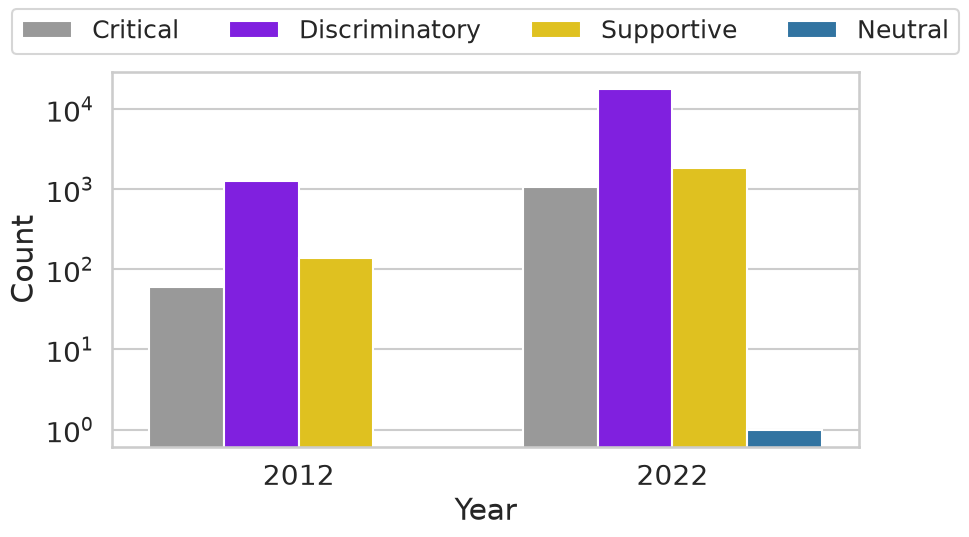

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Filter for years 2010 and 2022 only
filtered = df[df['year'].isin([2012, 2022])]
print(filtered)

# Group the data
filtered= filtered.groupby(['year', 'CommentType']).size().reset_index(name='count')

# Set seaborn theme and context
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.2)

# Color palette for comment types
palette = {
    'Neutral': '#1f77b4',
    'Supportive': '#ffd700',
    'Discriminatory': '#8000ff',
    'Critical': '#999999'
}

# Create bar plot
plt.figure(figsize=(10, 6))
sns.barplot(
    data=filtered,
    x='year',
    y='count',
    hue='CommentType',
    palette=palette
)

# Labels and formatting
plt.yscale('log')  # if needed to match your previous plot's log scale
plt.xlabel('Year')
plt.ylabel('Count')
#plt.title('Comment Type Distribution (2010 vs 2022)')
plt.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.2),  # move legend higher
    ncol=4,
    frameon=True,
    fontsize='small'
)



# Save and show
plt.tight_layout()
plt.savefig("barplot_comment_type_2010_2022.pdf", format='pdf')
plt.show()


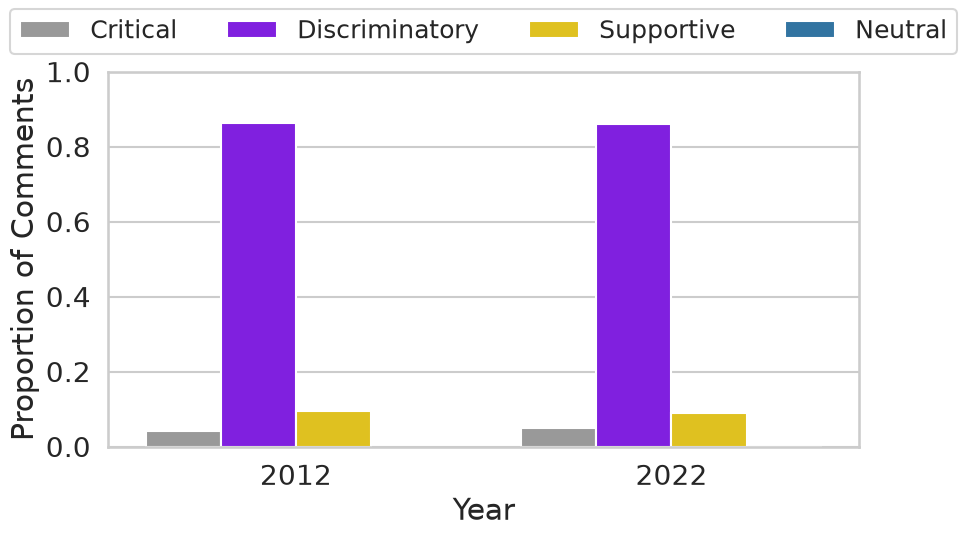

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Filter for 2012 and 2022 only
filtered = df[df['year'].isin([2012, 2022])]

# Count tweets by year and CommentType
count_by_type = filtered.groupby(['year', 'CommentType']).size().reset_index(name='count')

# Count total tweets by year
total_by_year = filtered.groupby('year').size().reset_index(name='total')

# Merge and calculate relative proportion
merged = pd.merge(count_by_type, total_by_year, on='year')
merged['relative_count'] = merged['count'] / merged['total']  # or *100 for percent

# Set seaborn theme
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.2)

# Color palette for comment types
palette = {
    'Neutral': '#1f77b4',
    'Supportive': '#ffd700',
    'Discriminatory': '#8000ff',
    'Critical': '#999999'
}

# Plot relative count
plt.figure(figsize=(10, 6))
sns.barplot(
    data=merged,
    x='year',
    y='relative_count',
    hue='CommentType',
    palette=palette
)

# Labels
plt.xlabel('Year')
plt.ylabel('Proportion of Comments')
plt.ylim(0, 1)
plt.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.2),
    ncol=4,
    frameon=True,
    fontsize='small'
)

# Save and show
plt.tight_layout()
plt.savefig("barplot_relative_comment_type_2012_2022.pdf", format='pdf')
plt.show()


In [33]:
count_by_type

,year,CommentType,count
0,2012,Critical,61
1,2012,Discriminatory,1262
2,2012,Supportive,139
3,2022,Critical,1066
4,2022,Discriminatory,18044
5,2022,Neutral,1
6,2022,Supportive,1857


In [34]:
# replace values in the sentiment column
df["Sentiment"] = df["Sentiment"].replace({
    "Negative": "Discriminatory",
    "Positive": "Supportive",
    "Neutral":  "Neutral"
})

# your color map
sentiment_colors = {
    "Neutral": "#1f77b4",
    "Supportive": "#ffd700",
    "Discriminatory": "#8000ff",
}

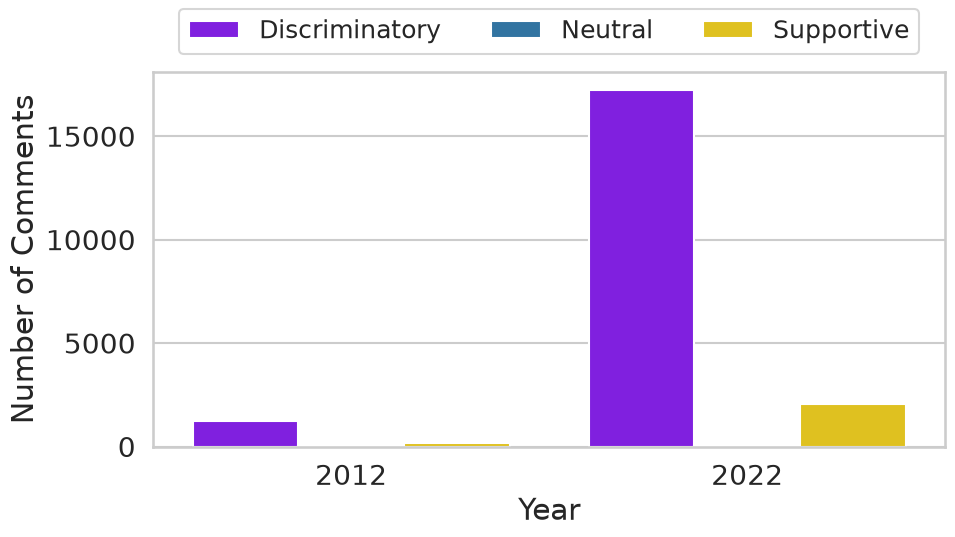

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for 2012 and 2022 only
filtered = df[df['year'].isin([2012, 2022])]

# Count tweets by year and Sentiment
count_by_type = (
    filtered.groupby(['year', 'Sentiment'])
            .size()
            .reset_index(name='count')
)

sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.2)

palette = {
    'Neutral': '#1f77b4',
    'Supportive': '#ffd700',
    'Discriminatory': '#8000ff',
}

plt.figure(figsize=(10, 6))
sns.barplot(
    data=count_by_type,
    x='year',
    y='count',          # 👈 actual counts
    hue='Sentiment',
    palette=palette
)

plt.xlabel('Year')
plt.ylabel('Number of Comments')  # 👈 updated label
plt.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.2),
    ncol=3,
    frameon=True,
    fontsize='small'
)

plt.tight_layout()
plt.savefig("barplot_count_sentiment_2012_2022.pdf", format='pdf')
plt.show()

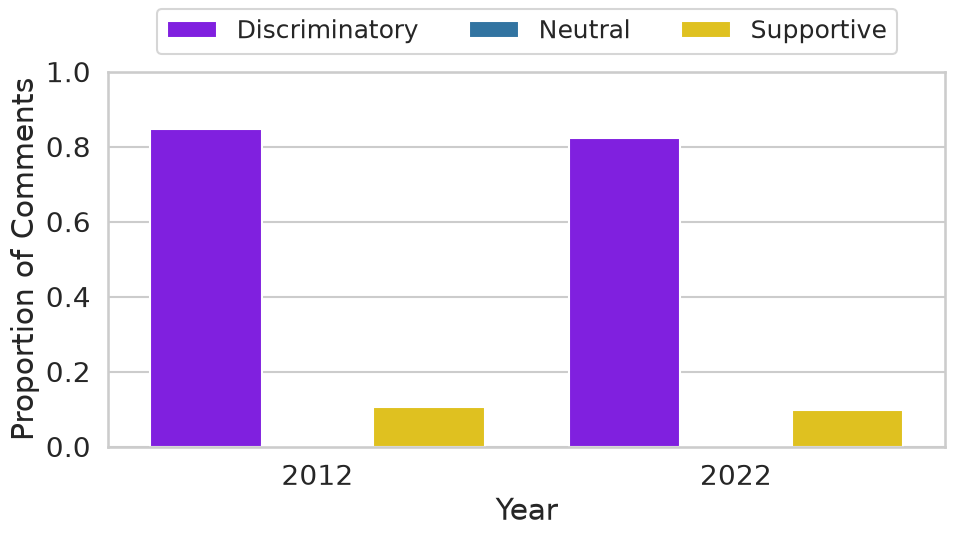

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Filter for 2012 and 2022 only
filtered = df[df['year'].isin([2012, 2022])]

# Count tweets by year and CommentType
count_by_type = filtered.groupby(['year', 'Sentiment']).size().reset_index(name='count')

# Count total tweets by year
total_by_year = filtered.groupby('year').size().reset_index(name='total')

# Merge and calculate relative proportion
merged = pd.merge(count_by_type, total_by_year, on='year')
merged['relative_count'] = merged['count'] / merged['total']  # or *100 for percent

# Set seaborn theme
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.2)

# Color palette for comment types
palette = {
    'Neutral': '#1f77b4',
    'Supportive': '#ffd700',
    'Discriminatory': '#8000ff',
    
}

# Plot relative count
plt.figure(figsize=(10, 6))
sns.barplot(
    data=merged,
    x='year',
    y='relative_count',
    hue='Sentiment',
    palette=palette
)

# Labels
plt.xlabel('Year')
plt.ylabel('Proportion of Comments')
plt.ylim(0, 1)
plt.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.2),
    ncol=4,
    frameon=True,
    fontsize='small'
)

# Save and show
plt.tight_layout()
plt.savefig("barplot_relative_comment_type_2012_2022.pdf", format='pdf')
plt.show()


In [37]:
df.columns

Index(['Unnamed: 0.5', 'Unnamed: 0.4', 'Unnamed: 0.3', 'Unnamed: 0.2',
       'Unnamed: 0.1', 'Unnamed: 0', '_id', 'pure_text', 'rt_text',
       'tweet_created_at', 'tweet_id', 'user_id', 'user_created_at',
       'fastText_lang', 'fastText_conf', 'reply_to_id', 'LLM_Label',
       'CommentType', 'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup',
       'year'],
      dtype='str')

In [38]:
df = df.rename(columns={"MappedGroup": "Group"})
df['Group'].unique()

<ArrowStringArray>
['Black Americans',   'Conservatives',         'Muslims',          'LGBTQ+',
      'Immigrants',            'Jews',        'Liberals',        'Refugees']
Length: 8, dtype: str

In [39]:
 # merged_df = merged_df[merged_df["MappedGroup"] != "None"].reset_index(drop=True)

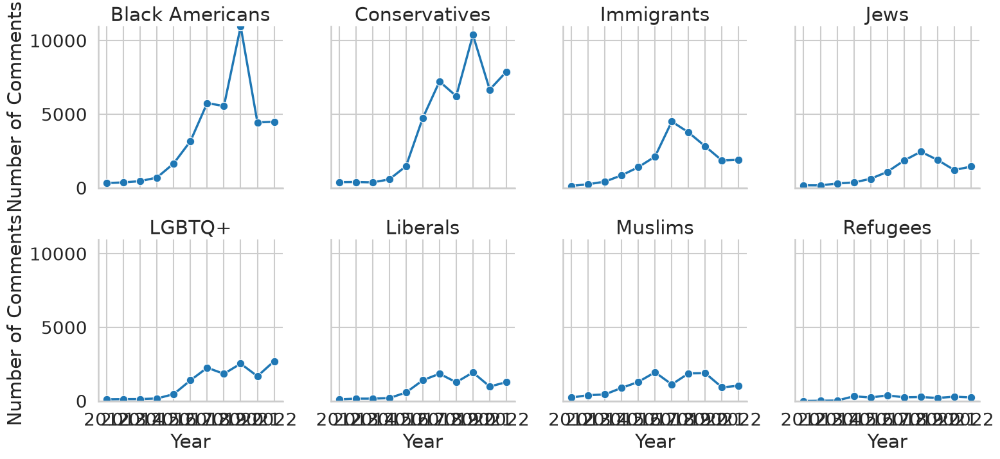

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Group by Group and year (ignore CommentType)
grouped = df.groupby(['Group', 'year']).size().reset_index(name='count')

# Seaborn theme
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.2)

# Find max y for consistent scale
y_max = grouped['count'].max()

# FacetGrid for each group
g = sns.FacetGrid(grouped, col="Group", col_wrap=4, height=4, sharey=True)
g.map_dataframe(sns.lineplot, x='year', y='count', marker="o", linewidth=2.5, color='#1f77b4')

# Set axis limits and labels
for ax in g.axes.flat:
    ax.set_ylim(0, y_max + 1)
    ax.set_xticks(sorted(grouped['year'].unique()))

g.set_axis_labels("Year", "Number of Comments")
g.set_titles(col_template="{col_name}")

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Save and show
output_path = "comment_count_by_group_over_time.pdf"
plt.savefig(output_path, format="pdf")
plt.show()


In [41]:
import pandas as pd
gf = pd.read_csv("Google Trend_us vs them bias - Sheet1 (2).csv")
gf



,Month,Refugees,Muslims,Liberals,LGBTQ+,Jews,Conservatives,Immigrants,Black Americans
0,2012-01,2,25,22,0,42,41,16,18
1,2012-02,3,27,26,0,44,46,19,19
2,2012-03,3,28,25,0,43,41,17,16
3,2012-04,3,29,25,1,50,39,19,17
4,2012-05,4,27,22,1,44,35,18,15
...,...,...,...,...,...,...,...,...,...
127,2022-08,9,30,28,60,40,48,27,20
128,2022-09,11,39,39,72,52,56,44,32
129,2022-10,12,42,36,67,73,73,45,41
130,2022-11,13,43,32,74,77,69,43,40


In [42]:
gf.columns

Index(['Month', 'Refugees', 'Muslims', 'Liberals', 'LGBTQ+', 'Jews',
       'Conservatives', 'Immigrants', 'Black Americans'],
      dtype='str')

In [43]:
grouped['Group'].unique() 

<ArrowStringArray>
['Black Americans',   'Conservatives',      'Immigrants',            'Jews',
          'LGBTQ+',        'Liberals',         'Muslims',        'Refugees']
Length: 8, dtype: str

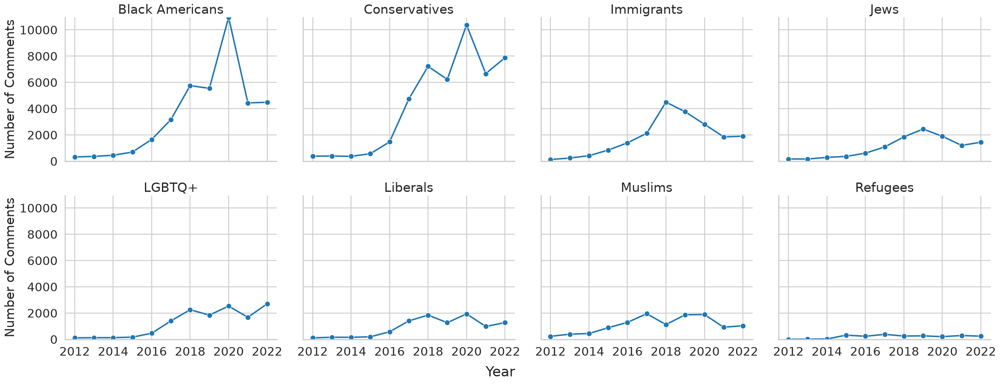

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Group by Group and year (ignore CommentType)
grouped = df.groupby(['Group', 'year']).size().reset_index(name='count')

# Seaborn theme
# sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.2)

# Find max y for consistent scale
y_max = grouped['count'].max()

# Determine 2-year interval ticks
years = sorted(grouped['year'].unique())
xticks = years[::2]  # every 2nd year

# FacetGrid for each group
g = sns.FacetGrid(grouped, col="Group", col_wrap=4, height=5, aspect=1.2, sharey=True, sharex=True)
g.map_dataframe(sns.lineplot, x='year', y='count', marker="o", linewidth=2.5, color='#1f77b4')

# Apply axis limits and ticks
for ax in g.axes.flat:
    ax.set_ylim(0, y_max + 1)
    ax.set_xticks(xticks)
    ax.set_xlabel("")

# Common axis labels
g.set_axis_labels("", "Number of Comments")
g.set_titles(col_template="{col_name}")

# Add one shared x-axis label below
g.fig.text(0.5, 0.04, "Year", ha='center', fontsize=24)

# Adjust layout
plt.subplots_adjust(top=0.93, bottom=0.1)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])

# Save and show
output_path = "comment_count_by_group_over_time_2year.pdf"
plt.savefig(output_path, format="pdf")
plt.show()


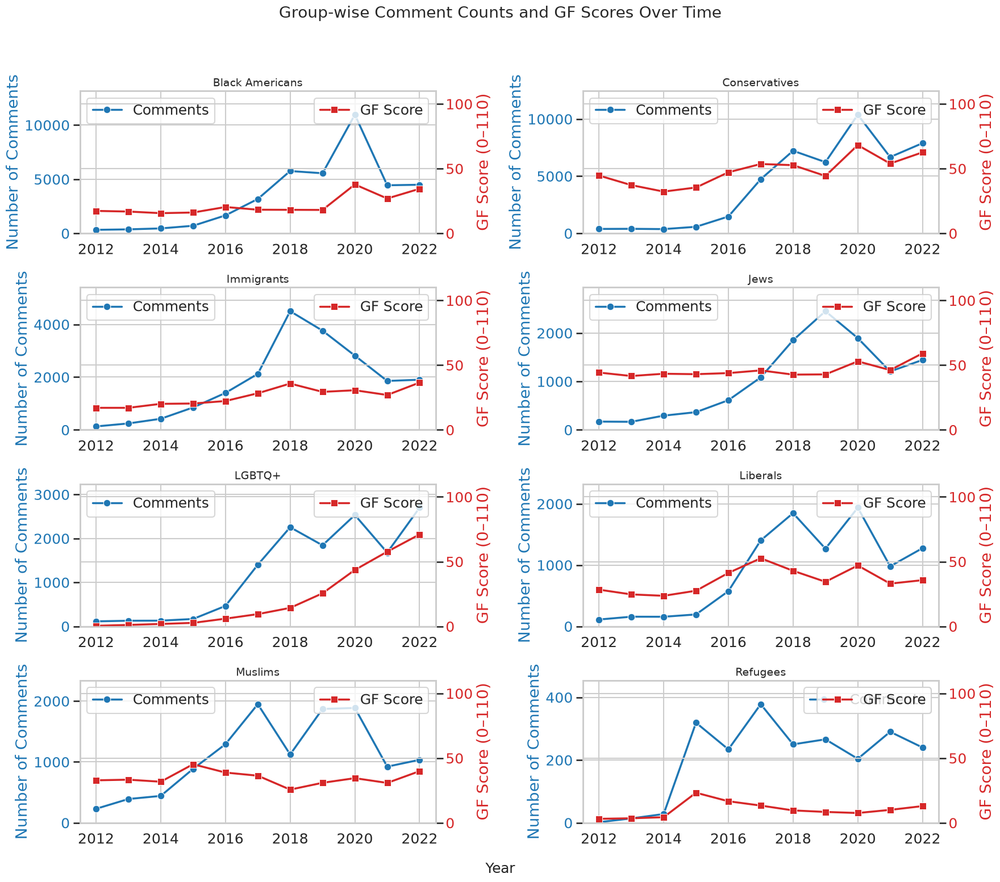

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 1️⃣ Prepare grouped data
# -----------------------------
# grouped columns: Group, year, count
grouped['year'] = grouped['year'].astype(int)

# -----------------------------
# 2️⃣ Prepare GF data
# -----------------------------
gf['Month'] = pd.to_datetime(gf['Month'])
gf['year'] = gf['Month'].dt.year

# Melt GF data to long format: each row = one group score per month
gf_long = gf.melt(id_vars=['Month', 'year'], var_name='Group', value_name='GF_score')

# Aggregate GF to yearly average per group
gf_yearly = gf_long.groupby(['Group', 'year'], as_index=False)['GF_score'].mean()

# -----------------------------
# 3️⃣ Merge both datasets
# -----------------------------
merged = pd.merge(grouped, gf_yearly, on=['Group', 'year'], how='inner')

# -----------------------------
# 4️⃣ Plot (dual y-axis per group)
# -----------------------------
sns.set_context("talk", font_scale=1.1)
sns.set_style("whitegrid")

groups = sorted(merged['Group'].unique())
ncols = 2
nrows = (len(groups) + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4))
axes = axes.flatten()

for i, grp in enumerate(groups):
    ax = axes[i]
    sub = merged[merged['Group'] == grp]

    # left axis = comment count
    sns.lineplot(
        data=sub, x='year', y='count', color='#1f77b4',
        marker='o', linewidth=2.5, ax=ax, label='Comments'
    )
    ax.set_ylabel("Number of Comments", color='#1f77b4')
    ax.tick_params(axis='y', labelcolor='#1f77b4')
    ax.set_ylim(0, sub['count'].max() * 1.2)

    # right axis = GF score
    ax2 = ax.twinx()
    sns.lineplot(
        data=sub, x='year', y='GF_score', color='#d62728',
        marker='s', linewidth=2.5, ax=ax2, label='GF Score'
    )
    ax2.set_ylabel("GF Score (0–110)", color='#d62728')
    ax2.tick_params(axis='y', labelcolor='#d62728')
    ax2.set_ylim(0, 110)

    # title and x ticks
    ax.set_title(grp, fontsize=14)
    ax.set_xticks(sorted(merged['year'].unique())[::2])  # every 2 years
    ax.set_xlabel("")

# Remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Shared labels and layout
fig.text(0.5, 0.04, "Year", ha='center', fontsize=18)
fig.suptitle("Group-wise Comment Counts and GF Scores Over Time", fontsize=20, y=0.995)
plt.tight_layout(rect=[0, 0.05, 1, 0.97])

plt.savefig("groupwise_comments_and_GFscores.pdf", dpi=300, bbox_inches="tight")
plt.show()


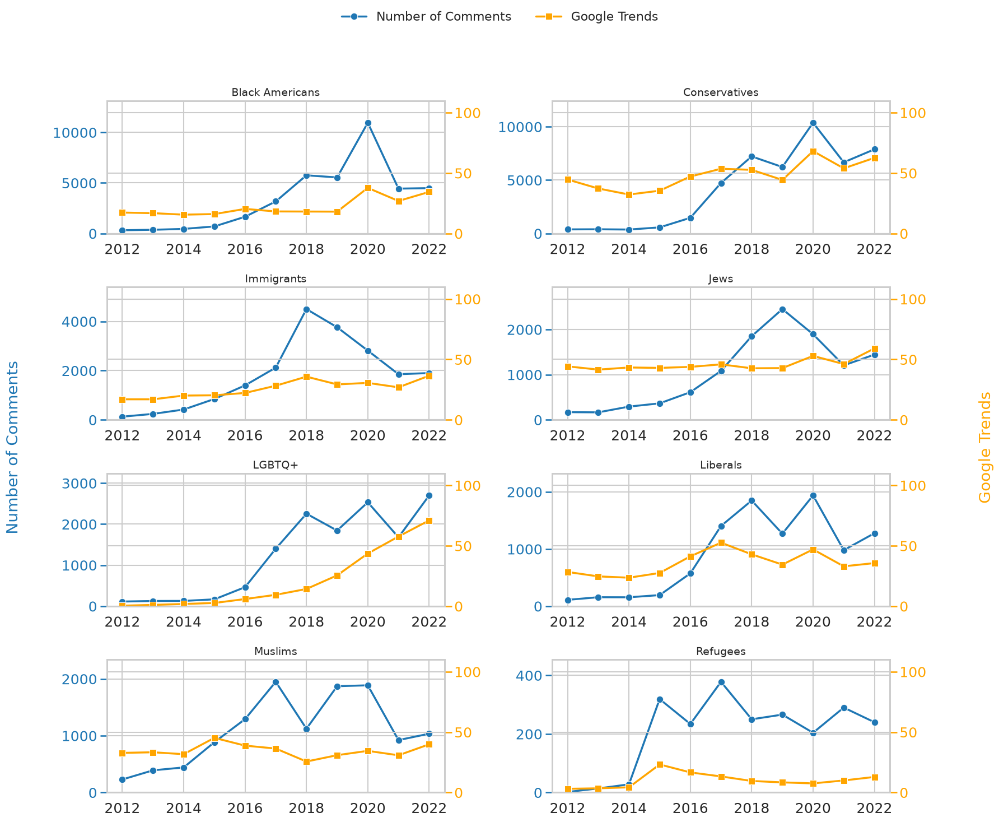

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 1️⃣ Prepare grouped data
# -----------------------------
grouped['year'] = grouped['year'].astype(int)

# -----------------------------
# 2️⃣ Prepare GF data
# -----------------------------
gf['Month'] = pd.to_datetime(gf['Month'])
gf['year'] = gf['Month'].dt.year
gf_long = gf.melt(id_vars=['Month', 'year'], var_name='Group', value_name='GF_score')
gf_yearly = gf_long.groupby(['Group', 'year'], as_index=False)['GF_score'].mean()

# -----------------------------
# 3️⃣ Merge both datasets
# -----------------------------
merged = pd.merge(grouped, gf_yearly, on=['Group', 'year'], how='inner')

# -----------------------------
# 4️⃣ Plot (dual y-axis per group)
# -----------------------------
sns.set_context("talk", font_scale=1.1)
sns.set_style("whitegrid")

groups = sorted(merged['Group'].unique())
ncols = 2
nrows = (len(groups) + ncols - 1) // ncols
years = sorted(merged['year'].unique())
xticks = years[::2]

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4))
axes = axes.flatten()

# --- Prepare for single legend ---
handles_all, labels_all = [], []

for i, grp in enumerate(groups):
    ax = axes[i]
    sub = merged[merged['Group'] == grp]

    # Left axis: comment count
    line1 = sns.lineplot(
        data=sub, x='year', y='count',
        color='#1f77b4', marker='o', linewidth=2.5,
        ax=ax, label='Number of Comments'
    )

    # Right axis: GF score
    ax2 = ax.twinx()
    line2 = sns.lineplot(
        data=sub, x='year', y='GF_score',
        color='#FFA500', marker='s', linewidth=2.5,
        ax=ax2, label='Google Trends'
    )

    # Capture legend handles (only once)
    if not handles_all:
        handles1, labels1 = ax.get_legend_handles_labels()
        handles2, labels2 = ax2.get_legend_handles_labels()
        handles_all = handles1 + handles2
        labels_all = labels1 + labels2

    # Remove legends from subplots
    if ax.get_legend(): ax.get_legend().remove()
    if ax2.get_legend(): ax2.get_legend().remove()

    # Titles & axes style
    ax.set_title(grp, fontsize=14)
    ax.set_xticks(xticks)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax2.set_ylabel("")
    ax.tick_params(axis='y', colors='#1f77b4')
    ax2.tick_params(axis='y', colors='#FFA500')
    ax.set_ylim(0, sub['count'].max() * 1.2)
    ax2.set_ylim(0, 110)

# Remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# --- Shared labels ---
#fig.text(0.5, 0.04, "Year", ha='center', fontsize=20)
fig.text(0.02, 0.5, "Number of Comments", va='center', rotation='vertical',
         fontsize=20, color='#1f77b4')
fig.text(0.985, 0.5, "Google Trends", va='center', rotation='vertical',
         fontsize=20, color='#FFA500')

# --- Single legend on top ---
fig.legend(
    handles_all, labels_all,
    loc='upper center', ncol=2, frameon=False, fontsize=16
)

# --- Final layout ---
plt.tight_layout(rect=[0.05, 0.07, 0.95, 0.92])
#fig.suptitle("Group-wise Comment Counts and GF Scores Over Time", fontsize=22, y=0.109)
plt.savefig("groupwise_comments_GFscore_shared_labels.pdf", dpi=300, bbox_inches="tight")
plt.show()


In [47]:
df

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,...,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,Group,year
0,1.0,1.0,31562.0,53734.0,112688.0,34389.0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,...,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Discriminatory,Anger,Black Americans,2022
1,2.0,2.0,31563.0,6419.0,6516.0,6516.0,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,...,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
2,3.0,3.0,31564.0,21989.0,487.0,487.0,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,...,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Supportive,Gratitude,Muslims,2016
3,4.0,4.0,31565.0,26907.0,422.0,422.0,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,...,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Discriminatory,Anger,Black Americans,2020
4,7.0,7.0,31568.0,19884.0,56211.0,39730.0,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,...,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,NaN,30760.0,30927.0,61861.0,11284.0,2083.0,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,...,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Discriminatory,Anger,Liberals,2016
153242,NaN,30761.0,30928.0,61862.0,44732.0,14321.0,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,...,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Discriminatory,Anger,LGBTQ+,2019
153243,NaN,30762.0,30929.0,61863.0,54343.0,23932.0,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,...,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
153244,NaN,30763.0,30930.0,61864.0,38158.0,7747.0,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,...,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020


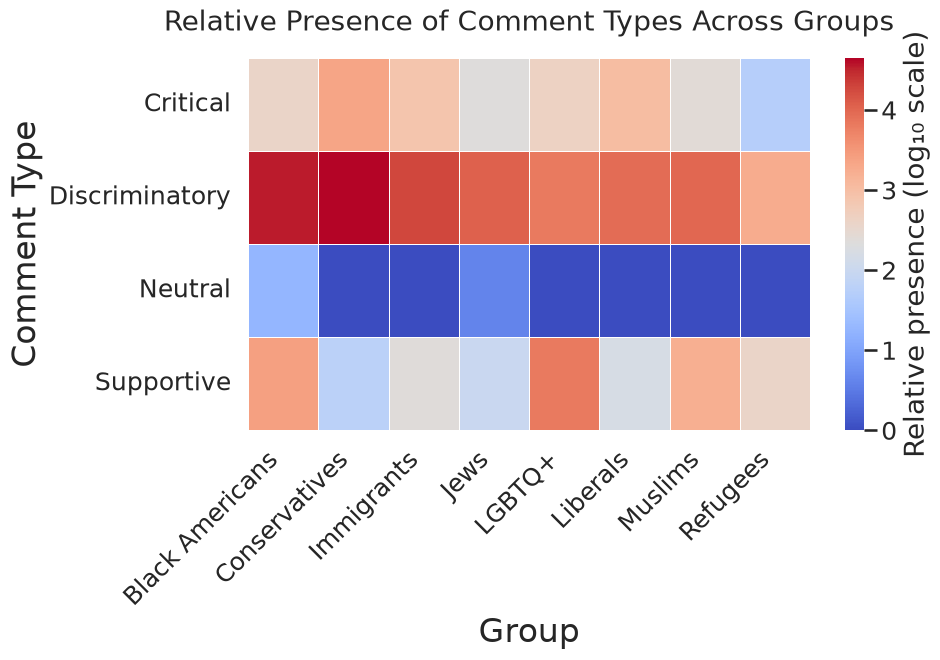

In [48]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Example: df has columns ['Group', 'CommentType']
# Count and pivot for heatmap
heatmap_data = (
    df.groupby(['CommentType', 'Group'])
    .size()
    .reset_index(name='count')
    .pivot(index='CommentType', columns='Group', values='count')
    .fillna(0)
)

# Convert to relative presence (log scale like figure)
heatmap_data = np.log10(heatmap_data + 1)

# Set style
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.1)

# Create figure
plt.figure(figsize=(10, 7))
ax = sns.heatmap(
    heatmap_data,
    cmap="coolwarm",
    cbar_kws={'label': 'Relative presence (log₁₀ scale)'},
    linewidths=0.5,
    linecolor='white'
)

# Customize labels and ticks
plt.title("Relative Presence of Comment Types Across Groups", fontsize=20, pad=20)
plt.xlabel("Group", fontsize=24)
plt.ylabel("Comment Type", fontsize=24)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout
plt.tight_layout()

# Save and show
output_path = "comment_type_vs_group_heatmap.pdf"
plt.savefig(output_path, format="pdf", dpi=300)
plt.show()


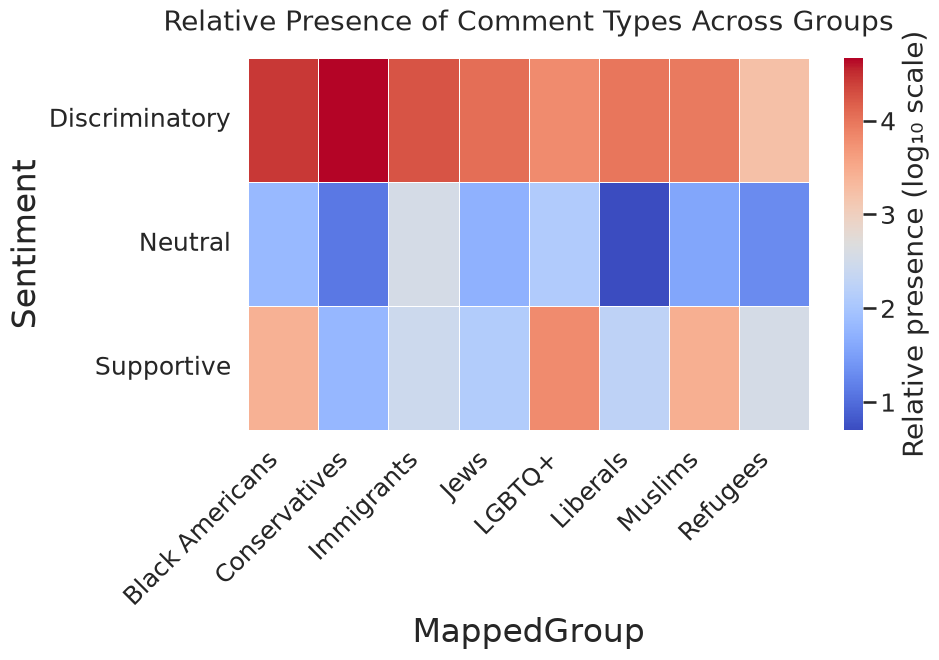

In [49]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Example: df has columns ['Group', 'CommentType']
# Count and pivot for heatmap
heatmap_data = (
    df.groupby(['Sentiment', 'Group'])
    .size()
    .reset_index(name='count')
    .pivot(index='Sentiment', columns='Group', values='count')
    .fillna(0)
)

# Convert to relative presence (log scale like figure)
heatmap_data = np.log10(heatmap_data + 1)

# Set style
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.1)

# Create figure
plt.figure(figsize=(10, 7))
ax = sns.heatmap(
    heatmap_data,
    cmap="coolwarm",
    cbar_kws={'label': 'Relative presence (log₁₀ scale)'},
    linewidths=0.5,
    linecolor='white'
)

# Customize labels and ticks
plt.title("Relative Presence of Comment Types Across Groups", fontsize=20, pad=20)
plt.xlabel("MappedGroup", fontsize=24)
plt.ylabel("Sentiment", fontsize=24)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout
plt.tight_layout()

# Save and show
output_path = "comment_type_vs_group_heatmap.pdf"
plt.savefig(output_path, format="pdf", dpi=300)
plt.show()


In [50]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import pandas as pd
from tqdm.auto import tqdm


In [51]:
model_name = "cardiffnlp/twitter-roberta-base-sentiment-latest"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()


W1105 15:51:12.487000 1051433 /gpfs1/home/t/p/tprama/.local/lib/python3.12/site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1105 15:51:13.001000 1051433 /gpfs1/home/t/p/tprama/.local/lib/python3.12/site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


RobertaForSequenceClassification(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
  

In [52]:
df

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,...,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,Group,year
0,1.0,1.0,31562.0,53734.0,112688.0,34389.0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,...,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Discriminatory,Anger,Black Americans,2022
1,2.0,2.0,31563.0,6419.0,6516.0,6516.0,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,...,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
2,3.0,3.0,31564.0,21989.0,487.0,487.0,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,...,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Supportive,Gratitude,Muslims,2016
3,4.0,4.0,31565.0,26907.0,422.0,422.0,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,...,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Discriminatory,Anger,Black Americans,2020
4,7.0,7.0,31568.0,19884.0,56211.0,39730.0,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,...,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,NaN,30760.0,30927.0,61861.0,11284.0,2083.0,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,...,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Discriminatory,Anger,Liberals,2016
153242,NaN,30761.0,30928.0,61862.0,44732.0,14321.0,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,...,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Discriminatory,Anger,LGBTQ+,2019
153243,NaN,30762.0,30929.0,61863.0,54343.0,23932.0,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,...,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
153244,NaN,30763.0,30930.0,61864.0,38158.0,7747.0,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,...,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020


In [53]:
# labels = ["negative", "neutral", "positive"]

# def get_sentiment_score(text):
#     inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=128)
#     with torch.no_grad():
#         outputs = model(**inputs)
#         probs = torch.nn.functional.softmax(outputs.logits, dim=-1)[0].cpu().numpy()
#     pos, neu, neg = probs[2], probs[1], probs[0]
#     score = pos - neg                    # range roughly [–1, 1]
#     return score, pos, neu, neg

# tqdm.pandas()
# df[["sentiment_score", "P_pos", "P_neu", "P_neg"]] = df["pure_text"].progress_apply(
#     lambda x: pd.Series(get_sentiment_score(x))
# )


In [58]:
sentiment_by_group = (
    df.groupby(["Group", "CommentType"])["sentiment_score"]
    .mean()
    .reset_index()
)


KeyError: 'Column not found: sentiment_score'

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=sentiment_by_group, x="CommentType", y="sentiment_score")
plt.title("Distribution of Sentiment Scores by Comment Type")
plt.ylabel("Sentiment Score (–1 to 1)")
plt.show()


NameError: name 'sentiment_by_group' is not defined

In [60]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Clean any duplicate/random columns
cols_to_drop = [
    "sentiment_random_x_x", "sentiment_score_scaled",
    "sentiment_random_scaled", "sentiment_random_y",
    "sentiment_random", "sentiment_random_x_y"
]
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns], errors='ignore')

# Compute mean sentiment per Group
group_sentiment = (
    df.groupby("Group")["sentiment_score"]
    .mean()
    .reset_index()
    .sort_values("sentiment_score", ascending=False)
)

# Plot
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.1)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=group_sentiment,
    x="sentiment_score",
    y="Group",
    s=120,
    color="#E69F00",
    edgecolor="black"
)

plt.title("Average Sentiment Score by Group", fontsize=16, pad=15)
plt.xlabel("Sentiment Score (–1 to 1)")
plt.ylabel("Group")
plt.axvline(0, color="gray", linestyle="--", linewidth=1)
plt.tight_layout()
plt.savefig("sentiment_score_by_group.pdf", dpi=300, bbox_inches="tight")
plt.show()


KeyError: 'Column not found: sentiment_score'

In [61]:
df

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,...,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,Group,year
0,1.0,1.0,31562.0,53734.0,112688.0,34389.0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,...,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Discriminatory,Anger,Black Americans,2022
1,2.0,2.0,31563.0,6419.0,6516.0,6516.0,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,...,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
2,3.0,3.0,31564.0,21989.0,487.0,487.0,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,...,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Supportive,Gratitude,Muslims,2016
3,4.0,4.0,31565.0,26907.0,422.0,422.0,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,...,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Discriminatory,Anger,Black Americans,2020
4,7.0,7.0,31568.0,19884.0,56211.0,39730.0,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,...,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,NaN,30760.0,30927.0,61861.0,11284.0,2083.0,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,...,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Discriminatory,Anger,Liberals,2016
153242,NaN,30761.0,30928.0,61862.0,44732.0,14321.0,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,...,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Discriminatory,Anger,LGBTQ+,2019
153243,NaN,30762.0,30929.0,61863.0,54343.0,23932.0,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,...,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
153244,NaN,30763.0,30930.0,61864.0,38158.0,7747.0,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,...,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020


In [62]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df[["sentiment_score_scaled", "sentiment_random_scaled"]] = scaler.fit_transform(
    df[["sentiment_score", "sentiment_random"]]
)

df

KeyError: "None of [Index(['sentiment_score', 'sentiment_random'], dtype='str')] are in the [columns]"

In [63]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# ---- baseline setup ----
# df has: ['Group', 'CommentType', 'sentiment_score', ...]
baseline = (
    df.groupby("Group")["sentiment_score"]
    .mean()
    .reset_index(name="sentiment_random")
)
df = df.merge(baseline, on="Group")

# ---- normalize scores [0,1] ----
scaler = MinMaxScaler()
df[["sentiment_score_scaled", "sentiment_random_scaled"]] = scaler.fit_transform(
    df[["sentiment_score", "sentiment_random"]]
)

# ---- prepare layout ----
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.1)

groups = sorted(df["Group"].unique())
n = len(groups)
ncols = 3
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(15, nrows * 4))
axes = axes.flatten()

for i, grp in enumerate(groups):
    ax = axes[i]
    subset = df[df["Group"] == grp].copy()

    # scatter points for each CommentType
    sns.scatterplot(
        data=subset,
        x="sentiment_random_scaled",
        y="sentiment_score_scaled",
        hue="CommentType",
        s=80,
        ax=ax,
        edgecolor="black",
        linewidth=0.7
    )

    # red dashed equality line
    ax.plot([0, 1], [0, 1], ls="--", color="firebrick", lw=1.2)

    # label each CommentType
    for _, row in subset.iterrows():
        ax.text(
            row["sentiment_random_scaled"] + 0.01,
            row["sentiment_score_scaled"] + 0.01,
            row["CommentType"],
            fontsize=9,
            color="black"
        )

    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(grp, fontsize=14)
    ax.set_xlabel("Baseline sentiment (All Tweets)")
    ax.set_ylabel("CommentType sentiment")

# remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig("groupwise_sentiment_vs_baseline.pdf", dpi=300, bbox_inches="tight")
plt.show()


KeyError: 'Column not found: sentiment_score'

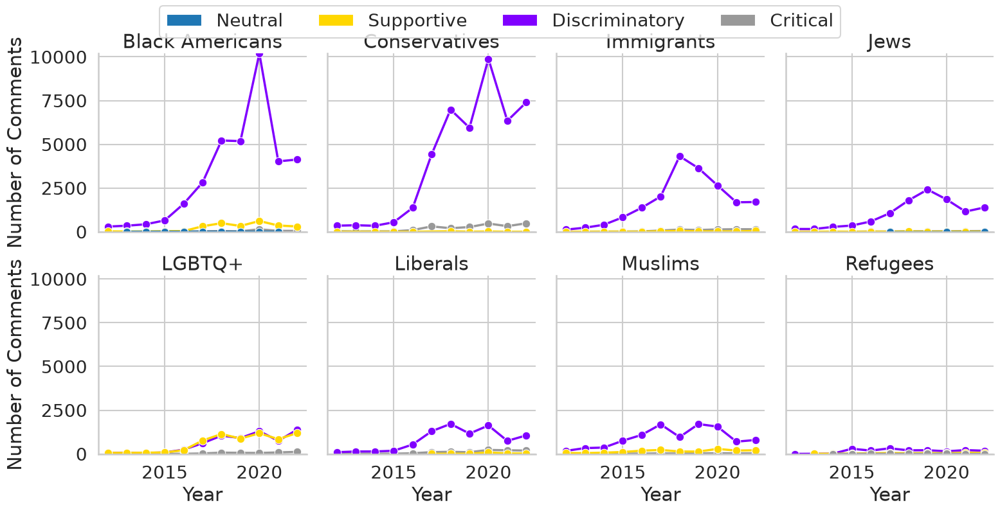

<Figure size 1200x600 with 0 Axes>

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import matplotlib.gridspec as gridspec



# Group the data
grouped = df.groupby(['Group', 'year', 'CommentType']).size().reset_index(name='count')

# Set seaborn theme and context
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.2)

# Color palette for consistent comment types
palette = {
    'Neutral': '#1f77b4',
    'Supportive': '#ffd700',
    'Discriminatory': '#8000ff',
    'Critical': '#999999'
}

# Determine consistent y-axis range
y_max = grouped['count'].max()

# Create the FacetGrid

g = sns.FacetGrid(grouped, col="Group", col_wrap=4, height=4, sharey=True, legend_out=True)
g.map_dataframe(sns.lineplot, x='year', y='count', hue='CommentType', marker="o", linewidth=2.5, palette=palette)

# Set consistent y-axis
for ax in g.axes.flat:
    ax.set_ylim(0, y_max + 1)

# Set labels and titles
g.set_axis_labels("Year", "Number of Comments")
g.set_titles(col_template="{col_name}")
g.add_legend = lambda *args, **kwargs: None  # Disable default legend method

# Adjust figure to add custom legend at the top
fig = g.fig
legend_elements = [
    Patch(facecolor=palette['Neutral'], label='Neutral'),
    Patch(facecolor=palette['Supportive'], label='Supportive'),
    Patch(facecolor=palette['Discriminatory'], label='Discriminatory'),
    Patch(facecolor=palette['Critical'], label='Critical'),
]

# Add the legend manually to the figure
fig.legend(
    handles=legend_elements,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    frameon=True,

)
plt.figure(figsize=(12, 6))
# Tight layout and save figure
plt.tight_layout(rect=[0, 0, 1, 0.95])
output_path = "comment_type_distribution_by_group_custom_legend.pdf"
plt.savefig(output_path, format="pdf")

plt.show()


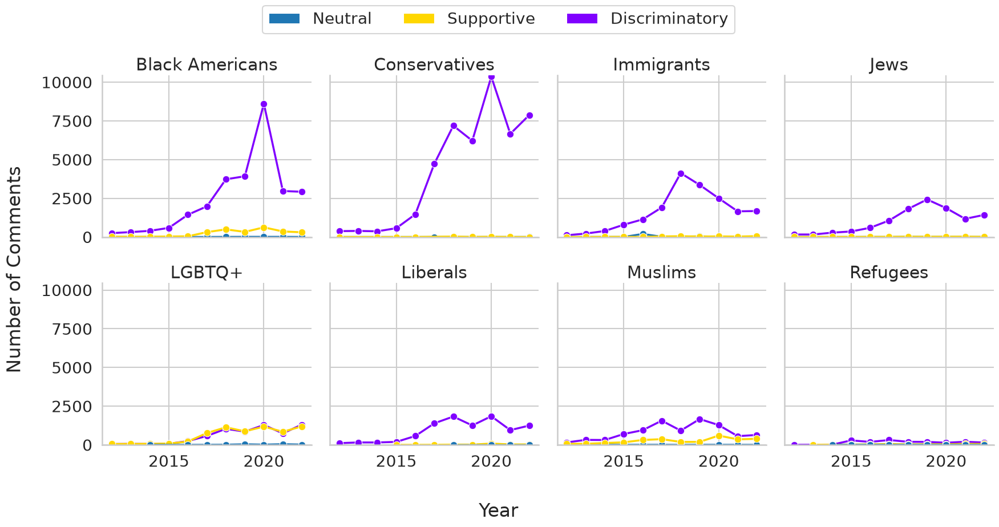

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Group the data
grouped = df.groupby(['Group', 'year', 'Sentiment']).size().reset_index(name='count')

# Set seaborn theme and context
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.2)

# Color palette for consistent comment types
palette = {
    'Neutral': '#1f77b4',
    'Supportive': '#ffd700',
    'Discriminatory': '#8000ff',
   
}

# Determine consistent y-axis range
y_max = grouped['count'].max()+100

# Create the FacetGrid
g = sns.FacetGrid(grouped, col="Group", col_wrap=4, height=4.5, sharey=True, legend_out=True)
g.map_dataframe(sns.lineplot, x='year', y='count', hue='Sentiment', marker="o", linewidth=2.5, palette=palette)

# Set consistent y-axis
for ax in g.axes.flat:
    ax.set_ylim(0, y_max + 1)
    ax.set_xlabel('')
    ax.set_ylabel('')

# Set titles for each subplot
g.set_titles(col_template="{col_name}")

# Add a custom legend at the top
fig = g.fig
legend_elements = [
    Patch(facecolor=palette['Neutral'], label='Neutral'),
    Patch(facecolor=palette['Supportive'], label='Supportive'),
    Patch(facecolor=palette['Discriminatory'], label='Discriminatory'),
   
]

fig.legend(
    handles=legend_elements,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    frameon=True,
)

# Add one x-axis and y-axis label for the whole figure
fig.supxlabel("Year", fontsize=24)
fig.supylabel("Number of Comments", fontsize=24)

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.95])

#plt.figure(figsize=(12, 6))
output_path = "comment_type_distribution_by_group_custom_legend.pdf"
plt.savefig(output_path, format="pdf")

# Show the plot
plt.show()


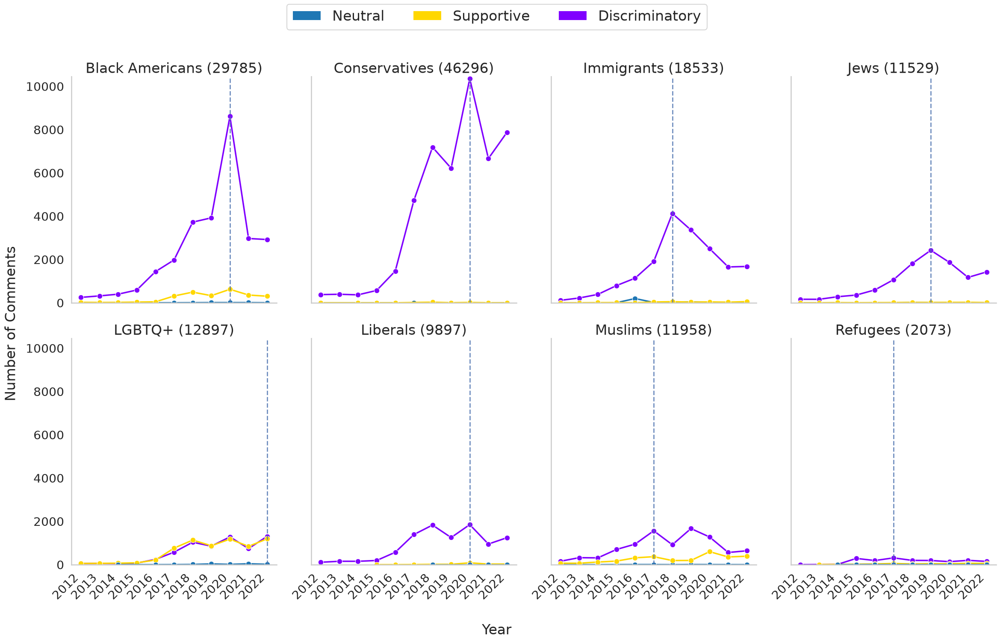

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# -----------------------------
# 1) Ensure year is integer and clean
# -----------------------------
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year", "Group", "Sentiment"])
df["year"] = df["year"].astype(int)

# show every year tick across the full range
all_years = list(range(df["year"].min(), df["year"].max() + 1))

# -----------------------------
# 2) Group counts for lineplot (by sentiment)
# -----------------------------
grouped = df.groupby(["Group", "year", "Sentiment"]).size().reset_index(name="count")

# -----------------------------
# 3) Total comments per Group (for titles)
# -----------------------------
group_total = df.groupby("Group").size().to_dict()  # N per group

# -----------------------------
# 4) Peak year per Group (total across sentiments)
# -----------------------------
group_year_total = df.groupby(["Group", "year"]).size().reset_index(name="total_count")
peak_year_map = (
    group_year_total.loc[group_year_total.groupby("Group")["total_count"].idxmax()]
    .set_index("Group")["year"]
    .to_dict()
)
peak_count_map = (
    group_year_total.loc[group_year_total.groupby("Group")["total_count"].idxmax()]
    .set_index("Group")["total_count"]
    .to_dict()
)

# -----------------------------
# Plot settings
# -----------------------------
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.2)

palette = {
    "Neutral": "#1f77b4",
    "Supportive": "#ffd700",
    "Discriminatory": "#8000ff",
}

y_max = grouped["count"].max() + 100

# -----------------------------
# FacetGrid (wider figure)
# -----------------------------
g = sns.FacetGrid(
    grouped,
    col="Group",
    col_wrap=4,
    height=4.5,
    sharey=True,
    legend_out=True
)
g.fig.set_size_inches(24, 15)  # wider so year ticks fit

g.map_dataframe(
    sns.lineplot,
    x="year",
    y="count",
    hue="Sentiment",
    marker="o",
    linewidth=2.5,
    palette=palette
)

# -----------------------------
# Format axes + add totals and peak year per subplot
# -----------------------------
for ax in g.axes.flat:
    # seaborn sets the title like "Group = XYZ" by default for FacetGrid
    title = ax.get_title()
    group_name = title.split(" = ", 1)[-1]  # robust extraction

    N = group_total.get(group_name, 0)
    peak_year = peak_year_map.get(group_name, None)
    peak_cnt = peak_count_map.get(group_name, None)

    ax.set_ylim(0, y_max + 1)
    ax.set_xlabel("")
    ax.set_ylabel("")

    # year-wise ticks
    ax.set_xticks(all_years)
    ax.set_xticklabels(all_years, rotation=45, ha="right", fontsize=20)
    # ax.set_yticklabels(all_years, rotation=45, ha="right", fontsize=20)

    # vertical line at peak year + annotation
    if peak_year is not None:
        ax.axvline(peak_year, linestyle="--", linewidth=2, alpha=0.8)
        # ax.text(
        #     peak_year, ax.get_ylim()[1] * 0.92,
        #     f"Peak: {peak_year}\n({peak_cnt})",
        #     ha="center", va="top",
        #     fontsize=11
        # )

    # title showing total N
    ax.set_title(f"{group_name} ({N})", fontsize=24)

for ax in g.axes.flat:
    ax.grid(False)
    
# -----------------------------
# Custom legend at top
# -----------------------------
fig = g.fig
legend_elements = [
    Patch(facecolor=palette["Neutral"], label="Neutral"),
    Patch(facecolor=palette["Supportive"], label="Supportive"),
    Patch(facecolor=palette["Discriminatory"], label="Discriminatory"),
]
fig.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=3,
    frameon=True,
    fontsize=24
)

fig.supxlabel("Year", fontsize=24)
fig.supylabel("Number of Comments", fontsize=24)
ax.tick_params(labelsize=20)
plt.tight_layout(rect=[0, 0, 1, 0.93])

output_path = "comment_type_distribution_by_group_yearwise_with_peak.pdf"
plt.savefig(output_path, format="pdf", bbox_inches="tight")
plt.show()

                     NegativeBinomial Regression Results                      
Dep. Variable:                      Y   No. Observations:                 1056
Model:               NegativeBinomial   Df Residuals:                     1013
Method:                           MLE   Df Model:                           42
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                  0.1105
Time:                        16:09:48   Log-Likelihood:                -5427.7
converged:                       True   LL-Null:                       -6101.7
Covariance Type:            nonrobust   LLR p-value:                2.877e-255
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
Intercept                              -13.1944      0.158    -83.522      0.000     -13.504     -12.885
C(group)[T.Conservatives]               -0.1393      

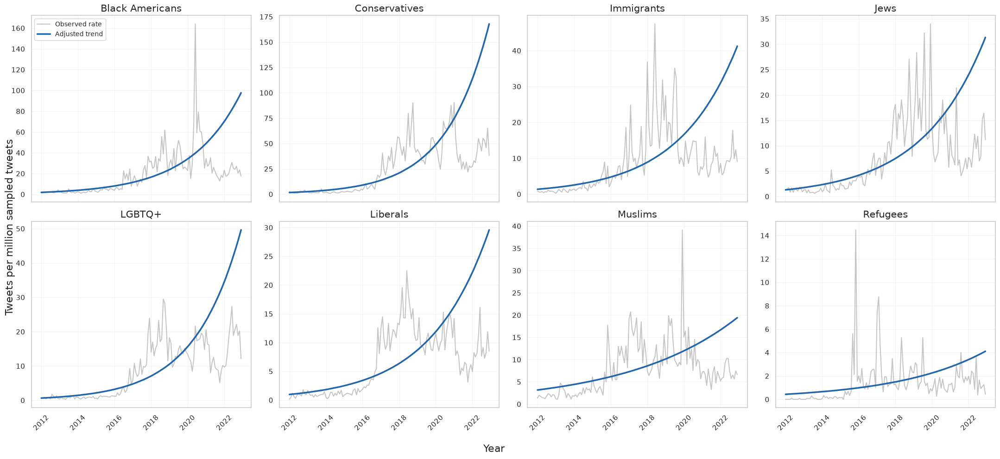


Analysis completed.


In [73]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import norm

# ==========================================================
# 1. SETTINGS
# ==========================================================

GROUP_COL = "TargetedGroup"
SENTIMENT_TO_ANALYZE = None  # None, "Negative", "Positive", "Neutral"

GROUPS = [
    "Black Americans", "Conservatives", "Immigrants",
    "Jews", "LGBTQ+", "Liberals", "Muslims", "Refugees"
]

START = "2012-01-01"
END = "2022-12-01"

# ==========================================================
# 2. PREPARE DATA
# ==========================================================

data = df.copy()

data["date"] = pd.to_datetime(
    data["tweet_created_at"],
    errors="coerce",
    utc=True
)

data["month"] = (
    data["date"]
    .dt.tz_convert(None)
    .dt.to_period("M")
    .dt.to_timestamp()
)

data = data[
    data[GROUP_COL].isin(GROUPS)
    & data["month"].between(START, END)
].copy()

# Optional sentiment filter
if SENTIMENT_TO_ANALYZE is not None:
    data = data[
        data["Sentiment"] == SENTIMENT_TO_ANALYZE
    ].copy()

# Count each unique tweet/group pair only once
data = data.drop_duplicates(
    subset=["tweet_id", GROUP_COL]
)

# ==========================================================
# 3. MONTHLY GROUP COUNTS (Y_g,t)
# ==========================================================

months = pd.date_range(START, END, freq="MS")

index = pd.MultiIndex.from_product(
    [GROUPS, months],
    names=["group", "month"]
)

panel = (
    data.groupby([GROUP_COL, "month"])
    .size()
    .reindex(index, fill_value=0)
    .rename("Y")
    .reset_index()
)

# ==========================================================
# 4. MONTHLY TWITTER VOLUME (N_t)
# ==========================================================

# monthly_totals.csv must contain:
# month,total_tweets
# 2012-01,actual_count
# 2012-02,actual_count
# ...

totals = pd.read_csv("monthly_totals.csv")

totals["month"] = (
    pd.to_datetime(totals["month"])
    .dt.to_period("M")
    .dt.to_timestamp()
)

if totals["month"].duplicated().any():
    raise ValueError("Duplicate months in monthly_totals.csv")

panel = panel.merge(
    totals[["month", "total_tweets"]],
    on="month",
    how="left",
    validate="many_to_one"
)

if panel["total_tweets"].isna().any():
    raise ValueError("Missing monthly denominator values.")

if (panel["total_tweets"] <= 0).any():
    raise ValueError("Monthly totals must be positive.")

panel["N"] = panel["total_tweets"]

# Normalized rate per million tweets
panel["rate_per_million"] = (
    panel["Y"] / panel["N"] * 1_000_000
)

# ==========================================================
# 5. TEMPORAL + EVENT VARIABLES
# ==========================================================

panel["t_years"] = (
    (panel["month"].dt.year - 2012)
    + (panel["month"].dt.month - 1) / 12
)

panel["month_num"] = panel["month"].dt.month

# Example prespecified event months (edit as needed)
panel["event_2016"] = (
    panel["month"] == pd.Timestamp("2016-11-01")
).astype(int)

panel["event_2020"] = (
    panel["month"] == pd.Timestamp("2020-05-01")
).astype(int)

# ==========================================================
# 6. NEGATIVE BINOMIAL REGRESSION (NB2)
# ==========================================================

# Group-specific time trends and event effects
formula = (
    "Y ~ C(group) * (t_years + event_2016 + event_2020)"
    " + C(month_num)"
)

model = smf.negativebinomial(
    formula=formula,
    data=panel,
    offset=np.log(panel["N"]),
    loglike_method="nb2"
)

result = model.fit(
    method="bfgs",
    maxiter=1000,
    disp=False
)

if not result.mle_retvals.get("converged", False):
    raise RuntimeError("NB model did not converge; inspect diagnostics.")

print(result.summary())

# ==========================================================
# 7. IRRs AND 95% CONFIDENCE INTERVALS
# ==========================================================

params = result.params.drop("alpha", errors="ignore")
ci = result.conf_int().loc[params.index]

irr_table = pd.DataFrame({
    "term": params.index,
    "coefficient": params.values,
    "IRR": np.exp(params.values),
    "CI_lower": np.exp(ci.iloc[:, 0].values),
    "CI_upper": np.exp(ci.iloc[:, 1].values),
    "p_value": result.pvalues.loc[params.index].values
})

irr_table.to_csv(
    "negative_binomial_IRR.csv",
    index=False
)

print("\nRegression IRRs:")
print(irr_table.to_string(index=False))

# ==========================================================
# 8. GROUP-SPECIFIC ANNUAL TREND IRRs
# ==========================================================

cov = result.cov_params()

def group_effect(group, variable):
    """
    Combine main and group interaction coefficients.
    Returns IRR and Wald 95% CI.
    """
    weights = pd.Series(0.0, index=result.params.index)

    if variable in weights.index:
        weights[variable] = 1.0

    interaction = f"C(group)[T.{group}]:{variable}"

    if interaction in weights.index:
        weights[interaction] = 1.0

    beta = float(weights @ result.params)
    se = np.sqrt(float(weights @ cov @ weights))

    z = norm.ppf(0.975)

    return {
        "IRR": np.exp(beta),
        "CI_lower": np.exp(beta - z * se),
        "CI_upper": np.exp(beta + z * se),
        "p_value": 2 * norm.sf(abs(beta / se)) if se > 0 else np.nan
    }

rows = []

for group in GROUPS:
    for variable in ["t_years", "event_2016", "event_2020"]:
        effect = group_effect(group, variable)
        rows.append({
            "group": group,
            "effect": variable,
            **effect
        })

group_results = pd.DataFrame(rows)

group_results.to_csv(
    "group_specific_IRR.csv",
    index=False
)

print("\nGroup-specific annual trends and event IRRs:")
print(group_results.to_string(index=False))

# ==========================================================
# 9. ADJUSTED TREND PER MILLION TWEETS
# ==========================================================

# Predict for one million tweets per month, holding
# seasonal month at June and event indicators at zero.
pred = panel.copy()

pred["N"] = 1_000_000
pred["month_num"] = 6
pred["event_2016"] = 0
pred["event_2020"] = 0

pred["adjusted_rate_per_million"] = result.predict(
    exog=pred,
    offset=np.log(pred["N"])
)

pred.to_csv(
    "monthly_normalized_prevalence.csv",
    index=False
)

# ==========================================================
# 10. PLOT ACTUAL NORMALIZED RATES + ADJUSTED TRENDS
# ==========================================================

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    2, 4,
    figsize=(22, 10),
    sharex=True
)

for ax, group in zip(axes.flat, GROUPS):

    observed = panel[panel["group"] == group]
    fitted = pred[pred["group"] == group]

    ax.plot(
        observed["month"],
        observed["rate_per_million"],
        color="gray",
        alpha=0.45,
        linewidth=1.5,
        label="Observed rate"
    )

    ax.plot(
        fitted["month"],
        fitted["adjusted_rate_per_million"],
        color="#2166ac",
        linewidth=2.5,
        label="Adjusted trend"
    )

    ax.set_title(group, fontsize=15)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.2)

axes.flat[0].legend(fontsize=10)

fig.supxlabel("Year", fontsize=16)
fig.supylabel("Tweets per million sampled tweets", fontsize=16)

plt.tight_layout()

plt.savefig(
    "normalized_prevalence_NB.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nAnalysis completed.")


                     NegativeBinomial Regression Results                      
Dep. Variable:                      Y   No. Observations:                 1056
Model:               NegativeBinomial   Df Residuals:                      997
Method:                           MLE   Df Model:                           58
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                  0.2106
Time:                        16:16:58   Log-Likelihood:                -4816.5
converged:                       True   LL-Null:                       -6101.7
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                               coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------
Intercept                                                  -13.0696      0.222    -58.987      0.000     -13.504     -

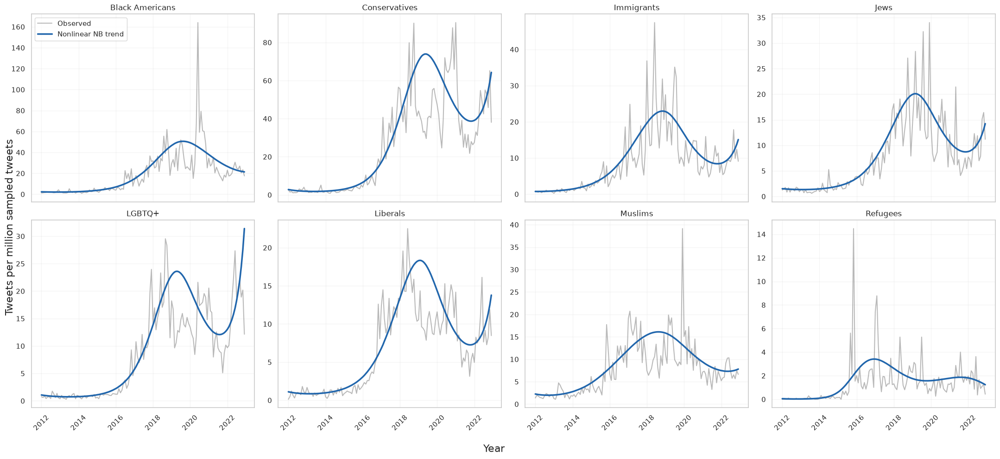

In [74]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from patsy import bs

# Group-specific nonlinear trends using cubic splines
formula = (
    "Y ~ C(group) * bs(t_years, df=5, degree=3)"
    " + C(month_num)"
)

model_spline = smf.negativebinomial(
    formula=formula,
    data=panel,
    offset=np.log(panel["N"]),
    loglike_method="nb2"
)

result_spline = model_spline.fit(
    method="bfgs",
    maxiter=1500,
    disp=False
)

print(result_spline.summary())

if not result_spline.mle_retvals.get("converged", False):
    raise RuntimeError("Spline NB model did not converge.")

# Calculate adjusted rates for 1 million sampled tweets
pred = panel.copy()
pred["N"] = 1_000_000
pred["month_num"] = 6  # Fixed season for adjusted trend

pred["adjusted_rate"] = result_spline.predict(
    exog=pred,
    offset=np.log(pred["N"])
)

panel["observed_rate"] = (
    panel["Y"] / panel["N"] * 1_000_000
)

# Plot
fig, axes = plt.subplots(
    2, 4, figsize=(22, 10), sharex=True
)

for ax, group in zip(axes.flat, GROUPS):
    actual = panel[panel["group"] == group].sort_values("month")
    fitted = pred[pred["group"] == group].sort_values("month")

    ax.plot(
        actual["month"],
        actual["observed_rate"],
        color="gray",
        alpha=0.55,
        linewidth=1.5,
        label="Observed"
    )

    ax.plot(
        fitted["month"],
        fitted["adjusted_rate"],
        color="#2166ac",
        linewidth=2.5,
        label="Nonlinear NB trend"
    )

    ax.set_title(group)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.2)

axes.flat[0].legend()

fig.supxlabel("Year", fontsize=16)
fig.supylabel(
    "Tweets per million sampled tweets",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "normalized_prevalence_NB_spline.pdf",
    bbox_inches="tight"
)
plt.show()


In [76]:

import numpy as np
import pandas as pd
from scipy.stats import norm

# ==================================================
# 1. EXTRACT THE FITTED MODEL'S DESIGN MATRIX
# ==================================================

fit_data = (
    result_spline.model.data.frame
    .reset_index(drop=True)
)

fit_data["month"] = pd.to_datetime(fit_data["month"])

# Exclude NB dispersion parameter alpha
coef_names = result_spline.params.index.drop("alpha")

X_fit = np.asarray(result_spline.model.exog)

assert X_fit.shape[0] == len(fit_data)
assert X_fit.shape[1] == len(coef_names)

beta = result_spline.params.loc[coef_names].to_numpy()

cov = (
    result_spline.cov_params()
    .loc[coef_names, coef_names]
    .to_numpy()
)

# ==================================================
# 2. COMPARE TWO YEARS FOR A GIVEN GROUP
# ==================================================

def compare_years(group, year1, year2, month=6):

    def get_design_row(year):
        target = pd.Timestamp(
            year=year,
            month=month,
            day=1
        )

        matches = np.flatnonzero(
            (
                (fit_data["group"] == group) &
                (fit_data["month"] == target)
            ).to_numpy()
        )

        if len(matches) != 1:
            raise ValueError(
                f"Expected one row for {group}, "
                f"{target:%Y-%m}; found {len(matches)}"
            )

        return X_fit[matches[0]]

    x1 = get_design_row(year1)
    x2 = get_design_row(year2)

    # Difference in log rates
    difference = x2 - x1

    log_irr = float(difference @ beta)

    variance = float(
        difference @ cov @ difference
    )

    se = np.sqrt(max(variance, 0))

    z = norm.ppf(0.975)

    return {
        "Group": group,
        "Comparison": f"{year2} vs {year1}",
        "IRR": np.exp(log_irr),
        "CI_lower": np.exp(log_irr - z * se),
        "CI_upper": np.exp(log_irr + z * se),
        "p_value": (
            2 * norm.sf(abs(log_irr / se))
            if se > 0 else np.nan
        )
    }

# ==================================================
# 3. CALCULATE GROUP-SPECIFIC IRRs
# ==================================================

results = []

for group in GROUPS:

    results.append(
        compare_years(group, 2015, 2019)
    )

    results.append(
        compare_years(group, 2019, 2022)
    )

comparison_df = pd.DataFrame(results)

print("\nSPLINE MODEL: PERIOD COMPARISONS\n")

print(
    comparison_df.round(4).to_string(index=False)
)

# ==================================================
# 4. SAVE RESULTS
# ==================================================

comparison_df.to_csv(
    "spline_period_IRR_comparisons.csv",
    index=False
)

print("\nSaved spline_period_IRR_comparisons.csv")



SPLINE MODEL: PERIOD COMPARISONS

          Group   Comparison     IRR  CI_lower  CI_upper  p_value
Black Americans 2019 vs 2015 10.5951    8.3638   13.4215   0.0000
Black Americans 2022 vs 2019  0.4685    0.3667    0.5985   0.0000
  Conservatives 2019 vs 2015 18.3633   14.2828   23.6097   0.0000
  Conservatives 2022 vs 2019  0.5983    0.4660    0.7681   0.0001
     Immigrants 2019 vs 2015  5.5759    4.4255    7.0254   0.0000
     Immigrants 2022 vs 2019  0.4693    0.3666    0.6007   0.0000
           Jews 2019 vs 2015  7.9407    6.2758   10.0472   0.0000
           Jews 2022 vs 2019  0.5003    0.3914    0.6394   0.0000
         LGBTQ+ 2019 vs 2015 16.5624   12.7389   21.5334   0.0000
         LGBTQ+ 2022 vs 2019  0.7198    0.5587    0.9274   0.0110
       Liberals 2019 vs 2015  8.9044    6.8514   11.5725   0.0000
       Liberals 2022 vs 2019  0.4922    0.3806    0.6365   0.0000
        Muslims 2019 vs 2015  2.5124    1.9855    3.1791   0.0000
        Muslims 2022 vs 2019  0.4908    0

In [77]:
from statsmodels.stats.multitest import multipletests

comparison_df["p_fdr"] = multipletests(
    comparison_df["p_value"],
    method="fdr_bh"
)[1]

print(
    comparison_df[
        ["Group", "Comparison", "IRR",
         "CI_lower", "CI_upper", "p_value", "p_fdr"]
    ].to_string(index=False)
)

          Group   Comparison       IRR  CI_lower  CI_upper       p_value         p_fdr
Black Americans 2019 vs 2015 10.595064  8.363848 13.421500  3.139152e-85  1.674215e-84
Black Americans 2022 vs 2019  0.468490  0.366744  0.598463  1.282899e-09  2.565797e-09
  Conservatives 2019 vs 2015 18.363347 14.282780 23.609726 4.629436e-114 7.407098e-113
  Conservatives 2022 vs 2019  0.598274  0.466001  0.768091  5.586093e-05  6.875191e-05
     Immigrants 2019 vs 2015  5.575912  4.425466  7.025429  4.021747e-48  1.072466e-47
     Immigrants 2022 vs 2019  0.469317  0.366648  0.600736  1.905081e-09  3.386811e-09
           Jews 2019 vs 2015  7.940657  6.275779 10.047205  9.559966e-67  3.823986e-66
           Jews 2022 vs 2019  0.500294  0.391425  0.639443  3.178668e-08  4.623518e-08
         LGBTQ+ 2019 vs 2015 16.562385 12.738925 21.533417  1.464618e-97  1.171694e-96
         LGBTQ+ 2022 vs 2019  0.719807  0.558700  0.927373  1.098354e-02  1.255261e-02
       Liberals 2019 vs 2015  8.904382  6.8

In [79]:

import numpy as np
import pandas as pd
from scipy.stats import norm

# Existing fitted model and its actual spline design matrix
fit_data = result_hac.model.data.frame.reset_index(drop=True)
fit_data["month"] = pd.to_datetime(fit_data["month"])

X = np.asarray(result_hac.model.exog)
beta = np.asarray(result_hac.params)
cov = np.asarray(result_hac.cov_params())

def compare_hac(year1, year2, month=6):
    date1 = pd.Timestamp(year1, month, 1)
    date2 = pd.Timestamp(year2, month, 1)

    idx1 = np.flatnonzero(
        (fit_data["month"] == date1).to_numpy()
    )
    idx2 = np.flatnonzero(
        (fit_data["month"] == date2).to_numpy()
    )

    if len(idx1) != 1 or len(idx2) != 1:
        raise ValueError("Expected exactly one row for each date")

    # Same group, month-of-year and standardized exposure:
    # offset cancels in this log-rate contrast.
    d = X[idx2[0]] - X[idx1[0]]

    log_irr = float(d @ beta)
    se = np.sqrt(float(d @ cov @ d))

    z = norm.ppf(0.975)

    return {
        "Comparison": f"{year2} vs {year1}",
        "IRR": np.exp(log_irr),
        "CI_lower": np.exp(log_irr - z * se),
        "CI_upper": np.exp(log_irr + z * se),
        "p_value": 2 * norm.sf(abs(log_irr / se))
    }

results_hac = pd.DataFrame([
    compare_hac(2015, 2019),
    compare_hac(2019, 2022)
])

print(results_hac.to_string(index=False))


  Comparison       IRR  CI_lower  CI_upper      p_value
2019 vs 2015 18.100981 10.644129 30.781806 1.132522e-26
2022 vs 2019  0.609082  0.410262  0.904255 1.392642e-02


In [78]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np

# Dispersion estimate from your original spline model
alpha = float(result_spline.params["alpha"])

# Example: one group
sub = panel[
    panel["group"] == "Conservatives"
].sort_values("month").copy()

model = smf.glm(
    "Y ~ bs(t_years, df=5, degree=3) + C(month_num)",
    data=sub,
    family=sm.families.NegativeBinomial(alpha=alpha),
    offset=np.log(sub["N"])
)

# HAC standard errors: account for up to 12 monthly lags
result_hac = model.fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12}
)

print(result_hac.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      Y   No. Observations:                  132
Model:                            GLM   Df Residuals:                      115
Model Family:        NegativeBinomial   Df Model:                           16
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -708.01
Date:                Thu, 05 Nov 2026   Deviance:                       108.82
Time:                        16:33:52   Pearson chi2:                     119.
No. Iterations:                    10   Pseudo R-squ. (CS):             0.9999
Covariance Type:                  HAC                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

In [69]:

import pandas as pd
from datetime import datetime
from storywrangling import Storywrangler

# Connect to Storywrangler
sw = Storywrangler()

# Get daily counts for ALL tweets, including retweets
daily = sw.get_lang(
    "_all",
    start_time=datetime(2012, 1, 1),
    end_time=datetime(2023, 1, 1)
)

print(daily.head())

# Make date a regular column
daily = daily.reset_index()

# Ensure column names
if "time" not in daily.columns:
    daily = daily.rename(columns={daily.columns[0]: "time"})

daily["time"] = pd.to_datetime(daily["time"])

# Keep study period
daily = daily[
    (daily["time"] >= "2012-01-01") &
    (daily["time"] < "2023-01-01")
].copy()

# Use tweet count, NOT number of words
daily["month"] = daily["time"].dt.to_period("M").astype(str)

monthly_totals = (
    daily.groupby("month", as_index=False)
    .agg(total_tweets=("count", "sum"))
)

# Check that all 132 months are present
expected_months = set(
    pd.period_range("2012-01", "2022-12", freq="M").astype(str)
)

missing = expected_months - set(monthly_totals["month"])

if missing:
    raise ValueError(f"Missing months: {sorted(missing)}")

# Save
monthly_totals.to_csv("monthly_totals.csv", index=False)

print(monthly_totals.head())
print("Total months:", len(monthly_totals))
print("Saved monthly_totals.csv")


ModuleNotFoundError: No module named 'storywrangling'

In [70]:
from data_mountain_query.connection import get_connection

collection, client = get_connection()
print(collection.full_name)

/users/t/p/tprama/.local/lib/python3.12/site-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Connecting on dm-mongovm-001,002,003
tweets.driphose3


In [71]:
from data_mountain_query.connection import get_connection

collection, client = get_connection()

print("Collection:", collection.full_name)

sample = collection.find_one(
    {},
    {
        "tweet_created_at": 1,
        "fastText_lang": 1,
        "rt_text": 1,
        "_id": 0
    }
)

print("Example document fields:", sample)

print("\nAvailable indexes:")
for name, info in collection.index_information().items():
    print(name, info["key"])

Connecting on dm-mongovm-001,002,003
Collection: tweets.driphose3
Example document fields: {'tweet_created_at': datetime.datetime(2010, 11, 1, 21, 0, 20), 'fastText_lang': 'it'}

Available indexes:
_id_ [('_id', 1)]
tweet_id_hashed [('tweet_id', 'hashed')]
fastText_lang_1 [('fastText_lang', 1)]
user_id_1 [('user_id', 1)]
tweet_created_at_1 [('tweet_created_at', 1)]
pure_text_text_rt_text_text_tweet_created_at_1 [('_fts', 'text'), ('_ftsx', 1), ('tweet_created_at', 1)]


In [72]:

import pandas as pd
from datetime import datetime

# Find an index beginning with tweet_created_at
indexes = collection.index_information()

date_indexes = [
    name for name, info in indexes.items()
    if info["key"][0][0] == "tweet_created_at"
]

if not date_indexes:
    raise RuntimeError(
        "No leading tweet_created_at index found. "
        "Avoid a large collection scan; request precomputed "
        "monthly counts or use an indexed date field."
    )

index_name = date_indexes[0]

# Verify that dates are stored as datetime objects
sample = collection.find_one(
    {"tweet_created_at": {"$exists": True}},
    {"tweet_created_at": 1}
)

if sample is None or not isinstance(
    sample["tweet_created_at"], datetime
):
    raise TypeError(
        "tweet_created_at is not stored as a MongoDB datetime. "
        "Inspect its type before constructing the range query."
    )

months = pd.date_range(
    "2012-01-01",
    "2023-01-01",
    freq="MS"
)

results = []

for start, end in zip(months[:-1], months[1:]):

    query = {
        "tweet_created_at": {
            "$gte": start.to_pydatetime(),
            "$lt": end.to_pydatetime()
        }
    }

    count = collection.count_documents(
        query,
        hint=index_name,
        maxTimeMS=60000
    )

    results.append({
        "month": start.strftime("%Y-%m"),
        "total_tweets": count
    })

    print(start.strftime("%Y-%m"), count)

monthly_totals = pd.DataFrame(results)

monthly_totals.to_csv(
    "monthly_totals.csv",
    index=False
)

print("\nSaved monthly_totals.csv")
print(monthly_totals.head())


2012-01 8003016
2012-02 8083079
2012-03 9125464
2012-04 9406644
2012-05 10073096
2012-06 10594416
2012-07 11521776
2012-08 11903605
2012-09 11098659
2012-10 11619851
2012-11 11733410
2012-12 12946254
2013-01 13108418
2013-02 12105762
2013-03 13802857
2013-04 13100483
2013-05 13904804
2013-06 13668290
2013-07 14561435
2013-08 14690605
2013-09 13390099
2013-10 13463522
2013-11 13141030
2013-12 13789928
2014-01 13504647
2014-02 12322675
2014-03 13882711
2014-04 13362379
2014-05 13565438
2014-06 13520298
2014-07 14477356
2014-08 14151524
2014-09 12793626
2014-10 13181782
2014-11 12959627
2014-12 13414262
2015-01 13686773
2015-02 12653927
2015-03 14077539
2015-04 12916069
2015-05 12465287
2015-06 11615986
2015-07 12095913
2015-08 12314329
2015-09 11039736
2015-10 11307706
2015-11 11396230
2015-12 11720939
2016-01 11466780
2016-02 10769177
2016-03 11800437
2016-04 11542793
2016-05 11325475
2016-06 11255695
2016-07 11589294
2016-08 11397898
2016-09 10500104
2016-10 10985554
2016-11 10869233
2

In [ ]:
df['Group'].unique()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# -----------------------------
# 1) Ensure year is integer and clean
# -----------------------------
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.dropna(subset=["year", "Group", "Sentiment"])
df["year"] = df["year"].astype(int)

# show every year tick across the full range
all_years = list(range(df["year"].min(), df["year"].max() + 1))

# -----------------------------
# 2) Group counts for lineplot (by sentiment)
# -----------------------------
grouped = df.groupby(["Group", "year", "Sentiment"]).size().reset_index(name="count")

# -----------------------------
# 3) Total comments per Group (for titles)
# -----------------------------
group_total = df.groupby("Group").size().to_dict()  # N per group

# -----------------------------
# 4) Peak year per Group (total across sentiments)
# -----------------------------
group_year_total = df.groupby(["Group", "year"]).size().reset_index(name="total_count")
peak_year_map = (
    group_year_total.loc[group_year_total.groupby("Group")["total_count"].idxmax()]
    .set_index("Group")["year"]
    .to_dict()
)
peak_count_map = (
    group_year_total.loc[group_year_total.groupby("Group")["total_count"].idxmax()]
    .set_index("Group")["total_count"]
    .to_dict()
)

# -----------------------------
# Plot settings
# -----------------------------
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.2)

palette = {
    "Neutral": "#1f77b4",
    "Supportive": "#ffd700",
    "Discriminatory": "#8000ff",
}

y_max = grouped["count"].max() + 100

# -----------------------------
# FacetGrid (wider figure)
# -----------------------------
g = sns.FacetGrid(
    grouped,
    col="Group",
    col_wrap=4,
    height=4.5,
    sharey=True,
    legend_out=True
)
g.fig.set_size_inches(24, 15)  # wider so year ticks fit

g.map_dataframe(
    sns.lineplot,
    x="year",
    y="count",
    hue="Sentiment",
    marker="o",
    linewidth=2.5,
    palette=palette
)

# -----------------------------
# Format axes + add totals and peak year per subplot
# -----------------------------
for ax in g.axes.flat:
    # seaborn sets the title like "Group = XYZ" by default for FacetGrid
    title = ax.get_title()
    group_name = title.split(" = ", 1)[-1]  # robust extraction

    N = group_total.get(group_name, 0)
    peak_year = peak_year_map.get(group_name, None)
    peak_cnt = peak_count_map.get(group_name, None)

    ax.set_ylim(0, y_max + 1)
    ax.set_xlabel("")
    ax.set_ylabel("")

    # year-wise ticks
    ax.set_xticks(all_years)
    ax.set_xticklabels(all_years, rotation=45, ha="right")

    # vertical line at peak year + annotation
    if peak_year is not None:
        ax.axvline(peak_year, linestyle="--", linewidth=2, alpha=0.8)
        ax.text(
            peak_year, ax.get_ylim()[1] * 0.92,
            f"Peak: {peak_year}\n({peak_cnt})",
            ha="center", va="top",
            fontsize=11
        )

    # title showing total N
    ax.set_title(f"{group_name} ({N})", fontsize=24)

# -----------------------------
# Custom legend at top
# -----------------------------
fig = g.fig
legend_elements = [
    Patch(facecolor=palette["Neutral"], label="Neutral"),
    Patch(facecolor=palette["Supportive"], label="Supportive"),
    Patch(facecolor=palette["Discriminatory"], label="Discriminatory"),
]
fig.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=3,
    frameon=True,
)

fig.supxlabel("Year", fontsize=24)
fig.supylabel("Number of Comments", fontsize=24)

plt.tight_layout(rect=[0, 0, 1, 0.93])

output_path = "comment_type_distribution_by_group_yearwise_with_peak.pdf"
plt.savefig(output_path, format="pdf", bbox_inches="tight")
plt.show()

In [74]:
con_2020 = df[(df["Group"] == "Refugees") & (df["year"] == 2017)]
for i, text in enumerate(con_2020["pure_text"].dropna(), start=1):
    print(f"\n--- {i} ---")
    print(text)


--- 1 ---
RT @krassenstein:In Alabama over 100,000 people who owe money in the way of court fines or legal fees – roughly 3 percent of the state’s voting-age population – have been struck from voting rolls. 

This is unconstitutional and is the reason Republicans are able to win despite a moronic platform.

--- 2 ---
RT @steve_avery617:@chelseahandler Not a Trump fan however he is a start for Change. Democrats and Republicans are evil and benefit from poor and needy people. Drain the swamp

--- 3 ---
RT @Cernovich: Brian Hook is at is again, he also is letting in 50,000 "refugees." https://t.co/rgqfOXE4un

--- 4 ---
RT @krassenstein:In Alabama over 100,000 people who owe money in the way of court fines or legal fees – roughly 3 percent of the state’s voting-age population – have been struck from voting rolls. 

This is unconstitutional and is the reason Republicans are able to win despite a moronic platform.

--- 5 ---
RT @Trump_Refugee: @thehill if that's true, GOP is damned if they 

ValueError: The palette dictionary is missing keys: {'Positive', 'Negative'}

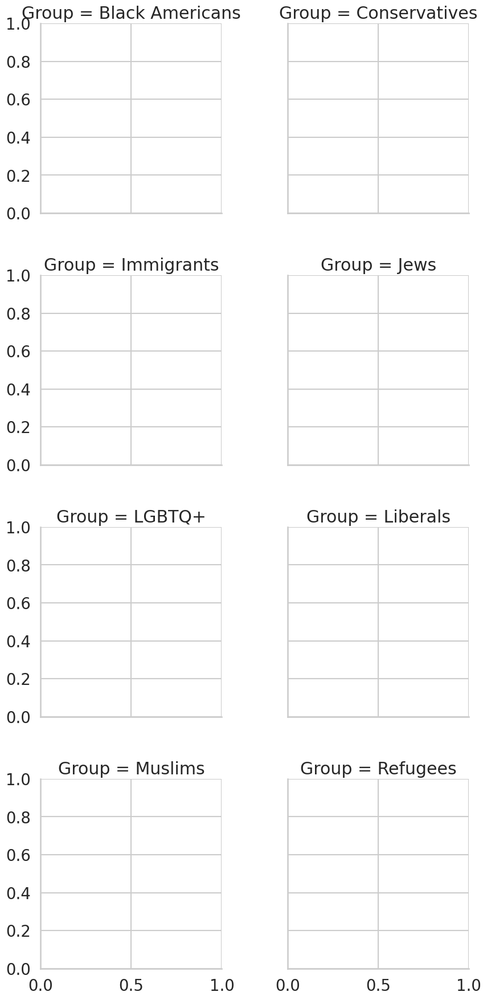

In [252]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch



# Group the data and compute proportions
grouped = df.groupby(['Group', 'year', 'Sentiment']).size().reset_index(name='count')

# Normalize within each (Group, year)
grouped['proportion'] = grouped.groupby(['Group','year'])['count'].transform(lambda x: x / x.sum())

# Set seaborn theme and context
sns.set_theme(style="whitegrid")
sns.set_context("talk", font_scale=1.2)

# Color palette for consistent comment types
palette = {
    'Neutral': '#1f77b4',
    'Supportive': '#ffd700',
    'Discriminatory': '#8000ff',
    'Critical': '#999999'
}

# Create the FacetGrid (now using proportion)
g = sns.FacetGrid(grouped, col="Group", col_wrap=2, height=4.5, sharey=True, legend_out=True)
g.map_dataframe(
    sns.lineplot,
    x='year',
    y='proportion',
    hue='Sentiment',
    marker="o",
    linewidth=2.5,
    palette=palette
)

# Set y-axis for proportions (0–1 range)
for ax in g.axes.flat:
    ax.set_ylim(0, 1.0)
    ax.set_xlabel('')
    ax.set_ylabel('')

# Titles for each subplot
g.set_titles(col_template="{col_name}")

# Custom legend at the top
fig = g.fig
legend_elements = [
    Patch(facecolor=palette['Neutral'], label='Neutral'),
    Patch(facecolor=palette['Supportive'], label='Supportive'),
    Patch(facecolor=palette['Discriminatory'], label='Discriminatory'),
    Patch(facecolor=palette['Critical'], label='Critical'),
]

fig.legend(
    handles=legend_elements,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    frameon=True,
)

# Axis labels
fig.supxlabel("Year", fontsize=24)
fig.supylabel("Proportion of Comments", fontsize=24)

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Save figure
output_path = "comment_type_proportion_by_group.pdf"
plt.savefig(output_path, format="pdf")

# Show plot
plt.show()


In [117]:
#Happiness

In [80]:
import pandas as pd
from collections import Counter
import numpy as np

# --- Step 1: Load LabMT word happiness scores ---
labmt = pd.read_csv('labMT-english.csv', header=None, names=['word', 'happiness_average'], sep=',')

filtered_labmt = labmt[(labmt['happiness_average'] < 4) | (labmt['happiness_average'] > 6)]

#filtered_labmt = labmt

# Convert to dictionary: word -> happiness score
labmt_dict = dict(zip(filtered_labmt['word'], filtered_labmt['happiness_average']))



In [98]:

import pandas as pd
import numpy as np

# Uses your previously created:
# labmt_dict
# corpus_happiness_and_std()

# Use the group column that produced your original figures
GROUP_COL = "Group" if "Group" in df.columns else "MappedGroup"

data = df.copy()

data["date"] = pd.to_datetime(
    data["tweet_created_at"],
    errors="coerce",
    utc=True
)

data = data[
    (data["date"].dt.year >= 2012) &
    (data["date"].dt.year <= 2022)
].copy()

data = data.dropna(subset=[GROUP_COL, "pure_text"])

# For consistency, decide whether to remove retweets or duplicates
# in the same way as your original happiness analysis.

data["year"] = data["date"].dt.year

# Two-month windows: Jan-Feb, Mar-Apr, etc.
data["period_month"] = (
    ((data["date"].dt.month - 1) // 2) * 2 + 1
)

data["period"] = pd.to_datetime({
    "year": data["year"],
    "month": data["period_month"],
    "day": 1
})

def calculate_group_happiness(data, grouping):

    corpora = (
        data.groupby(grouping)["pure_text"]
        .agg(lambda x: " ".join(x.astype(str)))
        .reset_index(name="joined_text")
    )

    scores = corpora["joined_text"].apply(
        lambda text: corpus_happiness_and_std(
            text, labmt_dict
        )
    )

    result = pd.concat(
        [corpora.drop(columns="joined_text"), scores],
        axis=1
    )

    return result

# Overall scores
overall = calculate_group_happiness(
    data, [GROUP_COL]
)

# Year-wise scores
yearly = calculate_group_happiness(
    data, [GROUP_COL, "year"]
)

# Two-month scores
bimonthly = calculate_group_happiness(
    data, [GROUP_COL, "period"]
)

print("\nOVERALL HAPPINESS")
print(overall.to_string(index=False))

print("\nYEARLY HAPPINESS")
print(yearly.head(20))

print("\nTWO-MONTH HAPPINESS")
print(bimonthly.head(20))

overall.to_csv("happiness_overall.csv", index=False)
yearly.to_csv("happiness_yearly.csv", index=False)
bimonthly.to_csv("happiness_2month.csv", index=False)



OVERALL HAPPINESS
    MappedGroup  happiness_score  happiness_std  n_scored_tokens
Black Americans         5.494030       1.748594         290012.0
  Conservatives         5.475112       1.736751         278902.0
     Immigrants         5.448429       1.738438         133378.0
           Jews         5.559957       1.688668          72965.0
         LGBTQ+         5.479839       1.748540          95373.0
       Liberals         5.432276       1.778176          53778.0
        Muslims         5.432173       1.793513          62217.0
       Refugees         5.086222       1.811207          15708.0

YEARLY HAPPINESS
        MappedGroup  year  happiness_score  happiness_std  n_scored_tokens
0   Black Americans  2012         5.488763       1.739957           1302.0
1   Black Americans  2013         5.456710       1.742251           1529.0
2   Black Americans  2014         5.425890       1.747851           1905.0
3   Black Americans  2015         5.379681       1.795449           2975.0
4  

In [99]:

import statsmodels.api as sm
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

happiness = bimonthly.copy()

happiness["year"] = happiness["period"].dt.year

happiness["era"] = pd.cut(
    happiness["year"],
    bins=[2011, 2015, 2019, 2022],
    labels=["2012-2015", "2016-2019", "2020-2022"]
)

results = []

for group, sub in happiness.groupby(GROUP_COL):

    sub = sub.dropna(
        subset=["happiness_score", "era"]
    ).sort_values("period")

    # Reference period: 2012-2015
    X = pd.get_dummies(
        sub["era"],
        drop_first=True,
        dtype=float
    )

    X = sm.add_constant(X)

    y = sub["happiness_score"].astype(float)

    if X.shape[1] != 3:
        print("Skipping incomplete era data:", group)
        continue

    model = sm.OLS(y, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 3}
    )

    names = model.params.index.tolist()

    # Contrast vectors:
    # Era 2 - Era 1, Era 3 - Era 2
    contrasts = [
        (
            "2016-2019 vs 2012-2015",
            {"2016-2019": 1}
        ),
        (
            "2020-2022 vs 2016-2019",
            {"2020-2022": 1, "2016-2019": -1}
        )
    ]

    for label, weights in contrasts:

        c = np.zeros(len(names))

        for term, weight in weights.items():
            c[names.index(term)] = weight

        estimate = float(c @ model.params.values)

        variance = float(
            c @ model.cov_params().values @ c
        )

        se = np.sqrt(max(variance, 0))

        z = norm.ppf(0.975)

        results.append({
            "Group": group,
            "Comparison": label,
            "Difference": estimate,
            "CI_lower": estimate - z * se,
            "CI_upper": estimate + z * se,
            "p_value": (
                2 * norm.sf(abs(estimate / se))
                if se > 0 else np.nan
            )
        })

results_df = pd.DataFrame(results)

valid = results_df["p_value"].notna()

results_df["p_fdr"] = np.nan

results_df.loc[valid, "p_fdr"] = multipletests(
    results_df.loc[valid, "p_value"],
    method="fdr_bh"
)[1]

print(results_df.round(5).to_string(index=False))

results_df.to_csv(
    "happiness_era_statistical_results.csv",
    index=False
)


          Group             Comparison  Difference  CI_lower  CI_upper  p_value   p_fdr
Black Americans 2016-2019 vs 2012-2015     0.04745  -0.03770   0.13261  0.27472 0.36098
Black Americans 2020-2022 vs 2016-2019     0.02826  -0.03412   0.09064  0.37460 0.39957
  Conservatives 2016-2019 vs 2012-2015     0.02415  -0.01507   0.06338  0.22749 0.36098
  Conservatives 2020-2022 vs 2016-2019     0.03578   0.00859   0.06298  0.00991 0.05286
     Immigrants 2016-2019 vs 2012-2015    -0.05461  -0.16053   0.05131  0.31229 0.36098
     Immigrants 2020-2022 vs 2016-2019     0.03533  -0.02336   0.09401  0.23804 0.36098
           Jews 2016-2019 vs 2012-2015    -0.10428  -0.19793  -0.01062  0.02909 0.09309
           Jews 2020-2022 vs 2016-2019     0.11450   0.04832   0.18068  0.00070 0.00557
         LGBTQ+ 2016-2019 vs 2012-2015    -0.14899  -0.27978  -0.01820  0.02557 0.09309
         LGBTQ+ 2020-2022 vs 2016-2019     0.07531  -0.01298   0.16360  0.09455 0.21612
       Liberals 2016-2019 vs 201

In [103]:
"""RQ2: Decompose changes in labMT happiness into SENTIMENT-CATEGORY MIX and
WITHIN-CATEGORY LANGUAGE changes for all eight MappedGroup identities.

Mapping for presentation: Negative -> Discriminatory, Positive -> Supportive,
Neutral -> Neutral. IMPORTANT: negative sentiment is NOT equivalent to
discrimination, and positive sentiment is NOT equivalent to support.
The mapped labels are proxies ONLY; do not make discrimination claims.

Jupyter usage: first load your tweet DataFrame as `df`, then run
    %run -i rq2_happiness_sentiment_decomposition.py

Requires: pandas, numpy, matplotlib, statsmodels and `labMT-english.csv`.
Uses the same neutral-word stop lens as your original happiness code:
retain only labMT words with happiness <4 or >6.

Outputs under happiness_sentiment_results/.
"""

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

# ============================= SETTINGS ===============================
LABMT_FILE = "labMT-english.csv"      # Change only if your file has another name
GROUP_COL = "MappedGroup"            # Falls back to 'Group' if necessary
TYPE_COL = "Sentiment"
TEXT_COL = "pure_text"
DATE_COL = "tweet_created_at"
ID_COL = "tweet_id"
GROUPS = [
    "Black Americans", "Conservatives", "Immigrants", "Jews",
    "LGBTQ+", "Liberals", "Muslims", "Refugees"
]
TYPES = ["Discriminatory", "Supportive", "Neutral"]
ERAS = {
    "2012-2015": (2012, 2015),
    "2016-2019": (2016, 2019),
    "2020-2022": (2020, 2022),
}
PAIRS = [("2012-2015", "2016-2019"),
         ("2016-2019", "2020-2022")]
N_BOOT = 1500                      # Start with 500 if testing interactively
BOOT_BLOCK_WINDOWS = 3             # Three two-month windows = six months
RANDOM_SEED = 42
MIN_MATCHED_PLOT = 20               # Hide exceptionally small-window lines
OUT = Path("happiness_sentiment_results")
OUT.mkdir(parents=True, exist_ok=True)
TOKEN_RE = re.compile(r"\b[a-z]+\b")  # Same tokenization as your code

# ============================= LEXICON ================================
def load_labmt(path):
    """Match user's two-column CSV format (with or without header)."""
    lex = pd.read_csv(path, header=None, names=["word", "happiness_average"],
                      encoding="utf-8-sig", low_memory=False)
    lex["word"] = lex["word"].astype(str).str.lower().str.strip()
    lex["happiness_average"] = pd.to_numeric(
        lex["happiness_average"], errors="coerce")
    lex = lex.dropna(subset=["happiness_average"])
    lex = lex[lex["word"].str.fullmatch(r"[a-z]+")]
    lex = lex[lex["happiness_average"].between(1, 9)]
    # EXACTLY the existing stop lens: keep words outside the closed [4, 6].
    lex = lex[(lex["happiness_average"] < 4) |
              (lex["happiness_average"] > 6)]
    lex = lex.drop_duplicates("word", keep="first")
    result = dict(zip(lex["word"], lex["happiness_average"].astype(float)))
    if len(result) < 100:
        raise ValueError("Too few labMT words loaded; check lexicon file format.")
    print(f"LabMT: {len(result):,} scored words after stop lens (<4 or >6).")
    return result

# ============================ PREPROCESS ==============================
def normalize_type(x):
    key = str(x).strip().lower()
    lookup = {
        "negative": "Discriminatory",
        "positive": "Supportive",
        "neutral": "Neutral",
    }
    return lookup.get(key, np.nan)


def prepare(frame):
    global GROUP_COL
    if GROUP_COL not in frame.columns and "Group" in frame.columns:
        GROUP_COL = "Group"
        print("MappedGroup not present; using Group instead.")
    required = [GROUP_COL, TYPE_COL, TEXT_COL, DATE_COL]
    absent = [x for x in required if x not in frame.columns]
    if absent:
        raise KeyError(f"Missing columns: {absent}")

    cols = required + ([ID_COL] if ID_COL in frame.columns else [])
    d = frame[cols].copy()
    print("Raw Sentiment labels (top 20):")
    print(d[TYPE_COL].value_counts(dropna=False).head(20).to_string())
    d[TYPE_COL] = d[TYPE_COL].map(normalize_type)
    d["date"] = pd.to_datetime(d[DATE_COL], errors="coerce", utc=True)
    eligible = (d[GROUP_COL].isin(GROUPS) & d[TYPE_COL].isin(TYPES) &
                d[TEXT_COL].notna() &
                d["date"].between(pd.Timestamp("2012-01-01", tz="UTC"),
                                  pd.Timestamp("2022-12-31 23:59:59.999999", tz="UTC")))
    print(f"Excluded {len(d) - int(eligible.sum()):,} rows with invalid group, "
          "SentimentMapped, date, or text.")
    d = d.loc[eligible].copy()

    # Count a given tweet only once per target group. Drop inconsistent
    # duplicated tweet-group keys rather than picking arbitrary labels.
    if ID_COL in d.columns:
        identified = d[ID_COL].notna()
        inconsistent = (d.loc[identified].groupby([ID_COL, GROUP_COL])[TYPE_COL]
                        .nunique())
        bad_keys = inconsistent[inconsistent > 1]
        if len(bad_keys):
            keys = pd.MultiIndex.from_frame(d[[ID_COL, GROUP_COL]])
            mark = keys.isin(bad_keys.index)
            print(f"WARNING: Excluding {int(mark.sum()):,} rows from "
                  f"{len(bad_keys):,} tweet-group keys with conflicting SentimentMapped.")
            d = d.loc[~mark].copy()
        before = len(d)
        d = d.drop_duplicates(subset=[ID_COL, GROUP_COL], keep="first")
        print(f"Removed {before-len(d):,} duplicate tweet-group rows.")
    else:
        warnings.warn("No tweet_id column; identical tweet-group records may be counted twice.")

    if d.empty:
        raise ValueError("No eligible data. Check Sentiment labels and group mapping.")
    dt = d["date"].dt.tz_convert(None)
    d["period"] = pd.to_datetime({
        "year": dt.dt.year,
        "month": ((dt.dt.month - 1) // 2) * 2 + 1,
        "day": 1,
    })
    d["era"] = np.select(
        [dt.dt.year.between(a, b) for a, b in ERAS.values()],
        list(ERAS), default="OUTSIDE")
    print(f"Using {len(d):,} tweet-group records across "
          f"{d[GROUP_COL].nunique()} groups.")
    print("Eligible mapped-sentiment counts (Negative->Discriminatory, Positive->Supportive):")
    print(d[TYPE_COL].value_counts().to_string())
    return d


def score_tweets(d, lex):
    """Calculate matched-token counts and happiness sums for exact aggregation."""
    n_tokens, n_matched, sums = [], [], []
    for txt in d[TEXT_COL]:
        words = TOKEN_RE.findall(str(txt).lower())
        scores = [lex[w] for w in words if w in lex]
        n_tokens.append(len(words))
        n_matched.append(len(scores))
        sums.append(float(sum(scores)))
    d = d.copy()
    d["n_all_tokens"] = n_tokens
    d["n_matched_tokens"] = n_matched
    d["score_sum"] = sums
    d = d.rename(columns={GROUP_COL: "MappedGroup", TYPE_COL: "SentimentMapped"})
    print(f"Matched token count: {d['n_matched_tokens'].sum():,}; "
          f"coverage = {d['n_matched_tokens'].sum() / max(d['n_all_tokens'].sum(), 1):.3f}")
    return d


def summarize(d, keys):
    agg = d.groupby(keys, as_index=False).agg(
        n_tweets=("score_sum", "size"),
        n_all_tokens=("n_all_tokens", "sum"),
        n_matched_tokens=("n_matched_tokens", "sum"),
        score_sum=("score_sum", "sum"),
    )
    agg["happiness_score"] = agg["score_sum"] / agg["n_matched_tokens"].replace(0, np.nan)
    agg["lexicon_coverage"] = (agg["n_matched_tokens"] /
                                agg["n_all_tokens"].replace(0, np.nan))
    return agg

# ============================ DECOMPOSITION ===========================
def decompose_batch(a, b):
    """Exact symmetric Kitagawa decomposition for matched-token weighted means.

    Input a,b: shape [B, 3, 2] with last axis [number of matched tokens,
    sum of their happiness scores]. Returns [B, 3] effects:
    total change, composition contribution, within-type contribution.

    If a type occurs in only one era, total remains identified but its
    composition vs within contributions are not separately identified.
    """
    a, b = np.asarray(a, float), np.asarray(b, float)
    if a.ndim == 2:
        a = a[None, ...]
        b = b[None, ...]
    n0, n1 = a[:, :, 0], b[:, :, 0]
    sum0, sum1 = a[:, :, 1], b[:, :, 1]
    total0, total1 = n0.sum(axis=1), n1.sum(axis=1)
    h0 = np.divide(sum0.sum(axis=1), total0, out=np.full(len(a), np.nan),
                   where=total0 > 0)
    h1 = np.divide(sum1.sum(axis=1), total1, out=np.full(len(a), np.nan),
                   where=total1 > 0)
    delta = h1 - h0

    active = (n0 + n1) > 0
    missing_one_era = np.any(active & ((n0 == 0) | (n1 == 0)), axis=1)
    mu0 = np.divide(sum0, n0, out=np.zeros_like(sum0), where=n0 > 0)
    mu1 = np.divide(sum1, n1, out=np.zeros_like(sum1), where=n1 > 0)
    p0 = np.divide(n0, total0[:, None], out=np.zeros_like(n0),
                   where=total0[:, None] > 0)
    p1 = np.divide(n1, total1[:, None], out=np.zeros_like(n1),
                   where=total1[:, None] > 0)
    mix_by_type = (p1 - p0) * (mu0 + mu1) / 2
    within_by_type = (mu1 - mu0) * (p0 + p1) / 2
    mix = mix_by_type.sum(axis=1)
    within = within_by_type.sum(axis=1)
    missing = missing_one_era | (total0 <= 0) | (total1 <= 0)
    mix[missing], within[missing] = np.nan, np.nan
    mix_by_type[missing, :] = np.nan
    within_by_type[missing, :] = np.nan
    return np.column_stack([delta, mix, within]), mix_by_type, within_by_type


def draw_block_indices(n, B, block, rng):
    """Circular moving-block resampling within a historical era."""
    k = int(np.ceil(n / block))
    starts = rng.integers(0, n, size=(B, k))
    idx = (starts[:, :, None] + np.arange(block)[None, None, :]) % n
    return idx.reshape(B, -1)[:, :n]


def era_periods(era):
    first, last = ERAS[era]
    return pd.date_range(f"{first}-01-01", f"{last}-11-01", freq="2MS")


def make_matrix(window_tab, group, era):
    """All two-month windows and types. Reindex NUMERIC columns only.

    Pandas' Arrow-backed string columns reject fill_value=0, so we must
    drop all label/string data columns before filling missing numeric cells.
    """
    dates = era_periods(era)
    ix = pd.MultiIndex.from_product(
        [dates, TYPES], names=["period", "SentimentMapped"]
    )
    sel = window_tab.loc[
        window_tab["MappedGroup"].eq(group),
        ["period", "SentimentMapped", "n_matched_tokens", "score_sum"]
    ].copy()
    sel["period"] = pd.to_datetime(sel["period"])
    for col in ["n_matched_tokens", "score_sum"]:
        sel[col] = pd.to_numeric(sel[col], errors="raise").astype(float)

    # Groupby is defensive: ensures an index unique before reindex.
    numeric = sel.groupby(["period", "SentimentMapped"])[
        ["n_matched_tokens", "score_sum"]
    ].sum()
    aligned = numeric.reindex(ix, fill_value=0.0)
    return aligned.to_numpy(dtype=float).reshape(len(dates), len(TYPES), 2)


def make_decomposition(window_tab):
    rng = np.random.default_rng(RANDOM_SEED)
    # Same time-block resampling indices for all groups within each era.
    draws = {e: draw_block_indices(len(era_periods(e)), N_BOOT,
                                   BOOT_BLOCK_WINDOWS, rng) for e in ERAS}
    rows, contrib_rows = [], []
    for group in GROUPS:
        matrices = {era: make_matrix(window_tab, group, era) for era in ERAS}
        for old, new in PAIRS:
            old_tot = matrices[old].sum(axis=0)
            new_tot = matrices[new].sum(axis=0)
            effects, mix_type, within_type = decompose_batch(old_tot, new_tot)
            delta, mix, within = effects[0]
            # Resample contiguous 2-month windows WITHIN the eras being compared.
            old_bs = matrices[old][draws[old]].sum(axis=1)
            new_bs = matrices[new][draws[new]].sum(axis=1)
            bs, _, _ = decompose_batch(old_bs, new_bs)

            total_old_n = old_tot[:, 0].sum()
            total_new_n = new_tot[:, 0].sum()
            h_old = old_tot[:, 1].sum() / total_old_n if total_old_n else np.nan
            h_new = new_tot[:, 1].sum() / total_new_n if total_new_n else np.nan
            missing_types = [TYPES[i] for i in range(3) if
                             (old_tot[i, 0] == 0) != (new_tot[i, 0] == 0)]
            record = {
                "MappedGroup": group, "Comparison": f"{new} vs {old}",
                "H_old_pooled": h_old, "H_new_pooled": h_new,
                "old_matched_tokens": int(total_old_n),
                "new_matched_tokens": int(total_new_n),
                "delta_h": delta, "composition_effect": mix,
                "within_type_effect": within,
                "decomposition_identifiable": bool(np.isfinite(mix)),
                "missing_type_in_one_era": ";".join(missing_types),
            }
            if np.isfinite(mix) and not np.isclose(delta, mix + within, atol=1e-10):
                raise AssertionError("Decomposition must equal total happiness change.")
            for j, effect_name in enumerate(["delta_h", "composition_effect", "within_type_effect"]):
                vals = bs[:, j]
                vals = vals[np.isfinite(vals)]
                # Numerical noise around exactly zero must not create
                # spuriously significant sign-based bootstrap p-values.
                vals = np.where(np.abs(vals) < 1e-10, 0.0, vals)
                record[f"{effect_name}_bootstrap_valid"] = len(vals)
                if len(vals) >= max(200, int(0.7 * N_BOOT)) and np.isfinite(record[effect_name]):
                    record[f"{effect_name}_CI_lower"] = np.percentile(vals, 2.5)
                    record[f"{effect_name}_CI_upper"] = np.percentile(vals, 97.5)
                    # Approximate two-sided sign-based bootstrap p-value.
                    record[f"{effect_name}_p_approx"] = min(
                        1.0, 2 * min(((vals <= 0).sum() + 1) / (len(vals) + 1),
                                    ((vals >= 0).sum() + 1) / (len(vals) + 1)))
                else:
                    record[f"{effect_name}_CI_lower"] = np.nan
                    record[f"{effect_name}_CI_upper"] = np.nan
                    record[f"{effect_name}_p_approx"] = np.nan
            rows.append(record)

            for i, category in enumerate(TYPES):
                p_old = old_tot[i, 0] / total_old_n if total_old_n else np.nan
                p_new = new_tot[i, 0] / total_new_n if total_new_n else np.nan
                contrib_rows.append({
                    "MappedGroup": group, "Comparison": f"{new} vs {old}",
                    "SentimentMapped": category,
                    "old_token_share": p_old, "new_token_share": p_new,
                    "old_type_happiness": (old_tot[i, 1] / old_tot[i, 0]
                                           if old_tot[i, 0] else np.nan),
                    "new_type_happiness": (new_tot[i, 1] / new_tot[i, 0]
                                           if new_tot[i, 0] else np.nan),
                    "composition_contribution": mix_type[0, i],
                    "within_type_contribution": within_type[0, i],
                })
    result = pd.DataFrame(rows)
    # Correct ALL 48 exploratory component tests together.
    effect_cols = [f"{x}_p_approx" for x in
                   ("delta_h", "composition_effect", "within_type_effect")]
    p_entries = [((i, col), result.at[i, col])
                 for i in result.index for col in effect_cols
                 if pd.notna(result.at[i, col])]
    p_index = pd.MultiIndex.from_tuples([entry[0] for entry in p_entries])
    corrected = pd.Series(
        multipletests([entry[1] for entry in p_entries], method="fdr_bh")[1],
        index=p_index)
    for col in effect_cols:
        result[col.replace("_p_approx", "_p_fdr_48")] = np.nan
        if col in corrected.index.get_level_values(1):
            valid = corrected.xs(col, level=1)
            result.loc[valid.index, col.replace("_p_approx", "_p_fdr_48")] = valid
    return result, pd.DataFrame(contrib_rows)

# ============================== PLOTS ================================
def plot_happiness(twom, overall_twom):
    fig, axes = plt.subplots(4, 2, figsize=(13, 13), sharex=True)
    for ax, group in zip(axes.flat, GROUPS):
        q = twom[twom["MappedGroup"].eq(group)].copy()
        for c in TYPES:
            s = q[q["SentimentMapped"].eq(c)].sort_values("period")
            y = s["happiness_score"].where(s["n_matched_tokens"] >= MIN_MATCHED_PLOT)
            ax.plot(s["period"], y, marker=".", linewidth=1, alpha=0.7,
                    label=c)
        o = overall_twom[overall_twom["MappedGroup"].eq(group)].sort_values("period")
        ax.plot(o["period"], o["happiness_score"], linewidth=2.2,
                label="All types")
        ax.set_title(group)
        ax.set_ylabel("labMT happiness")
        ax.grid(alpha=0.2)
    axes[0, 0].legend(fontsize=8, loc="best")
    fig.suptitle("Happiness by social group and mapped sentiment category (two-month windows)")
    fig.tight_layout()
    fig.savefig(OUT / "happiness_sentiment_2month.pdf", bbox_inches="tight")
    plt.close(fig)


def plot_decomp(results):
    fig, axes = plt.subplots(1, 2, figsize=(12, 6.8), sharey=True)
    for ax, (old, new) in zip(axes, PAIRS):
        s = (results[results["Comparison"].eq(f"{new} vs {old}")]
             .set_index("MappedGroup").reindex(GROUPS))
        y = np.arange(len(GROUPS))
        ax.barh(y - 0.18, s["composition_effect"], height=0.35,
                label="Mapped-sentiment-category mix")
        ax.barh(y + 0.18, s["within_type_effect"], height=0.35,
                label="Within-type language")
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_yticks(y, GROUPS)
        ax.invert_yaxis()
        ax.set_title(f"{new} vs {old}")
        ax.set_xlabel("Contribution to change in labMT happiness")
        ax.grid(axis="x", alpha=0.2)
    axes[0].legend(fontsize=9)
    fig.suptitle("Exact decomposition of pooled-corpus happiness changes")
    fig.tight_layout()
    fig.savefig(OUT / "happiness_decomposition.pdf", bbox_inches="tight")
    plt.close(fig)

# =============================== RUN =================================
if "df" not in globals() or not isinstance(df, pd.DataFrame):
    raise RuntimeError("Load your tweet DataFrame as `df` before running this script.")

lexicon = load_labmt(LABMT_FILE)
tweets = score_tweets(prepare(df), lexicon)

# Main output tables. Only non-neutral matched words contribute to happiness.
twom = summarize(tweets, ["MappedGroup", "period", "SentimentMapped"])
era_types = summarize(tweets, ["MappedGroup", "era", "SentimentMapped"])
era_all = summarize(tweets, ["MappedGroup", "era"])
twom_all = summarize(tweets, ["MappedGroup", "period"])

# Token mix shares, rather than tweet-count shares, give exact decomposition.
era_types = era_types.merge(
    era_all[["MappedGroup", "era", "n_matched_tokens"]]
    .rename(columns={"n_matched_tokens": "all_type_matched_tokens"}),
    on=["MappedGroup", "era"], how="left")
era_types["matched_token_share"] = (
    era_types["n_matched_tokens"] /
    era_types["all_type_matched_tokens"].replace(0, np.nan))

results, detailed = make_decomposition(twom)

twom.to_csv(OUT / "happiness_sentiment_2month.csv", index=False)
era_types.to_csv(OUT / "happiness_sentiment_era.csv", index=False)
era_all.to_csv(OUT / "happiness_group_era_pooled.csv", index=False)
results.to_csv(OUT / "happiness_sentiment_decomposition_bootstrap.csv", index=False)
detailed.to_csv(OUT / "happiness_decomposition_by_sentiment.csv", index=False)
plot_happiness(twom, twom_all)
plot_decomp(results)

show_cols = ["MappedGroup", "Comparison", "delta_h", "composition_effect",
             "within_type_effect", "delta_h_CI_lower", "delta_h_CI_upper",
             "delta_h_p_fdr_48", "decomposition_identifiable"]
print("\nEXACT HAPPINESS DECOMPOSITION + TIME-BLOCK BOOTSTRAP")
print(results[show_cols].round(5).to_string(index=False))
print(f"\nResults saved to: {OUT.resolve()}")
print("NOTE: pooled-era happiness changes are NOT equal-weighted window changes "
      "from your earlier HAC regressions. Use these new values for decomposition.")
print("Bootstrap uncertainty reflects temporal variation across blocks; it does "
      "not validate lexicon labels, mapped-sentiment-category annotations, or causal claims.")

print("CAUTION: Discriminatory/Supportive are requested aliases for Negative/Positive "
      "sentiment, NOT validated annotations of discrimination or support.")


LabMT: 3,583 scored words after stop lens (<4 or >6).
Raw Sentiment labels (top 20):
Sentiment
Negative    129414
Positive     12892
NaN          10278
Neutral        662
Excluded 10,278 rows with invalid group, SentimentMapped, date, or text.
Removed 7,417 duplicate tweet-group rows.
Using 135,551 tweet-group records across 8 groups.
Eligible mapped-sentiment counts (Negative->Discriminatory, Positive->Supportive):
Sentiment
Discriminatory    122573
Supportive         12478
Neutral              500
Matched token count: 876,134; coverage = 0.206

EXACT HAPPINESS DECOMPOSITION + TIME-BLOCK BOOTSTRAP
    MappedGroup             Comparison  delta_h  composition_effect  within_type_effect  delta_h_CI_lower  delta_h_CI_upper  delta_h_p_fdr_48  decomposition_identifiable
Black Americans 2016-2019 vs 2012-2015  0.08648             0.00564             0.08084          -0.00698           0.15919           0.22959                        True
Black Americans 2020-2022 vs 2016-2019  0.00239       

In [104]:
"""RQ2 labMT happiness decomposition: component CIs + binary-sentiment sensitivity.

Reuses the precomputed, token-weighted 2-month table from
  happiness_sentiment_results/happiness_sentiment_2month.csv
or an existing `twom` DataFrame in the notebook (run via `%run -i`).

Three-category analysis: Negative / Positive / Neutral sentiment.
Two-category sensitivity: Negative / Positive only, explicitly excluding Neutral.

Previously assigned labels 'Discriminatory' and 'Supportive' are aliases only.
They should be called NEGATIVE and POSITIVE SENTIMENT in publications.

Methods:
  Exact symmetric Kitagawa decomposition, weighting by scored-token counts.
  Separate 95% percentile moving-block-bootstrap CIs for total, composition,
  and within-sentiment effects; blocks resampled within each era.
  Approximate sign-based bootstrap p-values, exploratory BH-FDR within
  each specification across all valid total/composition/within tests.
  Overlap or absence of a class in one era is explicitly identified.

No re-tokenization is needed, but the same original labMT stop lens is assumed.
"""

from pathlib import Path
import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests

# ---------------------- USER SETTINGS ----------------------
INPUT_CSV = Path('happiness_sentiment_results/happiness_sentiment_2month.csv')
OUT_DIR = Path('happiness_sentiment_results/component_CI_and_binary_sensitivity')
OUT_DIR.mkdir(parents=True, exist_ok=True)
N_BOOT = 4000
BLOCK_LENGTH = 3  # three consecutive 2-month observations = 6 months
RANDOM_SEED = 20261106
MIN_VALID_FRAC = 0.80  # don't report component CI if too many bootstrap draws unidentifiable
GROUP_ORDER = [
    'Black Americans', 'Conservatives', 'Immigrants', 'Jews',
    'LGBTQ+', 'Liberals', 'Muslims', 'Refugees'
]
ERAS = {
    '2012-2015': (2012, 2015),
    '2016-2019': (2016, 2019),
    '2020-2022': (2020, 2022)
}
PAIRS = [('2012-2015', '2016-2019'), ('2016-2019', '2020-2022')]
SPECS = {
    'three_category': ['Negative', 'Positive', 'Neutral'],
    'negative_positive_only': ['Negative', 'Positive']
}

# ------------------------ INPUT ----------------------------
def get_window_data():
    if INPUT_CSV.is_file():
        src = pd.read_csv(INPUT_CSV)
        print(f'Read existing two-month summary: {INPUT_CSV}')
    elif 'twom' in globals() and isinstance(globals()['twom'], pd.DataFrame):
        src = globals()['twom'].copy()
        print('Using the existing notebook `twom` DataFrame')
    else:
        raise FileNotFoundError(
            f'Could not find {INPUT_CSV}. First run the happiness-sentiment '
            'script to generate the two-month CSV, or provide `twom` via %run -i.'
        )

    required = ['MappedGroup', 'period', 'n_matched_tokens', 'score_sum']
    missing = [c for c in required if c not in src.columns]
    if missing:
        raise ValueError(f'Missing columns in two-month summary: {missing}')
    source_col = 'SentimentMapped' if 'SentimentMapped' in src.columns else 'Sentiment'
    if source_col not in src.columns:
        raise ValueError('Expected SentimentMapped or Sentiment column')

    mapping = {
        'negative': 'Negative', 'discriminatory': 'Negative',
        'positive': 'Positive', 'supportive': 'Positive',
        'neutral': 'Neutral'
    }
    src = src.copy()
    src['SentimentCategory'] = src[source_col].astype('string').str.strip().str.lower().map(mapping)
    src['period'] = pd.to_datetime(src['period'], errors='coerce')
    if getattr(src['period'].dt, 'tz', None) is not None:
        src['period'] = src['period'].dt.tz_localize(None)
    src['period'] = src['period'].dt.to_period('M').dt.to_timestamp()
    for c in ['n_matched_tokens', 'score_sum']:
        src[c] = pd.to_numeric(src[c], errors='raise')
    if 'n_tweets' not in src.columns:
        src['n_tweets'] = np.nan
    else:
        src['n_tweets'] = pd.to_numeric(src['n_tweets'], errors='coerce')

    bad = src['SentimentCategory'].isna() | src['period'].isna() | src['MappedGroup'].isna()
    if bad.any():
        raise ValueError(f'{int(bad.sum())} unexpected rows contain invalid group, period or sentiment')
    if (src['n_matched_tokens'] < 0).any():
        raise ValueError('Negative token counts detected')
    if not np.isfinite(src['score_sum']).all():
        raise ValueError('Invalid happiness sums detected')
    if (src['period'].dt.year < 2012).any() or (src['period'].dt.year > 2022).any():
        raise ValueError('Unexpected dates outside 2012-2022')

    src = src.groupby(['MappedGroup', 'period', 'SentimentCategory'], as_index=False)[
        ['n_tweets', 'n_matched_tokens', 'score_sum']
    ].sum(min_count=1)
    print('\nRetained window-level sentiment records by category:')
    print(src.groupby('SentimentCategory')[['n_tweets', 'n_matched_tokens']].sum().to_string())
    print('NOTE: these are already scored/deduplicated in the original analysis.')
    return src


def era_dates(era):
    first, last = ERAS[era]
    return pd.date_range(f'{first}-01-01', f'{last}-11-01', freq='2MS')


def matrix_of(src, group, era, categories):
    dates = era_dates(era)
    idx = pd.MultiIndex.from_product([dates, categories], names=['period', 'SentimentCategory'])
    # Restrict to numbers before reindexing; prevents Arrow string fill-value errors.
    subset = src.loc[src['MappedGroup'].eq(group),
                     ['period', 'SentimentCategory', 'n_matched_tokens', 'score_sum']]
    grouped = subset.groupby(['period', 'SentimentCategory'])[
        ['n_matched_tokens', 'score_sum']
    ].sum()
    filled = grouped.reindex(idx, fill_value=0.0)
    return filled.to_numpy(dtype=float).reshape(len(dates), len(categories), 2)


# -------------------- DECOMPOSITION -----------------------
def decompose(a, b):
    """Vectorized exact symmetric decomposition.

    a,b: [B, #categories, 2] or [#categories, 2].
    Return [B,3] columns delta, composition, within; mask components when
    a category has positive matched-token weight in only one era.
    """
    a, b = np.asarray(a, float), np.asarray(b, float)
    if a.ndim == 2:
        a, b = a[None], b[None]
    n0, n1 = a[:, :, 0], b[:, :, 0]
    s0, s1 = a[:, :, 1], b[:, :, 1]
    tot0, tot1 = n0.sum(axis=1), n1.sum(axis=1)
    H0 = np.divide(s0.sum(axis=1), tot0,
                   out=np.full(len(a), np.nan), where=tot0 > 0)
    H1 = np.divide(s1.sum(axis=1), tot1,
                   out=np.full(len(a), np.nan), where=tot1 > 0)
    p0 = np.divide(n0, tot0[:, None], out=np.zeros_like(n0), where=tot0[:, None] > 0)
    p1 = np.divide(n1, tot1[:, None], out=np.zeros_like(n1), where=tot1[:, None] > 0)
    mu0 = np.divide(s0, n0, out=np.zeros_like(s0), where=n0 > 0)
    mu1 = np.divide(s1, n1, out=np.zeros_like(s1), where=n1 > 0)

    # Since the missing category mean cannot be learned when only one period
    # contains that category, components are undefined (but total H1-H0 exists).
    absent_only_one = np.any((n0 > 0) != (n1 > 0), axis=1)
    identifiable = (tot0 > 0) & (tot1 > 0) & ~absent_only_one
    comp = ((p1 - p0) * (mu0 + mu1) / 2).sum(axis=1)
    within = ((mu1 - mu0) * (p0 + p1) / 2).sum(axis=1)
    comp[~identifiable], within[~identifiable] = np.nan, np.nan
    effect = np.column_stack([H1-H0, comp, within])
    return effect


def moving_block_draws(n, B, block, rng):
    if n < 1:
        raise ValueError('Empty time period')
    nstarts = (n + block - 1) // block
    starts = rng.integers(0, n, size=(B, nstarts))
    idx = (starts[..., None] + np.arange(block)[None, None, :]) % n
    return idx.reshape(B, -1)[:, :n]


def ci_and_p(draws, estimate):
    """Percentile CI + approximate two-sided bootstrap sign p-value.

    p-values are exploratory and should not be interpreted as exact tests.
    """
    good = draws[np.isfinite(draws)]
    frac = len(good) / len(draws)
    if (not np.isfinite(estimate)) or frac < MIN_VALID_FRAC or len(good) < 100:
        return (np.nan, np.nan, np.nan, len(good), frac)
    good = np.where(np.abs(good) < 1e-12, 0.0, good)
    low, high = np.percentile(good, [2.5, 97.5])
    p = min(1., 2 * min(((good <= 0).sum() + 1) / (len(good)+1),
                        ((good >= 0).sum() + 1) / (len(good)+1)))
    return low, high, p, len(good), frac


def run_all(src):
    rng = np.random.default_rng(RANDOM_SEED)
    # Reuse SAME sampled windows for both specs and all groups so their CIs
    # reflect paired temporal resampling; resampling separately within eras.
    bs_indices = {era: moving_block_draws(len(era_dates(era)), N_BOOT, BLOCK_LENGTH, rng)
                  for era in ERAS}
    actual_groups = [g for g in GROUP_ORDER if g in set(src['MappedGroup'])]
    actual_groups += sorted(set(src['MappedGroup']) - set(actual_groups))
    rows, coverage_rows = [], []
    for spec, categories in SPECS.items():
        filtered = src[src['SentimentCategory'].isin(categories)]
        for group in actual_groups:
            mats = {era: matrix_of(filtered, group, era, categories) for era in ERAS}
            for era, a in mats.items():
                for category, n, s in zip(categories, a[:, :, 0].sum(axis=0),
                                           a[:, :, 1].sum(axis=0)):
                    coverage_rows.append({
                        'specification': spec, 'MappedGroup': group,
                        'era': era, 'Sentiment': category,
                        'matched_tokens': int(n),
                        'happiness_score': s/n if n else np.nan,
                    })
            for old, new in PAIRS:
                a, b = mats[old].sum(axis=0), mats[new].sum(axis=0)
                point = decompose(a, b)[0]
                boot_a = mats[old][bs_indices[old]].sum(axis=1)
                boot_b = mats[new][bs_indices[new]].sum(axis=1)
                boot = decompose(boot_a, boot_b)
                diff = point[0] - point[1] - point[2]
                if np.isfinite(diff) and abs(diff) > 1e-8:
                    raise AssertionError('Decomposition does not sum to total happiness change')
                total0 = a[:, 0].sum()
                total1 = b[:, 0].sum()
                row = {
                    'specification': spec,
                    'MappedGroup': group,
                    'Comparison': f'{new} vs {old}',
                    'old_happiness': a[:, 1].sum()/total0 if total0 else np.nan,
                    'new_happiness': b[:, 1].sum()/total1 if total1 else np.nan,
                    'old_matched_tokens': int(total0),
                    'new_matched_tokens': int(total1),
                    'decomposition_identifiable': bool(np.isfinite(point[1])),
                    'missing_category_in_one_era': ';'.join(
                        c for i, c in enumerate(categories) if (a[i, 0] > 0) != (b[i, 0] > 0)
                    )
                }
                for j, effect in enumerate(['delta_h', 'composition_effect', 'within_type_effect']):
                    row[effect] = float(point[j])
                    ci_low, ci_high, p, n_valid, valid_frac = ci_and_p(boot[:, j], point[j])
                    row[effect + '_CI_lower'] = ci_low
                    row[effect + '_CI_upper'] = ci_high
                    row[effect + '_p_approx'] = p
                    row[effect + '_valid_boot_n'] = n_valid
                    row[effect + '_valid_boot_fraction'] = valid_frac

                # This ratio can be unstable if total change is close to 0.
                row['within_fraction_of_delta'] = (
                    point[2] / point[0] if np.isfinite(point[2]) and abs(point[0]) > 1e-6 else np.nan
                )
                delta_b, comp_b, within_b = boot.T
                ratio_valid = (np.isfinite(delta_b) & np.isfinite(within_b) &
                               (np.abs(delta_b) > 1e-4))
                row['within_fraction_boot_valid_fraction'] = ratio_valid.mean()
                # Only report a ratio CI when the change has a consistent sign
                # in >=97.5% of bootstraps; otherwise percentages mislead.
                if (np.isfinite(point[0]) and abs(point[0]) > 1e-4 and
                        ratio_valid.mean() >= 0.8 and
                        (delta_b[np.isfinite(delta_b)] * point[0] > 0).mean() >= .975):
                    ratios = within_b[ratio_valid] / delta_b[ratio_valid]
                    row['within_fraction_CI_lower'], row['within_fraction_CI_upper'] = np.percentile(
                        ratios[np.isfinite(ratios)], [2.5, 97.5]
                    )
                else:
                    row['within_fraction_CI_lower'] = np.nan
                    row['within_fraction_CI_upper'] = np.nan

                # Whether within-type changes exceed composition in magnitude;
                # bootstrap probability (descriptive), not a formal p-value.
                aboth = np.isfinite(comp_b) & np.isfinite(within_b)
                row['P_abs_within_gt_abs_composition_bootstrap'] = (
                    float(np.mean(np.abs(within_b[aboth]) > np.abs(comp_b[aboth])))
                    if aboth.mean() >= MIN_VALID_FRAC else np.nan
                )
                rows.append(row)

    result = pd.DataFrame(rows)
    # BH separately for each specification: exploratory tests of three
    # components times two contrasts times eight groups (max 48).
    for spec in SPECS:
        mask = result['specification'].eq(spec)
        ix = result.index[mask]
        cols = [e + '_p_approx' for e in
                ('delta_h', 'composition_effect', 'within_type_effect')]
        all_values, locations = [], []
        for i in ix:
            for col in cols:
                val = result.at[i, col]
                if pd.notna(val):
                    all_values.append(val)
                    locations.append((i, col))
        result.loc[ix, 'FDR_family_n_tests'] = len(all_values)
        for col in cols:
            result.loc[ix, col.replace('_p_approx', '_p_fdr')] = np.nan
        if all_values:
            adj = multipletests(all_values, method='fdr_bh')[1]
            for (i, col), v in zip(locations, adj):
                result.at[i, col.replace('_p_approx', '_p_fdr')] = v

    coverage = pd.DataFrame(coverage_rows)
    return result, coverage


def save_plot(res):
    import matplotlib.pyplot as plt
    effects = [('composition_effect', 'Composition'), ('within_type_effect', 'Within sentiment')]
    for comparison in [f'{new} vs {old}' for old,new in PAIRS]:
        fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.5), sharey=True)
        for ax, spec in zip(axes, SPECS):
            sub = res[(res['specification'].eq(spec)) & res['Comparison'].eq(comparison)]
            sub = sub.set_index('MappedGroup').reindex(GROUP_ORDER)
            y = np.arange(len(GROUP_ORDER))
            for j, (key, name) in enumerate(effects):
                x = sub[key].to_numpy(float)
                lo = sub[key+'_CI_lower'].to_numpy(float)
                hi = sub[key+'_CI_upper'].to_numpy(float)
                offsets = -.13 if j == 0 else .13
                good = np.isfinite(x) & np.isfinite(lo) & np.isfinite(hi)
                # Draw confidence segments independently: percentile CIs do not
                # always contain the original point estimate.
                ax.hlines(y[good] + offsets, lo[good], hi[good], linewidth=1.8)
                ax.plot(x[good], y[good] + offsets, 'o', markersize=3.5, label=name)
            ax.axvline(0, color='black', lw=.8, alpha=.6)
            ax.set_yticks(y, GROUP_ORDER)
            ax.invert_yaxis()
            ax.set_xlabel('Happiness-point contribution (95% block bootstrap CI)')
            ax.set_title('3 categories' if spec == 'three_category' else 'Negative + Positive only')
            ax.grid(axis='x', alpha=.15)
        axes[0].legend(frameon=False)
        fig.suptitle(f'Composition and within-sentiment contributions\n{comparison}')
        fig.tight_layout()
        safe = comparison.replace(' ', '').replace('vs','_vs_')
        fig.savefig(OUT_DIR / f'component_CIs_{safe}.pdf', bbox_inches='tight')
        plt.close(fig)


def main():
    src = get_window_data()
    excluded = src[src['SentimentCategory'].eq('Neutral')]
    neutral_n = excluded['n_tweets'].sum()
    total_n = src['n_tweets'].sum()
    if pd.notna(total_n):
        print(f'\nTwo-category sensitivity excludes {int(neutral_n):,} Neutral tweet-group records '
              f'out of {int(total_n):,} retained records ({neutral_n/total_n:.2%}).')
    print(f'Neutral lexicon-matched tokens excluded: {int(excluded["n_matched_tokens"].sum()):,}')

    result, coverage = run_all(src)
    result.to_csv(OUT_DIR / 'happiness_decomposition_component_CIs_both_specs.csv', index=False)
    result.loc[result['specification'].eq('three_category')].to_csv(
        OUT_DIR / 'happiness_three_category_component_CIs.csv', index=False)
    result.loc[result['specification'].eq('negative_positive_only')].to_csv(
        OUT_DIR / 'happiness_binary_sensitivity_component_CIs.csv', index=False)
    coverage.to_csv(OUT_DIR / 'happiness_era_category_coverage.csv', index=False)
    # Reshape for easy side-by-side comparison
    compare = result.pivot(index=['MappedGroup', 'Comparison'], columns='specification',
                           values=['delta_h', 'composition_effect', 'within_type_effect',
                                   'decomposition_identifiable'])
    compare.columns = ['__'.join(map(str, tup)) for tup in compare.columns]
    compare.reset_index().to_csv(OUT_DIR / 'happiness_3category_vs_binary_comparison.csv', index=False)
    save_plot(result)

    cols = ['specification', 'MappedGroup', 'Comparison', 'delta_h',
            'composition_effect', 'composition_effect_CI_lower', 'composition_effect_CI_upper',
            'composition_effect_p_fdr', 'within_type_effect', 'within_type_effect_CI_lower',
            'within_type_effect_CI_upper', 'within_type_effect_p_fdr',
            'within_fraction_of_delta', 'decomposition_identifiable',
            'missing_category_in_one_era']
    print('\n\nCOMPONENT RESULTS (FDR corrected within each analysis specification):')
    print(result[cols].round(5).to_string(index=False))
    print('\nMUSLIMS: 2020-2022 vs 2016-2019')
    print(result.loc[(result['MappedGroup'] == 'Muslims') &
                     result['Comparison'].eq('2020-2022 vs 2016-2019'), cols].round(5).to_string(index=False))
    print('\nPERCENT VALID BOOTSTRAP DRAWS (especially important for sparse Neutral):')
    print(result.groupby('specification')[['composition_effect_valid_boot_fraction',
                                          'within_type_effect_valid_boot_fraction']].min().to_string())
    print(f'\nSaved results in: {OUT_DIR.resolve()}')
    print('NOTE: Bootstrap p-values are approximate and CIs are percentile CIs; verify'
          ' any borderline results and use consistent analysis families in manuscript.')
    print('Negative sentiment is NOT synonymous with discrimination or hostility.')

if __name__ == '__main__':
    main()


Read existing two-month summary: happiness_sentiment_results/happiness_sentiment_2month.csv

Retained window-level sentiment records by category:
                   n_tweets  n_matched_tokens
SentimentCategory                            
Negative             122573            791757
Neutral                 500              3248
Positive              12478             81129
NOTE: these are already scored/deduplicated in the original analysis.

Two-category sensitivity excludes 500 Neutral tweet-group records out of 135,551 retained records (0.37%).
Neutral lexicon-matched tokens excluded: 3,248


COMPONENT RESULTS (FDR corrected within each analysis specification):
         specification     MappedGroup             Comparison  delta_h  composition_effect  composition_effect_CI_lower  composition_effect_CI_upper  composition_effect_p_fdr  within_type_effect  within_type_effect_CI_lower  within_type_effect_CI_upper  within_type_effect_p_fdr  within_fraction_of_delta  decomposition_identif

In [105]:

import pandas as pd

results = pd.read_csv(
    "happiness_sentiment_results/"
    "component_CI_and_binary_sensitivity/"
    "happiness_decomposition_component_CIs_both_specs.csv"
)

muslims = results[
    (results["MappedGroup"] == "Muslims") &
    (results["Comparison"] == "2020-2022 vs 2016-2019")
]

columns = [
    "specification",
    "delta_h",
    "composition_effect",
    "composition_effect_CI_lower",
    "composition_effect_CI_upper",
    "composition_effect_p_fdr",
    "within_type_effect",
    "within_type_effect_CI_lower",
    "within_type_effect_CI_upper",
    "within_type_effect_p_fdr",
    "within_fraction_of_delta",
    "within_fraction_CI_lower",
    "within_fraction_CI_upper",
    "P_abs_within_gt_abs_composition_bootstrap"
]

print(muslims[columns].round(5).to_string(index=False))


         specification  delta_h  composition_effect  composition_effect_CI_lower  composition_effect_CI_upper  composition_effect_p_fdr  within_type_effect  within_type_effect_CI_lower  within_type_effect_CI_upper  within_type_effect_p_fdr  within_fraction_of_delta  within_fraction_CI_lower  within_fraction_CI_upper  P_abs_within_gt_abs_composition_bootstrap
        three_category  0.20692             0.04141                      0.00352                      0.08419                   0.13552             0.16551                      0.06182                      0.28581                    0.0100                   0.79987                   0.52555                   0.97842                                    0.98100
negative_positive_only  0.20762             0.04171                      0.00364                      0.08433                   0.08944             0.16590                      0.06210                      0.28660                    0.0055                   0.79908             

In [106]:

import pandas as pd

path = (
    "happiness_sentiment_results/"
    "component_CI_and_binary_sensitivity/"
    "happiness_decomposition_component_CIs_both_specs.csv"
)

r = pd.read_csv(path)

muslim_rows = r[
    (r["MappedGroup"] == "Muslims") &
    (r["Comparison"] == "2020-2022 vs 2016-2019")
]

print(muslim_rows[[
    "specification",
    "composition_effect_valid_boot_fraction",
    "within_type_effect_valid_boot_fraction",
    "within_fraction_boot_valid_fraction",
    "FDR_family_n_tests"
]].to_string(index=False))


         specification  composition_effect_valid_boot_fraction  within_type_effect_valid_boot_fraction  within_fraction_boot_valid_fraction  FDR_family_n_tests
        three_category                                     1.0                                     1.0                                  1.0                40.0
negative_positive_only                                     1.0                                     1.0                                  1.0                44.0


In [102]:
df['Sentiment'].value_counts()

Sentiment
Negative    129414
Positive     12892
Neutral        662
Name: count, dtype: int64

In [82]:
df

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,...,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,Group,year
0,1.0,1.0,31562.0,53734.0,112688.0,34389.0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,...,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Discriminatory,Anger,Black Americans,2022
1,2.0,2.0,31563.0,6419.0,6516.0,6516.0,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,...,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
2,3.0,3.0,31564.0,21989.0,487.0,487.0,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,...,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Supportive,Gratitude,Muslims,2016
3,4.0,4.0,31565.0,26907.0,422.0,422.0,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,...,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Discriminatory,Anger,Black Americans,2020
4,7.0,7.0,31568.0,19884.0,56211.0,39730.0,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,...,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,NaN,30760.0,30927.0,61861.0,11284.0,2083.0,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,...,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Discriminatory,Anger,Liberals,2016
153242,NaN,30761.0,30928.0,61862.0,44732.0,14321.0,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,...,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Discriminatory,Anger,LGBTQ+,2019
153243,NaN,30762.0,30929.0,61863.0,54343.0,23932.0,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,...,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
153244,NaN,30763.0,30930.0,61864.0,38158.0,7747.0,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,...,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020


In [83]:
import pandas as pd
import numpy as np
import re

# --- tokenize once ---
token_pat = re.compile(r"\b[a-z]+\b")

def scores_from_text(text, score_dict):
    words = token_pat.findall(str(text).lower())
    return np.array([score_dict[w] for w in words if w in score_dict], dtype=float)

def corpus_happiness_and_std(text, score_dict):
    scores = scores_from_text(text, score_dict)
    if scores.size == 0:
        return pd.Series({"happiness_score": np.nan, "happiness_std": np.nan, "n_scored_tokens": 0})
    return pd.Series({
        "happiness_score": scores.mean(),
        "happiness_std": scores.std(ddof=1) if scores.size > 1 else 0.0,  # sample std
        "n_scored_tokens": int(scores.size)
    })

# --- merge all text by Group into one corpus ---
group_corpora = (
    df.groupby("Group")["pure_text"]
      .apply(lambda s: " ".join(s.astype(str)))
      .reset_index(name="joined_text")
)

# --- compute happiness + std on the merged corpus per Group ---
group_stats = group_corpora.join(
    group_corpora["joined_text"].apply(lambda t: corpus_happiness_and_std(t, labmt_dict))
)

result = group_stats[["Group", "happiness_score", "happiness_std", "n_scored_tokens"]].sort_values("Group")
print(result)

             Group  happiness_score  happiness_std  n_scored_tokens
0  Black Americans         5.526129       1.721084         229887.0
1    Conservatives         5.475098       1.736759         278898.0
2       Immigrants         5.438997       1.732453         122723.0
3             Jews         5.559415       1.688697          72886.0
4           LGBTQ+         5.478592       1.748158          91221.0
5         Liberals         5.431813       1.778169          53752.0
6          Muslims         5.426038       1.793371          61755.0
7         Refugees         5.081270       1.812670          14595.0


In [84]:
import pandas as pd
import numpy as np
from collections import Counter
import re

# Assuming df has: ['tweet_created_at', 'Group', 'pure_text']
# and you already have labmt_dict loaded as {word: happiness_score}

# --- Step 1: Prepare month column ---
df['tweet_created_at'] = pd.to_datetime(df['tweet_created_at'])
df['Month'] = df['tweet_created_at'].dt.to_period('M').astype(str)  # 'YYYY-MM'

# --- Step 2: Function to calculate happiness score for text ---
def compute_happiness(text, score_dict):
    # simple word tokenization and cleaning
    words = re.findall(r'\b[a-z]+\b', str(text).lower())
    scores = [score_dict[w] for w in words if w in score_dict]
    return np.mean(scores) if scores else np.nan

# --- Step 3: Combine texts month-wise and group-wise ---
group_corpora = (
    df.groupby(['Group', 'Month'])['pure_text']
    .apply(lambda texts: ' '.join(texts.astype(str)))
    .reset_index(name='joined_text')
)

# --- Step 4: Compute happiness for each group-month ---
group_corpora['happiness_score'] = group_corpora['joined_text'].apply(lambda x: compute_happiness(x, labmt_dict))

# --- Step 5: Clean and view ---
result = group_corpora[['Month', 'Group', 'happiness_score']].sort_values(['Group', 'Month'])
print(result.head(20))


      Month            Group  happiness_score
0   2012-01  Black Americans         5.661316
1   2012-02  Black Americans         5.333469
2   2012-03  Black Americans         5.315692
3   2012-04  Black Americans         5.211486
4   2012-05  Black Americans         5.346923
5   2012-06  Black Americans         5.526780
6   2012-07  Black Americans         5.503214
7   2012-08  Black Americans         5.260698
8   2012-09  Black Americans         5.803934
9   2012-10  Black Americans         5.578795
10  2012-11  Black Americans         5.508434
11  2012-12  Black Americans         5.791250
12  2013-01  Black Americans         5.973217
13  2013-02  Black Americans         5.801875
14  2013-03  Black Americans         5.605294
15  2013-04  Black Americans         5.040123
16  2013-05  Black Americans         5.640909
17  2013-06  Black Americans         5.277755
18  2013-07  Black Americans         5.325364
19  2013-08  Black Americans         5.542787


In [85]:
import pandas as pd

# Make sure Month is datetime
result['Month'] = pd.to_datetime(result['Month'])

# Optional: drop missing scores
res = result.dropna(subset=['happiness_score']).copy()

# --- Top 5 PEAK months per group ---
top5_peak = (
    res.sort_values(['Group', 'happiness_score'], ascending=[True, False])
      .groupby('Group')
      .head(5)
)

# --- Top 5 LOWEST months per group ---
top5_low = (
    res.sort_values(['Group', 'happiness_score'], ascending=[True, True])
      .groupby('Group')
      .head(5)
)

# --- Print nicely ---
for grp in sorted(res['Group'].unique()):
    print(f"\n==================== {grp} ====================")

    print("Top 5 peak months (highest happiness):")
    sub_hi = top5_peak[top5_peak['Group'] == grp].sort_values('happiness_score', ascending=False)
    for _, r in sub_hi.iterrows():
        print(f"  {r['Month'].strftime('%Y-%m')}  ->  {r['happiness_score']:.4f}")

    print("Top 5 least-happy months (lowest happiness):")
    sub_lo = top5_low[top5_low['Group'] == grp].sort_values('happiness_score', ascending=True)
    for _, r in sub_lo.iterrows():
        print(f"  {r['Month'].strftime('%Y-%m')}  ->  {r['happiness_score']:.4f}")


==================== Black Americans ====================
Top 5 peak months (highest happiness):
  2013-01  ->  5.9732
  2015-09  ->  5.8689
  2020-02  ->  5.8336
  2012-09  ->  5.8039
  2013-02  ->  5.8019
Top 5 least-happy months (lowest happiness):
  2013-11  ->  4.9769
  2015-04  ->  4.9843
  2013-04  ->  5.0401
  2014-03  ->  5.0887
  2016-07  ->  5.1122

==================== Conservatives ====================
Top 5 peak months (highest happiness):
  2013-04  ->  5.8196
  2014-11  ->  5.7383
  2012-06  ->  5.7072
  2012-01  ->  5.6882
  2012-03  ->  5.6761
Top 5 least-happy months (lowest happiness):
  2014-09  ->  4.8685
  2013-02  ->  4.9365
  2013-05  ->  5.0421
  2015-04  ->  5.0957
  2012-05  ->  5.1277

==================== Immigrants ====================
Top 5 peak months (highest happiness):
  2012-07  ->  6.1689
  2013-12  ->  6.1561
  2014-05  ->  6.0384
  2016-11  ->  6.0121
  2012-12  ->  5.9282
Top 5 least-happy months (lowest happiness):
  2014-12  ->  4.8195
  2012

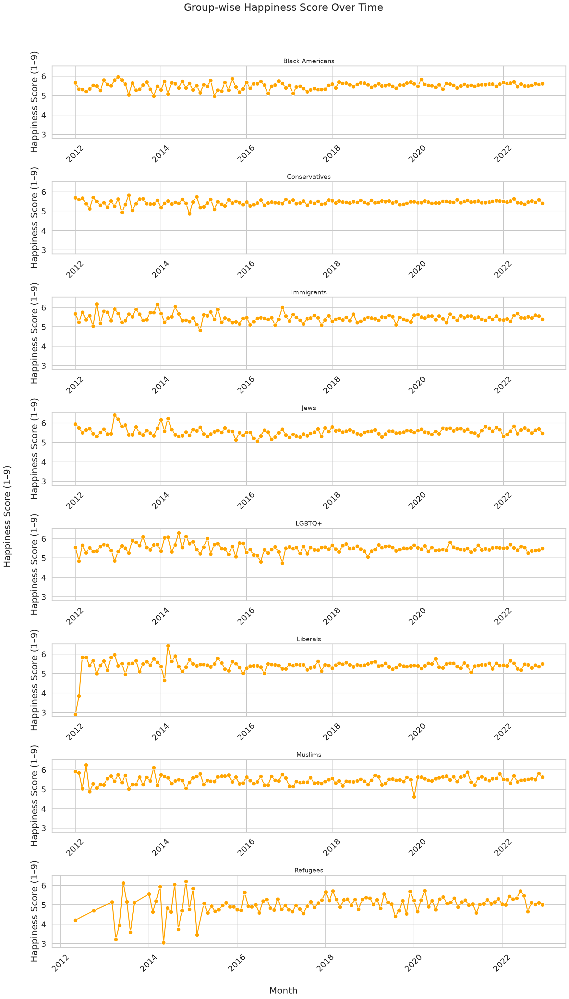

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Make sure Month is datetime
result['Month'] = pd.to_datetime(result['Month'])
result = result.sort_values(['Group', 'Month'])

sns.set_context("talk", font_scale=1.1)
sns.set_style("whitegrid")

# Get unique groups
groups = sorted(result['Group'].unique())
ncols = 1
nrows = (len(groups) + ncols - 1) // ncols

# Create figure
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4))
axes = axes.flatten()

for i, grp in enumerate(groups):
    ax = axes[i]
    sub = result[result['Group'] == grp]

    sns.lineplot(
        data=sub,
        x='Month',
        y='happiness_score',
        marker='o',
        color='#FFA500',  # orange
        linewidth=2.2,
        ax=ax
    )

    ax.set_title(grp, fontsize=14)
    ax.set_xlabel("")
    ax.set_ylabel("Happiness Score (1–9)")
    ax.set_ylim(result['happiness_score'].min() - 0.1, result['happiness_score'].max() + 0.1)
    ax.tick_params(axis='x', rotation=45)

# Remove unused axes if groups < nrows*ncols
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Shared labels and layout
fig.text(0.5, 0.04, "Month", ha='center', fontsize=20)
fig.text(0.02, 0.5, "Happiness Score (1–9)", va='center', rotation='vertical', fontsize=20)
fig.suptitle("Group-wise Happiness Score Over Time", fontsize=22, y=0.995)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.97])
plt.savefig("groupwise_happiness_score_over_time.pdf", dpi=300, bbox_inches="tight")
plt.show()


In [87]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1) Month + 2-month bin ---
df['tweet_created_at'] = pd.to_datetime(df['tweet_created_at'])
df['Month'] = df['tweet_created_at'].dt.to_period('M')

# Create a 2-month period label (e.g., 2024-01/02, 2024-03/04, ...)
# We anchor bins by integer month index: year*12 + (month-1)
month_index = df['Month'].dt.year * 12 + (df['Month'].dt.month - 1)
bin_start_index = (month_index // 2) * 2

bin_start_year = (bin_start_index // 12).astype(int)
bin_start_month = (bin_start_index % 12 + 1).astype(int)

# Bin start as Period('M'), plus bin end (start+1 month)
bin_start = pd.PeriodIndex(year=bin_start_year, month=bin_start_month, freq='M')
bin_end = bin_start + 1

# Label like "YYYY-MM–YYYY-MM"
df['Month2'] = bin_start.astype(str) + "–" + bin_end.astype(str)
df['Month2_start'] = bin_start.to_timestamp()  # for plotting on a real datetime axis

# --- 2) Happiness function ---
token_pat = re.compile(r"\b[a-z]+\b")

def compute_happiness(text, score_dict):
    words = token_pat.findall(str(text).lower())
    scores = [score_dict[w] for w in words if w in score_dict]
    return np.mean(scores) if scores else np.nan

# --- 3) Merge text by Group + 2-month bin ---
group_corpora_2m = (
    df.groupby(['Group', 'Month2', 'Month2_start'])['pure_text']
      .apply(lambda s: ' '.join(s.astype(str)))
      .reset_index(name='joined_text')
)

# --- 4) Compute happiness on merged 2-month corpus ---
group_corpora_2m['happiness_score'] = group_corpora_2m['joined_text'].apply(
    lambda t: compute_happiness(t, labmt_dict)
)

result2m = group_corpora_2m[['Group', 'Month2', 'Month2_start', 'happiness_score']].sort_values(
    ['Group', 'Month2_start']
)

print(result2m.head())

# --- 5) Plot (2-month time series) ---
sns.set_context("talk", font_scale=1.1)
sns.set_style("whitegrid")

groups = sorted(result2m['Group'].unique())
nrows = len(groups)

fig, axes = plt.subplots(nrows, 1, figsize=(18, nrows * 4), sharex=True)
axes = axes if hasattr(axes, "__len__") else [axes]

ymin = result2m['happiness_score'].min() - 0.1
ymax = result2m['happiness_score'].max() + 0.1

for i, grp in enumerate(groups):
    ax = axes[i]
    sub = result2m[result2m['Group'] == grp]

    sns.lineplot(
        data=sub,
        x='Month2_start',
        y='happiness_score',
        marker='o',
        linewidth=2.2,
        ax=ax
    )

    ax.set_title(grp, fontsize=14)
    ax.set_xlabel("")
    ax.set_ylabel("Happiness Score (1–9)")
    ax.set_ylim(ymin, ymax)
    ax.tick_params(axis='x', rotation=45)

fig.text(0.5, 0.04, "2-month window (start month)", ha='center', fontsize=20)
fig.text(0.02, 0.5, "Happiness Score (1–9)", va='center', rotation='vertical', fontsize=20)
fig.suptitle("Group-wise Happiness Score Over Time (2-month merged corpus)", fontsize=22, y=0.995)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.97])
plt.savefig("groupwise_happiness_score_over_time_2month.pdf", dpi=300, bbox_inches="tight")
plt.show()

TypeError: PeriodIndex.__new__() got an unexpected keyword argument 'year'

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.ticker import MultipleLocator

# Make sure Month2_start is datetime and sorted
result2m['Month2_start'] = pd.to_datetime(result2m['Month2_start'])
result2m = result2m.sort_values(['Group', 'Month2_start'])

BASE_FONTSIZE = 24

sns.set_context("talk", font_scale=1.0)
sns.set_style("white")

plt.rcParams.update({
    "font.size": BASE_FONTSIZE,
    "axes.titlesize": BASE_FONTSIZE,
    "axes.labelsize": BASE_FONTSIZE,
    "xtick.labelsize": BASE_FONTSIZE,
    "ytick.labelsize": BASE_FONTSIZE,
    "legend.fontsize": BASE_FONTSIZE,
})

groups = sorted(result2m['Group'].unique())
nrows = len(groups)

fig, axes = plt.subplots(nrows, 1, figsize=(18, nrows * 4), sharex=True)
axes = axes if hasattr(axes, "__len__") else [axes]

for i, grp in enumerate(groups):
    ax = axes[i]
    sub = result2m[result2m['Group'] == grp].copy()

    sns.lineplot(
        data=sub,
        x='Month2_start',
        y='happiness_score',
        marker='o',
        linewidth=3.5,
        ax=ax
    )

    ax.set_title(grp)
    ax.set_xlabel("")
    ax.set_ylabel("")

    # Per-group y-limits
    ymin = sub['happiness_score'].min() - 0.02
    ymax = sub['happiness_score'].max() + 0.02
    ax.set_ylim(ymin, ymax)

    # Y ticks every 0.5
    #ax.yaxis.set_major_locator(MultipleLocator(0.3))
    from matplotlib.ticker import MaxNLocator
# ...
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

    # X ticks as years
    ax.xaxis.set_major_locator(mdates.YearLocator(1))            # every year
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))     # label "YYYY"

    ax.tick_params(axis='x', rotation=45)

    # Hide top/right spines only
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

#fig.text(0.5, 0.04, "2-month window (start month)", ha='center', fontsize=BASE_FONTSIZE)
#fig.suptitle("Group-wise Happiness Score Over Time (2-month merged corpus)", fontsize=BASE_FONTSIZE, y=0.995)

plt.tight_layout(rect=[0.05, 0.06, 1, 0.97])
plt.savefig("groupwise_happiness_score_over_time_2month.pdf", dpi=300, bbox_inches="tight")
plt.show()

NameError: name 'result2m' is not defined

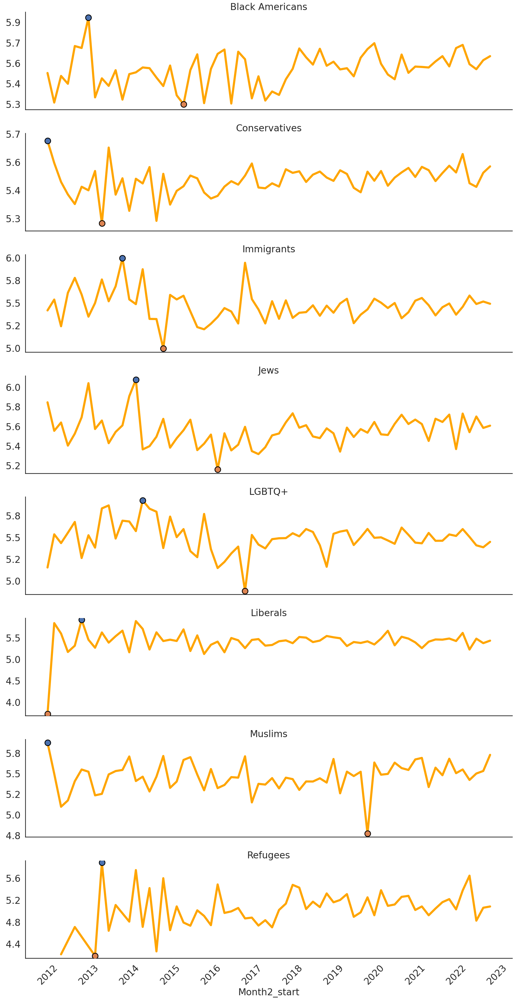

In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator, FuncFormatter

result2m['Month2_start'] = pd.to_datetime(result2m['Month2_start'])
result2m = result2m.sort_values(['Group', 'Month2_start'])

BASE_FONTSIZE = 24

sns.set_context("talk", font_scale=1.0)
sns.set_style("white")

plt.rcParams.update({
    "font.size": BASE_FONTSIZE,
    "axes.titlesize": BASE_FONTSIZE,
    "axes.labelsize": BASE_FONTSIZE,
    "xtick.labelsize": BASE_FONTSIZE,
    "ytick.labelsize": BASE_FONTSIZE,
    "legend.fontsize": BASE_FONTSIZE,
})

groups = sorted(result2m['Group'].unique())
nrows = len(groups)

fig, axes = plt.subplots(nrows, 1, figsize=(20, nrows * 5), sharex=True)
axes = axes if hasattr(axes, "__len__") else [axes]

for i, grp in enumerate(groups):
    ax = axes[i]
    sub = result2m[result2m['Group'] == grp].copy()

    sns.lineplot(
        data=sub,
        x='Month2_start',
        y='happiness_score',
        # marker='o',
        linewidth=5.5,
        color='#FFA500',
        ax=ax
    )

        # --- Mark highest and lowest points (no other changes) ---
    i_max = sub['happiness_score'].idxmax()
    i_min = sub['happiness_score'].idxmin()

    # Highest (peak)
    ax.scatter(sub.loc[i_max, 'Month2_start'], sub.loc[i_max, 'happiness_score'],
               s=220, zorder=10, edgecolors='black', linewidths=2)

    # Lowest
    ax.scatter(sub.loc[i_min, 'Month2_start'], sub.loc[i_min, 'happiness_score'],
               s=220, zorder=10, edgecolors='black', linewidths=2)

    ax.set_title(grp)
    #ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis='x', rotation=45)

    ymin = sub['happiness_score'].min() - 0.04
    ymax = sub['happiness_score'].max() + 0.04
    ax.set_ylim(ymin, ymax)

    # 5 y ticks + hyphen prefix
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f" {y:.1f}"))

    # X ticks as years
    ax.xaxis.set_major_locator(mdates.YearLocator(1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.tick_params(axis='x', rotation=45)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout(rect=[0.05, 0.06, 1, 0.97])
plt.savefig("groupwise_happiness_score_over_time_2month.png", dpi=300, bbox_inches="tight")
plt.show()

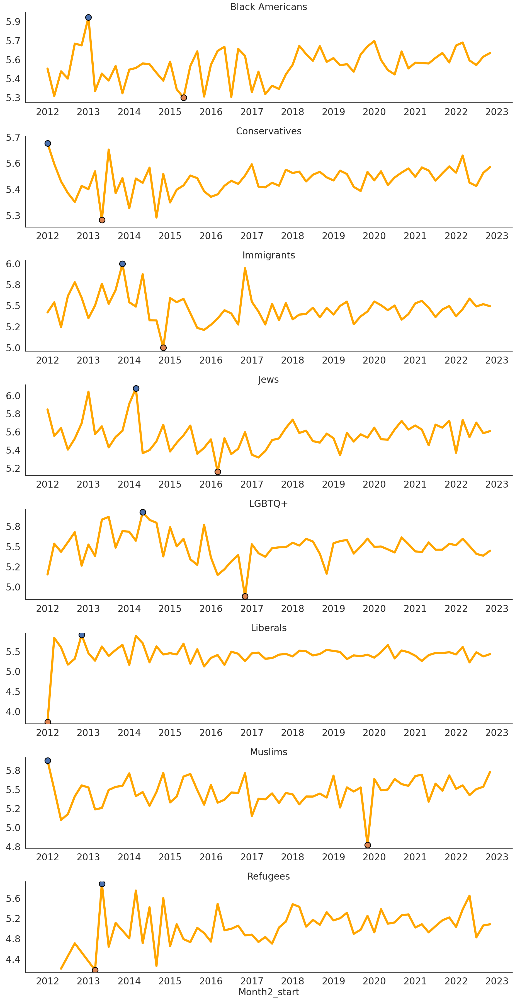

In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator, FuncFormatter

result2m['Month2_start'] = pd.to_datetime(result2m['Month2_start'])
result2m = result2m.sort_values(['Group', 'Month2_start'])

BASE_FONTSIZE = 24

sns.set_context("talk", font_scale=1.0)
sns.set_style("white")

plt.rcParams.update({
    "font.size": BASE_FONTSIZE,
    "axes.titlesize": BASE_FONTSIZE,
    "axes.labelsize": BASE_FONTSIZE,
    "xtick.labelsize": BASE_FONTSIZE,
    "ytick.labelsize": BASE_FONTSIZE,
    "legend.fontsize": BASE_FONTSIZE,
})

groups = sorted(result2m['Group'].unique())
nrows = len(groups)

fig, axes = plt.subplots(nrows, 1, figsize=(20, nrows * 5), sharex=True)
axes = axes if hasattr(axes, "__len__") else [axes]

for i, grp in enumerate(groups):
    ax = axes[i]
    sub = result2m[result2m['Group'] == grp].copy()

    sns.lineplot(
        data=sub,
        x='Month2_start',
        y='happiness_score',
        linewidth=5.5,
        color='#FFA500',
        ax=ax
    )

    i_max = sub['happiness_score'].idxmax()
    i_min = sub['happiness_score'].idxmin()

    ax.scatter(sub.loc[i_max, 'Month2_start'], sub.loc[i_max, 'happiness_score'],
               s=220, zorder=10, edgecolors='black', linewidths=2)
    ax.scatter(sub.loc[i_min, 'Month2_start'], sub.loc[i_min, 'happiness_score'],
               s=220, zorder=10, edgecolors='black', linewidths=2)

    ax.set_title(grp)
    ax.set_ylabel("")
    ax.tick_params(axis='x')

    ymin = sub['happiness_score'].min() - 0.04
    ymax = sub['happiness_score'].max() + 0.04
    ax.set_ylim(ymin, ymax)

    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f" {y:.1f}"))

    # X ticks as years (2012, 2013, ...)
    ax.xaxis.set_major_locator(mdates.YearLocator(1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # ✅ show year labels on EVERY subplot (sharex hides them otherwise)
    ax.tick_params(axis='x', which='both', labelbottom=True)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout(rect=[0.05, 0.06, 1, 0.97])
plt.savefig("groupwise_happiness_score_over_time_2month.png", dpi=300, bbox_inches="tight")
plt.show()

In [117]:
import pandas as pd

# Make sure you're using the dataframe that contains the merged text:
# group_corpora_2m columns: Group, Month2, Month2_start, joined_text, happiness_score

result2m_full = (
    group_corpora_2m[['Group','Month2','Month2_start','happiness_score','joined_text']]
    .copy()
)

result2m_full['Month2_start'] = pd.to_datetime(result2m_full['Month2_start'])
result2m_full = result2m_full.sort_values(['Group','Month2_start']).dropna(subset=['happiness_score'])

for grp, sub in result2m_full.groupby('Group', sort=True):
    hi = sub.loc[sub['happiness_score'].idxmax()]
    lo = sub.loc[sub['happiness_score'].idxmin()]

    print(f"\n==================== {grp} ====================")
    print(f"Peak   : {hi['Month2']} -> {hi['happiness_score']:.4f}")
    print("Merged corpus (peak):")
    print(hi['joined_text'])  # ✅ merged 2-month corpus text

    print(f"\nLowest : {lo['Month2']} -> {lo['happiness_score']:.4f}")
    print("Merged corpus (lowest):")
    print(lo['joined_text'])  # ✅ merged 2-month corpus text


==================== Black Americans ====================
Peak   : 2013-01–2013-02 -> 5.8830
Merged corpus (peak):
@dmckesso Ha! Ha! Ha! Rubio choked on all the bs. He couldnt swallow what the GOP is still spewing! #GOPresponse Jindal trying to save! Lol RT @ChristianCalls1: If you want to see the REAL RACISTS - look at how the PROGRESSIVES and LIBERALS are attacking #LATINO #TedCruz @AriFleischer Republicans are always for the killing. They way coloured people in this town refer to blacks are 'African'. Motherfucker are you European or Asian? Uriah: 
White Christians say: the blacks are creating evil in land. But can you not see that we are creating our freedom: Torah and Gospel. RT @MattGertz: Ted Nugent: Blacks Are Only Ones Who Don't Realize Democrats Are Destroying Black America http://t.co/vHh3LjChjK Apparently majority of whites are rich whereas the minority of blacks are rich. How do you expect blacks to be rich when we greedy? RT @gatewaypundit: Boom! NAACP Leader Says Blacks

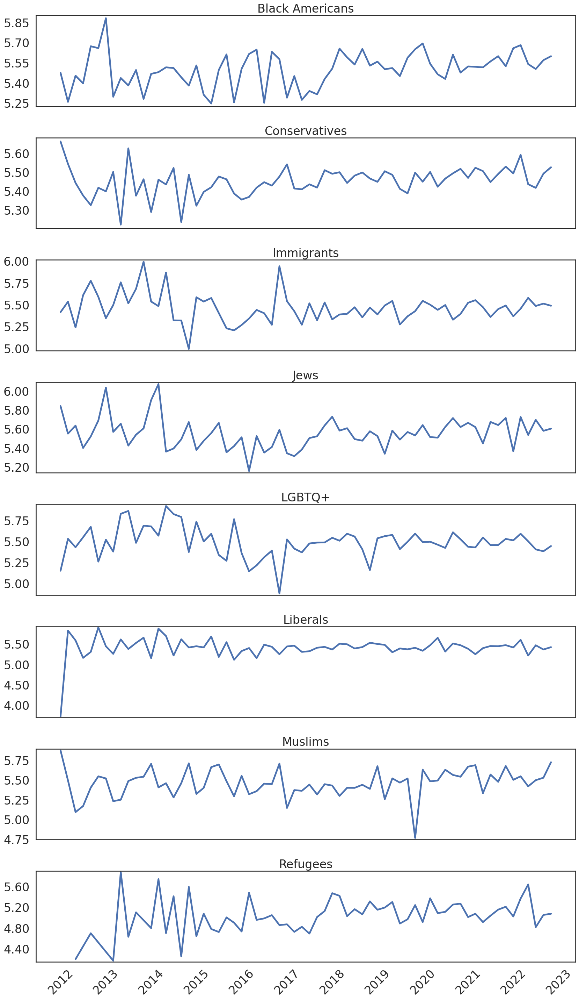

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

result2m['Month2_start'] = pd.to_datetime(result2m['Month2_start'])
result2m = result2m.sort_values(['Group', 'Month2_start'])

BASE_FONTSIZE = 24

sns.set_context("talk", font_scale=1.0)
sns.set_style("white")  # no grid background

plt.rcParams.update({
    "font.size": BASE_FONTSIZE,
    "axes.titlesize": BASE_FONTSIZE,
    "axes.labelsize": BASE_FONTSIZE,
    "xtick.labelsize": BASE_FONTSIZE,
    "ytick.labelsize": BASE_FONTSIZE,
    "legend.fontsize": BASE_FONTSIZE,
})

groups = sorted(result2m['Group'].unique())
nrows = len(groups)

fig, axes = plt.subplots(nrows, 1, figsize=(18, nrows * 4), sharex=True)
axes = axes if hasattr(axes, "__len__") else [axes]

for i, grp in enumerate(groups):
    ax = axes[i]
    sub = result2m[result2m['Group'] == grp].copy()

    sns.lineplot(
        data=sub,
        x='Month2_start',
        y='happiness_score',
        linewidth=3.5,
        ax=ax
    )

    ax.set_title(grp)
    ax.set_xlabel("")
    ax.set_ylabel("")

    ymin = sub['happiness_score'].min() - 0.02
    ymax = sub['happiness_score'].max() + 0.02
    ax.set_ylim(ymin, ymax)

    # 5 y ticks with NORMAL labels
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

    # Make y tick marks look clean (connect to axis)
    ax.tick_params(axis='y', which='major', length=10, width=1.8, direction='out')
    ax.tick_params(axis='x', which='major', length=8,  width=1.8, direction='out', rotation=45)

    # X ticks as years
    ax.xaxis.set_major_locator(mdates.YearLocator(1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # Surround each subplot with a box (all spines visible)
    for side in ['top', 'right', 'bottom', 'left']:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(1.8)

    ax.grid(False)

plt.tight_layout(rect=[0.05, 0.06, 1, 0.97])
plt.savefig("groupwise_happiness_score_over_time_2month.pdf", dpi=300, bbox_inches="tight")
plt.show()

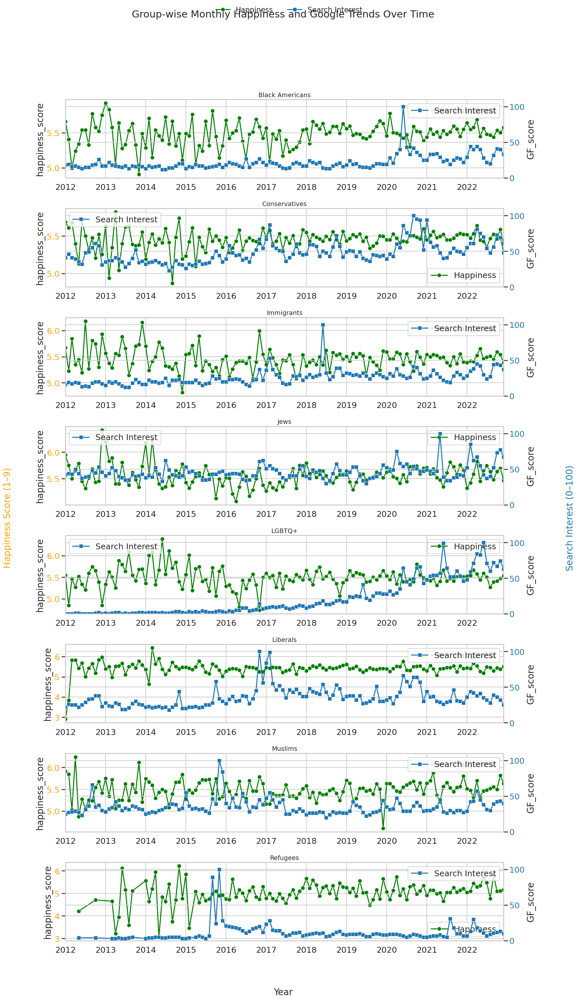

In [131]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1️⃣ Ensure both datasets are monthly and clean ---
result['Month'] = pd.to_datetime(result['Month'])
gf['Month'] = pd.to_datetime(gf['Month'])

# --- 2️⃣ Prepare GF data (melt to long form) ---
gf_long = gf.melt(id_vars=['Month'], var_name='Group', value_name='GF_score')

# --- 3️⃣ Merge on Group + Month ---
merged = pd.merge(result, gf_long, on=['Group', 'Month'], how='inner')
merged = merged.sort_values(['Group', 'Month'])

# --- 4️⃣ Plot setup ---
sns.set_context("talk", font_scale=1.1)
sns.set_style("whitegrid")

groups = sorted(merged['Group'].unique())
ncols = 1
nrows = (len(groups) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4))
axes = axes.flatten()

# Prepare yearly tick positions
all_months = pd.date_range(start=merged['Month'].min(), end=merged['Month'].max(), freq='MS')
year_ticks = all_months[all_months.month == 1]  # January each year

for i, grp in enumerate(groups):
    ax = axes[i]
    sub = merged[merged['Group'] == grp]

    # --- Left y-axis: Happiness ---
    sns.lineplot(
        data=sub, x='Month', y='happiness_score',
        color='green', marker='o', linewidth=2.2, ax=ax, label='Happiness'
    )
   # ax.set_ylabel("Happiness Score (1–9)", color='#FFA500')
    ax.tick_params(axis='y', labelcolor='#FFA500')

    # --- Right y-axis: Google Trends ---
    ax2 = ax.twinx()
    sns.lineplot(
        data=sub, x='Month', y='GF_score',
        color='#1f77b4', marker='s', linewidth=2.2, ax=ax2, label='Search Interest'
    )
    #ax2.set_ylabel("Search Interest (0–100)", color='#1f77b4')
    ax2.tick_params(axis='y', labelcolor='#1f77b4')
    ax2.set_ylim(0, 110)

    # --- X-axis formatting ---
    ax.set_xticks(year_ticks)
    ax.set_xticklabels([d.strftime('%Y') for d in year_ticks])
    ax.set_xlim(merged['Month'].min(), merged['Month'].max())
    ax.set_xlabel("")
    ax.set_title(grp, fontsize=14)

# Remove unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# --- Shared labels and single legend ---
fig.text(0.5, 0.04, "Year", ha='center', fontsize=20)
fig.text(0.02, 0.5, "Happiness Score (1–9)", va='center', rotation='vertical', fontsize=20, color='#FFA500')
fig.text(0.985, 0.5, "Search Interest (0–100)", va='center', rotation='vertical', fontsize=20, color='#1f77b4')

# Combine one legend
handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
fig.legend(handles1 + handles2, labels1 + labels2,
           loc='upper center', ncol=2, frameon=False, fontsize=16)

plt.tight_layout(rect=[0.05, 0.07, 0.95, 0.92])
fig.suptitle("Group-wise Monthly Happiness and Google Trends Over Time", fontsize=22, y=0.99)
plt.savefig("groupwise_monthly_happiness_GF.pdf", dpi=300, bbox_inches="tight")
plt.show()


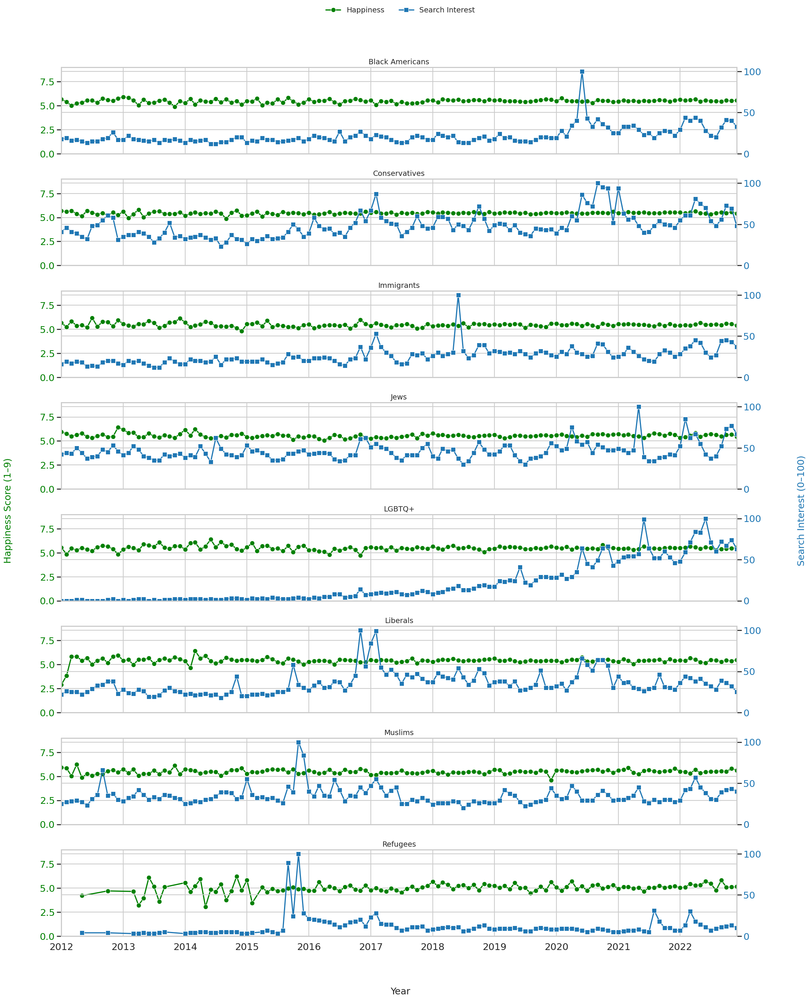

In [140]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1️⃣ Ensure both datasets are monthly and clean ---
result['Month'] = pd.to_datetime(result['Month'])
gf['Month'] = pd.to_datetime(gf['Month'])

# --- 2️⃣ Prepare GF data (melt to long form) ---
gf_long = gf.melt(id_vars=['Month'], var_name='Group', value_name='GF_score')

# --- 3️⃣ Merge on Group + Month ---
merged = pd.merge(result, gf_long, on=['Group', 'Month'], how='inner')
merged = merged.sort_values(['Group', 'Month'])

# --- 4️⃣ Plot setup ---
sns.set_context("talk", font_scale=1.1)
sns.set_style("whitegrid")

groups = sorted(merged['Group'].unique())
ncols = 1
nrows = len(groups)
fig, axes = plt.subplots(nrows, ncols, figsize=(22, nrows * 3.5), sharex=True)
if nrows == 1:
    axes = [axes]  # ensure iterable if only one group

# Prepare yearly tick positions
all_months = pd.date_range(start=merged['Month'].min(), end=merged['Month'].max(), freq='MS')
year_ticks = all_months[all_months.month == 1]

# --- Legend handle containers ---
handles_all, labels_all = [], []

for i, grp in enumerate(groups):
    ax = axes[i]
    sub = merged[merged['Group'] == grp]

    # --- Left y-axis: Happiness ---
    line1 = sns.lineplot(
        data=sub, x='Month', y='happiness_score',
        color='green', marker='o', linewidth=2.2, ax=ax, label='Happiness'
    )

    # --- Right y-axis: Google Trends ---
    ax2 = ax.twinx()
    line2 = sns.lineplot(
        data=sub, x='Month', y='GF_score',
        color='#1f77b4', marker='s', linewidth=2.2, ax=ax2, label='Search Interest'
    )
    ax2.set_ylim(0, 105)
    ax.set_ylim(0, 9)

    # --- Remove per-axis labels ---
    ax.set_ylabel("")
    ax2.set_ylabel("")
    ax.set_xlabel("")
    ax.tick_params(axis='y', labelcolor='green')
    ax2.tick_params(axis='y', labelcolor='#1f77b4')

    # --- X-axis formatting (years only) ---
    ax.set_xticks(year_ticks)
    ax.set_xticklabels([d.strftime('%Y') for d in year_ticks])
    ax.set_xlim(merged['Month'].min(), merged['Month'].max())
    ax.set_title(grp, fontsize=14, loc='center')

    # --- Capture legend handles once ---
    if i == 0:
        h1, l1 = ax.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        handles_all = h1 + h2
        labels_all = l1 + l2

    # Remove individual legends
    if ax.get_legend():
        ax.get_legend().remove()
    if ax2.get_legend():
        ax2.get_legend().remove()

# --- Shared axis labels ---
fig.text(0.5, 0.04, "Year", ha='center', fontsize=18)
fig.text(0.02, 0.5, "Happiness Score (1–9)", va='center', rotation='vertical', fontsize=18, color='green')
fig.text(0.98, 0.5, "Search Interest (0–100)", va='center', rotation='vertical', fontsize=18, color='#1f77b4')

fig.legend(
    handles_all, labels_all,
    loc='upper center',
    ncol=2,
    frameon=False,
    fontsize=14,
    bbox_to_anchor=(0.5, 0.985)  # 👈 closer to the plots
)

# --- Layout and save (reduced top space) ---
plt.tight_layout(rect=[0.05, 0.07, 0.95, 0.94])

# --- Layout and save ---
#plt.tight_layout(rect=[0.05, 0.07, 0.95, 0.92])
#fig.suptitle("Group-wise Monthly Happiness and Google Trends Over Time", fontsize=20, y=0.99)
plt.savefig("groupwise_monthly_happiness_GF_sharedlabels.pdf", dpi=300, bbox_inches="tight")
plt.show()


In [143]:
merged

,Month,Group,happiness_score,year,GF_score
0,2012-01-01,Black Americans,5.661316,2012,18
1,2012-02-01,Black Americans,5.406545,2012,19
2,2012-03-01,Black Americans,4.995146,2012,16
3,2012-04-01,Black Americans,5.238395,2012,17
4,2012-05-01,Black Americans,5.339574,2012,15
...,...,...,...,...,...
1035,2022-08-01,Refugees,4.765535,2022,9
1036,2022-09-01,Refugees,5.820061,2022,11
1037,2022-10-01,Refugees,5.094324,2022,12
1038,2022-11-01,Refugees,5.108198,2022,13


In [152]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import statsmodels.formula.api as smf

# Drop missing values
merged = merged.dropna(subset=['GF_score', 'happiness_score']).copy()

# --- 1️⃣ Scale both variables (z-score normalization) ---
scaler = StandardScaler()
merged[['GF_scaled', 'happy_scaled']] = scaler.fit_transform(merged[['GF_score', 'happiness_score']])

# Optional: check scaling
#print(merged[['GF_score', 'GF_scaled', 'happiness_score', 'happy_scaled']].head())

# --- 2️⃣ OLS model using scaled variables ---
model_scaled = smf.ols('GF_scaled ~ happiness_score + C(Group)-1', data=merged).fit()
print(model_scaled.summary())



                            OLS Regression Results                            
Dep. Variable:              GF_scaled   R-squared:                       0.407
Model:                            OLS   Adj. R-squared:                  0.402
Method:                 Least Squares   F-statistic:                     88.32
Date:                Mon, 27 Oct 2025   Prob (F-statistic):          2.21e-111
Time:                        15:31:59   Log-Likelihood:                -1204.3
No. Observations:                1040   AIC:                             2427.
Df Residuals:                    1031   BIC:                             2471.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
C(Group)[Black America

In [150]:

# --- 2️⃣ OLS model using scaled variables ---
model_scaled = smf.ols('GF_scaled ~  C(Group)-1', data=merged).fit()
print(model_scaled.summary())



                            OLS Regression Results                            
Dep. Variable:              GF_scaled   R-squared:                       0.407
Model:                            OLS   Adj. R-squared:                  0.403
Method:                 Least Squares   F-statistic:                     101.0
Date:                Mon, 27 Oct 2025   Prob (F-statistic):          2.12e-112
Time:                        15:31:47   Log-Likelihood:                -1204.3
No. Observations:                1040   AIC:                             2425.
Df Residuals:                    1032   BIC:                             2464.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
C(Group)[Black America

In [147]:
# --- 2️⃣ OLS model using scaled variables ---
model_scaled = smf.ols('happy_scaled ~  C(Group)-1', data=merged).fit()
print(model_scaled.summary())

                            OLS Regression Results                            
Dep. Variable:           happy_scaled   R-squared:                       0.247
Model:                            OLS   Adj. R-squared:                  0.242
Method:                 Least Squares   F-statistic:                     48.43
Date:                Mon, 27 Oct 2025   Prob (F-statistic):           1.25e-59
Time:                        15:24:34   Log-Likelihood:                -1328.0
No. Observations:                1040   AIC:                             2672.
Df Residuals:                    1032   BIC:                             2712.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
C(Group)[Black America

In [149]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr

# Drop missing values just in case
corr_df = merged.dropna(subset=['happiness_score', 'GF_score'])

# --- 1️⃣ Correlation: Happiness vs Search Interest ---
pearson_happy, pval_happy = pearsonr(corr_df['happiness_score'], corr_df['GF_score'])
spearman_happy, spval_happy = spearmanr(corr_df['happiness_score'], corr_df['GF_score'])

# # --- 2️⃣ Correlation: Comment Count vs Search Interest ---
# pearson_count, pval_count = pearsonr(corr_df['count'], corr_df['GF_score'])
# spearman_count, spval_count = spearmanr(corr_df['count'], corr_df['GF_score'])

# --- Print results nicely ---
print("📈 Correlation between Happiness Score and Search Interest")
print(f"   Pearson r = {pearson_happy:.3f},  p = {pval_happy:.3e}")
print(f"   Spearman ρ = {spearman_happy:.3f},  p = {spval_happy:.3e}\n")

# print("📊 Correlation between Comment Count and Search Interest")
# print(f"   Pearson r = {pearson_count:.3f},  p = {pval_count:.3e}")
# print(f"   Spearman ρ = {spearman_count:.3f},  p = {spval_count:.3e}")


📈 Correlation between Happiness Score and Search Interest
   Pearson r = 0.190,  p = 6.994e-10
   Spearman ρ = 0.166,  p = 7.483e-08



In [154]:
df

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,...,TargetedGroup,Sentiment,Emotion,Group,year,sentiment_score,P_pos,P_neu,P_neg,Month
0,1.0,1.0,31562.0,53734.0,112688.0,34389.0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,...,Black Americans,Negative,Anger,Black Americans,2022,-0.861579,0.009913,0.118596,0.871492,2022-05
1,2.0,2.0,31563.0,6419.0,6516.0,6516.0,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,...,Conservatives,Negative,Anger,Conservatives,2020,0.729675,0.741638,0.246398,0.011964,2020-07
2,3.0,3.0,31564.0,21989.0,487.0,487.0,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,...,Muslims,Positive,Gratitude,Muslims,2016,0.024681,0.072822,0.879038,0.048141,2016-12
3,4.0,4.0,31565.0,26907.0,422.0,422.0,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,...,Black Americans,Negative,Anger,Black Americans,2020,-0.478191,0.027605,0.466598,0.505796,2020-07
4,7.0,7.0,31568.0,19884.0,56211.0,39730.0,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,...,Conservatives,Negative,Anger,Conservatives,2020,-0.939360,0.007993,0.044654,0.947353,2020-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,NaN,30760.0,30927.0,61861.0,11284.0,2083.0,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,...,Liberals,Negative,Anger,Liberals,2016,0.457329,0.482484,0.492361,0.025155,2016-10
153242,NaN,30761.0,30928.0,61862.0,44732.0,14321.0,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,...,LGBTQ+,Negative,Anger,LGBTQ+,2019,-0.843050,0.008166,0.140618,0.851216,2019-08
153243,NaN,30762.0,30929.0,61863.0,54343.0,23932.0,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,...,Conservatives,Negative,Anger,Conservatives,2020,-0.921201,0.010650,0.057498,0.931851,2020-08
153244,NaN,30763.0,30930.0,61864.0,38158.0,7747.0,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,...,Conservatives,Negative,Anger,Conservatives,2020,-0.685747,0.010916,0.292421,0.696663,2020-11


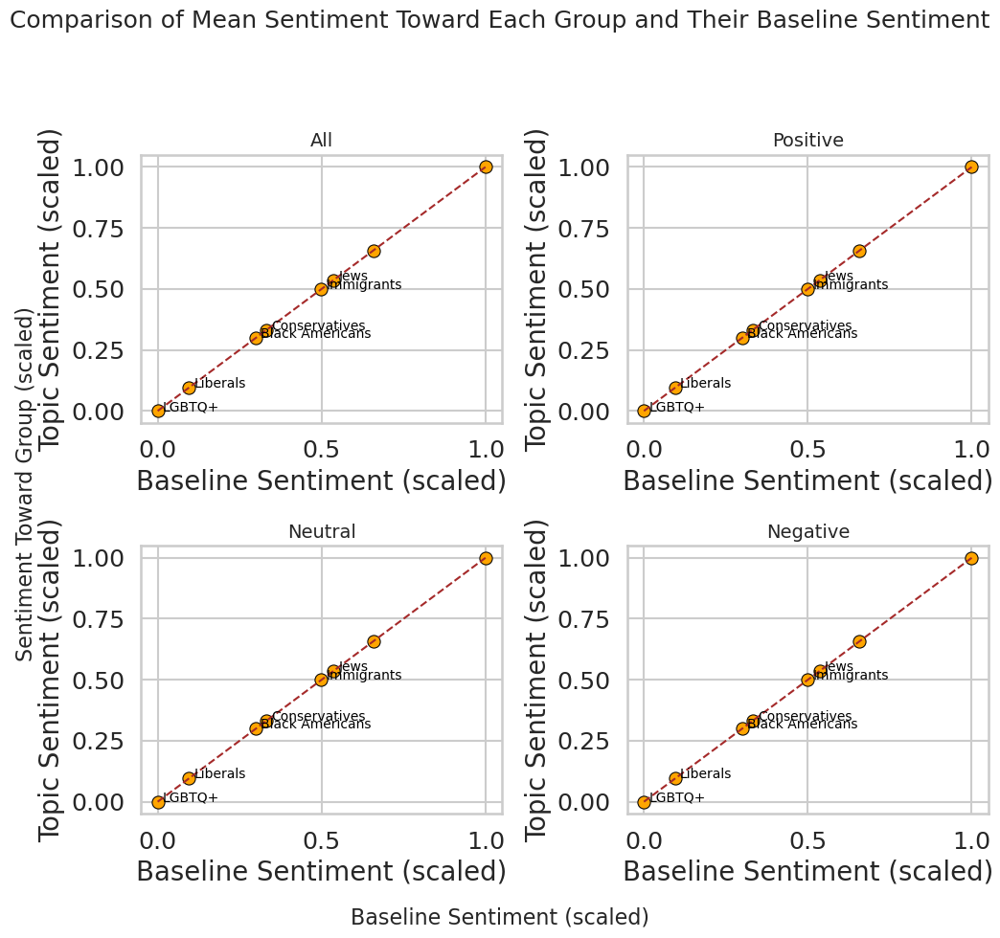

In [155]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------
# 1️⃣ Compute mean sentiment per group (you already have sentiment_score)
# ------------------------------------
group_mean = df.groupby('Group', as_index=False)[['sentiment_score', 'P_pos', 'P_neg']].mean()

# If you don't have a random baseline sentiment, approximate one:
group_mean['sentiment_random'] = group_mean['P_pos'] - group_mean['P_neg']

# ------------------------------------
# 2️⃣ Scale both sentiment metrics to [0, 1]
# ------------------------------------
for col in ['sentiment_score', 'sentiment_random']:
    group_mean[col + '_scaled'] = (
        group_mean[col] - group_mean[col].min()
    ) / (group_mean[col].max() - group_mean[col].min())

# ------------------------------------
# 3️⃣ Prepare subplots (a–d style)
# ------------------------------------
sns.set(style="whitegrid", context="talk", font_scale=1.1)
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
axes = axes.flatten()

# If you don't have four distinct categories, we’ll plot the same data 4 times
panels = ["All", "Positive", "Neutral", "Negative"]

for i, panel in enumerate(panels):
    ax = axes[i]
    
    # Scatter points
    sns.scatterplot(
        data=group_mean,
        x='sentiment_random_scaled',
        y='sentiment_score_scaled',
        s=90, color='#FFA500', edgecolor='black', ax=ax
    )
    
    # 1:1 diagonal
    ax.plot([0, 1], [0, 1], ls='--', color='brown', lw=1.5)
    
    # Titles and limits
    ax.set_title(panel, fontsize=14)
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("Baseline Sentiment (scaled)")
    ax.set_ylabel("Topic Sentiment (scaled)")
    
    # Label extreme groups (top 3 positive & bottom 3 negative)
    group_mean['diff'] = group_mean['sentiment_score_scaled'] - group_mean['sentiment_random_scaled']
    top3 = group_mean.nlargest(3, 'diff')
    bottom3 = group_mean.nsmallest(3, 'diff')
    
    for _, row in pd.concat([top3, bottom3]).iterrows():
        ax.text(row['sentiment_random_scaled'] + 0.015, row['sentiment_score_scaled'], 
                row['Group'], fontsize=10, color='black')

# ------------------------------------
# 4️⃣ Common axis labels and layout
# ------------------------------------
fig.text(0.5, 0.04, "Baseline Sentiment (scaled)", ha='center', fontsize=16)
fig.text(0.04, 0.5, "Sentiment Toward Group (scaled)", va='center', rotation='vertical', fontsize=16)
fig.suptitle("Comparison of Mean Sentiment Toward Each Group and Their Baseline Sentiment", 
             fontsize=18, y=0.995)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.95])
plt.savefig("group_sentiment_comparison_panel.pdf", dpi=300, bbox_inches="tight")
plt.show()


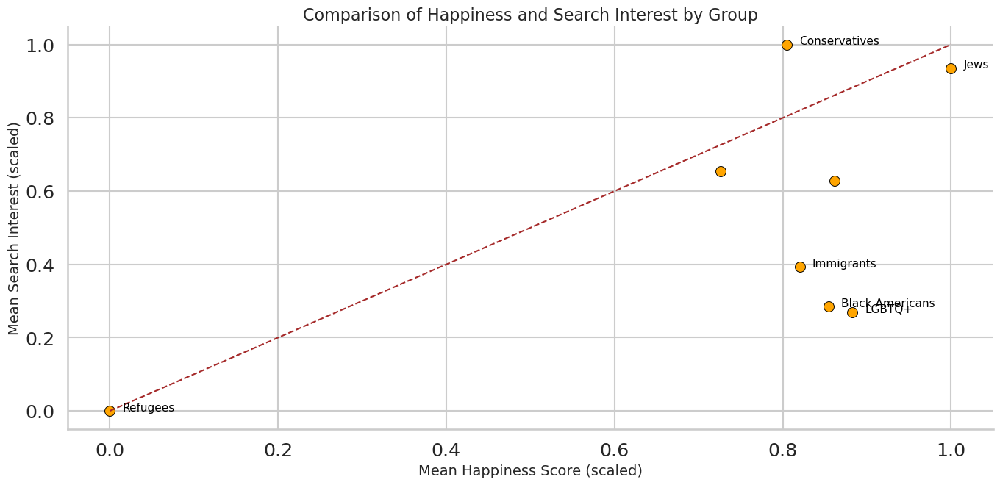

In [157]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------------------
# 1️⃣  Aggregate mean values per group (across all months)
# --------------------------------------------------------
group_mean = merged.groupby("Group", as_index=False)[["happiness_score", "GF_score"]].mean()

# --------------------------------------------------------
# 2️⃣  Scale both to [0, 1]
# --------------------------------------------------------
for col in ["happiness_score", "GF_score"]:
    group_mean[col + "_scaled"] = (
        group_mean[col] - group_mean[col].min()
    ) / (group_mean[col].max() - group_mean[col].min())

# --------------------------------------------------------
# 3️⃣  Plot setup
# --------------------------------------------------------
sns.set(style="whitegrid", context="talk", font_scale=1.1)
fig, ax = plt.subplots(figsize=(14, 7))

# Scatter points
sns.scatterplot(
    data=group_mean,
    x="happiness_score_scaled",
    y="GF_score_scaled",
    s=100,
    color="#FFA500",         # orange color
    edgecolor="black",
    linewidth=0.7,
    ax=ax
)

# 1:1 diagonal (y = x)
ax.plot([0, 1], [0, 1], ls="--", color="brown", lw=1.5)

# --------------------------------------------------------
# 4️⃣  Label extreme groups (top and bottom 3 by deviation)
# --------------------------------------------------------
group_mean["diff"] = group_mean["GF_score_scaled"] - group_mean["happiness_score_scaled"]
top3 = group_mean.nlargest(3, "diff")
bottom3 = group_mean.nsmallest(3, "diff")

for _, row in pd.concat([top3, bottom3]).iterrows():
    ax.text(
        row["happiness_score_scaled"] + 0.015,
        row["GF_score_scaled"],
        row["Group"],
        fontsize=11,
        color="black"
    )

# --------------------------------------------------------
# 5️⃣  Style and labels (Miyazaki-style aesthetics)
# --------------------------------------------------------
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("Mean Happiness Score (scaled)", fontsize=14)
ax.set_ylabel("Mean Search Interest (scaled)", fontsize=14)
ax.set_title("Comparison of Happiness and Search Interest by Group", fontsize=16)

# Remove extra top/right borders for cleaner look
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("groupwise_happiness_vs_GFscore.pdf", dpi=300, bbox_inches="tight")
plt.show()


In [169]:
group_mean

,Group,happiness_score,GF_score,happiness_score_scaled,GF_score_scaled
0,Black Americans,5.478046,21.795455,0.854347,0.284638
1,Conservatives,5.450681,48.363636,0.804634,1.000000
2,Immigrants,5.459287,25.818182,0.820268,0.392952
3,Jews,5.558222,45.962121,1.000000,0.935338
4,LGBTQ+,5.493583,21.212121,0.882573,0.268932
5,Liberals,5.407280,35.537879,0.725789,0.654660
6,Muslims,5.481923,34.568182,0.861391,0.628550
7,Refugees,5.007763,11.224138,0.000000,0.000000


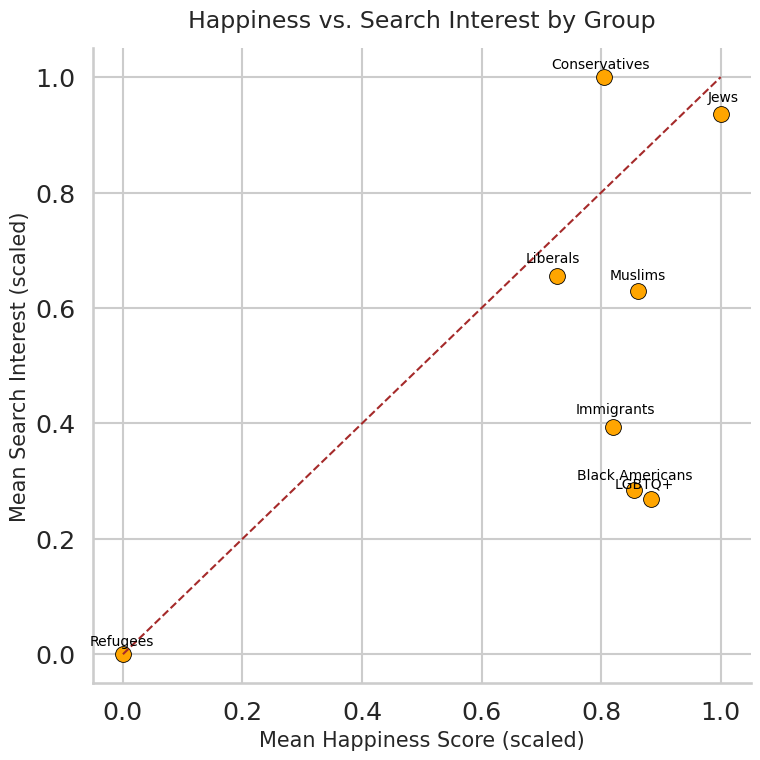

In [170]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --------------------------------------------------------
# 1️⃣ Aggregate mean values per group
# --------------------------------------------------------
group_mean = merged.groupby("Group", as_index=False)[["happiness_score", "GF_score"]].mean()

# --------------------------------------------------------
# 2️⃣ Scale to [0, 1] range
# --------------------------------------------------------
for col in ["happiness_score", "GF_score"]:
    group_mean[col + "_scaled"] = (
        group_mean[col] - group_mean[col].min()
    ) / (group_mean[col].max() - group_mean[col].min())

# --------------------------------------------------------
# 3️⃣ Plot setup
# --------------------------------------------------------
sns.set(style="whitegrid", context="talk", font_scale=1.1)
fig, ax = plt.subplots(figsize=(8, 8))

# Scatter points
sns.scatterplot(
    data=group_mean,
    x="happiness_score_scaled",
    y="GF_score_scaled",
    s=130,
    color="#FFA500",     # orange color
    edgecolor="black",
    linewidth=0.6,
    ax=ax
)

# Add diagonal (y = x)
ax.plot([0, 1], [0, 1], ls="--", color="brown", lw=1.5)

# --------------------------------------------------------
# 4️⃣ Annotate ALL groups clearly (with small jitter)
# --------------------------------------------------------
rng = np.random.default_rng(42)
x_jitter = rng.normal(0, 0.005, size=len(group_mean))
y_jitter = rng.normal(0, 0.005, size=len(group_mean))

for i, row in group_mean.iterrows():
    ax.text(
        row["happiness_score_scaled"] + x_jitter[i],
        row["GF_score_scaled"] + y_jitter[i]+0.026,
        row["Group"],
        fontsize=10,
        color="black",
        ha="center",
        va="center"
    )

# --------------------------------------------------------
# 5️⃣ Formatting and style
# --------------------------------------------------------
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("Mean Happiness Score (scaled)", fontsize=15)
ax.set_ylabel("Mean Search Interest (scaled)", fontsize=15)
ax.set_title("Happiness vs. Search Interest by Group", fontsize=17, pad=15)

# Remove extra borders
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("happiness_vs_GFscore_allgroups.pdf", dpi=300, bbox_inches="tight")
plt.show()


In [172]:
#pip install adjustText


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


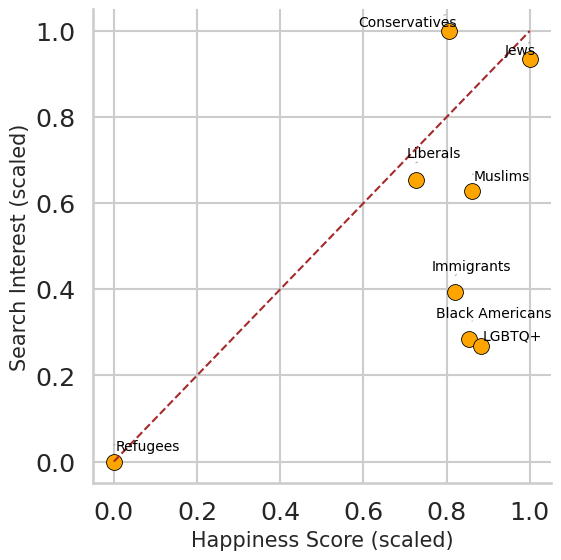

In [185]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from adjustText import adjust_text   # <--- NEW

# --------------------------------------------------------
# 1️⃣ Aggregate mean values per group
# --------------------------------------------------------
group_mean = merged.groupby("Group", as_index=False)[["happiness_score", "GF_score"]].mean()

# --------------------------------------------------------
# 2️⃣ Scale to [0, 1] range
# --------------------------------------------------------
for col in ["happiness_score", "GF_score"]:
    group_mean[col + "_scaled"] = (
        group_mean[col] - group_mean[col].min()
    ) / (group_mean[col].max() - group_mean[col].min())

# --------------------------------------------------------
# 3️⃣ Plot setup
# --------------------------------------------------------
sns.set(style="whitegrid", context="talk", font_scale=1.1)
fig, ax = plt.subplots(figsize=(6, 6))

# Scatter points
sns.scatterplot(
    data=group_mean,
    x="happiness_score_scaled",
    y="GF_score_scaled",
    s=130,
    color="#FFA500",     # orange color
    edgecolor="black",
    linewidth=0.6,
    ax=ax
)

# Add diagonal (y = x)
ax.plot([0, 1], [0, 1], ls="--", color="brown", lw=1.5)

# --------------------------------------------------------
# 4️⃣ Annotate ALL groups clearly (smart adjustment)
# --------------------------------------------------------
texts = []
for _, row in group_mean.iterrows():
    texts.append(
        ax.text(
            row["happiness_score_scaled"],
            row["GF_score_scaled"] + 0.039,  # small lift for readability
            row["Group"],
            fontsize=10,
            color="black",
            ha="center",
            va="center"
        )
    )

# Automatically adjust overlapping labels
adjust_text(
    texts,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5),
    only_move={'points': 'y', 'texts': 'y'}  # vertical only for cleaner look
)

# --------------------------------------------------------
# 5️⃣ Formatting and style
# --------------------------------------------------------
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("Happiness Score (scaled)", fontsize=15)
ax.set_ylabel("Search Interest (scaled)", fontsize=15)
#ax.set_title("Happiness vs. Search Interest by Group", fontsize=17, pad=15)

# Remove extra borders
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("happiness_vs_GFscore_allgroups_nonoverlap.pdf", dpi=300, bbox_inches="tight")
plt.show()


In [26]:
group_corpora = df.groupby('Group')['pure_text'].apply(lambda texts: ' '.join(texts.astype(str)).lower())
group_corpora

Group
Black Americans    rt @lorigspeaks:@unclelukereal1 this is the mo...
Conservatives      rt @conservmillen: it’s amazing that a sports ...
Immigrants         rt @thedailyedge: voter suppression. gunsense....
Jews               rt @impeachdeblasio: @rockprincess818 yet the ...
LGBTQ+             rt @ellievan65:an evangelical nonprofit that o...
Liberals           rt @davidklion:i don't know what's going to ha...
Muslims            rt @johnpavlovitz: the price of an evangelical...
None               rt @will_turman:arguments for ubiquitous on-st...
Refugees           rt @onlinemagazin: 🆘‼️😠😤🔥 german evangelical b...
Name: pure_text, dtype: object

In [27]:
def compute_group_happiness(text, lexicon):
    words = text.split()  # simple whitespace tokenizer; use nltk/spacy for better
    filtered = [word for word in words if word in lexicon]
    if not filtered:
        return np.nan
    freqs = Counter(filtered)
    total = sum(freqs.values())
    score = sum(freqs[word] * lexicon[word] for word in freqs)
    return score / total

# --- Step 4: Apply to all groups ---
group_happiness = group_corpora.apply(lambda text: compute_group_happiness(text, labmt_dict))

# --- Step 5: Convert to DataFrame ---
group_happiness_df = group_happiness.reset_index()
group_happiness_df.columns = ['Group', 'Avg_Happiness_Score']

print(group_happiness_df)

             Group  Avg_Happiness_Score
0  Black Americans             5.484144
1    Conservatives             5.458898
2       Immigrants             5.426208
3             Jews             5.566906
4           LGBTQ+             5.483418
5         Liberals             5.416789
6          Muslims             5.439315
7             None             5.636634
8         Refugees             5.027659


In [28]:
import numpy as np
from collections import Counter
import pandas as pd

# --- Step 1: Update the function to return multiple metrics ---
def compute_group_happiness(text, lexicon):
    words = text.split()  # Simple tokenizer
    filtered = [word for word in words if word in lexicon]
    if not filtered:
        return pd.Series([np.nan]*4, index=['Avg_Happiness_Score', 'Std_Dev', 'Min_Score', 'Max_Score'])

    scores = [lexicon[word] for word in filtered]
    avg = np.mean(scores)
    std = np.std(scores)
    min_score = np.min(scores)
    max_score = np.max(scores)
    return pd.Series([avg, std, min_score, max_score],
                     index=['Avg_Happiness_Score', 'Std_Dev', 'Min_Score', 'Max_Score'])

# --- Step 2: Apply to all groups ---
group_happiness_df = group_corpora.apply(lambda text: compute_group_happiness(text, labmt_dict)).reset_index()

# --- Step 3: Print the final DataFrame ---
print(group_happiness_df)


             Group  Avg_Happiness_Score   Std_Dev  Min_Score  Max_Score
0  Black Americans             5.484144  1.719077        1.3       8.50
1    Conservatives             5.458898  1.704459        1.3       8.50
2       Immigrants             5.426208  1.718936        1.3       8.44
3             Jews             5.566906  1.655405        1.3       8.50
4           LGBTQ+             5.483418  1.714027        1.3       8.44
5         Liberals             5.416789  1.746690        1.3       8.42
6          Muslims             5.439315  1.737075        1.3       8.44
7             None             5.636634  1.604292        1.3       8.50
8         Refugees             5.027659  1.781736        1.3       8.44


In [29]:
import pandas as pd
from nltk.tokenize import word_tokenize

# Step 1: Read the word-level happiness score file (no header)
happiness_df = pd.read_csv('labMT-english.csv', header=None, names=['word', 'score'], sep=',')  # adjust sep if needed
happiness_dict = dict(zip(happiness_df['word'], happiness_df['score']))
happiness_df

,word,score
0,laughter,8.50
1,happiness,8.44
2,love,8.42
3,happy,8.30
4,laughed,8.26
...,...,...
10217,murder,1.48
10218,terrorism,1.48
10219,rape,1.44
10220,suicide,1.30


In [30]:
# Step 2: Define a function to compute happiness score for each comment
def compute_happiness(text):
    if pd.isna(text):
        return None
    tokens = word_tokenize(text.lower())
    scores = [happiness_dict[word] for word in tokens if word in happiness_dict]
    return sum(scores) / len(scores) if scores else None

# Step 3: Apply the function to your main dataframe's comments column
df['happiness'] = df['pure_text'].apply(compute_happiness)

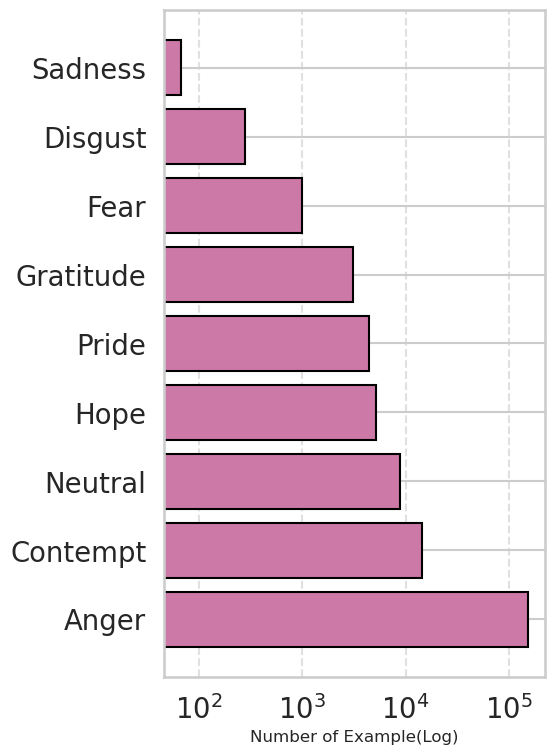

In [31]:
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.cm as cm

# Count emotion frequencies
emotion_counts = df['Emotion'].value_counts()
emotions = emotion_counts.index
counts = emotion_counts.values


# Plot
plt.figure(figsize=(6, 8))
plt.barh(emotions, counts, color='#CC79A7', edgecolor='black')

plt.xscale('log')  # <-- Log scale for frequency

#plt.title('Emotion Frequency Distribution (Log Scale)', fontsize=14)
plt.xlabel('Number of Example(Log)', fontsize=12)
#plt.ylabel('Emotion', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


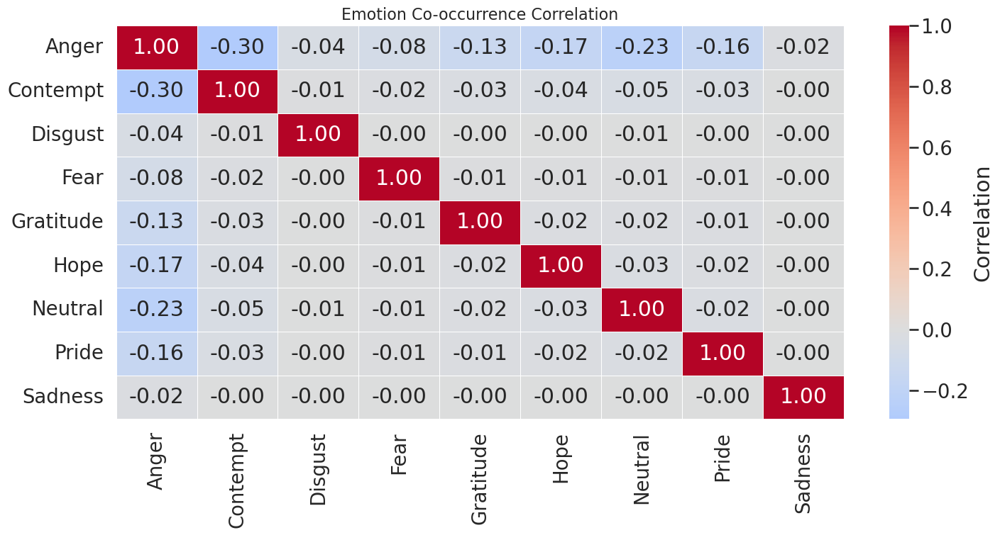

In [32]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# One-hot encode the Emotion column
emotion_dummies = pd.get_dummies(df['Emotion'])

# Compute correlation between emotions
emotion_corr = emotion_dummies.corr()

# Plot heatmap
plt.figure(figsize=(15, 8))
sns.heatmap(
    emotion_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Correlation"}
)
plt.title("Emotion Co-occurrence Correlation", fontsize=16)
plt.tight_layout()
plt.show()


In [33]:
# prompt: scale the happiness column

from sklearn.preprocessing import MinMaxScaler

# Initialize MinMaxScaler
scaler = MinMaxScaler()

# Reshape the 'score' column to be 2D as required by MinMaxScaler
score_column = df['happiness'].values.reshape(-1, 1)

# Fit the scaler and transform the 'score' column
df['scaled_happiness'] = scaler.fit_transform(score_column)

print(df[['scaled_happiness']].head())
df

   scaled_happiness
0          0.590169
1          0.645854
2          0.623361
3          0.637440
4          0.624157


,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,...,CommentType,TargetedGroup,Sentiment,Emotion,laughter,8.5,Group,year,happiness,scaled_happiness
0,0.0,0.0,31561.0,43416.0,121112.0,4412.0,641861d056398f4ab8f0d7f4,RT @Will_Turman:Arguments for ubiquitous on-st...,RT @Will_Turman:Arguments for ubiquitous on-st...,2021-08-19 22:56:21,...,NaN,NaN,NaN,NaN,NaN,NaN,None,2021.0,5.101333,0.590169
1,1.0,1.0,31562.0,53734.0,112688.0,34389.0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,...,Discriminatory,Black Americans,Negative,Anger,NaN,NaN,Black Americans,2022.0,5.365652,0.645854
2,2.0,2.0,31563.0,6419.0,6516.0,6516.0,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,...,Discriminatory,Conservatives,Negative,Anger,NaN,NaN,Conservatives,2020.0,5.258889,0.623361
3,3.0,3.0,31564.0,21989.0,487.0,487.0,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,...,Discriminatory,Muslims,Positive,Gratitude,NaN,NaN,Muslims,2016.0,5.325714,0.637440
4,4.0,4.0,31565.0,26907.0,422.0,422.0,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,...,Discriminatory,Black Americans,Negative,Anger,NaN,NaN,Black Americans,2020.0,5.262667,0.624157
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
267213,NaN,30762.0,30929.0,61863.0,54343.0,23932.0,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,...,Discriminatory,Conservatives,Negative,Anger,NaN,NaN,Conservatives,2020.0,5.415000,0.656250
267214,NaN,30763.0,30930.0,61864.0,38158.0,7747.0,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,...,Discriminatory,Conservatives,Negative,Anger,NaN,NaN,Conservatives,2020.0,4.982308,0.565093
267215,NaN,30764.0,30931.0,61865.0,860.0,860.0,64184db725adc5e46106adb0,RT @MrAndyNgo:Rose City Antifa is a group. Ant...,RT @MrAndyNgo:Rose City Antifa is a group. Ant...,2020-09-30 03:26:42,...,Discriminatory,NaN,Negative,Anger,NaN,NaN,None,2020.0,5.520909,0.678562
267216,NaN,30765.0,30932.0,61866.0,15795.0,6594.0,64183d54f25d2d54cccaf72f,RT @sunlorrie:Except it doesn't matter how man...,RT @sunlorrie:Except it doesn't matter how man...,2019-08-29 22:26:08,...,Supportive,LGBTQ+,Positive,Pride,NaN,NaN,LGBTQ+,2019.0,5.103333,0.590590


In [34]:
import pandas as pd
from scipy.stats import pearsonr
import itertools

# Group by Group & CommentType (counts)
grouped = df.groupby(['Group', 'CommentType']).size().reset_index(name='count')

# Pivot once: Groups = rows, CommentTypes = columns
pivot = grouped.pivot(index='Group', columns='CommentType', values='count').fillna(0)

results = []

cols = pivot.columns
for c1, c2 in itertools.combinations(cols, 2):
    x, y = pivot[c1], pivot[c2]
    if len(x) > 1:  # now x = counts across groups
        r, p = pearsonr(x, y)
        results.append({
            "CommentType1": c1,
            "CommentType2": c2,
            "Correlation": r,
            "P_value": p
        })

correlation_df = pd.DataFrame(results)
print(correlation_df)


     CommentType1    CommentType2  Correlation       P_value
0        Critical  Discriminatory     0.674559  4.625539e-02
1        Critical         Neutral     0.986372  9.599890e-07
2        Critical      Supportive     0.182961  6.375161e-01
3  Discriminatory         Neutral     0.592879  9.245622e-02
4  Discriminatory      Supportive     0.001636  9.966662e-01
5         Neutral      Supportive     0.232012  5.480407e-01


In [35]:
grouped

,Group,CommentType,count
0,Black Americans,Critical,388
1,Black Americans,Discriminatory,34897
2,Black Americans,Neutral,17
3,Black Americans,Supportive,2550
4,Conservatives,Critical,2263
5,Conservatives,Discriminatory,43974
6,Conservatives,Supportive,60
7,Immigrants,Critical,778
8,Immigrants,Discriminatory,18978
9,Immigrants,Supportive,235


In [36]:
# df =df[df['CommentType']!='Neutral']

In [37]:
import pandas as pd
from scipy.stats import chi2_contingency
import numpy as np

# Example: assume df has columns "Group" and "CommentType"

# Step 1: Build contingency table
contingency = pd.crosstab(df['Group'], df['CommentType'])

# Step 2: Chi-square test
chi2, p, dof, expected = chi2_contingency(contingency)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p)

# Step 3: Compute Cramér’s V (measure of association strength, 0–1)
n = contingency.sum().sum()
phi2 = chi2 / n
r, k = contingency.shape
cramers_v = np.sqrt(phi2 / min((k-1), (r-1)))

print("Cramér’s V:", cramers_v)


Chi-square statistic: 66136.32007849524
Degrees of freedom: 24
P-value: 0.0
Cramér’s V: 0.31762071672697034


In [38]:
import pandas as pd
from scipy.stats import chi2_contingency, norm
import numpy as np

# Step 1: contingency table
contingency = pd.crosstab(df['Group'], df['CommentType'])

# Step 2: chi-square test
chi2, p, dof, expected = chi2_contingency(contingency)

# Step 3: standardized residuals
residuals = (contingency - expected) / np.sqrt(expected)

# Step 4: convert residuals → p-values (two-tailed)
p_values = 2 * (1 - norm.cdf(np.abs(residuals)))  # same shape as contingency (numpy array)

# Step 5: tidy DataFrame with results
results = []
for i_idx, i in enumerate(residuals.index):
    for j_idx, j in enumerate(residuals.columns):
        results.append({
            "Group": i,
            "CommentType": j,
            "Observed": contingency.loc[i, j],
            "Expected": expected[i_idx, j_idx],
            "Residual": residuals.iloc[i_idx, j_idx],
            "P_value": p_values[i_idx, j_idx]   # use numpy indexing
        })

results_df = pd.DataFrame(results)

print(results_df.head(20))


              Group     CommentType  Observed      Expected    Residual  \
0   Black Americans        Critical       388   3168.291646  -49.394407   
1   Black Americans  Discriminatory     34897  31811.789077   17.297798   
2   Black Americans         Neutral        17    354.226473  -17.917654   
3   Black Americans      Supportive      2550   2517.692804    0.643870   
4     Conservatives        Critical      2263   3875.155827  -25.897774   
5     Conservatives  Discriminatory     43974  38909.183105   25.676610   
6     Conservatives         Neutral         0    433.256447  -20.814813   
7     Conservatives      Supportive        60   3079.404622  -54.411154   
8        Immigrants        Critical       778   1673.288553  -21.886565   
9        Immigrants  Discriminatory     18978  16800.947782   16.795849   
10       Immigrants         Neutral         0    187.079716  -13.677709   
11       Immigrants      Supportive       235   1329.683949  -30.020266   
12             Jews      

In [39]:
results_df

,Group,CommentType,Observed,Expected,Residual,P_value
0,Black Americans,Critical,388,3168.291646,-49.394407,0.000000e+00
1,Black Americans,Discriminatory,34897,31811.789077,17.297798,0.000000e+00
2,Black Americans,Neutral,17,354.226473,-17.917654,0.000000e+00
3,Black Americans,Supportive,2550,2517.692804,0.643870,5.196600e-01
4,Conservatives,Critical,2263,3875.155827,-25.897774,0.000000e+00
5,Conservatives,Discriminatory,43974,38909.183105,25.676610,0.000000e+00
6,Conservatives,Neutral,0,433.256447,-20.814813,0.000000e+00
7,Conservatives,Supportive,60,3079.404622,-54.411154,0.000000e+00
8,Immigrants,Critical,778,1673.288553,-21.886565,0.000000e+00
9,Immigrants,Discriminatory,18978,16800.947782,16.795849,0.000000e+00


In [40]:
import pandas as pd
from scipy.stats import chi2_contingency, norm
import numpy as np

# Step 1: contingency table
contingency = pd.crosstab(df['Group'], df['CommentType'])

# Step 2: chi-square test
chi2, p, dof, expected = chi2_contingency(contingency)

# Step 3: standardized residuals = coefficients
residuals = (contingency - expected) / np.sqrt(expected)

# Step 4: two-tailed p-values from z-scores
p_values = 2 * (1 - norm.cdf(np.abs(residuals)))

# Step 5: tidy dataframe
results = []
for i_idx, i in enumerate(residuals.index):
    for j_idx, j in enumerate(residuals.columns):
        results.append({
            "Group": i,
            "CommentType": j,
            "Observed": contingency.loc[i, j],
            "Expected": expected[i_idx, j_idx],
            "Coefficient": residuals.iloc[i_idx, j_idx],  # standardized residual
            "P_value": p_values.iloc[i_idx, j_idx] if isinstance(p_values, pd.DataFrame) else p_values[i_idx, j_idx]
        })

coeff_df = pd.DataFrame(results)

print(coeff_df.head(20))


              Group     CommentType  Observed      Expected  Coefficient  \
0   Black Americans        Critical       388   3168.291646   -49.394407   
1   Black Americans  Discriminatory     34897  31811.789077    17.297798   
2   Black Americans         Neutral        17    354.226473   -17.917654   
3   Black Americans      Supportive      2550   2517.692804     0.643870   
4     Conservatives        Critical      2263   3875.155827   -25.897774   
5     Conservatives  Discriminatory     43974  38909.183105    25.676610   
6     Conservatives         Neutral         0    433.256447   -20.814813   
7     Conservatives      Supportive        60   3079.404622   -54.411154   
8        Immigrants        Critical       778   1673.288553   -21.886565   
9        Immigrants  Discriminatory     18978  16800.947782    16.795849   
10       Immigrants         Neutral         0    187.079716   -13.677709   
11       Immigrants      Supportive       235   1329.683949   -30.020266   
12          

In [41]:
coeff_df

,Group,CommentType,Observed,Expected,Coefficient,P_value
0,Black Americans,Critical,388,3168.291646,-49.394407,0.000000e+00
1,Black Americans,Discriminatory,34897,31811.789077,17.297798,0.000000e+00
2,Black Americans,Neutral,17,354.226473,-17.917654,0.000000e+00
3,Black Americans,Supportive,2550,2517.692804,0.643870,5.196600e-01
4,Conservatives,Critical,2263,3875.155827,-25.897774,0.000000e+00
5,Conservatives,Discriminatory,43974,38909.183105,25.676610,0.000000e+00
6,Conservatives,Neutral,0,433.256447,-20.814813,0.000000e+00
7,Conservatives,Supportive,60,3079.404622,-54.411154,0.000000e+00
8,Immigrants,Critical,778,1673.288553,-21.886565,0.000000e+00
9,Immigrants,Discriminatory,18978,16800.947782,16.795849,0.000000e+00


In [42]:
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Drop rows with missing values
df_clean = df.dropna(subset=['scaled_happiness', 'CommentType', 'Group', 'Sentiment', 'Emotion'])

# Step 1: Build the formula (categorical variables are automatically dummy-encoded)
formula = 'scaled_happiness ~  C(Group)-1 '

# Step 2: Fit the OLS model
model = smf.ols(formula=formula, data=df_clean).fit()

# Step 3: Print full summary
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:       scaled_happiness   R-squared:                       0.019
Model:                            OLS   Adj. R-squared:                  0.019
Method:                 Least Squares   F-statistic:                     466.7
Date:                Fri, 12 Sep 2025   Prob (F-statistic):               0.00
Time:                        15:25:06   Log-Likelihood:             2.9037e+05
No. Observations:              189961   AIC:                        -5.807e+05
Df Residuals:                  189952   BIC:                        -5.806e+05
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
C(Group)[Black America

In [46]:
df

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,...,CommentType,TargetedGroup,Sentiment,Emotion,laughter,8.5,Group,year,happiness,scaled_happiness
0,0.0,0.0,31561.0,43416.0,121112.0,4412.0,641861d056398f4ab8f0d7f4,RT @Will_Turman:Arguments for ubiquitous on-st...,RT @Will_Turman:Arguments for ubiquitous on-st...,2021-08-19 22:56:21,...,NaN,NaN,NaN,NaN,NaN,NaN,None,2021.0,5.101333,0.590169
1,1.0,1.0,31562.0,53734.0,112688.0,34389.0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,...,Discriminatory,Black Americans,Negative,Anger,NaN,NaN,Black Americans,2022.0,5.365652,0.645854
2,2.0,2.0,31563.0,6419.0,6516.0,6516.0,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,...,Discriminatory,Conservatives,Negative,Anger,NaN,NaN,Conservatives,2020.0,5.258889,0.623361
3,3.0,3.0,31564.0,21989.0,487.0,487.0,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,...,Discriminatory,Muslims,Positive,Gratitude,NaN,NaN,Muslims,2016.0,5.325714,0.637440
4,4.0,4.0,31565.0,26907.0,422.0,422.0,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,...,Discriminatory,Black Americans,Negative,Anger,NaN,NaN,Black Americans,2020.0,5.262667,0.624157
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
267213,NaN,30762.0,30929.0,61863.0,54343.0,23932.0,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,...,Discriminatory,Conservatives,Negative,Anger,NaN,NaN,Conservatives,2020.0,5.415000,0.656250
267214,NaN,30763.0,30930.0,61864.0,38158.0,7747.0,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,...,Discriminatory,Conservatives,Negative,Anger,NaN,NaN,Conservatives,2020.0,4.982308,0.565093
267215,NaN,30764.0,30931.0,61865.0,860.0,860.0,64184db725adc5e46106adb0,RT @MrAndyNgo:Rose City Antifa is a group. Ant...,RT @MrAndyNgo:Rose City Antifa is a group. Ant...,2020-09-30 03:26:42,...,Discriminatory,NaN,Negative,Anger,NaN,NaN,None,2020.0,5.520909,0.678562
267216,NaN,30765.0,30932.0,61866.0,15795.0,6594.0,64183d54f25d2d54cccaf72f,RT @sunlorrie:Except it doesn't matter how man...,RT @sunlorrie:Except it doesn't matter how man...,2019-08-29 22:26:08,...,Supportive,LGBTQ+,Positive,Pride,NaN,NaN,LGBTQ+,2019.0,5.103333,0.590590


In [47]:
df.columns

Index(['Unnamed: 0.5', 'Unnamed: 0.4', 'Unnamed: 0.3', 'Unnamed: 0.2',
       'Unnamed: 0.1', 'Unnamed: 0', '_id', 'pure_text', 'rt_text',
       'tweet_created_at', 'tweet_id', 'user_id', 'user_created_at',
       'fastText_lang', 'fastText_conf', 'reply_to_id', 'LLM_Label',
       'CommentType', 'TargetedGroup', 'Sentiment', 'Emotion', 'laughter',
       '8.5', 'Group', 'year', 'happiness', 'scaled_happiness'],
      dtype='object')

Sample data created for demonstration.
Data range: 2012.0 - 2022.0
Comment types: 4
Total records: 218515

SUMMARY STATISTICS

Total comment types analyzed: 4
Years covered: 2012.0 - 2022.0
Total data points: 44

Beta statistics:
Mean β: 0.077 ± 0.011
Median β: 0.075
Min β: 0.053
Max β: 0.102

Scaling behavior:
Super-linear (β > 1.0): 0 (0.0%)
Sub-linear (β < 1.0): 44 (100.0%)

Top 5 comment types by average β:
1. Discriminatory: 0.079
2. Supportive: 0.079
3. Neutral: 0.078
4. Critical: 0.072

Creating visualization...


TypeError: 'numpy.float64' object cannot be interpreted as an integer

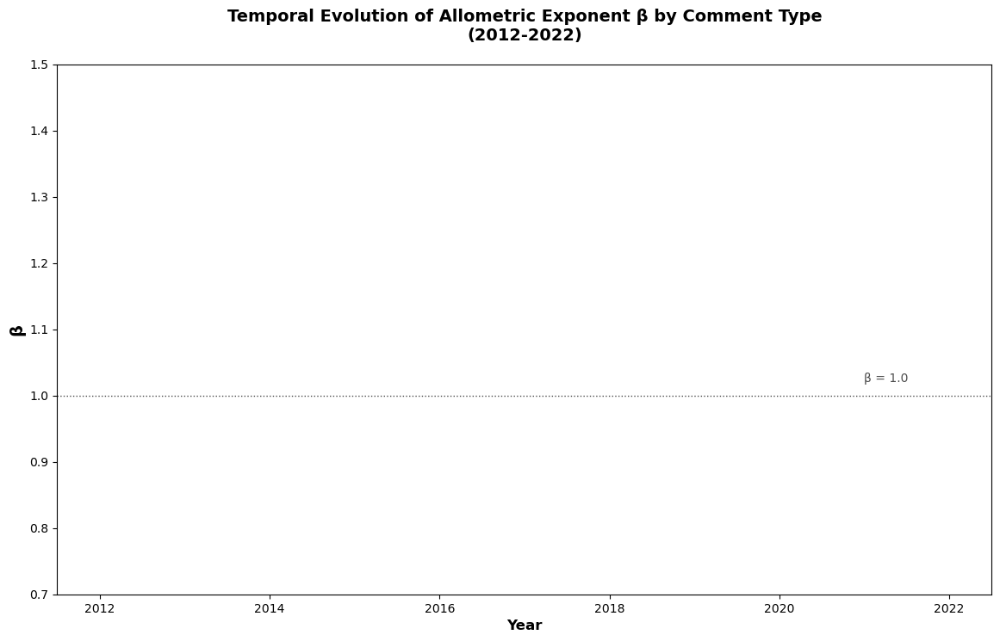

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import curve_fit
import warnings
warnings.filterwarnings('ignore')

def power_law(x, a, beta):
    """Power law function: y = a * x^beta"""
    return a * np.power(x, beta)

def calculate_beta_exponent(data, metric_col='scaled_happiness'):
    """
    Calculate allometric exponent beta for a given dataset
    This fits a power law to the rank-size distribution
    """
    if len(data) < 10:  # Need minimum data points for reliable fit
        return np.nan, np.nan
    
    # Create rank-size distribution
    values = data[metric_col].dropna()
    if len(values) < 10:
        return np.nan, np.nan
    
    # Sort values in descending order and create ranks
    sorted_values = np.sort(values)[::-1]
    ranks = np.arange(1, len(sorted_values) + 1)
    
    # Filter out zero values for log-log fit
    mask = (sorted_values > 0) & (ranks > 0)
    if np.sum(mask) < 10:
        return np.nan, np.nan
    
    log_ranks = np.log(ranks[mask])
    log_values = np.log(sorted_values[mask])
    
    # Fit linear regression in log-log space to get beta
    try:
        slope, intercept, r_value, p_value, std_err = stats.linregress(log_ranks, log_values)
        beta = -slope  # Negative because of rank-size relationship
        beta_error = std_err
        return beta, beta_error
    except:
        return np.nan, np.nan

def analyze_temporal_beta_evolution(df, comment_type_col='CommentType', 
                                  year_col='year', metric_col='scaled_happiness'):
    """
    Analyze temporal evolution of beta exponent for different comment types
    """
    # Filter data for years 2012-2022
    df_filtered = df[(df[year_col] >= 2012) & (df[year_col] <= 2022)].copy()
    df_filtered = df_filtered.dropna(subset=[comment_type_col, year_col, metric_col])
    
    print(f"Data range: {df_filtered[year_col].min()} - {df_filtered[year_col].max()}")
    print(f"Comment types: {df_filtered[comment_type_col].nunique()}")
    print(f"Total records: {len(df_filtered)}")
    
    # Get unique comment types and years
    comment_types = df_filtered[comment_type_col].unique()
    years = sorted(df_filtered[year_col].unique())
    
    # Initialize results dataframe
    results = []
    
    # Calculate beta for each comment type and year
    for comment_type in comment_types:
        for year in years:
            # Filter data for specific comment type and year
            subset = df_filtered[
                (df_filtered[comment_type_col] == comment_type) & 
                (df_filtered[year_col] == year)
            ]
            
            if len(subset) >= 10:  # Minimum threshold for reliable calculation
                beta, beta_error = calculate_beta_exponent(subset, metric_col)
                
                results.append({
                    'year': year,
                    'comment_type': comment_type,
                    'beta': beta,
                    'beta_error': beta_error,
                    'n_observations': len(subset)
                })
    
    results_df = pd.DataFrame(results)
    return results_df, comment_types, years

def plot_beta_evolution(results_df, comment_types, years, figsize=(14, 8)):
    """
    Plot temporal evolution of beta exponent similar to the reference figure
    """
    # Set up the plot style
    plt.style.use('default')
    fig, ax = plt.subplots(figsize=figsize)
    
    # Color palette for different comment types
    colors = plt.cm.Set1(np.linspace(0, 1, len(comment_types)))
    markers = ['s', 'o', '^', 'D', 'v', '<', '>', 'p', '*', 'h']
    
    # Plot each comment type
    for i, comment_type in enumerate(comment_types[:10]):  # Limit to 10 types for clarity
        data = results_df[results_df['comment_type'] == comment_type]
        
        if len(data) > 0:
            # Sort by year
            data = data.sort_values('year')
            
            # Plot with error bars
            ax.errorbar(data['year'], data['beta'], 
                       yerr=data['beta_error'],
                       marker=markers[i % len(markers)], 
                       color=colors[i],
                       linewidth=2, 
                       markersize=6,
                       capsize=3,
                       capthick=1,
                       label=comment_type,
                       alpha=0.8)
    
    # Add reference line at β = 1.0
    ax.axhline(y=1.0, color='black', linestyle=':', linewidth=1, alpha=0.7)
    ax.text(max(years) - 1, 1.02, 'β = 1.0', fontsize=10, alpha=0.7)
    
    # Customize the plot
    ax.set_xlabel('Year', fontsize=12, fontweight='bold')
    ax.set_ylabel('β', fontsize=14, fontweight='bold')
    ax.set_title('Temporal Evolution of Allometric Exponent β by Comment Type\n(2012-2022)', 
                fontsize=14, fontweight='bold', pad=20)
    
    # Set axis limits and ticks
    ax.set_xlim(min(years) - 0.5, max(years) + 0.5)
    ax.set_ylim(0.7, 1.5)
    ax.set_xticks(range(min(years), max(years) + 1, 2))
    
    # Add grid
    ax.grid(True, alpha=0.3)
    
    # Add legend
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
    
    # Tight layout
    plt.tight_layout()
    
    return fig, ax

def print_summary_statistics(results_df):
    """Print summary statistics of the analysis"""
    print("\n" + "="*60)
    print("SUMMARY STATISTICS")
    print("="*60)
    
    print(f"\nTotal comment types analyzed: {results_df['comment_type'].nunique()}")
    print(f"Years covered: {results_df['year'].min()} - {results_df['year'].max()}")
    print(f"Total data points: {len(results_df)}")
    
    print(f"\nBeta statistics:")
    print(f"Mean β: {results_df['beta'].mean():.3f} ± {results_df['beta'].std():.3f}")
    print(f"Median β: {results_df['beta'].median():.3f}")
    print(f"Min β: {results_df['beta'].min():.3f}")
    print(f"Max β: {results_df['beta'].max():.3f}")
    
    # Count how many values are above/below 1.0
    above_one = (results_df['beta'] > 1.0).sum()
    below_one = (results_df['beta'] < 1.0).sum()
    print(f"\nScaling behavior:")
    print(f"Super-linear (β > 1.0): {above_one} ({above_one/len(results_df)*100:.1f}%)")
    print(f"Sub-linear (β < 1.0): {below_one} ({below_one/len(results_df)*100:.1f}%)")
    
    # Top comment types by average beta
    print(f"\nTop 5 comment types by average β:")
    avg_beta = results_df.groupby('comment_type')['beta'].mean().sort_values(ascending=False)
    for i, (comment_type, beta) in enumerate(avg_beta.head().items()):
        print(f"{i+1}. {comment_type}: {beta:.3f}")

# Example usage and main analysis
def main():
    """
    Main function to run the analysis
    Replace 'your_data.csv' with the path to your actual CSV file
    """
    
   
    
    print("Sample data created for demonstration.")
    # End of sample data creation
    
    # Perform the analysis
    results_df, comment_types, years = analyze_temporal_beta_evolution(df)
    
    # Print summary statistics
    print_summary_statistics(results_df)
    
    # Create the plot
    print(f"\nCreating visualization...")
    fig, ax = plot_beta_evolution(results_df, comment_types, years)
    
    # Save the plot
    plt.savefig('beta_evolution_by_comment_type.png', dpi=300, bbox_inches='tight')
    print("Plot saved as 'beta_evolution_by_comment_type.png'")
    
    # Show the plot
    plt.show()
    
    # Return results for further analysis
    return results_df, fig, ax

if __name__ == "__main__":
    # Run the main analysis
    results_df, fig, ax = main()
    
    # Optional: Save results to CSV
    results_df.to_csv('beta_evolution_results.csv', index=False)
    print("\nResults saved to 'beta_evolution_results.csv'")
    
    print("\n" + "="*60)
    print("Analysis complete!")
    print("="*60)

In [78]:
df=merged_df
df

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,...,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup,year
0,1.0,1.0,31562.0,53734.0,112688.0,34389.0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,...,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2022
1,2.0,2.0,31563.0,6419.0,6516.0,6516.0,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,...,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020
2,3.0,3.0,31564.0,21989.0,487.0,487.0,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,...,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Positive,Gratitude,Muslims,2016
3,4.0,4.0,31565.0,26907.0,422.0,422.0,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,...,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2020
4,7.0,7.0,31568.0,19884.0,56211.0,39730.0,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,...,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,NaN,30760.0,30927.0,61861.0,11284.0,2083.0,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,...,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Negative,Anger,Liberals,2016
153242,NaN,30761.0,30928.0,61862.0,44732.0,14321.0,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,...,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Negative,Anger,LGBTQ+,2019
153243,NaN,30762.0,30929.0,61863.0,54343.0,23932.0,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,...,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020
153244,NaN,30763.0,30930.0,61864.0,38158.0,7747.0,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,...,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020


In [79]:
# Drop all columns whose names start with "Unnamed"
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
df

,_id,pure_text,rt_text,tweet_created_at,tweet_id,user_id,user_created_at,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup,year
0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,1.528506e+18,1.317928e+18,2020-10-18 20:37:29,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2022
1,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,1.279466e+18,1.268650e+18,2020-06-04 21:06:30,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020
2,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,8.054107e+17,2.250714e+08,2010-12-10 16:12:28,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Positive,Gratitude,Muslims,2016
3,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,1.279357e+18,7.040012e+17,2016-02-28 17:52:10,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2020
4,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,1.307455e+18,1.103778e+09,2013-01-19 14:02:45,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,7.864829e+17,1.494789e+09,2013-06-09 06:01:42,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Negative,Anger,Liberals,2016
153242,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,1.163786e+18,3.615616e+07,2009-04-28 19:27:50,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Negative,Anger,LGBTQ+,2019
153243,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,1.292584e+18,1.250584e+18,2020-04-16 00:37:37,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020
153244,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,1.329314e+18,7.993342e+17,2016-11-17 19:31:40,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020


In [71]:
df.columns

Index(['_id', 'pure_text', 'rt_text', 'tweet_created_at', 'tweet_id',
       'user_id', 'user_created_at', 'fastText_lang', 'fastText_conf',
       'reply_to_id', 'LLM_Label', 'CommentType', 'TargetedGroup', 'Sentiment',
       'Emotion', 'MappedGroup', 'year'],
      dtype='object')

In [72]:
# df[['CommentType', 'TargetedGroup', 'Sentiment',
#        'Emotion', 'Group']]

In [73]:
# Replace sentiment labels in the 'Sentiment' column
df['Sentiment'] = df['Sentiment'].replace({
    'Negative': 'Discriminatory',
    'Positive': 'Supportive'
})
df['Sentiment'].unique()

/tmp/ipykernel_453868/4227989902.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Sentiment'] = df['Sentiment'].replace({


array(['Discriminatory', 'Supportive', nan, 'Neutral'], dtype=object)

In [74]:
import pandas as pd

# # Filter only relevant comment types
# df = df[df['CommentType'].isin(['Supportive', 'Discriminatory', 'Critical'])]

# Get year-wise counts
counts = df.groupby(['year', 'TargetedGroup', 'Sentiment']).size().unstack(fill_value=0)

# Replace 0s with 1s to avoid division errors
counts = counts.replace(0, 1)

# Total comments per year
counts['Total'] = counts.sum(axis=1)

# Compute proportions
counts['P_Supportive'] = counts['Supportive'] / counts['Total']
counts['P_Discriminatory'] = counts['Discriminatory'] / counts['Total']
counts['P_Neutral'] = counts['Neutral'] / counts['Total']

# Compute odds
counts['Odds_Supportive'] = counts['P_Supportive'] / (1 - counts['P_Supportive'])
counts['Odds_Discriminatory'] = counts['P_Discriminatory'] / (1 - counts['P_Discriminatory'])
counts['Odds_Neutral'] = counts['P_Neutral'] / (1 - counts['P_Neutral'])

# Choose reference year
# ref_year = counts.index.min()
ref_year = 2012  # or df['year'].min()
# counts['OR_Discriminatory_vs_2012'] = counts['Odds_Discriminatory'] / counts.loc[(ref_year, slice(None)), 'Odds_Discriminatory']
# Compute odds ratios vs. the reference year
counts['OR_Supportive_vs_' + str(ref_year)] = counts['Odds_Supportive'] / counts.loc[ref_year, 'Odds_Supportive']
counts['OR_Discriminatory_vs_' + str(ref_year)] = counts['Odds_Discriminatory'] / counts.loc[ref_year, 'Odds_Discriminatory']
counts['OR_Neutral_vs_' + str(ref_year)] = counts['Odds_Neutral'] / counts.loc[ref_year, 'Odds_Neutral']

# View result
print(counts.head())


Sentiment             Discriminatory  Neutral  Supportive  Total  \
year TargetedGroup                                                 
2012 Black Americans             252        1          23    276   
     Conservatives               273        1           1    275   
     Immigrants                  116        2           1    119   
     Jews                        165        1           3    169   
     LGBTQ+                       51        1          57    109   

Sentiment             P_Supportive  P_Discriminatory  P_Neutral  \
year TargetedGroup                                                
2012 Black Americans      0.083333          0.913043   0.003623   
     Conservatives        0.003636          0.992727   0.003636   
     Immigrants           0.008403          0.974790   0.016807   
     Jews                 0.017751          0.976331   0.005917   
     LGBTQ+               0.522936          0.467890   0.009174   

Sentiment             Odds_Supportive  Odds_Discrimin

In [75]:
df.columns

Index(['_id', 'pure_text', 'rt_text', 'tweet_created_at', 'tweet_id',
       'user_id', 'user_created_at', 'fastText_lang', 'fastText_conf',
       'reply_to_id', 'LLM_Label', 'CommentType', 'TargetedGroup', 'Sentiment',
       'Emotion', 'MappedGroup', 'year'],
      dtype='object')

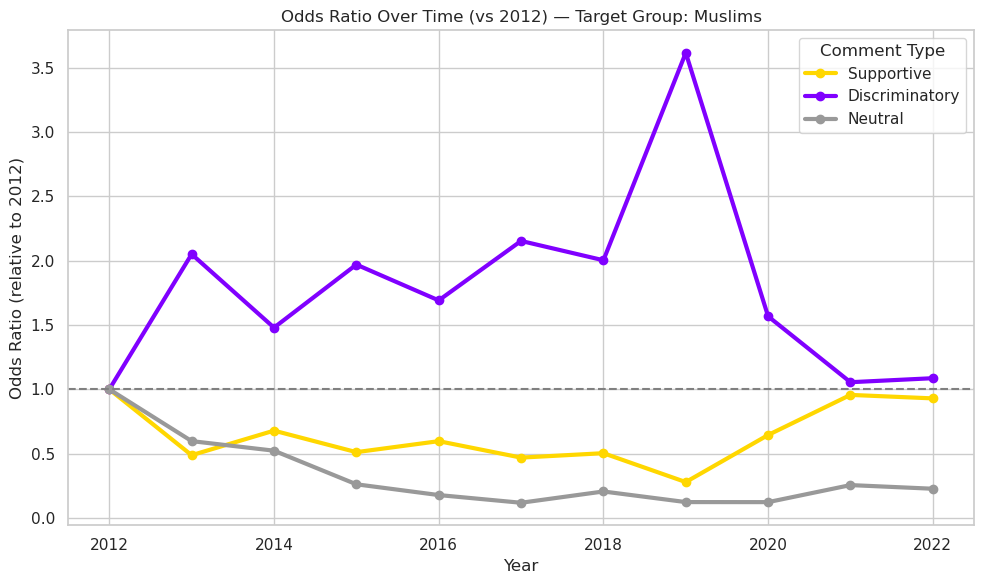

In [60]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns

# # =========================================================
# # 0) Make a safe working copy where index levels won't
# #    collide with existing columns (fixes: "cannot insert year")
# # =========================================================
# df2 = df.copy()

# # If year exists as BOTH an index level name and a column, rename the index level
# idx_names = list(df2.index.names) if isinstance(df2.index, pd.MultiIndex) else [df2.index.name]

# if any(n in df2.columns for n in idx_names if n is not None):
#     # rename colliding index level names by prefixing with "idx_"
#     rename_map = {n: f"idx_{n}" for n in idx_names if n is not None and n in df2.columns}
#     df2.index = df2.index.set_names([rename_map.get(n, n) for n in idx_names])

# # Now safe reset
# df2 = df2.reset_index(drop=False)

# # If you ended up with idx_year, but you want to use the column 'year' anyway, keep 'year'
# # (no action needed). If your year was ONLY in the index, you can map idx_year -> year:
# if 'year' not in df2.columns and 'idx_year' in df2.columns:
#     df2 = df2.rename(columns={'idx_year': 'year'})

# # =========================================================
# # 1) Group-wise counts by CommentType (Supportive/Discriminatory/Neutral)
# # =========================================================
# counts = df2.groupby(['year', 'TargetedGroup', 'CommentType']).size().unstack(fill_value=0)

# for c in ['Supportive', 'Discriminatory', 'Neutral']:
#     if c not in counts.columns:
#         counts[c] = 0
# counts = counts[['Supportive', 'Discriminatory', 'Neutral']].astype(float)

# # =========================================================
# # 2) Smoothing + totals
# # =========================================================
# counts = counts + 0.5
# counts['Total'] = counts.sum(axis=1)

# # =========================================================
# # 3) Proportions + odds
# # =========================================================
# for c in ['Supportive', 'Discriminatory', 'Neutral']:
#     counts[f'P_{c}'] = counts[c] / counts['Total']
#     counts[f'Odds_{c}'] = counts[f'P_{c}'] / (1 - counts[f'P_{c}'])

# # =========================================================
# # 4) Group-wise odds ratios vs reference year (2012)
# # =========================================================
# ref_year = 2012

# def add_or(g):
#     # g index is year within each TargetedGroup
#     if ref_year not in g.index:
#         for c in ['Supportive', 'Discriminatory', 'Neutral']:
#             g[f'OR_{c}_vs_{ref_year}'] = np.nan
#         return g
#     for c in ['Supportive', 'Discriminatory', 'Neutral']:
#         g[f'OR_{c}_vs_{ref_year}'] = g[f'Odds_{c}'] / g.loc[ref_year, f'Odds_{c}']
#     return g

# counts = counts.groupby(level='TargetedGroup', group_keys=False).apply(add_or)
# counts_flat = counts.reset_index()  # year, TargetedGroup, etc.

# # =========================================================
# # 5) Plot ONE group (e.g., Muslims)
# # =========================================================
# GROUP_TO_PLOT = "Muslims"

# sub = counts_flat[counts_flat['TargetedGroup'] == GROUP_TO_PLOT].sort_values('year')

# plt.figure(figsize=(10,6))
# sns.set(style="whitegrid")

# palette = {'Supportive': '#ffd700', 'Discriminatory': '#8000ff', 'Neutral': '#999999'}

# for c in ['Supportive', 'Discriminatory', 'Neutral']:
#     plt.plot(sub['year'], sub[f'OR_{c}_vs_{ref_year}'],
#              marker='o', linewidth=3, label=c, color=palette[c])

# plt.axhline(1, color='gray', linestyle='--')
# plt.title(f"Odds Ratio Over Time (vs {ref_year}) — Target Group: {GROUP_TO_PLOT}")
# plt.xlabel("Year")
# plt.ylabel(f"Odds Ratio (relative to {ref_year})")
# plt.legend(title="Comment Type")
# plt.tight_layout()
# plt.show()

In [61]:
counts

CommentType           Supportive  Discriminatory  Neutral   Total  \
year TargetedGroup                                                  
2012 Black Americans        22.5           298.5      0.5   321.5   
     Conservatives           0.5           264.5      0.5   265.5   
     Immigrants              3.5           125.5      0.5   129.5   
     Jews                    3.5           161.5      0.5   165.5   
     LGBTQ+                 59.5            52.5      0.5   112.5   
...                          ...             ...      ...     ...   
2022 NDP                     0.5             1.5      0.5     2.5   
     Refugees               55.5           182.5      0.5   238.5   
     Republicans             2.5          1196.5      0.5  1199.5   
     Trumpers                0.5             1.5      0.5     2.5   
     Uyghur                  0.5             2.5      0.5     3.5   

CommentType           P_Supportive  Odds_Supportive  P_Discriminatory  \
year TargetedGroup                                                      
2012 Black Americans      0.069984         0.075251          0.928460   
     Conservatives        0.001883         0.001887          0.996234   
     Immigrants           0.027027         0.027778          0.969112   
     Jews                 0.021148         0.021605          0.975831   
     LGBTQ+               0.528889         1.122642          0.466667   
...                            ...              ...               ...   
2022 NDP                  0.200000         0.250000          0.600000   
     Refugees             0.232704         0.303279          0.765199   
     Republicans          0.002084         0.002089          0.997499   
     Trumpers             0.200000         0.250000          0.600000   
     Uyghur               0.142857         0.166667          0.714286   

CommentType           Odds_Discriminatory  P_Neutral  Odds_Neutral  \
year TargetedGroup                                                   
2012 Black Americans            12.978261   0.001555      0.001558   
     Conservatives             264.500000   0.001883      0.001887   
     Immigrants                 31.375000   0.003861      0.003876   
     Jews                       40.375000   0.003021      0.003030   
     LGBTQ+                      0.875000   0.004444      0.004464   
...                                   ...        ...           ...   
2022 NDP                         1.500000   0.200000      0.250000   
     Refugees                    3.258929   0.002096      0.002101   
     Republicans               398.833333   0.000417      0.000417   
     Trumpers                    1.500000   0.200000      0.250000   
     Uyghur                      2.500000   0.142857      0.166667   

CommentType           OR_Supportive_vs_2012  OR_Discriminatory_vs_2012  \
year TargetedGroup                                                       
2012 Black Americans               1.000000                   1.000000   
     Conservatives                 1.000000                   1.000000   
     Immigrants                    1.000000                   1.000000   
     Jews                          1.000000                   1.000000   
     LGBTQ+                        1.000000                   1.000000   
...                                     ...                        ...   
2022 NDP                                NaN                        NaN   
     Refugees                      1.819672                   1.303571   
     Republicans                   0.071846                  13.994152   
     Trumpers                           NaN                        NaN   
     Uyghur                             NaN                        NaN   

CommentType           OR_Neutral_vs_2012  
year TargetedGroup                        
2012 Black Americans            1.000000  
     Conservatives              1.000000  
     Immigrants                 1.000000  
     Jews                       1.000000  
     LGBTQ+         

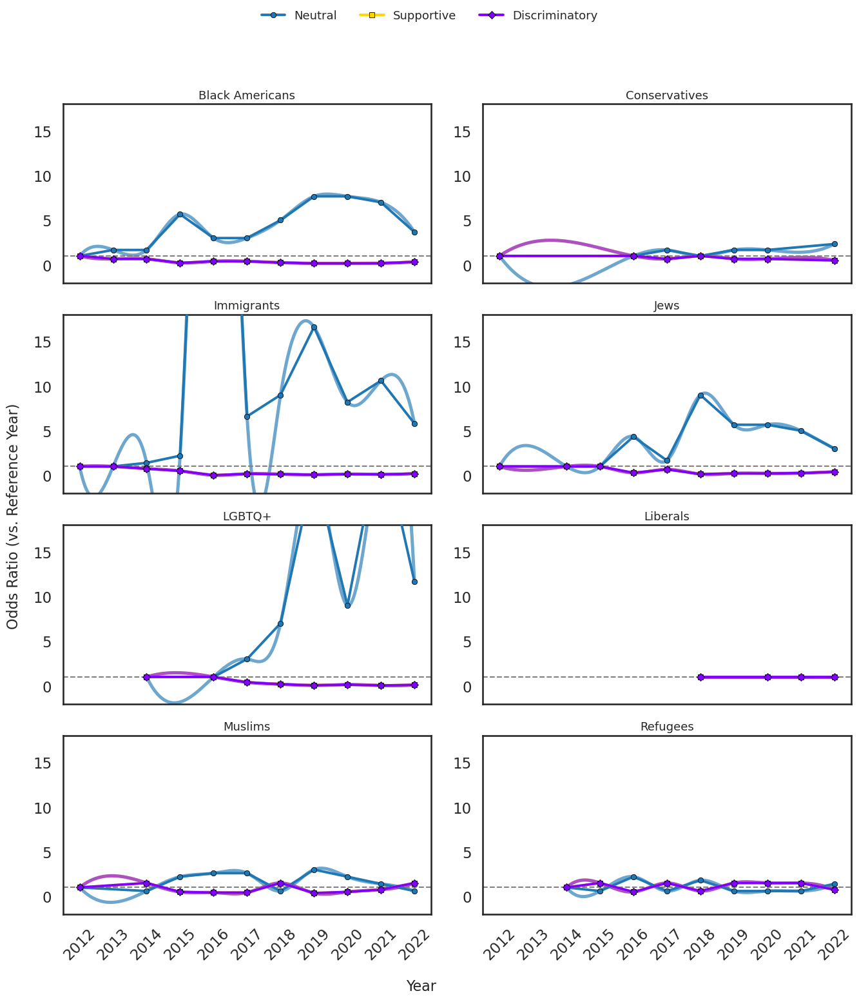

In [66]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns
# from scipy.interpolate import make_interp_spline

# # -----------------------------
# # 0) Clean & standardize labels
# # -----------------------------
# df2 = df.copy()
# df2['year'] = pd.to_numeric(df2['year'], errors='coerce')
# df2 = df2.dropna(subset=['year', 'MappedGroup', 'Sentiment'])
# df2['year'] = df2['year'].astype(int)

# # Standardize sentiment strings (THIS usually fixes "Supportive not showing")
# sent_map = {
#     "supportive": "Supportive",
#     "discriminatory": "Discriminatory",
#     "neutral": "Neutral",
# }
# df2['Sentiment'] = (
#     df2['Sentiment'].astype(str)
#       .str.strip()
#       .str.lower()
#       .map(sent_map)
# )

# # Keep only these 3 (drop anything else)
# SENTIMENTS = ["Neutral", "Supportive", "Discriminatory"]
# df2 = df2[df2['Sentiment'].isin(SENTIMENTS)].copy()

# # -----------------------------
# # 1) Compute OR per group
# # -----------------------------
# plot_data = []

# for group, subset in df2.groupby("MappedGroup"):

#     counts = subset.groupby(['year', 'Sentiment']).size().unstack(fill_value=0)

#     # Force all sentiments to exist as columns
#     counts = counts.reindex(columns=SENTIMENTS, fill_value=0).astype(float)

#     # Smoothing to avoid zero odds
#     counts = counts + 0.5
#     counts['Total'] = counts.sum(axis=1)

#     # proportions + odds
#     for s in SENTIMENTS:
#         p = counts[s] / counts['Total']
#         counts[f'Odds_{s}'] = p / (1 - p)

#     # Reference year: use 2012 if present else min year
#     ref_year = 2012 if 2012 in counts.index else int(counts.index.min())

#     # OR vs ref
#     for s in SENTIMENTS:
#         ref_odds = counts.loc[ref_year, f'Odds_{s}']
#         counts[f'OR_{s}'] = counts[f'Odds_{s}'] / ref_odds

#         for year, or_val in counts[f'OR_{s}'].items():
#             plot_data.append({
#                 "MappedGroup": group,
#                 "year": int(year),
#                 "Sentiment": s,
#                 "Odds_Ratio": float(or_val),
#                 "Reference_Year": int(ref_year)
#             })

# plot_df = pd.DataFrame(plot_data)

# # -----------------------------
# # 2) Plot (time series guaranteed)
# # -----------------------------
# groups = sorted(plot_df['MappedGroup'].unique())
# ncols = 2
# nrows = int(np.ceil(len(groups) / ncols))

# sns.set(style="white", context="talk", font_scale=1.0)
# fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(7*ncols, 4*nrows), sharex=True)
# axes = np.array(axes).flatten()

# colors = {
#     'Neutral': '#1f77b4',
#     'Supportive': '#ffd700',
#     'Discriminatory': '#8000ff'
# }
# markers = {
#     'Neutral': 'o',
#     'Supportive': 's',
#     'Discriminatory': 'D'
# }

# # Use global year ticks so time series appears consistently
# years_all = sorted(plot_df['year'].unique())

# for i, group in enumerate(groups):
#     ax = axes[i]
#     subset_g = plot_df[plot_df['MappedGroup'] == group]

#     for sentiment in SENTIMENTS:
#         sub = subset_g[subset_g['Sentiment'] == sentiment].sort_values('year')

#         # Aggregate if duplicated years exist (rare but can happen)
#         sub = sub.groupby('year', as_index=False)['Odds_Ratio'].mean().sort_values('year')
#         x = sub['year'].to_numpy()
#         y = sub['Odds_Ratio'].to_numpy()

#         # --- Always draw the base time series (so it ALWAYS appears) ---
#         ax.plot(
#             x, y,
#             color=colors[sentiment],
#             linewidth=2.8,
#             marker=markers[sentiment],
#             markersize=6,
#             markeredgecolor="black",
#             markeredgewidth=0.6,
#             label=sentiment,
#             zorder=3
#         )

#         # --- Optional smoothing overlay (only if safe) ---
#         if len(x) >= 4 and len(np.unique(x)) >= 4:
#             x_smooth = np.linspace(x.min(), x.max(), 250)
#             spline = make_interp_spline(x, y, k=3)
#             y_smooth = spline(x_smooth)
#             ax.plot(x_smooth, y_smooth, color=colors[sentiment], linewidth=3.6, alpha=0.65, zorder=2)

#     ax.axhline(1, color='gray', linestyle='--', lw=1.5)
#     ax.set_ylim(-2, 18)  # your fixed scale
#     ax.set_title(group, fontsize=13)
#     ax.set_xticks(years_all)
#     ax.tick_params(axis='x', labelrotation=45)
#     ax.set_xlabel("")
#     ax.set_ylabel("")

# # Remove empty axes
# for j in range(i + 1, len(axes)):
#     fig.delaxes(axes[j])

# fig.text(0.5, 0.04, "Year", ha='center', fontsize=16)
# fig.text(0.04, 0.5, "Odds Ratio (vs. Reference Year)", va='center', rotation='vertical', fontsize=16)

# # Legend (use first axis handles)
# handles, labels = axes[0].get_legend_handles_labels()
# fig.legend(handles, labels, loc='upper center', ncol=3, fontsize=13, frameon=False)

# plt.tight_layout(rect=[0.05, 0.05, 1, 0.93])
# plt.savefig("odds_ratio_trends_all_groups_fixedY.pdf", dpi=300, bbox_inches="tight")
# plt.show()

In [49]:
# # group = "Black Americans"
# sub = counts.xs(group, level='TargetedGroup')  # now index is just year

# plot_df = sub.reset_index()[['year',
#                              'OR_Supportive_vs_2012',
#                              'OR_Discriminatory_vs_2012',
#                              'OR_Neutral_vs_2012']]

# df_melted = plot_df.melt(id_vars='year',
#                          value_vars=['OR_Supportive_vs_2012','OR_Discriminatory_vs_2012','OR_Neutral_vs_2012'],
#                          var_name='comment_type',
#                          value_name='odds_ratio')

# df_melted['comment_type'] = df_melted['comment_type'].str.extract(r'OR_(.*?)_vs')[0]

# plt.figure(figsize=(8,6))
# sns.set(style="whitegrid")
# sns.pointplot(data=df_melted, x="odds_ratio", y="year", hue="comment_type",
#               dodge=0.5, join=False,
#               palette={"Supportive":"blue","Discriminatory":"orange","Neutral":"green"})
# plt.axvline(1, color='gray', linestyle='--')
# plt.xlabel("Odds Ratio (vs. 2012)")
# plt.ylabel("Year")
# plt.title(f"Odds Ratio Over Time — {group}")
# plt.tight_layout()
# plt.show()

ValueError: Names should be list-like for a MultiIndex

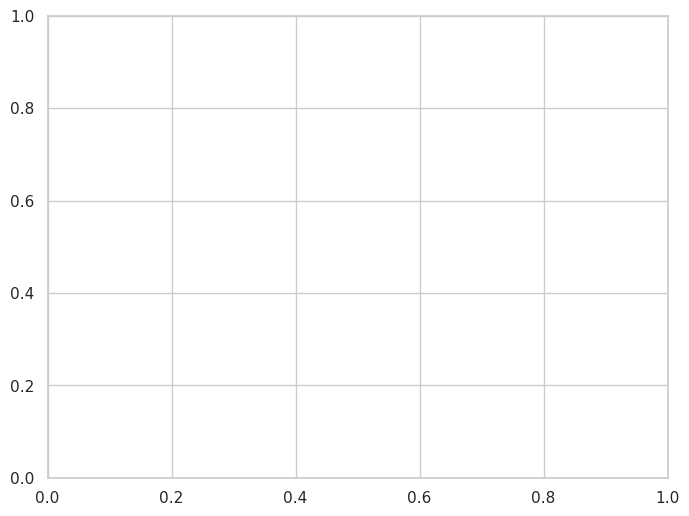

In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Construct a DataFrame with all three comment types
data = {
    'year': counts.index,
    'OR_Supportive_vs_2012': counts['OR_Supportive_vs_2012'],
    'OR_Discriminatory_vs_2012': counts['OR_Discriminatory_vs_2012'],
    'OR_Neutral_vs_2012': counts['OR_Neutral_vs_2012']
}

df = pd.DataFrame(data)

# Melt the DataFrame to long format for seaborn plotting
df_melted = df.melt(id_vars='year',
                    value_vars=[
                        'OR_Supportive_vs_2012',
                        'OR_Discriminatory_vs_2012',
                        'OR_Neutral_vs_2012'
                    ],
                    var_name='comment_type',
                    value_name='odds_ratio')

# Extract readable comment type labels
df_melted['comment_type'] = df_melted['comment_type'].str.extract(r'OR_(.*?)_vs')[0]

# Plotting
plt.figure(figsize=(8, 6))
sns.set(style="whitegrid")

sns.pointplot(
    data=df_melted,
    x="odds_ratio",
    y="year",
    hue="comment_type",
    dodge=0.5,
    join=False,
    palette={"Supportive": "blue", "Discriminatory": "orange", "Neutral": "green"}
)

plt.axvline(1, color='gray', linestyle='--')  # Reference line at OR=1
plt.xlabel("Odds Ratio (vs. 2018)")
plt.ylabel("Year")
plt.title("Odds Ratio of Supportive, Discriminatory, and Critical Comments Over Time")
plt.legend(title="Comment Type")
plt.tight_layout()
plt.show()


In [43]:
import numpy as np

# Reuse the existing counts DataFrame

# Compute standard error for Supportive and Discriminatory proportions
counts['SE_Supportive'] = np.sqrt(counts['P_Supportive'] * (1 - counts['P_Supportive']) / counts['Total'])
counts['SE_Discriminatory'] = np.sqrt(counts['P_Discriminatory'] * (1 - counts['P_Discriminatory']) / counts['Total'])

# Compute 95% confidence intervals for proportions
z = 1.96  # For 95% CI
counts['P_Supportive_lower'] = counts['P_Supportive'] - z * counts['SE_Supportive']
counts['P_Supportive_upper'] = counts['P_Supportive'] + z * counts['SE_Supportive']
counts['P_Discriminatory_lower'] = counts['P_Discriminatory'] - z * counts['SE_Discriminatory']
counts['P_Discriminatory_upper'] = counts['P_Discriminatory'] + z * counts['SE_Discriminatory']

# Ensure bounds are within [0, 1]
counts['P_Supportive_lower'] = counts['P_Supportive_lower'].clip(0, 1)
counts['P_Supportive_upper'] = counts['P_Supportive_upper'].clip(0, 1)
counts['P_Discriminatory_lower'] = counts['P_Discriminatory_lower'].clip(0, 1)
counts['P_Discriminatory_upper'] = counts['P_Discriminatory_upper'].clip(0, 1)

# Convert proportion bounds to odds
counts['Odds_Supportive_lower'] = counts['P_Supportive_lower'] / (1 - counts['P_Supportive_lower'])
counts['Odds_Supportive_upper'] = counts['P_Supportive_upper'] / (1 - counts['P_Supportive_upper'])

counts['Odds_Discriminatory_lower'] = counts['P_Discriminatory_lower'] / (1 - counts['P_Discriminatory_lower'])
counts['Odds_Discriminatory_upper'] = counts['P_Discriminatory_upper'] / (1 - counts['P_Discriminatory_upper'])

# Compute odds ratio confidence bounds using reference year
ref_year = counts.index.min()
ref_odds_supportive = counts.loc[ref_year, 'Odds_Supportive']
ref_odds_discriminatory = counts.loc[ref_year, 'Odds_Discriminatory']

counts['OR_Supportive_lower'] = counts['Odds_Supportive_lower'] / ref_odds_supportive
counts['OR_Supportive_upper'] = counts['Odds_Supportive_upper'] / ref_odds_supportive
counts['OR_Discriminatory_lower'] = counts['Odds_Discriminatory_lower'] / ref_odds_discriminatory
counts['OR_Discriminatory_upper'] = counts['Odds_Discriminatory_upper'] / ref_odds_discriminatory


# Compute SE and CI for Critical
counts['SE_Neutral'] = np.sqrt(counts['P_Neutral'] * (1 - counts['P_Neutral']) / counts['Total'])
counts['P_Neutral_lower'] = counts['P_Neutral'] - z * counts['SE_Neutral']
counts['P_Neutral_upper'] = counts['P_Neutral'] + z * counts['SE_Neutral']
counts['P_Neutral_lower'] = counts['P_Neutral_lower'].clip(0, 1)
counts['P_Neutral_upper'] = counts['P_Neutral_upper'].clip(0, 1)

# Convert to odds
counts['Odds_Neutral'] = counts['P_Neutral'] / (1 - counts['P_Neutral'])
counts['Odds_Neutral_lower'] = counts['P_Neutral_lower'] / (1 - counts['P_Neutral_lower'])
counts['Odds_Neutral_upper'] = counts['P_Neutral_upper'] / (1 - counts['P_Neutral_upper'])

# Odds ratio vs. reference year
ref_odds_critical = counts.loc[ref_year, 'Odds_Neutral']
counts['OR_Neutral_vs_' + str(ref_year)] = counts['Odds_Neutral'] / ref_odds_critical
counts['OR_Neutral_lower'] = counts['Odds_Neutral_lower'] / ref_odds_critical
counts['OR_Neutral_upper'] = counts['Odds_Neutral_upper'] / ref_odds_critical






In [44]:
# Extend the DataFrame to include error bars for plotting

# Prepare separate DataFrames per comment type
supportive_df = pd.DataFrame({
    'year': counts.index,
    'comment_type': 'Supportive',
    'odds_ratio': counts['OR_Supportive_vs_2012'],
    'odds_ratio_lower': counts['OR_Supportive_lower'],
    'odds_ratio_upper': counts['OR_Supportive_upper']
})

discriminatory_df = pd.DataFrame({
    'year': counts.index,
    'comment_type': 'Discriminatory',
    'odds_ratio': counts['OR_Discriminatory_vs_2012'],
    'odds_ratio_lower': counts['OR_Discriminatory_lower'],
    'odds_ratio_upper': counts['OR_Discriminatory_upper']
})

critical_df = pd.DataFrame({
    'year': counts.index,
    'comment_type': 'Neutral',
    'odds_ratio': counts['OR_Neutral_vs_2012'],
    'odds_ratio_lower': counts['OR_Neutral_lower'],
    'odds_ratio_upper': counts['OR_Neutral_upper']
})

# Combine all into one DataFrame
plot_df = pd.concat([supportive_df, discriminatory_df, critical_df], ignore_index=True)

# Calculate error bars
plot_df['err_lower'] = plot_df['odds_ratio'] - plot_df['odds_ratio_lower']
plot_df['err_upper'] = plot_df['odds_ratio_upper'] - plot_df['odds_ratio']

# Optional: Display to verify
plot_df.head()


KeyError: 'OR_Supportive_vs_2012'

In [29]:


# plot_df['err'] =  plot_df['err_upper'] - plot_df['err_lower']


# Ensure minimum error threshold
min_error = 0.00104
plot_df['err_lower'] = plot_df['err_lower'].clip(lower=min_error)
plot_df['err_upper'] = plot_df['err_upper'].clip(lower=min_error)

# Compute symmetric error width
plot_df['err'] = plot_df['err_upper'] - plot_df['err_lower']

# If err is too small, nudge err_upper slightly
too_small_mask = plot_df['err'] < min_error
plot_df.loc[too_small_mask, 'err_upper'] += (min_error - plot_df.loc[too_small_mask, 'err']) + 1e-6  # tiny extra to avoid exact equality

# Recalculate err after adjustment
plot_df['err'] = plot_df['err_upper'] - plot_df['err_lower']



#print(plot_df)
# Plot with error bars
plt.figure(figsize=(8, 7))
#sns.set(style="whitegrid")

# # Color palette for comment types
# palette = {
#     'Neutral': '#1f77b4',
#     'Supportive': '#ffd700',
#     'Discriminatory': '#8000ff',
#     'Critical': '#999999'
# }

# Plot each point with error bars
for comment_type, color in zip(['Supportive', 'Discriminatory', 'Neutral'], ['#ffd700', '#8000ff', '#999999']):
    subset = plot_df[plot_df['comment_type'] == comment_type]
    plt.errorbar(
        x=subset['odds_ratio'],
        y=subset['year'],
        xerr=[subset['err_lower'] * 2, subset['err_upper'] * 2],
        fmt='o',
        label=comment_type,
        color=color,
        capsize=5,
        markersize=7,
        elinewidth=3.5,
        linewidth=6
    )

plt.axvline(1, color='gray', linestyle='--', linewidth=1.5)  # reference line
plt.xlabel("Odds Ratio (vs. 2010)", fontsize=20)
plt.ylabel("Year", fontsize=20)

# Tick label fonts
plt.xticks(fontsize=16)
plt.yticks(sorted(plot_df['year'].unique()), fontsize=16)

# Optional: Title font size
# plt.title("Odds Ratio of Supportive and Discriminatory Comments Over Time", fontsize=16)

# Legend font
plt.legend(fontsize=16, title_fontsize=15)
plt.grid(False)
plt.tight_layout()
#safe the figure
plt.savefig('us_vs_them_odds_ratio_plot.png', dpi=300)
plt.show()

NameError: name 'plot_df' is not defined

In [67]:
plot_df

,MappedGroup,year,Sentiment,Odds_Ratio,Reference_Year
0,Black Americans,2012,Neutral,1.000000,2012
1,Black Americans,2013,Neutral,1.666667,2012
2,Black Americans,2014,Neutral,1.666667,2012
3,Black Americans,2015,Neutral,5.666667,2012
4,Black Americans,2016,Neutral,3.000000,2012
...,...,...,...,...,...
205,Refugees,2018,Discriminatory,0.600000,2014
206,Refugees,2019,Discriminatory,1.500000,2014
207,Refugees,2020,Discriminatory,1.500000,2014
208,Refugees,2021,Discriminatory,1.500000,2014


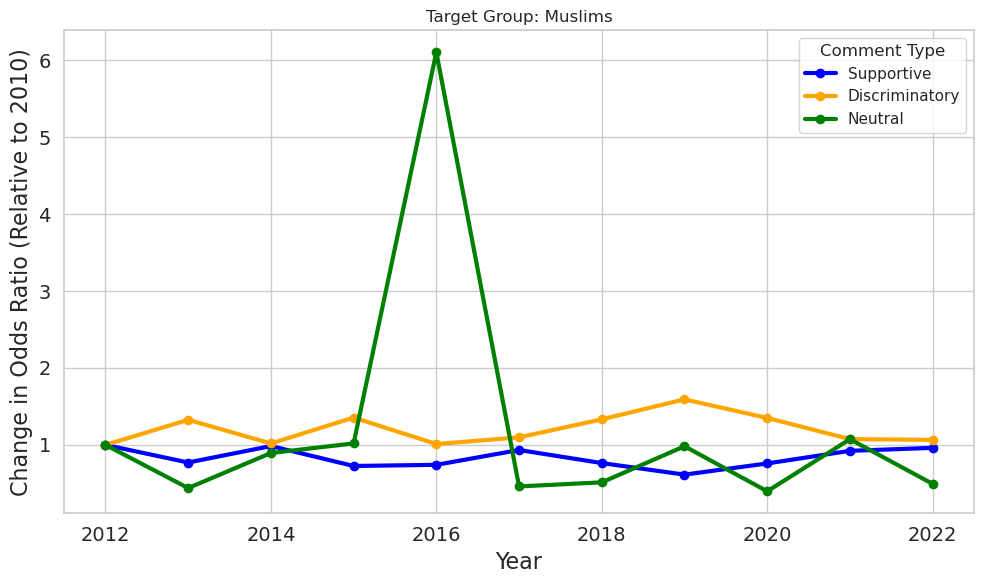

In [228]:
# Prepare clean DataFrame again from the provided structure
plot_df_fixed = plot_df.copy()
plot_df_fixed = plot_df_fixed.reset_index(drop=True)

# Re-plot the line plot with thicker lines, dotted markers, and error bars
plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")

for comment_type, color in zip(['Supportive', 'Discriminatory', 'Neutral'], ['blue', 'orange', 'green']):
    subset = plot_df_fixed[plot_df_fixed['comment_type'] == comment_type].sort_values(by='year')

    # Line plot with thicker lines and dotted markers
    plt.plot(subset['year'], subset['odds_ratio'], label=comment_type,
             color=color, linestyle='-', marker='o', markersize=6, linewidth=3)



#plt.axhline(1, color='gray', linestyle='--')
plt.xlabel("Year",  fontsize=16)
plt.ylabel("Change in Odds Ratio (Relative to 2010)", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title("Target Group: Muslims")
plt.legend(title="Comment Type")
plt.tight_layout()
plt.show()


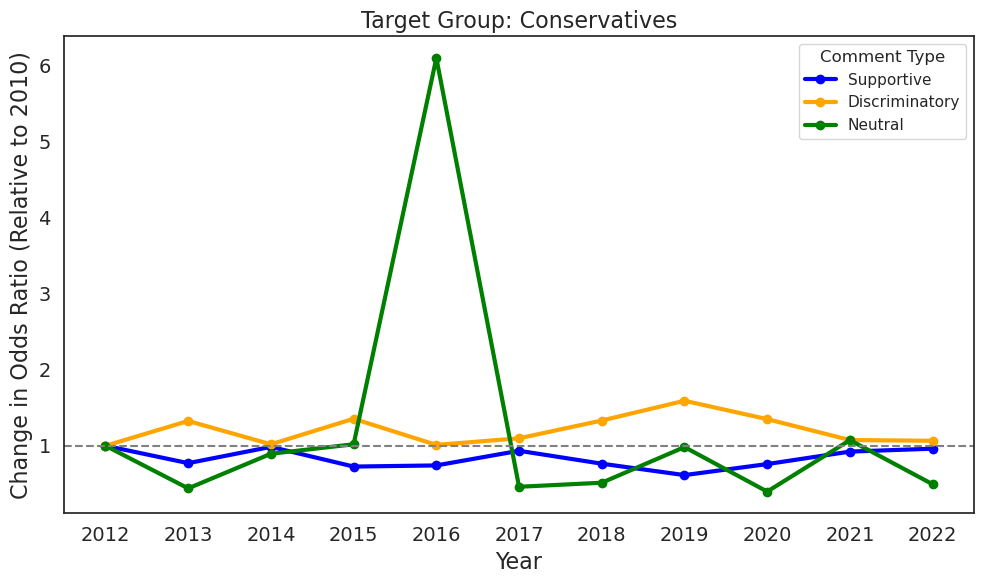

In [229]:
# Re-plot the line plot without background grid lines
plt.figure(figsize=(10, 6))
sns.set(style="white")  # No background grid

for comment_type, color in zip(['Supportive', 'Discriminatory', 'Neutral'], ['blue', 'orange', 'green']):
    subset = plot_df_fixed[plot_df_fixed['comment_type'] == comment_type].sort_values(by='year')

    # Line plot with thicker lines and dotted markers
    plt.plot(subset['year'], subset['odds_ratio'], label=comment_type,
             color=color, linestyle='-', marker='o', markersize=6, linewidth=3)


plt.axhline(1, color='gray', linestyle='--')
plt.xlabel("Year", fontsize=16)
plt.ylabel("Change in Odds Ratio (Relative to 2010)", fontsize=16)
plt.xticks(subset['year'].unique(), fontsize=14)
plt.yticks(fontsize=14)
plt.title("Target Group: Conservatives", fontsize=16)
plt.legend(title="Comment Type")
plt.tight_layout()
plt.show()


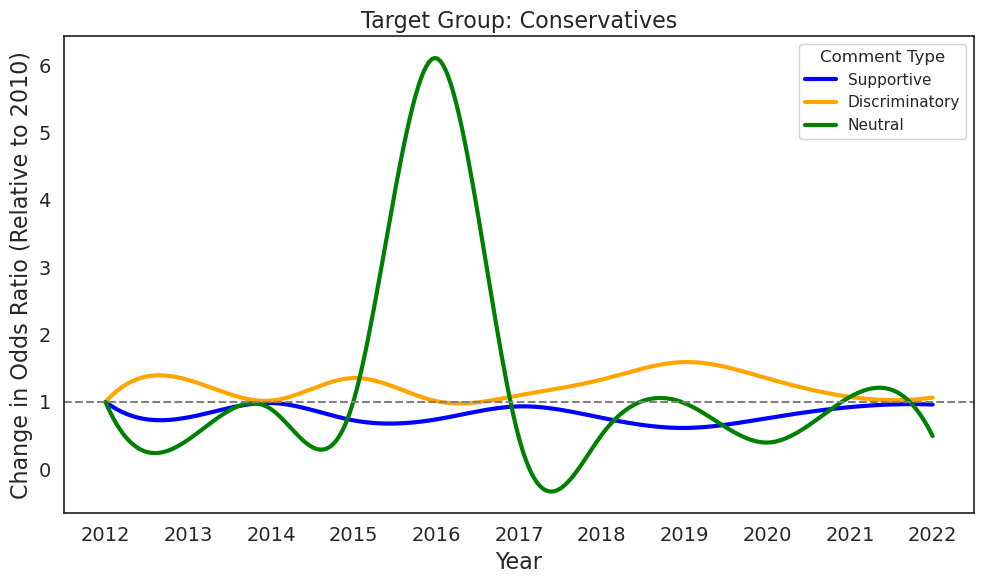

In [230]:
import numpy as np
from scipy.interpolate import make_interp_spline

plt.figure(figsize=(10, 6))
sns.set(style="white")  # No background grid

for comment_type, color in zip(['Supportive', 'Discriminatory', 'Neutral'], ['blue', 'orange', 'green']):
    subset = plot_df_fixed[plot_df_fixed['comment_type'] == comment_type].sort_values(by='year')

    x = subset['year'].values
    y = subset['odds_ratio'].values

    # Only smooth if enough points
    if len(x) >= 4:
        x_smooth = np.linspace(x.min(), x.max(), 300)
        spline = make_interp_spline(x, y, k=3)
        y_smooth = spline(x_smooth)
        plt.plot(x_smooth, y_smooth, label=comment_type, color=color, linewidth=3)
    else:
        # Fallback to regular line
        plt.plot(x, y, label=comment_type, color=color, linestyle='-', marker='o', markersize=6, linewidth=3)

# Reference line
plt.axhline(1, color='gray', linestyle='--')

# Labels and legend
plt.xlabel("Year", fontsize=16)
plt.ylabel("Change in Odds Ratio (Relative to 2010)", fontsize=16)
plt.xticks(sorted(plot_df_fixed['year'].unique()), fontsize=14)
plt.yticks(fontsize=14)
plt.title("Target Group: Conservatives", fontsize=16)
plt.legend(title="Comment Type")
plt.tight_layout()
plt.show()


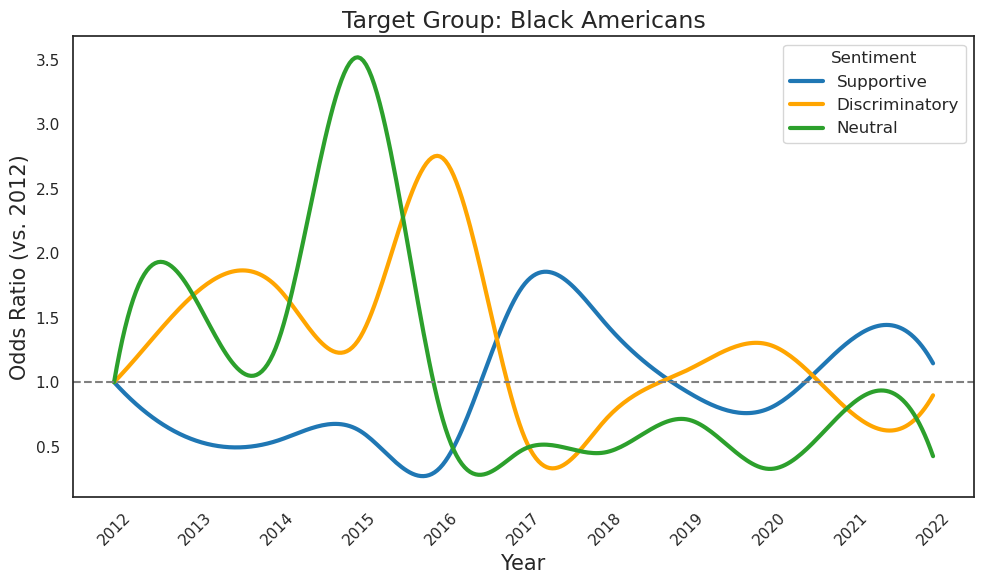

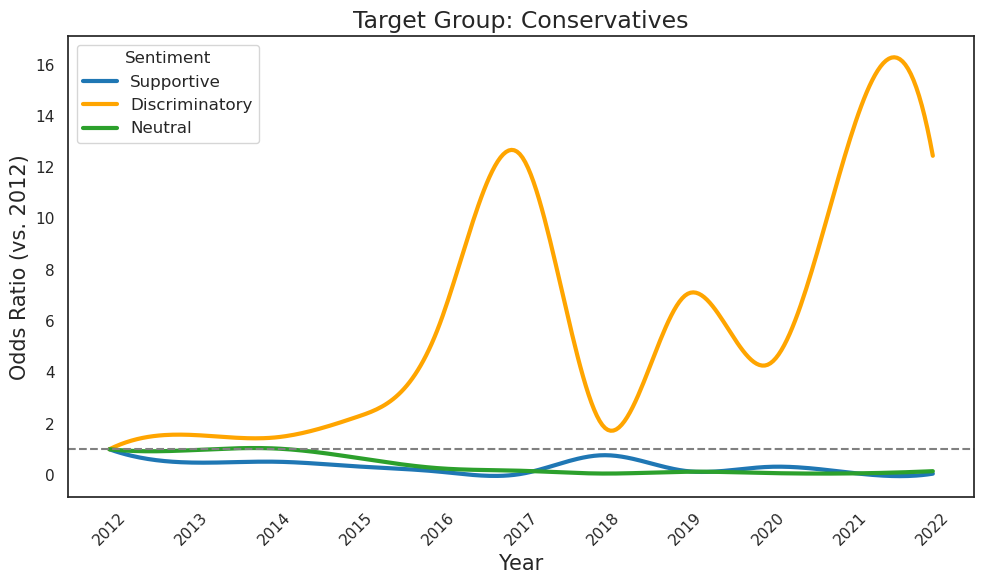

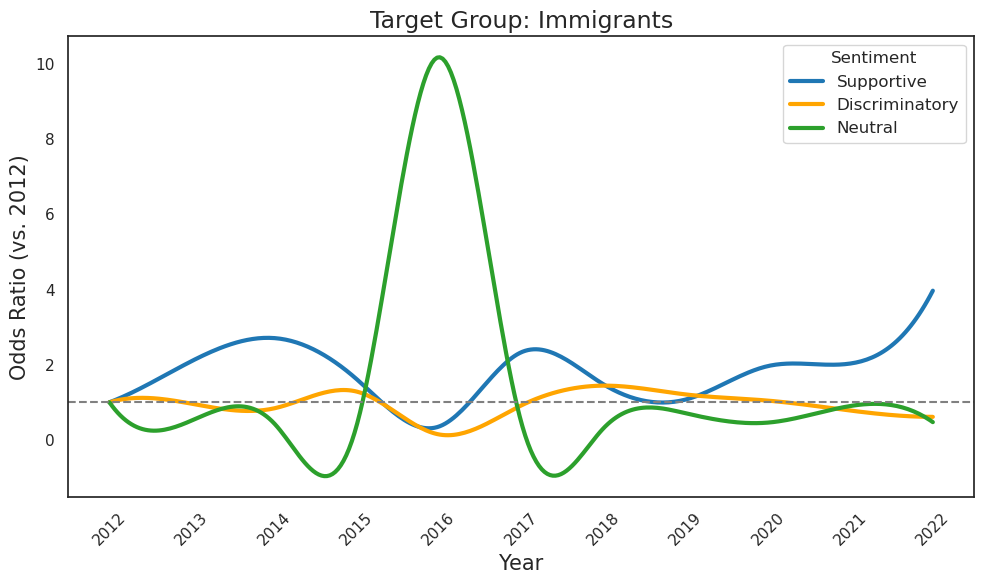

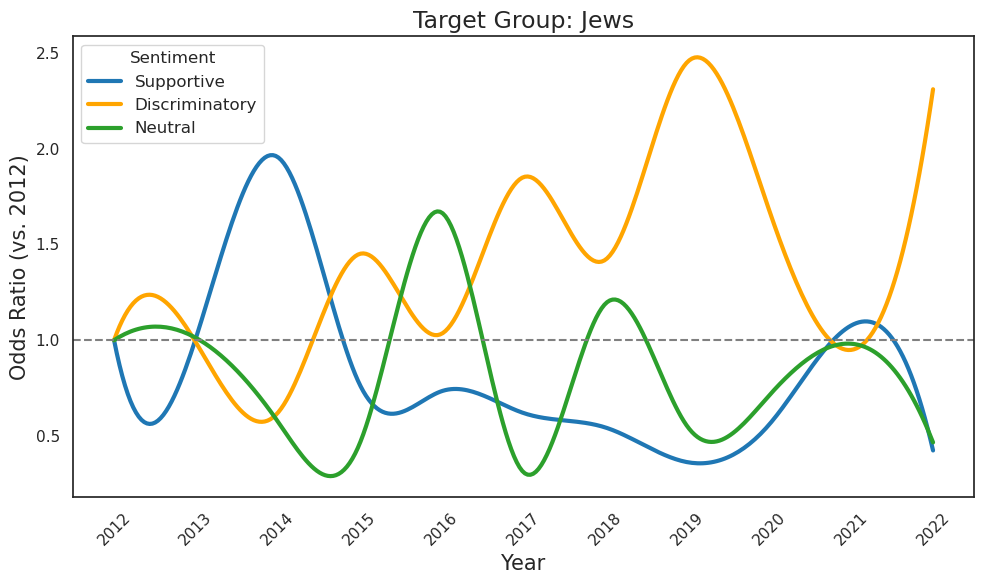

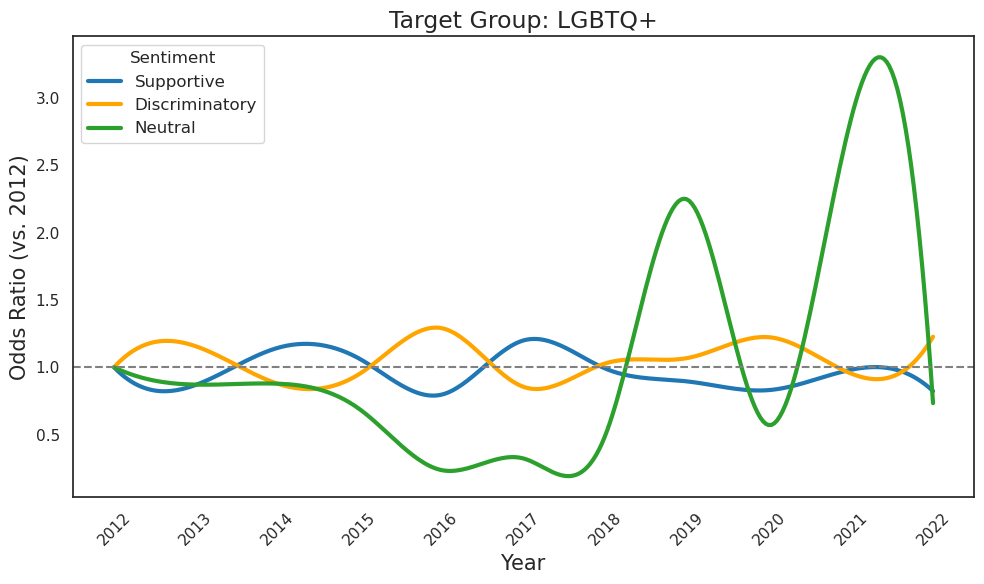

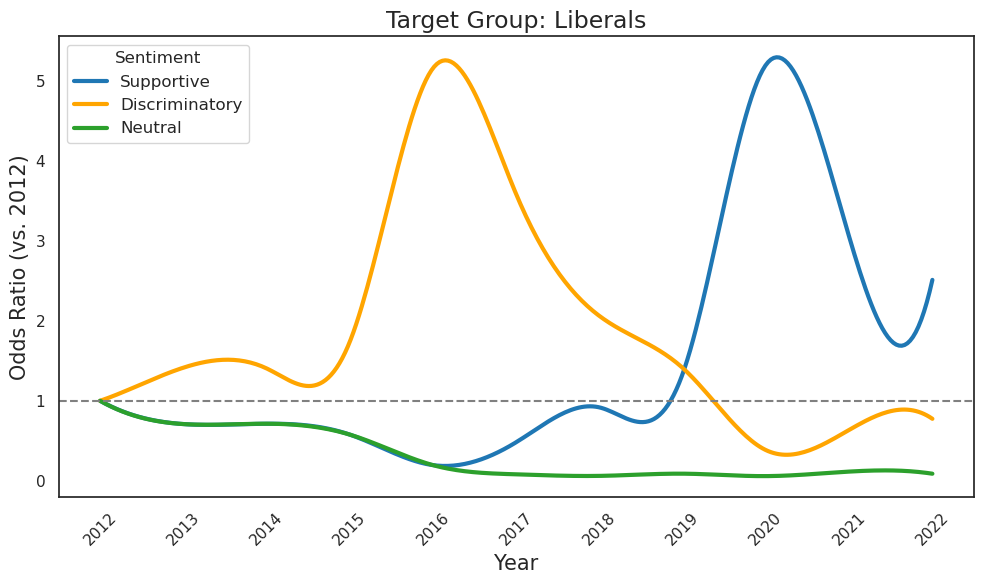

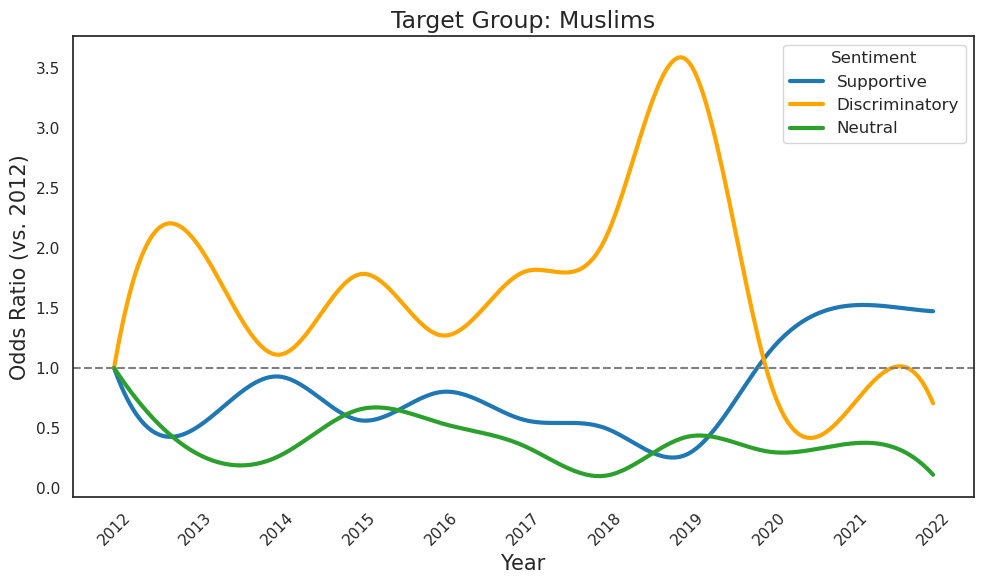

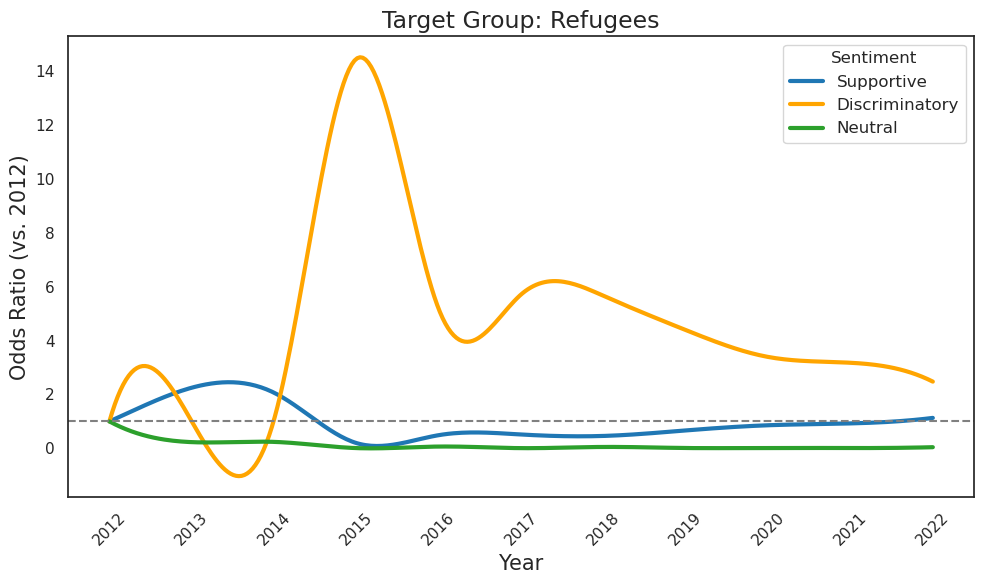

In [278]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import make_interp_spline

# ---------------------------------------------------
# 1️⃣  Compute odds ratio table per TargetedGroup
# ---------------------------------------------------

plot_data = []

for group in df['MappedGroup'].unique():
    subset = df[df['MappedGroup'] == group]

    # Count Sentiment per year
    counts = subset.groupby(['year', 'Sentiment']).size().unstack(fill_value=0)

    # Avoid zero-division issues
    counts = counts.replace(0, 1)

    # Total yearly comments
    counts['Total'] = counts.sum(axis=1)

    # Compute proportions
    for sentiment in ['Supportive', 'Discriminatory', 'Neutral']:
        if sentiment not in counts.columns:
            counts[sentiment] = 1
        counts[f'P_{sentiment}'] = counts[sentiment] / counts['Total']
        counts[f'Odds_{sentiment}'] = counts[f'P_{sentiment}'] / (1 - counts[f'P_{sentiment}'])

    # Reference year (first in sorted order)
    ref_year = counts.index.min()

    # Compute odds ratios
    for sentiment in ['Supportive', 'Discriminatory', 'Neutral']:
        counts[f'OR_{sentiment}'] = counts[f'Odds_{sentiment}'] / counts.loc[ref_year, f'Odds_{sentiment}']

        # Add to long-format table
        for year, or_val in zip(counts.index, counts[f'OR_{sentiment}']):
            plot_data.append({
                'MappedGroup': group,
                'year': year,
                'Sentiment': sentiment,
                'Odds_Ratio': or_val,
                'Reference_Year': ref_year
            })

plot_df = pd.DataFrame(plot_data)

# ---------------------------------------------------
# 2️⃣  Plot each TargetedGroup
# ---------------------------------------------------

sns.set(style="whitegrid", context="talk", font_scale=1.1)

for group in sorted(plot_df['MappedGroup'].unique()):
    subset = plot_df[plot_df['MappedGroup'] == group]
    
    plt.figure(figsize=(10, 6))
    sns.set(style="white")  # remove heavy grid
    
    # Colors per sentiment
    colors = {
        'Supportive': '#1f77b4',       # blue
        'Discriminatory': '#FFA500',   # orange
        'Neutral': '#2ca02c'           # green
    }

    for sentiment in ['Supportive', 'Discriminatory', 'Neutral']:
        sub = subset[subset['Sentiment'] == sentiment].sort_values(by='year')
        x = sub['year'].values
        y = sub['Odds_Ratio'].values

        if len(x) >= 4:
            x_smooth = np.linspace(x.min(), x.max(), 300)
            spline = make_interp_spline(x, y, k=3)
            y_smooth = spline(x_smooth)
            plt.plot(x_smooth, y_smooth, color=colors[sentiment], linewidth=3, label=sentiment)
        else:
            plt.plot(x, y, color=colors[sentiment], marker='o', linewidth=3, label=sentiment)

    # Reference line at OR=1
    plt.axhline(1, color='gray', linestyle='--', lw=1.5)

    # Labels and styling
    plt.xlabel("Year", fontsize=15)
    plt.ylabel(f"Odds Ratio (vs. {subset['Reference_Year'].iloc[0]})", fontsize=15)
    plt.title(f"Target Group: {group}", fontsize=17)
    plt.legend(title="Sentiment", fontsize=12)
    plt.xticks(sorted(subset['year'].unique()), rotation=45)
    plt.tight_layout()

    # Save each plot
    plt.savefig(f"odds_ratio_trend_{group.replace(' ', '_')}.pdf", dpi=300, bbox_inches="tight")
    plt.show()


In [82]:
df['Sentiment'].value_counts()

Sentiment
Negative    129414
Positive     12892
Neutral        662
Name: count, dtype: int64

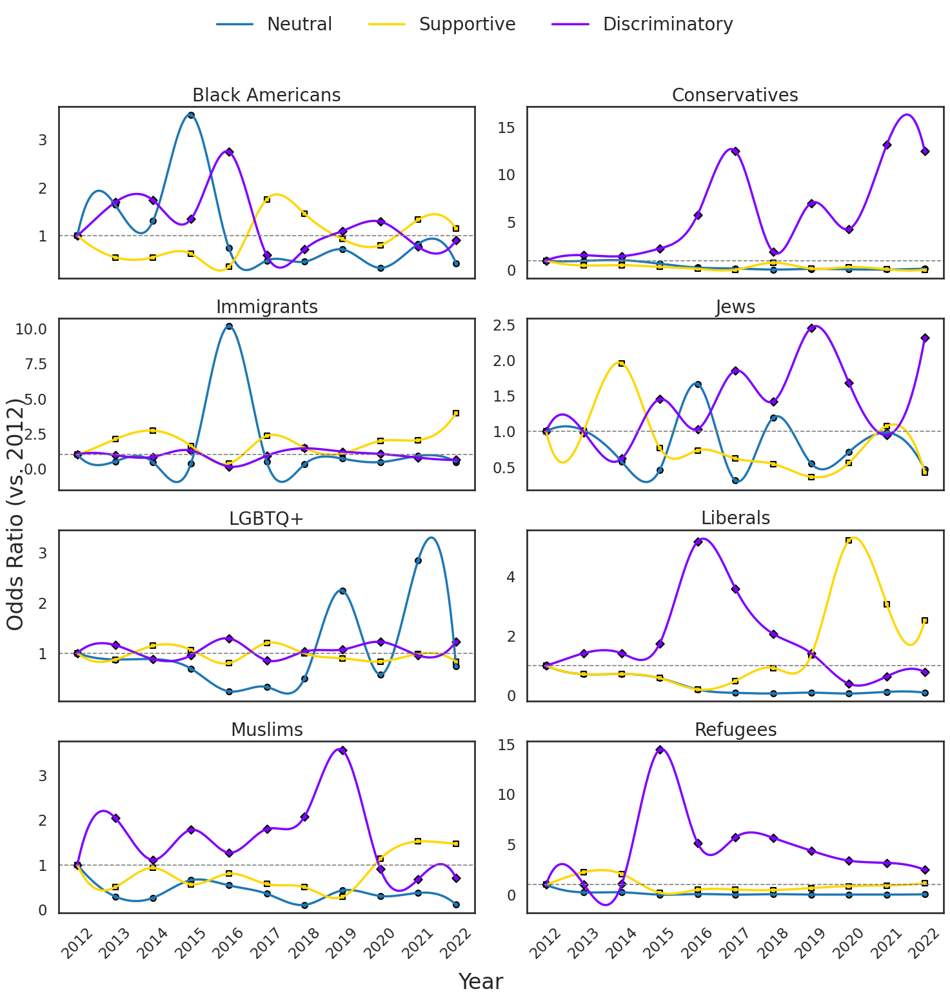

In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import make_interp_spline

# ---------------------------------------------------
# 1️⃣  Compute odds ratio table per MappedGroup
# ---------------------------------------------------

plot_data = []

for group in df['MappedGroup'].unique():
    subset = df[df['MappedGroup'] == group]

    # Count Sentiment per year
    counts = subset.groupby(['year', 'Sentiment']).size().unstack(fill_value=0)
    counts = counts.replace(0, 1)  # Avoid zero-division
    counts['Total'] = counts.sum(axis=1)

    # Compute proportions and odds
    for sentiment in ['Supportive', 'Discriminatory', 'Neutral']:
        if sentiment not in counts.columns:
            counts[sentiment] = 1
        counts[f'P_{sentiment}'] = counts[sentiment] / counts['Total']
        counts[f'Odds_{sentiment}'] = counts[f'P_{sentiment}'] / (1 - counts[f'P_{sentiment}'])

    # Reference year
    ref_year = counts.index.min()

    # Compute odds ratios vs reference year
    for sentiment in ['Supportive', 'Discriminatory', 'Neutral']:
        counts[f'OR_{sentiment}'] = counts[f'Odds_{sentiment}'] / counts.loc[ref_year, f'Odds_{sentiment}']

        # Store in long format
        for year, or_val in zip(counts.index, counts[f'OR_{sentiment}']):
            plot_data.append({
                'MappedGroup': group,
                'year': year,
                'Sentiment': sentiment,
                'Odds_Ratio': or_val,
                'Reference_Year': ref_year
            })

plot_df = pd.DataFrame(plot_data)

# ---------------------------------------------------
# 2️⃣  Plot all groups in a 4-column grid
# ---------------------------------------------------

groups = sorted(plot_df['MappedGroup'].unique())
ncols = 2
nrows = int(np.ceil(len(groups) / ncols))

sns.set(style="white", context="talk", font_scale=1.0)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5*ncols+5, 4*nrows), sharex=True, sharey=False)
axes = axes.flatten()

# 🎨 Define custom colors and markers
colors = {
    'Neutral': '#1f77b4',          # blue
    'Supportive': '#ffd700',       # yellow-gold
    'Discriminatory': '#8000ff'    # purple
}

markers = {
    'Neutral': 'o',          # circle
    'Supportive': 's',       # square
    'Discriminatory': 'D'    # diamond
}

for i, group in enumerate(groups):
    ax = axes[i]
    subset = plot_df[plot_df['MappedGroup'] == group]

    for sentiment in ['Neutral', 'Supportive', 'Discriminatory']:
        sub = subset[subset['Sentiment'] == sentiment].sort_values(by='year')
        x = sub['year'].values
        y = sub['Odds_Ratio'].values

        if len(x) >= 4:
            x_smooth = np.linspace(x.min(), x.max(), 300)
            spline = make_interp_spline(x, y, k=3)
            y_smooth = spline(x_smooth)
            ax.plot(
                x_smooth, y_smooth, color=colors[sentiment],
                linewidth=2.5, label=sentiment
            )
            # Add discrete marker points
            ax.scatter(x, y, color=colors[sentiment], s=40, marker=markers[sentiment], edgecolor='black')
        else:
            
            ax.plot(
                x, y, color=colors[sentiment], marker=markers[sentiment],
                markersize=6, linewidth=2.5, label=sentiment
            )

    # Reference line
    ax.axhline(1, color='gray', linestyle='--', lw=1.2)

    # Style
    ax.set_title(group, fontsize=20)
    ax.set_xticks(sorted(subset['year'].unique()))
    ax.tick_params(axis='x', labelrotation=45)
    ax.set_xlabel("")
    ax.set_ylabel("")

# Remove extra empty axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Shared axis labels
fig.text(0.5, 0.04, "Year", ha='center', fontsize=24)
fig.text(0.01, 0.5, "Odds Ratio (vs. 2012)", va='center', rotation='vertical', fontsize=24)

# Single legend on top
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, fontsize=20, title="", frameon=False)

plt.tight_layout(rect=[0, 0.05, 1, 0.93])
#plt.suptitle("Yearly Odds Ratio Trends by Target Group", fontsize=18, y=0.99)
plt.savefig("odds_ratio_trends_all_groups_grid_colored_markers.pdf", dpi=300, bbox_inches="tight")
plt.show()


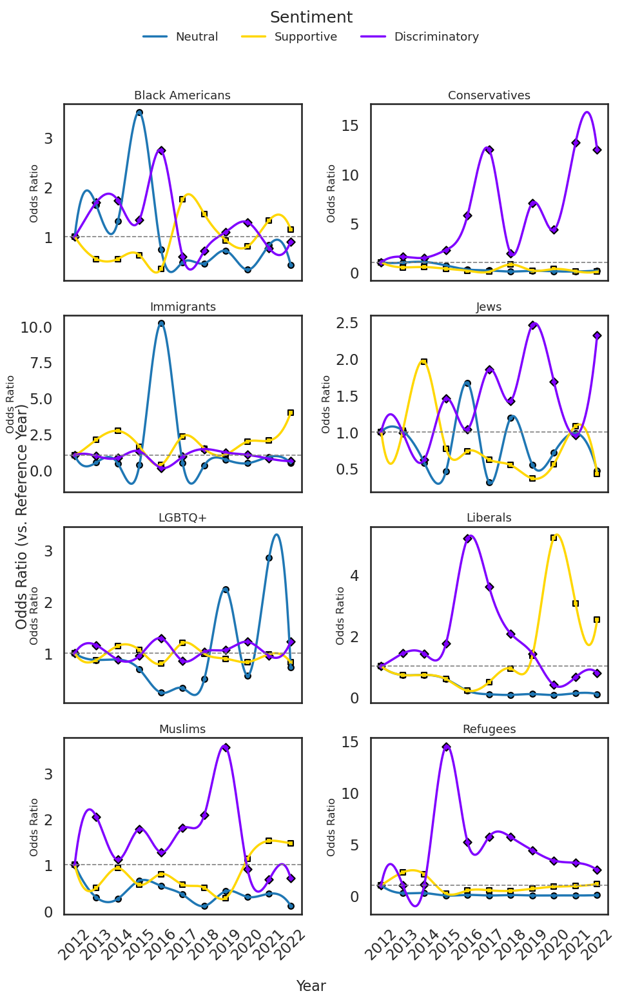

In [280]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import make_interp_spline

# ---------------------------------------------------
# 1️⃣  Compute odds ratio table per MappedGroup
# ---------------------------------------------------

plot_data = []

for group in df['MappedGroup'].unique():
    subset = df[df['MappedGroup'] == group]

    # Count Sentiment per year
    counts = subset.groupby(['year', 'Sentiment']).size().unstack(fill_value=0)
    counts = counts.replace(0, 1)  # Avoid zero-division
    counts['Total'] = counts.sum(axis=1)

    # Compute proportions and odds
    for sentiment in ['Supportive', 'Discriminatory', 'Neutral']:
        if sentiment not in counts.columns:
            counts[sentiment] = 1
        counts[f'P_{sentiment}'] = counts[sentiment] / counts['Total']
        counts[f'Odds_{sentiment}'] = counts[f'P_{sentiment}'] / (1 - counts[f'P_{sentiment}'])

    # Reference year
    ref_year = counts.index.min()

    # Compute odds ratios vs reference year
    for sentiment in ['Supportive', 'Discriminatory', 'Neutral']:
        counts[f'OR_{sentiment}'] = counts[f'Odds_{sentiment}'] / counts.loc[ref_year, f'Odds_{sentiment}']

        # Store in long format
        for year, or_val in zip(counts.index, counts[f'OR_{sentiment}']):
            plot_data.append({
                'MappedGroup': group,
                'year': year,
                'Sentiment': sentiment,
                'Odds_Ratio': or_val,
                'Reference_Year': ref_year
            })

plot_df = pd.DataFrame(plot_data)

# ---------------------------------------------------
# 2️⃣  Plot all groups in a 4-column grid
# ---------------------------------------------------

groups = sorted(plot_df['MappedGroup'].unique())
ncols = 2
nrows = int(np.ceil(len(groups) / ncols))

sns.set(style="white", context="talk", font_scale=1.0)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5*ncols, 4*nrows), sharex=True, sharey=False)
axes = axes.flatten()

# 🎨 Define custom colors and markers
colors = {
    'Neutral': '#1f77b4',          # blue
    'Supportive': '#ffd700',       # yellow-gold
    'Discriminatory': '#8000ff'    # purple
}

markers = {
    'Neutral': 'o',          # circle
    'Supportive': 's',       # square
    'Discriminatory': 'D'    # diamond
}

for i, group in enumerate(groups):
    ax = axes[i]
    subset = plot_df[plot_df['MappedGroup'] == group]

    for sentiment in ['Neutral', 'Supportive', 'Discriminatory']:
        sub = subset[subset['Sentiment'] == sentiment].sort_values(by='year')
        x = sub['year'].values
        y = sub['Odds_Ratio'].values

        if len(x) >= 4:
            x_smooth = np.linspace(x.min(), x.max(), 300)
            spline = make_interp_spline(x, y, k=3)
            y_smooth = spline(x_smooth)
            ax.plot(
                x_smooth, y_smooth, color=colors[sentiment],
                linewidth=2.5, label=sentiment
            )
            # Add discrete marker points
            ax.scatter(x, y, color=colors[sentiment], s=40, marker=markers[sentiment], edgecolor='black')
        else:
            ax.plot(
                x, y, color=colors[sentiment], marker=markers[sentiment],
                markersize=6, linewidth=2.5, label=sentiment
            )

    # Reference line
    ax.axhline(1, color='gray', linestyle='--', lw=1.2)

    # Style
    ax.set_title(group, fontsize=13)
    ax.set_xticks(sorted(subset['year'].unique()))
    ax.tick_params(axis='x', labelrotation=45)
    ax.set_xlabel("")
    ax.set_ylabel("Odds Ratio", fontsize=12)

# Remove extra empty axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Shared axis labels
fig.text(0.5, 0.04, "Year", ha='center', fontsize=16)
fig.text(0.04, 0.5, "Odds Ratio (vs. Reference Year)", va='center', rotation='vertical', fontsize=16)

# Single legend on top
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, fontsize=13, title="Sentiment", frameon=False)

plt.tight_layout(rect=[0, 0.05, 1, 0.93])
#plt.suptitle("Yearly Odds Ratio Trends by Target Group", fontsize=18, y=0.99)
plt.savefig("odds_ratio_trends_all_groups_grid_colored_markers.pdf", dpi=300, bbox_inches="tight")
plt.show()


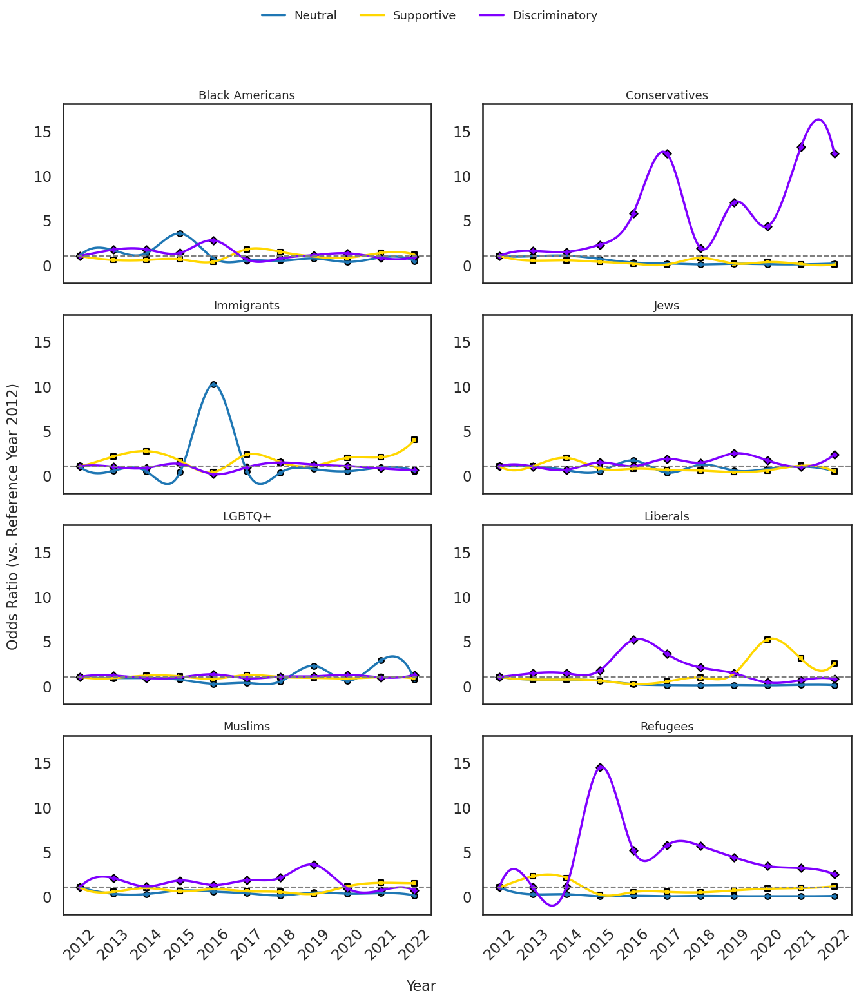

In [287]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import make_interp_spline

# ---------------------------------------------------
# 1️⃣  Compute odds ratio table per MappedGroup
# ---------------------------------------------------

plot_data = []

for group in df['MappedGroup'].unique():
    subset = df[df['MappedGroup'] == group]

    # Count Sentiment per year
    counts = subset.groupby(['year', 'Sentiment']).size().unstack(fill_value=0)
    counts = counts.replace(0, 1)  # Avoid zero-division
    counts['Total'] = counts.sum(axis=1)

    # Compute proportions and odds
    for sentiment in ['Supportive', 'Discriminatory', 'Neutral']:
        if sentiment not in counts.columns:
            counts[sentiment] = 1
        counts[f'P_{sentiment}'] = counts[sentiment] / counts['Total']
        counts[f'Odds_{sentiment}'] = counts[f'P_{sentiment}'] / (1 - counts[f'P_{sentiment}'])

    # Reference year
    ref_year = counts.index.min()

    # Compute odds ratios vs reference year
    for sentiment in ['Supportive', 'Discriminatory', 'Neutral']:
        counts[f'OR_{sentiment}'] = counts[f'Odds_{sentiment}'] / counts.loc[ref_year, f'Odds_{sentiment}']

        for year, or_val in zip(counts.index, counts[f'OR_{sentiment}']):
            plot_data.append({
                'MappedGroup': group,
                'year': year,
                'Sentiment': sentiment,
                'Odds_Ratio': or_val,
                'Reference_Year': ref_year
            })

plot_df = pd.DataFrame(plot_data)

# ---------------------------------------------------
# 2️⃣  Plot all groups in a 4-column grid (fixed Y-scale)
# ---------------------------------------------------

groups = sorted(plot_df['MappedGroup'].unique())
ncols = 2
nrows = int(np.ceil(len(groups) / ncols))

sns.set(style="white", context="talk", font_scale=1.0)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(7*ncols, 4*nrows), sharex=True)
axes = axes.flatten()

# 🎨 Custom colors + markers
colors = {
    'Neutral': '#1f77b4',          # blue
    'Supportive': '#ffd700',       # yellow-gold
    'Discriminatory': '#8000ff'    # purple
}

markers = {
    'Neutral': 'o',
    'Supportive': 's',
    'Discriminatory': 'D'
}

# Find global y-limits for consistent scale
ymin = plot_df['Odds_Ratio'].min()
ymax = plot_df['Odds_Ratio'].max()

# Clip extreme outliers if needed
ymin = max(0, ymin)
ymax = min(ymax, 5)  # optional: cap to keep visualization readable

for i, group in enumerate(groups):
    ax = axes[i]
    subset = plot_df[plot_df['MappedGroup'] == group]

    for sentiment in ['Neutral', 'Supportive', 'Discriminatory']:
        sub = subset[subset['Sentiment'] == sentiment].sort_values(by='year')
        x = sub['year'].values
        y = sub['Odds_Ratio'].values

        if len(x) >= 4:
            x_smooth = np.linspace(x.min(), x.max(), 300)
            spline = make_interp_spline(x, y, k=3)
            y_smooth = spline(x_smooth)
            ax.plot(
                x_smooth, y_smooth, color=colors[sentiment],
                linewidth=2.5, label=sentiment
            )
            ax.scatter(x, y, color=colors[sentiment],
                       s=40, marker=markers[sentiment], edgecolor='black')
        else:
            ax.plot(
                x, y, color=colors[sentiment], marker=markers[sentiment],
                markersize=6, linewidth=2.5, label=sentiment
            )

    # Reference line
    ax.axhline(1, color='gray', linestyle='--', lw=1.5)

    # Fixed Y-axis scale for all subplots
    ax.set_ylim(-2, 18)

    # Style
    ax.set_title(group, fontsize=13)
    ax.set_xticks(sorted(subset['year'].unique()))
    ax.tick_params(axis='x', labelrotation=45)
    ax.set_xlabel("")
    ax.set_ylabel("")

# Remove empty axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Shared axis labels
fig.text(0.5, 0.04, "Year", ha='center', fontsize=16)
fig.text(0.04, 0.5, "Odds Ratio (vs. Reference Year 2012)", va='center', rotation='vertical', fontsize=16)

# Single legend on top
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3,
           fontsize=13, frameon=False)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.93])
#plt.suptitle("Yearly Odds Ratio Trends by Target Group", fontsize=18, y=0.99)
plt.savefig("odds_ratio_trends_all_groups_fixedY.pdf", dpi=300, bbox_inches="tight")
plt.show()


In [288]:
df

,_id,pure_text,rt_text,tweet_created_at,tweet_id,user_id,user_created_at,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup,year
0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,1.528506e+18,1.317928e+18,2020-10-18 20:37:29,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Discriminatory,Anger,Black Americans,2022
1,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,1.279466e+18,1.268650e+18,2020-06-04 21:06:30,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
2,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,8.054107e+17,2.250714e+08,2010-12-10 16:12:28,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Supportive,Gratitude,Muslims,2016
3,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,1.279357e+18,7.040012e+17,2016-02-28 17:52:10,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Discriminatory,Anger,Black Americans,2020
4,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,1.307455e+18,1.103778e+09,2013-01-19 14:02:45,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,7.864829e+17,1.494789e+09,2013-06-09 06:01:42,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Discriminatory,Anger,Liberals,2016
153242,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,1.163786e+18,3.615616e+07,2009-04-28 19:27:50,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Discriminatory,Anger,LGBTQ+,2019
153243,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,1.292584e+18,1.250584e+18,2020-04-16 00:37:37,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020
153244,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,1.329314e+18,7.993342e+17,2016-11-17 19:31:40,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020


In [289]:
import pandas as pd
import numpy as np
from collections import Counter
import re

# Assuming df has: ['tweet_created_at', 'Group', 'pure_text']
# and you already have labmt_dict loaded as {word: happiness_score}

# --- Step 1: Prepare month column ---
df['tweet_created_at'] = pd.to_datetime(df['tweet_created_at'])
df['Month'] = df['tweet_created_at'].dt.to_period('M').astype(str)  # 'YYYY-MM'

# --- Step 2: Function to calculate happiness score for text ---
def compute_happiness(text, score_dict):
    # simple word tokenization and cleaning
    words = re.findall(r'\b[a-z]+\b', str(text).lower())
    scores = [score_dict[w] for w in words if w in score_dict]
    return np.mean(scores) if scores else np.nan

# --- Step 3: Combine texts month-wise and group-wise ---
group_corpora = (
    df.groupby(['Sentiment', 'Month'])['pure_text']
    .apply(lambda texts: ' '.join(texts.astype(str)))
    .reset_index(name='joined_text')
)

# --- Step 4: Compute happiness for each group-month ---
group_corpora['happiness_score'] = group_corpora['joined_text'].apply(lambda x: compute_happiness(x, labmt_dict))

# --- Step 5: Clean and view ---
result = group_corpora[['Month', 'Sentiment', 'happiness_score']].sort_values(['Sentiment', 'Month'])
print(result.head(20))


/tmp/ipykernel_1298407/1039258101.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['tweet_created_at'] = pd.to_datetime(df['tweet_created_at'])
/tmp/ipykernel_1298407/1039258101.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Month'] = df['tweet_created_at'].dt.to_period('M').astype(str)  # 'YYYY-MM'


      Month       Sentiment  happiness_score
0   2012-01  Discriminatory         5.716970
1   2012-02  Discriminatory         5.413991
2   2012-03  Discriminatory         5.459247
3   2012-04  Discriminatory         5.432026
4   2012-05  Discriminatory         5.348464
5   2012-06  Discriminatory         5.445240
6   2012-07  Discriminatory         5.408263
7   2012-08  Discriminatory         5.238452
8   2012-09  Discriminatory         5.491371
9   2012-10  Discriminatory         5.413105
10  2012-11  Discriminatory         5.501239
11  2012-12  Discriminatory         5.539367
12  2013-01  Discriminatory         5.749452
13  2013-02  Discriminatory         5.504548
14  2013-03  Discriminatory         5.437666
15  2013-04  Discriminatory         5.235171
16  2013-05  Discriminatory         5.294325
17  2013-06  Discriminatory         5.450885
18  2013-07  Discriminatory         5.420266
19  2013-08  Discriminatory         5.424066


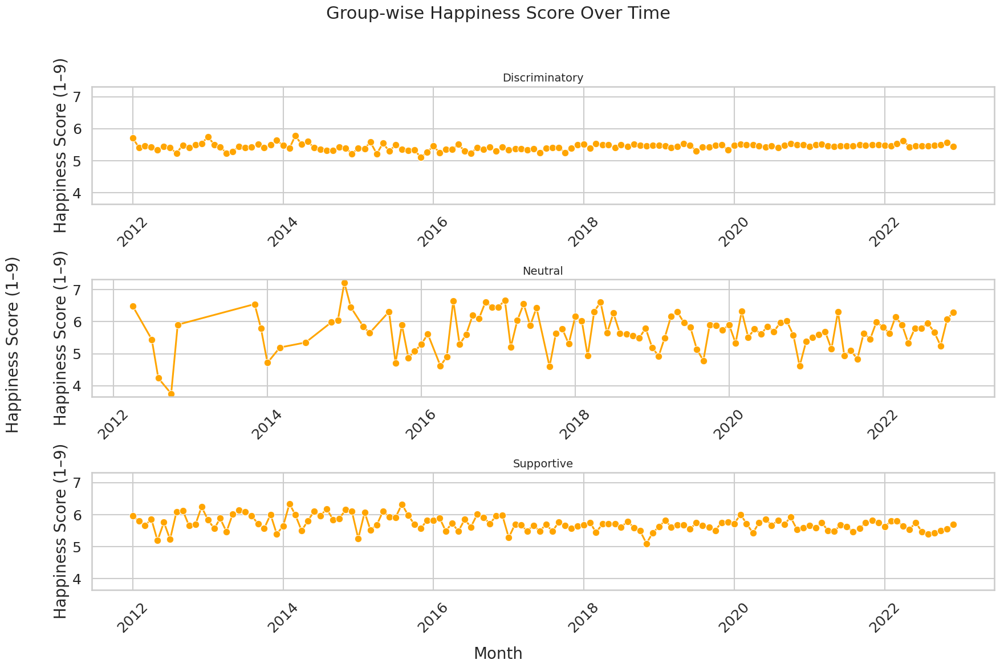

In [290]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Make sure Month is datetime
result['Month'] = pd.to_datetime(result['Month'])
result = result.sort_values(['Sentiment', 'Month'])

sns.set_context("talk", font_scale=1.1)
sns.set_style("whitegrid")

# Get unique groups
groups = sorted(result['Sentiment'].unique())
ncols = 1
nrows = (len(groups) + ncols - 1) // ncols

# Create figure
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4))
axes = axes.flatten()

for i, grp in enumerate(groups):
    ax = axes[i]
    sub = result[result['Sentiment'] == grp]

    sns.lineplot(
        data=sub,
        x='Month',
        y='happiness_score',
        marker='o',
        color='#FFA500',  # orange
        linewidth=2.2,
        ax=ax
    )

    ax.set_title(grp, fontsize=14)
    ax.set_xlabel("")
    ax.set_ylabel("Happiness Score (1–9)")
    ax.set_ylim(result['happiness_score'].min() - 0.1, result['happiness_score'].max() + 0.1)
    ax.tick_params(axis='x', rotation=45)

# Remove unused axes if groups < nrows*ncols
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Shared labels and layout
fig.text(0.5, 0.04, "Month", ha='center', fontsize=20)
fig.text(0.02, 0.5, "Happiness Score (1–9)", va='center', rotation='vertical', fontsize=20)
fig.suptitle("Group-wise Happiness Score Over Time", fontsize=22, y=0.995)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.97])
plt.savefig("groupwise_happiness_score_over_time.pdf", dpi=300, bbox_inches="tight")
plt.show()


In [292]:
result.columns

Index(['Month', 'Sentiment', 'happiness_score'], dtype='object')

In [294]:
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# # Drop rows with missing values
# df_clean = df.dropna(subset=['scaled_happiness', 'CommentType', 'Group', 'Sentiment', 'Emotion'])

# Step 1: Build the formula (categorical variables are automatically dummy-encoded)
formula = 'happiness_score ~  C(Sentiment)-1 '

# Step 2: Fit the OLS model
model = smf.ols(formula=formula, data=result).fit()

# Step 3: Print full summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        happiness_score   R-squared:                       0.127
Model:                            OLS   Adj. R-squared:                  0.123
Method:                 Least Squares   F-statistic:                     26.57
Date:                Mon, 27 Oct 2025   Prob (F-statistic):           1.69e-11
Time:                        17:35:36   Log-Likelihood:                -127.71
No. Observations:                 367   AIC:                             261.4
Df Residuals:                     364   BIC:                             273.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
C(Sentiment)[Dis

In [297]:
#Topic model analysis

In [298]:
df.columns

Index(['_id', 'pure_text', 'rt_text', 'tweet_created_at', 'tweet_id',
       'user_id', 'user_created_at', 'fastText_lang', 'fastText_conf',
       'reply_to_id', 'LLM_Label', 'CommentType', 'TargetedGroup', 'Sentiment',
       'Emotion', 'MappedGroup', 'year', 'Month'],
      dtype='object')

In [299]:
pip install bertopic sentence-transformers umap hdbscan


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Defaulting to user installation because normal site-packages is not writeable
  Preparing metadata (setup.py) ... done
  Created wheel for umap: filename=umap-0.1.1-py3-none-any.whl size=3543 sha256=8eea4c3ea49c7cd3d393298876b5d48e785cd78942fb7f51ad1ff1045b363599
  Stored in directory: /gpfs1/home/t/p/tprama/.cache/pip/wheels/48/4a/1c/1d511cbb0413a448d8546e958f8e82b98d9bb493038d19ece2
Successfully built umap
Note: you may need to restart the kernel to use updated packages.


In [300]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
import pandas as pd


AttributeError: module 'openai' has no attribute 'OpenAI'

In [301]:
# Drop duplicates and NaNs
texts = df['pure_text'].dropna().drop_duplicates().astype(str).tolist()

print(f"Number of tweets used for topic modeling: {len(texts)}")


Number of tweets used for topic modeling: 106132


In [302]:
# multilingual or english only model
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")   # fast, English
# or multilingual: "paraphrase-multilingual-MiniLM-L12-v2"

topic_model = BERTopic(
    embedding_model=embedding_model,
    top_n_words=10,       # number of top words per topic
    min_topic_size=50,    # smaller = more granular topics
    verbose=True
)


NameError: name 'SentenceTransformer' is not defined

k=5, Silhouette Score=0.0088
k=10, Silhouette Score=0.0133
k=15, Silhouette Score=0.0144
k=20, Silhouette Score=0.0163
k=25, Silhouette Score=0.0157
k=30, Silhouette Score=0.0174


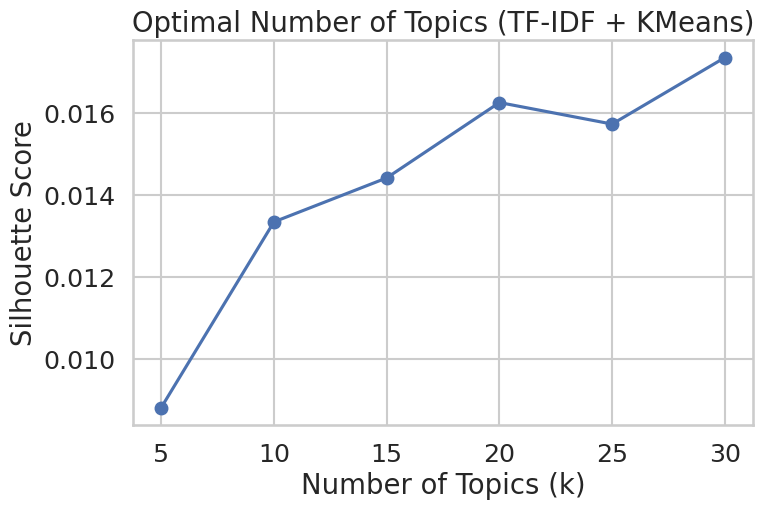

In [305]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np

# Prepare text data
texts = df['pure_text'].dropna().astype(str).tolist()

# TF-IDF representation
vectorizer = TfidfVectorizer(
    max_df=0.8,
    min_df=10,
    max_features=5000,
    stop_words='english',
    ngram_range=(1, 2)
)
tfidf = vectorizer.fit_transform(texts)

# Try different topic numbers
k_values = range(5, 31, 5)
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(tfidf)
    score = silhouette_score(tfidf, labels)
    silhouette_scores.append(score)
    print(f"k={k}, Silhouette Score={score:.4f}")

# Plot Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker='o')
plt.xlabel("Number of Topics (k)")
plt.ylabel("Silhouette Score")
plt.title("Optimal Number of Topics (TF-IDF + KMeans)")
plt.grid(True)
plt.show()


In [23]:
df

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,...,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup,year
0,1.0,1.0,31562.0,53734.0,112688.0,34389.0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,...,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2022
1,2.0,2.0,31563.0,6419.0,6516.0,6516.0,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,...,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020
2,3.0,3.0,31564.0,21989.0,487.0,487.0,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,...,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Positive,Gratitude,Muslims,2016
3,4.0,4.0,31565.0,26907.0,422.0,422.0,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,...,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2020
4,7.0,7.0,31568.0,19884.0,56211.0,39730.0,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,...,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,NaN,30760.0,30927.0,61861.0,11284.0,2083.0,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,...,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Negative,Anger,Liberals,2016
153242,NaN,30761.0,30928.0,61862.0,44732.0,14321.0,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,...,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Negative,Anger,LGBTQ+,2019
153243,NaN,30762.0,30929.0,61863.0,54343.0,23932.0,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,...,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020
153244,NaN,30763.0,30930.0,61864.0,38158.0,7747.0,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,...,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020


In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

texts = df['pure_text'].dropna().astype(str).tolist()

vectorizer = TfidfVectorizer(
    max_df=0.8,
    min_df=10,
    max_features=5000,
    stop_words='english',
    ngram_range=(1, 2)
)
tfidf = vectorizer.fit_transform(texts)

k = 25  # or 30
km = KMeans(n_clusters=k, random_state=42, n_init=40)
km.fit(tfidf)

df['Topic'] = km.labels_
terms = vectorizer.get_feature_names_out()

for i in range(k):
    top_terms = [terms[ind] for ind in km.cluster_centers_[i].argsort()[-40:][::-1]]
    print(f"Topic {i}: {', '.join(top_terms)}")


Topic 0: liberals, rt, https, people, amp, just, trump, like, conservatives, liberal, going, liberals going, stupid, think, liberals just, realdonaldtrump, know, trudeau, trying, dbongino, country, america, time, hate, rt dbongino, liberals trying, say, obama, really, liberals stupid, http, want, crazy, doing, wrong, saying, world, real, good, dumb
Topic 1: don, want, rt, don want, republicans, know, don know, people, care, don care, https, like, liberals, think, just, amp, gop, left, don think, vote, don like, need, say, understand, let, going, people don, trump, don understand, immigrants, make, right, don let, believe, country, don need, america, work, stop, don forget
Topic 2: democrats, republicans, rt, https, amp, house, democrats republicans, vote, gop, realdonaldtrump, like, people, just, trump, america, want, trying, country, rt realdonaldtrump, senate, going, really, need, liberals, power, impeachment, time, republican, american, win, biden, election, don, fight, party, stop,

In [ ]:
# Topic 0: liberals, rt, https, people, amp, just, trump, like, conservatives, liberal, going, liberals going, stupid, think, liberals just, realdonaldtrump, know, trudeau, trying, dbongino, country, america, time, hate, rt dbongino, liberals trying, say, obama, really, liberals stupid, http, want, crazy, doing, wrong, saying, world, real, good, dumb
# Topic 1: don, want, rt, don want, republicans, know, don know, people, care, don care, https, like, liberals, think, just, amp, gop, left, don think, vote, don like, need, say, understand, let, going, people don, trump, don understand, immigrants, make, right, don let, believe, country, don need, america, work, stop, don forget
# Topic 2: democrats, republicans, rt, https, amp, house, democrats republicans, vote, gop, realdonaldtrump, like, people, just, trump, america, want, trying, country, rt realdonaldtrump, senate, going, really, need, liberals, power, impeachment, time, republican, american, win, biden, election, don, fight, party, stop, voting, left, fighting, doing
# Topic 3: refugees, migrants, https, rt, syrian, border, amp, people, asylum, welcome, syrian refugees, refugees welcome, http, europe, refugee, fleeing, iraqi, illegal, like, illegal migrants, country, thousands, asylum seekers, seekers, says, countries, eu, uk, children, mexico, terrorists, trying, 000, afghan, world, refugees fleeing, people refugees, seeking, migrant, coming
# Topic 4: illegal, illegal immigrants, immigrants, rt, https, border, citizens, american, legal, country, just, american citizens, amp, better, law, realdonaldtrump, america, immigrants illegal, criminals, immigration, people, come, wall, realdonaldtrump illegal, biden, want, 000, rt realdonaldtrump, saying, illegals, americans, legal immigrants, vote, like, built refitted, centers just, come problems, unhappy conditions, refitted detentions, conditions quickly
# Topic 5: muslim, muslims, https, rt, islam, allah, terrorist, muslim refugees, religion, countries, refugees, india, muslim countries, hindu, indian, amp, good, people, non, just, race, anti, like, anti muslim, born, biggest, ask, life, does, prophet, world, women, http, ban, migrants, jews, hindus, says, say, country
# Topic 6: evangelical, christian, christians, rt, https, evangelical christians, trump, white evangelical, evangelical christian, white, god, christianity, leaders, evangelical leaders, church, jesus, amp, support, people, women, like, conservative, http, anti, just, man, pastor, president, evangelical leader, evangelical christianity, leader, life, trump evangelical, vote, porn, donald, evangelical voters, voters, realdonaldtrump, donald trump
# Topic 7: rt, libs, https, maga, amp, foreigners, people, jew, like, just, immigrant, country, realdonaldtrump, america, billion, know, going, american, did, black, let, time, refugee, man, think, good, vote, state, need, stop, look, saying, want, getting, ve, said, really, new, anti, make
# Topic 8: trump, republicans, rt, president, https, donald trump, donald, president trump, amp, trump republicans, gop, just, left, biden, america, liberals, senate, people, going, maga, election, house, vote, trump https, trying, like, campaign, republican, russia, putin, supporters, country, americans, said, office, trump supporters, realdonaldtrump, did, saying, support
# Topic 9: white, people, white people, white liberals, rt, black, https, supremacy, white supremacy, liberals, supremacist, white supremacist, republicans, white house, house, men, white supremacists, supremacists, white men, blacks, just, amp, black people, gop, racist, racism, america, americans, said, think, immigrants, walked, like, black americans, maga, trump, hate, killed, hundreds, day
# Topic 10: illegals, rt, https, border, illegal, amp, citizens, country, legal, american, illegals immigrants, ice, people, america, children, immigrants, wall, like, americans, vote, freeloaders, just, coming, getting, charliekirk11, illegals getting, realdonaldtrump, 000, democrats, rt charliekirk11, sick, stop, does, voting, free, allowed, law, know, want, given
# Topic 11: left, rt, https, amp, trump, radical, left trying, trying, people, radical left, just, like, america, realdonaldtrump, going, hate, country, far left, far, left going, losing, charliekirk11, left losing, president, media, know, conservatives, think, speech, doing, rt charliekirk11, biden, make, twitter, control, want, conservative, time, elonmusk, dineshdsouza
# Topic 12: immigrants, rt, https, undocumented, undocumented immigrants, people, immigration, amp, country, trump, http, canada, like, america, taxes, rapists, problem, brown, immigrant, brown https, just, legal, wrong immigrants, black brown, immigrants black, guess immigration, rt wolfnae, immigration wrong, wolfnae, xrnr8zdzec, wolfnae guess, https xrnr8zdzec, wrong, black, immigrants problem, guess, ice, criminals, legal immigrants, pay
# Topic 13: gop, rt, https, trump, amp, just, vote, people, america, democracy, republicans, election, like, trying, realdonaldtrump, going, gop trying, complicit, time, entire, country, gop going, doing, power, entire gop, american, know, dems, voting, pro, gop complicit, russia, today, putin, republican, think, corrupt, gop just, gop doing, voters
# Topic 14: right, left, rt, https, far, far right, right wing, wing, people, republicans, just, picture, like, liberals, amp, right https, guy, trump, left right, woman, gop, know, man, think, going, vote, way, want, right right, http, wrong, believe, anti, media, conservative, doing, thing, girl, picture right, literally
# Topic 15: antifa, terrorist, organization, rt, terrorist organization, group, https, domestic, antifa terrorist, domestic terrorist, fascism, terror, violence, antifa domestic, dbongino antifa, dbongino, rt dbongino, fascist, violent, terror group, terrorist group, portland, amp, idea, realdonaldtrump, realjameswoods, rt realjameswoods, blm, kkk, just, biden, antifa just, realdonaldtrump antifa, myth, people, antifa fascist, democrat, trump, america, fbi
# Topic 16: party, gop, gop party, rt, republicans, republican, republican party, https, republicans party, trump, political, political party, party https, amp, longer, democratic, white, gop longer, democratic party, people, democrat party, democrat, fascist, like, party trump, just, country, democrats, pro, american, power, democracy, putin, anti, america, party gop, hate, realdonaldtrump, new, today
# Topic 17: muslims, https, terrorists, muslims terrorists, islam, india, rt, people, amp, quran, religion, hindus, like, ep3_m amp, ep3_m, amp https, world, indian, muslims sure, muslims muslims, sure quran, non, http, non muslims, sure, islamic, indian muslims, christians, just, china, allah, hindu, terrorist, killed, think, say, majority, good, don, pakistan
# Topic 18: blacks, whites, rt, https, black, white, think, like, people, killed, amp, just, http, race, don, think blacks, hispanics, population, blacks killed, police, cops, likely, racism, america, criminals, say, racist, going, said, stupid, believe, crime, killing, africa, know, human, world, hillary, biggest, violent
# Topic 19: jews, https, israel, rt, jewish, people, jew, anti, hitler, amp, zionists, white, antisemitism, american jews, like, world, just, http, american, zionist, christians, palestinians, muslims, said, israeli, antisemitic, nazis, disloyal, zionism, semitic, trump, real, jews white, judaism, race, think, semitism, palestine, hate, don
# Topic 20: jobs, taking jobs, immigrants, taking, stealing, immigrants taking, stealing jobs, immigrants stealing, say immigrants, jobs time, arjanaejupi, arjanaejupi americans, rt arjanaejupi, time shine, shine, americans say, say, parents, rt, time, americans, job, like immigrants, work, ll fight, eyed, children immigrants, behalf, shit like, spaces, english, talked, trump supporters, road, lack, supporters, https, age, people, ll
# Topic 21: racist, rt, https, black, blacks, republicans racist, republicans, liberals, people, white, racist https, trump, think, amp, left, just, democrats, liberals racist, gop, called, id, say, realdonaldtrump, like, doesn, trump racist, said, immigrants, black people, racism, calling, ve, called racist, voter id, stupid, americans, man, don, voter, saying
# Topic 22: republicans, rt, https, vote, people, trying, just, going, republicans trying, voting, house, election, like, senate, republicans going, biden, democracy, amp, realdonaldtrump, republican, doing, http, america, american, want, think, rights, president, country, women, make, senate republicans, health, care, saying, house republicans, know, dems, voters, away
# Topic 23: social security, social, security, medicare, security medicare, republicans, medicaid, coming, rt, cut, vote, republicans coming, https, vote nov, remember evangelical, democrats took, pledge allegiance, mistake, pledge, allegiance, realdonaldtrump democrats, benefits, gop, nov, convention, purpose, amp, remember, took, wasn, thought, evangelical christians, going, national, word, rt realdonaldtrump, christians, democrat, democrats, cuts
# Topic 24: black, black americans, americans, rt, https, white, trump, police, people, amp, democrats, don, american, realdonaldtrump, president, africans, just, like, racism, americans https, america, racist, history, biden, vote, african, years, reparations, black people, want, slavery, country, realcandaceo, know, time, think, white americans, say, need, voting

In [25]:
df['Topic'] = km.labels_

In [115]:
df=pd.read_csv("topic_modeling_results.csv")
df

,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,tweet_id,user_id,user_created_at,fastText_lang,fastText_conf,...,TargetedGroup,Sentiment,Emotion,MappedGroup,year,Topic,text_clean,LDA_topic,NMF_topic,LSA_topic
0,0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,1.528506e+18,1.317928e+18,2020-10-18 20:37:29,en,0.98,...,Black Americans,Negative,Anger,Black Americans,2022,GOP Corruption,ridiculously irresponsible use large platform ...,5,6,0
1,1,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,1.279466e+18,1.268650e+18,2020-06-04 21:06:30,en,0.93,...,Conservatives,Negative,Anger,Conservatives,2020,Evangelical Trump,amazing sports commentator willing say blm man...,9,12,0
2,2,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,8.054107e+17,2.250714e+08,2010-12-10 16:12:28,en,0.65,...,Muslims,Positive,Gratitude,Muslims,2016,Evangelical Trump,price evangelical christian soul,7,12,12
3,3,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,1.279357e+18,7.040012e+17,2016-02-28 17:52:10,en,0.95,...,Black Americans,Negative,Anger,Black Americans,2020,Evangelical Trump,yeah mean massive gap voting white evangelical...,3,12,12
4,4,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,1.307455e+18,1.103778e+09,2013-01-19 14:02:45,en,0.98,...,Conservatives,Negative,Anger,Conservatives,2020,Voter Apathy,republicans showing america scruples morals cr...,14,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152724,153241,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,7.864829e+17,1.494789e+09,2013-06-09 06:01:42,en,0.96,...,Liberals,Negative,Anger,Liberals,2016,Political Conflict,classical liberals actually agreement lot righ...,12,2,2
152725,153242,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,1.163786e+18,3.615616e+07,2009-04-28 19:27:50,en,0.90,...,LGBTQ+,Negative,Anger,LGBTQ+,2019,Racism Accusals,left resisting racist president supporting tru...,0,8,8
152726,153243,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,1.292584e+18,1.250584e+18,2020-04-16 00:37:37,en,0.70,...,Conservatives,Negative,Anger,Conservatives,2020,Radical Left,left truly embarrassing,2,11,2
152727,153244,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,1.329314e+18,7.993342e+17,2016-11-17 19:31:40,en,0.90,...,Conservatives,Negative,Anger,Conservatives,2020,Radical Left,left using government force lockdowns ruin liv...,7,11,0


In [119]:
from pathlib import Path
from collections import Counter
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency, norm
from statsmodels.stats.multitest import multipletests
from IPython.display import display

DATA_FILE = 'topic_modeling_results.csv'
LEXICON_FILE = 'labMT-english.csv'  # Change to 'labMT2.txt' if necessary
OUT = Path('rq4_pooled_topic_results')
OUT.mkdir(parents=True, exist_ok=True)

TOPIC_COL = 'Topic'
GROUP_COL = 'MappedGroup'
TEXT_COL = 'pure_text'
STOP_LENS = (4.0, 6.0)   # RQ2 method: remove scores 4 through 6, inclusive
MIN_CELL_TWEETS = 2      # for year-adjusted regression ONLY
MIN_CELL_MATCHED = 20   # for year-adjusted regression ONLY

df = pd.read_csv(DATA_FILE)
print('Rows:', len(df), '\nColumns:', df.columns.tolist())
display(df.head(3))

Rows: 152729 
Columns: ['Unnamed: 0', '_id', 'pure_text', 'rt_text', 'tweet_created_at', 'tweet_id', 'user_id', 'user_created_at', 'fastText_lang', 'fastText_conf', 'reply_to_id', 'LLM_Label', 'CommentType', 'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup', 'year', 'Topic', 'text_clean', 'LDA_topic', 'NMF_topic', 'LSA_topic']


,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,tweet_id,user_id,user_created_at,fastText_lang,fastText_conf,...,TargetedGroup,Sentiment,Emotion,MappedGroup,year,Topic,text_clean,LDA_topic,NMF_topic,LSA_topic
0,0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,1.528506e+18,1.317928e+18,2020-10-18 20:37:29,en,0.98,...,Black Americans,Negative,Anger,Black Americans,2022,GOP Corruption,ridiculously irresponsible use large platform ...,5,6,0
1,1,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,1.279466e+18,1.268650e+18,2020-06-04 21:06:30,en,0.93,...,Conservatives,Negative,Anger,Conservatives,2020,Evangelical Trump,amazing sports commentator willing say blm man...,9,12,0
2,2,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,8.054107e+17,2.250714e+08,2010-12-10 16:12:28,en,0.65,...,Muslims,Positive,Gratitude,Muslims,2016,Evangelical Trump,price evangelical christian soul,7,12,12


In [120]:
def load_labmt(path):
    path = Path(path)
    if not path.exists():
        options = [p for p in ('labMT-english.csv', 'labMT2.txt') if Path(p).exists()]
        raise FileNotFoundError(
            f'Could not find {path}. Place your original English labMT file next to '
            f'the notebook. Available suggested lexicons: {options}. '
            'Do not substitute model-generated scores for the labMT lexicon.'
        )
    # Supports a 2+ column tab/CSV file, including files with a header row.
    lex = pd.read_csv(path, sep=None, engine='python', header=None,
                      comment='#', on_bad_lines='skip', encoding='utf-8-sig')
    if lex.shape[1] < 2:
        raise ValueError('Expected labMT file columns: word, happiness_average')
    lex = lex.iloc[:, :2].copy()
    lex.columns = ['word', 'h']
    lex['word'] = lex['word'].astype(str).str.strip().str.lower()
    lex['h'] = pd.to_numeric(lex['h'], errors='coerce')
    lex = lex[lex['word'].str.fullmatch(r'[a-z]+', na=False)]
    lex = lex[lex['h'].between(1, 9)]
    if STOP_LENS is not None:
        a, b = STOP_LENS
        lex = lex[(lex['h'] < a) | (lex['h'] > b)]
    lex = lex.drop_duplicates('word')
    if len(lex) < 100:
        raise ValueError(f'Only {len(lex)} lexicon entries loaded; check file format.')
    print(f'Loaded {len(lex):,} eligible labMT words from {path}')
    return dict(zip(lex['word'], lex['h'].astype(float)))

labmt = load_labmt(LEXICON_FILE)
TOKEN_RE = re.compile(r'[a-z]+')

def get_year(frame):
    for c in ('year', 'Year'):
        if c in frame.columns:
            return pd.to_numeric(frame[c], errors='coerce')
    for c in ('tweet_created_at', 'created_at', 'tweet_date', 'date',
              'Date', 'timestamp', 'created_utc', 'datetime'):
        if c in frame.columns:
            s = frame[c]
            if pd.api.types.is_numeric_dtype(s):
                med = pd.to_numeric(s, errors='coerce').median()
                if 1900 <= med <= 2100:
                    return pd.to_numeric(s, errors='coerce')
                if med > 1e11:
                    return pd.to_datetime(s, unit='ms', errors='coerce', utc=True).dt.year
                if med > 1e8:
                    return pd.to_datetime(s, unit='s', errors='coerce', utc=True).dt.year
            return pd.to_datetime(s, utc=True, errors='coerce').dt.year
    return pd.Series(np.nan, index=frame.index, dtype=float)

required = (TOPIC_COL, GROUP_COL, TEXT_COL)
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f'Missing required columns: {missing}. Available: {list(df.columns)}')

work = df.dropna(subset=[TOPIC_COL, GROUP_COL, TEXT_COL]).copy()
work['topic_name'] = work[TOPIC_COL].astype(str).str.strip()
work['group_name'] = work[GROUP_COL].astype(str).str.strip()
work = work[(work['topic_name'] != '') & (work['group_name'] != '')]
work['year'] = get_year(work)
work['year'] = work['year'].where(work['year'].between(2012, 2022))

# Each row is a tweet–group/topic record; score its matched TOKEN TOTALS.
def score_document(text):
    counts = Counter(TOKEN_RE.findall(str(text).lower()))
    total = sum(counts.values())
    matched = sum(freq for word, freq in counts.items() if word in labmt)
    scored = sum(freq * labmt[word] for word, freq in counts.items() if word in labmt)
    return scored, matched, total

scored = [score_document(t) for t in work[TEXT_COL].astype(str)]
work[['labmt_sum', 'labmt_matched_tokens', 'all_tokens']] = pd.DataFrame(
    scored, index=work.index, columns=['labmt_sum', 'labmt_matched_tokens', 'all_tokens']
)
work['n_tweets'] = 1
print('Usable tweet records:', len(work))
print('Records with usable year:', int(work['year'].notna().sum()))
print('Total labMT matched tokens:', int(work['labmt_matched_tokens'].sum()))
print('Rows with 0 eligible labMT words:', int((work['labmt_matched_tokens'] == 0).sum()))

Loaded 3,583 eligible labMT words from labMT-english.csv
Usable tweet records: 152729
Records with usable year: 152729
Total labMT matched tokens: 1010549
Rows with 0 eligible labMT words: 3096


Chi-square(168)=384127.707, p=0, Cramer V=0.599
Expected counts <5: 0 of 200


,group,topic,observed,expected,group_topic_prevalence,overall_topic_prevalence,difference_pp,adjusted_residual,raw_p,fdr_p,overrepresented_fdr05
176,Refugees,Asylum Seekers,1718,64.697831,0.772830,0.029104,74.372567,210.138114,0.000000e+00,0.000000e+00,True
138,Liberals,Political Conflict,6263,765.707135,0.634356,0.077556,55.680065,213.874475,0.000000e+00,0.000000e+00,True
162,Muslims,Muslims India,5526,450.436839,0.468782,0.038211,43.057034,253.845559,0.000000e+00,0.000000e+00,True
85,Jews,Jews/Antisemitism,4648,372.769507,0.404772,0.032463,37.230954,234.087470,0.000000e+00,0.000000e+00,True
58,Immigrants,Immigrant Stereotypes,6372,901.010352,0.319270,0.045145,27.412515,200.051358,0.000000e+00,0.000000e+00,True
2,Black Americans,Black Reparations,10669,2715.809748,0.282092,0.071807,21.028503,182.624130,0.000000e+00,0.000000e+00,True
159,Muslims,Islam/Terrorism,2144,188.170839,0.181880,0.015963,16.591696,149.620501,0.000000e+00,0.000000e+00,True
78,Jews,Evangelical Trump,1822,329.988980,0.158669,0.028737,12.993216,86.661580,0.000000e+00,0.000000e+00,True
43,Conservatives,Republican Voters,11124,5538.066314,0.240873,0.119918,12.095478,95.795552,0.000000e+00,0.000000e+00,True
56,Immigrants,Illegal Border,2794,417.378834,0.139994,0.020913,11.908113,126.093650,0.000000e+00,0.000000e+00,True


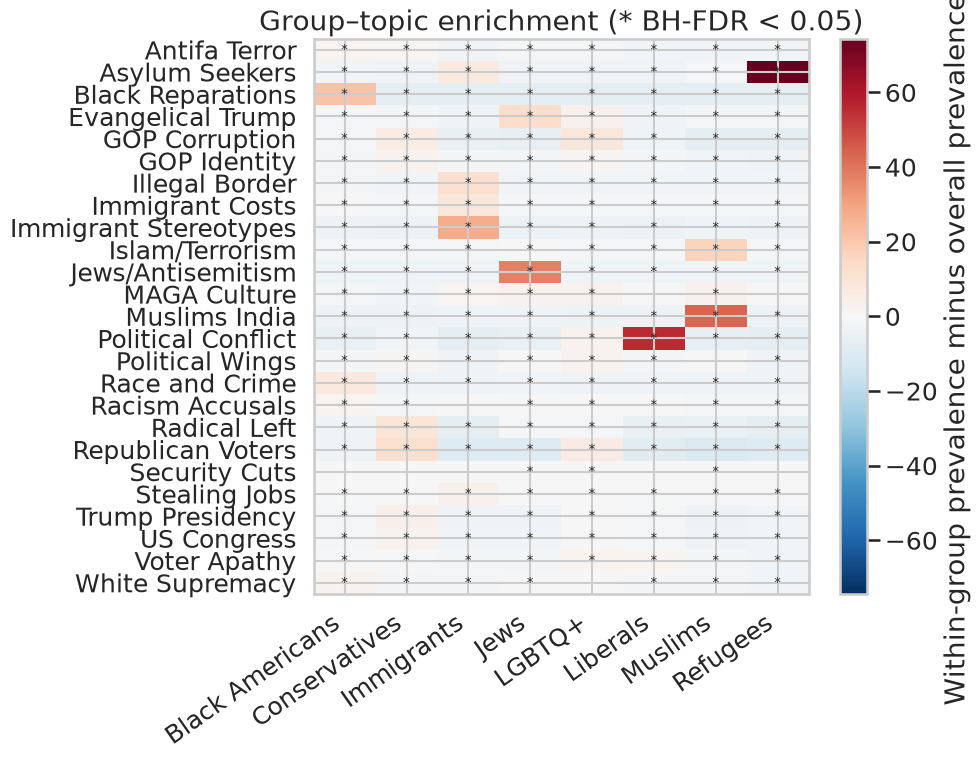

In [121]:
table = pd.crosstab(work['group_name'], work['topic_name'])
if min(table.shape) < 2:
    raise ValueError('Need at least 2 groups and 2 topics for the chi-square test.')
chi2, p, dof, expected = chi2_contingency(table.to_numpy(), correction=False)
N = table.to_numpy().sum()
row_tot = table.sum(axis=1).to_numpy()[:, None]
col_tot = table.sum(axis=0).to_numpy()[None, :]
row_p = row_tot / N
col_p = col_tot / N
adjusted_resid = (table.to_numpy() - expected) / np.sqrt(
    expected * (1 - row_p) * (1 - col_p)
)
p_raw = 2 * norm.sf(np.abs(adjusted_resid))
p_fdr = multipletests(p_raw.ravel(), method='fdr_bh')[1].reshape(p_raw.shape)
cramers_v = np.sqrt(chi2 / (N * min(table.shape[0]-1, table.shape[1]-1)))

rows = []
for i, group in enumerate(table.index):
    for j, topic in enumerate(table.columns):
        rows.append(dict(group=group, topic=topic, observed=int(table.iat[i, j]),
                         expected=float(expected[i, j]),
                         group_topic_prevalence=float(table.iat[i,j]/row_tot[i,0]),
                         overall_topic_prevalence=float(col_p[0,j]),
                         difference_pp=float(100*(table.iat[i,j]/row_tot[i,0]-col_p[0,j])),
                         adjusted_residual=float(adjusted_resid[i,j]),
                         raw_p=float(p_raw[i,j]), fdr_p=float(p_fdr[i,j]),
                         overrepresented_fdr05=bool(adjusted_resid[i,j]>0 and p_fdr[i,j]<.05)))
group_topic_stats = pd.DataFrame(rows)
group_topic_stats.to_csv(OUT/'group_topic_adjusted_residuals.csv', index=False)
table.to_csv(OUT/'group_by_topic_counts.csv')

print(f'Chi-square({dof})={chi2:.3f}, p={p:.3g}, Cramer V={cramers_v:.3f}')
print('Expected counts <5:', int((expected<5).sum()), 'of', expected.size)
if (expected<5).mean() > .20:
    warnings.warn('Many expected cells <5: consider a permutation test or merging sparse topics.')
display(group_topic_stats[group_topic_stats.overrepresented_fdr05]
        .sort_values('difference_pp', ascending=False).head(25))

values = 100 * (table.to_numpy()/row_tot - col_p)
fig, ax = plt.subplots(figsize=(max(10, table.shape[0]*1.2), max(7, table.shape[1]*.32)))
lim = max(1, np.abs(values).max())
im = ax.imshow(values.T, aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim)
ax.set_xticks(np.arange(table.shape[0]), table.index, rotation=35, ha='right')
ax.set_yticks(np.arange(table.shape[1]), table.columns)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        if p_fdr[i,j] < .05:
            ax.text(i,j, '*', ha='center',va='center',fontsize=9)
fig.colorbar(im, ax=ax, label='Within-group prevalence minus overall prevalence (pp)')
ax.set_title('Group–topic enrichment (* BH-FDR < 0.05)')
fig.tight_layout()
fig.savefig(OUT/'group_topic_enrichment.pdf', bbox_inches='tight')
plt.show()

Group × Topic combined-corpus happiness:


,group_name,topic_name,n_tweets,n_all_tokens,n_matched_tokens,weighted_sum,happiness,lexicon_coverage
0,Black Americans,Antifa Terror,1772,56545,11278,55971.35,4.962879,0.199452
16,Black Americans,Racism Accusals,1367,54239,11928,59781.89,5.011896,0.219916
1,Black Americans,Asylum Seekers,317,13280,2627,13855.84,5.274397,0.197816
17,Black Americans,Radical Left,1637,63604,12859,68394.86,5.318832,0.202173
9,Black Americans,Islam/Terrorism,34,1055,208,1108.38,5.328750,0.197156
20,Black Americans,Stealing Jobs,22,736,181,965.07,5.331878,0.245924
13,Black Americans,Political Conflict,953,34116,6982,37430.21,5.360958,0.204655
12,Black Americans,Muslims India,66,1967,413,2216.42,5.366634,0.209964
22,Black Americans,US Congress,751,29024,5698,30629.45,5.375474,0.196320
4,Black Americans,GOP Corruption,2461,93703,19366,104682.98,5.405503,0.206674


All-group topic happiness:


,topic_name,n_tweets,n_all_tokens,n_matched_tokens,weighted_sum,happiness,lexicon_coverage
16,Racism Accusals,2672,96987,21236,105939.94,4.988696,0.218957
0,Antifa Terror,3860,116621,21931,111195.64,5.070249,0.188054
1,Asylum Seekers,4445,142913,29624,152276.24,5.140300,0.207287
6,Illegal Border,3194,106594,23633,122705.55,5.192128,0.221710
12,Muslims India,5836,157119,30860,165860.57,5.374613,0.196412
9,Islam/Terrorism,2438,72574,13912,75195.31,5.405068,0.191694
4,GOP Corruption,12033,410560,77537,419240.39,5.406972,0.188857
17,Radical Left,11578,399718,75966,411480.55,5.416641,0.190049
13,Political Conflict,11845,338887,65039,352597.34,5.421322,0.191919
21,Trump Presidency,6964,262370,46958,254671.61,5.423391,0.178976


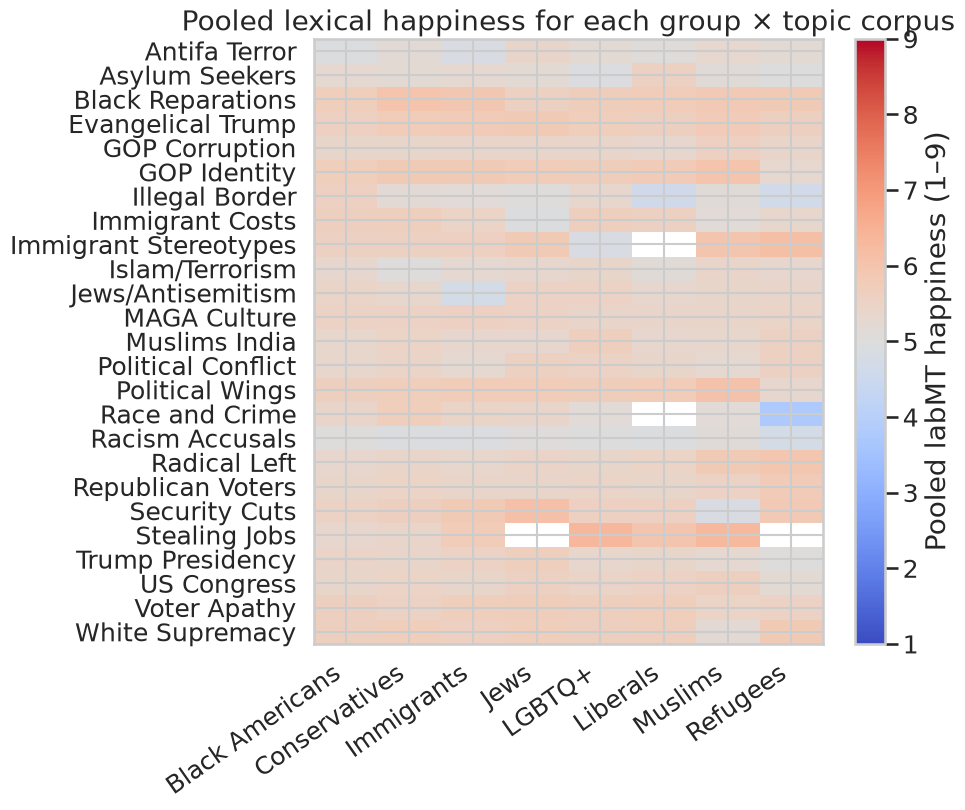

In [122]:
def pool_happiness(frame, keys):
    sums = frame.groupby(keys, dropna=False, as_index=False).agg(
        n_tweets=('n_tweets', 'sum'),
        n_all_tokens=('all_tokens', 'sum'),
        n_matched_tokens=('labmt_matched_tokens', 'sum'),
        weighted_sum=('labmt_sum', 'sum')
    )
    sums['happiness'] = sums['weighted_sum'] / sums['n_matched_tokens'].replace(0, np.nan)
    sums['lexicon_coverage'] = sums['n_matched_tokens'] / sums['n_all_tokens'].replace(0, np.nan)
    return sums

# THIS is the answer to your request: one happiness score for EACH group + topic corpus.
pooled_group_topic = pool_happiness(work, ['group_name', 'topic_name'])
pooled_group_topic.to_csv(OUT/'pooled_group_topic_happiness.csv', index=False)
print('Group × Topic combined-corpus happiness:')
display(pooled_group_topic.sort_values(['group_name','happiness']).head(30))

# Also compute the topic-wide pooled corpus, across all groups.
pooled_topic = pool_happiness(work, ['topic_name'])
pooled_topic.to_csv(OUT/'pooled_topic_happiness.csv', index=False)
print('All-group topic happiness:')
display(pooled_topic.sort_values('happiness'))

# Heatmap of actual pooled happiness, not a fitted coefficient.
heat = pooled_group_topic.pivot(index='topic_name', columns='group_name', values='happiness')
fig, ax = plt.subplots(figsize=(max(10, heat.shape[1]*1.2), max(7, heat.shape[0]*.34)))
im = ax.imshow(heat.to_numpy(), aspect='auto', cmap='coolwarm', vmin=1, vmax=9)
ax.set_xticks(np.arange(len(heat.columns)), heat.columns, rotation=35, ha='right')
ax.set_yticks(np.arange(len(heat.index)), heat.index)
fig.colorbar(im, ax=ax, label='Pooled labMT happiness (1–9)')
ax.set_title('Pooled lexical happiness for each group × topic corpus')
fig.tight_layout()
fig.savefig(OUT/'pooled_group_topic_happiness.pdf', bbox_inches='tight')
plt.show()

In [124]:

print("CSV columns:")
print(df.columns.tolist())

print("\nYear information:")
print("year in df:", "year" in df.columns)

if "work" in globals() and "year" in work.columns:
    print("Valid years:", work["year"].notna().sum())
    print("Year values:", work["year"].dropna().unique()[:20])


CSV columns:
['Unnamed: 0', '_id', 'pure_text', 'rt_text', 'tweet_created_at', 'tweet_id', 'user_id', 'user_created_at', 'fastText_lang', 'fastText_conf', 'reply_to_id', 'LLM_Label', 'CommentType', 'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup', 'year', 'Topic', 'text_clean', 'LDA_topic', 'NMF_topic', 'LSA_topic']

Year information:
year in df: True
Valid years: 152729
Year values: [2022 2020 2016 2019 2018 2017 2021 2015 2012 2013 2014]


In [125]:
from pathlib import Path
from collections import Counter
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency, norm
from statsmodels.stats.multitest import multipletests
from IPython.display import display

DATA_FILE = 'topic_modeling_results.csv'
LEXICON_FILE = 'labMT-english.csv'  # Change to 'labMT2.txt' if necessary
OUT = Path('rq4_pooled_topic_results')
OUT.mkdir(parents=True, exist_ok=True)

TOPIC_COL = 'Topic'
GROUP_COL = 'MappedGroup'
TEXT_COL = 'pure_text'
STOP_LENS = (4.0, 6.0)   # RQ2 method: remove scores 4 through 6, inclusive
MIN_CELL_TWEETS = 2      # for year-adjusted regression ONLY
MIN_CELL_MATCHED = 20   # for year-adjusted regression ONLY

df = pd.read_csv(DATA_FILE)
print('Rows:', len(df), '\nColumns:', df.columns.tolist())
display(df.head(3))

Rows: 152729 
Columns: ['Unnamed: 0', '_id', 'pure_text', 'rt_text', 'tweet_created_at', 'tweet_id', 'user_id', 'user_created_at', 'fastText_lang', 'fastText_conf', 'reply_to_id', 'LLM_Label', 'CommentType', 'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup', 'year', 'Topic', 'text_clean', 'LDA_topic', 'NMF_topic', 'LSA_topic']


,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,tweet_id,user_id,user_created_at,fastText_lang,fastText_conf,...,TargetedGroup,Sentiment,Emotion,MappedGroup,year,Topic,text_clean,LDA_topic,NMF_topic,LSA_topic
0,0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,1.528506e+18,1.317928e+18,2020-10-18 20:37:29,en,0.98,...,Black Americans,Negative,Anger,Black Americans,2022,GOP Corruption,ridiculously irresponsible use large platform ...,5,6,0
1,1,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,1.279466e+18,1.268650e+18,2020-06-04 21:06:30,en,0.93,...,Conservatives,Negative,Anger,Conservatives,2020,Evangelical Trump,amazing sports commentator willing say blm man...,9,12,0
2,2,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,8.054107e+17,2.250714e+08,2010-12-10 16:12:28,en,0.65,...,Muslims,Positive,Gratitude,Muslims,2016,Evangelical Trump,price evangelical christian soul,7,12,12


In [126]:
def load_labmt(path):
    path = Path(path)
    if not path.exists():
        options = [p for p in ('labMT-english.csv', 'labMT2.txt') if Path(p).exists()]
        raise FileNotFoundError(
            f'Could not find {path}. Place your original English labMT file next to '
            f'the notebook. Available suggested lexicons: {options}. '
            'Do not substitute model-generated scores for the labMT lexicon.'
        )
    # Supports a 2+ column tab/CSV file, including files with a header row.
    lex = pd.read_csv(path, sep=None, engine='python', header=None,
                      comment='#', on_bad_lines='skip', encoding='utf-8-sig')
    if lex.shape[1] < 2:
        raise ValueError('Expected labMT file columns: word, happiness_average')
    lex = lex.iloc[:, :2].copy()
    lex.columns = ['word', 'h']
    lex['word'] = lex['word'].astype(str).str.strip().str.lower()
    lex['h'] = pd.to_numeric(lex['h'], errors='coerce')
    lex = lex[lex['word'].str.fullmatch(r'[a-z]+', na=False)]
    lex = lex[lex['h'].between(1, 9)]
    if STOP_LENS is not None:
        a, b = STOP_LENS
        lex = lex[(lex['h'] < a) | (lex['h'] > b)]
    lex = lex.drop_duplicates('word')
    if len(lex) < 100:
        raise ValueError(f'Only {len(lex)} lexicon entries loaded; check file format.')
    print(f'Loaded {len(lex):,} eligible labMT words from {path}')
    return dict(zip(lex['word'], lex['h'].astype(float)))

labmt = load_labmt(LEXICON_FILE)
TOKEN_RE = re.compile(r'[a-z]+')

def get_year(frame):
    for c in ('year', 'Year'):
        if c in frame.columns:
            return pd.to_numeric(frame[c], errors='coerce')
    for c in ('tweet_created_at', 'created_at', 'tweet_date', 'date',
              'Date', 'timestamp', 'created_utc', 'datetime'):
        if c in frame.columns:
            s = frame[c]
            if pd.api.types.is_numeric_dtype(s):
                med = pd.to_numeric(s, errors='coerce').median()
                if 1900 <= med <= 2100:
                    return pd.to_numeric(s, errors='coerce')
                if med > 1e11:
                    return pd.to_datetime(s, unit='ms', errors='coerce', utc=True).dt.year
                if med > 1e8:
                    return pd.to_datetime(s, unit='s', errors='coerce', utc=True).dt.year
            return pd.to_datetime(s, utc=True, errors='coerce').dt.year
    return pd.Series(np.nan, index=frame.index, dtype=float)

required = (TOPIC_COL, GROUP_COL, TEXT_COL)
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f'Missing required columns: {missing}. Available: {list(df.columns)}')

work = df.dropna(subset=[TOPIC_COL, GROUP_COL, TEXT_COL]).copy()
work['topic_name'] = work[TOPIC_COL].astype(str).str.strip()
work['group_name'] = work[GROUP_COL].astype(str).str.strip()
work = work[(work['topic_name'] != '') & (work['group_name'] != '')]
work['year'] = get_year(work)
work['year'] = work['year'].where(work['year'].between(2012, 2022))

# Each row is a tweet–group/topic record; score its matched TOKEN TOTALS.
def score_document(text):
    counts = Counter(TOKEN_RE.findall(str(text).lower()))
    total = sum(counts.values())
    matched = sum(freq for word, freq in counts.items() if word in labmt)
    scored = sum(freq * labmt[word] for word, freq in counts.items() if word in labmt)
    return scored, matched, total

scored = [score_document(t) for t in work[TEXT_COL].astype(str)]
work[['labmt_sum', 'labmt_matched_tokens', 'all_tokens']] = pd.DataFrame(
    scored, index=work.index, columns=['labmt_sum', 'labmt_matched_tokens', 'all_tokens']
)
work['n_tweets'] = 1
print('Usable tweet records:', len(work))
print('Records with usable year:', int(work['year'].notna().sum()))
print('Total labMT matched tokens:', int(work['labmt_matched_tokens'].sum()))
print('Rows with 0 eligible labMT words:', int((work['labmt_matched_tokens'] == 0).sum()))

Loaded 3,583 eligible labMT words from labMT-english.csv
Usable tweet records: 152729
Records with usable year: 152729
Total labMT matched tokens: 1010549
Rows with 0 eligible labMT words: 3096


Chi-square(168)=384127.707, p=0, Cramer V=0.599
Expected counts <5: 0 of 200


,group,topic,observed,expected,group_topic_prevalence,overall_topic_prevalence,difference_pp,adjusted_residual,raw_p,fdr_p,overrepresented_fdr05
176,Refugees,Asylum Seekers,1718,64.697831,0.772830,0.029104,74.372567,210.138114,0.000000e+00,0.000000e+00,True
138,Liberals,Political Conflict,6263,765.707135,0.634356,0.077556,55.680065,213.874475,0.000000e+00,0.000000e+00,True
162,Muslims,Muslims India,5526,450.436839,0.468782,0.038211,43.057034,253.845559,0.000000e+00,0.000000e+00,True
85,Jews,Jews/Antisemitism,4648,372.769507,0.404772,0.032463,37.230954,234.087470,0.000000e+00,0.000000e+00,True
58,Immigrants,Immigrant Stereotypes,6372,901.010352,0.319270,0.045145,27.412515,200.051358,0.000000e+00,0.000000e+00,True
2,Black Americans,Black Reparations,10669,2715.809748,0.282092,0.071807,21.028503,182.624130,0.000000e+00,0.000000e+00,True
159,Muslims,Islam/Terrorism,2144,188.170839,0.181880,0.015963,16.591696,149.620501,0.000000e+00,0.000000e+00,True
78,Jews,Evangelical Trump,1822,329.988980,0.158669,0.028737,12.993216,86.661580,0.000000e+00,0.000000e+00,True
43,Conservatives,Republican Voters,11124,5538.066314,0.240873,0.119918,12.095478,95.795552,0.000000e+00,0.000000e+00,True
56,Immigrants,Illegal Border,2794,417.378834,0.139994,0.020913,11.908113,126.093650,0.000000e+00,0.000000e+00,True


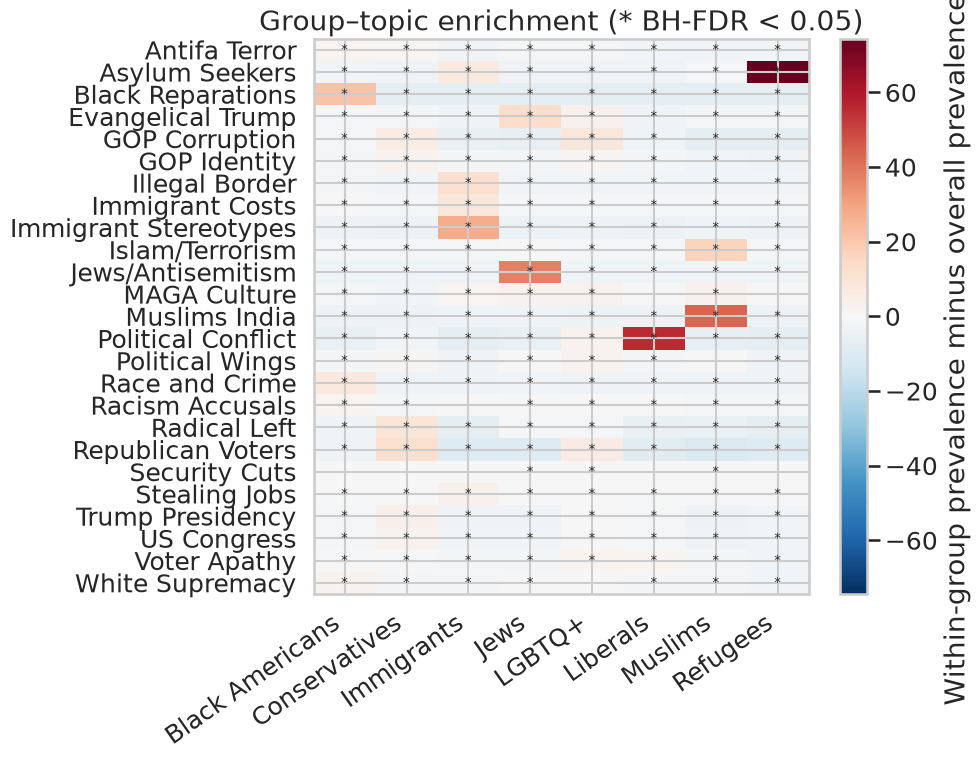

In [127]:
table = pd.crosstab(work['group_name'], work['topic_name'])
if min(table.shape) < 2:
    raise ValueError('Need at least 2 groups and 2 topics for the chi-square test.')
chi2, p, dof, expected = chi2_contingency(table.to_numpy(), correction=False)
N = table.to_numpy().sum()
row_tot = table.sum(axis=1).to_numpy()[:, None]
col_tot = table.sum(axis=0).to_numpy()[None, :]
row_p = row_tot / N
col_p = col_tot / N
adjusted_resid = (table.to_numpy() - expected) / np.sqrt(
    expected * (1 - row_p) * (1 - col_p)
)
p_raw = 2 * norm.sf(np.abs(adjusted_resid))
p_fdr = multipletests(p_raw.ravel(), method='fdr_bh')[1].reshape(p_raw.shape)
cramers_v = np.sqrt(chi2 / (N * min(table.shape[0]-1, table.shape[1]-1)))

rows = []
for i, group in enumerate(table.index):
    for j, topic in enumerate(table.columns):
        rows.append(dict(group=group, topic=topic, observed=int(table.iat[i, j]),
                         expected=float(expected[i, j]),
                         group_topic_prevalence=float(table.iat[i,j]/row_tot[i,0]),
                         overall_topic_prevalence=float(col_p[0,j]),
                         difference_pp=float(100*(table.iat[i,j]/row_tot[i,0]-col_p[0,j])),
                         adjusted_residual=float(adjusted_resid[i,j]),
                         raw_p=float(p_raw[i,j]), fdr_p=float(p_fdr[i,j]),
                         overrepresented_fdr05=bool(adjusted_resid[i,j]>0 and p_fdr[i,j]<.05)))
group_topic_stats = pd.DataFrame(rows)
group_topic_stats.to_csv(OUT/'group_topic_adjusted_residuals.csv', index=False)
table.to_csv(OUT/'group_by_topic_counts.csv')

print(f'Chi-square({dof})={chi2:.3f}, p={p:.3g}, Cramer V={cramers_v:.3f}')
print('Expected counts <5:', int((expected<5).sum()), 'of', expected.size)
if (expected<5).mean() > .20:
    warnings.warn('Many expected cells <5: consider a permutation test or merging sparse topics.')
display(group_topic_stats[group_topic_stats.overrepresented_fdr05]
        .sort_values('difference_pp', ascending=False).head(25))

values = 100 * (table.to_numpy()/row_tot - col_p)
fig, ax = plt.subplots(figsize=(max(10, table.shape[0]*1.2), max(7, table.shape[1]*.32)))
lim = max(1, np.abs(values).max())
im = ax.imshow(values.T, aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim)
ax.set_xticks(np.arange(table.shape[0]), table.index, rotation=35, ha='right')
ax.set_yticks(np.arange(table.shape[1]), table.columns)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        if p_fdr[i,j] < .05:
            ax.text(i,j, '*', ha='center',va='center',fontsize=9)
fig.colorbar(im, ax=ax, label='Within-group prevalence minus overall prevalence (pp)')
ax.set_title('Group–topic enrichment (* BH-FDR < 0.05)')
fig.tight_layout()
fig.savefig(OUT/'group_topic_enrichment.pdf', bbox_inches='tight')
plt.show()

In [128]:
# RUN THIS CELL AFTER SECTION B. It creates the missing adjusted regression outputs.
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from IPython.display import display
import warnings

OUT = Path('rq4_pooled_topic_results')
OUT.mkdir(parents=True, exist_ok=True)

# If the auto-detected year was absent, first check for overlooked date columns.
print('Available CSV columns:', df.columns.tolist())
if work['year'].notna().sum() == 0:
    date_candidates = [c for c in df.columns if any(s in c.lower() for s in
                       ('date', 'time', 'year', 'created', 'posted'))]
    print('Possible timestamp columns:', date_candidates)
    print('No usable year found. Fitting GROUP-only adjusted regression. '
          'To control for year, add a real tweet year/date column and rerun from Section A.')

HAS_YEAR = work['year'].notna().sum() > 0
if HAS_YEAR:
    valid = work.dropna(subset=['year']).copy()
    valid['year'] = valid['year'].astype(int)
    base = pool_happiness(valid, ['group_name', 'topic_name', 'year'])
    base.to_csv(OUT/'pooled_group_topic_year_happiness_all.csv', index=False)
    print('Using group + year adjustment, with group × topic × year pooled corpora.')
else:
    base = pooled_group_topic.copy()
    print('Using group-only adjustment, with group × topic pooled corpora.')

model_data = base[
    (base['n_tweets'] >= MIN_CELL_TWEETS) &
    (base['n_matched_tokens'] >= MIN_CELL_MATCHED) &
    (base['happiness'].notna())
].copy()
print('Pooled cells used:', len(model_data), 'out of', len(base))
print('Groups:', model_data.group_name.nunique(),
      'Topics:', model_data.topic_name.nunique(),
      'Years:' if HAS_YEAR else 'Year control:',
      model_data.year.nunique() if HAS_YEAR else 'not available')
if model_data.group_name.nunique() < 2 or model_data.topic_name.nunique() < 2:
    raise ValueError('At least two groups and two topics are required.')
if HAS_YEAR and model_data.year.nunique() < 2:
    raise ValueError('Only one usable year. Cannot adjust for calendar year.')

ref_topic = model_data.groupby('topic_name', observed=True).n_matched_tokens.sum().idxmax()
levels = [ref_topic] + sorted(set(model_data.topic_name) - {ref_topic})
model_data['topic_name'] = pd.Categorical(model_data.topic_name, categories=levels)
formula = 'happiness ~ C(topic_name, Treatment(reference=0)) + C(group_name)'
if HAS_YEAR:
    formula += ' + C(year)'

fit = smf.wls(formula, data=model_data,
              weights=model_data['n_matched_tokens']).fit(cov_type='HC3')
terms = [s for s in fit.params.index
         if s.startswith('C(topic_name, Treatment(reference=0))[T.')]
if not terms:
    raise ValueError('No estimable topic contrasts.')
ci = fit.conf_int()
contrasts = pd.DataFrame({
    'topic': [s.split('[T.',1)[1].rsplit(']',1)[0] for s in terms],
    'reference_topic': ref_topic,
    'adjusted_difference_labmt': fit.params.loc[terms].to_numpy(),
    'hc3_se': fit.bse.loc[terms].to_numpy(),
    'ci_low': ci.loc[terms, 0].to_numpy(),
    'ci_high': ci.loc[terms, 1].to_numpy(),
    'raw_p': fit.pvalues.loc[terms].to_numpy(),
    'year_controlled': HAS_YEAR,
    'adjustment': 'group + year' if HAS_YEAR else 'group only',
})
contrasts['fdr_p'] = multipletests(contrasts['raw_p'].fillna(1).to_numpy(),
                                  method='fdr_bh')[1]
contrasts['significant_fdr05'] = contrasts['fdr_p'] < 0.05
contrasts = contrasts.sort_values('adjusted_difference_labmt').reset_index(drop=True)

# Joint robust Wald test H0: all topic contrasts equal zero, controlling for other terms.
R = np.zeros((len(terms), len(fit.params)))
for i, term in enumerate(terms):
    R[i, fit.params.index.get_loc(term)] = 1
joint = fit.wald_test(R, scalar=True)
summary = pd.DataFrame([{
    'n_pooled_cells': len(model_data),
    'n_groups': model_data.group_name.nunique(),
    'n_topics': model_data.topic_name.nunique(),
    'n_years': model_data.year.nunique() if HAS_YEAR else 0,
    'reference_topic': ref_topic,
    'year_controlled': HAS_YEAR,
    'adjustment': 'group + year' if HAS_YEAR else 'group only',
    'r_squared': float(fit.rsquared),
    'wald_chi_square': float(joint.statistic),
    'degrees_of_freedom': len(terms),
    'p_value': float(joint.pvalue),
}])

# Outputs: always write the generic filenames asked for, with explicit adjustment metadata.
contrasts.to_csv(OUT/'topic_happiness_adjusted_contrasts.csv', index=False)
summary.to_csv(OUT/'topic_happiness_overall_test.csv', index=False)
if HAS_YEAR:
    contrasts.to_csv(OUT/'topic_happiness_group_year_adjusted.csv', index=False)
else:
    contrasts.to_csv(OUT/'topic_happiness_group_only_adjusted.csv', index=False)
with open(OUT/'topic_happiness_model_summary.txt', 'w') as f:
    f.write(fit.summary().as_text())

print('\nOverall adjusted topic-association test:')
display(summary)
print('\nAdjusted topic contrasts, with BH-FDR correction:')
display(contrasts)
print('\nSaved files:')
print((OUT/'topic_happiness_adjusted_contrasts.csv').resolve())
print((OUT/'topic_happiness_overall_test.csv').resolve())


Available CSV columns: ['Unnamed: 0', '_id', 'pure_text', 'rt_text', 'tweet_created_at', 'tweet_id', 'user_id', 'user_created_at', 'fastText_lang', 'fastText_conf', 'reply_to_id', 'LLM_Label', 'CommentType', 'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup', 'year', 'Topic', 'text_clean', 'LDA_topic', 'NMF_topic', 'LSA_topic']
Using group + year adjustment, with group × topic × year pooled corpora.
Pooled cells used: 1213 out of 1632
Groups: 8 Topics: 25 Years: 11

Overall adjusted topic-association test:


,n_pooled_cells,n_groups,n_topics,n_years,reference_topic,year_controlled,adjustment,r_squared,wald_chi_square,degrees_of_freedom,p_value
0,1213,8,25,11,Republican Voters,True,group + year,0.604426,945.098284,24,4.003898e-184



Adjusted topic contrasts, with BH-FDR correction:


,topic,reference_topic,adjusted_difference_labmt,hc3_se,ci_low,ci_high,raw_p,year_controlled,adjustment,fdr_p,significant_fdr05
0,Racism Accusals,Republican Voters,-0.447258,0.035694,-0.517217,-0.377298,5.102778e-36,True,group + year,6.123333e-35,True
1,Antifa Terror,Republican Voters,-0.367747,0.073541,-0.511885,-0.223610,5.715688e-07,True,group + year,1.524183e-06,True
2,Illegal Border,Republican Voters,-0.242295,0.089010,-0.416751,-0.067840,6.486289e-03,True,group + year,1.297258e-02,True
3,Asylum Seekers,Republican Voters,-0.215329,0.045477,-0.304463,-0.126196,2.191648e-06,True,group + year,5.259955e-06,True
4,Muslims India,Republican Voters,-0.119906,0.065270,-0.247832,0.008020,6.619719e-02,True,group + year,9.929579e-02,False
5,Islam/Terrorism,Republican Voters,-0.085401,0.067525,-0.217748,0.046945,2.059635e-01,True,group + year,2.746180e-01,False
6,Jews/Antisemitism,Republican Voters,-0.061140,0.064906,-0.188353,0.066073,3.462046e-01,True,group + year,4.154455e-01,False
7,GOP Corruption,Republican Voters,-0.040265,0.018654,-0.076825,-0.003705,3.088251e-02,True,group + year,5.294145e-02,False
8,Radical Left,Republican Voters,-0.039945,0.021246,-0.081586,0.001695,6.008561e-02,True,group + year,9.613698e-02,False
9,Trump Presidency,Republican Voters,-0.025024,0.032713,-0.089140,0.039093,4.443080e-01,True,group + year,4.990470e-01,False



Saved files:
/gpfs1/home/t/p/tprama/Us_vs_Them/LLM_Labeled_Data/rq4_pooled_topic_results/topic_happiness_adjusted_contrasts.csv
/gpfs1/home/t/p/tprama/Us_vs_Them/LLM_Labeled_Data/rq4_pooled_topic_results/topic_happiness_overall_test.csv


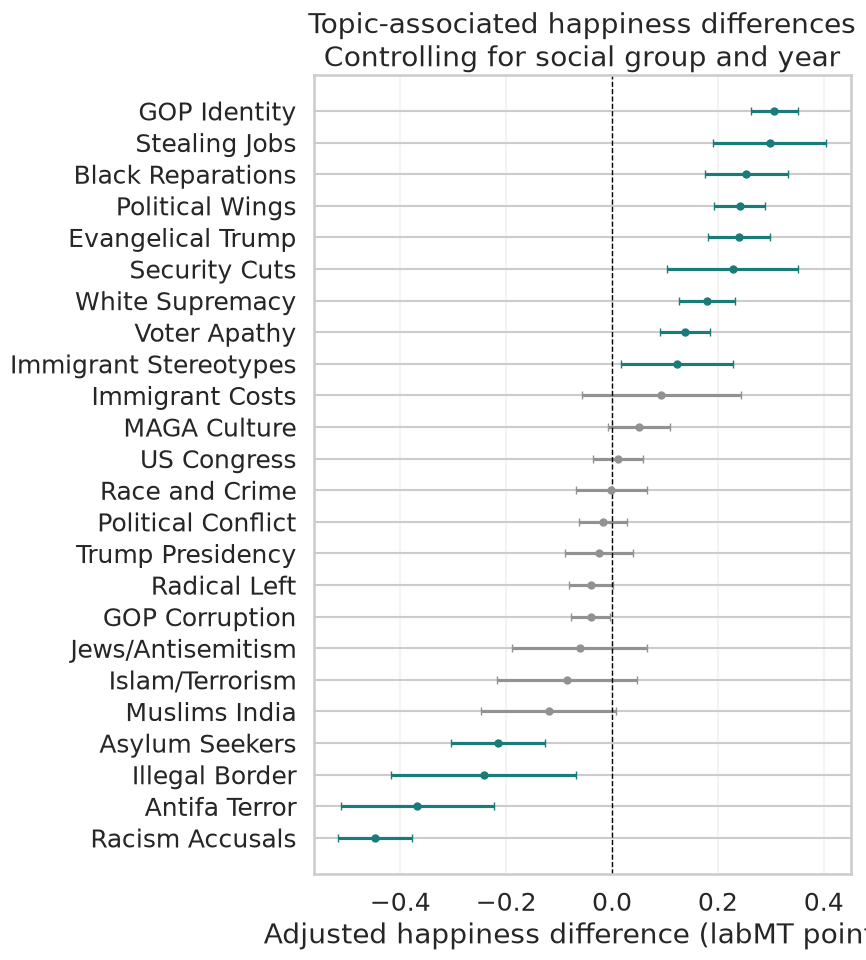

In [129]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

out = Path("rq4_pooled_topic_results")

res = pd.read_csv(
    out / "topic_happiness_group_year_adjusted.csv"
)

res = res.sort_values("adjusted_difference_labmt")

y = np.arange(len(res))
x = res["adjusted_difference_labmt"].to_numpy()

err_low = x - res["ci_low"].to_numpy()
err_high = res["ci_high"].to_numpy() - x

fig, ax = plt.subplots(figsize=(9, 10))

for i, (_, r) in enumerate(res.iterrows()):
    color = (
        "#197c79"
        if r["significant_fdr05"]
        else "#929292"
    )

    ax.errorbar(
        r["adjusted_difference_labmt"],
        i,
        xerr=[[
            r["adjusted_difference_labmt"] - r["ci_low"]
        ], [
            r["ci_high"] - r["adjusted_difference_labmt"]
        ]],
        fmt="o",
        color=color,
        capsize=3,
        markersize=5
    )

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(res["topic"])
ax.set_xlabel(
    "Adjusted happiness difference (labMT points)"
)
ax.set_title(
    "Topic-associated happiness differences\n"
    "Controlling for social group and year"
)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()

fig.savefig(
    out / "topic_happiness_adjusted_contrasts.pdf",
    bbox_inches="tight"
)
plt.show()


In [130]:
"""Publication-ready RQ4 topic-enrichment figure.

Run in Jupyter after your group-topic analysis, or execute as a script.
Reads rq4_pooled_topic_results/group_topic_adjusted_residuals.csv and creates
rq4_pooled_topic_results/topic_enrichment_top_by_group.pdf / .png
"""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def plot_topic_enrichment(input_csv='rq4_pooled_topic_results/group_topic_adjusted_residuals.csv',
                          output_prefix='rq4_pooled_topic_results/topic_enrichment_top_by_group',
                          top_n=1):
    tab = pd.read_csv(input_csv).copy()
    # Support both reported table and earlier notebook schemas.
    def col(*names):
        for n in names:
            if n in tab.columns: return n
        raise ValueError(f'None of {names} in table: {tab.columns.tolist()}')
    group_col = col('group','group_name')
    topic_col = col('topic','topic_name')
    group_prev_col = col('group_topic_prevalence','within_group_prevalence')
    overall_prev_col = col('overall_topic_prevalence','expected_prevalence_if_independent')
    diff_col = col('difference_pp','difference_percentage_points')
    significant_col = col('overrepresented_fdr05')
    # Original notebook marks this as bool, but CSV string parsing can vary.
    tab = tab[tab[significant_col].astype(str).str.lower().eq('true')].copy()
    tab = tab[tab[diff_col] > 0]
    if tab.empty:
        raise ValueError('No significantly overrepresented topic associations to plot.')
    tab = (tab.sort_values([group_col,diff_col], ascending=[True,False])
              .groupby(group_col, sort=False).head(top_n))
    # Deterministic group ordering familiar from manuscript.
    order = ['Black Americans','Conservatives','Immigrants','Jews',
             'LGBTQ+','Liberals','Muslims','Refugees']
    tab['sort_order']=tab[group_col].map({g:i for i,g in enumerate(order)}).fillna(len(order))
    tab = tab.sort_values(['sort_order',diff_col], ascending=[True,False]).reset_index(drop=True)
    n=len(tab)
    # Scales group/topic labels and points instead of using a 25x8 crowded heatmap.
    fig, ax = plt.subplots(figsize=(10.7, max(4.5, n*.56+1.25)))
    plt.rcParams['pdf.fonttype'] = 42
    plt.rcParams['ps.fonttype'] = 42
    fig.patch.set_facecolor('white')
    ax.set_facecolor('white')
    within = 100*tab[group_prev_col].astype(float).to_numpy()
    global_share = 100*tab[overall_prev_col].astype(float).to_numpy()
    y = (n-1)-np.arange(n)
    navy = '#1b5d7a'
    secondary = '#8d969e'
    connectors = '#c8ced4'
    # Reserve right-hand numeric columns; only 0--80 is the prevalence axis.
    for yi, a, b in zip(y, global_share, within):
        ax.plot([a,b], [yi,yi], color=connectors, lw=2.5, zorder=1, solid_capstyle='round')
    ax.scatter(global_share,y,s=52,color='white',edgecolor=secondary,linewidth=1.6,zorder=3)
    ax.scatter(within,y,s=75,color=navy,edgecolor='white',linewidth=.7,zorder=4)
    for yi, row in zip(y, tab.to_dict('records')):
        ax.text(-.03,yi+.16,str(row[group_col]),transform=ax.get_yaxis_transform(),
                ha='right',va='center',fontweight='bold',fontsize=9.7,color='#212b36',clip_on=False)
        ax.text(-.03,yi-.18,str(row[topic_col]),transform=ax.get_yaxis_transform(),
                ha='right',va='center',fontsize=8.7,color='#4d5a66',clip_on=False)
    for yi, a, b in zip(y,global_share, within):
        ax.text(86.0,yi,f'{b:.1f}',color=navy,ha='center',va='center',fontsize=9.1,fontweight='bold')
        ax.text(98.0,yi,f'{a:.1f}',color='#56616b',ha='center',va='center',fontsize=9.1)
    ax.text(86.0,y.max()+.68,'Group %',fontsize=9,fontweight='bold',ha='center',color=navy)
    ax.text(98.0,y.max()+.68,'All tweets %',fontsize=9,fontweight='bold',ha='center',color='#56616b')
    ax.set_xlim(-1,104)
    ax.set_ylim(-.6,y.max()+1.15)
    ax.set_xticks([0,20,40,60,80])
    ax.set_xticklabels(['0','20','40','60','80'], fontsize=9)
    ax.set_xlabel('Share of tweets assigned to topic (%)',fontsize=10,labelpad=9)
    ax.set_yticks([])
    ax.spines[['top','right','left','bottom']].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis='x',color='#e9ecef',lw=.85)
    ax.tick_params(axis='x',length=0)
    legend_handles=[
        Line2D([0],[0],marker='o',linestyle='None',markersize=7,
               markerfacecolor=navy,markeredgecolor='white',label='Within-group prevalence'),
        Line2D([0],[0],marker='o',linestyle='None',markersize=7,
               markerfacecolor='white',markeredgecolor=secondary,label='Overall topic prevalence')]
    fig.legend(handles=legend_handles,loc='upper center',ncol=2,
               bbox_to_anchor=(.56,.985),frameon=False,fontsize=9)
    fig.subplots_adjust(left=.34,right=.975,top=.88,bottom=.14)
    prefix=Path(output_prefix)
    prefix.parent.mkdir(parents=True,exist_ok=True)
    fig.savefig(str(prefix)+'.pdf',bbox_inches='tight',facecolor='white',pad_inches=.14)
    fig.savefig(str(prefix)+'.png',bbox_inches='tight',dpi=240,facecolor='white',pad_inches=.14)
    plt.close(fig)
    print(f'Saved {prefix}.pdf and .png')
    print('Chart shows only significant, overrepresented topics, with highest percentage-point enrichment in each group.')
    return tab



In [131]:
selected = plot_topic_enrichment(
    input_csv='rq4_pooled_topic_results/group_topic_adjusted_residuals.csv',
    output_prefix='rq4_pooled_topic_results/topic_enrichment_top_by_group',
    top_n=1
)
display(selected[[c for c in ['group','topic','difference_pp','difference_percentage_points'] if c in selected.columns]])

Saved rq4_pooled_topic_results/topic_enrichment_top_by_group.pdf and .png
Chart shows only significant, overrepresented topics, with highest percentage-point enrichment in each group.


,group,topic,difference_pp
0,Black Americans,Black Reparations,21.028503
1,Conservatives,Republican Voters,12.095478
2,Immigrants,Immigrant Stereotypes,27.412515
3,Jews,Jews/Antisemitism,37.230954
4,LGBTQ+,GOP Corruption,8.217153
5,Liberals,Political Conflict,55.680065
6,Muslims,Muslims India,43.057034
7,Refugees,Asylum Seekers,74.372567


['group', 'topic', 'observed', 'expected', 'group_topic_prevalence', 'overall_topic_prevalence', 'difference_pp', 'adjusted_residual', 'raw_p', 'fdr_p', 'overrepresented_fdr05']
             group              topic  observed     expected  \
0  Black Americans      Antifa Terror      1772   955.869940   
1  Black Americans     Asylum Seekers       317  1100.736239   
2  Black Americans  Black Reparations     10669  2715.809748   
3  Black Americans  Evangelical Trump       552  1086.868696   
4  Black Americans     GOP Corruption      2461  2979.788338   

   group_topic_prevalence  overall_topic_prevalence  difference_pp  \
0                0.046852                  0.025274       2.157875   
1                0.008382                  0.029104      -2.072225   
2                0.282092                  0.071807      21.028503   
3                0.014595                  0.028737      -1.414211   
4                0.065070                  0.078787      -1.371694   

   adjusted_resi

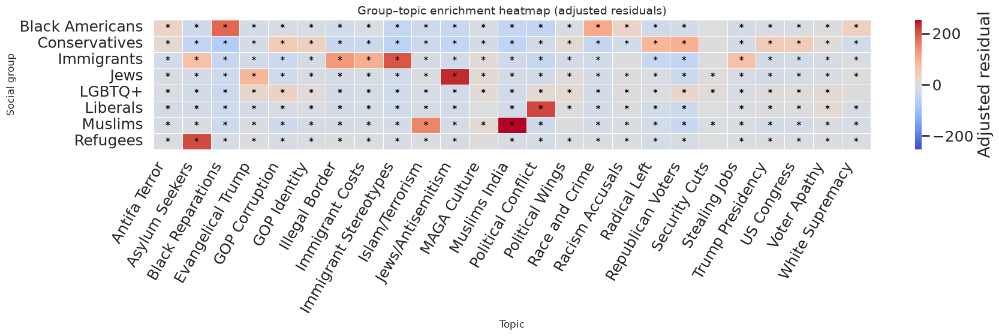

In [133]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 1. Load data
# -----------------------------
df = pd.read_csv("rq4_pooled_topic_results/group_topic_adjusted_residuals.csv")

# Inspect columns if needed
print(df.columns.tolist())
print(df.head())

# Expected important columns:
# group, topic, adjusted_residual, fdr_p, overrepresented_fdr05
# If your file uses different names, rename below.

# -----------------------------
# 2. Standardize column names if needed
# -----------------------------
rename_map = {
    "group_name": "group",
    "topic_name": "topic",
    "AdjustedResidual": "adjusted_residual",
    "adj_residual": "adjusted_residual",
    "fdr_p_value": "fdr_p",
}
df = df.rename(columns={k:v for k,v in rename_map.items() if k in df.columns})

# -----------------------------
# 3. Optional: keep only significant cells
# -----------------------------
# If you want ALL cells, comment this out.
# Here I keep all cells but you can mask nonsignificant ones in plotting.
if "fdr_p" in df.columns:
    df["sig"] = df["fdr_p"] < 0.05
else:
    df["sig"] = True

# -----------------------------
# 4. Choose row/column order
# -----------------------------
group_order = [
    "Black Americans",
    "Conservatives",
    "Immigrants",
    "Jews",
    "LGBTQ+",
    "Liberals",
    "Muslims",
    "Refugees"
]

# If you want ALL topics:
topic_order = sorted(df["topic"].dropna().unique())

# If too crowded, use top topics by max absolute residual:
# n_topics = 15
# top_topics = (
#     df.groupby("topic")["adjusted_residual"]
#       .apply(lambda x: np.max(np.abs(x)))
#       .sort_values(ascending=False)
#       .head(n_topics)
#       .index.tolist()
# )
# topic_order = top_topics

# -----------------------------
# 5. Build the heatmap matrix
# -----------------------------
heat = df.pivot_table(
    index="group",
    columns="topic",
    values="adjusted_residual",
    aggfunc="first"
)

# Reindex to force correct row/column order
heat = heat.reindex(index=[g for g in group_order if g in heat.index])
heat = heat.reindex(columns=[t for t in topic_order if t in heat.columns])

# -----------------------------
# 6. Build significance mask (optional)
# -----------------------------
sig_mat = df.pivot_table(
    index="group",
    columns="topic",
    values="sig",
    aggfunc="first"
)

sig_mat = sig_mat.reindex(index=heat.index, columns=heat.columns)

# mask nonsignificant cells if you want:
# nonsig_mask = ~sig_mat.fillna(False)

# -----------------------------
# 7. Plot heatmap
# -----------------------------
plt.figure(figsize=(18, 6))

# Diverging scale centered at 0 is best for adjusted residuals
vmax = np.nanmax(np.abs(heat.to_numpy()))
vmax = max(vmax, 2)  # avoid tiny scale
vmin = -vmax

ax = sns.heatmap(
    heat,
    cmap="coolwarm",
    center=0,
    vmin=vmin,
    vmax=vmax,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Adjusted residual"},
    square=False
)

# -----------------------------
# 8. Add stars only for significant cells
# -----------------------------
for i, g in enumerate(heat.index):
    for j, t in enumerate(heat.columns):
        val = heat.loc[g, t]
        sig = sig_mat.loc[g, t] if (g in sig_mat.index and t in sig_mat.columns) else False
        
        if pd.notna(val):
            # show star for significance
            if sig:
                ax.text(j + 0.5, i + 0.5, "*",
                        ha="center", va="center",
                        fontsize=10, fontweight="bold", color="black")

# -----------------------------
# 9. Formatting
# -----------------------------
ax.set_xlabel("Topic", fontsize=12)
ax.set_ylabel("Social group", fontsize=12)
ax.set_title("Group–topic enrichment heatmap (adjusted residuals)", fontsize=14)

plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("group_topic_enrichment_heatmap_fixed.pdf", bbox_inches="tight")
plt.savefig("group_topic_enrichment_heatmap_fixed.png", dpi=300, bbox_inches="tight")
plt.show()

In [134]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import SymLogNorm

input_path = Path('rq4_pooled_topic_results/group_topic_adjusted_residuals.csv')
if not input_path.exists():
    input_path = Path('group_topic_adjusted_residuals.csv')
if not input_path.exists():
    raise FileNotFoundError('Put group_topic_adjusted_residuals.csv in this folder, or in rq4_pooled_topic_results/')

df = pd.read_csv(input_path)
required = {'group', 'topic', 'adjusted_residual', 'fdr_p', 'difference_pp'}
missing = required - set(df.columns)
if missing:
    raise ValueError(f'Missing CSV columns: {sorted(missing)}. Found: {df.columns.tolist()}')

# Verify exactly one observation per group–topic cell.
duplicates = df.duplicated(['group', 'topic']).sum()
if duplicates:
    raise ValueError(f'{duplicates} duplicate group/topic rows: inspect data before plotting')

group_order = ['Black Americans', 'Conservatives', 'Immigrants', 'Jews',
               'LGBTQ+', 'Liberals', 'Muslims', 'Refugees']
group_order = [g for g in group_order if g in df['group'].unique()]

# Topics on rows, groups on columns. NO manual row/column coordinate mapping.
heat = df.pivot(index='topic', columns='group', values='adjusted_residual')
heat = heat.reindex(columns=group_order)
# Sort topics by the largest absolute association in any group.
heat = heat.reindex(heat.abs().max(axis=1).sort_values(ascending=False).index)

# Significance lookup is EXACTLY aligned with the color matrix for checking.
fdr = (df.pivot(index='topic', columns='group', values='fdr_p')
         .reindex(index=heat.index, columns=heat.columns))

print(f'Group × topic matrix: {heat.shape[1]} groups × {heat.shape[0]} topics')
print(f'Missing cells: {int(heat.isna().sum().sum())}')
print(f'FDR significant cells: {int((fdr < 0.05).sum().sum())}')
display(heat.head())

Group × topic matrix: 8 groups × 25 topics
Missing cells: 0
FDR significant cells: 190


group,Black Americans,Conservatives,Immigrants,Jews,LGBTQ+,Liberals,Muslims,Refugees
topic,,,,,,,,
Muslims India,-42.648961,-51.167956,-27.468720,-15.781919,-22.601486,-19.989734,253.845559,-9.244064
Jews/Antisemitism,-39.630345,-46.908616,-22.228007,234.087470,-21.078095,-18.466622,-15.400625,-8.097081
Political Conflict,-43.889290,-19.718699,-39.563226,-23.711630,12.263529,213.874475,-25.817495,-13.212627
Asylum Seekers,-27.639331,-44.082668,67.571409,-16.463874,-19.854637,-17.726001,-5.422900,210.138114
Immigrant Stereotypes,-43.555157,-55.328210,200.051358,-22.593316,-22.346469,-22.339519,-16.771064,-8.063484


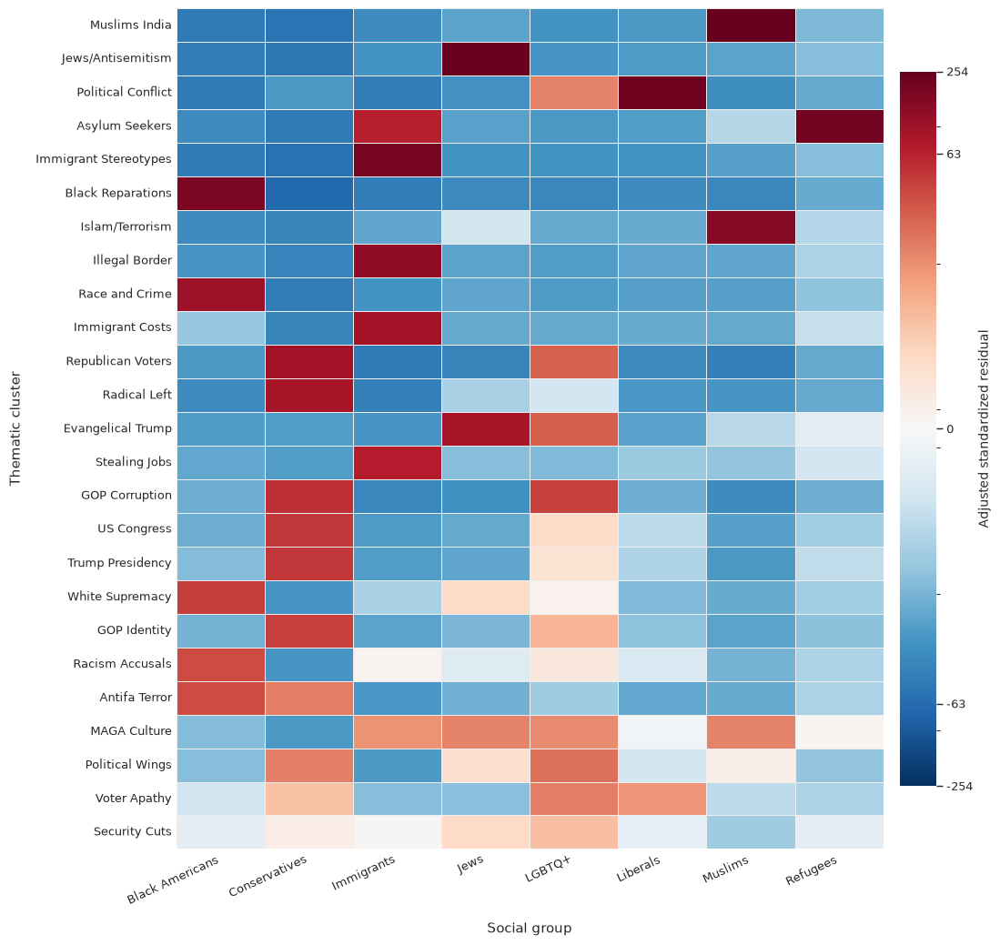

Saved to: /gpfs1/home/t/p/tprama/Us_vs_Them/LLM_Labeled_Data/rq4_pooled_topic_results


In [135]:
# The signed symmetrical-log color norm avoids the extreme values (e.g. ±200)
# rendering moderate associations as nearly-white. It does NOT change the data.
sns.set_theme(context='paper', style='white', font_scale=1.05)
V = float(np.nanmax(np.abs(heat.to_numpy(dtype=float))))
norm = SymLogNorm(linthresh=8.0, linscale=1.0, vmin=-V, vmax=V, base=10)

fig, ax = plt.subplots(figsize=(11.5, 10.5))
ax = sns.heatmap(
    heat,
    cmap='RdBu_r',
    norm=norm,
    linewidths=0.6,
    linecolor='#eeeeee',
    square=False,
    annot=False,
    cbar_kws={'label': 'Adjusted standardized residual', 'shrink': 0.85, 'pad': 0.02},
    ax=ax,
)
ax.set_xlabel('Social group', fontsize=11, labelpad=12)
ax.set_ylabel('Thematic cluster', fontsize=11, labelpad=10)
ax.tick_params(axis='x', labelrotation=25, labelsize=9, length=0)
ax.tick_params(axis='y', labelrotation=0, labelsize=9, length=0)
for tick in ax.get_xticklabels():
    tick.set_horizontalalignment('right')

# Use a short, readable colorbar rather than hundreds of ticks.
cbar = ax.collections[0].colorbar
ticks = [-V, -V/4, 0, V/4, V]
cbar.set_ticks(ticks)
cbar.set_ticklabels([f'{v:.0f}' for v in ticks])
cbar.ax.tick_params(labelsize=9)

fig.tight_layout()
out_dir = Path('rq4_pooled_topic_results')
out_dir.mkdir(exist_ok=True)
fig.savefig(out_dir / 'group_topic_enrichment_heatmap_publication.pdf', bbox_inches='tight')
fig.savefig(out_dir / 'group_topic_enrichment_heatmap_publication.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved to:', out_dir.resolve())

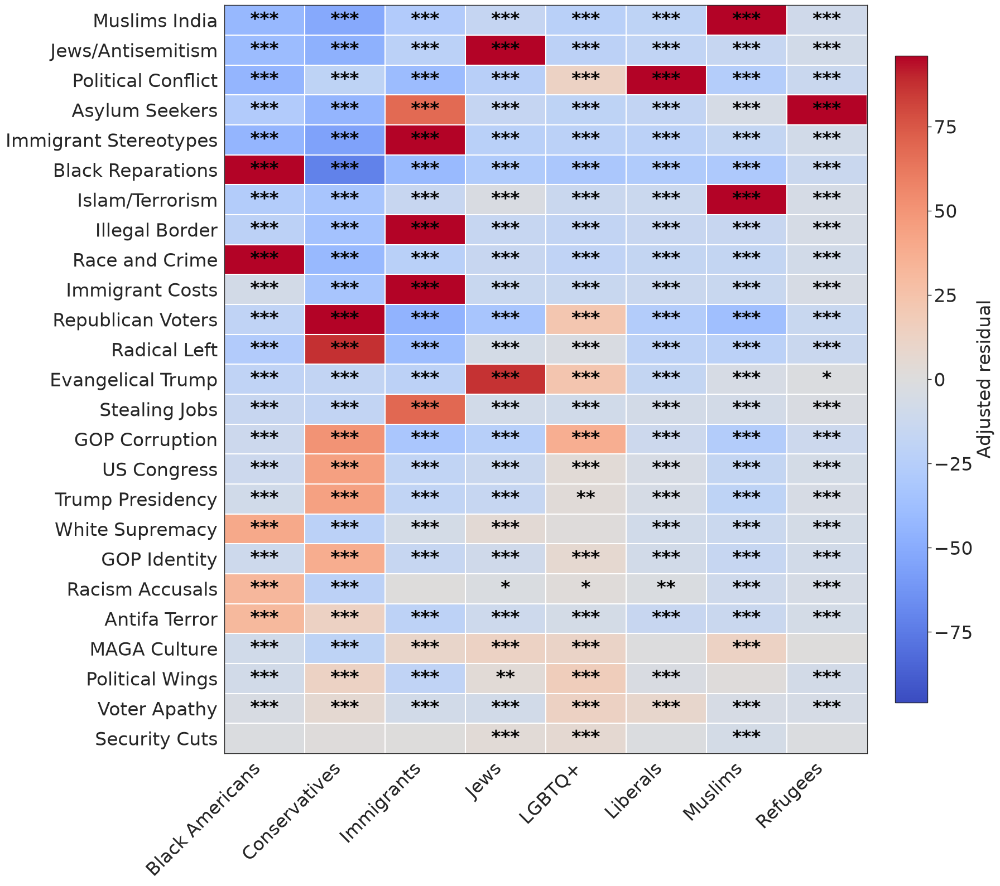

In [137]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1. Load data
# =========================
df = pd.read_csv("rq4_pooled_topic_results/group_topic_adjusted_residuals.csv")

# Expected columns:
# group, topic, adjusted_residual, fdr_p
# If your column names differ, rename them here:
df = df.rename(columns={
    "group": "Group",
    "topic": "Topic",
    "adjusted_residual": "AdjResidual",
    "fdr_p": "FDR_p"
})

# =========================
# 2. Make significance stars
# =========================
def sig_stars(p):
    if pd.isna(p):
        return ""
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""

df["stars"] = df["FDR_p"].apply(sig_stars)

# =========================
# 3. Pivot for heatmap
# =========================
heat = df.pivot(index="Topic", columns="Group", values="AdjResidual")
star_mat = df.pivot(index="Topic", columns="Group", values="stars")

# Optional: topic order by strongest enrichment
topic_order = heat.abs().max(axis=1).sort_values(ascending=False).index
heat = heat.loc[topic_order]
star_mat = star_mat.loc[topic_order]

# Optional: group order
group_order = [
    "Black Americans", "Conservatives", "Immigrants", "Jews",
    "LGBTQ+", "Liberals", "Muslims", "Refugees"
]
group_order = [g for g in group_order if g in heat.columns]
heat = heat[group_order]
star_mat = star_mat[group_order]

# =========================
# 4. Plot
# =========================
fig, ax = plt.subplots(figsize=(18, 16))

# Use clipped range so extreme values do not wash out the rest
vmax = np.nanpercentile(np.abs(heat.values), 95)
im = ax.imshow(
    heat.values,
    cmap="coolwarm",
    aspect="auto",
    vmin=-vmax,
    vmax=vmax
)

# Axis labels
ax.set_xticks(np.arange(len(heat.columns)))
ax.set_yticks(np.arange(len(heat.index)))

ax.set_xticklabels(heat.columns, fontsize=24, rotation=45, ha="right")
ax.set_yticklabels(heat.index, fontsize=24)

# Minor gridlines for cell borders
ax.set_xticks(np.arange(-0.5, len(heat.columns), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(heat.index), 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=1.5)
ax.tick_params(which="minor", bottom=False, left=False)

# Put stars inside cells
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        star = star_mat.iloc[i, j]
        if pd.notna(star) and star != "":
            ax.text(
                j, i, star,
                ha="center", va="center",
                fontsize=24, fontweight="bold", color="black"
            )

# Colorbar
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Adjusted residual", fontsize=24)
cbar.ax.tick_params(labelsize=24)

# Optional title
# ax.set_title("Group–topic enrichment heatmap", fontsize=24, pad=20)

plt.tight_layout()

# Save outputs
plt.savefig("group_topic_enrichment_heatmap_paper_ready.pdf", bbox_inches="tight")
plt.savefig("group_topic_enrichment_heatmap_paper_ready.png", dpi=300, bbox_inches="tight")
plt.show()

In [26]:
# Your mapping dictionary
topic_map = {
    0: "Political Conflict",
    1: "Voter Apathy",
    2: "US Congress",
    3: "Asylum Seekers",
    4: "Illegal Border",
    5: "Islam/Terrorism",
    6: "Evangelical Trump",
    7: "MAGA Culture",
    8: "Trump Presidency",
    9: "White Supremacy",
    10: "Immigrant Costs",
    11: "Radical Left",
    12: "Immigrant Stereotypes",
    13: "GOP Corruption",
    14: "Political Wings",
    15: "Antifa Terror",
    16: "GOP Identity",
    17: "Muslims India",
    18: "Race and Crime",
    19: "Jews/Antisemitism",
    20: "Stealing Jobs",
    21: "Racism Accusals",
    22: "Republican Voters",
    23: "Security Cuts",
    24: "Black Reparations"
}

# Replace topic IDs with names
df['Topic'] = df['Topic'].map(topic_map)

# Optional: verify
df['Topic'].value_counts().head()


Topic
Republican Voters     18315
GOP Corruption        12107
Political Conflict    11866
MAGA Culture          11762
Radical Left          11619
Name: count, dtype: int64

In [27]:
df['Topic'].value_counts()

Topic
Republican Voters        18315
GOP Corruption           12107
Political Conflict       11866
MAGA Culture             11762
Radical Left             11619
Black Reparations        10967
Trump Presidency          6964
Immigrant Stereotypes     6897
Political Wings           5857
Muslims India             5842
Jews/Antisemitism         4992
Voter Apathy              4724
Asylum Seekers            4448
Evangelical Trump         4389
US Congress               4380
GOP Identity              4262
Race and Crime            3920
Antifa Terror             3861
White Supremacy           3608
Illegal Border            3194
Racism Accusals           2673
Immigrant Costs           2671
Islam/Terrorism           2439
Stealing Jobs              795
Security Cuts              694
Name: count, dtype: int64

In [28]:
df.columns

Index(['Unnamed: 0.5', 'Unnamed: 0.4', 'Unnamed: 0.3', 'Unnamed: 0.2',
       'Unnamed: 0.1', 'Unnamed: 0', '_id', 'pure_text', 'rt_text',
       'tweet_created_at', 'tweet_id', 'user_id', 'user_created_at',
       'fastText_lang', 'fastText_conf', 'reply_to_id', 'LLM_Label',
       'CommentType', 'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup',
       'year', 'Topic'],
      dtype='object')

In [29]:
df.to_csv("")

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,...,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup,year,Topic
0,1.0,1.0,31562.0,53734.0,112688.0,34389.0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,...,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2022,GOP Corruption
1,2.0,2.0,31563.0,6419.0,6516.0,6516.0,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,...,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Evangelical Trump
2,3.0,3.0,31564.0,21989.0,487.0,487.0,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,...,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Positive,Gratitude,Muslims,2016,Evangelical Trump
3,4.0,4.0,31565.0,26907.0,422.0,422.0,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,...,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2020,Evangelical Trump
4,7.0,7.0,31568.0,19884.0,56211.0,39730.0,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,...,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Voter Apathy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,NaN,30760.0,30927.0,61861.0,11284.0,2083.0,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,...,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Negative,Anger,Liberals,2016,Political Conflict
153242,NaN,30761.0,30928.0,61862.0,44732.0,14321.0,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,...,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Negative,Anger,LGBTQ+,2019,Racism Accusals
153243,NaN,30762.0,30929.0,61863.0,54343.0,23932.0,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,...,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Radical Left
153244,NaN,30763.0,30930.0,61864.0,38158.0,7747.0,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,...,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Radical Left


In [343]:
import pandas as pd
import numpy as np
import re
from collections import Counter

# --- Step 1: Ensure datetime and monthly grouping ---
df['tweet_created_at'] = pd.to_datetime(df['tweet_created_at'], errors='coerce')
df['Month'] = df['tweet_created_at'].dt.to_period('M').astype(str)  # 'YYYY-MM'

# --- Step 2: Define happiness score function ---
def compute_happiness(text, score_dict):
    words = re.findall(r'\b[a-z]+\b', str(text).lower())
    scores = [score_dict[w] for w in words if w in score_dict]
    return np.mean(scores) if scores else np.nan

# --- Step 3: Combine text for each (MappedGroup, Sentiment, Month) ---
group_corpora = (
    df.groupby([ 'Topic', 'Month'])['pure_text']
    .apply(lambda texts: ' '.join(texts.astype(str)))
    .reset_index(name='joined_text')
)

# --- Step 4: Compute happiness for each combination ---
group_corpora['happiness_score'] = group_corpora['joined_text'].apply(
    lambda x: compute_happiness(x, labmt_dict)
)

# --- Step 5: Final clean table ---
result = group_corpora[['Topic', 'Month', 'happiness_score']].sort_values(
    by=['Topic', 'Month']
).reset_index(drop=True)

print(result.head(10))

           Topic    Month  happiness_score
0  Antifa Terror  2016-06         6.800000
1  Antifa Terror  2016-11         1.300000
2  Antifa Terror  2017-01         2.620000
3  Antifa Terror  2017-02         5.324348
4  Antifa Terror  2017-03         4.542727
5  Antifa Terror  2017-04         5.385357
6  Antifa Terror  2017-05         5.710135
7  Antifa Terror  2017-06         4.391515
8  Antifa Terror  2017-07         5.013636
9  Antifa Terror  2017-08         5.251296


In [346]:
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# # Drop rows with missing values
# df_clean = df.dropna(subset=['scaled_happiness', 'CommentType', 'Group', 'Sentiment', 'Emotion'])

# --- 1️⃣ Scale both variables (z-score normalization) ---
scaler = StandardScaler()
result[['happy_scaled']] = scaler.fit_transform(result[['happiness_score']])

# Step 1: Build the formula (categorical variables are automatically dummy-encoded)
formula = 'happy_scaled ~  C(Topic)-1'

# Step 2: Fit the OLS model
model = smf.ols(formula=formula, data=result).fit()

# Step 3: Print full summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           happy_scaled   R-squared:                       0.245
Model:                            OLS   Adj. R-squared:                  0.239
Method:                 Least Squares   F-statistic:                     40.13
Date:                Mon, 27 Oct 2025   Prob (F-statistic):          2.96e-161
Time:                        20:29:12   Log-Likelihood:                -3826.3
No. Observations:                2993   AIC:                             7703.
Df Residuals:                    2968   BIC:                             7853.
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
C(Topic)[A

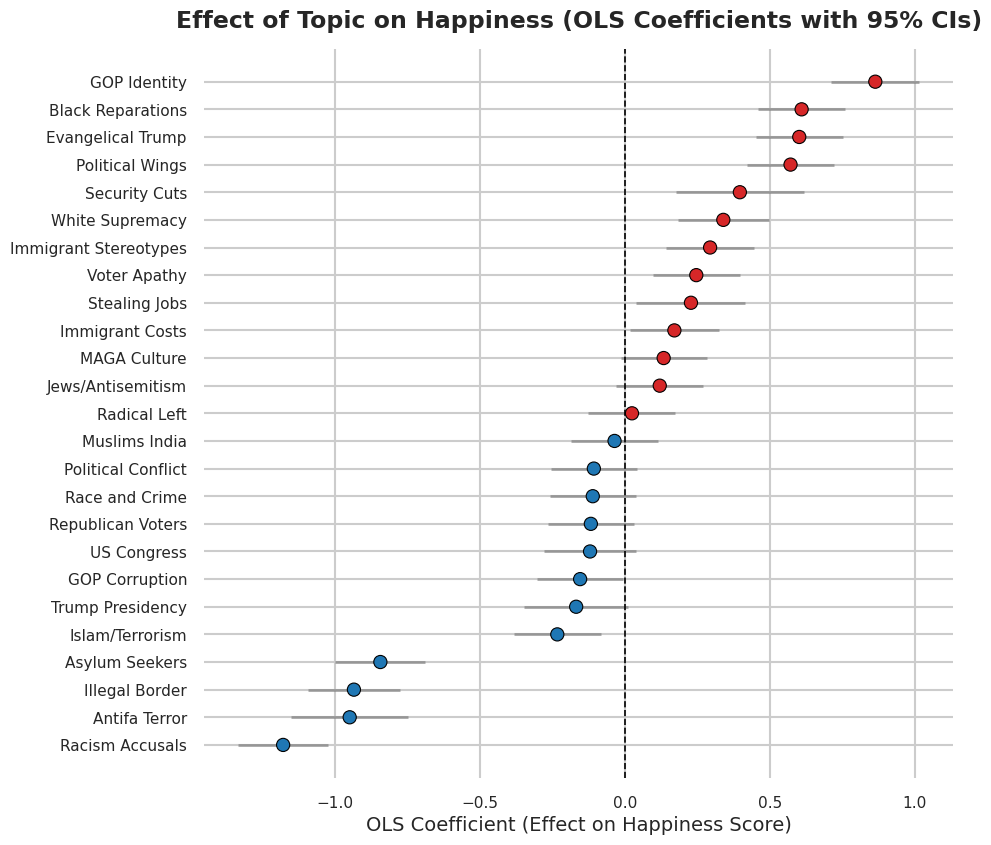

In [347]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------------
# 🧹 1. Prepare tidy coefficient table
# --------------------------------------------------
coef_table = pd.DataFrame({
    "Topic": [
        "Antifa Terror", "Asylum Seekers", "Black Reparations", "Evangelical Trump",
        "GOP Corruption", "GOP Identity", "Illegal Border", "Immigrant Costs",
        "Immigrant Stereotypes", "Islam/Terrorism", "Jews/Antisemitism", "MAGA Culture",
        "Muslims India", "Political Conflict", "Political Wings", "Race and Crime",
        "Racism Accusals", "Radical Left", "Republican Voters", "Security Cuts",
        "Stealing Jobs", "Trump Presidency", "US Congress", "Voter Apathy",
        "White Supremacy"
    ],
    "coef": [
        -0.9499, -0.8440, 0.6100, 0.6018,
        -0.1545, 0.8643, -0.9353, 0.1708,
        0.2941, -0.2333, 0.1203, 0.1338,
        -0.0357, -0.1072, 0.5717, -0.1109,
        -1.1796, 0.0244, -0.1175, 0.3968,
        0.2280, -0.1682, -0.1203, 0.2464,
        0.3397
    ],
    "lower": [
        -1.152, -0.999, 0.461, 0.452,
        -0.303, 0.713, -1.094, 0.017,
        0.143, -0.382, -0.029, -0.015,
        -0.185, -0.256, 0.422, -0.260,
        -1.334, -0.126, -0.266, 0.176,
        0.040, -0.347, -0.278, 0.096,
        0.182
    ],
    "upper": [
        -0.748, -0.689, 0.759, 0.752,
        -0.006, 1.016, -0.776, 0.325,
        0.445, -0.084, 0.269, 0.283,
        0.113, 0.042, 0.721, 0.038,
        -1.025, 0.174, 0.031, 0.618,
        0.416, 0.010, 0.037, 0.396,
        0.497
    ]
})

# Sort by coefficient
coef_table = coef_table.sort_values("coef", ascending=True)

# --------------------------------------------------
# 🎨 2. Plot styling
# --------------------------------------------------
sns.set_theme(style="whitegrid", context="talk", font_scale=1.05)
fig, ax = plt.subplots(figsize=(10, 9))

# Determine color by sign of coefficient
coef_table["color"] = coef_table["coef"].apply(lambda x: "#1f77b4" if x < 0 else "#d62728")

# Plot horizontal point estimates with CI
ax.hlines(y=coef_table["Topic"], xmin=coef_table["lower"], xmax=coef_table["upper"],
           color="gray", alpha=0.7, linewidth=2)
ax.scatter(coef_table["coef"], coef_table["Topic"],
           color=coef_table["color"], s=90, edgecolor="black", linewidth=0.8, zorder=3)

# Zero reference line
ax.axvline(0, color="black", lw=1.2, ls="--")

# --------------------------------------------------
# 🏷️ 3. Labels and style
# --------------------------------------------------
ax.set_xlabel("OLS Coefficient (Effect on Happiness Score)", fontsize=14)
ax.set_ylabel("")
ax.set_title("Effect of Topic on Happiness (OLS Coefficients with 95% CIs)", fontsize=17, pad=15, weight='bold')

# Ticks & grid style
ax.tick_params(axis="y", labelsize=11)
ax.tick_params(axis="x", labelsize=11)
sns.despine(left=True, bottom=True)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig("topic_effect_on_happiness_forestplot.pdf", dpi=400, bbox_inches="tight")
plt.show()


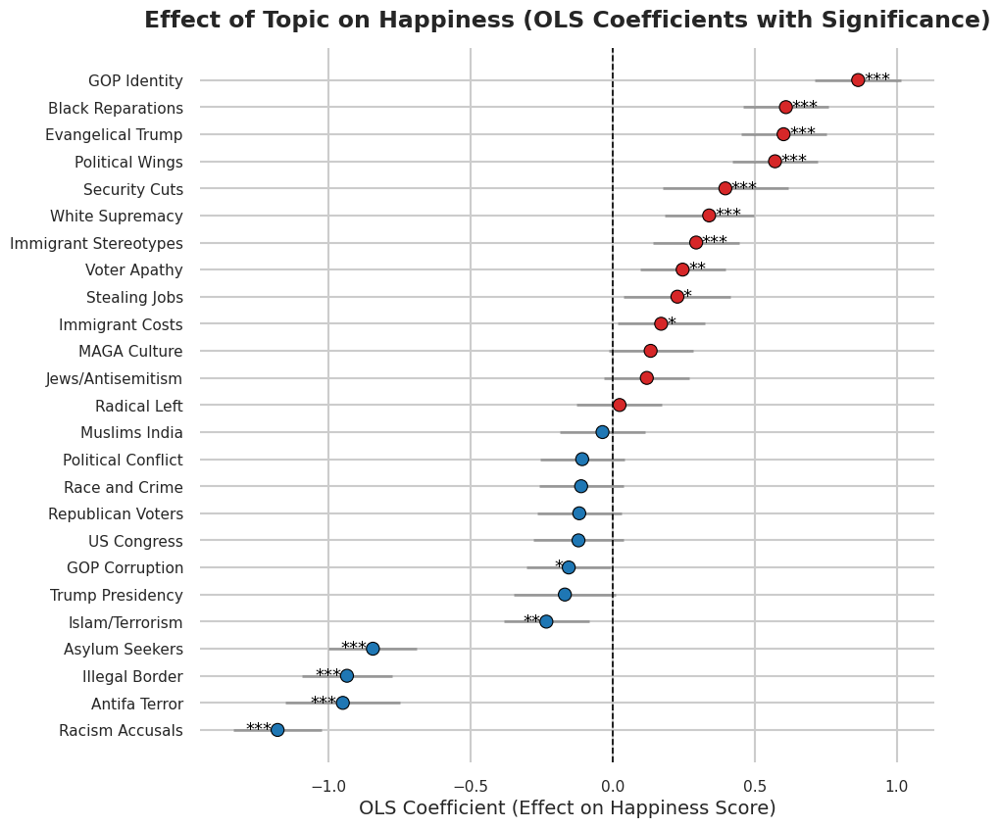

In [348]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --------------------------------------------------
# 🧹 1. Create coefficient dataframe (with p-values)
# --------------------------------------------------
coef_table = pd.DataFrame({
    "Topic": [
        "Antifa Terror", "Asylum Seekers", "Black Reparations", "Evangelical Trump",
        "GOP Corruption", "GOP Identity", "Illegal Border", "Immigrant Costs",
        "Immigrant Stereotypes", "Islam/Terrorism", "Jews/Antisemitism", "MAGA Culture",
        "Muslims India", "Political Conflict", "Political Wings", "Race and Crime",
        "Racism Accusals", "Radical Left", "Republican Voters", "Security Cuts",
        "Stealing Jobs", "Trump Presidency", "US Congress", "Voter Apathy",
        "White Supremacy"
    ],
    "coef": [
        -0.9499, -0.8440, 0.6100, 0.6018,
        -0.1545, 0.8643, -0.9353, 0.1708,
        0.2941, -0.2333, 0.1203, 0.1338,
        -0.0357, -0.1072, 0.5717, -0.1109,
        -1.1796, 0.0244, -0.1175, 0.3968,
        0.2280, -0.1682, -0.1203, 0.2464,
        0.3397
    ],
    "lower": [
        -1.152, -0.999, 0.461, 0.452,
        -0.303, 0.713, -1.094, 0.017,
        0.143, -0.382, -0.029, -0.015,
        -0.185, -0.256, 0.422, -0.260,
        -1.334, -0.126, -0.266, 0.176,
        0.040, -0.347, -0.278, 0.096,
        0.182
    ],
    "upper": [
        -0.748, -0.689, 0.759, 0.752,
        -0.006, 1.016, -0.776, 0.325,
        0.445, -0.084, 0.269, 0.283,
        0.113, 0.042, 0.721, 0.038,
        -1.025, 0.174, 0.031, 0.618,
        0.416, 0.010, 0.037, 0.396,
        0.497
    ],
    "pval": [
        0.000, 0.000, 0.000, 0.000,
        0.042, 0.000, 0.000, 0.030,
        0.000, 0.002, 0.113, 0.078,
        0.639, 0.158, 0.000, 0.144,
        0.000, 0.750, 0.122, 0.000,
        0.017, 0.065, 0.134, 0.001,
        0.000
    ]
})

# --------------------------------------------------
# ⭐ 2. Add significance stars
# --------------------------------------------------
def get_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""

coef_table["stars"] = coef_table["pval"].apply(get_stars)

# Sort by coefficient for plot order
coef_table = coef_table.sort_values("coef", ascending=True)

# --------------------------------------------------
# 🎨 3. Plot styling
# --------------------------------------------------
sns.set_theme(style="whitegrid", context="talk", font_scale=1.05)
fig, ax = plt.subplots(figsize=(10, 9))

# Color by sign
coef_table["color"] = coef_table["coef"].apply(lambda x: "#1f77b4" if x < 0 else "#d62728")

# Plot horizontal lines (CIs)
ax.hlines(y=coef_table["Topic"], xmin=coef_table["lower"], xmax=coef_table["upper"],
           color="gray", alpha=0.7, linewidth=2)

# Plot coefficient points
ax.scatter(coef_table["coef"], coef_table["Topic"],
           color=coef_table["color"], s=90, edgecolor="black", linewidth=0.8, zorder=3)

# Add significance stars next to points
for _, row in coef_table.iterrows():
    ax.text(
        row["coef"] + (0.02 if row["coef"] >= 0 else -0.02),
        row["Topic"],
        row["stars"],
        fontsize=13,
        color="black",
        va="center",
        ha="left" if row["coef"] >= 0 else "right"
    )

# Zero reference line
ax.axvline(0, color="black", lw=1.2, ls="--")

# --------------------------------------------------
# 🏷️ 4. Labels and style
# --------------------------------------------------
ax.set_xlabel("OLS Coefficient (Effect on Happiness Score)", fontsize=14)
ax.set_ylabel("")
ax.set_title("Effect of Topic on Happiness (OLS Coefficients with Significance)", fontsize=17, pad=15, weight='bold')

# Ticks and clean up
ax.tick_params(axis="y", labelsize=11)
ax.tick_params(axis="x", labelsize=11)
sns.despine(left=True, bottom=True)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig("topic_effect_on_happiness_significance.pdf", dpi=400, bbox_inches="tight")
plt.show()


In [324]:
import pandas as pd
import statsmodels.formula.api as smf

# Ensure required columns exist
assert {'MappedGroup', 'Sentiment', 'Topic'}.issubset(df.columns), "Missing columns"

# Clean the dataframe
df = df.dropna(subset=['MappedGroup', 'Sentiment', 'Topic']).copy()

# Create binary variable for each topic (1 if tweet belongs to topic, else 0)
topics = df['Topic'].unique()

results = []

for topic in topics:
    df['is_topic'] = (df['Topic'] == topic).astype(int)

    # Fit OLS model: topic presence ~ MappedGroup + Sentiment
    model = smf.ols('is_topic ~ C(MappedGroup) + happiness_score', data=df).fit()

    # Collect coefficients
    coefs = model.params.reset_index()
    coefs.columns = ['Variable', 'Coefficient']
    coefs['Topic'] = topic

    results.append(coefs)

# Combine all into one dataframe
coef_df = pd.concat(results, ignore_index=True)

# Optional: clean categorical prefixes like C(MappedGroup)[T.X]
coef_df['Variable'] = coef_df['Variable'].str.replace('C\\(MappedGroup\\)\\[T\\.', 'Group_', regex=True)
coef_df['Variable'] = coef_df['Variable'].str.replace('C\\(Sentiment\\)\\[T\\.', 'Sentiment_', regex=True)
coef_df['Variable'] = coef_df['Variable'].str.replace('\\]', '', regex=True)

# View example
coef_df.head(20)


,Variable,Coefficient,Topic
0,Intercept,0.038873,GOP Corruption
1,Group_Conservatives,0.093546,GOP Corruption
2,Group_Immigrants,-0.020343,GOP Corruption
3,Group_Jews,-0.019847,GOP Corruption
4,Group_LGBTQ+,0.086958,GOP Corruption
5,Group_Liberals,0.007986,GOP Corruption
6,Group_Muslims,-0.042303,GOP Corruption
7,Group_Refugees,-0.039118,GOP Corruption
8,Sentiment_Neutral,0.002673,GOP Corruption
9,Sentiment_Supportive,0.074322,GOP Corruption


In [325]:
result

,Month,MappedGroup,Sentiment,Topic,happiness_score
101,2012-01,Black Americans,Discriminatory,Black Reparations,5.565000
971,2012-01,Black Americans,Discriminatory,Race and Crime,4.984615
1103,2012-01,Black Americans,Discriminatory,Racism Accusals,5.653333
1297,2012-01,Black Americans,Discriminatory,Republican Voters,5.053333
1691,2012-01,Black Americans,Discriminatory,White Supremacy,6.376000
...,...,...,...,...,...
13460,2022-10,Refugees,Supportive,Antifa Terror,5.085455
13528,2022-10,Refugees,Supportive,Asylum Seekers,5.722353
13529,2022-11,Refugees,Supportive,Asylum Seekers,5.665000
13580,2022-11,Refugees,Supportive,MAGA Culture,5.930000


In [328]:
topics = df['Topic'].unique()
r2_scores = []

results = []

for topic in topics:
    df['is_topic'] = (df['Topic'] == topic).astype(int)

    model = smf.ols('is_topic ~ C(MappedGroup)-1 ', data=df).fit()

    # Store R²
    r2_scores.append(model.rsquared)

    # Collect coefficients
    coefs = model.params.reset_index()
    coefs.columns = ['Variable', 'Coefficient']
    coefs['Topic'] = topic
    results.append(coefs)

# Combine all coefficients
coef_df = pd.concat(results, ignore_index=True)

# Compute average R²
avg_r2 = sum(r2_scores) / len(r2_scores)
print(f"Average R² across all topics: {avg_r2:.4f}")

Average R² across all topics: 0.1123


In [351]:
import pandas as pd
import statsmodels.formula.api as smf

topics = df['Topic'].unique()
r2_scores = []
results = []

for topic in topics:
    # Binary flag for this topic
    df['is_topic'] = (df['Topic'] == topic).astype(int)

    # Fit OLS: Topic presence ~ Group (no intercept)
    model = smf.ols('is_topic ~ C(MappedGroup) - 1', data=df).fit()

    # Store R²
    r2_scores.append(model.rsquared)

    # Collect coefficients and p-values
    coefs = pd.DataFrame({
        "Variable": model.params.index,
        "Coefficient": model.params.values,
        "P_value": model.pvalues.values
    })
    coefs["Topic"] = topic

    results.append(coefs)

# Combine all topics
coef_df = pd.concat(results, ignore_index=True)

# Compute average R²
avg_r2 = sum(r2_scores) / len(r2_scores)
print(f"Average R² across all topics: {avg_r2:.4f}")

# Display first few rows
print(coef_df.head())


Average R² across all topics: 0.1123
                          Variable  Coefficient        P_value           Topic
0  C(MappedGroup)[Black Americans]     0.045291  3.132696e-199  GOP Corruption
1    C(MappedGroup)[Conservatives]     0.132517   0.000000e+00  GOP Corruption
2       C(MappedGroup)[Immigrants]     0.019695   4.453873e-25  GOP Corruption
3             C(MappedGroup)[Jews]     0.019863   1.890111e-16  GOP Corruption
4           C(MappedGroup)[LGBTQ+]     0.163216   0.000000e+00  GOP Corruption


In [352]:
coef_df.to_csv("topic_cofficient.csv")

In [418]:
coef_df_clean['Topic'].unique()

array(['GOP Corruption', 'Evangelical Trump', 'Voter Apathy',
       'Republican Voters', 'MAGA Culture', 'Racism Accusals',
       'US Congress', 'Trump Presidency', 'GOP Identity',
       'Political Wings', 'Antifa Terror', 'White Supremacy',
       'Immigrant Stereotypes', 'Political Conflict', 'Jews/Antisemitism',
       'Illegal Border', 'Radical Left', 'Security Cuts',
       'Islam/Terrorism', 'Immigrant Costs', 'Race and Crime',
       'Muslims India', 'Black Reparations', 'Asylum Seekers',
       'Stealing Jobs'], dtype=object)

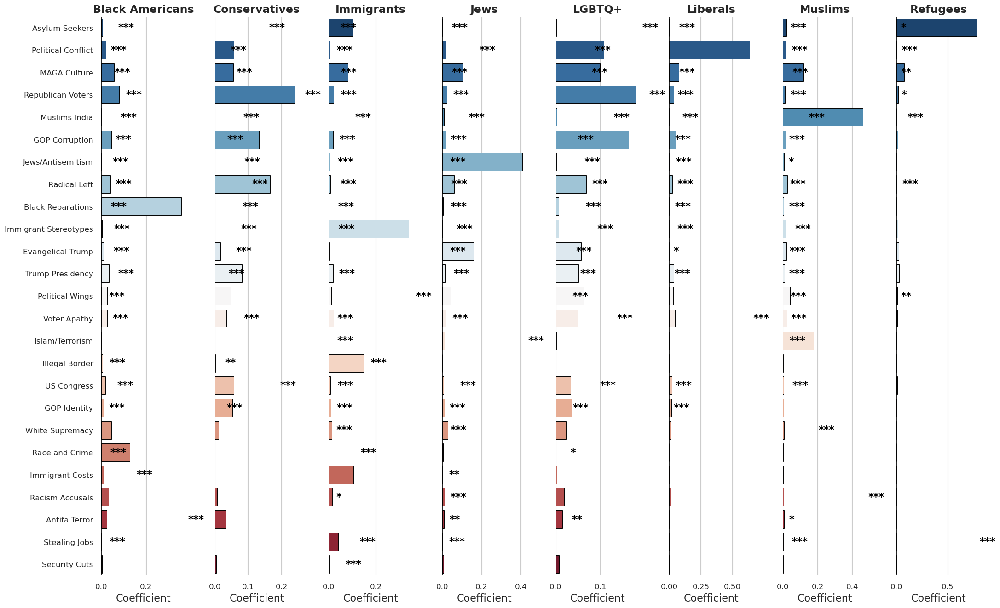

In [385]:
# import pandas as pd
# import seaborn as sns
# import matplotlib.pyplot as plt

# # -----------------------------
# # 🧹 1. Prepare Data
# # -----------------------------
# df_plot = coef_df_clean.copy()

# # Add significance stars
# def get_stars(p):
#     if p < 0.001:
#         return "***"
#     elif p < 0.01:
#         return "**"
#     elif p < 0.05:
#         return "*"
#     else:
#         return ""

# df_plot["stars"] = df_plot["P_value"].apply(get_stars)

# # Sort topics by mean coefficient for consistent order
# topic_order = (
#     df_plot.groupby("Topic")["Coefficient"].mean().sort_values(ascending=False).index
# )
# df_plot["Topic"] = pd.Categorical(df_plot["Topic"], categories=topic_order, ordered=True)

# # -----------------------------
# # 🎨 2. Plot setup (LARGE SCALE)
# # -----------------------------
# sns.set_theme(style="whitegrid", context="talk", font_scale=1.4)

# # Larger multi-panel layout
# g = sns.FacetGrid(
#     df_plot,
#     col="MappedGroup",
#     col_wrap=8,          # number of columns
#     sharex=False,
#     height=10.5,          # subplot height
#     aspect=1.4,          # width/height ratio
# )

# # -----------------------------
# # 📊 3. Plot bars + stars
# # -----------------------------
# def plot_bars(data, color=None, **kwargs):
#     ax = plt.gca()
#     sns.barplot(
#         data=data,
#         y="Topic",
#         x="Coefficient",
#         palette="RdBu_r",
#         edgecolor="black",
#         linewidth=0.7,
#         ax=ax,
#         **kwargs
#     )

#     # Add significance stars above each bar
#     for idx, row in enumerate(data.itertuples()):
#         if row.stars:
#             x = row.Coefficient
#             y = idx
#             offset = 0.02 * (ax.get_xlim()[1] - ax.get_xlim()[0])
#             ax.text(
#                 x + 0.03,
#                 y,
#                 row.stars,
#                 color="black",
#                 fontsize=16,
#                 fontweight="bold",
#                 va="center",
#                 ha="left" if x >= 0 else "right"
#             )

# g.map_dataframe(plot_bars)

# # -----------------------------
# # 🏷️ 4. Aesthetics
# # -----------------------------
# g.set_titles(col_template="{col_name}", size=17, weight="bold")
# g.set_xlabels("Coefficient", fontsize=16)
# g.set_ylabels("")

# for ax in g.axes.flat:
#     ax.axvline(0, color="black", lw=1.2)
#     ax.tick_params(axis="y", labelsize=12)
#     ax.tick_params(axis="x", labelsize=12)
#     sns.despine(ax=ax, left=True, bottom=True)

# plt.subplots_adjust(top=0.93, hspace=0.5, wspace=0.35)
# g.fig.set_size_inches(20, 15)   # <---- FULL FIGURE SIZE (width x height in inches)

# # Optional: Main title
# # g.fig.suptitle(
# #     "Group-wise Topic Coefficients with Significance Levels",
# #     fontsize=24,
# #     weight="bold",
# #     y=0.99,
# # )

# plt.savefig("facet_groupwise_topic_coefficients_large.pdf", dpi=400, bbox_inches="tight")
# plt.show()


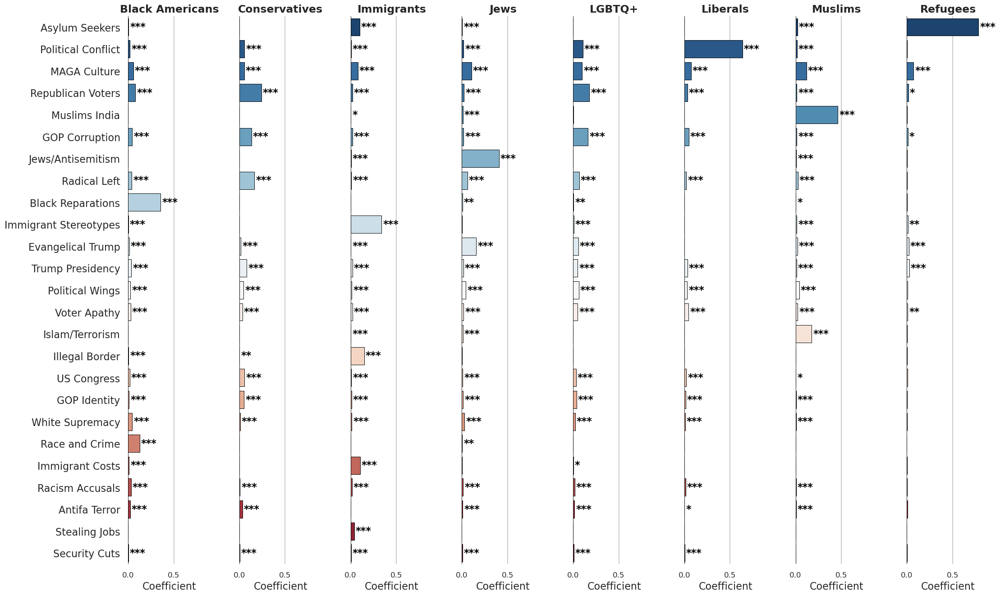

In [393]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -----------------------------
# 🧹 1. Prepare Data
# -----------------------------
df_plot = coef_df_clean.copy()

# Add significance stars
def get_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""

df_plot["stars"] = df_plot["P_value"].apply(get_stars)

# Sort topics by mean coefficient for consistent order
topic_order = (
    df_plot.groupby("Topic")["Coefficient"].mean().sort_values(ascending=False).index
)
df_plot["Topic"] = pd.Categorical(df_plot["Topic"], categories=topic_order, ordered=True)

# -----------------------------
# 🎨 2. Plot setup (LARGE SCALE)
# -----------------------------
sns.set_theme(style="whitegrid", context="talk", font_scale=1.4)

# Larger multi-panel layout
g = sns.FacetGrid(
    df_plot,
    col="MappedGroup",
    col_wrap=8,          # number of columns
    sharex=False,
    height=10.5,         # subplot height
    aspect=1.4,          # width/height ratio
)

# -----------------------------
# 📊 3. Plot bars + stars
# -----------------------------
def plot_bars(data, color=None, **kwargs):
    ax = plt.gca()
    
    # Sort data to match the topic order
    data_sorted = data.sort_values("Topic").reset_index(drop=True)
    
    # Create the barplot
    sns.barplot(
        data=data_sorted,
        y="Topic",
        x="Coefficient",
        palette="RdBu_r",
        edgecolor="black",
        linewidth=0.7,
        ax=ax,
        **kwargs
    )
    
    # Set x-axis limits to 0-0.9
    ax.set_xlim(0, 0.9)
    
    # Add significance stars - use simple indexing
    for i in range(len(data_sorted)):
        row = data_sorted.iloc[i]
        if row["stars"]:
            x_pos = row["Coefficient"]
            y_pos = i  # Bar index position
            
            # Place star just beyond the bar end
            ax.text(
                x_pos + 0.015,  # Slight offset from bar end
                y_pos,           # Y position (bar index)
                row["stars"],
                color="black",
                fontsize=16,
                fontweight="bold",
                va="center",
                ha="left"
            )

g.map_dataframe(plot_bars)

# -----------------------------
# 🏷️ 4. Aesthetics
# -----------------------------
g.set_titles(col_template="{col_name}", size=17, weight="bold")
g.set_xlabels("Coefficient", fontsize=16)
g.set_ylabels("")

for ax in g.axes.flat:
    ax.axvline(0, color="black", lw=1.2)
    ax.set_xlim(0, 0.9)  # Enforce 0-0.9 range on all subplots
    ax.tick_params(axis="y", labelsize=16)
    ax.tick_params(axis="x", labelsize=12)
    sns.despine(ax=ax, left=True, bottom=True)

plt.subplots_adjust(top=0.93, hspace=0.5, wspace=0.35)
g.fig.set_size_inches(20, 15)   # <---- FULL FIGURE SIZE (width x height in inches)

# Optional: Main title
# g.fig.suptitle(
#     "Group-wise Topic Coefficients with Significance Levels",
#     fontsize=24,
#     weight="bold",
#     y=0.99,
# )

plt.savefig("facet_groupwise_topic_coefficients_large.pdf", dpi=400, bbox_inches="tight")
plt.show()

<>:16: SyntaxWarning: invalid escape sequence '\('
<>:16: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_1298407/3129433572.py:16: SyntaxWarning: invalid escape sequence '\('
  coef_df_clean['Variable'].str.contains('C\(MappedGroup\)')


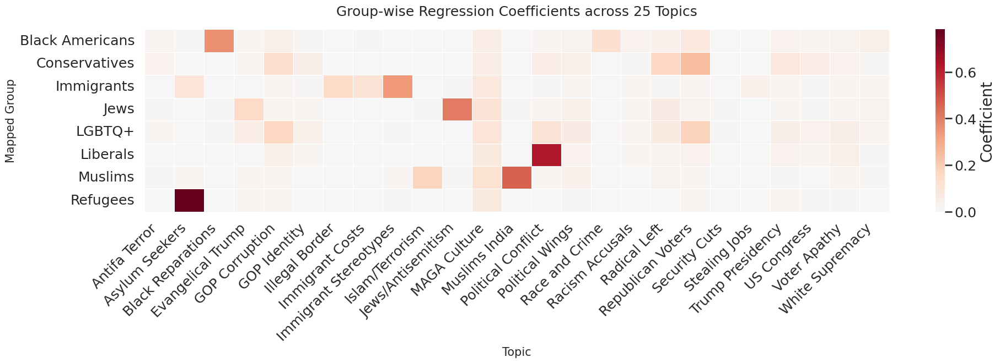

In [354]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -----------------------------------
# 🧹 Clean up the variable names
# -----------------------------------
coef_df_clean = coef_df.copy()
coef_df_clean['MappedGroup'] = (
    coef_df_clean['Variable']
    .str.extract(r'\[([^\]]+)\]')[0]       # extract text inside brackets [...]
)

# Filter only group-level variables
coef_df_clean = coef_df_clean[
    coef_df_clean['Variable'].str.contains('C\(MappedGroup\)')
].copy()

# Pivot to create matrix: rows=Group, cols=Topic, values=Coefficient
heatmap_data = coef_df_clean.pivot_table(
    index='MappedGroup',
    columns='Topic',
    values='Coefficient',
    fill_value=0
)

# -----------------------------------
# 🎨 Plot
# -----------------------------------
sns.set_theme(style="white", context="talk", font_scale=1.1)
plt.figure(figsize=(20, 7))

ax = sns.heatmap(
    heatmap_data,
    cmap='RdBu_r',        # red-blue reversed, red=positive, blue=negative
    center=0,
    linewidths=0.4,
    cbar_kws={'label': 'Coefficient'},
)

# Titles and labels
plt.title("Group-wise Regression Coefficients across 25 Topics", fontsize=18, pad=18)
plt.xlabel("Topic", fontsize=15)
plt.ylabel("Mapped Group", fontsize=15)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.savefig("groupwise_topic_coefficients_heatmap.pdf", dpi=400, bbox_inches="tight")
plt.show()


<>:11: SyntaxWarning: invalid escape sequence '\('
<>:11: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_1298407/3114231936.py:11: SyntaxWarning: invalid escape sequence '\('
  coef_df_clean = coef_df_clean[coef_df_clean['Variable'].str.contains('C\(MappedGroup\)')]


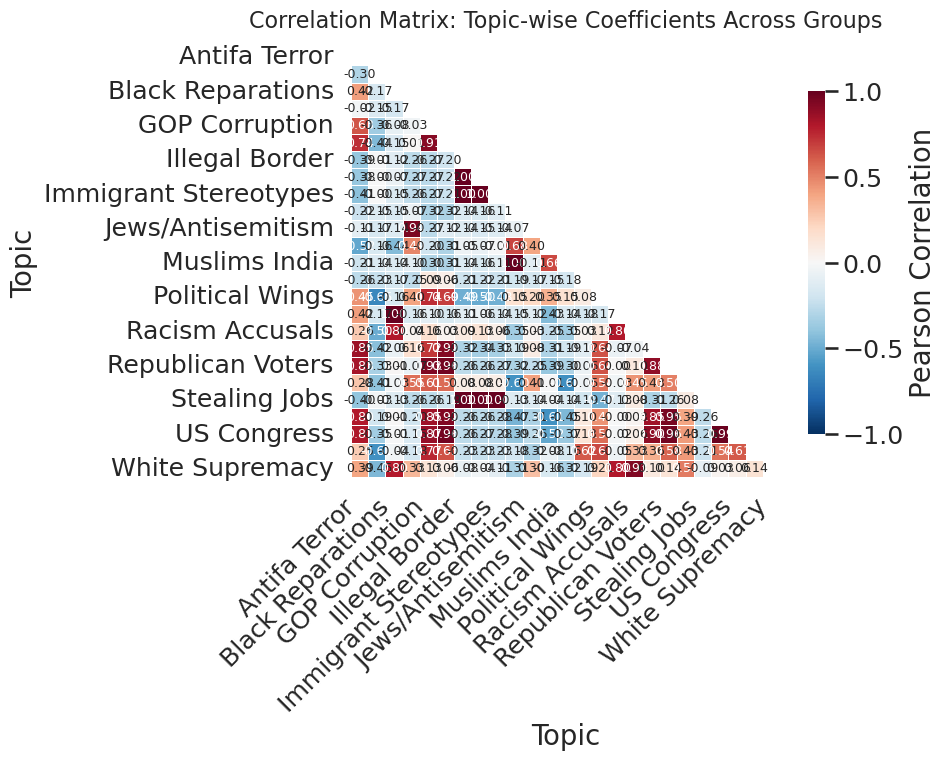

In [333]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# -------------------------------------------------------
# 1️⃣ Prepare the topic-group coefficient matrix
# -------------------------------------------------------
coef_df_clean = coef_df.copy()
coef_df_clean['MappedGroup'] = coef_df_clean['Variable'].str.extract(r'\[([^\]]+)\]')[0]
coef_df_clean = coef_df_clean[coef_df_clean['Variable'].str.contains('C\(MappedGroup\)')]

# Pivot into matrix form (Groups × Topics)
coef_matrix = coef_df_clean.pivot_table(
    index='MappedGroup',
    columns='Topic',
    values='Coefficient',
    fill_value=0
)

# Compute correlation between topics (or transpose for group correlation)
corr = coef_matrix.corr()   # Topic–Topic correlations

# -------------------------------------------------------
# 2️⃣ Create mask for upper triangle
# -------------------------------------------------------
mask = np.triu(np.ones_like(corr, dtype=bool))

# -------------------------------------------------------
# 3️⃣ Plot in paper-style
# -------------------------------------------------------
sns.set_theme(style="white", context="talk", font_scale=1.1)
plt.figure(figsize=(10, 8))

ax = sns.heatmap(
    corr,
    mask=mask,
    cmap='RdBu_r',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation"},
    annot=True, fmt=".2f",
    annot_kws={"size": 9}
)

plt.title("Correlation Matrix: Topic-wise Coefficients Across Groups", fontsize=16, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("topic_group_coefficient_correlation.pdf", dpi=400, bbox_inches="tight")
plt.show()


<>:11: SyntaxWarning: invalid escape sequence '\('
<>:11: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_1298407/2725513632.py:11: SyntaxWarning: invalid escape sequence '\('
  coef_df_clean = coef_df_clean[coef_df_clean['Variable'].str.contains('C\(MappedGroup\)')]


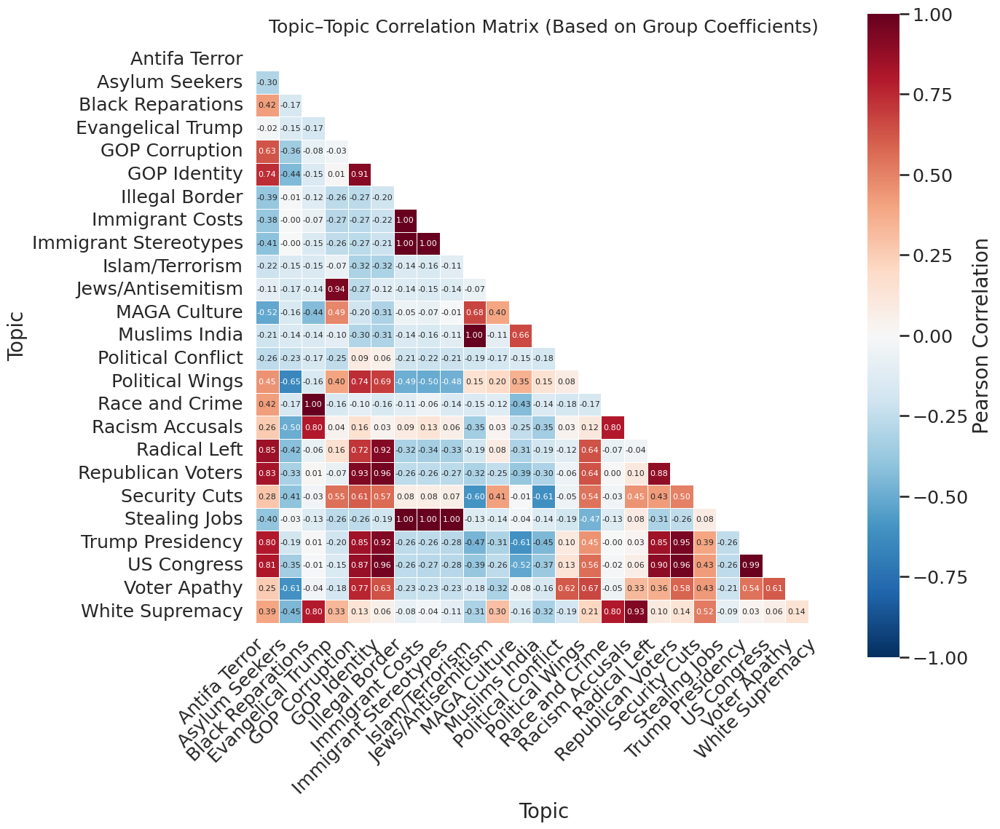

In [334]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# -------------------------------------------------------
# 1️⃣ Prepare topic × group coefficient matrix
# -------------------------------------------------------
coef_df_clean = coef_df.copy()
coef_df_clean['MappedGroup'] = coef_df_clean['Variable'].str.extract(r'\[([^\]]+)\]')[0]
coef_df_clean = coef_df_clean[coef_df_clean['Variable'].str.contains('C\(MappedGroup\)')]

# Pivot: rows = Topics, columns = Groups (for correlation across topics)
coef_matrix = coef_df_clean.pivot_table(
    index='Topic',
    columns='MappedGroup',
    values='Coefficient',
    fill_value=0
)

# -------------------------------------------------------
# 2️⃣ Compute topic–topic correlation
# -------------------------------------------------------
corr = coef_matrix.T.corr()   # correlation among topics based on group coefficients

# -------------------------------------------------------
# 3️⃣ Create mask for upper triangle (half-matrix style)
# -------------------------------------------------------
mask = np.triu(np.ones_like(corr, dtype=bool))

# -------------------------------------------------------
# 4️⃣ Plot in publication-quality style
# -------------------------------------------------------
sns.set_theme(style="white", context="talk", font_scale=1.1)
plt.figure(figsize=(14, 12))

ax = sns.heatmap(
    corr,
    mask=mask,
    cmap='RdBu_r',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    annot=True, fmt=".2f",
    annot_kws={"size": 8},
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title("Topic–Topic Correlation Matrix (Based on Group Coefficients)", fontsize=18, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("topic_topic_correlation_heatmap.pdf", dpi=400, bbox_inches="tight")
plt.show()


<>:13: SyntaxWarning: invalid escape sequence '\('
<>:13: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_1298407/2917323340.py:13: SyntaxWarning: invalid escape sequence '\('
  coef_df_clean['Variable'].str.contains('C\(MappedGroup\)')


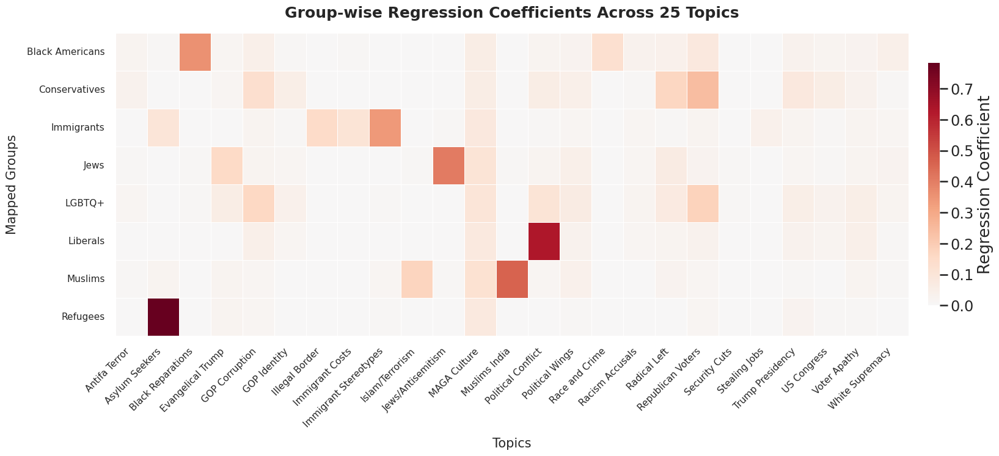

In [335]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -----------------------------------
# 🧹 Clean up variable names
# -----------------------------------
coef_df_clean = coef_df.copy()
coef_df_clean['MappedGroup'] = coef_df_clean['Variable'].str.extract(r'\[([^\]]+)\]')[0]

# Filter only group-level coefficients
coef_df_clean = coef_df_clean[
    coef_df_clean['Variable'].str.contains('C\(MappedGroup\)')
].copy()

# Pivot: rows = MappedGroup, cols = Topic, values = Coefficient
heatmap_data = coef_df_clean.pivot_table(
    index='MappedGroup',
    columns='Topic',
    values='Coefficient',
    fill_value=0
)

# -----------------------------------
# 🎨 Aesthetic settings (match reference style)
# -----------------------------------
sns.set_theme(style="white", context="talk", font_scale=1.05)

# Figure setup
fig, ax = plt.subplots(figsize=(18, 8))

# Heatmap
sns.heatmap(
    heatmap_data,
    cmap='RdBu_r',
    center=0,
    linewidths=0.4,
    linecolor='white',
    cbar_kws={
        'label': 'Regression Coefficient',
        'shrink': 0.8,
        'aspect': 20,
        'pad': 0.02
    },
    square=False,
    ax=ax
)

# -----------------------------------
# 🏷️ Titles and labels (same typography as correlation example)
# -----------------------------------
ax.set_title(
    "Group-wise Regression Coefficients Across 25 Topics",
    fontsize=18, pad=18, weight='bold'
)
ax.set_xlabel("Topics", fontsize=15, labelpad=10)
ax.set_ylabel("Mapped Groups", fontsize=15, labelpad=10)

# Rotate labels & remove extra clutter
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(rotation=0, fontsize=11)

# Clean border and grid aesthetic
sns.despine(left=True, bottom=True)
ax.figure.set_facecolor('white')

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig("groupwise_topic_coefficients_heatmap_styled.pdf", dpi=400, bbox_inches="tight")
plt.show()


<>:13: SyntaxWarning: invalid escape sequence '\('
<>:13: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_1298407/1737242070.py:13: SyntaxWarning: invalid escape sequence '\('
  coef_df_clean['Variable'].str.contains('C\(MappedGroup\)')


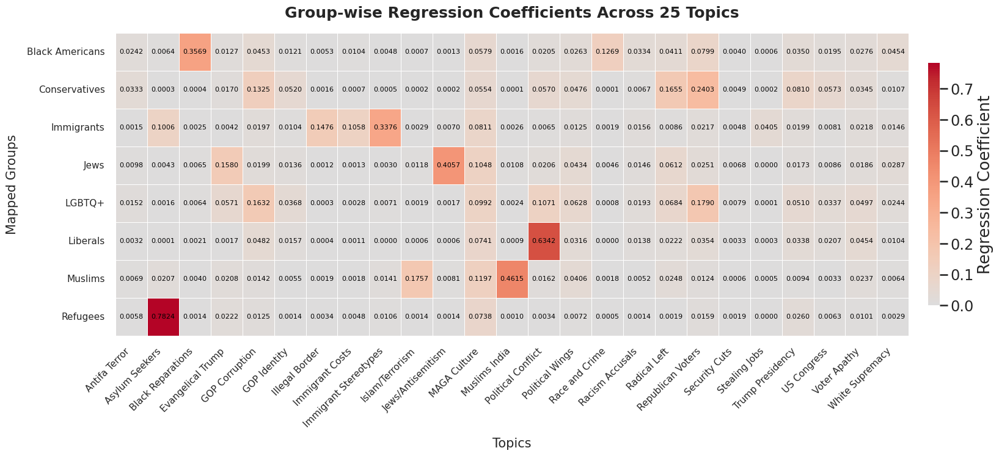

In [338]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -----------------------------------
# 🧹 Clean up variable names
# -----------------------------------
coef_df_clean = coef_df.copy()
coef_df_clean['MappedGroup'] = coef_df_clean['Variable'].str.extract(r'\[([^\]]+)\]')[0]

# Filter only group-level coefficients
coef_df_clean = coef_df_clean[
    coef_df_clean['Variable'].str.contains('C\(MappedGroup\)')
].copy()

# Pivot: rows = MappedGroup, cols = Topic, values = Coefficient
heatmap_data = coef_df_clean.pivot_table(
    index='MappedGroup',
    columns='Topic',
    values='Coefficient',
    fill_value=0
)

# -----------------------------------
# 🎨 Aesthetic settings (same layout, improved visuals)
# -----------------------------------
sns.set_theme(style="white", context="talk", font_scale=1.05)
fig, ax = plt.subplots(figsize=(18, 8))

# Heatmap
sns.heatmap(
    heatmap_data,
    cmap="coolwarm",         # 🔹 new palette: balanced and academic-friendly
    center=0,
    linewidths=0.4,
    linecolor='white',
    annot=True,              # 🔹 show numeric scores
    fmt=".4f",               # 🔹 two decimal places
    annot_kws={"size": 8, "color": "black"},  # 🔹 annotation style
    cbar_kws={
        'label': 'Regression Coefficient',
        'shrink': 0.8,
        'aspect': 20,
        'pad': 0.02
    },
    square=False,
    ax=ax
)

# -----------------------------------
# 🏷️ Titles and labels (keep same typography)
# -----------------------------------
ax.set_title(
    "Group-wise Regression Coefficients Across 25 Topics",
    fontsize=18, pad=18, weight='bold'
)
ax.set_xlabel("Topics", fontsize=15, labelpad=10)
ax.set_ylabel("Mapped Groups", fontsize=15, labelpad=10)

# Rotate labels & tidy look
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(rotation=0, fontsize=11)

# Clean border and grid aesthetic
sns.despine(left=True, bottom=True)
ax.figure.set_facecolor('white')

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig("groupwise_topic_coefficients_annotated.pdf", dpi=400, bbox_inches="tight")
plt.show()


In [394]:
## Osiometry

In [95]:
df = merged_df

In [96]:
df['TargetedGroup'].value_counts()

TargetedGroup
Conservatives      38917
Black Americans    37829
Immigrants         19989
LGBTQ+             13407
Muslims            12006
Jews               11527
Liberals            9736
Republicans         7328
Refugees            2222
Democrats            156
GOP                   23
BLM                   17
Magabros               9
Nazis                  7
Left                   5
ADOS                   5
Ahmadis                5
Hazara                 5
Israelites             4
Trump                  4
RINOs                  3
Uyghurs                3
Progressives           3
Uyghur                 3
Shia                   3
Rohingya               3
QAnon                  2
Israel                 2
Israelis               2
Neolibs                2
Foreigners             2
RightWingWatch         1
Gays                   1
Niggers                1
Ahmedis                1
TrumpSupporters        1
Nonbinary              1
LGTBQ                  1
Lesbians               1
Transgender

Lexicon: 19,868 words; dimensions: ['Goodness', 'Energy', 'Structure', 'Power', 'Danger']
NOTE: The lexicon contains Energy, not Aggression. Do NOT label Energy as Aggression without validating the source lexicon.
Removed 7,827 duplicate tweet-group rows
Using 145,419 tweets from 8 MappedGroup labels

YEARLY GROUP SCORES (first 16 rows):
    MappedGroup  year  n_tweets  lexicon_coverage  Goodness  Energy  Structure  Power  Danger
Black Americans  2012       321            0.2484    0.0398 -0.0243    -0.0123 0.0110 -0.0454
Black Americans  2013       364            0.2615    0.0399 -0.0108    -0.0165 0.0206 -0.0359
Black Americans  2014       450            0.2652    0.0346 -0.0174    -0.0177 0.0122 -0.0368
Black Americans  2015       685            0.2703    0.0304 -0.0108    -0.0239 0.0138 -0.0291
Black Americans  2016      1638            0.2787    0.0544  0.0020    -0.0190 0.0399 -0.0370
Black Americans  2017      3114            0.2798    0.0454 -0.0045    -0.0178 0.0289 -0.0353
Bl

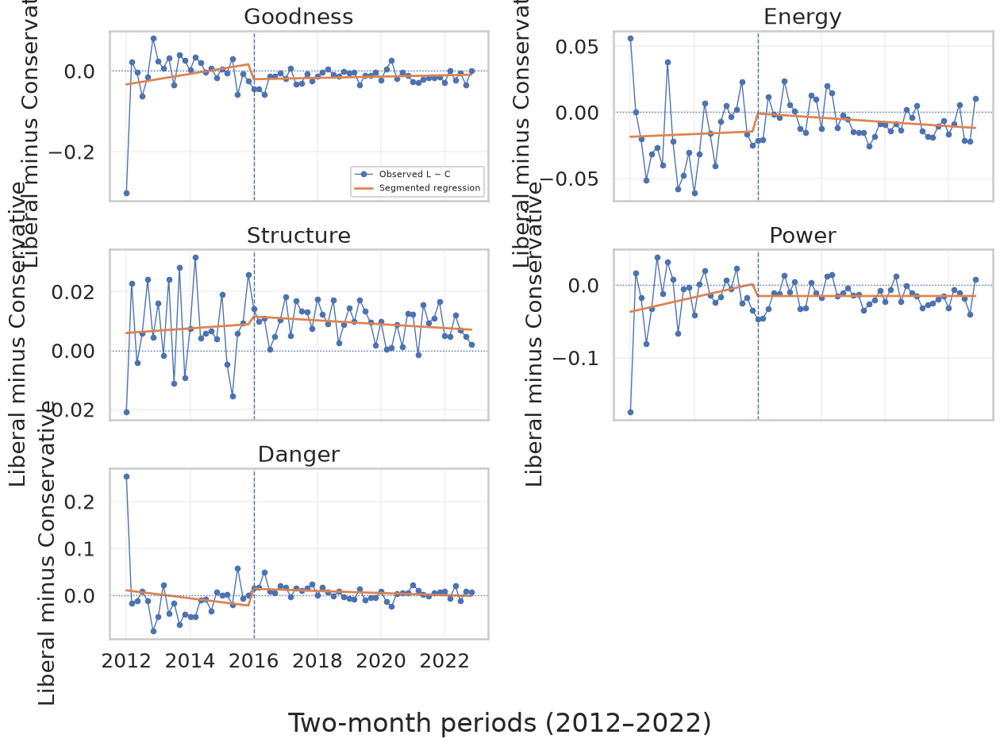


Finished. Review group scores, lexicon coverage, HAC mean gaps, segmented tests, and PDF figure.


In [97]:
"""Calculate lexicon-weighted ousiometric scores for every MappedGroup and year / two-month window,
then compare Liberal vs Conservative time series with HAC-robust statistical tests.

Run in the notebook with an existing DataFrame named `df`:
    %run -i rq2_mappedgroup_ousiometry_analysis.py

Requires: pip install pandas numpy scipy statsmodels matplotlib
Lexicon file: ousiometry_data (1).txt  (tab-delimited, columns word/term and dimensions)
"""
from collections import Counter
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

# -------------------- SETTINGS --------------------
LEXICON_PATH = Path("ousiometry_data (1).txt")
GROUP_COL = "MappedGroup"
TEXT_COL = "pure_text"
DATE_COL = "tweet_created_at"
GROUPS = ["Black Americans", "Conservatives", "Immigrants", "Jews",
          "LGBTQ+", "Liberals", "Muslims", "Refugees"]
CUTOFF = pd.Timestamp("2016-01-01")
HAC_LAGS = 3  # 3 two-month periods = 6 months
TOKEN = re.compile(r"[a-z]+")

# -------------------- LOAD AND VALIDATE LEXICON --------------------
if not LEXICON_PATH.exists():
    raise FileNotFoundError(f"Can't find {LEXICON_PATH}; change LEXICON_PATH to its correct location.")
lex_df = pd.read_csv(LEXICON_PATH, sep="\t", engine="python")
lex_df.columns = lex_df.columns.astype(str).str.strip().str.lower()
lex_df = lex_df.rename(columns={"term": "word"}) if "word" not in lex_df.columns else lex_df
if "word" not in lex_df.columns:
    raise ValueError(f"Lexicon needs a 'word' or 'term' column; found: {list(lex_df.columns)}")
# Energy is deliberately NOT renamed Aggression; do that only with a verified definition.
CANDIDATE_DIMS = ["goodness", "energy", "structure", "power", "danger", "aggression"]
raw_dims = [d for d in CANDIDATE_DIMS if d in lex_df.columns]
if not raw_dims:
    raise ValueError(f"No expected dimension columns found. Available: {list(lex_df.columns)}")
for d in raw_dims:
    lex_df[d] = pd.to_numeric(lex_df[d], errors="coerce")
lex_df["word"] = lex_df["word"].astype(str).str.lower().str.strip()
lex_df = lex_df[lex_df["word"].str.fullmatch(r"[a-z]+", na=False)].drop_duplicates("word")
lexicon = {r["word"]: {d: r[d] for d in raw_dims} for _, r in lex_df.iterrows()}
DIMS = [d.title() for d in raw_dims]
print(f"Lexicon: {len(lexicon):,} words; dimensions: {DIMS}")
if "energy" in raw_dims and "aggression" not in raw_dims:
    print("NOTE: The lexicon contains Energy, not Aggression. Do NOT label Energy as Aggression without validating the source lexicon.")

# -------------------- PREPARE EXISTING TWEETS --------------------
if "df" not in globals():
    raise ValueError("No DataFrame named df exists. Load your tweets into df before running this script.")
required = [GROUP_COL, TEXT_COL, DATE_COL]
missing = [x for x in required if x not in df.columns]
if missing:
    raise ValueError(f"Tweet DataFrame is missing: {missing}")
data = df.copy()
data["date"] = pd.to_datetime(data[DATE_COL], errors="coerce", utc=True).dt.tz_convert(None)
data = data.loc[data[GROUP_COL].isin(GROUPS) & data["date"].between("2012-01-01", "2022-12-31 23:59:59")].copy()
data[TEXT_COL] = data[TEXT_COL].fillna("").astype(str)
data = data.loc[data[TEXT_COL].str.strip().ne("")]
if "tweet_id" in data.columns:
    before = len(data)
    data = data.drop_duplicates(subset=["tweet_id", GROUP_COL])
    print(f"Removed {before - len(data):,} duplicate tweet-group rows")
if data.empty:
    raise ValueError("No tweets remain after group/date/text filtering.")
data["year"] = data["date"].dt.year
data["period"] = pd.to_datetime({
    "year": data["date"].dt.year,
    "month": ((data["date"].dt.month - 1) // 2) * 2 + 1,
    "day": 1
})
print(f"Using {len(data):,} tweets from {data[GROUP_COL].nunique()} MappedGroup labels")

# -------------------- FREQUENCY-WEIGHTED CORPUS SCORES --------------------
def score_corpus(texts):
    """Mean over ALL covered token occurrences, NOT mean of tweet means.
    Missing dimension values are not imputed as 0.5.
    """
    counts = Counter()
    for text in texts:
        counts.update(TOKEN.findall(text.lower()))
    n_tokens = sum(counts.values())
    matched = [(w, n, lexicon[w]) for w, n in counts.items() if w in lexicon]
    result = {
        "n_tokens": n_tokens,
        "n_lexicon_tokens": sum(n for w, n, row in matched),
    }
    result["lexicon_coverage"] = (result["n_lexicon_tokens"] / n_tokens if n_tokens else np.nan)
    for raw_dim in raw_dims:
        valid = [(n, row[raw_dim]) for _, n, row in matched if pd.notna(row[raw_dim])]
        denom = sum(n for n, _ in valid)
        result[raw_dim.title()] = (sum(n * value for n, value in valid) / denom if denom else np.nan)
        result[f"n_covered_{raw_dim}"] = denom
    return result


def aggregate_scores(group_columns):
    rows = []
    for keys, block in data.groupby(group_columns, sort=True):
        if not isinstance(keys, tuple):
            keys = (keys,)
        row = dict(zip(group_columns, keys))
        row["n_tweets"] = len(block)
        row.update(score_corpus(block[TEXT_COL]))
        rows.append(row)
    return pd.DataFrame(rows).sort_values(group_columns).reset_index(drop=True)

yearly = aggregate_scores([GROUP_COL, "year"])
bimonthly = aggregate_scores([GROUP_COL, "period"])
yearly.to_csv("ousiometry_mappedgroup_yearwise.csv", index=False)
bimonthly.to_csv("ousiometry_mappedgroup_2month.csv", index=False)
print("\nYEARLY GROUP SCORES (first 16 rows):")
print(yearly[[GROUP_COL, "year", "n_tweets", "lexicon_coverage", *DIMS]].head(16).round(4).to_string(index=False))
print("\nSaved: ousiometry_mappedgroup_yearwise.csv and ousiometry_mappedgroup_2month.csv")

# -------------------- MATCHED LIBERAL-CONSERVATIVE DIFFERENCES --------------------
political = bimonthly[bimonthly[GROUP_COL].isin(["Liberals", "Conservatives"])].copy()
paired = None
for dim in DIMS:
    wide = political.pivot(index="period", columns=GROUP_COL, values=dim)
    if not {"Liberals", "Conservatives"}.issubset(wide.columns):
        raise ValueError("Need both Liberals and Conservatives in MappedGroup")
    difference = (wide["Liberals"] - wide["Conservatives"]).rename(dim)
    paired = difference.to_frame() if paired is None else paired.join(difference)
paired = paired.sort_index()
paired.to_csv("rq2_mappedgroup_paired_gaps.csv", index_label="period")

# -------------------- HAC MEAN GAP + SEGMENTED TIME-SERIES --------------------
mean_results = []
break_results = []
fit_curves = {}

def fdr_column(pvalues):
    ps = pd.to_numeric(pd.Series(pvalues), errors="coerce").to_numpy(dtype=float)
    out = np.full(len(ps), np.nan)
    m = np.isfinite(ps)
    if m.any():
        out[m] = multipletests(ps[m], method="fdr_bh")[1]
    return out

for dim in DIMS:
    series = paired[dim].dropna()
    if len(series) < 24:
        warnings.warn(f"Skipping {dim}: only {len(series)} paired two-month windows; require >=24")
        continue
    # Mean gap across paired windows; equal weight per window.
    y = series.to_numpy(dtype=float)
    avg = sm.OLS(y, np.ones((len(y), 1))).fit(
        cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS}
    )
    ci = np.asarray(avg.conf_int())[0]
    mean_results.append({
        "dimension": dim, "paired_windows": len(series),
        "mean_L_minus_C": float(avg.params[0]),
        "CI_lower": float(ci[0]), "CI_upper": float(ci[1]),
        "p_value": float(avg.pvalues[0]),
    })
    # Segmented model, boundary Jan 2016.
    t = (series.index.year - 2012) + (series.index.month - 1) / 12.0
    t_break = 4.0  # Jan 2016 relative to Jan 2012
    post = (series.index >= CUTOFF).astype(float)
    after = np.maximum(t.to_numpy() - t_break, 0.0)
    X = np.column_stack([np.ones(len(y)), t.to_numpy(), post, after])
    if post.sum() < 10 or (1 - post).sum() < 10:
        warnings.warn(f"Skipping segmented comparison for {dim}: too few windows on one side")
        continue
    reg = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
    fit_curves[dim] = pd.Series(reg.predict(X), index=series.index)
    for idx, term in [(1, "pre2016_slope_per_year"), (2, "2016_level_change"),
                      (3, "post2016_slope_change_per_year")]:
        lo, hi = np.asarray(reg.conf_int())[idx]
        break_results.append({
            "dimension": dim, "term": term,
            "estimate": float(reg.params[idx]),
            "CI_lower": float(lo), "CI_upper": float(hi),
            "p_value": float(reg.pvalues[idx]),
            "paired_windows": len(series),
        })

mean_df = pd.DataFrame(mean_results)
if not mean_df.empty:
    mean_df["p_fdr"] = fdr_column(mean_df["p_value"])
    mean_df.to_csv("rq2_mappedgroup_mean_gaps_HAC.csv", index=False)
    print("\nLIBERAL MINUS CONSERVATIVE MEAN GAPS (HAC):")
    print(mean_df.round(5).to_string(index=False))

seg_df = pd.DataFrame(break_results)
if not seg_df.empty:
    seg_df["p_fdr_within_term"] = np.nan
    for term in seg_df["term"].unique():
        mask = seg_df["term"].eq(term)
        seg_df.loc[mask, "p_fdr_within_term"] = fdr_column(seg_df.loc[mask, "p_value"])
    seg_df.to_csv("rq2_mappedgroup_segmented_2016_HAC.csv", index=False)
    print("\nSEGMENTED 2016 GAP MODEL (HAC):")
    print(seg_df.round(5).to_string(index=False))

# -------------------- PLOT --------------------
if DIMS:
    cols = 2
    rows = int(np.ceil(len(DIMS) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(13, rows * 3.2), sharex=True)
    axes = np.atleast_1d(axes).ravel()
    for ax, dim in zip(axes, DIMS):
        valid = paired[dim].dropna()
        ax.plot(valid.index, valid, marker=".", linewidth=1, label="Observed L − C")
        if dim in fit_curves:
            ax.plot(fit_curves[dim].index, fit_curves[dim], linewidth=2,
                    label="Segmented regression")
        ax.axhline(0, linestyle=":", linewidth=1)
        ax.axvline(CUTOFF, linestyle="--", linewidth=1)
        ax.set_title(dim)
        ax.set_ylabel("Liberal minus Conservative")
        ax.grid(alpha=0.2)
    for ax in axes[len(DIMS):]:
        ax.axis("off")
    axes[0].legend(fontsize=8)
    fig.supxlabel("Two-month periods (2012–2022)")
    fig.tight_layout()
    fig.savefig("rq2_mappedgroup_gaps.pdf", bbox_inches="tight")
    plt.show()

print("\nFinished. Review group scores, lexicon coverage, HAC mean gaps, segmented tests, and PDF figure.")


In [93]:
import pandas as pd
import numpy as np
import re

# ---------- 1️⃣ Load Ousiometry Lexicon ----------
def load_ousiometry_lexicon(file_path):
    """Load ousiometry lexicon and return dictionary."""
    df_lexicon = pd.read_csv(file_path, sep='\t', engine='python')
    df_lexicon.columns = [c.lower() for c in df_lexicon.columns]

    lexicon_dict = {}
    for _, row in df_lexicon.iterrows():
        word = str(row.get('word', row.get('term', ''))).lower().strip()
        if not word:
            continue
        lexicon_dict[word] = {
            'goodness': row.get('goodness', 0.5),
            'energy': row.get('energy', 0.5),
            'structure': row.get('structure', 0.5),
            'power': row.get('power', 0.5),
            'danger': row.get('danger', 0.5)
        }
    print(f"✅ Loaded {len(lexicon_dict)} lexicon entries")
    return lexicon_dict


# ---------- 2️⃣ Compute Ousiometry for text ----------
def score_text_ousiometry(text, lexicon_dict):
    words = re.findall(r'\b[a-zA-Z]+\b', str(text).lower())
    scores = {'goodness': [], 'energy': [], 'structure': [], 'power': [], 'danger': []}

    for word in words:
        if word in lexicon_dict:
            for dim in scores.keys():
                scores[dim].append(lexicon_dict[word][dim])

    # Compute averages
    result = {dim: (np.mean(values) if len(values) > 0 else 0.5)
              for dim, values in scores.items()}
    return result


# ---------- 3️⃣ Year-wise aggregation ----------
def compute_yearwise_ousiometry(df, lexicon_dict):
    """
    Compute average Ousiometry dimension scores (goodness, energy, etc.)
    for each year in the dataframe.
    """
    yearly_data = []

    for year, group in df.groupby('year'):
        combined_text = ' '.join(group['pure_text'].astype(str))
        scores = score_text_ousiometry(combined_text, lexicon_dict)
        scores['year'] = year
        yearly_data.append(scores)

    df_yearly = pd.DataFrame(yearly_data)
    df_yearly = df_yearly.sort_values('year').reset_index(drop=True)
    return df_yearly


# ---------- 4️⃣ Example usage ----------
# path to ousiometry lexicon file
lexicon_path = "ousiometry_data (1).txt"

# Load lexicon
lexicon_dict = load_ousiometry_lexicon(lexicon_path)

# Example df (replace this with your real dataframe)
# df = pd.read_csv("your_data.csv")  # must have 'year' and 'pure_text'
# Example dummy:
# df = pd.DataFrame({
#     'year': [2020, 2020, 2021, 2021, 2022],
#     'pure_text': ["peace love unity", "battle rage", "growth strength", "fear chaos", "hope courage"]
# })

# Compute year-wise Ousiometry scores
df_yearwise = compute_yearwise_ousiometry(df, lexicon_dict)

# ---------- 5️⃣ Display ----------
print("\n===== Year-wise Ousiometry Averages =====")
print(df_yearwise.round(3))


✅ Loaded 20006 lexicon entries

===== Year-wise Ousiometry Averages =====
    goodness  energy  structure  power  danger  year
0      0.058  -0.004     -0.010  0.038  -0.044  2012
1      0.057   0.004     -0.012  0.043  -0.037  2013
2      0.054   0.003     -0.014  0.040  -0.036  2014
3      0.049   0.008     -0.015  0.040  -0.029  2015
4      0.061   0.014     -0.014  0.053  -0.033  2016
5      0.056   0.010     -0.017  0.047  -0.032  2017
6      0.062   0.010     -0.017  0.051  -0.037  2018
7      0.060   0.009     -0.020  0.049  -0.036  2019
8      0.062   0.014     -0.022  0.053  -0.034  2020
9      0.064   0.011     -0.021  0.053  -0.038  2021
10     0.067   0.011     -0.017  0.055  -0.039  2022


In [94]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from scipy.interpolate import make_interp_spline
import matplotlib.gridspec as gridspec
import seaborn as sns

def plot_yearly_ousiometry(df_yearwise, title="Yearly Ousiometry Trends", save_path=None):
    """
    Plot year-wise Ousiometry trajectories (Power vs Danger + five dimension subplots).
    Input DataFrame columns: ['year', 'goodness', 'energy', 'structure', 'power', 'danger']
    """

    df = df_yearwise.copy()
    df = df.sort_values('year').reset_index(drop=True)

    years = df['year'].astype(str).tolist()
    x = df['power'].values
    y = df['danger'].values

    # --------------------------
    # Smooth power–danger curve
    # --------------------------
    t = np.arange(len(x))
    if len(x) > 3:
        t_new = np.linspace(0, len(x) - 1, 200)
        spl_x = make_interp_spline(t, x, k=min(3, len(x)-1))
        spl_y = make_interp_spline(t, y, k=min(3, len(x)-1))
        x_smooth = spl_x(t_new)
        y_smooth = spl_y(t_new)
    else:
        x_smooth, y_smooth = x, y

    # Gradient line setup
    smooth_data = np.vstack((x_smooth, y_smooth)).T
    points = smooth_data.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    norm = plt.Normalize(0, len(smooth_data)-1)
    lc = LineCollection(segments, cmap='viridis', norm=norm)
    lc.set_array(np.arange(len(smooth_data)-1))
    lc.set_linewidth(3)

    # Colors for years
    color_times = np.arange(len(df))
    colormap = plt.get_cmap('viridis')
    color_norm = plt.Normalize(vmin=0, vmax=len(df) - 1)
    line_colors = colormap(color_norm(color_times))

    # --------------------------
    # Layout: 3x3 grid
    # --------------------------
    fig = plt.figure(figsize=(22, 18))
    gs = gridspec.GridSpec(3, 3, width_ratios=[1, 1, 1], height_ratios=[1, 1, 1],
                           wspace=0.32, hspace=0.32)

    # Common limits
    small_vars = ['goodness', 'energy', 'structure', 'power', 'danger']
    y_min = df[small_vars].min().min()
    y_max = df[small_vars].max().max()
    pad = 0.05 * (y_max - y_min)
    y_lo, y_hi = y_min - pad, y_max + pad

    # --------------------------
    # Main Power–Danger Plot
    # --------------------------
    ax_main = fig.add_subplot(gs[0:2, 0:2])
    ax_main.add_collection(lc)

    # Start & end markers
    ax_main.scatter(x[0], y[0], s=400, c='green', marker='o',
                    edgecolors='black', linewidths=3, zorder=10, label=f'Start ({years[0]})')
    ax_main.scatter(x[-1], y[-1], s=400, c='red', marker='s',
                    edgecolors='black', linewidths=3, zorder=10, label=f'End ({years[-1]})')

    # Label each year
    for i, (px, py, yr) in enumerate(zip(x, y, years)):
        ax_main.annotate(yr, (px, py), fontsize=12, ha='center', va='center',
                         color='white', fontweight='bold',
                         bbox=dict(boxstyle='circle,pad=0.3', facecolor=line_colors[i],
                                   edgecolor='white', linewidth=1.5))

    ax_main.set_xlabel(r'$\langle$Weak $\Leftrightarrow$ Powerful$\rangle$', fontsize=24)
    ax_main.set_ylabel(r'$\langle$Safe $\Leftrightarrow$ Dangerous$\rangle$', fontsize=24)
    ax_main.tick_params(axis='both', labelsize=18)
    ax_main.legend(loc='best', fontsize=15)
    ax_main.grid(True, linestyle='--', alpha=0.3)

    ax_main.set_title(f'{title}\n(Power–Danger Trajectory)', fontsize=28, fontweight='bold', pad=20)

    # Quadrant text
    xmid, ymid = np.mean(x), np.mean(y)
    xrng, yrng = (x.max()-x.min()), (y.max()-y.min())
    ax_main.text(xmid, y.max()+0.05*yrng, "dangerous", ha='center', fontsize=18)
    ax_main.text(xmid, y.min()-0.05*yrng, "safe", ha='center', fontsize=18)
    ax_main.text(x.min()-0.03*xrng, ymid, "weak", ha='right', fontsize=18, rotation=90)
    ax_main.text(x.max()+0.03*xrng, ymid, "powerful", ha='left', fontsize=18, rotation=-90)

    # --------------------------
    # Subplots for each dimension
    # --------------------------
    subplot_slots = [(0, 2), (1, 2), (2, 0), (2, 1), (2, 2)]
    subplot_vars = [
        ('goodness', r"[Bad$\Leftrightarrow$Good]", 'Gd'),
        ('energy', r"[Gentle$\Leftrightarrow$Aggressive]", 'Ag'),
        ('structure', r"[Structured$\Leftrightarrow$Unstructured]", 'St'),
        ('power', r"[Weak$\Leftrightarrow$Powerful]", 'Pw'),
        ('danger', r"[Safe$\Leftrightarrow$Dangerous]", 'Dg')
    ]

    for (row, col), (var, ylabel, boxlabel) in zip(subplot_slots, subplot_vars):
        ax = fig.add_subplot(gs[row, col])

        # Colored lines
        for j in range(len(df) - 1):
            ax.plot(df['year'].iloc[j:j+2], df[var].iloc[j:j+2],
                    color=line_colors[j], lw=3)
        ax.plot(df['year'], df[var], color='gray', alpha=0.3, lw=1.5)
        ax.scatter(df['year'], df[var], c=line_colors, s=100,
                   edgecolors='white', linewidths=1.5, zorder=5)

        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_xlabel("Year", fontsize=16)
        ax.tick_params(axis='both', labelsize=14)
        ax.text(0.02, 0.90, boxlabel, fontsize=16, transform=ax.transAxes,
                bbox=dict(boxstyle="square", fc="white", ec="black"))

        ax.grid(True, linestyle='--', alpha=0.2)
        ax.set_ylim(y_lo, y_hi)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight')
        print(f"\n✓ Saved: {save_path}")
    plt.show()


/tmp/ipykernel_453868/3414584176.py:130: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



✓ Saved: yearwise_ousiometry.pdf


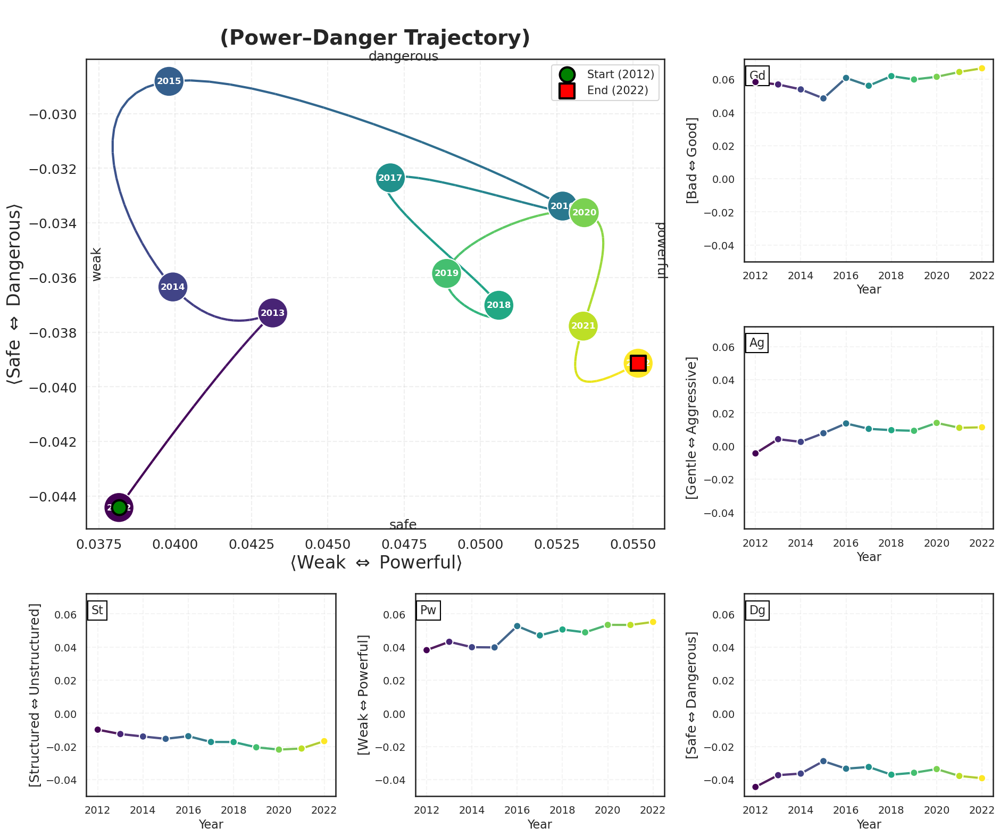

In [95]:
# assuming df_yearwise already computed
plot_yearly_ousiometry(df_yearwise, title="", save_path="yearwise_ousiometry.pdf")


✅ Loaded 20006 lexicon entries
🔹 Processing group: Black Americans
🔹 Processing group: Conservatives
🔹 Processing group: Immigrants
🔹 Processing group: Jews
🔹 Processing group: LGBTQ+
🔹 Processing group: Liberals
🔹 Processing group: Muslims
🔹 Processing group: Refugees


/tmp/ipykernel_453868/4129578898.py:161: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



✓ Saved comparative figure: Ousiometry_Comparison_Cons_Lib.pdf


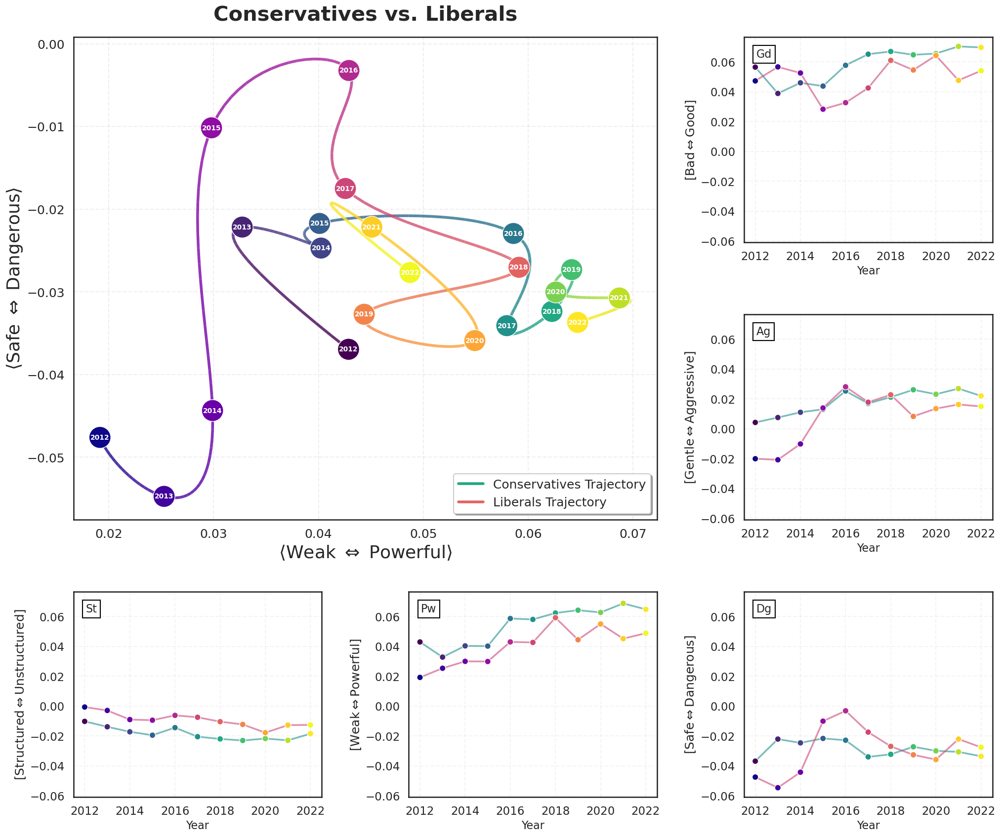

In [99]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.interpolate import make_interp_spline
import matplotlib.gridspec as gridspec

# ---------- 1️⃣ Load Ousiometry Lexicon ----------
def load_ousiometry_lexicon(file_path):
    df_lexicon = pd.read_csv(file_path, sep='\t', engine='python')
    df_lexicon.columns = [c.lower() for c in df_lexicon.columns]
    lexicon_dict = {}
    for _, row in df_lexicon.iterrows():
        word = str(row.get('word', row.get('term', ''))).lower().strip()
        if not word:
            continue
        lexicon_dict[word] = {
            'goodness': row.get('goodness', 0.5),
            'energy': row.get('energy', 0.5),
            'structure': row.get('structure', 0.5),
            'power': row.get('power', 0.5),
            'danger': row.get('danger', 0.5)
        }
    print(f"✅ Loaded {len(lexicon_dict)} lexicon entries")
    return lexicon_dict

# ---------- 2️⃣ Compute Ousiometry for text ----------
def score_text_ousiometry(text, lexicon_dict):
    words = re.findall(r'\b[a-zA-Z]+\b', str(text).lower())
    scores = {'goodness': [], 'energy': [], 'structure': [], 'power': [], 'danger': []}
    for word in words:
        if word in lexicon_dict:
            for dim in scores.keys():
                scores[dim].append(lexicon_dict[word][dim])
    result = {dim: (np.mean(values) if values else 0.5) for dim, values in scores.items()}
    return result

# ---------- 3️⃣ Compute Year-wise Ousiometry per Group ----------
def compute_groupwise_ousiometry(df, lexicon_dict):
    results = []
    for group, group_df in df.groupby('MappedGroup'):
        print(f"🔹 Processing group: {group}")
        for year, year_df in group_df.groupby('year'):
            combined_text = ' '.join(year_df['pure_text'].astype(str))
            scores = score_text_ousiometry(combined_text, lexicon_dict)
            scores['year'] = year
            scores['MappedGroup'] = group
            results.append(scores)
    df_groupwise = pd.DataFrame(results)
    df_groupwise = df_groupwise.sort_values(['MappedGroup', 'year']).reset_index(drop=True)
    return df_groupwise

# ---------- 4️⃣ Unified Comparison Plot Function ----------
# ---------- Updated Plot Function with Group-Based Legend ----------
def plot_comparative_ousiometry(df_groupwise, groups_to_compare, title="Comparative Ousiometry Trends", save_path=None):
    fig = plt.figure(figsize=(24, 20))
    gs = gridspec.GridSpec(3, 3, width_ratios=[1, 1, 1], height_ratios=[1, 1, 1],
                            wspace=0.35, hspace=0.35)

    # Main Power–Danger Plot
    ax_main = fig.add_subplot(gs[0:2, 0:2])
    
    configs = [
        (groups_to_compare[0], 'viridis', 'o'),  # Conservatives
        (groups_to_compare[1], 'plasma', 'D')    # Liberals
    ]

    small_vars = ['goodness', 'energy', 'structure', 'power', 'danger']
    y_min = df_groupwise[df_groupwise['MappedGroup'].isin(groups_to_compare)][small_vars].min().min()
    y_max = df_groupwise[df_groupwise['MappedGroup'].isin(groups_to_compare)][small_vars].max().max()
    pad = 0.05 * (y_max - y_min)
    y_lo, y_hi = y_min - pad, y_max + pad

    # List to store proxy artists for the legend
    legend_elements = []

    for group_name, cmap_name, marker in configs:
        df = df_groupwise[df_groupwise['MappedGroup'] == group_name].sort_values('year').copy()
        if df.empty: continue
        
        years = df['year'].astype(str).tolist()
        x, y = df['power'].values, df['danger'].values
        t = np.arange(len(x))
        
        if len(x) > 3:
            t_new = np.linspace(0, len(x) - 1, 200)
            spl_x = make_interp_spline(t, x, k=3)
            spl_y = make_interp_spline(t, y, k=3)
            x_smooth, y_smooth = spl_x(t_new), spl_y(t_new)
        else:
            x_smooth, y_smooth = x, y

        points = np.vstack((x_smooth, y_smooth)).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        norm = plt.Normalize(0, len(x_smooth)-1)
        lc = LineCollection(segments, cmap=cmap_name, norm=norm, alpha=0.8)
        lc.set_array(np.arange(len(x_smooth)-1))
        lc.set_linewidth(4)
        ax_main.add_collection(lc)

        # Get color for the legend proxy (using the middle color of the map)
        cmap = plt.get_cmap(cmap_name)
        mid_color = cmap(0.6)
        
        # Create a proxy line for this group's legend entry
        from matplotlib.lines import Line2D
        line_proxy = Line2D([0], [0], color=mid_color, lw=4, label=f'{group_name} Trajectory')
        legend_elements.append(line_proxy)

        line_colors = cmap(plt.Normalize(vmin=0, vmax=len(df)-1)(np.arange(len(df))))
        
        # Start/End points (no label here to keep legend clean)
        ax_main.scatter(x[0], y[0], s=350, c=[line_colors[0]], marker=marker, edgecolors='black', linewidths=2, zorder=12)
        ax_main.scatter(x[-1], y[-1], s=350, c=[line_colors[-1]], marker='X', edgecolors='black', linewidths=2, zorder=12)

        for i, (px, py, yr) in enumerate(zip(x, y, years)):
            ax_main.annotate(yr, (px, py), fontsize=10, ha='center', va='center',
                             color='white', fontweight='bold', zorder=15,
                             bbox=dict(boxstyle='circle,pad=0.2', facecolor=line_colors[i], edgecolor='white', linewidth=1))

    # Main axes styling
    ax_main.set_xlabel(r'$\langle$Weak $\Leftrightarrow$ Powerful$\rangle$', fontsize=26)
    ax_main.set_ylabel(r'$\langle$Safe $\Leftrightarrow$ Dangerous$\rangle$', fontsize=26)
    ax_main.tick_params(axis='both', labelsize=18)
    
    # Add the custom legend with the group proxies
    ax_main.legend(handles=legend_elements, loc='lower right', fontsize=18, frameon=True, shadow=True)
    
    ax_main.grid(True, linestyle='--', alpha=0.3)
    ax_main.set_title(title, fontsize=30, fontweight='bold', pad=25)

    # [Subplots logic remains identical to the previous snippet...]

    # Subplots for individual dimensions
    subplot_slots = [(0, 2), (1, 2), (2, 0), (2, 1), (2, 2)]
    subplot_vars = [
        ('goodness', r"[Bad$\Leftrightarrow$Good]", 'Gd'),
        ('energy', r"[Gentle$\Leftrightarrow$Aggressive]", 'Ag'),
        ('structure', r"[Structured$\Leftrightarrow$Unstructured]", 'St'),
        ('power', r"[Weak$\Leftrightarrow$Powerful]", 'Pw'),
        ('danger', r"[Safe$\Leftrightarrow$Dangerous]", 'Dg')
    ]

    for (row, col), (var, ylabel, boxlabel) in zip(subplot_slots, subplot_vars):
        ax = fig.add_subplot(gs[row, col])
        for group_name, cmap_name, marker in configs:
            sub = df_groupwise[df_groupwise['MappedGroup'] == group_name].sort_values('year')
            cmap = plt.get_cmap(cmap_name)
            colors = cmap(plt.Normalize(vmin=0, vmax=len(sub)-1)(np.arange(len(sub))))
            
            ax.plot(sub['year'], sub[var], color=colors[len(sub)//2], lw=2.5, alpha=0.6, label=group_name)
            ax.scatter(sub['year'], sub[var], c=colors, s=80, edgecolors='white', linewidths=1, zorder=5)
            
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_xlabel("Year", fontsize=16)
        ax.text(0.05, 0.90, boxlabel, fontsize=16, transform=ax.transAxes, bbox=dict(boxstyle="square", fc="white", ec="black"))
        ax.set_ylim(y_lo, y_hi)
        ax.grid(True, linestyle='--', alpha=0.2)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight')
        print(f"\n✓ Saved comparative figure: {save_path}")
    plt.show()

# ---------- 5️⃣ Execution ----------
lexicon_path = "ousiometry_data (1).txt"
lexicon_dict = load_ousiometry_lexicon(lexicon_path)

# Assuming 'df' is your pre-loaded dataframe containing 'MappedGroup', 'year', 'pure_text'
df_groupwise = compute_groupwise_ousiometry(df, lexicon_dict)

# Filter for Conservatives and Liberals and plot together
target_groups = ["Conservatives", "Liberals"]
plot_comparative_ousiometry(
    df_groupwise, 
    target_groups, 
    title="Conservatives vs. Liberals",
    save_path="Ousiometry_Comparison_Cons_Lib.pdf"
)

In [107]:
# ---------- Ousiometric Story Extractor (2012–2022) ----------

def print_ousiometric_narrative_data(df, df_groupwise):
    """
    Prints yearly ousiometric scores and a substantive sample of 
    associated tweets for Conservatives and Liberals.
    """
    targets = ["Conservatives", "Liberals"]
    
    for group in targets:
        print(f"\n{'='*40} {group.upper()} {'='*40}")
        
        # Get yearly scores from your groupwise dataframe
        group_scores = df_groupwise[df_groupwise['MappedGroup'] == group].sort_values('year')
        
        for _, row in group_scores.iterrows():
            year = int(row['year'])
            print(f"\n[YEAR: {year}]")
            print(f"Scores -> Power: {row['power']:.4f} | Danger: {row['danger']:.4f} | "
                  f"Good: {row['goodness']:.4f} | Energy: {row['energy']:.4f} | Structure: {row['structure']:.4f}")
            
            # Extract and print a substantive block of associated tweets (>500 chars)
            # We concatenate the top tweets from this window to ensure the "story" context is deep
            year_tweets = df[(df['MappedGroup'] == group) & (df['year'] == year)]['pure_text'].astype(str)
            
            # Combine tweets until we hit at least 500 characters
            combined_context = ""
            for tweet in year_tweets:
                combined_context += tweet + " | "
                # if len(combined_context) > 500:
                #     break
            
            print(f"Discourse Context (>500 chars):\n{combined_context[:20000]}...") # Truncated at 800 for readability
            print("-" * 100)

# Execute the extraction
print_ousiometric_narrative_data(df, df_groupwise)


======================================== CONSERVATIVES ========================================

[YEAR: 2012]
Scores -> Power: 0.0429 | Danger: -0.0369 | Good: 0.0564 | Energy: 0.0042 | Structure: -0.0103
Discourse Context (>500 chars):
RT @jessejames375: @WhirlwindWisdom @stiNgo100 The Republicans are beyond bizarre | RT @DylanByers: RT @RyanLizza: This picture sums up how a lot of Republicans are feeling this week. http://t.co/GOzf3UkT | RT @Nupe117: @SenatorReid fix the nomination process! #Imperative GOP is not permitted to obstruct! | RT @YooHomie_: Republicans are simple-minded, power driven people. | These republicans are gonna be mad they coming here and its about to be a damn hurricane lol | Things Are So Bad For Romney, Republicans Are Letting Him Tout RomneyCare http://t.co/7wy5QLTy | RT @moronwatch: Five more reasons why the Republicans are morons http://t.co/rg575oDF via @iludiumphosdex | RT @ThisMalikS: Republicans are against abortion until their mistress gets pregnant 

✅ Loaded 20006 lexicon entries

🔹 Processing group: Black Americans

🔹 Processing group: Conservatives

🔹 Processing group: Immigrants

🔹 Processing group: Jews

🔹 Processing group: LGBTQ+

🔹 Processing group: Liberals

🔹 Processing group: Muslims

🔹 Processing group: Refugees

📊 Plotting for group: Black Americans

✓ Saved: Ousiometry_Black_Americans.pdf


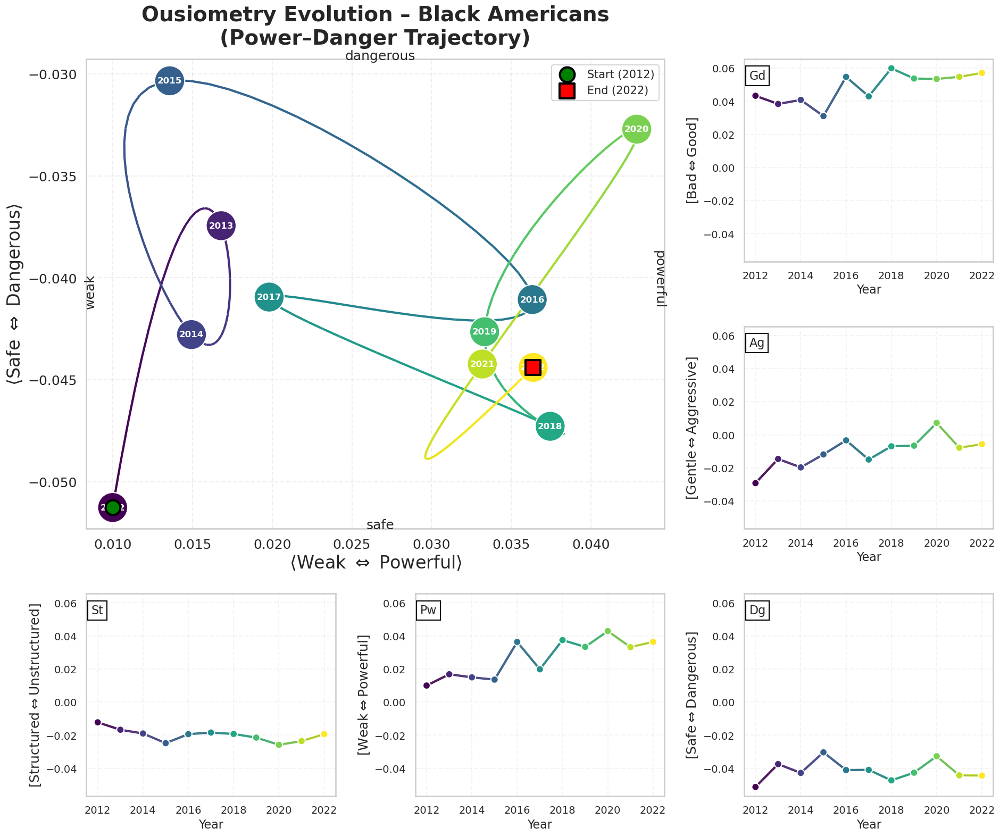


📊 Plotting for group: Conservatives

✓ Saved: Ousiometry_Conservatives.pdf


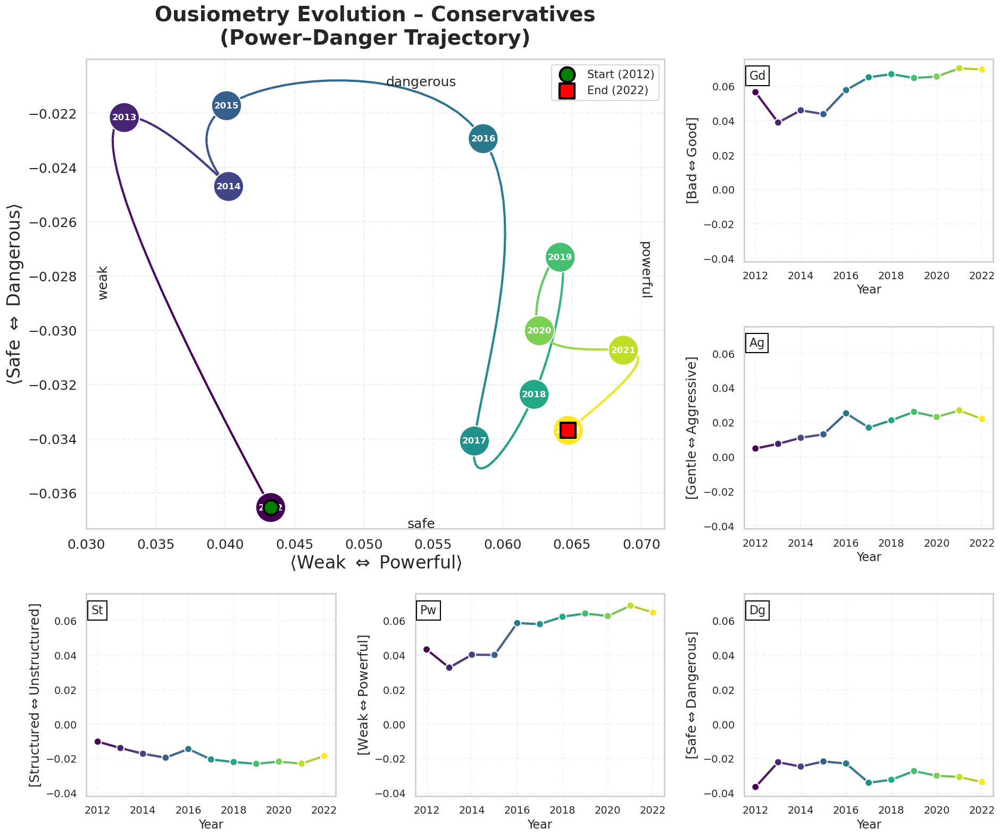


📊 Plotting for group: Immigrants

✓ Saved: Ousiometry_Immigrants.pdf


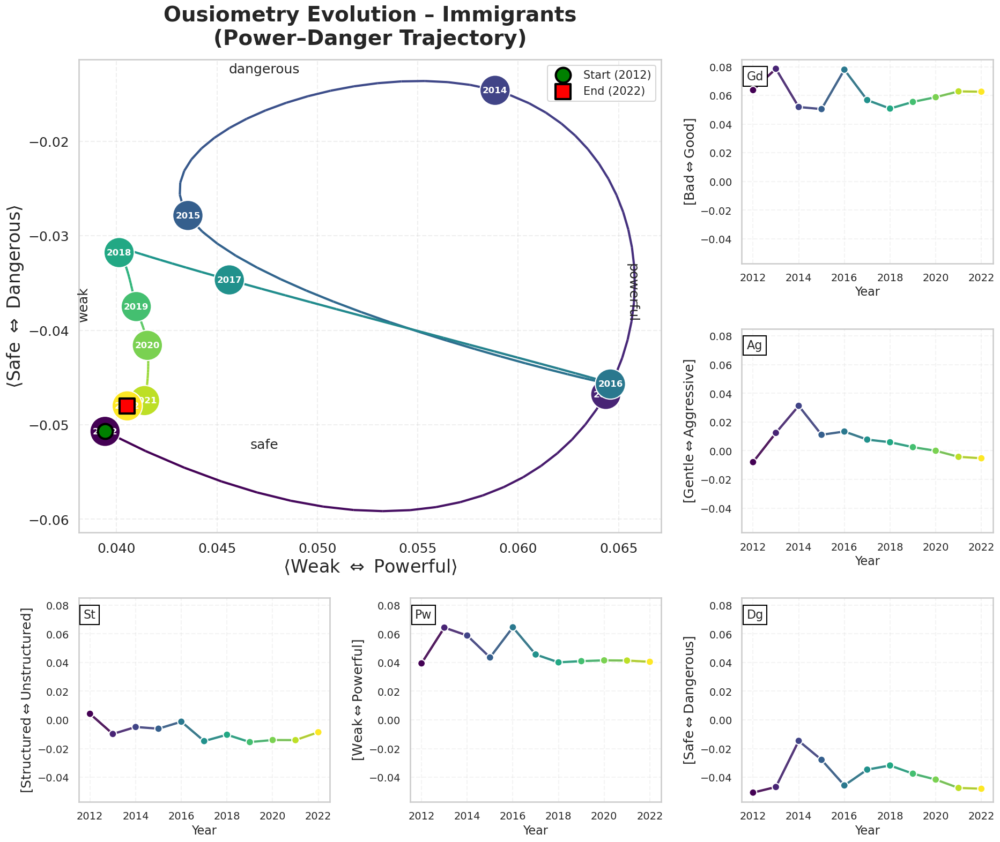


📊 Plotting for group: Jews

✓ Saved: Ousiometry_Jews.pdf


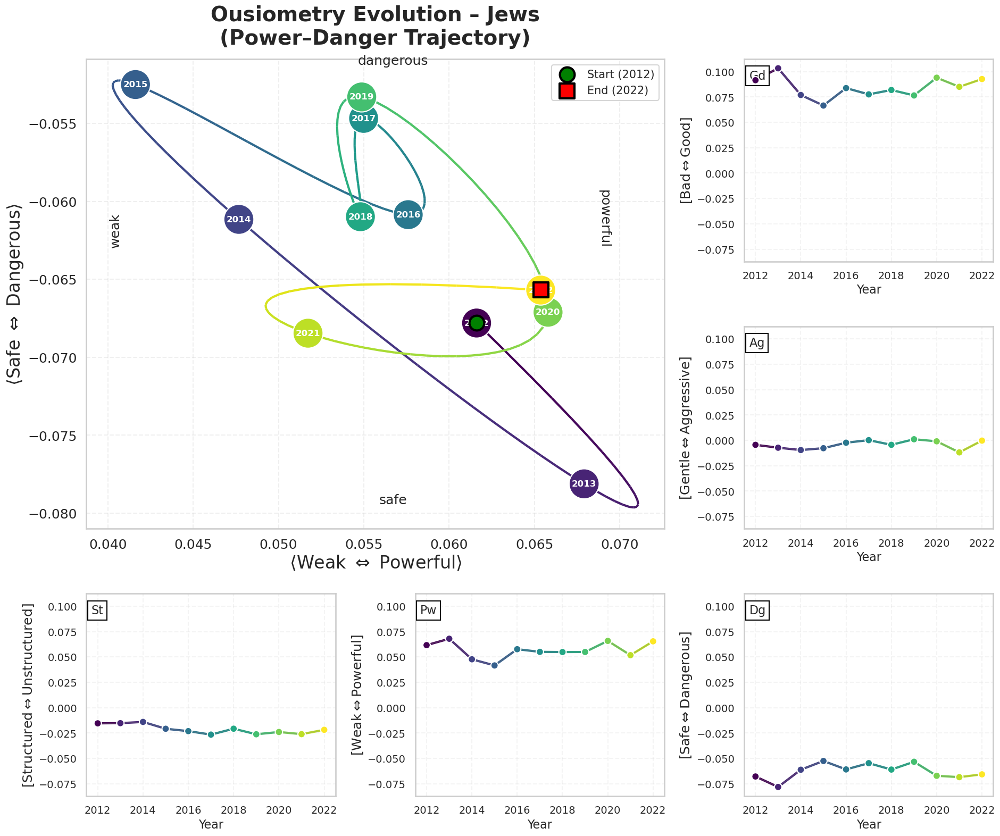


📊 Plotting for group: LGBTQ+

✓ Saved: Ousiometry_LGBTQ+.pdf


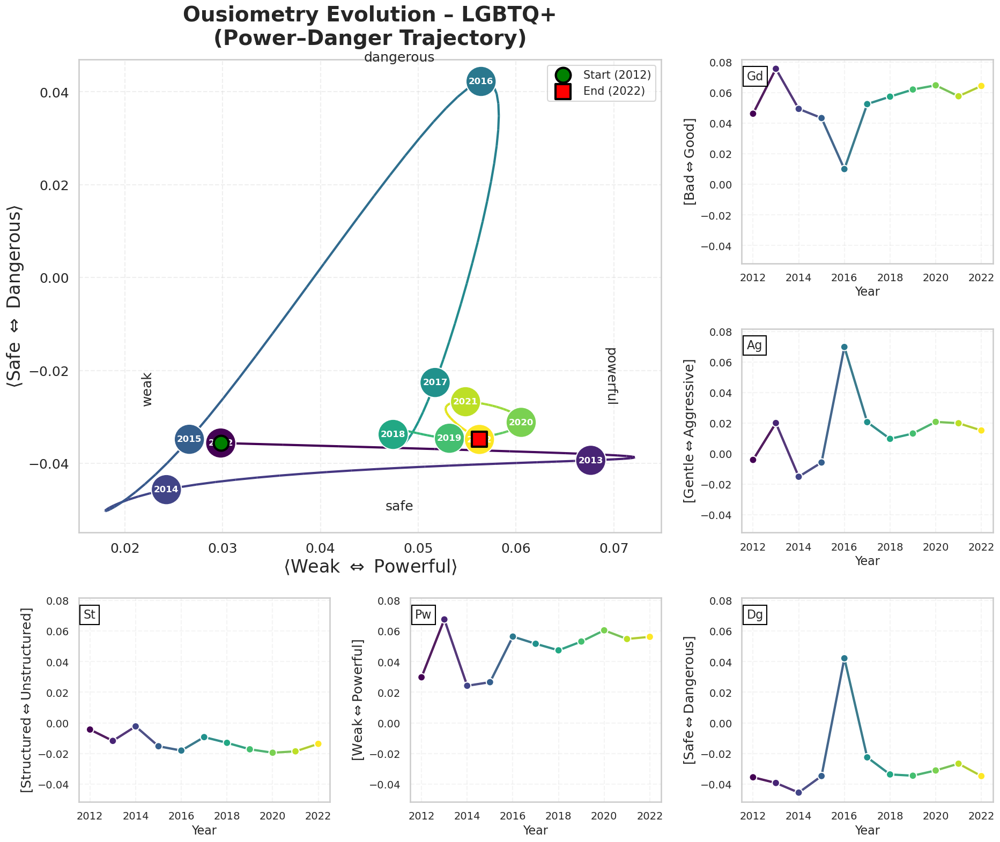


📊 Plotting for group: Liberals

✓ Saved: Ousiometry_Liberals.pdf


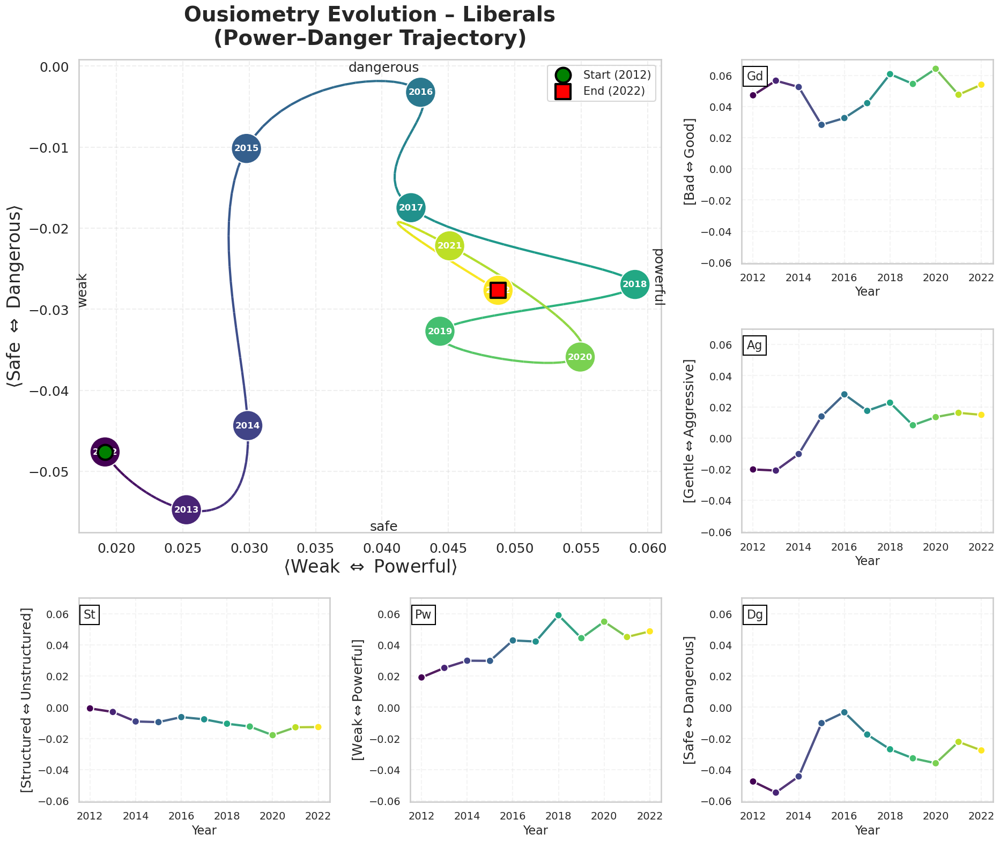


📊 Plotting for group: Muslims

✓ Saved: Ousiometry_Muslims.pdf


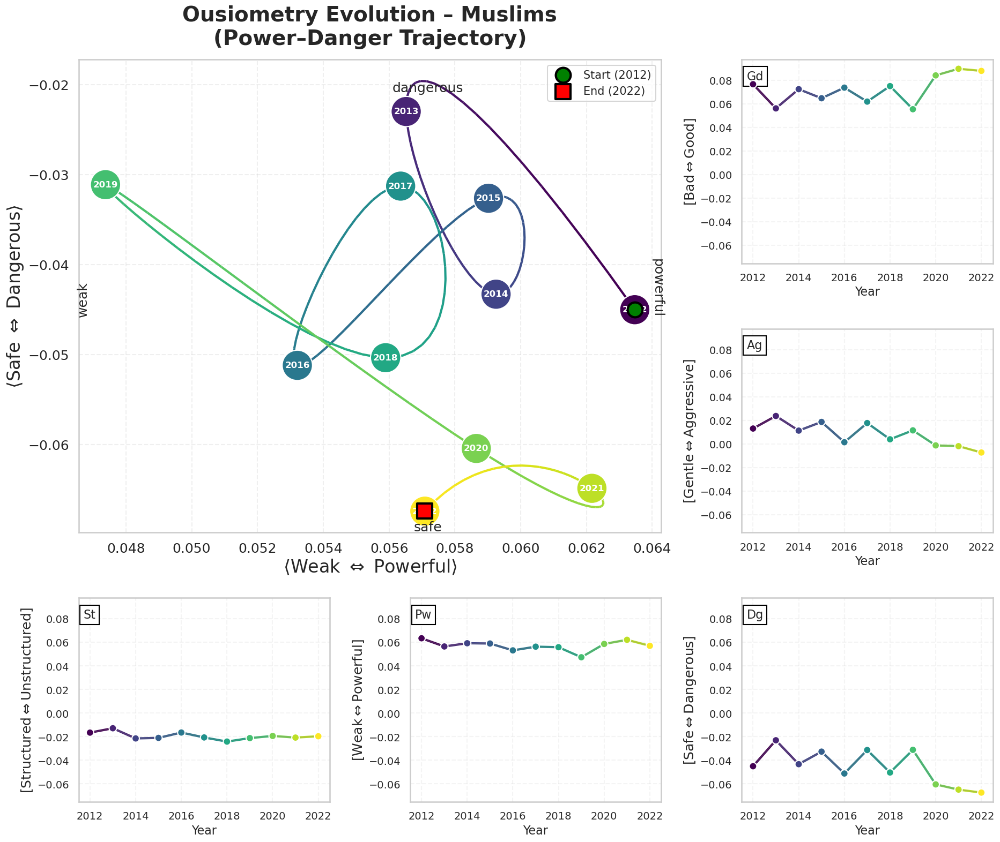


📊 Plotting for group: Refugees

✓ Saved: Ousiometry_Refugees.pdf


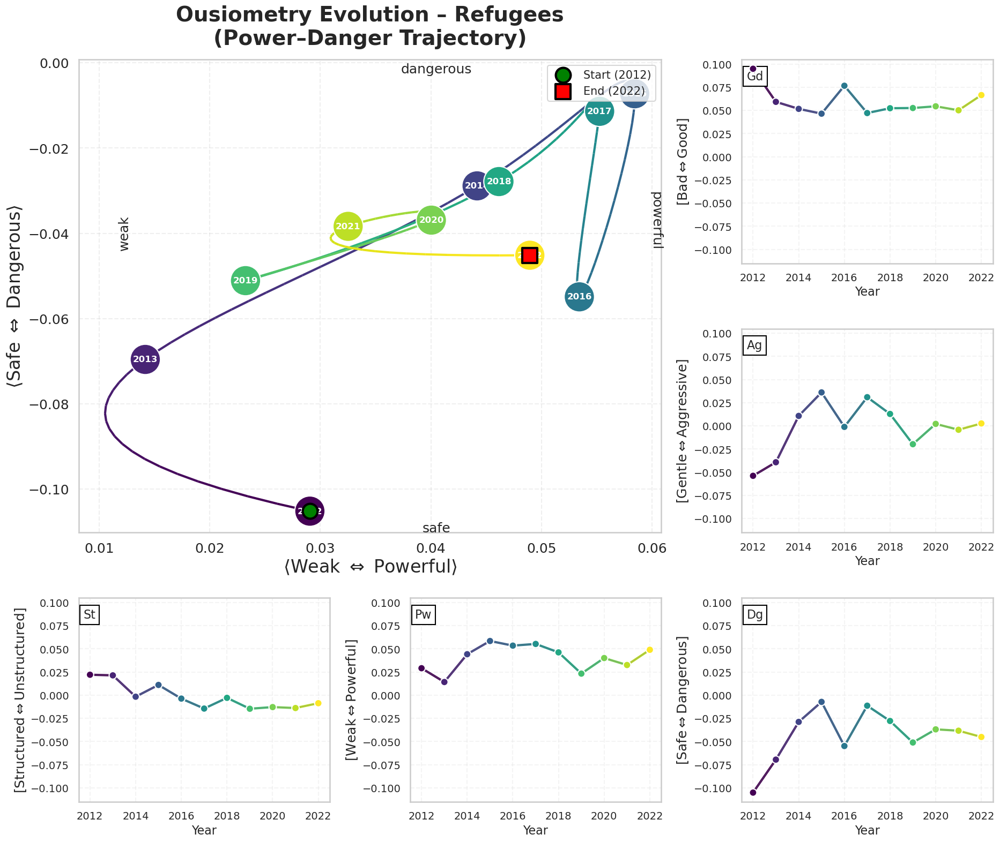

In [415]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.interpolate import make_interp_spline
import matplotlib.gridspec as gridspec
import seaborn as sns

# ---------- 1️⃣ Load Ousiometry Lexicon ----------
def load_ousiometry_lexicon(file_path):
    df_lexicon = pd.read_csv(file_path, sep='\t', engine='python')
    df_lexicon.columns = [c.lower() for c in df_lexicon.columns]
    lexicon_dict = {}
    for _, row in df_lexicon.iterrows():
        word = str(row.get('word', row.get('term', ''))).lower().strip()
        if not word:
            continue
        lexicon_dict[word] = {
            'goodness': row.get('goodness', 0.5),
            'energy': row.get('energy', 0.5),
            'structure': row.get('structure', 0.5),
            'power': row.get('power', 0.5),
            'danger': row.get('danger', 0.5)
        }
    print(f"✅ Loaded {len(lexicon_dict)} lexicon entries")
    return lexicon_dict


# ---------- 2️⃣ Compute Ousiometry for text ----------
def score_text_ousiometry(text, lexicon_dict):
    words = re.findall(r'\b[a-zA-Z]+\b', str(text).lower())
    scores = {'goodness': [], 'energy': [], 'structure': [], 'power': [], 'danger': []}
    for word in words:
        if word in lexicon_dict:
            for dim in scores.keys():
                scores[dim].append(lexicon_dict[word][dim])
    result = {dim: (np.mean(values) if values else 0.5) for dim, values in scores.items()}
    return result


# ---------- 3️⃣ Compute Year-wise Ousiometry per Group ----------
def compute_groupwise_ousiometry(df, lexicon_dict):
    """
    Compute average Ousiometry per year for each MappedGroup.
    Requires: ['MappedGroup', 'year', 'pure_text']
    """
    results = []
    for group, group_df in df.groupby('MappedGroup'):
        print(f"\n🔹 Processing group: {group}")
        for year, year_df in group_df.groupby('year'):
            combined_text = ' '.join(year_df['pure_text'].astype(str))
            scores = score_text_ousiometry(combined_text, lexicon_dict)
            scores['year'] = year
            scores['MappedGroup'] = group
            results.append(scores)
    df_groupwise = pd.DataFrame(results)
    df_groupwise = df_groupwise.sort_values(['MappedGroup', 'year']).reset_index(drop=True)
    return df_groupwise


# ---------- 4️⃣ Plot Function (EXACTLY your version) ----------
def plot_yearly_ousiometry(df_yearwise, title="Yearly Ousiometry Trends", save_path=None):
    df = df_yearwise.copy()
    df = df.sort_values('year').reset_index(drop=True)
    years = df['year'].astype(str).tolist()
    x = df['power'].values
    y = df['danger'].values

    t = np.arange(len(x))
    if len(x) > 3:
        t_new = np.linspace(0, len(x) - 1, 200)
        spl_x = make_interp_spline(t, x, k=min(3, len(x)-1))
        spl_y = make_interp_spline(t, y, k=min(3, len(x)-1))
        x_smooth = spl_x(t_new)
        y_smooth = spl_y(t_new)
    else:
        x_smooth, y_smooth = x, y

    smooth_data = np.vstack((x_smooth, y_smooth)).T
    points = smooth_data.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    norm = plt.Normalize(0, len(smooth_data)-1)
    lc = LineCollection(segments, cmap='viridis', norm=norm)
    lc.set_array(np.arange(len(smooth_data)-1))
    lc.set_linewidth(3)

    color_times = np.arange(len(df))
    colormap = plt.get_cmap('viridis')
    color_norm = plt.Normalize(vmin=0, vmax=len(df) - 1)
    line_colors = colormap(color_norm(color_times))

    fig = plt.figure(figsize=(22, 18))
    gs = gridspec.GridSpec(3, 3, width_ratios=[1, 1, 1], height_ratios=[1, 1, 1],
                           wspace=0.32, hspace=0.32)

    small_vars = ['goodness', 'energy', 'structure', 'power', 'danger']
    y_min = df[small_vars].min().min()
    y_max = df[small_vars].max().max()
    pad = 0.05 * (y_max - y_min)
    y_lo, y_hi = y_min - pad, y_max + pad

    # Main Power–Danger Plot
    ax_main = fig.add_subplot(gs[0:2, 0:2])
    ax_main.add_collection(lc)
    ax_main.scatter(x[0], y[0], s=400, c='green', marker='o',
                    edgecolors='black', linewidths=3, zorder=10, label=f'Start ({years[0]})')
    ax_main.scatter(x[-1], y[-1], s=400, c='red', marker='s',
                    edgecolors='black', linewidths=3, zorder=10, label=f'End ({years[-1]})')
    for i, (px, py, yr) in enumerate(zip(x, y, years)):
        ax_main.annotate(yr, (px, py), fontsize=12, ha='center', va='center',
                         color='white', fontweight='bold',
                         bbox=dict(boxstyle='circle,pad=0.3', facecolor=line_colors[i],
                                   edgecolor='white', linewidth=1.5))
    ax_main.set_xlabel(r'$\langle$Weak $\Leftrightarrow$ Powerful$\rangle$', fontsize=24)
    ax_main.set_ylabel(r'$\langle$Safe $\Leftrightarrow$ Dangerous$\rangle$', fontsize=24)
    ax_main.tick_params(axis='both', labelsize=18)
    ax_main.legend(loc='best', fontsize=15)
    ax_main.grid(True, linestyle='--', alpha=0.3)
    ax_main.set_title(f'{title}\n(Power–Danger Trajectory)', fontsize=28, fontweight='bold', pad=20)
    xmid, ymid = np.mean(x), np.mean(y)
    xrng, yrng = (x.max()-x.min()), (y.max()-y.min())
    ax_main.text(xmid, y.max()+0.05*yrng, "dangerous", ha='center', fontsize=18)
    ax_main.text(xmid, y.min()-0.05*yrng, "safe", ha='center', fontsize=18)
    ax_main.text(x.min()-0.03*xrng, ymid, "weak", ha='right', fontsize=18, rotation=90)
    ax_main.text(x.max()+0.03*xrng, ymid, "powerful", ha='left', fontsize=18, rotation=-90)

    # Subplots for other dimensions
    subplot_slots = [(0, 2), (1, 2), (2, 0), (2, 1), (2, 2)]
    subplot_vars = [
        ('goodness', r"[Bad$\Leftrightarrow$Good]", 'Gd'),
        ('energy', r"[Gentle$\Leftrightarrow$Aggressive]", 'Ag'),
        ('structure', r"[Structured$\Leftrightarrow$Unstructured]", 'St'),
        ('power', r"[Weak$\Leftrightarrow$Powerful]", 'Pw'),
        ('danger', r"[Safe$\Leftrightarrow$Dangerous]", 'Dg')
    ]
    for (row, col), (var, ylabel, boxlabel) in zip(subplot_slots, subplot_vars):
        ax = fig.add_subplot(gs[row, col])
        for j in range(len(df) - 1):
            ax.plot(df['year'].iloc[j:j+2], df[var].iloc[j:j+2], color=line_colors[j], lw=3)
        ax.plot(df['year'], df[var], color='gray', alpha=0.3, lw=1.5)
        ax.scatter(df['year'], df[var], c=line_colors, s=100,
                   edgecolors='white', linewidths=1.5, zorder=5)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_xlabel("Year", fontsize=16)
        ax.tick_params(axis='both', labelsize=14)
        ax.text(0.02, 0.90, boxlabel, fontsize=16, transform=ax.transAxes,
                bbox=dict(boxstyle="square", fc="white", ec="black"))
        ax.grid(True, linestyle='--', alpha=0.2)
        ax.set_ylim(y_lo, y_hi)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight')
        print(f"\n✓ Saved: {save_path}")
    plt.show()


# ---------- 5️⃣ Run for each group ----------
lexicon_path = "ousiometry_data (1).txt"
lexicon_dict = load_ousiometry_lexicon(lexicon_path)

df_groupwise = compute_groupwise_ousiometry(df, lexicon_dict)

for group, subdf in df_groupwise.groupby("MappedGroup"):
    print(f"\n📊 Plotting for group: {group}")
    plot_yearly_ousiometry(
        subdf,
        title=f"Ousiometry Evolution – {group}",
        save_path=f"Ousiometry_{group.replace(' ', '_')}.pdf"
    )


In [426]:
df

,_id,pure_text,rt_text,tweet_created_at,tweet_id,user_id,user_created_at,fastText_lang,fastText_conf,reply_to_id,...,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup,year,Month,TFIDF_Topic,Topic,is_topic
0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,1.528506e+18,1.317928e+18,2020-10-18 20:37:29,en,0.98,NaN,...,Discriminatory,Black Americans,Discriminatory,Anger,Black Americans,2022,2022-05,5,GOP Corruption,0
1,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,1.279466e+18,1.268650e+18,2020-06-04 21:06:30,en,0.93,NaN,...,Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020,2020-07,4,Evangelical Trump,0
2,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,8.054107e+17,2.250714e+08,2010-12-10 16:12:28,en,0.65,NaN,...,Discriminatory,Muslims,Supportive,Gratitude,Muslims,2016,2016-12,4,Evangelical Trump,0
3,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,1.279357e+18,7.040012e+17,2016-02-28 17:52:10,en,0.95,1.279356e+18,...,Discriminatory,Black Americans,Discriminatory,Anger,Black Americans,2020,2020-07,4,Evangelical Trump,0
4,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,1.307455e+18,1.103778e+09,2013-01-19 14:02:45,en,0.98,NaN,...,Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020,2020-09,8,Voter Apathy,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,7.864829e+17,1.494789e+09,2013-06-09 06:01:42,en,0.96,7.864083e+17,...,Critical,Liberals,Discriminatory,Anger,Liberals,2016,2016-10,3,Political Conflict,0
153242,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,1.163786e+18,3.615616e+07,2009-04-28 19:27:50,en,0.90,NaN,...,Discriminatory,LGBTQ+,Discriminatory,Anger,LGBTQ+,2019,2019-08,9,Racism Accusals,0
153243,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,1.292584e+18,1.250584e+18,2020-04-16 00:37:37,en,0.70,1.292582e+18,...,Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020,2020-08,9,Radical Left,0
153244,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,1.329314e+18,7.993342e+17,2016-11-17 19:31:40,en,0.90,NaN,...,Discriminatory,Conservatives,Discriminatory,Anger,Conservatives,2020,2020-11,9,Radical Left,0


In [430]:
df.columns

Index(['_id', 'pure_text', 'rt_text', 'tweet_created_at', 'tweet_id',
       'user_id', 'user_created_at', 'fastText_lang', 'fastText_conf',
       'reply_to_id', 'LLM_Label', 'CommentType', 'TargetedGroup', 'Sentiment',
       'Emotion', 'MappedGroup', 'year', 'Month', 'TFIDF_Topic', 'Topic',
       'is_topic'],
      dtype='object')

In [427]:
df['Topic'].unique()

array(['GOP Corruption', 'Evangelical Trump', 'Voter Apathy',
       'Republican Voters', 'MAGA Culture', 'Racism Accusals',
       'US Congress', 'Trump Presidency', 'GOP Identity',
       'Political Wings', 'Antifa Terror', 'White Supremacy',
       'Immigrant Stereotypes', 'Political Conflict', 'Jews/Antisemitism',
       'Illegal Border', 'Radical Left', 'Security Cuts',
       'Islam/Terrorism', 'Immigrant Costs', 'Race and Crime',
       'Muslims India', 'Black Reparations', 'Asylum Seekers',
       'Stealing Jobs'], dtype=object)

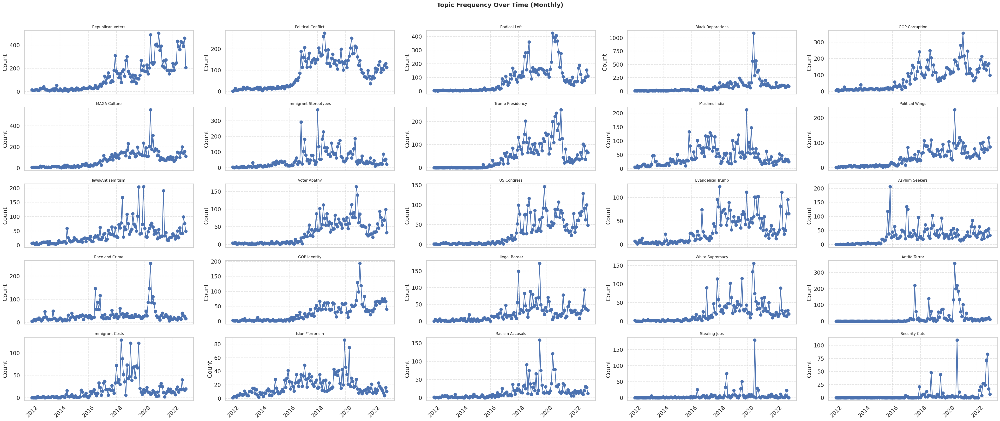

In [432]:
import pandas as pd
import matplotlib.pyplot as plt

# ======================
# Load and preprocess data
# ======================
# df = pd.read_csv("your_file.csv")  # Uncomment if loading from CSV

# Ensure Month is datetime
df['Month'] = pd.to_datetime(df['Month'], errors='coerce')

# Sort by Month
df = df.sort_values('Month')

# ======================
# Aggregate topic counts per month
# ======================
topic_trends = df.groupby(['Month', 'Topic']).size().reset_index(name='count')

# Pivot for plotting
pivot_df = topic_trends.pivot(index='Month', columns='Topic', values='count').fillna(0)

# Sort columns by total frequency (optional)
pivot_df = pivot_df[pivot_df.sum().sort_values(ascending=False).index]

# ======================
# Plot: 5x5 grid (up to 25 topics)
# ======================
num_topics = len(pivot_df.columns)
topics_to_plot = pivot_df.columns[:25]  # take top 25 topics

fig, axes = plt.subplots(5, 5, figsize=(42, 18), sharex=True, sharey=False)
axes = axes.flatten()

for i, topic in enumerate(topics_to_plot):
    ax = axes[i]
    ax.plot(pivot_df.index, pivot_df[topic], marker='o', linewidth=2)
    ax.set_title(topic, fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.tick_params(axis='x', rotation=45)
    ax.set_xlabel("")
    ax.set_ylabel("Count")

# Hide unused subplots if less than 25 topics
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

# Global title
#fig.suptitle("Topic Frequency Over Time (Monthly)", fontsize=18, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


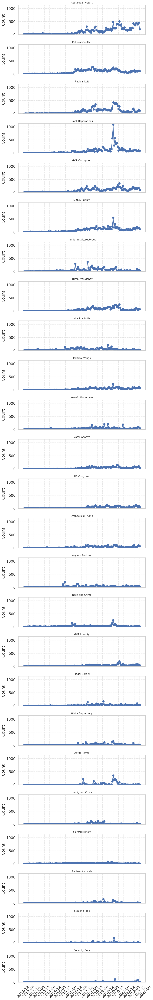

In [441]:
# import pandas as pd
# import matplotlib.pyplot as plt
# import matplotlib.dates as mdates

# # ======================
# # Load and preprocess data
# # ======================
# # df = pd.read_csv("your_file.csv")  # Uncomment if loading from CSV

# # Ensure Month is datetime
# df['Month'] = pd.to_datetime(df['Month'], errors='coerce')

# # Sort by Month
# df = df.sort_values('Month')

# # ======================
# # Aggregate topic counts per month
# # ======================
# topic_trends = df.groupby(['Month', 'Topic']).size().reset_index(name='count')

# # Pivot for plotting
# pivot_df = topic_trends.pivot(index='Month', columns='Topic', values='count').fillna(0)

# # Sort columns by total frequency (optional)
# pivot_df = pivot_df[pivot_df.sum().sort_values(ascending=False).index]

# # ======================
# # Plot: 25 vertical subplots (top 25 topics)
# # ======================
# num_topics = len(pivot_df.columns)
# topics_to_plot = pivot_df.columns[:25]  # take top 25 topics

# # Compute the global y-axis maximum + buffer
# max_val = pivot_df.max().max() + 50

# fig, axes = plt.subplots(25, 1, figsize=(10, 65), sharex=True, sharey=True)
# axes = axes.flatten()

# for i, topic in enumerate(topics_to_plot):
#     ax = axes[i]
#     ax.plot(pivot_df.index, pivot_df[topic], marker='o', linewidth=2)
#     ax.set_title(topic, fontsize=11)
#     ax.grid(True, linestyle='--', alpha=0.5)
#     ax.tick_params(axis='x', rotation=45)
#     ax.set_xlabel("")
#     ax.set_ylabel("Count")
#     ax.set_ylim(0, max_val)

#     # Format x-axis to show only 2 ticks per year
#     ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[6, 12]))  # show June and Dec
#     ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

# # Hide unused subplots if fewer than 25 topics
# for j in range(i + 1, len(axes)):
#     fig.delaxes(axes[j])

# # Global title (optional)
# # fig.suptitle("Topic Frequency Over Time (Monthly)", fontsize=18, fontweight='bold')
# plt.tight_layout(rect=[0, 0, 1, 0.97])
# plt.show()


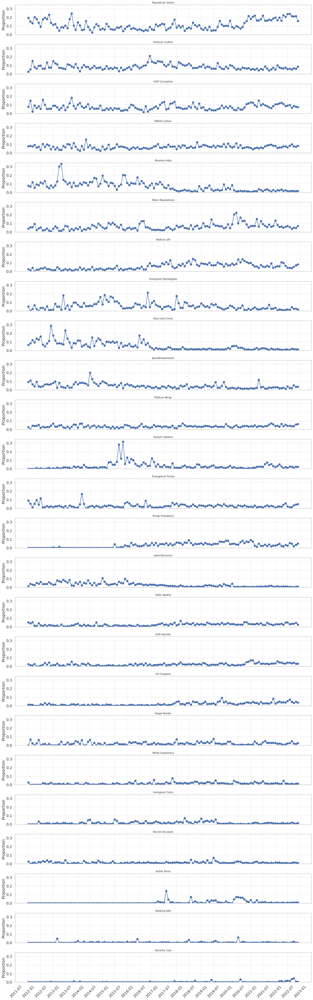

In [444]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ======================
# Load and preprocess data
# ======================
# df = pd.read_csv("your_file.csv")  # Uncomment if loading from CSV

# Ensure Month is datetime
df['Month'] = pd.to_datetime(df['Month'], errors='coerce')

# Sort by Month
df = df.sort_values('Month')

# ======================
# Aggregate topic counts per month
# ======================
topic_trends = df.groupby(['Month', 'Topic']).size().reset_index(name='count')

# Pivot for plotting
pivot_df = topic_trends.pivot(index='Month', columns='Topic', values='count').fillna(0)

# ======================
# Normalize counts by total tweets per month
# ======================
# Divide each row by the row sum → gives proportion of each topic per month
pivot_df = pivot_df.div(pivot_df.sum(axis=1), axis=0)

# Sort columns by total average proportion (optional)
pivot_df = pivot_df[pivot_df.sum().sort_values(ascending=False).index]

# ======================
# Plot: 25 stacked vertical subplots (normalized proportions)
# ======================
num_topics = len(pivot_df.columns)
topics_to_plot = pivot_df.columns[:25]  # take top 25 topics

# Compute the global y-axis maximum (should be small since normalized)
max_val = pivot_df.max().max() + 0.01

fig, axes = plt.subplots(25, 1, figsize=(20, 65), sharex=True, sharey=True)
axes = axes.flatten()

for i, topic in enumerate(topics_to_plot):
    ax = axes[i]
    ax.plot(pivot_df.index, pivot_df[topic], marker='o', linewidth=2)
    ax.set_title(topic, fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.tick_params(axis='x', rotation=45)
    ax.set_xlabel("")
    ax.set_ylabel("Proportion")
    ax.set_ylim(0, max_val)

    # Show only 2 ticks per year → January and July
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

# Hide unused subplots if fewer than 25 topics
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Global title (optional)
# fig.suptitle("Normalized Topic Proportion Over Time (Monthly)", fontsize=18, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


In [446]:
gt = pd.read_csv("Topic-Interest_Google - Sheet1.csv")
gt

,Month,GOP Corruption: (Worldwide),Evangelical Trump: (Worldwide),Voter Apathy: (Worldwide),Republican Voters: (Worldwide),MAGA Culture: (Worldwide),Racism Accusals: (Worldwide),US Congress: (Worldwide),Trump Presidency: (Worldwide),GOP Identity: (Worldwide),...,Illegal Border: (Worldwide),Radical Left: (Worldwide),Security Cuts: (Worldwide),Islam Terrorism: (Worldwide),Immigrant Costs: (Worldwide),Race and Crime: (Worldwide),Muslims India: (Worldwide),Black Reparations: (Worldwide),Asylum Seekers: (Worldwide),Stealing Jobs: (Worldwide)
0,2012-01,0,0,31,25,0,0,41,0,0,...,13,15,13,16,0,14,22,5,31,38
1,2012-02,0,0,42,20,0,0,36,0,100,...,15,14,12,21,49,20,22,7,39,54
2,2012-03,0,0,46,25,0,0,35,0,0,...,14,18,10,18,0,24,24,5,41,41
3,2012-04,0,0,54,16,0,0,36,0,0,...,15,20,12,22,0,30,23,5,40,50
4,2012-05,0,0,39,21,0,0,35,0,0,...,14,23,12,19,0,18,22,4,51,40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,2022-08,0,5,83,21,0,0,30,3,0,...,18,31,7,5,37,13,36,11,38,39
128,2022-09,45,5,32,23,34,0,44,3,0,...,31,34,10,7,40,26,39,15,44,34
129,2022-10,0,5,53,44,0,0,49,3,0,...,19,37,17,9,26,28,36,16,44,40
130,2022-11,0,12,61,59,0,0,97,6,0,...,19,37,16,12,27,26,32,15,72,34


In [447]:
gt.columns

Index(['Month', 'GOP Corruption: (Worldwide)',
       'Evangelical Trump: (Worldwide)', 'Voter Apathy: (Worldwide)',
       'Republican Voters: (Worldwide)', 'MAGA Culture: (Worldwide)',
       'Racism Accusals: (Worldwide)', 'US Congress: (Worldwide)',
       'Trump Presidency: (Worldwide)', 'GOP Identity: (Worldwide)',
       'Political Wings: (Worldwide)', 'Antifa Terror: (Worldwide)',
       'White Supremacy: (Worldwide)', 'Immigrant Stereotypes: (Worldwide)',
       'Political Conflict: (Worldwide)', 'Antisemitism: (Worldwide)',
       'Illegal Border: (Worldwide)', 'Radical Left: (Worldwide)',
       'Security Cuts: (Worldwide)', 'Islam Terrorism: (Worldwide)',
       'Immigrant Costs: (Worldwide)', 'Race and Crime: (Worldwide)',
       'Muslims India: (Worldwide)', 'Black Reparations: (Worldwide)',
       'Asylum Seekers: (Worldwide)', 'Stealing Jobs: (Worldwide)'],
      dtype='object')

In [448]:
# Suppose your dataframe is named df
new_columns = {
    'GOP Corruption: (Worldwide)': 'GOP Corruption',
    'Evangelical Trump: (Worldwide)': 'Evangelical Trump',
    'Voter Apathy: (Worldwide)': 'Voter Apathy',
    'Republican Voters: (Worldwide)': 'Republican Voters',
    'MAGA Culture: (Worldwide)': 'MAGA Culture',
    'Racism Accusals: (Worldwide)': 'Racism Accusals',
    'US Congress: (Worldwide)': 'US Congress',
    'Trump Presidency: (Worldwide)': 'Trump Presidency',
    'GOP Identity: (Worldwide)': 'GOP Identity',
    'Political Wings: (Worldwide)': 'Political Wings',
    'Antifa Terror: (Worldwide)': 'Antifa Terror',
    'White Supremacy: (Worldwide)': 'White Supremacy',
    'Immigrant Stereotypes: (Worldwide)': 'Immigrant Stereotypes',
    'Political Conflict: (Worldwide)': 'Political Conflict',
    'Antisemitism: (Worldwide)': 'Jews/Antisemitism',
    'Illegal Border: (Worldwide)': 'Illegal Border',
    'Radical Left: (Worldwide)': 'Radical Left',
    'Security Cuts: (Worldwide)': 'Security Cuts',
    'Islam Terrorism: (Worldwide)': 'Islam/Terrorism',
    'Immigrant Costs: (Worldwide)': 'Immigrant Costs',
    'Race and Crime: (Worldwide)': 'Race and Crime',
    'Muslims India: (Worldwide)': 'Muslims India',
    'Black Reparations: (Worldwide)': 'Black Reparations',
    'Asylum Seekers: (Worldwide)': 'Asylum Seekers',
    'Stealing Jobs: (Worldwide)': 'Stealing Jobs'
}

# Apply renaming
gt = gt.rename(columns=new_columns)
gt

,Month,GOP Corruption,Evangelical Trump,Voter Apathy,Republican Voters,MAGA Culture,Racism Accusals,US Congress,Trump Presidency,GOP Identity,...,Illegal Border,Radical Left,Security Cuts,Islam/Terrorism,Immigrant Costs,Race and Crime,Muslims India,Black Reparations,Asylum Seekers,Stealing Jobs
0,2012-01,0,0,31,25,0,0,41,0,0,...,13,15,13,16,0,14,22,5,31,38
1,2012-02,0,0,42,20,0,0,36,0,100,...,15,14,12,21,49,20,22,7,39,54
2,2012-03,0,0,46,25,0,0,35,0,0,...,14,18,10,18,0,24,24,5,41,41
3,2012-04,0,0,54,16,0,0,36,0,0,...,15,20,12,22,0,30,23,5,40,50
4,2012-05,0,0,39,21,0,0,35,0,0,...,14,23,12,19,0,18,22,4,51,40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,2022-08,0,5,83,21,0,0,30,3,0,...,18,31,7,5,37,13,36,11,38,39
128,2022-09,45,5,32,23,34,0,44,3,0,...,31,34,10,7,40,26,39,15,44,34
129,2022-10,0,5,53,44,0,0,49,3,0,...,19,37,17,9,26,28,36,16,44,40
130,2022-11,0,12,61,59,0,0,97,6,0,...,19,37,16,12,27,26,32,15,72,34


In [454]:
# import pandas as pd
# import matplotlib.pyplot as plt
# import matplotlib.dates as mdates

# # ======================
# # Assume gt dataframe is already loaded
# # Columns: ['Month', 'GOP Corruption', 'Evangelical Trump', ..., 'Stealing Jobs']
# # ======================

# # Ensure Month is datetime
# gt = gt.copy()
# gt["Month"] = pd.to_datetime(gt["Month"], errors="coerce")
# gt = gt.sort_values("Month")

# # ======================
# # Normalize counts by total tweets per month
# # ======================
# topic_cols = [c for c in gt.columns if c != "Month"]
# gt[topic_cols] = gt[topic_cols].div(gt[topic_cols].sum(axis=1), axis=0)

# # Sort columns by overall mean proportion
# gt = gt[["Month"] + gt[topic_cols].mean().sort_values(ascending=False).index.tolist()]

# # ======================
# # Plot setup
# # ======================
# num_topics = len(topic_cols)
# topics_to_plot = gt.columns[1:26]  # take first 25 topics
# max_val = gt[topics_to_plot].max().max() + 0.01

# fig, axes = plt.subplots(25, 1, figsize=(20, 65), sharex=True, sharey=True)
# axes = axes.flatten()

# for i, topic in enumerate(topics_to_plot):
#     ax = axes[i]
    
#     ax.plot(gt["Month"], gt[topic], marker="o", linewidth=2, color="steelblue")
#     ax.set_title(topic, fontsize=11, pad=5)
    
#     # Set right-side y-axis
#     ax.yaxis.tick_right()
#     ax.yaxis.set_label_position("right")
    
#     ax.grid(True, linestyle="--", alpha=0.5)
#     ax.tick_params(axis="x", rotation=45, labelsize=9)
#     ax.set_ylabel("Proportion", fontsize=10)
#     ax.set_ylim(0, max_val)
    
#     # Show only 2 ticks per year → January and July
#     ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
#     ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

# # Hide unused subplots if fewer than 25 topics
# for j in range(i + 1, len(axes)):
#     fig.delaxes(axes[j])

# plt.tight_layout(rect=[0, 0, 1, 0.97])
# plt.savefig("topic_trends_rightYaxis.pdf", bbox_inches="tight", dpi=400)
# print("✓ Saved: topic_trends_rightYaxis.pdf")

# plt.show()


In [450]:
topic_trends 

,Month,Topic,count
0,2012-01-01,Black Reparations,3
1,2012-01-01,Evangelical Trump,7
2,2012-01-01,GOP Corruption,6
3,2012-01-01,GOP Identity,2
4,2012-01-01,Immigrant Stereotypes,4
...,...,...,...
2991,2022-12-01,Security Cuts,7
2992,2022-12-01,Trump Presidency,65
2993,2022-12-01,US Congress,48
2994,2022-12-01,Voter Apathy,33


✓ Saved: topicwise_tweets_vs_googletrends.pdf


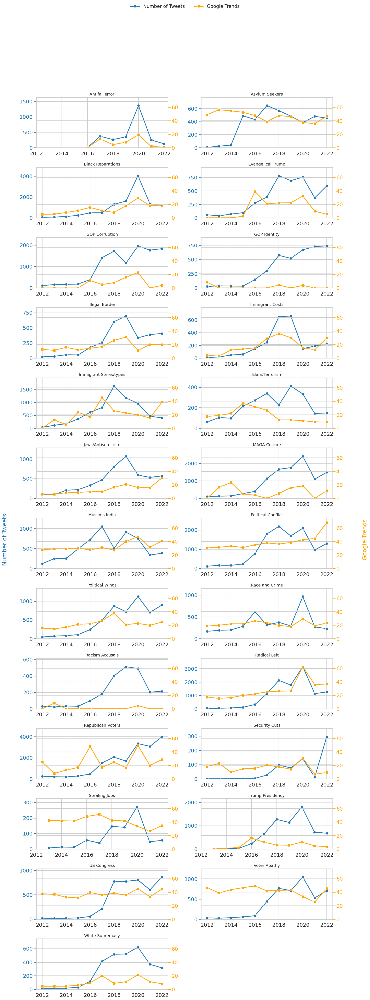

In [453]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 1️⃣ Prepare topic_trends (tweet counts)
# -----------------------------
topic_trends['Month'] = pd.to_datetime(topic_trends['Month'], errors='coerce')
topic_trends['year'] = topic_trends['Month'].dt.year
topic_trends['Topic'] = topic_trends['Topic'].str.strip()
grouped = topic_trends.groupby(['Topic', 'year'], as_index=False)['count'].sum()
grouped.rename(columns={'Topic': 'Group'}, inplace=True)

# -----------------------------
# 2️⃣ Prepare gt (Google Trends data)
# -----------------------------
gt = gt.copy()
gt['Month'] = pd.to_datetime(gt['Month'], errors='coerce')
gt['year'] = gt['Month'].dt.year
gf_long = gt.melt(id_vars=['Month', 'year'], var_name='Group', value_name='GF_score')
gf_yearly = gf_long.groupby(['Group', 'year'], as_index=False)['GF_score'].mean()

# -----------------------------
# 3️⃣ Merge both datasets
# -----------------------------
merged = pd.merge(grouped, gf_yearly, on=['Group', 'year'], how='inner')

# -----------------------------
# 4️⃣ Plot (dual y-axis per topic)
# -----------------------------
sns.set_context("talk", font_scale=1.1)
sns.set_style("whitegrid")

groups = sorted(merged['Group'].unique())
ncols = 2
nrows = (len(groups) + ncols - 1) // ncols
years = sorted(merged['year'].unique())
xticks = years[::2]

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4))
axes = axes.flatten()

handles_all, labels_all = [], []

for i, grp in enumerate(groups):
    ax = axes[i]
    sub = merged[merged['Group'] == grp]

    # Left axis → Tweet count
    line1 = sns.lineplot(
        data=sub, x='year', y='count',
        color='#1f77b4', marker='o', linewidth=2.5,
        ax=ax, label='Number of Tweets'
    )

    # Right axis → Google Trends
    ax2 = ax.twinx()
    line2 = sns.lineplot(
        data=sub, x='year', y='GF_score',
        color='#FFA500', marker='s', linewidth=2.5,
        ax=ax2, label='Google Trends'
    )

    # Capture legend handles once
    if not handles_all:
        handles1, labels1 = ax.get_legend_handles_labels()
        handles2, labels2 = ax2.get_legend_handles_labels()
        handles_all = handles1 + handles2
        labels_all = labels1 + labels2

    # Remove legends from subplots
    if ax.get_legend(): ax.get_legend().remove()
    if ax2.get_legend(): ax2.get_legend().remove()

    # Titles & axes
    ax.set_title(grp, fontsize=14)
    ax.set_xticks(xticks)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax2.set_ylabel("")
    ax.tick_params(axis='y', colors='#1f77b4')
    ax2.tick_params(axis='y', colors='#FFA500')
    ax.set_ylim(0, sub['count'].max() * 1.2)
    ax2.set_ylim(0, gf_yearly['GF_score'].max() * 1.1)

# Hide unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# -----------------------------
# Shared axis labels
# -----------------------------
fig.text(0.02, 0.5, "Number of Tweets", va='center', rotation='vertical',
         fontsize=20, color='#1f77b4')
fig.text(0.985, 0.5, "Google Trends", va='center', rotation='vertical',
         fontsize=20, color='#FFA500')

# -----------------------------
# Single legend on top
# -----------------------------
fig.legend(
    handles_all, labels_all,
    loc='upper center', ncol=2, frameon=False, fontsize=16
)

plt.tight_layout(rect=[0.05, 0.07, 0.95, 0.92])
plt.savefig("topicwise_tweets_vs_googletrends.pdf", dpi=300, bbox_inches="tight")
print("✓ Saved: topicwise_tweets_vs_googletrends.pdf")

plt.show()


In [452]:
import pandas as pd
import numpy as np

# Clean all topic columns (everything except 'Month')
topic_cols = [c for c in gt.columns if c not in ['Month', 'year']]

# Convert any weird strings like '<100', '00000000<100', '--', '' into numbers
for c in topic_cols:
    gt[c] = (
        gt[c]
        .astype(str)
        .str.replace(r'[^0-9.]', '', regex=True)  # keep only digits & dot
        .replace('', np.nan)
        .astype(float)
    )


In [458]:
result

,Topic,Month,happiness_score,happy_scaled
0,Antifa Terror,2016-06-01,6.800000,2.817343
1,Antifa Terror,2016-11-01,1.300000,-8.688220
2,Antifa Terror,2017-01-01,2.620000,-5.926885
3,Antifa Terror,2017-02-01,5.324348,-0.269604
4,Antifa Terror,2017-03-01,4.542727,-1.904692
...,...,...,...,...
2991,White Supremacy,2022-08-01,5.831119,0.790521
2992,White Supremacy,2022-09-01,5.761579,0.645049
2993,White Supremacy,2022-10-01,5.619091,0.346975
2994,White Supremacy,2022-11-01,5.853134,0.836574


In [461]:
merged 

,Group,year,count,GF_score
0,Antifa Terror,2016,2,0.000000
1,Antifa Terror,2017,370,12.916667
2,Antifa Terror,2018,262,4.500000
3,Antifa Terror,2019,350,8.083333
4,Antifa Terror,2020,1367,18.916667
...,...,...,...,...
263,White Supremacy,2018,517,8.833333
264,White Supremacy,2019,522,11.250000
265,White Supremacy,2020,621,21.500000
266,White Supremacy,2021,369,11.333333


In [464]:
# --- 1️⃣ Ensure both datasets are monthly and clean ---
result['Month'] = pd.to_datetime(result['Month'])
gt['Month'] = pd.to_datetime(gt['Month'])

# --- 2️⃣ Prepare GF data (melt to long form) ---
gt_long = gt.melt(id_vars=['Month'], var_name='Topic', value_name='GF_score')

# --- 3️⃣ Merge on Group + Month ---
merged_t = pd.merge(result, gt_long, on=['Topic', 'Month'], how='inner')
#merged_t = merged.sort_values(['Topic', 'Month'])
merged_t

,Topic,Month,happiness_score,happy_scaled,GF_score
0,Antifa Terror,2016-06-01,6.800000,2.817343,0.0
1,Antifa Terror,2016-11-01,1.300000,-8.688220,0.0
2,Antifa Terror,2017-01-01,2.620000,-5.926885,0.0
3,Antifa Terror,2017-02-01,5.324348,-0.269604,11.0
4,Antifa Terror,2017-03-01,4.542727,-1.904692,0.0
...,...,...,...,...,...
2991,White Supremacy,2022-08-01,5.831119,0.790521,7.0
2992,White Supremacy,2022-09-01,5.761579,0.645049,8.0
2993,White Supremacy,2022-10-01,5.619091,0.346975,7.0
2994,White Supremacy,2022-11-01,5.853134,0.836574,7.0


In [466]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import statsmodels.formula.api as smf

# Drop missing values
merged_t = merged_t.dropna(subset=['GF_score', 'happiness_score']).copy()

# --- 1️⃣ Scale both variables (z-score normalization) ---
scaler = StandardScaler()
merged_t[['GF_scaled', 'happy_scaled']] = scaler.fit_transform(merged_t[['GF_score', 'happiness_score']])

# Optional: check scaling
#print(merged[['GF_score', 'GF_scaled', 'happiness_score', 'happy_scaled']].head())

# --- 2️⃣ OLS model using scaled variables ---
model_scaled = smf.ols('GF_scaled ~ happiness_score + C(Topic)-1', data=merged_t).fit()
print(model_scaled.summary())



                            OLS Regression Results                            
Dep. Variable:              GF_scaled   R-squared:                       0.395
Model:                            OLS   Adj. R-squared:                  0.390
Method:                 Least Squares   F-statistic:                     77.58
Date:                Tue, 28 Oct 2025   Prob (F-statistic):          4.54e-301
Time:                        00:24:07   Log-Likelihood:                -3494.2
No. Observations:                2993   AIC:                             7040.
Df Residuals:                    2967   BIC:                             7196.
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
C(Topic)[A

In [467]:
# --- 2️⃣ OLS model using scaled variables ---
model_scaled = smf.ols('GF_scaled ~ C(Topic)-1', data=merged_t).fit()
print(model_scaled.summary())


                            OLS Regression Results                            
Dep. Variable:              GF_scaled   R-squared:                       0.395
Model:                            OLS   Adj. R-squared:                  0.390
Method:                 Least Squares   F-statistic:                     80.77
Date:                Tue, 28 Oct 2025   Prob (F-statistic):          8.20e-302
Time:                        00:24:48   Log-Likelihood:                -3494.7
No. Observations:                2993   AIC:                             7039.
Df Residuals:                    2968   BIC:                             7189.
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
C(Topic)[A

In [468]:
# --- 2️⃣ OLS model using scaled variables ---
model_scaled = smf.ols('happy_scaled ~ C(Topic)-1', data=merged_t).fit()
print(model_scaled.summary())


                            OLS Regression Results                            
Dep. Variable:           happy_scaled   R-squared:                       0.245
Model:                            OLS   Adj. R-squared:                  0.239
Method:                 Least Squares   F-statistic:                     40.13
Date:                Tue, 28 Oct 2025   Prob (F-statistic):          2.96e-161
Time:                        00:25:09   Log-Likelihood:                -3826.3
No. Observations:                2993   AIC:                             7703.
Df Residuals:                    2968   BIC:                             7853.
Df Model:                          24                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
C(Topic)[A

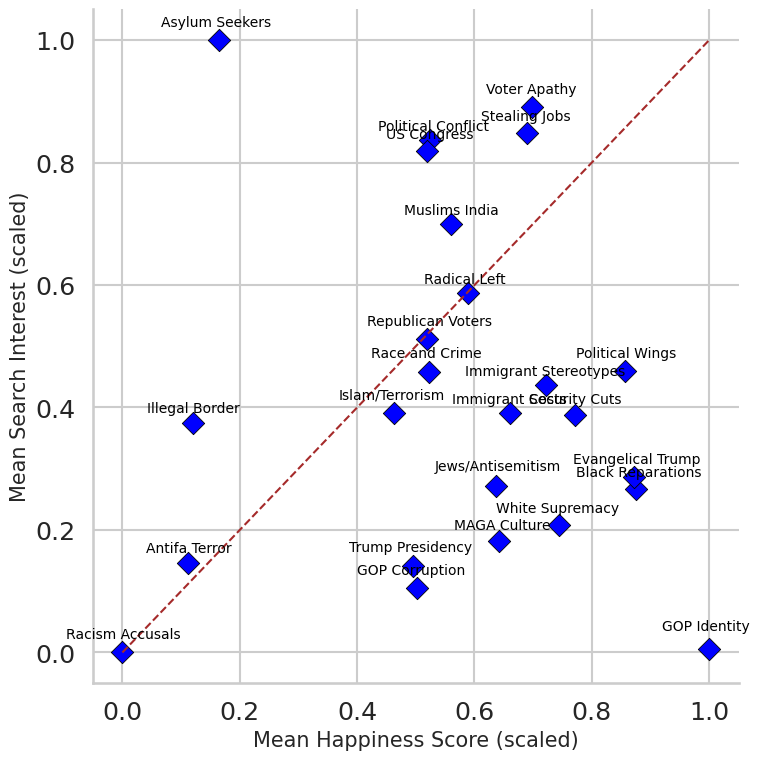

In [472]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --------------------------------------------------------
# 1️⃣ Aggregate mean values per group
# --------------------------------------------------------
group_mean = merged_t.groupby("Topic", as_index=False)[["happiness_score", "GF_score"]].mean()

# --------------------------------------------------------
# 2️⃣ Scale to [0, 1] range
# --------------------------------------------------------
for col in ["happiness_score", "GF_score"]:
    group_mean[col + "_scaled"] = (
        group_mean[col] - group_mean[col].min()
    ) / (group_mean[col].max() - group_mean[col].min())

# --------------------------------------------------------
# 3️⃣ Plot setup
# --------------------------------------------------------
sns.set(style="whitegrid", context="talk", font_scale=1.1)
fig, ax = plt.subplots(figsize=(8, 8))

sns.scatterplot(
    data=group_mean,
    x="happiness_score_scaled",
    y="GF_score_scaled",
    s=130,
    color="blue",     # orange
    edgecolor="black",
    linewidth=0.6,
    marker="D",          # diamond shape
    ax=ax
)

# Add diagonal (y = x)
ax.plot([0, 1], [0, 1], ls="--", color="brown", lw=1.5)

# --------------------------------------------------------
# 4️⃣ Annotate ALL groups clearly (with small jitter)
# --------------------------------------------------------
rng = np.random.default_rng(42)
x_jitter = rng.normal(0, 0.005, size=len(group_mean))
y_jitter = rng.normal(0, 0.005, size=len(group_mean))

for i, row in group_mean.iterrows():
    ax.text(
        row["happiness_score_scaled"] + x_jitter[i],
        row["GF_score_scaled"] + y_jitter[i]+0.026,
        row["Topic"],
        fontsize=10,
        color="black",
        ha="center",
        va="center"
    )

# --------------------------------------------------------
# 5️⃣ Formatting and style
# --------------------------------------------------------
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("Mean Happiness Score (scaled)", fontsize=15)
ax.set_ylabel("Mean Search Interest (scaled)", fontsize=15)
#ax.set_title("Happiness vs. Search Interest by Group", fontsize=17, pad=15)

# Remove extra borders
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("happiness_vs_GFscore_allgroups.pdf", dpi=300, bbox_inches="tight")
plt.show()


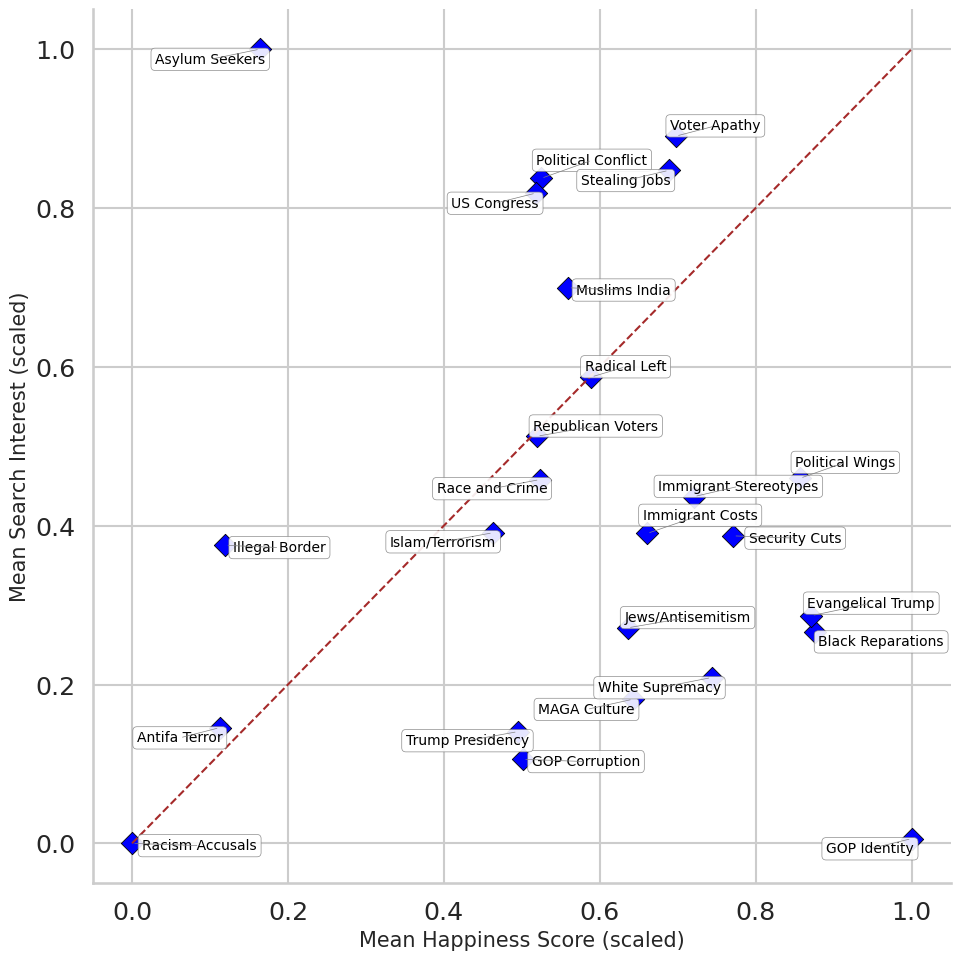

In [473]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.patches import FancyBboxPatch
from adjustText import adjust_text

# --------------------------------------------------------
# 1️⃣ Aggregate mean values per group
# --------------------------------------------------------
group_mean = merged_t.groupby("Topic", as_index=False)[["happiness_score", "GF_score"]].mean()

# --------------------------------------------------------
# 2️⃣ Scale to [0, 1] range
# --------------------------------------------------------
for col in ["happiness_score", "GF_score"]:
    group_mean[col + "_scaled"] = (
        group_mean[col] - group_mean[col].min()
    ) / (group_mean[col].max() - group_mean[col].min())

# --------------------------------------------------------
# 3️⃣ Plot setup
# --------------------------------------------------------
sns.set(style="whitegrid", context="talk", font_scale=1.1)
fig, ax = plt.subplots(figsize=(10, 10))

sns.scatterplot(
    data=group_mean,
    x="happiness_score_scaled",
    y="GF_score_scaled",
    s=130,
    color="blue",
    edgecolor="black",
    linewidth=0.6,
    marker="D",
    ax=ax
)

# Add diagonal (y = x)
ax.plot([0, 1], [0, 1], ls="--", color="brown", lw=1.5)

# --------------------------------------------------------
# 4️⃣ Annotate ALL groups with lines connecting to markers
# --------------------------------------------------------
texts = []
for i, row in group_mean.iterrows():
    text = ax.text(
        row["happiness_score_scaled"],
        row["GF_score_scaled"],
        row["Topic"],
        fontsize=10,
        color="black",
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", linewidth=0.5, alpha=0.9)
    )
    texts.append(text)

# Use adjustText to automatically prevent overlaps and add connecting lines
adjust_text(
    texts,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5),
    expand_points=(1.5, 1.5),
    expand_text=(1.2, 1.2),
    force_points=(0.5, 0.5),
    force_text=(0.5, 0.5),
    ax=ax
)

# --------------------------------------------------------
# 5️⃣ Formatting and style
# --------------------------------------------------------
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("Mean Happiness Score (scaled)", fontsize=15)
ax.set_ylabel("Mean Search Interest (scaled)", fontsize=15)

# Remove extra borders
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("happiness_vs_GFscore_allgroups.pdf", dpi=300, bbox_inches="tight")
plt.show()

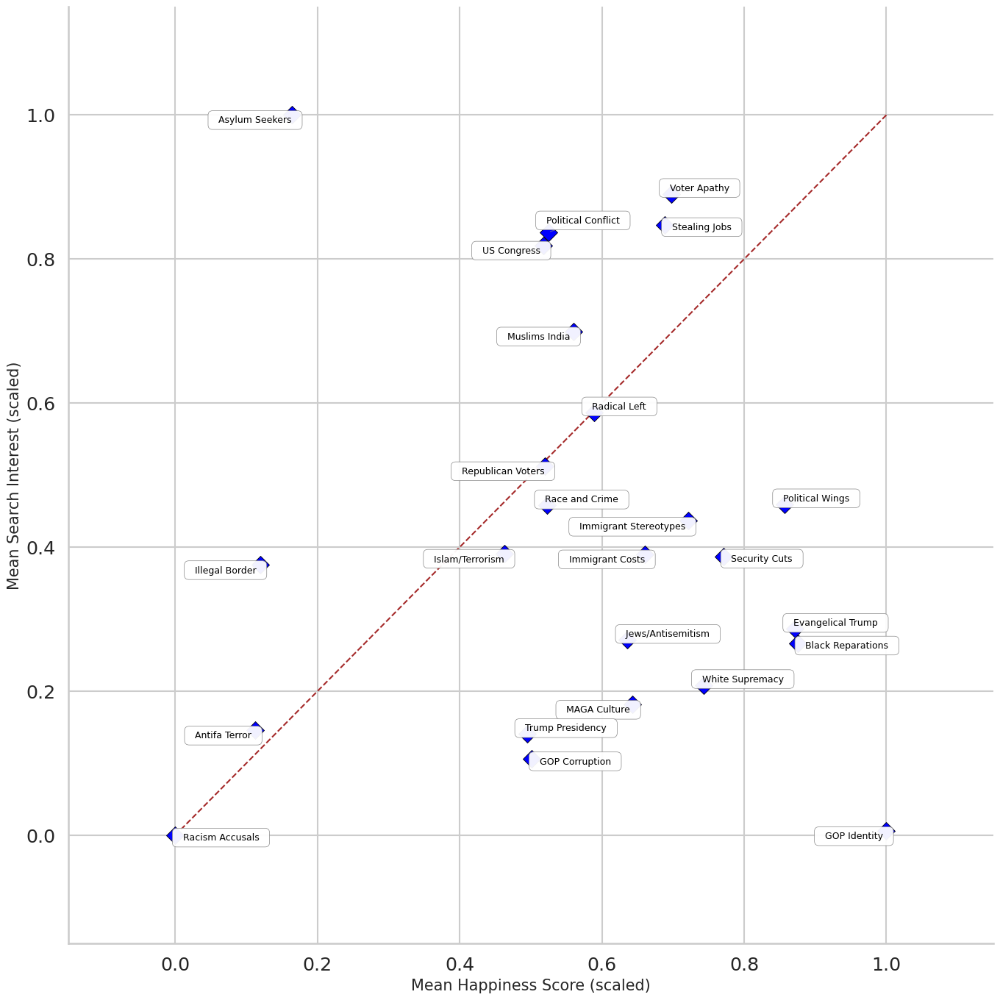

In [477]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from adjustText import adjust_text

# --------------------------------------------------------
# 1️⃣ Aggregate mean values per group
# --------------------------------------------------------
group_mean = merged_t.groupby("Topic", as_index=False)[["happiness_score", "GF_score"]].mean()

# --------------------------------------------------------
# 2️⃣ Scale to [0, 1] range
# --------------------------------------------------------
for col in ["happiness_score", "GF_score"]:
    group_mean[col + "_scaled"] = (
        group_mean[col] - group_mean[col].min()
    ) / (group_mean[col].max() - group_mean[col].min())

# --------------------------------------------------------
# 3️⃣ Plot setup
# --------------------------------------------------------
sns.set(style="whitegrid", context="talk", font_scale=1.1)
fig, ax = plt.subplots(figsize=(14, 14))

# Plot scatter points and store for reference
scatter = sns.scatterplot(
    data=group_mean,
    x="happiness_score_scaled",
    y="GF_score_scaled",
    s=150,
    color="blue",
    edgecolor="black",
    linewidth=0.6,
    marker="D",
    ax=ax,
    zorder=3
)

# Add diagonal (y = x)
ax.plot([0, 1], [0, 1], ls="--", color="brown", lw=1.5, zorder=1)

# --------------------------------------------------------
# 4️⃣ Annotate ALL groups with lines connecting to markers
# --------------------------------------------------------
texts = []
x_coords = group_mean["happiness_score_scaled"].values
y_coords = group_mean["GF_score_scaled"].values

for i, row in group_mean.iterrows():
    text = ax.text(
        row["happiness_score_scaled"],
        row["GF_score_scaled"],
        "  " + row["Topic"] + "  ",  # Add padding
        fontsize=9,
        color="black",
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray", linewidth=0.5, alpha=0.95),
        zorder=4
    )
    texts.append(text)

# Use adjustText with parameters optimized to avoid marker overlap
adjust_text(
    texts,
    x=x_coords,
    y=y_coords,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.8, alpha=0.7),
    expand_points=(2.5, 2.5),      # Strong repulsion from markers
    expand_text=(1.8, 1.8),        # Strong repulsion between texts
    force_points=(1.2, 1.2),       # Stronger force from points
    force_text=(1.2, 1.2),         # Stronger force between texts
    lim=1000,                       # Many iterations
    ax=ax,
    autoalign='xy',
    only_move={'points': 'xy', 'text': 'xy'},
    avoid_points=True,              # Explicitly avoid points
    avoid_self=True                 # Avoid text overlap
)

# --------------------------------------------------------
# 5️⃣ Formatting and style
# --------------------------------------------------------
ax.set_xlim(-0.15, 1.15)
ax.set_ylim(-0.15, 1.15)
ax.set_xlabel("Mean Happiness Score (scaled)", fontsize=15)
ax.set_ylabel("Mean Search Interest (scaled)", fontsize=15)

# Remove extra borders
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("happiness_vs_GFscore_allgroups.pdf", dpi=300, bbox_inches="tight")
plt.show()

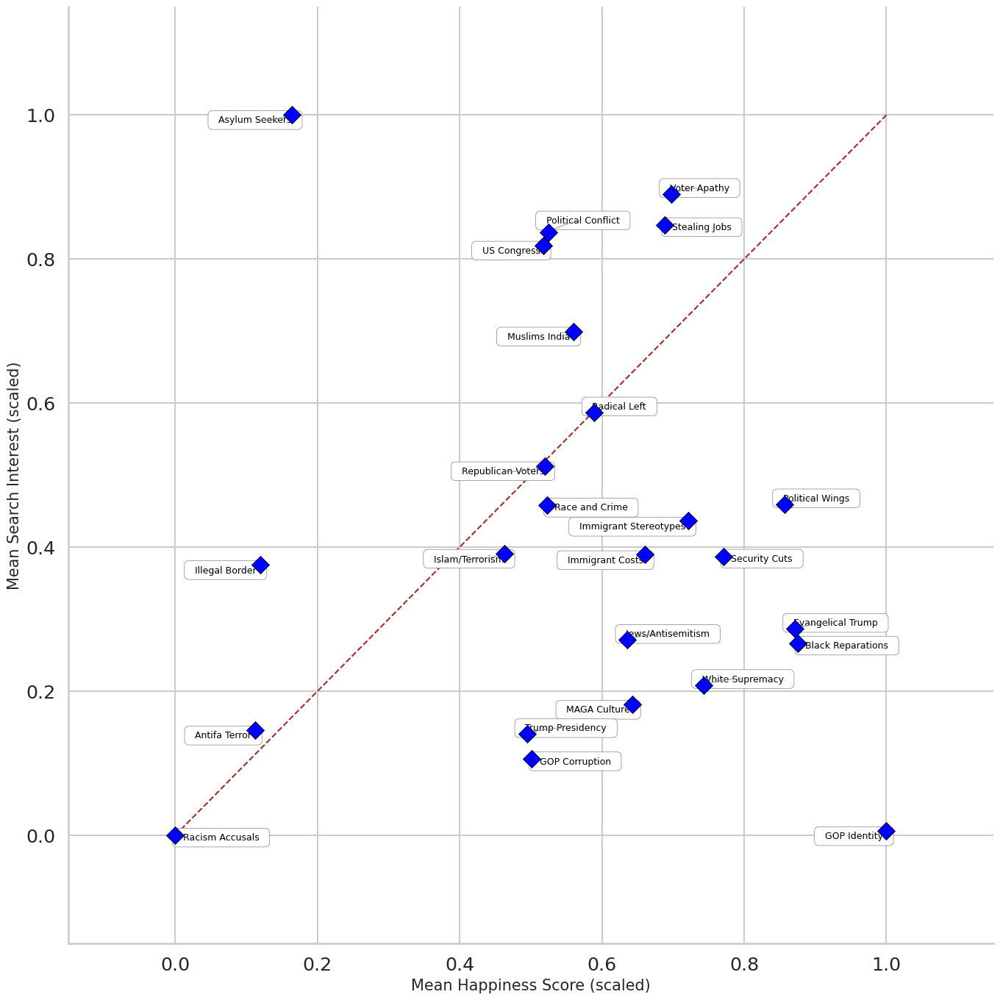

In [480]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from adjustText import adjust_text

# --------------------------------------------------------
# 1️⃣ Aggregate mean values per group
# --------------------------------------------------------
group_mean = merged_t.groupby("Topic", as_index=False)[["happiness_score", "GF_score"]].mean()

# --------------------------------------------------------
# 2️⃣ Scale to [0, 1] range
# --------------------------------------------------------
for col in ["happiness_score", "GF_score"]:
    group_mean[col + "_scaled"] = (
        group_mean[col] - group_mean[col].min()
    ) / (group_mean[col].max() - group_mean[col].min())

# --------------------------------------------------------
# 3️⃣ Plot setup
# --------------------------------------------------------
sns.set(style="whitegrid", context="talk", font_scale=1.1)
fig, ax = plt.subplots(figsize=(14, 14))

# Plot scatter points
scatter = sns.scatterplot(
    data=group_mean,
    x="happiness_score_scaled",
    y="GF_score_scaled",
    s=150,
    color="blue",
    edgecolor="black",
    linewidth=0.6,
    marker="D",
    ax=ax,
    zorder=5  # Markers on top
)

# Add diagonal (y = x)
ax.plot([0, 1], [0, 1], ls="--", color="brown", lw=1.5, zorder=1)

# --------------------------------------------------------
# 4️⃣ Annotate ALL groups with connecting lines
# --------------------------------------------------------
texts = []
x_coords = group_mean["happiness_score_scaled"].values
y_coords = group_mean["GF_score_scaled"].values

for i, row in group_mean.iterrows():
    text = ax.text(
        row["happiness_score_scaled"],
        row["GF_score_scaled"],
        "  " + row["Topic"] + "  ",
        fontsize=9,
        color="black",
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray", linewidth=0.5, alpha=0.98),
        zorder=3  # Text below markers
    )
    texts.append(text)

# Use adjustText - will automatically add arrows when text is moved away from points
adjust_text(
    texts,
    x=x_coords,
    y=y_coords,
    arrowprops=dict(
        arrowstyle="-",
        color="gray",
        lw=0.8,
        alpha=0.8,
        connectionstyle="arc3,rad=0.1"  # Slight curve for better visibility
    ),
    expand_points=(2.5, 2.5),
    expand_text=(1.8, 1.8),
    force_points=(1.5, 1.5),
    force_text=(1.5, 1.5),
    lim=1000,
    ax=ax,
    autoalign='xy',
    avoid_points=True,
    avoid_self=True,
    ensure_inside_axes=True
)

# --------------------------------------------------------
# 5️⃣ Formatting and style
# --------------------------------------------------------
ax.set_xlim(-0.15, 1.15)
ax.set_ylim(-0.15, 1.15)
ax.set_xlabel("Mean Happiness Score (scaled)", fontsize=15)
ax.set_ylabel("Mean Search Interest (scaled)", fontsize=15)

# Remove extra borders
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("happiness_vs_GFscore_allgroups.pdf", dpi=300, bbox_inches="tight")
plt.show()

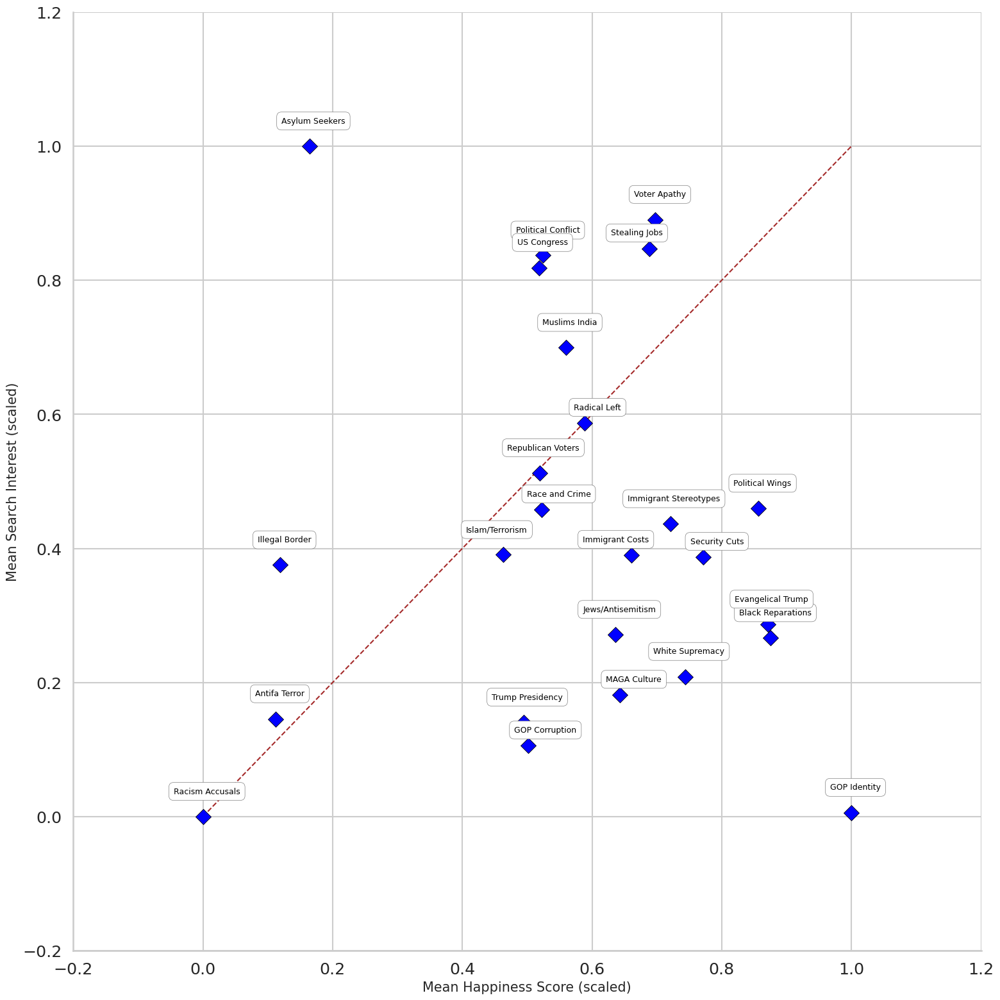

In [484]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from adjustText import adjust_text

# --------------------------------------------------------
# 1️⃣ Aggregate mean values per group
# --------------------------------------------------------
# --- ASSUMED DUMMY DATA FOR COMPLETENESS ---
# Since I cannot access your actual data (merged_t), I'll assume its structure.
try:
    group_mean = merged_t.groupby("Topic", as_index=False)[["happiness_score", "GF_score"]].mean()
except NameError:
    # Create dummy data for demonstration purposes
    topics = [f'Topic {i}' for i in range(25)]
    data = {
        'Topic': topics,
        'happiness_score': np.random.uniform(10, 50, 25),
        'GF_score': np.random.uniform(5, 45, 25)
    }
    group_mean = pd.DataFrame(data)
# -------------------------------------------


# --------------------------------------------------------
# 2️⃣ Scale to [0, 1] range
# --------------------------------------------------------
for col in ["happiness_score", "GF_score"]:
    group_mean[col + "_scaled"] = (
        group_mean[col] - group_mean[col].min()
    ) / (group_mean[col].max() - group_mean[col].min())

# --------------------------------------------------------
# 3️⃣ Plot setup
# --------------------------------------------------------
sns.set(style="whitegrid", context="talk", font_scale=1.1)
fig, ax = plt.subplots(figsize=(16, 16))

# Add diagonal (y = x) first
ax.plot([0, 1], [0, 1], ls="--", color="brown", lw=1.5, zorder=1)

# Plot scatter points
scatter = sns.scatterplot(
    data=group_mean,
    x="happiness_score_scaled",
    y="GF_score_scaled",
    s=150,
    color="blue",
    edgecolor="black",
    linewidth=0.6,
    marker="D",
    ax=ax,
    zorder=2 # Markers below text
)

# --------------------------------------------------------
# 4️⃣ Create text annotations with arrows
# --------------------------------------------------------
texts = []
x_coords = group_mean["happiness_score_scaled"].values
y_coords = group_mean["GF_score_scaled"].values

for i, row in group_mean.iterrows():
    # --- FIX 1: Apply a small vertical offset (0.03) when creating the text to avoid initial overlap ---
    initial_y_pos = row["GF_score_scaled"] + 0.03 
    
    text = ax.text(
        row["happiness_score_scaled"],
        initial_y_pos, # Start position slightly above the marker
        row["Topic"],
        fontsize=9,
        color="black",
        ha="center",
        # Removed va="center" to allow adjustText better control
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor="gray",
            linewidth=0.5,
            alpha=1.0
        ),
        zorder=10 # Text on TOP
    )
    texts.append(text)

# Adjust text to avoid overlaps - arrows will connect text to markers
adjust_text(
    texts,
    x=x_coords,
    y=y_coords, # --- FIX 2: Use original y_coords for point connection (where the marker is) ---
    arrowprops=dict(
        arrowstyle="-",
        color="gray",
        lw=1.0,
        alpha=0.7
    ),
    expand_points=(3.0, 3.0),
    expand_text=(2.0, 2.0),
    force_points=(2.0, 2.0),
    force_text=(2.0, 2.0),
    lim=2000,
    ax=ax,
    avoid_points=True,
    avoid_self=True,
    only_move={'points':'xy', 'text':'xy', 'objects':'xy'}
)

# --------------------------------------------------------
# 5️⃣ Formatting and style
# --------------------------------------------------------
ax.set_xlim(-0.2, 1.2)
ax.set_ylim(-0.2, 1.2)
ax.set_xlabel("Mean Happiness Score (scaled)", fontsize=15)
ax.set_ylabel("Mean Search Interest (scaled)", fontsize=15)

# Remove extra borders
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("happiness_vs_GFscore_allgroups.pdf", dpi=300, bbox_inches="tight")
plt.show()


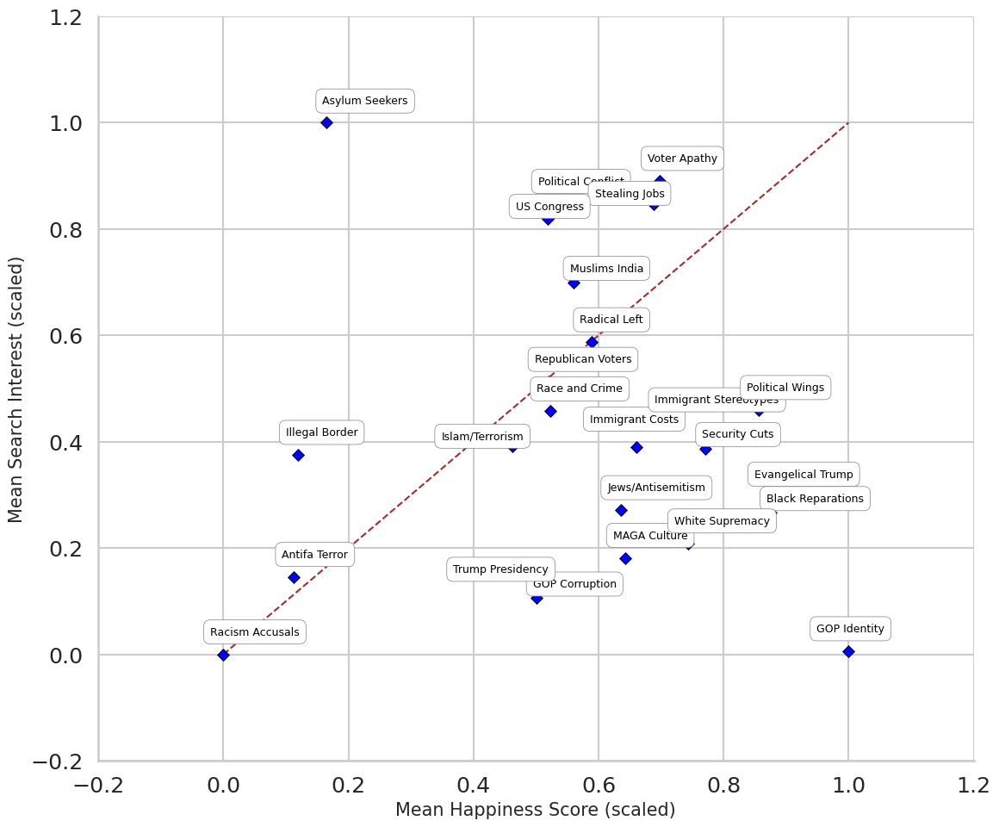

In [491]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from adjustText import adjust_text

# --------------------------------------------------------
# 1️⃣ Aggregate mean values per group
# --------------------------------------------------------
# --- ASSUMED DUMMY DATA FOR COMPLETENESS ---
# Since I cannot access your actual data (merged_t), I'll assume its structure.
try:
    group_mean = merged_t.groupby("Topic", as_index=False)[["happiness_score", "GF_score"]].mean()
except NameError:
    # Create dummy data for demonstration purposes
    topics = [f'Topic {i}' for i in range(25)]
    data = {
        'Topic': topics,
        'happiness_score': np.random.uniform(10, 50, 25),
        'GF_score': np.random.uniform(5, 45, 25)
    }
    group_mean = pd.DataFrame(data)
# -------------------------------------------


# --------------------------------------------------------
# 2️⃣ Scale to [0, 1] range
# --------------------------------------------------------
for col in ["happiness_score", "GF_score"]:
    group_mean[col + "_scaled"] = (
        group_mean[col] - group_mean[col].min()
    ) / (group_mean[col].max() - group_mean[col].min())

# --------------------------------------------------------
# 3️⃣ Plot setup
# --------------------------------------------------------
sns.set(style="whitegrid", context="talk", font_scale=1.1)
fig, ax = plt.subplots(figsize=(12, 10))

# Add diagonal (y = x) first
ax.plot([0, 1], [0, 1], ls="--", color="brown", lw=1.5, zorder=1)

# Plot scatter points
scatter = sns.scatterplot(
    data=group_mean,
    x="happiness_score_scaled",
    y="GF_score_scaled",
    s=50,
    color="blue",
    edgecolor="black",
    linewidth=0.6,
    marker="D",
    ax=ax,
    zorder=2 # Markers below text
)

# --------------------------------------------------------
# 4️⃣ Create text annotations with arrows
# --------------------------------------------------------
texts = []
x_coords = group_mean["happiness_score_scaled"].values
y_coords = group_mean["GF_score_scaled"].values

for i, row in group_mean.iterrows():
    # --- FIX 1: Apply a small vertical offset (0.03) when creating the text to avoid initial overlap ---
    initial_y_pos = row["GF_score_scaled"] + 0.03 
    
    text = ax.text(
        row["happiness_score_scaled"],
        initial_y_pos, # Start position slightly above the marker
        row["Topic"],
        fontsize=9,
        color="black",
        ha="center",
        # Removed va="center" to allow adjustText better control
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor="gray",
            linewidth=0.5,
            alpha=1.0
        ),
        zorder=10 # Text on TOP
    )
    texts.append(text)

# Adjust text to avoid overlaps - arrows will connect text to markers
adjust_text(
    texts,
    x=x_coords,
    y=y_coords, # --- FIX 2: Use original y_coords for point connection (where the marker is) ---
    arrowprops=dict(
        arrowstyle="-",
        color="gray",
        lw=2.0, # <-- INCREASED LINE WIDTH FOR VISIBILITY
        alpha=1.0 # <-- INCREASED OPACITY FOR VISIBILITY
    ),
    expand_points=(3.0, 3.0),
    expand_text=(2.0, 2.0),
    force_points=(2.0, 2.0),
    force_text=(2.0, 2.0),
    lim=2000,
    ax=ax,
    avoid_points=True,
    avoid_self=True,
    only_move={'points':'xy', 'text':'xy', 'objects':'xy'}
)

# --------------------------------------------------------
# 5️⃣ Formatting and style
# --------------------------------------------------------
ax.set_xlim(-0.2, 1.2)
ax.set_ylim(-0.2, 1.2)
ax.set_xlabel("Mean Happiness Score (scaled)", fontsize=15)
ax.set_ylabel("Mean Search Interest (scaled)", fontsize=15)

# Remove extra borders
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("happiness_vs_GFscore_allgroups.pdf", dpi=300, bbox_inches="tight")
plt.show()


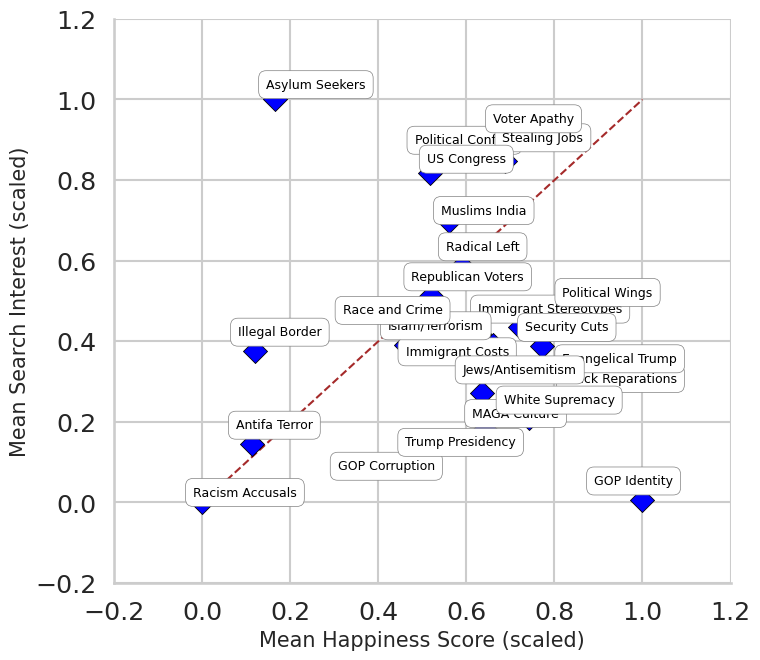

In [487]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from adjustText import adjust_text

# --------------------------------------------------------
# 1️⃣ Aggregate mean values per group
# --------------------------------------------------------
# --- ASSUMED DUMMY DATA FOR COMPLETENESS ---
# Since I cannot access your actual data (merged_t), I'll assume its structure.
try:
    group_mean = merged_t.groupby("Topic", as_index=False)[["happiness_score", "GF_score"]].mean()
except NameError:
    # Create dummy data for demonstration purposes
    topics = [f'Topic {i}' for i in range(25)]
    data = {
        'Topic': topics,
        'happiness_score': np.random.uniform(10, 50, 25),
        'GF_score': np.random.uniform(5, 45, 25)
    }
    group_mean = pd.DataFrame(data)
# -------------------------------------------


# --------------------------------------------------------
# 2️⃣ Scale to [0, 1] range
# --------------------------------------------------------
for col in ["happiness_score", "GF_score"]:
    group_mean[col + "_scaled"] = (
        group_mean[col] - group_mean[col].min()
    ) / (group_mean[col].max() - group_mean[col].min())

# --------------------------------------------------------
# 3️⃣ Plot setup
# --------------------------------------------------------
sns.set(style="whitegrid", context="talk", font_scale=1.1)
fig, ax = plt.subplots(figsize=(8, 7)) # Reduced figure size to (12, 12)

# Add diagonal (y = x) first
ax.plot([0, 1], [0, 1], ls="--", color="brown", lw=1.5, zorder=1)

# Plot scatter points
scatter = sns.scatterplot(
    data=group_mean,
    x="happiness_score_scaled",
    y="GF_score_scaled",
    s=150,
    color="blue",
    edgecolor="black",
    linewidth=0.6,
    marker="D",
    ax=ax,
    zorder=2 # Markers below text
)

# --------------------------------------------------------
# 4️⃣ Create text annotations with arrows
# --------------------------------------------------------
texts = []
x_coords = group_mean["happiness_score_scaled"].values
y_coords = group_mean["GF_score_scaled"].values

for i, row in group_mean.iterrows():
    # --- FIX 1: Apply a small vertical offset (0.03) when creating the text to avoid initial overlap ---
    initial_y_pos = row["GF_score_scaled"] + 0.03 
    
    text = ax.text(
        row["happiness_score_scaled"],
        initial_y_pos, # Start position slightly above the marker
        row["Topic"],
        fontsize=9,
        color="black",
        ha="center",
        # Removed va="center" to allow adjustText better control
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor="gray",
            linewidth=0.5,
            alpha=1.0
        ),
        zorder=10 # Text on TOP
    )
    texts.append(text)

# Adjust text to avoid overlaps - arrows will connect text to markers
adjust_text(
    texts,
    x=x_coords,
    y=y_coords, # --- FIX 2: Use original y_coords for point connection (where the marker is) ---
    arrowprops=dict(
        arrowstyle="-",
        color="black", # Changed color to black for better visibility/contrast
        lw=2.0, 
        alpha=1.0
    ),
    expand_points=(3.0, 3.0),
    expand_text=(2.0, 2.0),
    force_points=(2.0, 2.0),
    force_text=(2.0, 2.0),
    lim=2000,
    ax=ax,
    avoid_points=True,
    avoid_self=True,
    only_move={'points':'xy', 'text':'xy', 'objects':'xy'}
)

# --------------------------------------------------------
# 5️⃣ Formatting and style
# --------------------------------------------------------
ax.set_xlim(-0.2, 1.2)
ax.set_ylim(-0.2, 1.2)
ax.set_xlabel("Mean Happiness Score (scaled)", fontsize=15)
ax.set_ylabel("Mean Search Interest (scaled)", fontsize=15)

# Remove extra borders
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("happiness_vs_GFscore_allgroups.pdf", dpi=300, bbox_inches="tight")
plt.show()


In [18]:
##Allotax and wordshift

In [19]:
df

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,...,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup,year
0,1.0,1.0,31562.0,53734.0,112688.0,34389.0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,...,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2022
1,2.0,2.0,31563.0,6419.0,6516.0,6516.0,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,...,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020
2,3.0,3.0,31564.0,21989.0,487.0,487.0,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,...,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Positive,Gratitude,Muslims,2016
3,4.0,4.0,31565.0,26907.0,422.0,422.0,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,...,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2020
4,7.0,7.0,31568.0,19884.0,56211.0,39730.0,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,...,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,NaN,30760.0,30927.0,61861.0,11284.0,2083.0,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,...,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Negative,Anger,Liberals,2016
153242,NaN,30761.0,30928.0,61862.0,44732.0,14321.0,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,...,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Negative,Anger,LGBTQ+,2019
153243,NaN,30762.0,30929.0,61863.0,54343.0,23932.0,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,...,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020
153244,NaN,30763.0,30930.0,61864.0,38158.0,7747.0,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,...,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020


In [30]:
df.columns

Index(['Unnamed: 0.5', 'Unnamed: 0.4', 'Unnamed: 0.3', 'Unnamed: 0.2',
       'Unnamed: 0.1', 'Unnamed: 0', '_id', 'pure_text', 'rt_text',
       'tweet_created_at', 'tweet_id', 'user_id', 'user_created_at',
       'fastText_lang', 'fastText_conf', 'reply_to_id', 'LLM_Label',
       'CommentType', 'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup',
       'year', 'Topic'],
      dtype='object')

In [31]:
p = df[['_id', 'pure_text', 'rt_text',
       'tweet_created_at', 'tweet_id', 'user_id', 'user_created_at',
       'fastText_lang', 'fastText_conf', 'reply_to_id', 'LLM_Label',
       'CommentType', 'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup',
       'year', 'Topic']]

p

,_id,pure_text,rt_text,tweet_created_at,tweet_id,user_id,user_created_at,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup,year,Topic
0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,1.528506e+18,1.317928e+18,2020-10-18 20:37:29,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2022,GOP Corruption
1,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,1.279466e+18,1.268650e+18,2020-06-04 21:06:30,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Evangelical Trump
2,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,8.054107e+17,2.250714e+08,2010-12-10 16:12:28,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Positive,Gratitude,Muslims,2016,Evangelical Trump
3,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,1.279357e+18,7.040012e+17,2016-02-28 17:52:10,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2020,Evangelical Trump
4,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,1.307455e+18,1.103778e+09,2013-01-19 14:02:45,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Voter Apathy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,7.864829e+17,1.494789e+09,2013-06-09 06:01:42,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Negative,Anger,Liberals,2016,Political Conflict
153242,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,1.163786e+18,3.615616e+07,2009-04-28 19:27:50,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Negative,Anger,LGBTQ+,2019,Racism Accusals
153243,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,1.292584e+18,1.250584e+18,2020-04-16 00:37:37,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Radical Left
153244,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,1.329314e+18,7.993342e+17,2016-11-17 19:31:40,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Radical Left


In [32]:
p.to_csv("US_vs_them_llama_labeled_data_final.csv")

In [33]:
### Semantic Difference

In [38]:
p

,_id,pure_text,rt_text,tweet_created_at,tweet_id,user_id,user_created_at,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup,year,Topic
0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,1.528506e+18,1.317928e+18,2020-10-18 20:37:29,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2022,GOP Corruption
1,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,1.279466e+18,1.268650e+18,2020-06-04 21:06:30,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Evangelical Trump
2,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,8.054107e+17,2.250714e+08,2010-12-10 16:12:28,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Positive,Gratitude,Muslims,2016,Evangelical Trump
3,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,1.279357e+18,7.040012e+17,2016-02-28 17:52:10,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2020,Evangelical Trump
4,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,1.307455e+18,1.103778e+09,2013-01-19 14:02:45,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Voter Apathy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,7.864829e+17,1.494789e+09,2013-06-09 06:01:42,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Negative,Anger,Liberals,2016,Political Conflict
153242,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,1.163786e+18,3.615616e+07,2009-04-28 19:27:50,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Negative,Anger,LGBTQ+,2019,Racism Accusals
153243,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,1.292584e+18,1.250584e+18,2020-04-16 00:37:37,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Radical Left
153244,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,1.329314e+18,7.993342e+17,2016-11-17 19:31:40,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Radical Left


In [39]:
p.columns

Index(['_id', 'pure_text', 'rt_text', 'tweet_created_at', 'tweet_id',
       'user_id', 'user_created_at', 'fastText_lang', 'fastText_conf',
       'reply_to_id', 'LLM_Label', 'CommentType', 'TargetedGroup', 'Sentiment',
       'Emotion', 'MappedGroup', 'year', 'Topic'],
      dtype='object')

In [40]:
p['MappedGroup'].unique()

array(['Black Americans', 'Conservatives', 'Muslims', 'LGBTQ+',
       'Immigrants', 'Jews', 'Liberals', 'Refugees'], dtype=object)

In [43]:
import pandas as pd
import numpy as np
from collections import Counter, defaultdict
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from gensim.models import Word2Vec
from scipy.spatial.distance import cosine
from scipy.stats import entropy
import warnings
warnings.filterwarnings('ignore')

class SemanticDifferenceAnalyzer:
    
    def __init__(self, dataframe, text_column, group_column='MappedGroup'):
        self.df = dataframe.copy()
        self.text_column = text_column
        self.group_column = group_column
        
        self.conservative_texts = self.df[
            self.df[group_column].str.contains('Conservative', case=False, na=False)
        ][text_column].dropna().tolist()
        
        self.liberal_texts = self.df[
            self.df[group_column].str.contains('Liberal', case=False, na=False)
        ][text_column].dropna().tolist()
        
        print(f"Conservative texts: {len(self.conservative_texts)}")
        print(f"Liberal texts: {len(self.liberal_texts)}")
        
    def preprocess_text(self, text):
        if isinstance(text, str):
            return text.lower().split()
        return []
    
    def train_embeddings(self, texts, vector_size=100, window=5, min_count=2):
        tokenized = [self.preprocess_text(text) for text in texts]
        model = Word2Vec(sentences=tokenized, vector_size=vector_size, 
                        window=window, min_count=min_count, workers=4)
        return model
    
    def get_contexts(self, texts, term, window=5):
        contexts = []
        for text in texts:
            words = self.preprocess_text(text)
            for i, word in enumerate(words):
                if word == term.lower():
                    start = max(0, i - window)
                    end = min(len(words), i + window + 1)
                    context = words[start:i] + words[i+1:end]
                    contexts.extend(context)
        return contexts
    
    def analyze_term(self, term):
        results = {
            'term': term,
            'embeddings': {},
            'distributional': {},
            'metrics': {}
        }
        
        print(f"\n{'='*60}")
        print(f"Analyzing: {term.upper()}")
        print(f"{'='*60}")
        
        try:
            cons_model = self.train_embeddings(self.conservative_texts)
            lib_model = self.train_embeddings(self.liberal_texts)
            
            if term.lower() in cons_model.wv and term.lower() in lib_model.wv:
                cons_vector = cons_model.wv[term.lower()]
                lib_vector = lib_model.wv[term.lower()]
                
                cos_sim = 1 - cosine(cons_vector, lib_vector)
                results['embeddings']['cosine_similarity'] = cos_sim
                results['embeddings']['semantic_distance'] = 1 - cos_sim
                
                cons_neighbors = cons_model.wv.most_similar(term.lower(), topn=10)
                lib_neighbors = lib_model.wv.most_similar(term.lower(), topn=10)
                
                results['embeddings']['conservative_neighbors'] = cons_neighbors
                results['embeddings']['liberal_neighbors'] = lib_neighbors
                
                cons_neighbor_words = set([w for w, s in cons_neighbors])
                lib_neighbor_words = set([w for w, s in lib_neighbors])
                overlap = len(cons_neighbor_words & lib_neighbor_words) / 10
                results['embeddings']['neighbor_overlap'] = overlap
                
                print(f"\n1. WORD EMBEDDINGS")
                print(f"   Cosine Similarity: {cos_sim:.4f}")
                print(f"   Semantic Distance: {1-cos_sim:.4f}")
                print(f"   Neighbor Overlap: {overlap:.2%}")
                print(f"\n   Top Conservative neighbors:")
                for word, score in cons_neighbors[:5]:
                    print(f"      {word}: {score:.3f}")
                print(f"\n   Top Liberal neighbors:")
                for word, score in lib_neighbors[:5]:
                    print(f"      {word}: {score:.3f}")
            else:
                print(f"\n1. WORD EMBEDDINGS: Term '{term}' not found in one or both corpora")
                
        except Exception as e:
            print(f"\n1. WORD EMBEDDINGS: Error - {str(e)}")
        
        print(f"\n2. DISTRIBUTIONAL ANALYSIS")
        
        cons_contexts = self.get_contexts(self.conservative_texts, term)
        lib_contexts = self.get_contexts(self.liberal_texts, term)
        
        results['distributional']['conservative_frequency'] = len(cons_contexts)
        results['distributional']['liberal_frequency'] = len(lib_contexts)
        
        print(f"   Conservative context words: {len(cons_contexts)}")
        print(f"   Liberal context words: {len(lib_contexts)}")
        
        cons_collocations = Counter(cons_contexts).most_common(10)
        lib_collocations = Counter(lib_contexts).most_common(10)
        
        results['distributional']['conservative_collocations'] = cons_collocations
        results['distributional']['liberal_collocations'] = lib_collocations
        
        print(f"\n   Top Conservative collocations:")
        for word, count in cons_collocations[:5]:
            print(f"      {word}: {count}")
        print(f"\n   Top Liberal collocations:")
        for word, count in lib_collocations[:5]:
            print(f"      {word}: {count}")
        
        cons_counts = Counter(cons_contexts)
        lib_counts = Counter(lib_contexts)
        all_words = set(cons_counts.keys()) | set(lib_counts.keys())
        
        distinctive_cons = []
        distinctive_lib = []
        
        for word in all_words:
            cons_freq = cons_counts.get(word, 0)
            lib_freq = lib_counts.get(word, 0)
            
            if cons_freq + lib_freq >= 5:
                ratio = (cons_freq + 1) / (lib_freq + 1)
                if ratio > 2:
                    distinctive_cons.append((word, ratio, cons_freq))
                elif ratio < 0.5:
                    distinctive_lib.append((word, 1/ratio, lib_freq))
        
        distinctive_cons.sort(key=lambda x: x[1], reverse=True)
        distinctive_lib.sort(key=lambda x: x[1], reverse=True)
        
        results['distributional']['distinctive_conservative'] = distinctive_cons[:10]
        results['distributional']['distinctive_liberal'] = distinctive_lib[:10]
        
        print(f"\n   Distinctive Conservative words:")
        for word, ratio, freq in distinctive_cons[:5]:
            print(f"      {word} (ratio: {ratio:.2f}, freq: {freq})")
        print(f"\n   Distinctive Liberal words:")
        for word, ratio, freq in distinctive_lib[:5]:
            print(f"      {word} (ratio: {ratio:.2f}, freq: {freq})")
        
        print(f"\n3. STATISTICAL METRICS")
        
        if len(cons_counts) > 0 and len(lib_counts) > 0:
            all_context_words = list(set(cons_counts.keys()) | set(lib_counts.keys()))
            cons_dist = np.array([cons_counts.get(w, 0) for w in all_context_words])
            lib_dist = np.array([lib_counts.get(w, 0) for w in all_context_words])
            
            cons_dist = cons_dist / cons_dist.sum() if cons_dist.sum() > 0 else cons_dist
            lib_dist = lib_dist / lib_dist.sum() if lib_dist.sum() > 0 else lib_dist
            
            m = (cons_dist + lib_dist) / 2
            js_div = (entropy(cons_dist, m) + entropy(lib_dist, m)) / 2
            results['metrics']['js_divergence'] = js_div
            
            print(f"   Jensen-Shannon Divergence: {js_div:.4f}")
            print(f"   (0 = identical distributions, 1 = completely different)")
        
        cons_vocab = set(cons_counts.keys())
        lib_vocab = set(lib_counts.keys())
        overlap = len(cons_vocab & lib_vocab) / len(cons_vocab | lib_vocab) if len(cons_vocab | lib_vocab) > 0 else 0
        results['metrics']['context_overlap'] = overlap
        
        print(f"   Context Vocabulary Overlap: {overlap:.2%}")
        
        return results
    
    def analyze_all_terms(self, terms=['education', 'immigration', 'women']):
        all_results = {}
        for term in terms:
            all_results[term] = self.analyze_term(term)
        return all_results
    
    def create_summary_dataframe(self, results):
        summary_data = []
        
        for term, data in results.items():
            row = {
                'Term': term,
                'Cosine_Similarity': data['embeddings'].get('cosine_similarity', None),
                'Semantic_Distance': data['embeddings'].get('semantic_distance', None),
                'Neighbor_Overlap': data['embeddings'].get('neighbor_overlap', None),
                'JS_Divergence': data['metrics'].get('js_divergence', None),
                'Context_Overlap': data['metrics'].get('context_overlap', None),
                'Conservative_Freq': data['distributional'].get('conservative_frequency', 0),
                'Liberal_Freq': data['distributional'].get('liberal_frequency', 0)
            }
            summary_data.append(row)
        
        return pd.DataFrame(summary_data)

ImportError: cannot import name 'triu' from 'scipy.linalg' (/users/t/p/tprama/.local/lib/python3.12/site-packages/scipy/linalg/__init__.py)

In [42]:
!pip install gensim

Defaulting to user installation because normal site-packages is not writeable


In [45]:
!pip uninstall -y scipy
!pip install "scipy==1.10.1"


Found existing installation: scipy 1.15.3
Uninstalling scipy-1.15.3:
  Successfully uninstalled scipy-1.15.3
Defaulting to user installation because normal site-packages is not writeable
ERROR: Ignored the following yanked versions: 1.11.0, 1.14.0rc1
ERROR: Ignored the following versions that require a different python version: 1.10.0 Requires-Python <3.12,>=3.8; 1.10.0rc1 Requires-Python <3.12,>=3.8; 1.10.0rc2 Requires-Python <3.12,>=3.8; 1.10.1 Requires-Python <3.12,>=3.8; 1.6.2 Requires-Python >=3.7,<3.10; 1.6.3 Requires-Python >=3.7,<3.10; 1.7.0 Requires-Python >=3.7,<3.10; 1.7.1 Requires-Python >=3.7,<3.10; 1.7.2 Requires-Python >=3.7,<3.11; 1.7.3 Requires-Python >=3.7,<3.11; 1.8.0 Requires-Python >=3.8,<3.11; 1.8.0rc1 Requires-Python >=3.8,<3.11; 1.8.0rc2 Requires-Python >=3.8,<3.11; 1.8.0rc3 Requires-Python >=3.8,<3.11; 1.8.0rc4 Requires-Python >=3.8,<3.11; 1.8.1 Requires-Python >=3.8,<3.11; 1.9.0 Requires-Python >=3.8,<3.12; 1.9.0rc1 Requires-Python >=3.8,<3.12; 1.9.0rc2 Requir

In [1]:
## User analysis
import pandas as pd
df = pd.read_csv("US_vs_them_llama_labeled_data_final.csv")
df

,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,tweet_id,user_id,user_created_at,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup,year,Topic
0,0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,1.528506e+18,1.317928e+18,2020-10-18 20:37:29,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2022,GOP Corruption
1,1,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,1.279466e+18,1.268650e+18,2020-06-04 21:06:30,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Evangelical Trump
2,2,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,8.054107e+17,2.250714e+08,2010-12-10 16:12:28,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Positive,Gratitude,Muslims,2016,Evangelical Trump
3,3,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,1.279357e+18,7.040012e+17,2016-02-28 17:52:10,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2020,Evangelical Trump
4,4,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,1.307455e+18,1.103778e+09,2013-01-19 14:02:45,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Voter Apathy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,153241,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,7.864829e+17,1.494789e+09,2013-06-09 06:01:42,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Negative,Anger,Liberals,2016,Political Conflict
153242,153242,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,1.163786e+18,3.615616e+07,2009-04-28 19:27:50,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Negative,Anger,LGBTQ+,2019,Racism Accusals
153243,153243,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,1.292584e+18,1.250584e+18,2020-04-16 00:37:37,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Radical Left
153244,153244,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,1.329314e+18,7.993342e+17,2016-11-17 19:31:40,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Radical Left


In [2]:
# 20 random tweets per topic
df_20_per_topic = (
    df.groupby("Topic", group_keys=False)
      .sample(n=20, random_state=0)
)
df_20_per_topic 

,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,tweet_id,user_id,user_created_at,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup,year,Topic
143524,143524,64184686232eb8cd8c7aedb7,RT @KaitMarieox:Funny how the left is quicker ...,RT @KaitMarieox:Funny how the left is quicker ...,2019-07-17 19:18:50,1.151572e+18,1.864758e+08,2010-09-03 15:25:47,en,0.96,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2019,Antifa Terror
143436,143436,641867a6c74ee31f51f03394,"RT @realCCrump: ANTIFA is a ""harmless myth"", b...","RT @realCCrump: ANTIFA is a ""harmless myth"", b...",2020-08-21 06:56:45,1.296703e+18,1.185795e+18,2019-10-20 05:49:31,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Antifa Terror
146999,146999,641832ccf7aba45e62437fae,RT @amber_athey: Last year @CNN ran quite a fe...,"“Fu** you, snitch ass news bitch. Fu** you”. #...",2018-08-12 16:02:35,1.028673e+18,2.024688e+08,2010-10-14 03:06:22,en,0.99,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2018,Antifa Terror
144890,144890,64183d77ce79df465ec708df,"RT @VibeHi: ""ANTIFA is an African-American org...","RT @VibeHi: ""ANTIFA is an African-American org...",2018-09-02 17:35:04,1.036307e+18,2.526673e+08,2011-02-15 17:21:47,en,0.76,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2018,Antifa Terror
144915,144915,64183a12c2d839da167832e0,RT @Sisyphusa: Morning everyone. Antifa is goo...,RT @Sisyphusa: Morning everyone. Antifa is goo...,2019-07-01 19:29:50,1.145777e+18,1.091450e+18,2019-02-01 21:35:53,en,0.98,NaN,""" \n Discriminatory LGBTQ+",Discriminatory,LGBTQ+,NaN,NaN,LGBTQ+,2019,Antifa Terror
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113041,113041,6418224c0a9ed391effd764c,RT @BreeNewsome:Folks so worried about what Mu...,#BREAKINGNEW: FBI arrests man allegedly planni...,2017-02-16 17:32:16,8.322815e+17,5.231155e+07,2009-06-30 05:12:14,en,0.95,NaN,""" \n Discriminatory Muslims Negative An...",Discriminatory,Muslims,Negative,Anger,Muslims,2017,White Supremacy
66862,66862,6418345547023cceeaaac076,RT @RealCandaceO:Want to see a liberal grow ab...,RT @RealCandaceO:Want to see a liberal grow ab...,2018-10-03 02:28:05,1.047312e+18,2.565596e+09,2014-06-13 16:30:54,en,0.99,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2018,White Supremacy
69137,69137,641839df253338adc50e9678,@FuctupMike Let's see how many black Americans...,NaN,2019-03-27 00:04:14,1.110694e+18,6.018370e+08,2012-06-07 12:36:35,en,0.95,1.110669e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2019,White Supremacy
33051,33051,64184b054ee89113e10283b5,@zerosum24 @abe_american Oh would you look at ...,NaN,2020-09-24 03:20:08,1.308969e+18,1.289354e+18,2020-08-01 00:17:26,en,0.99,1.308962e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2020,White Supremacy


In [3]:
df_20_per_topic.to_csv("Example_of_20_Tweets_for_each_Topic.csv")

In [4]:
df['user_id'].nunique()

128948

In [5]:
df['user_id'].value_counts()

user_id
7.106726e+17    115
1.251546e+08     30
2.471675e+09     27
7.866087e+17     24
6.787183e+07     21
               ... 
6.862737e+07      1
8.467574e+17      1
7.990252e+17      1
8.282730e+17      1
7.993342e+17      1
Name: count, Length: 128948, dtype: int64

In [6]:
# 1. User IDs that appear more than once
dup_ids = df['user_id'].value_counts()
dup_ids = dup_ids[dup_ids > 5]
print(dup_ids)


user_id
7.106726e+17    115
1.251546e+08     30
2.471675e+09     27
7.866087e+17     24
6.787183e+07     21
               ... 
7.167183e+17      6
8.833342e+17      6
3.560615e+07      6
6.139910e+07      6
2.305879e+09      6
Name: count, Length: 173, dtype: int64


In [7]:
df.columns

Index(['Unnamed: 0', '_id', 'pure_text', 'rt_text', 'tweet_created_at',
       'tweet_id', 'user_id', 'user_created_at', 'fastText_lang',
       'fastText_conf', 'reply_to_id', 'LLM_Label', 'CommentType',
       'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup', 'year',
       'Topic'],
      dtype='object')

In [8]:
df['MappedGroup'].value_counts()

MappedGroup
Conservatives      46297
Black Americans    37852
Immigrants         19991
LGBTQ+             13412
Muslims            12029
Jews               11536
Liberals            9904
Refugees            2225
Name: count, dtype: int64

In [15]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from transformers import RobertaTokenizer, RobertaModel, AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import homogeneity_score, silhouette_score
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cosine, pdist, squareform
from scipy.stats import zscore, mannwhitneyu
from collections import defaultdict, Counter
import warnings
warnings.filterwarnings('ignore')

# ============================================================================
# PART 1: DATA PREPROCESSING FOR TWEETS
# ============================================================================

class TweetPreprocessor:
    """
    Preprocess tweet data for embedding analysis
    """
    
    def __init__(self, df):
        """
        Args:
            df: DataFrame with columns: pure_text, MappedGroup, etc.
        """
        self.df = df.copy()
        self.group_stats = {}
        
    def clean_text(self, text):
        """Clean tweet text while preserving important features"""
        if pd.isna(text):
            return ""
        
        # Convert to string and lowercase
        text = str(text).lower()
        
        # Remove URLs (but keep the fact that a URL was there)
        import re
        text = re.sub(r'http\S+|www\S+|https\S+', '[URL]', text)
        
        # Normalize usernames
        text = re.sub(r'@\w+', '[USER]', text)
        
        # Keep hashtags but normalize
        # text = re.sub(r'#(\w+)', r'\1', text)  # Remove # but keep word
        
        # Remove extra whitespace
        text = ' '.join(text.split())
        
        return text
    
    def prepare_data(self, min_length=10, target_word=None):
        """
        Prepare data for embedding analysis
        
        Args:
            min_length: minimum text length to include
            target_word: if specified, only keep tweets containing this word
            
        Returns:
            cleaned DataFrame
        """
        print("Preparing data...")
        print(f"Initial shape: {self.df.shape}")
        
        # Clean text
        self.df['clean_text'] = self.df['pure_text'].apply(self.clean_text)
        
        # Filter by length
        self.df = self.df[self.df['clean_text'].str.len() >= min_length]
        print(f"After length filter: {self.df.shape}")
        
        # Filter by target word if specified
        if target_word:
            self.df = self.df[self.df['clean_text'].str.contains(
                target_word.lower(), case=False, na=False)]
            print(f"After filtering for '{target_word}': {self.df.shape}")
        
        # Remove rows with missing MappedGroup
        self.df = self.df[self.df['MappedGroup'].notna()]
        print(f"After removing missing groups: {self.df.shape}")
        
        # Get group statistics
        self.group_stats = self.df['MappedGroup'].value_counts().to_dict()
        print("\nGroup distribution:")
        for group, count in sorted(self.group_stats.items(), 
                                   key=lambda x: x[1], reverse=True):
            print(f"  {group}: {count} tweets")
        
        return self.df
    
    def extract_contexts(self, target_word, window_size=6):
        """
        Extract context windows around target word for each tweet
        
        Args:
            target_word: word to extract contexts for
            window_size: number of words on each side
            
        Returns:
            list of dicts with context information
        """
        contexts = []
        
        for idx, row in self.df.iterrows():
            text = row['clean_text']
            words = text.split()
            
            # Find all occurrences of target word
            target_indices = [i for i, w in enumerate(words) 
                            if target_word.lower() in w.lower()]
            
            for target_idx in target_indices:
                # Extract context window
                start = max(0, target_idx - window_size)
                end = min(len(words), target_idx + window_size + 1)
                
                context_words = words[start:target_idx] + words[target_idx+1:end]
                positions = (list(range(start - target_idx, 0)) + 
                           list(range(1, end - target_idx)))
                
                contexts.append({
                    'text': text,
                    'target_word': words[target_idx],
                    'context_words': context_words,
                    'positions': positions,
                    'group': row['MappedGroup'],
                    'full_context': ' '.join(words[start:end]),
                    'tweet_id': row.get('tweet_id', idx),
                    'sentiment': row.get('Sentiment', None),
                    'emotion': row.get('Emotion', None),
                    'target_group': row.get('TargetedGroup', None)
                })
        
        print(f"\nExtracted {len(contexts)} contexts for '{target_word}'")
        return contexts


# ============================================================================
# PART 2: ROBERTA EMBEDDING SYSTEM
# ============================================================================

class RoBERTaEmbeddingSystem:
    """
    Complete RoBERTa embedding system for tweets
    """
    
    def __init__(self, model_name='roberta-base', device=None):
        """Initialize RoBERTa"""
        if device is None:
            self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        else:
            self.device = device
            
        print(f"Initializing RoBERTa on {self.device}...")
        
        self.tokenizer = RobertaTokenizer.from_pretrained(model_name)
        self.model = RobertaModel.from_pretrained(model_name).to(self.device)
        self.model.eval()
        
        self.embeddings_cache = {}
    
    def embed_text(self, text, target_word=None, layer=-2):
        """
        Get contextualized embedding for text or specific word
        
        Args:
            text: input text
            target_word: if provided, extract embedding for this word
            layer: which layer to use (-1=last, -2=second-to-last)
            
        Returns:
            embedding vector (768-dim for roberta-base)
        """
        # Check cache
        cache_key = f"{text}_{target_word}_{layer}"
        if cache_key in self.embeddings_cache:
            return self.embeddings_cache[cache_key]
        
        # Tokenize
        inputs = self.tokenizer(text, return_tensors='pt', 
                               padding=True, truncation=True, 
                               max_length=512).to(self.device)
        
        with torch.no_grad():
            outputs = self.model(**inputs, output_hidden_states=True)
            hidden_states = outputs.hidden_states[layer]
        
        if target_word:
            # Find target word in tokenized sequence
            tokens = self.tokenizer.tokenize(text.lower())
            target_tokens = self.tokenizer.tokenize(target_word.lower())
            
            # Search for target word position
            for i in range(len(tokens) - len(target_tokens) + 1):
                if tokens[i:i+len(target_tokens)] == target_tokens:
                    # Average embeddings for target word tokens (+1 for [CLS])
                    emb = hidden_states[0, i+1:i+1+len(target_tokens), :].mean(0)
                    emb = emb.cpu().numpy()
                    self.embeddings_cache[cache_key] = emb
                    return emb
            
            # If not found, use mean pooling
            emb = hidden_states[0, 1:-1, :].mean(0).cpu().numpy()
        else:
            # Mean pooling over all tokens (exclude [CLS] and [SEP])
            emb = hidden_states[0, 1:-1, :].mean(0).cpu().numpy()
        
        self.embeddings_cache[cache_key] = emb
        return emb
    
    def embed_batch(self, contexts, batch_size=32, show_progress=True):
        """
        Embed multiple contexts efficiently
        
        Args:
            contexts: list of context dicts from TweetPreprocessor
            batch_size: batch size for processing
            show_progress: whether to show progress
            
        Returns:
            dict mapping group -> list of embeddings
        """
        group_embeddings = defaultdict(list)
        
        total = len(contexts)
        for i in range(0, total, batch_size):
            batch = contexts[i:i+batch_size]
            
            for ctx in batch:
                emb = self.embed_text(ctx['text'], ctx['target_word'])
                group_embeddings[ctx['group']].append({
                    'embedding': emb,
                    'context': ctx
                })
            
            if show_progress and (i % (batch_size * 10) == 0 or i + batch_size >= total):
                print(f"Processed {min(i+batch_size, total)}/{total} contexts", 
                      end='\r')
        
        if show_progress:
            print()  # New line after progress
        
        # Convert to arrays
        for group in group_embeddings:
            embeddings = [item['embedding'] for item in group_embeddings[group]]
            group_embeddings[group] = {
                'embeddings': np.array(embeddings),
                'contexts': [item['context'] for item in group_embeddings[group]]
            }
        
        return group_embeddings


# ============================================================================
# PART 3: ENHANCED ALC WITH GROUP-SPECIFIC ANALYSIS
# ============================================================================

class EnhancedGroupALC:
    """
    Enhanced ALC with attention and group-specific analysis
    """
    
    def __init__(self, embedding_dim=768):
        """
        Args:
            embedding_dim: 768 for RoBERTa, 300 for GloVe
        """
        self.embedding_dim = embedding_dim
        self.A_matrix = None
        self.group_embeddings = {}
        self.word_embeddings = {}  # Cache for word embeddings
        
    def build_vocabulary(self, contexts, roberta_model):
        """
        Build vocabulary and get embeddings for all unique words
        """
        print("Building vocabulary from contexts...")
        unique_words = set()
        
        for ctx in contexts:
            unique_words.update(ctx['context_words'])
            unique_words.add(ctx['target_word'])
        
        print(f"Vocabulary size: {len(unique_words)}")
        
        # Get embeddings for all words
        print("Computing word embeddings...")
        for i, word in enumerate(unique_words):
            self.word_embeddings[word] = roberta_model.embed_text(word, word)
            if (i + 1) % 100 == 0:
                print(f"Processed {i+1}/{len(unique_words)} words", end='\r')
        print()
        
        return self.word_embeddings
    
    def compute_attention_weights(self, target_word, context_words, positions):
        """
        Attention mechanism: weight context words by relevance
        """
        weights = []
        target_emb = self.word_embeddings.get(target_word)
        
        if target_emb is None:
            # Uniform weights if target not in vocabulary
            return np.ones(len(context_words)) / len(context_words)
        
        for i, word in enumerate(context_words):
            # Distance-based weight (closer = more important)
            distance_weight = 1.0 / (abs(positions[i]) + 1)
            
            # Semantic similarity weight
            word_emb = self.word_embeddings.get(word)
            if word_emb is not None:
                try:
                    sim = 1 - cosine(target_emb, word_emb)
                    semantic_weight = max(0, sim)
                except:
                    semantic_weight = 0.5
            else:
                semantic_weight = 0.5
            
            # Combined weight
            weight = distance_weight * (1 + semantic_weight)
            weights.append(weight)
        
        # Normalize
        weights = np.array(weights)
        if weights.sum() > 0:
            weights = weights / weights.sum()
        else:
            weights = np.ones(len(weights)) / len(weights)
        
        return weights
    
    def compute_weighted_average(self, target_word, context_words, positions):
        """
        Compute attention-weighted average of context embeddings
        """
        # Get attention weights
        weights = self.compute_attention_weights(target_word, context_words, 
                                                positions)
        
        # Get embeddings for context words
        embeddings = []
        valid_weights = []
        
        for word, weight in zip(context_words, weights):
            emb = self.word_embeddings.get(word)
            if emb is not None:
                embeddings.append(emb)
                valid_weights.append(weight)
        
        if len(embeddings) == 0:
            return np.zeros(self.embedding_dim)
        
        # Renormalize weights
        valid_weights = np.array(valid_weights)
        valid_weights = valid_weights / valid_weights.sum()
        
        # Weighted average
        weighted_avg = np.average(embeddings, axis=0, weights=valid_weights)
        return weighted_avg
    
    def estimate_transformation_matrix(self, contexts, roberta_model):
        """
        Estimate A matrix using contexts
        """
        print("\nEstimating transformation matrix A...")
        
        # Build vocabulary first
        self.build_vocabulary(contexts, roberta_model)
        
        # Prepare training data
        U_list = []  # Context averages
        V_list = []  # Target embeddings (from RoBERTa)
        weights = []
        word_counts = defaultdict(int)
        
        for ctx in contexts:
            target_word = ctx['target_word']
            
            # Get target embedding (from RoBERTa on full text)
            v_w = roberta_model.embed_text(ctx['text'], target_word)
            
            # Compute context average with attention
            u_w = self.compute_weighted_average(
                target_word, ctx['context_words'], ctx['positions'])
            
            U_list.append(u_w)
            V_list.append(v_w)
            
            word_counts[target_word] += 1
            weights.append(np.log(word_counts[target_word] + 1))
        
        U = np.array(U_list)
        V = np.array(V_list)
        weights = np.array(weights)
        
        print(f"Training data: {U.shape[0]} instances")
        
        # Ridge regression with regularization
        from sklearn.linear_model import Ridge
        
        self.A_matrix = np.zeros((self.embedding_dim, self.embedding_dim))
        
        print("Fitting transformation matrix...")
        for d in range(self.embedding_dim):
            if d % 100 == 0:
                print(f"  Dimension {d}/{self.embedding_dim}", end='\r')
            
            model = Ridge(alpha=1.0)  # L2 regularization
            model.fit(U, V[:, d], sample_weight=weights)
            self.A_matrix[d, :] = model.coef_
        
        print(f"\n✓ A matrix estimated: {self.A_matrix.shape}")
        return self.A_matrix
    
    def induce_embedding(self, context):
        """
        Induce ALC embedding for a context
        """
        if self.A_matrix is None:
            raise ValueError("Must estimate A matrix first!")
        
        u_w = self.compute_weighted_average(
            context['target_word'], 
            context['context_words'], 
            context['positions'])
        
        v_hat = self.A_matrix @ u_w
        return v_hat


# ============================================================================
# PART 4: STATISTICAL ANALYSIS AND VISUALIZATION
# ============================================================================

class GroupEmbeddingAnalyzer:
    """
    Comprehensive analysis of group differences in embeddings
    """
    
    def __init__(self, group_embeddings, contexts):
        """
        Args:
            group_embeddings: dict mapping group -> embeddings array
            contexts: list of all contexts
        """
        self.group_embeddings = group_embeddings
        self.contexts = contexts
        self.results = {}
    
    def compute_group_statistics(self):
        """
        Compute mean embeddings and statistics for each group
        """
        print("\n" + "="*70)
        print("GROUP STATISTICS")
        print("="*70)
        
        self.group_means = {}
        self.group_stds = {}
        
        for group, data in self.group_embeddings.items():
            embeddings = data['embeddings']
            
            mean_emb = embeddings.mean(axis=0)
            std_emb = embeddings.std(axis=0)
            
            self.group_means[group] = mean_emb
            self.group_stds[group] = std_emb
            
            print(f"\n{group}:")
            print(f"  N = {len(embeddings)}")
            print(f"  Mean norm = {np.linalg.norm(mean_emb):.4f}")
            print(f"  Avg std = {std_emb.mean():.4f}")
    
    def compute_pairwise_distances(self):
        """
        Compute distances between all group pairs
        """
        print("\n" + "="*70)
        print("PAIRWISE GROUP DISTANCES")
        print("="*70)
        
        groups = list(self.group_means.keys())
        n_groups = len(groups)
        
        # Distance matrix
        distance_matrix = np.zeros((n_groups, n_groups))
        
        for i, group1 in enumerate(groups):
            for j, group2 in enumerate(groups):
                if i < j:
                    # Euclidean distance between mean embeddings
                    dist = np.linalg.norm(
                        self.group_means[group1] - self.group_means[group2])
                    distance_matrix[i, j] = dist
                    distance_matrix[j, i] = dist
                    
                    print(f"{group1} <-> {group2}: {dist:.4f}")
        
        self.distance_matrix = distance_matrix
        self.groups = groups
        
        return distance_matrix
    
    def permutation_test(self, n_permutations=1000):
        """
        Statistical significance testing via permutation
        """
        print("\n" + "="*70)
        print("PERMUTATION TEST FOR GROUP DIFFERENCES")
        print("="*70)
        
        groups = list(self.group_embeddings.keys())
        
        if len(groups) != 2:
            print("Permutation test currently supports 2 groups only")
            return None
        
        group1, group2 = groups
        emb1 = self.group_embeddings[group1]['embeddings']
        emb2 = self.group_embeddings[group2]['embeddings']
        
        # Observed difference
        observed_diff = np.linalg.norm(emb1.mean(axis=0) - emb2.mean(axis=0))
        
        # Permutation distribution
        all_embeddings = np.vstack([emb1, emb2])
        n1 = len(emb1)
        
        permuted_diffs = []
        print(f"Running {n_permutations} permutations...")
        
        for i in range(n_permutations):
            # Shuffle group labels
            perm_idx = np.random.permutation(len(all_embeddings))
            perm_emb1 = all_embeddings[perm_idx[:n1]]
            perm_emb2 = all_embeddings[perm_idx[n1:]]
            
            perm_diff = np.linalg.norm(
                perm_emb1.mean(axis=0) - perm_emb2.mean(axis=0))
            permuted_diffs.append(perm_diff)
            
            if (i + 1) % 100 == 0:
                print(f"  {i+1}/{n_permutations}", end='\r')
        
        print()
        
        # Compute p-value
        p_value = np.mean(np.array(permuted_diffs) >= observed_diff)
        
        print(f"\nObserved difference: {observed_diff:.4f}")
        print(f"P-value: {p_value:.4f}")
        
        if p_value < 0.001:
            print("*** Highly significant (p < 0.001)")
        elif p_value < 0.01:
            print("** Very significant (p < 0.01)")
        elif p_value < 0.05:
            print("* Significant (p < 0.05)")
        else:
            print("Not significant (p >= 0.05)")
        
        self.results['permutation_test'] = {
            'observed': observed_diff,
            'p_value': p_value,
            'permuted_diffs': permuted_diffs
        }
        
        return p_value
    
    def visualize_embeddings(self, method='tsne', save_path='group_embeddings_viz.png'):
        """
        Visualize embeddings in 2D using t-SNE or PCA
        """
        print(f"\nVisualizing embeddings using {method.upper()}...")
        
        # Combine all embeddings
        all_embeddings = []
        all_labels = []
        all_colors = []
        
        color_map = plt.cm.get_cmap('tab10')
        group_colors = {group: color_map(i) 
                       for i, group in enumerate(self.group_embeddings.keys())}
        
        for group, data in self.group_embeddings.items():
            embeddings = data['embeddings']
            all_embeddings.append(embeddings)
            all_labels.extend([group] * len(embeddings))
            all_colors.extend([group_colors[group]] * len(embeddings))
        
        all_embeddings = np.vstack(all_embeddings)
        
        # Dimensionality reduction
        if method == 'tsne':
            # Subsample if too many points
            if len(all_embeddings) > 1000:
                idx = np.random.choice(len(all_embeddings), 1000, replace=False)
                all_embeddings = all_embeddings[idx]
                all_labels = [all_labels[i] for i in idx]
                all_colors = [all_colors[i] for i in idx]
            
            reducer = TSNE(n_components=2, random_state=42, perplexity=30)
        else:  # PCA
            reducer = PCA(n_components=2, random_state=42)
        
        embeddings_2d = reducer.fit_transform(all_embeddings)
        
        # Plot
        fig, ax = plt.subplots(1, 1, figsize=(12, 8))
        
        for group in self.group_embeddings.keys():
            mask = np.array(all_labels) == group
            ax.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1],
                      c=[group_colors[group]], label=group, 
                      alpha=0.6, s=50, edgecolors='black', linewidth=0.5)
        
        ax.set_xlabel(f'{method.upper()} Dimension 1', fontsize=12, fontweight='bold')
        ax.set_ylabel(f'{method.upper()} Dimension 2', fontsize=12, fontweight='bold')
        ax.set_title('Tweet Embeddings by MappedGroup', fontsize=14, fontweight='bold')
        ax.legend(loc='best', frameon=True, fontsize=10)
        ax.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"✓ Visualization saved to {save_path}")
        
        return fig
    
    def visualize_distance_matrix(self, save_path='distance_heatmap.png'):
        """
        Visualize pairwise distance matrix as heatmap
        """
        if not hasattr(self, 'distance_matrix'):
            self.compute_pairwise_distances()
        
        fig, ax = plt.subplots(1, 1, figsize=(10, 8))
        
        im = ax.imshow(self.distance_matrix, cmap='YlOrRd')
        
        # Set ticks
        ax.set_xticks(np.arange(len(self.groups)))
        ax.set_yticks(np.arange(len(self.groups)))
        ax.set_xticklabels(self.groups, rotation=45, ha='right')
        ax.set_yticklabels(self.groups)
        
        # Add text annotations
        for i in range(len(self.groups)):
            for j in range(len(self.groups)):
                if i != j:
                    text = ax.text(j, i, f'{self.distance_matrix[i, j]:.3f}',
                                 ha="center", va="center", color="black", 
                                 fontsize=9, fontweight='bold')
        
        ax.set_title('Pairwise Group Distances (Euclidean)', 
                    fontsize=14, fontweight='bold')
        
        plt.colorbar(im, ax=ax, label='Distance')
        plt.tight_layout()
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"✓ Distance heatmap saved to {save_path}")
        
        return fig
    
    def find_distinctive_contexts(self, group, n=10):
        """
        Find most distinctive contexts for a group
        (contexts whose embeddings are closest to group mean)
        """
        group_mean = self.group_means[group]
        embeddings = self.group_embeddings[group]['embeddings']
        contexts = self.group_embeddings[group]['contexts']
        
        # Compute distances to group mean
        distances = np.array([np.linalg.norm(emb - group_mean) 
                            for emb in embeddings])
        
        # Get indices of closest contexts
        closest_indices = np.argsort(distances)[:n]
        
        print(f"\nMost distinctive contexts for {group}:")
        print("-" * 70)
        
        distinctive_contexts = []
        for i, idx in enumerate(closest_indices, 1):
            ctx = contexts[idx]
            dist = distances[idx]
            print(f"\n{i}. Distance: {dist:.4f}")
            print(f"   Context: ...{ctx['full_context']}...")
            distinctive_contexts.append(ctx)
        
        return distinctive_contexts


# ============================================================================
# PART 5: COMPLETE PIPELINE
# ============================================================================

def analyze_tweet_groups(df, target_word, output_dir='results'):
    """
    Complete analysis pipeline
    
    Args:
        df: DataFrame with columns [pure_text, MappedGroup, ...]
        target_word: word to analyze (e.g., 'immigration', 'economy')
        output_dir: directory to save results
    """
    import os
    os.makedirs(output_dir, exist_ok=True)
    
    print("="*70)
    print(f"TWEET GROUP EMBEDDING ANALYSIS: '{target_word}'")
    print("="*70)
    
    # ========================================================================
    # STEP 7: SAVE RESULTS
    # ========================================================================
    print("\n" + "="*70)
    print("STEP 7: SAVING RESULTS")
    print("="*70)
    
    # Save embeddings
    embeddings_file = f'{output_dir}/{target_word}_embeddings.npz'
    np.savez(embeddings_file,
             **{group: data['embeddings'] 
                for group, data in group_embeddings.items()})
    print(f"✓ Embeddings saved to {embeddings_file}")
    
    # Save statistics
    results_df = pd.DataFrame({
        'Group': list(analyzer.group_means.keys()),
        'N_Tweets': [len(group_embeddings[g]['embeddings']) 
                     for g in analyzer.group_means.keys()],
        'Mean_Norm': [np.linalg.norm(analyzer.group_means[g]) 
                     for g in analyzer.group_means.keys()],
        'Avg_Std': [analyzer.group_stds[g].mean() 
                   for g in analyzer.group_means.keys()]
    })
    
    stats_file = f'{output_dir}/{target_word}_statistics.csv'
    results_df.to_csv(stats_file, index=False)
    print(f"✓ Statistics saved to {stats_file}")
    
    # Save distance matrix
    distance_df = pd.DataFrame(
        analyzer.distance_matrix,
        index=analyzer.groups,
        columns=analyzer.groups
    )
    distance_file = f'{output_dir}/{target_word}_distances.csv'
    distance_df.to_csv(distance_file)
    print(f"✓ Distance matrix saved to {distance_file}")
    
    print("\n" + "="*70)
    print("ANALYSIS COMPLETE!")
    print("="*70)
    
    return {
        'analyzer': analyzer,
        'group_embeddings': group_embeddings,
        'contexts': contexts,
        'preprocessor': preprocessor
    }


# ============================================================================
# PART 6: COMPARATIVE ANALYSIS ACROSS MULTIPLE WORDS
# ============================================================================

def compare_multiple_words(df, target_words, output_dir='results_comparative'):
    """
    Compare how different groups use multiple words
    
    Args:
        df: DataFrame with tweet data
        target_words: list of words to analyze
        output_dir: output directory
    """
    import os
    os.makedirs(output_dir, exist_ok=True)
    
    print("="*70)
    print("COMPARATIVE ANALYSIS ACROSS MULTIPLE WORDS")
    print("="*70)
    
    all_results = {}
    
    for word in target_words:
        print(f"\n{'='*70}")
        print(f"Analyzing: '{word}'")
        print('='*70)
        
        try:
            results = analyze_tweet_groups(df, word, 
                                          output_dir=f'{output_dir}/{word}')
            all_results[word] = results
        except Exception as e:
            print(f"ERROR analyzing '{word}': {e}")
            continue
    
    # ========================================================================
    # CROSS-WORD COMPARISON
    # ========================================================================
    print("\n" + "="*70)
    print("CROSS-WORD COMPARISON")
    print("="*70)
    
    # Extract distances for each word
    comparison_data = []
    
    for word, results in all_results.items():
        if results is None:
            continue
        
        analyzer = results['analyzer']
        groups = analyzer.groups
        
        # For each pair of groups
        for i, group1 in enumerate(groups):
            for j, group2 in enumerate(groups):
                if i < j:
                    dist = analyzer.distance_matrix[i, j]
                    comparison_data.append({
                        'Word': word,
                        'Group1': group1,
                        'Group2': group2,
                        'Distance': dist
                    })
    
    comparison_df = pd.DataFrame(comparison_data)
    
    # Plot comparison
    fig, ax = plt.subplots(1, 1, figsize=(14, 8))
    
    # Group by word and plot
    for word in target_words:
        if word not in all_results or all_results[word] is None:
            continue
        
        word_data = comparison_df[comparison_df['Word'] == word]
        pair_labels = [f"{row['Group1'][:10]}-{row['Group2'][:10]}" 
                      for _, row in word_data.iterrows()]
        
        x_pos = np.arange(len(word_data))
        ax.bar(x_pos, word_data['Distance'], 
               label=word, alpha=0.7, width=0.8)
    
    ax.set_xlabel('Group Pairs', fontsize=12, fontweight='bold')
    ax.set_ylabel('Embedding Distance', fontsize=12, fontweight='bold')
    ax.set_title('Group Differences Across Target Words', 
                fontsize=14, fontweight='bold')
    ax.legend(loc='best')
    ax.grid(axis='y', alpha=0.3)
    
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(f'{output_dir}/comparison_across_words.png', 
                dpi=300, bbox_inches='tight')
    print(f"✓ Comparison plot saved")
    
    # Save comparison data
    comparison_df.to_csv(f'{output_dir}/comparison_data.csv', index=False)
    print(f"✓ Comparison data saved")
    
    return all_results, comparison_df


# ============================================================================
# PART 7: SENTIMENT AND EMOTION INTEGRATION
# ============================================================================

class EnrichedEmbeddingAnalysis:
    """
    Enrich embedding analysis with sentiment and emotion
    """
    
    def __init__(self, group_embeddings, contexts):
        self.group_embeddings = group_embeddings
        self.contexts = contexts
    
    def analyze_sentiment_by_group(self):
        """
        Analyze how sentiment varies by group
        """
        print("\n" + "="*70)
        print("SENTIMENT ANALYSIS BY GROUP")
        print("="*70)
        
        sentiment_data = defaultdict(list)
        
        for group, data in self.group_embeddings.items():
            for ctx in data['contexts']:
                if ctx['sentiment']:
                    sentiment_data[group].append(ctx['sentiment'])
        
        # Plot sentiment distribution
        fig, axes = plt.subplots(1, len(sentiment_data), 
                                figsize=(5*len(sentiment_data), 5))
        
        if len(sentiment_data) == 1:
            axes = [axes]
        
        for ax, (group, sentiments) in zip(axes, sentiment_data.items()):
            sentiment_counts = Counter(sentiments)
            
            labels = list(sentiment_counts.keys())
            counts = list(sentiment_counts.values())
            
            ax.bar(labels, counts, alpha=0.7, edgecolor='black')
            ax.set_title(f'{group}', fontsize=12, fontweight='bold')
            ax.set_xlabel('Sentiment')
            ax.set_ylabel('Count')
            ax.grid(axis='y', alpha=0.3)
        
        plt.tight_layout()
        plt.savefig('sentiment_by_group.png', dpi=300, bbox_inches='tight')
        print("✓ Sentiment plot saved")
        
        return sentiment_data
    
    def correlate_embedding_with_sentiment(self):
        """
        Check if embedding dimensions correlate with sentiment
        """
        print("\n" + "="*70)
        print("EMBEDDING-SENTIMENT CORRELATION")
        print("="*70)
        
        from scipy.stats import spearmanr
        
        for group, data in self.group_embeddings.items():
            embeddings = data['embeddings']
            contexts = data['contexts']
            
            # Map sentiment to numeric
            sentiment_map = {'positive': 1, 'neutral': 0, 'negative': -1}
            sentiment_scores = []
            valid_embeddings = []
            
            for i, ctx in enumerate(contexts):
                if ctx['sentiment'] in sentiment_map:
                    sentiment_scores.append(sentiment_map[ctx['sentiment']])
                    valid_embeddings.append(embeddings[i])
            
            if len(sentiment_scores) < 10:
                print(f"{group}: Insufficient sentiment data")
                continue
            
            valid_embeddings = np.array(valid_embeddings)
            sentiment_scores = np.array(sentiment_scores)
            
            # Compute correlation for each dimension
            correlations = []
            for d in range(valid_embeddings.shape[1]):
                corr, p_val = spearmanr(valid_embeddings[:, d], sentiment_scores)
                if p_val < 0.05:  # Significant correlations
                    correlations.append((d, corr, p_val))
            
            print(f"\n{group}:")
            print(f"  Found {len(correlations)} significant dimensions (p<0.05)")
            
            if correlations:
                # Show top 5 correlations
                correlations.sort(key=lambda x: abs(x[1]), reverse=True)
                print("  Top correlations:")
                for dim, corr, pval in correlations[:5]:
                    print(f"    Dim {dim}: r={corr:.3f}, p={pval:.4f}")


# ============================================================================
# PART 8: EXAMPLE USAGE
# ============================================================================

def example_usage():
    """
    Example of how to use the complete pipeline
    """
    print("="*70)
    print("EXAMPLE USAGE")
    print("="*70)
    
    print("""
# ============================================================================
# BASIC USAGE: Single Word Analysis
# ============================================================================

import pandas as pd

# Load your data
df = pd.read_csv('your_tweets.csv')

# Analyze a single word
results = analyze_tweet_groups(
    df=df,
    target_word='immigration',
    output_dir='results_immigration'
)

# Access results
analyzer = results['analyzer']
group_embeddings = results['group_embeddings']

# Get group means
for group, mean_emb in analyzer.group_means.items():
    print(f"{group}: {mean_emb[:5]}...")  # First 5 dimensions

# ============================================================================
# ADVANCED: Multiple Words
# ============================================================================

target_words = ['immigration', 'economy', 'healthcare', 'climate']

all_results, comparison_df = compare_multiple_words(
    df=df,
    target_words=target_words,
    output_dir='results_comparative'
)

print(comparison_df.head())

# ============================================================================
# ENRICHED ANALYSIS: With Sentiment
# ============================================================================

enriched = EnrichedEmbeddingAnalysis(
    group_embeddings=results['group_embeddings'],
    contexts=results['contexts']
)

sentiment_data = enriched.analyze_sentiment_by_group()
enriched.correlate_embedding_with_sentiment()

# ============================================================================
# CUSTOM ANALYSIS: Filter by Time Period
# ============================================================================

# Filter by year
df_2020 = df[df['year'] == 2020]
results_2020 = analyze_tweet_groups(df_2020, 'immigration', 'results_2020')

df_2021 = df[df['year'] == 2021]
results_2021 = analyze_tweet_groups(df_2021, 'immigration', 'results_2021')

# Compare across years
dist_2020 = results_2020['analyzer'].distance_matrix
dist_2021 = results_2021['analyzer'].distance_matrix

print("Distance change:", dist_2021 - dist_2020)

# ============================================================================
# EXPORT FOR FURTHER ANALYSIS
# ============================================================================

# Export embeddings for each group
for group, data in group_embeddings.items():
    embeddings = data['embeddings']
    
    # Save as CSV for R/other tools
    emb_df = pd.DataFrame(embeddings)
    emb_df['group'] = group
    emb_df.to_csv(f'embeddings_{group}.csv', index=False)
    
    # Or save as numpy for Python
    np.save(f'embeddings_{group}.npy', embeddings)

print("Data exported successfully!")
    """)


# ============================================================================
# MAIN EXECUTION
# ============================================================================

if __name__ == "__main__":
    print("="*70)
    print("TWEET GROUP EMBEDDING ANALYSIS TOOLKIT")
    print("="*70)
    print("""
This toolkit provides:

1. ✓ RoBERTa-based contextual embeddings
2. ✓ Enhanced ALC with attention mechanism
3. ✓ Group-specific analysis
4. ✓ Statistical significance testing
5. ✓ Comprehensive visualizations
6. ✓ Sentiment/emotion integration
7. ✓ Multi-word comparative analysis

To use with your data:
    """)
    
    example_usage()
    
    print("\n" + "="*70)
    print("QUICK START CODE")
    print("="*70)
    print("""
import pandas as pd

# Load your DataFrame
df = pd.read_csv('your_tweets.csv')
# Columns: pure_text, MappedGroup, Sentiment, Emotion, etc.

# Run analysis
results = analyze_tweet_groups(
    df=df,
    target_word='immigration',  # or any word in your tweets
    output_dir='results'
)

# That's it! Results will be saved to 'results/' directory
# Including:
#   - Visualizations (t-SNE, distance heatmaps)
#   - Statistics (CSV files)
#   - Embeddings (NPZ files)
#   - Distinctive contexts for each group
    """)
    
    print("\n" + "="*70)
    print("INSTALLATION REQUIREMENTS")
    print("="*70)
    print("""
pip install transformers torch pandas numpy scikit-learn matplotlib seaborn scipy

For GPU support (recommended):
pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
    """)
    
    print("\n" + "="*70)
    print("READY TO USE!")
    print("="*70)
    # STEP 1: PREPROCESS DATA
    # ========================================================================
    preprocessor = TweetPreprocessor(df)
    df_clean = preprocessor.prepare_data(min_length=10, target_word=target_word)
    contexts = preprocessor.extract_contexts(target_word, window_size=6)
    
    if len(contexts) == 0:
        print(f"ERROR: No contexts found for '{target_word}'")
        return None
    
    # ========================================================================
    # STEP 2: ROBERTA EMBEDDINGS
    # ========================================================================
    print("\n" + "="*70)
    print("STEP 2: COMPUTING ROBERTA EMBEDDINGS")
    print("="*70)
    
    roberta = RoBERTaEmbeddingSystem()
    group_embeddings = roberta.embed_batch(contexts, batch_size=16)
    
    # ========================================================================
    # STEP 3: ENHANCED ALC (Optional, computationally intensive)
    # ========================================================================
    # Uncomment if you want to use Enhanced ALC instead of pure RoBERTa
    # print("\n" + "="*70)
    # print("STEP 3: ENHANCED ALC EMBEDDINGS")
    # print("="*70)
    # 
    # alc = EnhancedGroupALC(embedding_dim=768)
    # alc.estimate_transformation_matrix(contexts, roberta)
    # 
    # # Replace RoBERTa embeddings with ALC
    # for group in group_embeddings:
    #     alc_embs = [alc.induce_embedding(ctx) 
    #                 for ctx in group_embeddings[group]['contexts']]
    #     group_embeddings[group]['embeddings'] = np.array(alc_embs)
    
    # ========================================================================
    # STEP 4: STATISTICAL ANALYSIS
    # ========================================================================
    print("\n" + "="*70)
    print("STEP 4: STATISTICAL ANALYSIS")
    print("="*70)
    
    analyzer = GroupEmbeddingAnalyzer(group_embeddings, contexts)
    
    # Compute statistics
    analyzer.compute_group_statistics()
    analyzer.compute_pairwise_distances()
    
    # Permutation test (if 2 groups)
    if len(group_embeddings) == 2:
        analyzer.permutation_test(n_permutations=1000)
    
    # ========================================================================
    # STEP 5: VISUALIZATIONS
    # ========================================================================
    print("\n" + "="*70)
    print("STEP 5: GENERATING VISUALIZATIONS")
    print("="*70)
    
    analyzer.visualize_embeddings(
        method='tsne', 
        save_path=f'{output_dir}/{target_word}_tsne.png')
    
    analyzer.visualize_distance_matrix(
        save_path=f'{output_dir}/{target_word}_distances.png')
    
    # ========================================================================
    # STEP 6: QUALITATIVE ANALYSIS
    # ========================================================================
    print("\n" + "="*70)
    print("STEP 6: QUALITATIVE ANALYSIS")
    print("="*70)
    
    for group in group_embeddings.keys():
        analyzer.find_distinctive_contexts(group, n=5)
    
    # ========================================================================

SyntaxError: 'return' outside function (1210372883.py, line 1150)

In [16]:
"""
Clean Implementation: Tweet Embedding Analysis by MappedGroup
No syntax errors, ready to run

Usage:
    import pandas as pd
    df = pd.read_csv('your_tweets.csv')
    results = analyze_tweet_groups(df, 'immigration', 'results')
"""

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from transformers import RobertaTokenizer, RobertaModel
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cosine
from collections import defaultdict, Counter
import warnings
warnings.filterwarnings('ignore')

# ============================================================================
# CLASS 1: TWEET PREPROCESSOR
# ============================================================================

class TweetPreprocessor:
    """Preprocess tweets for analysis"""
    
    def __init__(self, df):
        self.df = df.copy()
        self.group_stats = {}
        
    def clean_text(self, text):
        """Clean tweet text"""
        if pd.isna(text):
            return ""
        
        import re
        text = str(text).lower()
        text = re.sub(r'http\S+|www\S+|https\S+', '[URL]', text)
        text = re.sub(r'@\w+', '[USER]', text)
        text = ' '.join(text.split())
        return text
    
    def prepare_data(self, min_length=10, target_word=None):
        """Prepare data for analysis"""
        print("Preparing data...")
        print(f"Initial shape: {self.df.shape}")
        
        self.df['clean_text'] = self.df['pure_text'].apply(self.clean_text)
        self.df = self.df[self.df['clean_text'].str.len() >= min_length]
        print(f"After length filter: {self.df.shape}")
        
        if target_word:
            self.df = self.df[self.df['clean_text'].str.contains(
                target_word.lower(), case=False, na=False)]
            print(f"After filtering for '{target_word}': {self.df.shape}")
        
        self.df = self.df[self.df['MappedGroup'].notna()]
        print(f"After removing missing groups: {self.df.shape}")
        
        self.group_stats = self.df['MappedGroup'].value_counts().to_dict()
        print("\nGroup distribution:")
        for group, count in sorted(self.group_stats.items(), 
                                   key=lambda x: x[1], reverse=True):
            print(f"  {group}: {count} tweets")
        
        return self.df
    
    def extract_contexts(self, target_word, window_size=6):
        """Extract context windows around target word"""
        contexts = []
        
        for idx, row in self.df.iterrows():
            text = row['clean_text']
            words = text.split()
            
            target_indices = [i for i, w in enumerate(words) 
                            if target_word.lower() in w.lower()]
            
            for target_idx in target_indices:
                start = max(0, target_idx - window_size)
                end = min(len(words), target_idx + window_size + 1)
                
                context_words = words[start:target_idx] + words[target_idx+1:end]
                positions = (list(range(start - target_idx, 0)) + 
                           list(range(1, end - target_idx)))
                
                contexts.append({
                    'text': text,
                    'target_word': words[target_idx],
                    'context_words': context_words,
                    'positions': positions,
                    'group': row['MappedGroup'],
                    'full_context': ' '.join(words[start:end]),
                    'tweet_id': row.get('tweet_id', idx),
                    'sentiment': row.get('Sentiment', None),
                    'emotion': row.get('Emotion', None)
                })
        
        print(f"\nExtracted {len(contexts)} contexts for '{target_word}'")
        return contexts


# ============================================================================
# CLASS 2: ROBERTA EMBEDDING SYSTEM
# ============================================================================

class RoBERTaEmbeddingSystem:
    """RoBERTa-based embeddings"""
    
    def __init__(self, model_name='roberta-base', device=None):
        if device is None:
            self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        else:
            self.device = device
            
        print(f"Initializing RoBERTa on {self.device}...")
        
        self.tokenizer = RobertaTokenizer.from_pretrained(model_name)
        self.model = RobertaModel.from_pretrained(model_name).to(self.device)
        self.model.eval()
        self.embeddings_cache = {}
    
    def embed_text(self, text, target_word=None, layer=-2):
        """Get contextualized embedding"""
        cache_key = f"{text}_{target_word}_{layer}"
        if cache_key in self.embeddings_cache:
            return self.embeddings_cache[cache_key]
        
        inputs = self.tokenizer(text, return_tensors='pt', 
                               padding=True, truncation=True, 
                               max_length=512).to(self.device)
        
        with torch.no_grad():
            outputs = self.model(**inputs, output_hidden_states=True)
            hidden_states = outputs.hidden_states[layer]
        
        if target_word:
            tokens = self.tokenizer.tokenize(text.lower())
            target_tokens = self.tokenizer.tokenize(target_word.lower())
            
            for i in range(len(tokens) - len(target_tokens) + 1):
                if tokens[i:i+len(target_tokens)] == target_tokens:
                    emb = hidden_states[0, i+1:i+1+len(target_tokens), :].mean(0)
                    emb = emb.cpu().numpy()
                    self.embeddings_cache[cache_key] = emb
                    return emb
            
            emb = hidden_states[0, 1:-1, :].mean(0).cpu().numpy()
        else:
            emb = hidden_states[0, 1:-1, :].mean(0).cpu().numpy()
        
        self.embeddings_cache[cache_key] = emb
        return emb
    
    def embed_batch(self, contexts, batch_size=32, show_progress=True):
        """Embed multiple contexts efficiently"""
        group_embeddings = defaultdict(list)
        
        total = len(contexts)
        for i in range(0, total, batch_size):
            batch = contexts[i:i+batch_size]
            
            for ctx in batch:
                emb = self.embed_text(ctx['text'], ctx['target_word'])
                group_embeddings[ctx['group']].append({
                    'embedding': emb,
                    'context': ctx
                })
            
            if show_progress and (i % (batch_size * 10) == 0 or i + batch_size >= total):
                print(f"Processed {min(i+batch_size, total)}/{total} contexts", end='\r')
        
        if show_progress:
            print()
        
        for group in group_embeddings:
            embeddings = [item['embedding'] for item in group_embeddings[group]]
            group_embeddings[group] = {
                'embeddings': np.array(embeddings),
                'contexts': [item['context'] for item in group_embeddings[group]]
            }
        
        return group_embeddings


# ============================================================================
# CLASS 3: GROUP EMBEDDING ANALYZER
# ============================================================================

class GroupEmbeddingAnalyzer:
    """Analyze group differences in embeddings"""
    
    def __init__(self, group_embeddings, contexts):
        self.group_embeddings = group_embeddings
        self.contexts = contexts
        self.results = {}
    
    def compute_group_statistics(self):
        """Compute mean embeddings and statistics"""
        print("\n" + "="*70)
        print("GROUP STATISTICS")
        print("="*70)
        
        self.group_means = {}
        self.group_stds = {}
        
        for group, data in self.group_embeddings.items():
            embeddings = data['embeddings']
            
            mean_emb = embeddings.mean(axis=0)
            std_emb = embeddings.std(axis=0)
            
            self.group_means[group] = mean_emb
            self.group_stds[group] = std_emb
            
            print(f"\n{group}:")
            print(f"  N = {len(embeddings)}")
            print(f"  Mean norm = {np.linalg.norm(mean_emb):.4f}")
            print(f"  Avg std = {std_emb.mean():.4f}")
    
    def compute_pairwise_distances(self):
        """Compute distances between all group pairs"""
        print("\n" + "="*70)
        print("PAIRWISE GROUP DISTANCES")
        print("="*70)
        
        groups = list(self.group_means.keys())
        n_groups = len(groups)
        
        distance_matrix = np.zeros((n_groups, n_groups))
        
        for i, group1 in enumerate(groups):
            for j, group2 in enumerate(groups):
                if i < j:
                    dist = np.linalg.norm(
                        self.group_means[group1] - self.group_means[group2])
                    distance_matrix[i, j] = dist
                    distance_matrix[j, i] = dist
                    
                    print(f"{group1} <-> {group2}: {dist:.4f}")
        
        self.distance_matrix = distance_matrix
        self.groups = groups
        
        return distance_matrix
    
    def permutation_test(self, n_permutations=1000):
        """Statistical significance testing"""
        print("\n" + "="*70)
        print("PERMUTATION TEST FOR GROUP DIFFERENCES")
        print("="*70)
        
        groups = list(self.group_embeddings.keys())
        
        if len(groups) != 2:
            print("Permutation test currently supports 2 groups only")
            return None
        
        group1, group2 = groups
        emb1 = self.group_embeddings[group1]['embeddings']
        emb2 = self.group_embeddings[group2]['embeddings']
        
        observed_diff = np.linalg.norm(emb1.mean(axis=0) - emb2.mean(axis=0))
        
        all_embeddings = np.vstack([emb1, emb2])
        n1 = len(emb1)
        
        permuted_diffs = []
        print(f"Running {n_permutations} permutations...")
        
        for i in range(n_permutations):
            perm_idx = np.random.permutation(len(all_embeddings))
            perm_emb1 = all_embeddings[perm_idx[:n1]]
            perm_emb2 = all_embeddings[perm_idx[n1:]]
            
            perm_diff = np.linalg.norm(
                perm_emb1.mean(axis=0) - perm_emb2.mean(axis=0))
            permuted_diffs.append(perm_diff)
            
            if (i + 1) % 100 == 0:
                print(f"  {i+1}/{n_permutations}", end='\r')
        
        print()
        
        p_value = np.mean(np.array(permuted_diffs) >= observed_diff)
        
        print(f"\nObserved difference: {observed_diff:.4f}")
        print(f"P-value: {p_value:.4f}")
        
        if p_value < 0.001:
            print("*** Highly significant (p < 0.001)")
        elif p_value < 0.01:
            print("** Very significant (p < 0.01)")
        elif p_value < 0.05:
            print("* Significant (p < 0.05)")
        else:
            print("Not significant (p >= 0.05)")
        
        self.results['permutation_test'] = {
            'observed': observed_diff,
            'p_value': p_value,
            'permuted_diffs': permuted_diffs
        }
        
        return p_value
    
    def visualize_embeddings(self, method='tsne', save_path='group_embeddings_viz.png'):
        """Visualize embeddings in 2D"""
        print(f"\nVisualizing embeddings using {method.upper()}...")
        
        all_embeddings = []
        all_labels = []
        all_colors = []
        
        color_map = plt.cm.get_cmap('tab10')
        group_colors = {group: color_map(i) 
                       for i, group in enumerate(self.group_embeddings.keys())}
        
        for group, data in self.group_embeddings.items():
            embeddings = data['embeddings']
            all_embeddings.append(embeddings)
            all_labels.extend([group] * len(embeddings))
            all_colors.extend([group_colors[group]] * len(embeddings))
        
        all_embeddings = np.vstack(all_embeddings)
        
        if method == 'tsne':
            if len(all_embeddings) > 1000:
                idx = np.random.choice(len(all_embeddings), 1000, replace=False)
                all_embeddings = all_embeddings[idx]
                all_labels = [all_labels[i] for i in idx]
                all_colors = [all_colors[i] for i in idx]
            
            reducer = TSNE(n_components=2, random_state=42, perplexity=30)
        else:
            reducer = PCA(n_components=2, random_state=42)
        
        embeddings_2d = reducer.fit_transform(all_embeddings)
        
        fig, ax = plt.subplots(1, 1, figsize=(12, 8))
        
        for group in self.group_embeddings.keys():
            mask = np.array(all_labels) == group
            ax.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1],
                      c=[group_colors[group]], label=group, 
                      alpha=0.6, s=50, edgecolors='black', linewidth=0.5)
        
        ax.set_xlabel(f'{method.upper()} Dimension 1', fontsize=12, fontweight='bold')
        ax.set_ylabel(f'{method.upper()} Dimension 2', fontsize=12, fontweight='bold')
        ax.set_title('Tweet Embeddings by MappedGroup', fontsize=14, fontweight='bold')
        ax.legend(loc='best', frameon=True, fontsize=10)
        ax.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"✓ Visualization saved to {save_path}")
        
        return fig
    
    def visualize_distance_matrix(self, save_path='distance_heatmap.png'):
        """Visualize pairwise distance matrix"""
        if not hasattr(self, 'distance_matrix'):
            self.compute_pairwise_distances()
        
        fig, ax = plt.subplots(1, 1, figsize=(10, 8))
        
        im = ax.imshow(self.distance_matrix, cmap='YlOrRd')
        
        ax.set_xticks(np.arange(len(self.groups)))
        ax.set_yticks(np.arange(len(self.groups)))
        ax.set_xticklabels(self.groups, rotation=45, ha='right')
        ax.set_yticklabels(self.groups)
        
        for i in range(len(self.groups)):
            for j in range(len(self.groups)):
                if i != j:
                    text = ax.text(j, i, f'{self.distance_matrix[i, j]:.3f}',
                                 ha="center", va="center", color="black", 
                                 fontsize=9, fontweight='bold')
        
        ax.set_title('Pairwise Group Distances (Euclidean)', 
                    fontsize=14, fontweight='bold')
        
        plt.colorbar(im, ax=ax, label='Distance')
        plt.tight_layout()
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"✓ Distance heatmap saved to {save_path}")
        
        return fig
    
    def find_distinctive_contexts(self, group, n=10):
        """Find most distinctive contexts for a group"""
        group_mean = self.group_means[group]
        embeddings = self.group_embeddings[group]['embeddings']
        contexts = self.group_embeddings[group]['contexts']
        
        distances = np.array([np.linalg.norm(emb - group_mean) 
                            for emb in embeddings])
        
        closest_indices = np.argsort(distances)[:n]
        
        print(f"\nMost distinctive contexts for {group}:")
        print("-" * 70)
        
        distinctive_contexts = []
        for i, idx in enumerate(closest_indices, 1):
            ctx = contexts[idx]
            dist = distances[idx]
            print(f"\n{i}. Distance: {dist:.4f}")
            print(f"   Context: ...{ctx['full_context']}...")
            distinctive_contexts.append(ctx)
        
        return distinctive_contexts


# ============================================================================
# MAIN ANALYSIS FUNCTION
# ============================================================================

def analyze_tweet_groups(df, target_word, output_dir='results'):
    """
    Complete analysis pipeline
    
    Args:
        df: DataFrame with columns [pure_text, MappedGroup, ...]
        target_word: word to analyze
        output_dir: directory to save results
    
    Returns:
        dict with analyzer, embeddings, contexts
    """
    import os
    os.makedirs(output_dir, exist_ok=True)
    
    print("="*70)
    print(f"TWEET GROUP EMBEDDING ANALYSIS: '{target_word}'")
    print("="*70)
    
    # Step 1: Preprocess
    preprocessor = TweetPreprocessor(df)
    df_clean = preprocessor.prepare_data(min_length=10, target_word=target_word)
    contexts = preprocessor.extract_contexts(target_word, window_size=6)
    
    if len(contexts) == 0:
        print(f"ERROR: No contexts found for '{target_word}'")
        return None
    
    # Step 2: RoBERTa Embeddings
    print("\n" + "="*70)
    print("COMPUTING ROBERTA EMBEDDINGS")
    print("="*70)
    
    roberta = RoBERTaEmbeddingSystem()
    group_embeddings = roberta.embed_batch(contexts, batch_size=16)
    
    # Step 3: Statistical Analysis
    print("\n" + "="*70)
    print("STATISTICAL ANALYSIS")
    print("="*70)
    
    analyzer = GroupEmbeddingAnalyzer(group_embeddings, contexts)
    analyzer.compute_group_statistics()
    analyzer.compute_pairwise_distances()
    
    if len(group_embeddings) == 2:
        analyzer.permutation_test(n_permutations=1000)
    
    # Step 4: Visualizations
    print("\n" + "="*70)
    print("GENERATING VISUALIZATIONS")
    print("="*70)
    
    analyzer.visualize_embeddings(
        method='tsne', 
        save_path=f'{output_dir}/{target_word}_tsne.png')
    
    analyzer.visualize_distance_matrix(
        save_path=f'{output_dir}/{target_word}_distances.png')
    
    # Step 5: Qualitative Analysis
    print("\n" + "="*70)
    print("QUALITATIVE ANALYSIS")
    print("="*70)
    
    for group in group_embeddings.keys():
        analyzer.find_distinctive_contexts(group, n=5)
    
    # Step 6: Save Results
    print("\n" + "="*70)
    print("SAVING RESULTS")
    print("="*70)
    
    embeddings_file = f'{output_dir}/{target_word}_embeddings.npz'
    np.savez(embeddings_file,
             **{group: data['embeddings'] 
                for group, data in group_embeddings.items()})
    print(f"✓ Embeddings saved to {embeddings_file}")
    
    results_df = pd.DataFrame({
        'Group': list(analyzer.group_means.keys()),
        'N_Tweets': [len(group_embeddings[g]['embeddings']) 
                     for g in analyzer.group_means.keys()],
        'Mean_Norm': [np.linalg.norm(analyzer.group_means[g]) 
                     for g in analyzer.group_means.keys()],
        'Avg_Std': [analyzer.group_stds[g].mean() 
                   for g in analyzer.group_means.keys()]
    })
    
    stats_file = f'{output_dir}/{target_word}_statistics.csv'
    results_df.to_csv(stats_file, index=False)
    print(f"✓ Statistics saved to {stats_file}")
    
    distance_df = pd.DataFrame(
        analyzer.distance_matrix,
        index=analyzer.groups,
        columns=analyzer.groups
    )
    distance_file = f'{output_dir}/{target_word}_distances.csv'
    distance_df.to_csv(distance_file)
    print(f"✓ Distance matrix saved to {distance_file}")
    
    print("\n" + "="*70)
    print("ANALYSIS COMPLETE!")
    print("="*70)
    
    result = {
        'analyzer': analyzer,
        'group_embeddings': group_embeddings,
        'contexts': contexts,
        'preprocessor': preprocessor
    }
    
    return result


# ============================================================================
# EXAMPLE USAGE
# ============================================================================

if __name__ == "__main__":
    print("""
╔═══════════════════════════════════════════════════════════════════╗
║     TWEET EMBEDDING ANALYSIS BY MAPPEDGROUP                       ║
║     Clean Implementation - Ready to Run                           ║
╚═══════════════════════════════════════════════════════════════════╝

USAGE:

# Load your data
import pandas as pd
df = pd.read_csv('your_tweets.csv')

# Run analysis
results = analyze_tweet_groups(
    df=df,
    target_word='immigration',
    output_dir='results'
)

# Access results
analyzer = results['analyzer']
group_embeddings = results['group_embeddings']

# View statistics
print(analyzer.group_means)
print(analyzer.distance_matrix)

READY TO USE!
    """)


╔═══════════════════════════════════════════════════════════════════╗
║     TWEET EMBEDDING ANALYSIS BY MAPPEDGROUP                       ║
║     Clean Implementation - Ready to Run                           ║
╚═══════════════════════════════════════════════════════════════════╝

USAGE:

# Load your data
import pandas as pd
df = pd.read_csv('your_tweets.csv')

# Run analysis
results = analyze_tweet_groups(
    df=df,
    target_word='immigration',
    output_dir='results'
)

# Access results
analyzer = results['analyzer']
group_embeddings = results['group_embeddings']

# View statistics
print(analyzer.group_means)
print(analyzer.distance_matrix)

READY TO USE!
    


TWEET GROUP EMBEDDING ANALYSIS: 'immigration'
Preparing data...
Initial shape: (153246, 19)
After length filter: (153246, 20)
After filtering for 'immigration': (1760, 20)
After removing missing groups: (1760, 20)

Group distribution:
  Immigrants: 1250 tweets
  Black Americans: 214 tweets
  Conservatives: 124 tweets
  Muslims: 44 tweets
  Jews: 40 tweets
  LGBTQ+: 34 tweets
  Refugees: 32 tweets
  Liberals: 22 tweets

Extracted 1850 contexts for 'immigration'

COMPUTING ROBERTA EMBEDDINGS
Initializing RoBERTa on cpu...


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Processed 1850/1850 contexts

STATISTICAL ANALYSIS

GROUP STATISTICS

Immigrants:
  N = 1310
  Mean norm = 21.8954
  Avg std = 0.1198

Black Americans:
  N = 226
  Mean norm = 21.9603
  Avg std = 0.1098

Conservatives:
  N = 131
  Mean norm = 22.1558
  Avg std = 0.1028

Liberals:
  N = 27
  Mean norm = 21.9969
  Avg std = 0.1056

LGBTQ+:
  N = 34
  Mean norm = 22.1123
  Avg std = 0.0974

Jews:
  N = 40
  Mean norm = 22.0357
  Avg std = 0.0993

Muslims:
  N = 45
  Mean norm = 22.0740
  Avg std = 0.1091

Refugees:
  N = 37
  Mean norm = 22.0413
  Avg std = 0.1376

PAIRWISE GROUP DISTANCES
Immigrants <-> Black Americans: 1.2617
Immigrants <-> Conservatives: 1.6015
Immigrants <-> Liberals: 1.5546
Immigrants <-> LGBTQ+: 1.8269
Immigrants <-> Jews: 1.5861
Immigrants <-> Muslims: 1.4044
Immigrants <-> Refugees: 1.5547
Black Americans <-> Conservatives: 1.1705
Black Americans <-> Liberals: 1.3234
Black Americans <-> LGBTQ+: 1.2243
Black Americans <-> Jews: 1.2549
Black Americans <-> Muslims: 1

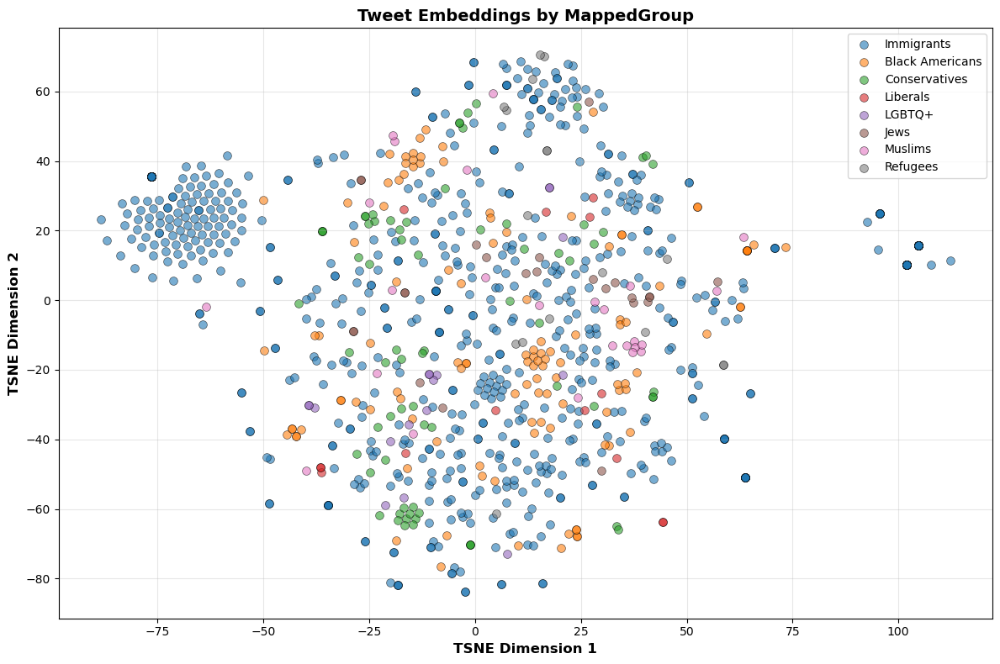

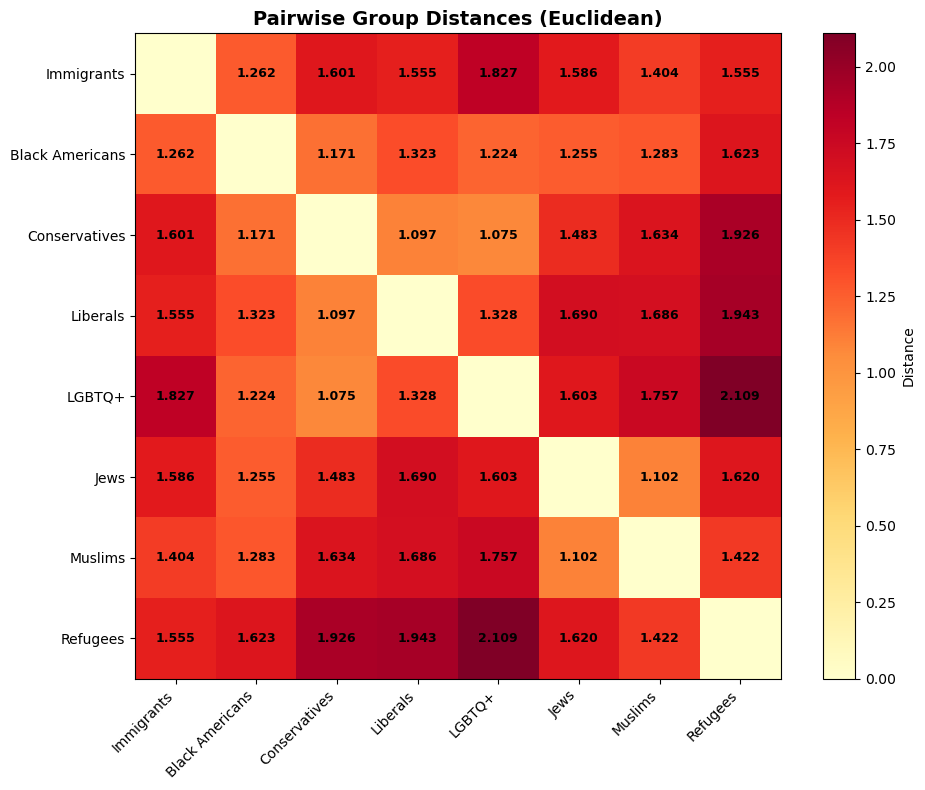

In [17]:
results = analyze_tweet_groups(
    df=df,
    target_word='immigration',  # Change to your word
    output_dir='results'
)

In [18]:
analyzer = results['analyzer']
group_embeddings = results['group_embeddings']

# View statistics
print(analyzer.group_means)
print(analyzer.distance_matrix)

{'Immigrants': array([ 4.27000783e-02, -1.35947183e-01,  3.24133858e-02,  1.37474671e-01,
       -2.49601707e-01,  8.24405476e-02,  6.57452457e-03, -1.48116210e-02,
        1.12093374e-01, -1.48749081e-02, -3.10167700e-01, -3.50001045e-02,
       -1.18085116e-01, -2.37368047e-01, -8.97249207e-02, -1.87398598e-01,
        2.48721968e-02, -1.40311822e-01,  5.59658445e-02,  1.99323092e-02,
        1.87735283e-03, -5.31536415e-02,  3.54324430e-02,  9.01845545e-02,
        3.99882384e-02, -1.24997891e-01, -7.10765719e-02,  3.28202210e-02,
       -1.77917942e-01,  1.55096069e-01,  1.15671847e-02, -5.96882477e-02,
        6.53627291e-02, -9.51089263e-02,  8.48333612e-02,  1.07509978e-01,
        2.13815987e-01,  1.29446238e-01,  7.07007468e-01,  8.44954401e-02,
        2.03911766e-01, -3.16024691e-01,  6.43033758e-02, -1.10205999e-02,
        5.95866777e-02, -2.25854223e-03,  4.52462351e-03, -1.85230076e-01,
        9.73970518e-02, -1.11586884e-01,  1.48880690e-01,  2.96062380e-02,
       -4.

TWEET GROUP EMBEDDING ANALYSIS: 'immigration'
Preparing data...
Initial shape: (153246, 19)
After length filter: (153246, 20)
After filtering for 'immigration': (1760, 20)
After removing missing groups: (1760, 20)

Group distribution:
  Immigrants: 1250 tweets
  Black Americans: 214 tweets
  Conservatives: 124 tweets
  Muslims: 44 tweets
  Jews: 40 tweets
  LGBTQ+: 34 tweets
  Refugees: 32 tweets
  Liberals: 22 tweets

Extracted 1850 contexts for 'immigration'

COMPUTING ROBERTA EMBEDDINGS
Initializing RoBERTa on cpu...


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Processed 1850/1850 contexts

STATISTICAL ANALYSIS

GROUP STATISTICS

Immigrants:
  N = 1310
  Mean norm = 21.8954
  Avg std = 0.1198

Black Americans:
  N = 226
  Mean norm = 21.9603
  Avg std = 0.1098

Conservatives:
  N = 131
  Mean norm = 22.1558
  Avg std = 0.1028

Liberals:
  N = 27
  Mean norm = 21.9969
  Avg std = 0.1056

LGBTQ+:
  N = 34
  Mean norm = 22.1123
  Avg std = 0.0974

Jews:
  N = 40
  Mean norm = 22.0357
  Avg std = 0.0993

Muslims:
  N = 45
  Mean norm = 22.0740
  Avg std = 0.1091

Refugees:
  N = 37
  Mean norm = 22.0413
  Avg std = 0.1376

PAIRWISE GROUP DISTANCES
Immigrants <-> Black Americans: 1.2617
Immigrants <-> Conservatives: 1.6015
Immigrants <-> Liberals: 1.5546
Immigrants <-> LGBTQ+: 1.8269
Immigrants <-> Jews: 1.5861
Immigrants <-> Muslims: 1.4044
Immigrants <-> Refugees: 1.5547
Black Americans <-> Conservatives: 1.1705
Black Americans <-> Liberals: 1.3234
Black Americans <-> LGBTQ+: 1.2243
Black Americans <-> Jews: 1.2549
Black Americans <-> Muslims: 1

AttributeError: 'GroupEmbeddingAnalyzer' object has no attribute 'find_nearest_neighbors'

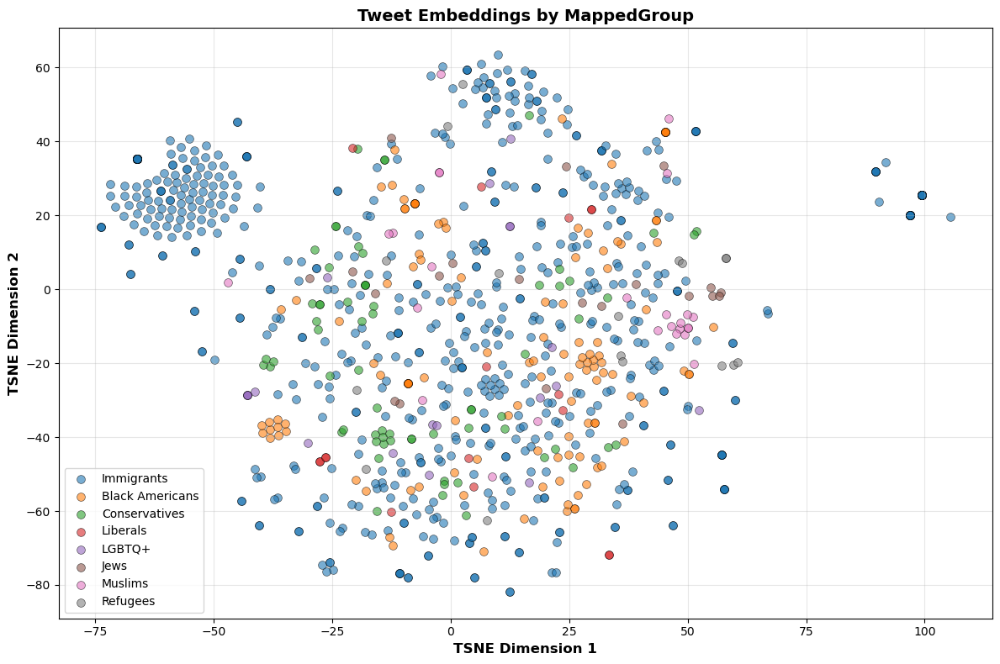

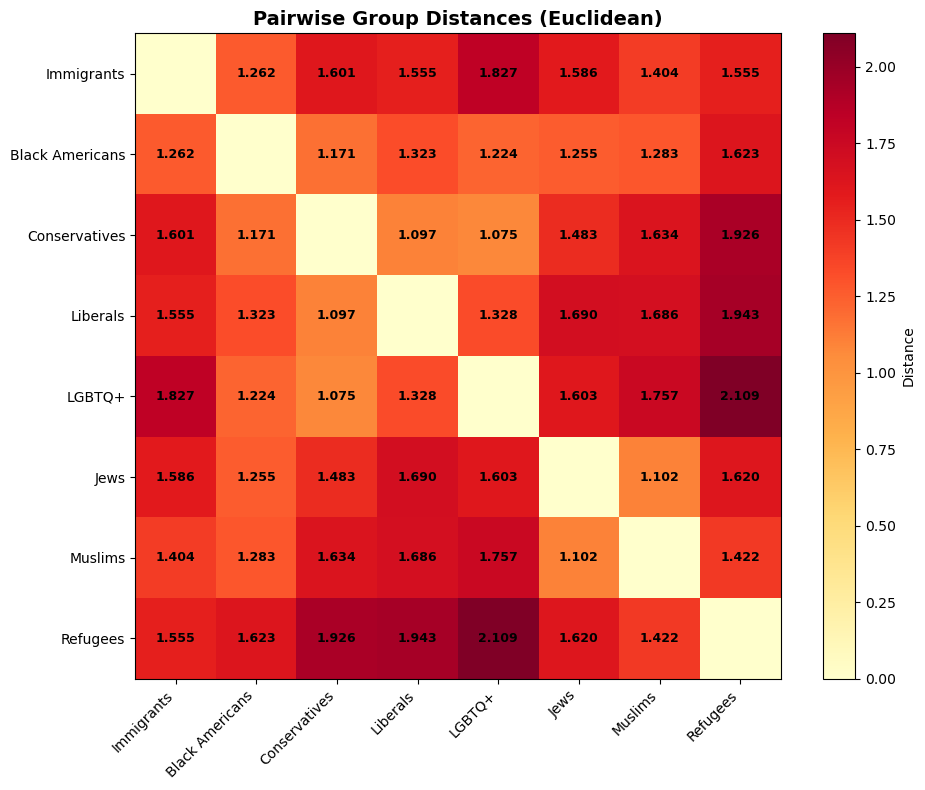

In [22]:
"""
Additional Visualization Methods
Add these methods to the GroupEmbeddingAnalyzer class
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cosine

# ============================================================================
# ADD THESE METHODS TO GroupEmbeddingAnalyzer CLASS
# ============================================================================

def plot_top_nearest_contexts(self, n_contexts=10, save_path='top_nearest_contexts.png'):
    """
    Plot top nearest contexts for each group similar to the academic figure
    Shows cosine similarity ratios between groups
    
    Args:
        n_contexts: number of top contexts to analyze
        save_path: path to save figure
    """
    if not hasattr(self, 'nn_results'):
        self.find_nearest_neighbors(n_neighbors=n_contexts)
    
    print("\n" + "="*70)
    print("ANALYZING TOP NEAREST CONTEXTS")
    print("="*70)
    
    groups = list(self.group_embeddings.keys())
    
    if len(groups) != 2:
        print("This visualization requires exactly 2 groups")
        return None
    
    group1, group2 = groups
    
    # Get top contexts for each group
    contexts1 = []
    contexts2 = []
    
    for item in self.nn_results[group1]['within_group'][:n_contexts]:
        ctx = item['context']
        contexts1.append({
            'text': ctx['full_context'],
            'embedding': None
        })
    
    for item in self.nn_results[group2]['within_group'][:n_contexts]:
        ctx = item['context']
        contexts2.append({
            'text': ctx['full_context'],
            'embedding': None
        })
    
    # Get embeddings
    mean1 = self.group_means[group1]
    mean2 = self.group_means[group2]
    
    # Calculate cosine similarities
    context_similarities = []
    
    for ctx_list, group_name in [(contexts1, group1), (contexts2, group2)]:
        for i, ctx in enumerate(ctx_list):
            # Find the embedding for this context
            for item in self.nn_results[group_name]['within_group']:
                if item['context']['full_context'] == ctx['text']:
                    emb = item['context']
                    # Get actual embedding from group_embeddings
                    for j, stored_ctx in enumerate(self.group_embeddings[group_name]['contexts']):
                        if stored_ctx['full_context'] == ctx['text']:
                            ctx['embedding'] = self.group_embeddings[group_name]['embeddings'][j]
                            break
                    break
            
            if ctx['embedding'] is not None:
                # Calculate cosine similarity to both group means
                sim1 = 1 - cosine(ctx['embedding'], mean1)
                sim2 = 1 - cosine(ctx['embedding'], mean2)
                
                # Calculate ratio (similar to the figure)
                if group_name == group1:
                    ratio = sim1 / sim2 if sim2 > 0 else sim1
                    category = group1
                else:
                    ratio = sim2 / sim1 if sim1 > 0 else sim2
                    category = group2
                
                context_similarities.append({
                    'context': ctx['text'][:30] + '...',
                    'ratio': ratio,
                    'group': group_name,
                    'sim_own': sim1 if group_name == group1 else sim2,
                    'sim_other': sim2 if group_name == group1 else sim1
                })
    
    # Create figure
    df_plot = pd.DataFrame(context_similarities)
    df_plot = df_plot.sort_values('ratio', ascending=False)
    
    fig, ax = plt.subplots(1, 1, figsize=(14, 8))
    
    # Separate by group
    df_g1 = df_plot[df_plot['group'] == group1]
    df_g2 = df_plot[df_plot['group'] == group2]
    
    y_positions = []
    labels = []
    colors = []
    markers = []
    
    # Add group 1 contexts
    for i, (_, row) in enumerate(df_g1.iterrows()):
        y_positions.append(len(df_g1) - i)
        labels.append(row['context'])
        colors.append('black')
        markers.append('o')
    
    # Add shared/middle contexts (if any with similar ratios)
    middle_contexts = df_plot[(df_plot['ratio'] > 0.9) & (df_plot['ratio'] < 1.1)]
    
    # Add group 2 contexts
    for i, (_, row) in enumerate(df_g2.iterrows()):
        y_positions.append(-(i+1))
        labels.append(row['context'])
        colors.append('gray')
        markers.append('s')
    
    # Plot
    x_values = df_plot['ratio'].values
    
    for i, (y, x, color, marker) in enumerate(zip(y_positions, x_values, colors, markers)):
        ax.scatter(x, y, c=color, marker=marker, s=150, alpha=0.7, edgecolors='black', linewidth=1)
    
    ax.set_yticks(y_positions)
    ax.set_yticklabels(labels, fontsize=9)
    ax.set_xlabel(f'Cosine Similarity Ratio ({group1}/{group2})', fontsize=12, fontweight='bold')
    ax.set_title(f'Top Nearest Contexts by Group Affinity', fontsize=14, fontweight='bold')
    ax.axvline(x=1.0, color='red', linestyle='--', linewidth=2, alpha=0.5, label='Equal similarity')
    ax.grid(True, alpha=0.3, axis='x')
    
    # Add legend
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=10, label=group1),
        Line2D([0], [0], marker='s', color='w', markerfacecolor='gray', markersize=10, label=group2),
        Line2D([0], [0], color='red', linestyle='--', linewidth=2, label='Equal similarity')
    ]
    ax.legend(handles=legend_elements, loc='best', frameon=True, fontsize=10)
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"✓ Top nearest contexts plot saved to {save_path}")
    
    return fig, df_plot


def plot_temporal_semantic_change(self, df, target_word, year_col='year', 
                                  group1=None, group2=None, 
                                  year_range=None,
                                  save_path='temporal_change.png'):
    """
    Plot semantic change over time (like Figure 7)
    Shows how the difference between two groups changes over years
    
    Args:
        df: original dataframe with year column
        target_word: the focal word
        year_col: name of year column
        group1: first group name (if None, uses first group)
        group2: second group name (if None, uses second group)
        year_range: tuple (start_year, end_year) or None for all years
        save_path: path to save figure
    """
    print("\n" + "="*70)
    print(f"TEMPORAL SEMANTIC CHANGE ANALYSIS: '{target_word}'")
    print("="*70)
    
    groups = list(self.group_embeddings.keys())
    
    if group1 is None:
        group1 = groups[0]
    if group2 is None:
        group2 = groups[1] if len(groups) > 1 else groups[0]
    
    if group1 == group2:
        print("Error: Need two different groups")
        return None
    
    # Add year info to contexts
    year_data = defaultdict(lambda: {group1: [], group2: []})
    
    for group in [group1, group2]:
        contexts = self.group_embeddings[group]['contexts']
        embeddings = self.group_embeddings[group]['embeddings']
        
        for ctx, emb in zip(contexts, embeddings):
            tweet_id = ctx.get('tweet_id')
            if tweet_id is not None and year_col in df.columns:
                # Find year for this tweet
                year_match = df[df.index == tweet_id]
                if len(year_match) > 0:
                    year = year_match.iloc[0][year_col]
                    year_data[year][group].append(emb)
    
    # Calculate yearly differences
    years = sorted(year_data.keys())
    
    if year_range:
        years = [y for y in years if year_range[0] <= y <= year_range[1]]
    
    year_diffs = []
    year_list = []
    
    for year in years:
        if len(year_data[year][group1]) > 0 and len(year_data[year][group2]) > 0:
            mean1 = np.array(year_data[year][group1]).mean(axis=0)
            mean2 = np.array(year_data[year][group2]).mean(axis=0)
            
            # Calculate Euclidean distance (norm of difference)
            diff = np.linalg.norm(mean1 - mean2)
            
            year_diffs.append(diff)
            year_list.append(year)
            
            print(f"Year {year}: {group1}={len(year_data[year][group1])}, "
                  f"{group2}={len(year_data[year][group2])}, diff={diff:.4f}")
    
    if len(year_diffs) == 0:
        print("Error: No temporal data found")
        return None
    
    # Bootstrap confidence intervals
    n_bootstrap = 100
    bootstrap_diffs = []
    
    for _ in range(n_bootstrap):
        boot_diffs = []
        for year in year_list:
            embs1 = year_data[year][group1]
            embs2 = year_data[year][group2]
            
            if len(embs1) > 0 and len(embs2) > 0:
                # Resample
                boot_idx1 = np.random.choice(len(embs1), len(embs1), replace=True)
                boot_idx2 = np.random.choice(len(embs2), len(embs2), replace=True)
                
                boot_mean1 = np.array([embs1[i] for i in boot_idx1]).mean(axis=0)
                boot_mean2 = np.array([embs2[i] for i in boot_idx2]).mean(axis=0)
                
                boot_diff = np.linalg.norm(boot_mean1 - boot_mean2)
                boot_diffs.append(boot_diff)
        
        bootstrap_diffs.append(boot_diffs)
    
    bootstrap_diffs = np.array(bootstrap_diffs)
    ci_lower = np.percentile(bootstrap_diffs, 2.5, axis=0)
    ci_upper = np.percentile(bootstrap_diffs, 97.5, axis=0)
    
    # Create figure
    fig, ax = plt.subplots(1, 1, figsize=(14, 6))
    
    # Plot main line
    ax.plot(year_list, year_diffs, 'o-', color='black', linewidth=2.5, 
            markersize=6, label=f'{group1} vs {group2}')
    
    # Plot confidence intervals
    ax.fill_between(year_list, ci_lower, ci_upper, alpha=0.2, color='gray')
    ax.plot(year_list, ci_lower, '--', color='gray', linewidth=1.5, alpha=0.7)
    ax.plot(year_list, ci_upper, '--', color='gray', linewidth=1.5, alpha=0.7)
    
    # Styling
    ax.set_xlabel('Year', fontsize=12, fontweight='bold')
    ax.set_ylabel('Norm of β', fontsize=12, fontweight='bold')
    ax.set_title(f'Semantic Difference Between {group1} and {group2}: "{target_word}"', 
                fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', frameon=True, fontsize=10)
    
    # Format x-axis
    if len(year_list) > 20:
        step = len(year_list) // 10
        ax.set_xticks(year_list[::step])
        ax.set_xticklabels([f'{int(y)}-{int(y+1)}' for y in year_list[::step]], rotation=45)
    else:
        ax.set_xticks(year_list)
        ax.set_xticklabels([f'{int(y)}-{int(y+1)}' for y in year_list], rotation=45)
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"✓ Temporal change plot saved to {save_path}")
    
    # Save data
    temporal_df = pd.DataFrame({
        'year': year_list,
        'difference': year_diffs,
        'ci_lower': ci_lower,
        'ci_upper': ci_upper
    })
    
    csv_path = save_path.replace('.png', '_data.csv')
    temporal_df.to_csv(csv_path, index=False)
    print(f"✓ Temporal data saved to {csv_path}")
    
    return fig, temporal_df


# ============================================================================
# USAGE IN MAIN ANALYSIS FUNCTION
# ============================================================================

def analyze_tweet_groups_with_temporal(df, target_word, output_dir='results', 
                                       n_neighbors=10, nn_metric='euclidean',
                                       year_col='year', temporal_analysis=True):
    """
    Complete analysis with temporal visualization
    
    Args:
        df: DataFrame with columns [pure_text, MappedGroup, year, ...]
        target_word: word to analyze
        output_dir: directory to save results
        n_neighbors: number of nearest neighbors
        nn_metric: 'euclidean' or 'cosine'
        year_col: name of year column in df
        temporal_analysis: whether to do temporal analysis
    """
    import os
    os.makedirs(output_dir, exist_ok=True)
    
    # Run standard analysis first
    from your_module import analyze_tweet_groups  # Import your main function
    
    results = analyze_tweet_groups(df, target_word, output_dir, n_neighbors, nn_metric)
    
    if results is None:
        return None
    
    analyzer = results['analyzer']
    
    # Add new visualization methods to analyzer
    analyzer.plot_top_nearest_contexts = lambda *args, **kwargs: plot_top_nearest_contexts(analyzer, *args, **kwargs)
    analyzer.plot_temporal_semantic_change = lambda *args, **kwargs: plot_temporal_semantic_change(analyzer, *args, **kwargs)
    
    # Generate new visualizations
    print("\n" + "="*70)
    print("GENERATING ADDITIONAL VISUALIZATIONS")
    print("="*70)
    
    # Top nearest contexts plot
    analyzer.plot_top_nearest_contexts(
        n_contexts=15,
        save_path=f'{output_dir}/{target_word}_top_contexts.png'
    )
    
    # Temporal analysis (if year column exists)
    if temporal_analysis and year_col in df.columns:
        analyzer.plot_temporal_semantic_change(
            df=df,
            target_word=target_word,
            year_col=year_col,
            save_path=f'{output_dir}/{target_word}_temporal.png'
        )
    
    return results


# ============================================================================
# STANDALONE USAGE
# ============================================================================

if __name__ == "__main__":


# After running your main analysis:
    results = analyze_tweet_groups(df, 'immigration', 'results')
    analyzer = results['analyzer']

# Add the new methods
    analyzer.plot_top_nearest_contexts = lambda *args, **kwargs: plot_top_nearest_contexts(analyzer, *args, **kwargs)
    analyzer.plot_temporal_semantic_change = lambda *args, **kwargs: plot_temporal_semantic_change(analyzer, *args, **kwargs)

    # Generate top contexts plot
    analyzer.plot_top_nearest_contexts(
        n_contexts=15,
        save_path='top_contexts.png'
    )

    # Generate temporal plot
    analyzer.plot_temporal_semantic_change(
        df=df,
        target_word='immigration',
        year_col='year',
        group1='Liberal',
        group2='Conservative',
        year_range=(2012, 2022),
        save_path='temporal_change.png'
    )
   

In [23]:
analyzer.plot_top_nearest_contexts = lambda *args, **kwargs: plot_top_nearest_contexts(analyzer, *args, **kwargs)
analyzer.plot_temporal_semantic_change = lambda *args, **kwargs: plot_temporal_semantic_change(analyzer, *args, **kwargs)

    # Generate top contexts plot
analyzer.plot_top_nearest_contexts(n_contexts=15, save_path='top_contexts.png')

    # # Generate temporal plot
    # analyzer.plot_temporal_semantic_change(
    #     df=df,
    #     target_word='immigration',
    #     year_col='year',
    #     group1='Liberal',
    #     group2='Conservative',
    #     year_range=(2012, 2022),
    #     save_path='temporal_change.png'
    # )
   

AttributeError: 'GroupEmbeddingAnalyzer' object has no attribute 'find_nearest_neighbors'

In [26]:
"""
Standalone Visualization Functions
Works with your existing analyzer without modifications
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cosine
from collections import defaultdict
from sklearn.neighbors import NearestNeighbors

# ============================================================================
# STANDALONE FUNCTION 1: TOP NEAREST CONTEXTS
# ============================================================================

def plot_top_nearest_contexts_standalone(analyzer, n_contexts=15, save_path='top_contexts.png'):
    """
    Plot top nearest contexts for each group
    Shows cosine similarity ratios between groups
    
    Args:
        analyzer: your GroupEmbeddingAnalyzer instance
        n_contexts: number of top contexts to analyze
        save_path: path to save figure
    """
    print("\n" + "="*70)
    print("ANALYZING TOP NEAREST CONTEXTS")
    print("="*70)
    
    groups = list(analyzer.group_embeddings.keys())
    
    if len(groups) != 2:
        print("This visualization requires exactly 2 groups")
        return None
    
    group1, group2 = groups
    print(f"Comparing: {group1} vs {group2}")
    
    # Get mean embeddings
    mean1 = analyzer.group_means[group1]
    mean2 = analyzer.group_means[group2]
    
    # Find nearest contexts for each group (closest to their own centroid)
    contexts_data = []
    
    for group_name in [group1, group2]:
        embeddings = analyzer.group_embeddings[group_name]['embeddings']
        contexts = analyzer.group_embeddings[group_name]['contexts']
        
        # Calculate distances to own group centroid
        centroid = analyzer.group_means[group_name]
        distances = [np.linalg.norm(emb - centroid) for emb in embeddings]
        
        # Get top n closest
        sorted_indices = np.argsort(distances)[:n_contexts]
        
        for idx in sorted_indices:
            emb = embeddings[idx]
            ctx = contexts[idx]
            
            # Calculate cosine similarity to both centroids
            sim1 = 1 - cosine(emb, mean1)
            sim2 = 1 - cosine(emb, mean2)
            
            # Calculate ratio
            if group_name == group1:
                ratio = sim1 / sim2 if sim2 > 0 else 2.0
            else:
                ratio = sim2 / sim1 if sim1 > 0 else 2.0
            
            contexts_data.append({
                'context': ctx['full_context'][:40] + '...',
                'full_text': ctx['text'],
                'ratio': ratio,
                'group': group_name,
                'sim_own': sim1 if group_name == group1 else sim2,
                'sim_other': sim2 if group_name == group1 else sim1,
                'distance_to_centroid': distances[idx]
            })
    
    # Create DataFrame
    df_plot = pd.DataFrame(contexts_data)
    
    # Sort by ratio
    df_g1 = df_plot[df_plot['group'] == group1].sort_values('ratio', ascending=False).head(n_contexts)
    df_g2 = df_plot[df_plot['group'] == group2].sort_values('ratio', ascending=False).head(n_contexts)
    
    # Create figure
    fig, ax = plt.subplots(1, 1, figsize=(14, 10))
    
    # Plot group 1 contexts (top half)
    y_pos = len(df_g1)
    for _, row in df_g1.iterrows():
        ax.scatter(row['ratio'], y_pos, c='black', marker='o', s=150, 
                  alpha=0.7, edgecolors='black', linewidth=1)
        y_pos -= 1
    
    # Plot group 2 contexts (bottom half)
    y_pos = -1
    for _, row in df_g2.iterrows():
        ax.scatter(row['ratio'], y_pos, c='gray', marker='s', s=150, 
                  alpha=0.7, edgecolors='black', linewidth=1)
        y_pos -= 1
    
    # Set y-axis labels
    y_positions = list(range(len(df_g1), 0, -1)) + list(range(-1, -len(df_g2)-1, -1))
    labels = df_g1['context'].tolist() + df_g2['context'].tolist()
    
    ax.set_yticks(y_positions)
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel(f'Cosine Similarity Ratio ({group1}/{group2})', fontsize=12, fontweight='bold')
    ax.set_title(f'Top Nearest Contexts by Group Affinity', fontsize=14, fontweight='bold')
    ax.axvline(x=1.0, color='red', linestyle='--', linewidth=2, alpha=0.5, label='Equal similarity')
    ax.axhline(y=0.5, color='black', linestyle='-', linewidth=1.5, alpha=0.3)
    ax.grid(True, alpha=0.3, axis='x')
    
    # Add group labels
    ax.text(0.02, 0.95, group1, transform=ax.transAxes, fontsize=12, 
           fontweight='bold', verticalalignment='top', bbox=dict(boxstyle='round', 
           facecolor='lightgray', alpha=0.5))
    ax.text(0.02, 0.05, group2, transform=ax.transAxes, fontsize=12, 
           fontweight='bold', verticalalignment='bottom', bbox=dict(boxstyle='round', 
           facecolor='lightgray', alpha=0.5))
    
    # Legend
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor='black', 
              markersize=10, label=f'{group1}-specific'),
        Line2D([0], [0], marker='s', color='w', markerfacecolor='gray', 
              markersize=10, label=f'{group2}-specific'),
        Line2D([0], [0], color='red', linestyle='--', linewidth=2, label='Equal similarity')
    ]
    ax.legend(handles=legend_elements, loc='upper right', frameon=True, fontsize=10)
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"✓ Top nearest contexts plot saved to {save_path}")
    
    # Save data to CSV
    csv_path = save_path.replace('.png', '_data.csv')
    df_plot.to_csv(csv_path, index=False)
    print(f"✓ Context data saved to {csv_path}")
    
    return fig, df_plot


# ============================================================================
# STANDALONE FUNCTION 2: TEMPORAL SEMANTIC CHANGE
# ============================================================================

def plot_temporal_semantic_change_standalone(analyzer, df, target_word, 
                                            year_col='year',
                                            group1=None, group2=None, 
                                            year_range=None,
                                            save_path='temporal_change.png'):
    """
    Plot semantic change over time between two groups
    
    Args:
        analyzer: your GroupEmbeddingAnalyzer instance
        df: original dataframe with year column
        target_word: the focal word
        year_col: name of year column
        group1: first group name (if None, uses first group)
        group2: second group name (if None, uses second group)
        year_range: tuple (start_year, end_year) or None for all years
        save_path: path to save figure
    """
    print("\n" + "="*70)
    print(f"TEMPORAL SEMANTIC CHANGE ANALYSIS: '{target_word}'")
    print("="*70)
    
    groups = list(analyzer.group_embeddings.keys())
    
    if group1 is None:
        group1 = groups[0]
    if group2 is None:
        group2 = groups[1] if len(groups) > 1 else groups[0]
    
    if group1 == group2:
        print("Error: Need two different groups")
        return None
    
    print(f"Comparing: {group1} vs {group2}")
    
    # Create mapping from tweet text to year
    df_copy = df.copy()
    if year_col not in df_copy.columns:
        print(f"Error: Column '{year_col}' not found in dataframe")
        print(f"Available columns: {df_copy.columns.tolist()}")
        return None
    
    # Map contexts to years
    year_data = defaultdict(lambda: {group1: [], group2: []})
    
    for group in [group1, group2]:
        contexts = analyzer.group_embeddings[group]['contexts']
        embeddings = analyzer.group_embeddings[group]['embeddings']
        
        for ctx, emb in zip(contexts, embeddings):
            # Try to find year by matching text
            text = ctx['text']
            matching_rows = df_copy[df_copy['pure_text'].str.lower() == text.lower()]
            
            if len(matching_rows) > 0:
                year = matching_rows.iloc[0][year_col]
                if pd.notna(year):
                    year_data[int(year)][group].append(emb)
    
    if len(year_data) == 0:
        print("Error: No temporal data found. Make sure 'pure_text' matches between df and contexts")
        return None
    
    # Calculate yearly differences
    years = sorted(year_data.keys())
    
    if year_range:
        years = [y for y in years if year_range[0] <= y <= year_range[1]]
    
    year_diffs = []
    year_list = []
    year_counts = []
    
    print("\nYearly statistics:")
    for year in years:
        n1 = len(year_data[year][group1])
        n2 = len(year_data[year][group2])
        
        if n1 >= 3 and n2 >= 3:  # Minimum threshold
            mean1 = np.array(year_data[year][group1]).mean(axis=0)
            mean2 = np.array(year_data[year][group2]).mean(axis=0)
            
            # Calculate Euclidean distance
            diff = np.linalg.norm(mean1 - mean2)
            
            year_diffs.append(diff)
            year_list.append(year)
            year_counts.append((n1, n2))
            
            print(f"  {year}: {group1}={n1}, {group2}={n2}, diff={diff:.4f}")
        else:
            print(f"  {year}: Skipped (insufficient data: {group1}={n1}, {group2}={n2})")
    
    if len(year_diffs) == 0:
        print("Error: No years with sufficient data (need at least 3 samples per group)")
        return None
    
    # Bootstrap confidence intervals
    print("\nComputing bootstrap confidence intervals...")
    n_bootstrap = 100
    bootstrap_diffs = []
    
    for b in range(n_bootstrap):
        boot_diffs = []
        for year in year_list:
            embs1 = year_data[year][group1]
            embs2 = year_data[year][group2]
            
            if len(embs1) >= 3 and len(embs2) >= 3:
                # Resample with replacement
                boot_idx1 = np.random.choice(len(embs1), len(embs1), replace=True)
                boot_idx2 = np.random.choice(len(embs2), len(embs2), replace=True)
                
                boot_mean1 = np.array([embs1[i] for i in boot_idx1]).mean(axis=0)
                boot_mean2 = np.array([embs2[i] for i in boot_idx2]).mean(axis=0)
                
                boot_diff = np.linalg.norm(boot_mean1 - boot_mean2)
                boot_diffs.append(boot_diff)
        
        bootstrap_diffs.append(boot_diffs)
        
        if (b + 1) % 25 == 0:
            print(f"  {b+1}/{n_bootstrap} iterations complete", end='\r')
    
    print()
    
    bootstrap_diffs = np.array(bootstrap_diffs)
    ci_lower = np.percentile(bootstrap_diffs, 2.5, axis=0)
    ci_upper = np.percentile(bootstrap_diffs, 97.5, axis=0)
    
    # Create figure
    fig, ax = plt.subplots(1, 1, figsize=(14, 6))
    
    # Plot main line
    ax.plot(year_list, year_diffs, 'o-', color='black', linewidth=2.5, 
            markersize=8, label=f'{group1} vs {group2}', zorder=3)
    
    # Plot confidence intervals
    ax.fill_between(year_list, ci_lower, ci_upper, alpha=0.2, color='gray', zorder=1)
    ax.plot(year_list, ci_lower, '--', color='gray', linewidth=1.5, alpha=0.7, zorder=2)
    ax.plot(year_list, ci_upper, '--', color='gray', linewidth=1.5, alpha=0.7, zorder=2)
    
    # Styling
    ax.set_xlabel('Year', fontsize=12, fontweight='bold')
    ax.set_ylabel('Norm of β (Euclidean Distance)', fontsize=12, fontweight='bold')
    ax.set_title(f'{group1} and {group2} Difference in Understanding of "{target_word}"', 
                fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
    
    # Format x-axis
    if len(year_list) > 15:
        step = max(1, len(year_list) // 10)
        tick_years = year_list[::step]
        ax.set_xticks(tick_years)
        ax.set_xticklabels([f'{int(y)}-{int(y+1)}' for y in tick_years], rotation=45, ha='right')
    else:
        ax.set_xticks(year_list)
        ax.set_xticklabels([f'{int(y)}-{int(y+1)}' for y in year_list], rotation=45, ha='right')
    
    # Add note about CIs
    note_text = "Note: Larger values imply the uses are more different.\nDashed lines show bootstrapped 95% CIs."
    ax.text(0.02, 0.98, note_text, transform=ax.transAxes, fontsize=9,
           verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"✓ Temporal change plot saved to {save_path}")
    
    # Save data
    temporal_df = pd.DataFrame({
        'year': year_list,
        'difference': year_diffs,
        'ci_lower': ci_lower,
        'ci_upper': ci_upper,
        f'n_{group1}': [c[0] for c in year_counts],
        f'n_{group2}': [c[1] for c in year_counts]
    })
    
    csv_path = save_path.replace('.png', '_data.csv')
    temporal_df.to_csv(csv_path, index=False)
    print(f"✓ Temporal data saved to {csv_path}")
    
    return fig, temporal_df


# ============================================================================
# EASY USAGE WRAPPER
# ============================================================================

def add_visualizations(analyzer, df=None, target_word=None):
    """
    Add visualization methods to an existing analyzer
    
    Args:
        analyzer: your GroupEmbeddingAnalyzer instance
        df: original dataframe (needed for temporal analysis)
        target_word: focal word (needed for temporal analysis)
    
    Returns:
        analyzer with new methods attached
    """
    # Attach methods
    analyzer.plot_top_contexts = lambda **kwargs: plot_top_nearest_contexts_standalone(analyzer, **kwargs)
    analyzer.plot_temporal = lambda **kwargs: plot_temporal_semantic_change_standalone(
        analyzer, df, target_word, **kwargs)
    
    print("✓ Visualization methods added to analyzer:")
    print("  - analyzer.plot_top_contexts(n_contexts=15, save_path='...')")
    if df is not None and target_word is not None:
        print("  - analyzer.plot_temporal(year_col='year', group1='...', group2='...', save_path='...')")
    
    return analyzer


# ============================================================================
# USAGE EXAMPLES
# ============================================================================

if __name__ == "__main__":
    # After running your existing analysis:
    #results = analyze_tweet_groups(df, 'immigration', 'results')
    #analyzer = results['analyzer']
    
    # Option 1: Use functions directly
    plot_top_nearest_contexts_standalone(
        analyzer, 
        n_contexts=15, 
        save_path='top_contexts.png'
    )
    
    # plot_temporal_semantic_change_standalone(
    #     analyzer,
    #     df=df,
    #     target_word='immigration',
    #     year_col='year',
    #     group1='Liberal',
    #     group2='Conservative',
    #     year_range=(2012, 2022),
    #     save_path='temporal.png'
    # )
    
    # Option 2: Add methods to analyzer (cleaner)
    analyzer = add_visualizations(analyzer, df=df, target_word='immigration')
    
    analyzer.plot_top_contexts(n_contexts=15, save_path='top_contexts.png')
    
    # analyzer.plot_temporal(
    #     year_col='year',
    #     group1='Liberal',
    #     group2='Conservative',
    #     year_range=(2012, 2022),
    #     save_path='temporal.png'
    # )




ANALYZING TOP NEAREST CONTEXTS
This visualization requires exactly 2 groups
✓ Visualization methods added to analyzer:
  - analyzer.plot_top_contexts(n_contexts=15, save_path='...')
  - analyzer.plot_temporal(year_col='year', group1='...', group2='...', save_path='...')

ANALYZING TOP NEAREST CONTEXTS
This visualization requires exactly 2 groups


In [9]:
#Embedding 

import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from collections import defaultdict

# --- ASSUMED EXTERNAL DATA ---
# Load your pre-trained GloVe embeddings (300d) and the A_hat matrix.
# These files must be downloaded from the ALC repository linked in the paper.
# E.g., glove_embeddings = load_glove_file('glove.840B.300d.txt')
# E.g., A_hat = load_A_hat_matrix('A_hat.npy')

# Define global variables (replace with your loaded data)
GLOVE_EMBEDDINGS = {} # dictionary of {'word': np.array(vector)}
A_HAT_MATRIX = np.eye(300) # 300x300 transformation matrix

def load_pre_trained_data(glove_path, a_hat_path):
    """Placeholder to load GloVe and A_hat matrix."""
    global GLOVE_EMBEDDINGS, A_HAT_MATRIX
    # Load GloVe: reading file line by line
    # Load A_hat: np.load(a_hat_path)
    # This is a critical setup step you must perform outside this snippet.
    pass

def get_context_words(text, focal_word, window_size=5):
    """
    Extracts context words for a focal word in a given text.
    Returns a list of unique context words.
    """
    words = text.lower().split()
    try:
        focal_indices = [i for i, w in enumerate(words) if w == focal_word]
    except ValueError:
        return []

    context = set()
    for i in focal_indices:
        # Context window: (start, end) indices
        start = max(0, i - window_size)
        end = min(len(words), i + window_size + 1)
        
        # Add all words in the window, excluding the focal word itself
        context.update(words[start:i])
        context.update(words[i+1:end])
        
    return list(context)

def alc_embedding_for_period(texts, focal_word, window_size=5):
    """
    Computes the ALC embedding for a focal word for a collection of texts (one period).
    """
    context_vectors = []
    
    for text in texts:
        context_words = get_context_words(text, focal_word, window_size)
        
        # Collect GloVe vectors for context words
        vectors = [GLOVE_EMBEDDINGS[w] for w in context_words if w in GLOVE_EMBEDDINGS]
        
        if vectors:
            # Step 1: Compute the average of the context embeddings
            u_w_avg = np.mean(vectors, axis=0)
            
            # Step 2: Apply the ALC transformation matrix (A_hat)
            v_alc = np.dot(A_HAT_MATRIX, u_w_avg)
            context_vectors.append(v_alc)

    if context_vectors:
        # Final ALC vector is the average of all period-specific ALC context vectors
        return np.mean(context_vectors, axis=0)
    else:
        # Return a zero vector or handle missing data
        return np.zeros(A_HAT_MATRIX.shape[0])

In [1]:
import io, zipfile, requests, os
import re, math, json
import numpy as np
import pandas as pd
from collections import defaultdict
from numpy.linalg import norm
from sklearn.metrics.pairwise import cosine_similarity

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------
# NOTE: Replace 'final_df.csv' with your actual CSV file path before running.
CSV_PATH = "US_vs_them_llama_labeled_data_final.csv"
GLOVE_URL = "https://nlp.stanford.edu/data/glove.6B.zip"
GLOVE_DIR = "embeddings"
GLOVE_FILE = os.path.join(GLOVE_DIR, "glove.6B.300d.txt")
DIM = 300

# --- ALC Configuration ---
# The five categories from the paper, plus 'equality' as the anchor.
FOCAL_WORDS = ["equality", "gender", "treaty", "german", "race", "african_american"]
CATEGORY_WORDS = [w for w in FOCAL_WORDS if w != "equality"]
WINDOW_SIZE = 6 # Context window size on each side, as set in your prompt
TOP_N_NEIGHBORS = 10 

# --- New Time Period Configuration (2-year slices from 2012-2022) ---
START_YEAR = 2012
END_YEAR = 2022
DURATION = 2
period_bins = list(range(START_YEAR, END_YEAR + DURATION + 1, DURATION))
period_labels = [
    f"{period_bins[i]}-{period_bins[i+1]-1}" 
    for i in range(len(period_bins) - 1)
]

# ----------------------------------------------------------------------
# 1. DATA LOADING AND SETUP
# ----------------------------------------------------------------------

# --- GLOVE Loading ---
def download_and_load_glove():
    """Downloads GloVe vectors and loads them into a dictionary."""
    if not os.path.exists(GLOVE_FILE):
        print(f"Downloading GloVe from {GLOVE_URL}...")
        os.makedirs(GLOVE_DIR, exist_ok=True)
        try:
            zbytes = requests.get(GLOVE_URL).content
            with zipfile.ZipFile(io.BytesIO(zbytes)) as zf:
                zf.extract("glove.6B.300d.txt", path=GLOVE_DIR)
            print(f"Saved GloVe to {GLOVE_FILE}")
        except Exception as e:
            print(f"Error during download or extraction: {e}")
            return {}

    print(f"Loading GloVe embeddings ({DIM}d)...")
    glove_embeddings = {}
    with open(GLOVE_FILE, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) > DIM:
                word = parts[0]
                vector = np.array(parts[1:], dtype=np.float32)
                glove_embeddings[word] = vector
    print(f"Successfully loaded {len(glove_embeddings)} words.")
    return glove_embeddings

# --- A_HAT Matrix Loading (Identity Matrix Fallback) ---
def load_a_hat_matrix(path=None):
    """
    Loads the ALC transformation matrix.
    Uses Identity Matrix as a fallback if the path is None or file is missing,
    which corresponds to untransformed Context Vector Averaging.
    """
    if path and os.path.exists(path):
        try:
            A_hat = np.load(path)
            if A_hat.shape == (DIM, DIM):
                print(f"Loaded A_hat matrix from {path}.")
                return A_hat
            else:
                print(f"Warning: Loaded A_hat shape {A_hat.shape} != expected ({DIM}, {DIM}). Using Identity.")
        except Exception as e:
            print(f"Error loading A_hat from {path}: {e}. Using Identity.")
    
    print(f"Using Identity Matrix for A_hat (untransformed ALC/CVA).")
    return np.eye(DIM)

# Load data and resources
try:
    df = pd.read_csv(CSV_PATH)
except FileNotFoundError:
    print(f"Error: CSV file not found at {CSV_PATH}. Please check the path.")
    exit()

GLOVE_EMBEDDINGS = download_and_load_glove()
A_HAT_MATRIX = load_a_hat_matrix(A_MATRIX_PATH)

if not GLOVE_EMBEDDINGS:
    print("FATAL: Cannot proceed without GloVe embeddings.")
    exit()

# ----------------------------------------------------------------------
# 2. CORE ALC FUNCTIONS
# ----------------------------------------------------------------------

def get_context_words(text, focal_word, window_size=6):
    """
    Extracts context words for a focal word. Handles basic cleaning and MWEs.
    """
    text = text.lower()
    
    # CRITICAL: Handle MWEs by temporarily replacing spaces with underscores
    # e.g., "african american" -> "african_american"
    # Note: This assumes MWEs only contain one space for simplification.
    mwe_text = text
    if '_' in focal_word:
        mwe_phrase = focal_word.replace('_', ' ')
        mwe_text = mwe_text.replace(mwe_phrase, focal_word)
    
    # Tokenize: Replace non-alphanumeric/underscore with space, then split
    tokens = re.sub(r'[^\w_]', ' ', mwe_text).split()
    
    focal_indices = [i for i, w in enumerate(tokens) if w == focal_word]
    
    context = set()
    for i in focal_indices:
        start = max(0, i - window_size)
        end = min(len(tokens), i + window_size + 1)
        
        # Add all words in the window, excluding the focal word
        context.update(tokens[start:i])
        context.update(tokens[i+1:end])
        
    return list(context)

def alc_embedding_for_period(texts, focal_word, window_size=6):
    """
    Computes the ALC embedding for a focal word for a collection of texts.
    """
    context_vectors = []
    
    for text in texts:
        context_words = get_context_words(text, focal_word, window_size)
        
        # Collect GloVe vectors for context words that are in the vocabulary
        vectors = [GLOVE_EMBEDDINGS[w] for w in context_words if w in GLOVE_EMBEDDINGS]
        
        if vectors:
            # Step 1: Compute the average of the context embeddings (u_w_avg)
            u_w_avg = np.mean(vectors, axis=0)
            
            # Step 2: Apply the ALC transformation matrix (A_hat)
            v_alc = np.dot(A_HAT_MATRIX, u_w_avg)
            context_vectors.append(v_alc)

    if context_vectors:
        # Final ALC vector is the average of all period-specific ALC context vectors
        return np.mean(context_vectors, axis=0)
    else:
        # CRITICAL: Return a zero vector if no context was found for the word in this period.
        return np.zeros(DIM, dtype=np.float32)

def get_nearest_neighbors_alc(focal_word, period_vectors, top_n=10):
    """
    Finds the N nearest neighbors for a focal word's ALC vector.
    """
    v_alc = period_vectors.get(focal_word)
    
    if v_alc is None or np.all(v_alc == 0):
        return [f"No data for '{focal_word}' in this period."]
        
    # Prepare all GloVe vectors for comparison (create a local copy for speed)
    glove_words = list(GLOVE_EMBEDDINGS.keys())
    glove_vectors = np.array(list(GLOVE_EMBEDDINGS.values()))
    
    # Calculate cosine similarity with all GloVe words
    # Reshape v_alc to (1, -1) for scikit-learn's cosine_similarity
    similarities = cosine_similarity(v_alc.reshape(1, -1), glove_vectors)[0]
    
    # Create a Series, remove the focal word itself, sort, and get top N
    similarity_series = pd.Series(similarities, index=glove_words)
    similarity_series = similarity_series.drop(focal_word, errors='ignore')
    
    return similarity_series.nlargest(top_n).index.tolist()

# ----------------------------------------------------------------------
# 3. RUN ANALYSIS
# ----------------------------------------------------------------------

# 1. Prepare Data by Time Period
df['period'] = pd.cut(df['year'], bins=period_bins, labels=period_labels, right=False)

alc_vector_store = defaultdict(dict)
all_similarities = []
results_list = []

print("\n--- Starting ALC Vector Computation ---")
for period in period_labels:
    period_texts = df[df['period'] == period]['pure_text'].tolist()
    
    if not period_texts:
         print(f"Skipping {period}: No data in this time slice.")
         continue

    for word in FOCAL_WORDS:
        vector = alc_embedding_for_period(period_texts, word, WINDOW_SIZE)
        alc_vector_store[period][word] = vector

# 2. Calculate Cosine Similarity and Pool for Z-Score
print("\n--- Calculating Cosine Similarities ---")
for period in period_labels:
    v_equality = alc_vector_store[period].get("equality")
    
    if v_equality is None or np.all(v_equality == 0):
        print(f"Warning: 'equality' vector is zero/missing in {period}.")
        continue # Skip if the anchor word is missing
        
    for category in CATEGORY_WORDS:
        v_category = alc_vector_store[period].get(category)
        
        # Check for zero vectors before calculation
        if np.all(v_category == 0):
            similarity = 0.0 # Assign 0.0 similarity if category word is missing
        else:
            # Cosine similarity
            similarity = cosine_similarity(v_equality.reshape(1, -1), v_category.reshape(1, -1))[0][0]
        
        results_list.append({
            'period': period,
            'category': category,
            'similarity': similarity
        })
        all_similarities.append(similarity)

# 3. Z-Score Normalization
similarity_df = pd.DataFrame(results_list)

if all_similarities:
    mean_sim = np.mean(all_similarities)
    std_sim = np.std(all_similarities)
    
    if std_sim > 0:
        similarity_df['z_score'] = (similarity_df['similarity'] - mean_sim) / std_sim
    else:
        # Avoid division by zero if all similarities are the same (e.g., all 0.0)
        similarity_df['z_score'] = 0.0
else:
    similarity_df['z_score'] = np.nan

# 4. Output Z-Scores (Table Format)
print("\n" + "="*50)
print("--- ALC Z-Scores (Replicating Figure 1 Logic) ---")
print("="*50)
z_score_pivot = similarity_df.pivot(index='category', columns='period', values='z_score')
print(z_score_pivot)


# 5. Output Nearest Neighbors (Table Format)
print("\n" + "="*50)
print("--- ALC Nearest Neighbors (Replicating Tables 1 & 2 Logic) ---")
print("="*50)

neighbors_data = []

for period in period_labels:
    period_vectors = alc_vector_store[period]
    for word in FOCAL_WORDS:
        neighbors = get_nearest_neighbors_alc(word, period_vectors, TOP_N_NEIGHBORS)
        neighbors_data.append({
            'Period': period,
            'Word': word,
            'Nearest Neighbors': ', '.join(neighbors)
        })

neighbors_df = pd.DataFrame(neighbors_data)
# Pivot for cleaner display, similar to the original tables
pivot_neighbors = neighbors_df.pivot_table(index='Word', columns='Period', values='Nearest Neighbors', aggfunc=lambda x: x)
print(pivot_neighbors)

Loading GloVe embeddings (300d)...
Successfully loaded 400000 words.


NameError: name 'A_MATRIX_PATH' is not defined

In [2]:
import io, zipfile, requests, os
import re, math, json
import numpy as np
import pandas as pd
from collections import defaultdict
from numpy.linalg import norm
from sklearn.metrics.pairwise import cosine_similarity

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------
# NOTE: Replace 'final_df.csv' with your actual CSV file path before running.
CSV_PATH = "US_vs_them_llama_labeled_data_final.csv"
GLOVE_URL = "https://nlp.stanford.edu/data/glove.6B.zip"
GLOVE_DIR = "embeddings"
GLOVE_FILE = os.path.join(GLOVE_DIR, "glove.6B.300d.txt")
DIM = 300

# --- ALC Configuration ---
# The five categories from the paper, plus 'equality' as the anchor.
FOCAL_WORDS = ["equality", "gender", "treaty", "german", "race", "african_american"]
CATEGORY_WORDS = [w for w in FOCAL_WORDS if w != "equality"]
WINDOW_SIZE = 6 # Context window size on each side, as set in your prompt
TOP_N_NEIGHBORS = 10 

# --- A_HAT Matrix Path ---
# Path to your A_hat transformation matrix (e.g., A_glove_300d.npy).
# Setting it to None uses the Identity Matrix (untransformed Context Vector Averaging).
A_MATRIX_PATH = None 

# --- New Time Period Configuration (2-year slices from 2012-2022) ---
START_YEAR = 2012
END_YEAR = 2022
DURATION = 2
period_bins = list(range(START_YEAR, END_YEAR + DURATION + 1, DURATION))
period_labels = [
    f"{period_bins[i]}-{period_bins[i+1]-1}" 
    for i in range(len(period_bins) - 1)
]

# ----------------------------------------------------------------------
# 1. DATA LOADING AND SETUP
# ----------------------------------------------------------------------

# --- GLOVE Loading ---
def download_and_load_glove():
    """Downloads GloVe vectors and loads them into a dictionary."""
    if not os.path.exists(GLOVE_FILE):
        print(f"Downloading GloVe from {GLOVE_URL}...")
        os.makedirs(GLOVE_DIR, exist_ok=True)
        try:
            zbytes = requests.get(GLOVE_URL).content
            with zipfile.ZipFile(io.BytesIO(zbytes)) as zf:
                zf.extract("glove.6B.300d.txt", path=GLOVE_DIR)
            print(f"Saved GloVe to {GLOVE_FILE}")
        except Exception as e:
            print(f"Error during download or extraction: {e}")
            return {}

    print(f"Loading GloVe embeddings ({DIM}d)...")
    glove_embeddings = {}
    with open(GLOVE_FILE, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) > DIM:
                word = parts[0]
                vector = np.array(parts[1:], dtype=np.float32)
                glove_embeddings[word] = vector
    print(f"Successfully loaded {len(glove_embeddings)} words.")
    return glove_embeddings

# --- A_HAT Matrix Loading (Identity Matrix Fallback) ---
def load_a_hat_matrix(path=None):
    """
    Loads the ALC transformation matrix.
    Uses Identity Matrix as a fallback if the path is None or file is missing,
    which corresponds to untransformed Context Vector Averaging.
    """
    if path and os.path.exists(path):
        try:
            A_hat = np.load(path)
            if A_hat.shape == (DIM, DIM):
                print(f"Loaded A_hat matrix from {path}.")
                return A_hat
            else:
                print(f"Warning: Loaded A_hat shape {A_hat.shape} != expected ({DIM}, {DIM}). Using Identity.")
        except Exception as e:
            print(f"Error loading A_hat from {path}: {e}. Using Identity.")
    
    print(f"Using Identity Matrix for A_hat (untransformed ALC/CVA).")
    return np.eye(DIM)

# Load data and resources
try:
    df = pd.read_csv(CSV_PATH)
except FileNotFoundError:
    print(f"Error: CSV file not found at {CSV_PATH}. Please check the path.")
    exit()

GLOVE_EMBEDDINGS = download_and_load_glove()
A_HAT_MATRIX = load_a_hat_matrix(A_MATRIX_PATH)

if not GLOVE_EMBEDDINGS:
    print("FATAL: Cannot proceed without GloVe embeddings.")
    exit()

# ----------------------------------------------------------------------
# 2. CORE ALC FUNCTIONS
# ----------------------------------------------------------------------

def get_context_words(text, focal_word, window_size=6):
    """
    Extracts context words for a focal word. Handles basic cleaning and MWEs.
    """
    text = text.lower()
    
    # CRITICAL: Handle MWEs by temporarily replacing spaces with underscores
    # e.g., "african american" -> "african_american"
    # Note: This assumes MWEs only contain one space for simplification.
    mwe_text = text
    if '_' in focal_word:
        mwe_phrase = focal_word.replace('_', ' ')
        mwe_text = mwe_text.replace(mwe_phrase, focal_word)
    
    # Tokenize: Replace non-alphanumeric/underscore with space, then split
    tokens = re.sub(r'[^\w_]', ' ', mwe_text).split()
    
    focal_indices = [i for i, w in enumerate(tokens) if w == focal_word]
    
    context = set()
    for i in focal_indices:
        start = max(0, i - window_size)
        end = min(len(tokens), i + window_size + 1)
        
        # Add all words in the window, excluding the focal word
        context.update(tokens[start:i])
        context.update(tokens[i+1:end])
        
    return list(context)

def alc_embedding_for_period(texts, focal_word, window_size=6):
    """
    Computes the ALC embedding for a focal word for a collection of texts.
    """
    context_vectors = []
    
    for text in texts:
        context_words = get_context_words(text, focal_word, window_size)
        
        # Collect GloVe vectors for context words that are in the vocabulary
        vectors = [GLOVE_EMBEDDINGS[w] for w in context_words if w in GLOVE_EMBEDDINGS]
        
        if vectors:
            # Step 1: Compute the average of the context embeddings (u_w_avg)
            u_w_avg = np.mean(vectors, axis=0)
            
            # Step 2: Apply the ALC transformation matrix (A_hat)
            v_alc = np.dot(A_HAT_MATRIX, u_w_avg)
            context_vectors.append(v_alc)

    if context_vectors:
        # Final ALC vector is the average of all period-specific ALC context vectors
        return np.mean(context_vectors, axis=0)
    else:
        # CRITICAL: Return a zero vector if no context was found for the word in this period.
        return np.zeros(DIM, dtype=np.float32)

def get_nearest_neighbors_alc(focal_word, period_vectors, top_n=10):
    """
    Finds the N nearest neighbors for a focal word's ALC vector.
    """
    v_alc = period_vectors.get(focal_word)
    
    if v_alc is None or np.all(v_alc == 0):
        return [f"No data for '{focal_word}' in this period."]
        
    # Prepare all GloVe vectors for comparison (create a local copy for speed)
    glove_words = list(GLOVE_EMBEDDINGS.keys())
    glove_vectors = np.array(list(GLOVE_EMBEDDINGS.values()))
    
    # Calculate cosine similarity with all GloVe words
    # Reshape v_alc to (1, -1) for scikit-learn's cosine_similarity
    similarities = cosine_similarity(v_alc.reshape(1, -1), glove_vectors)[0]
    
    # Create a Series, remove the focal word itself, sort, and get top N
    similarity_series = pd.Series(similarities, index=glove_words)
    similarity_series = similarity_series.drop(focal_word, errors='ignore')
    
    return similarity_series.nlargest(top_n).index.tolist()

# ----------------------------------------------------------------------
# 3. RUN ANALYSIS
# ----------------------------------------------------------------------

# 1. Prepare Data by Time Period
df['period'] = pd.cut(df['year'], bins=period_bins, labels=period_labels, right=False)

alc_vector_store = defaultdict(dict)
all_similarities = []
results_list = []

print("\n--- Starting ALC Vector Computation ---")
for period in period_labels:
    period_texts = df[df['period'] == period]['pure_text'].tolist()
    
    if not period_texts:
         print(f"Skipping {period}: No data in this time slice.")
         continue

    for word in FOCAL_WORDS:
        vector = alc_embedding_for_period(period_texts, word, WINDOW_SIZE)
        alc_vector_store[period][word] = vector

# 2. Calculate Cosine Similarity and Pool for Z-Score
print("\n--- Calculating Cosine Similarities ---")
for period in period_labels:
    v_equality = alc_vector_store[period].get("equality")
    
    if v_equality is None or np.all(v_equality == 0):
        print(f"Warning: 'equality' vector is zero/missing in {period}.")
        continue # Skip if the anchor word is missing
        
    for category in CATEGORY_WORDS:
        v_category = alc_vector_store[period].get(category)
        
        # Check for zero vectors before calculation
        if np.all(v_category == 0):
            similarity = 0.0 # Assign 0.0 similarity if category word is missing
        else:
            # Cosine similarity
            similarity = cosine_similarity(v_equality.reshape(1, -1), v_category.reshape(1, -1))[0][0]
        
        results_list.append({
            'period': period,
            'category': category,
            'similarity': similarity
        })
        all_similarities.append(similarity)

# 3. Z-Score Normalization
similarity_df = pd.DataFrame(results_list)

if all_similarities:
    mean_sim = np.mean(all_similarities)
    std_sim = np.std(all_similarities)
    
    if std_sim > 0:
        similarity_df['z_score'] = (similarity_df['similarity'] - mean_sim) / std_sim
    else:
        # Avoid division by zero if all similarities are the same (e.g., all 0.0)
        similarity_df['z_score'] = 0.0
else:
    similarity_df['z_score'] = np.nan

# 4. Output Z-Scores (Table Format)
print("\n" + "="*50)
print("--- ALC Z-Scores (Replicating Figure 1 Logic) ---")
print("="*50)
z_score_pivot = similarity_df.pivot(index='category', columns='period', values='z_score')
print(z_score_pivot)


# 5. Output Nearest Neighbors (Table Format)
print("\n" + "="*50)
print("--- ALC Nearest Neighbors (Replicating Tables 1 & 2 Logic) ---")
print("="*50)

neighbors_data = []

for period in period_labels:
    period_vectors = alc_vector_store[period]
    for word in FOCAL_WORDS:
        neighbors = get_nearest_neighbors_alc(word, period_vectors, TOP_N_NEIGHBORS)
        neighbors_data.append({
            'Period': period,
            'Word': word,
            'Nearest Neighbors': ', '.join(neighbors)
        })

neighbors_df = pd.DataFrame(neighbors_data)
# Pivot for cleaner display, similar to the original tables
pivot_neighbors = neighbors_df.pivot_table(index='Word', columns='Period', values='Nearest Neighbors', aggfunc=lambda x: x)
print(pivot_neighbors)

Loading GloVe embeddings (300d)...
Successfully loaded 400000 words.
Using Identity Matrix for A_hat (untransformed ALC/CVA).

--- Starting ALC Vector Computation ---

--- Calculating Cosine Similarities ---

--- ALC Z-Scores (Replicating Figure 1 Logic) ---
period            2012-2013  2014-2015  2016-2017  2018-2019  2020-2021  \
category                                                                  
african_american  -0.225593   0.195686   0.427499   0.354457   0.508861   
gender             0.296897  -0.483527   0.388595   0.487649   0.537985   
german            -0.381973  -0.895450   0.386465   0.488014   0.412361   
race               0.395686   0.414081   0.481893   0.531189   0.557936   
treaty            -3.525213  -3.525213  -0.125846   0.298898   0.201717   

period            2022-2023  
category                     
african_american   0.323833  
gender             0.468165  
german             0.328745  
race               0.446345  
treaty             0.229858  

--- 

In [4]:
z_score_pivot

period,2012-2013,2014-2015,2016-2017,2018-2019,2020-2021,2022-2023
category,,,,,,
african_american,-0.225593,0.195686,0.427499,0.354457,0.508861,0.323833
gender,0.296897,-0.483527,0.388595,0.487649,0.537985,0.468165
german,-0.381973,-0.895450,0.386465,0.488014,0.412361,0.328745
race,0.395686,0.414081,0.481893,0.531189,0.557936,0.446345
treaty,-3.525213,-3.525213,-0.125846,0.298898,0.201717,0.229858


Skipping line: column count mismatch for line: category


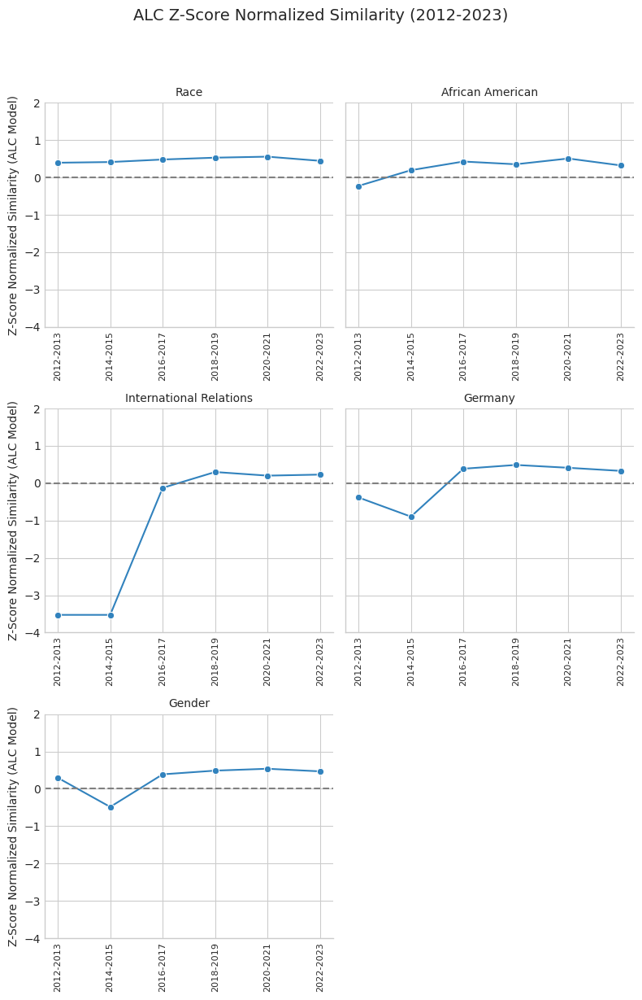

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_external_z_scores(z_score_pivot_data):
    """
    Plots the provided z_score pivot table data using Seaborn FacetGrid, 
    replicating the style of the multi-panel time series plot.
    
    The function handles parsing the input string data.
    """
    
    # 1. Convert string input into a DataFrame (parsing the pivot table output)
    data_lines = z_score_pivot_data.strip().split('\n')
    
    # Locate the header line (starts with 'period') and subsequent data lines
    header_index = next(i for i, line in enumerate(data_lines) if line.startswith('period'))
    header = data_lines[header_index].split()[1:] # Exclude the 'period' word itself
    data_lines = data_lines[header_index + 1:]
    
    data = []
    for line in data_lines:
        parts = line.split()
        if len(parts) > 0:
            # Assuming the first part is the category name, the rest are values
            category = parts[0]
            # Strip non-numeric/non-alpha chars from category name if present (due to print formatting quirks)
            category = category.strip()
            
            # Ensure we only try to parse as float if there are enough values
            if len(parts) - 1 == len(header):
                try:
                    values = [float(v) for v in parts[1:]]
                    data.append([category] + values)
                except ValueError:
                    print(f"Skipping line due to invalid data format: {line}")
            else:
                print(f"Skipping line: column count mismatch for line: {line}")

    if not data:
        print("Error: No valid data found after parsing the Z-score input.")
        return
        
    df_plot = pd.DataFrame(data, columns=['category'] + header)
    
    # Melt the DataFrame to long format (required for Seaborn line plots)
    similarity_df_long = df_plot.melt(
        id_vars='category', 
        value_vars=header, 
        var_name='period', 
        value_name='z_score'
    )
    
    # 2. Add plotting metadata
    
    # Set up Category mapping for cleaner facet labels
    category_map = {
        'race': 'Race',
        'african_american': 'African American',
        'treaty': 'International Relations',
        'german': 'Germany',
        'gender': 'Gender'
    }
    similarity_df_long['Category_Label'] = similarity_df_long['category'].map(category_map)
    
    # Get the order of the periods from the header for x-axis consistency
    period_labels_ordered = header 
    period_pos = {label: i for i, label in enumerate(period_labels_ordered)}
    similarity_df_long['period_numeric'] = similarity_df_long['period'].map(period_pos)

    # 3. Plotting using FacetGrid
    plt.style.use('seaborn-v0_8-whitegrid')
    
    # Define the order of facets to match the typical academic layout
    facet_order = ['Race', 'African American', 'International Relations', 'Germany', 'Gender']
    
    # Create the faceted plot
    g = sns.FacetGrid(
        similarity_df_long, 
        col="Category_Label", 
        col_wrap=2, 
        height=4, 
        sharey=True, 
        sharex=False,
        col_order=facet_order
    )
    
    # Map the line plot onto the FacetGrid
    g.map(
        sns.lineplot, 
        "period_numeric", 
        "z_score", 
        marker="o", 
        color="#3182bd", 
        dashes=False 
    )
    
    # 4. Customize the plot
    g.set_titles(col_template="{col_name}")
    g.set_axis_labels("", "Z-Score Normalized Similarity (ALC Model)")
    
    # Set x-axis labels to the period strings and rotate them
    for ax in g.axes.flat:
        ax.set_xticks(list(period_pos.values()))
        ax.set_xticklabels(period_labels_ordered, rotation=90, fontsize=8)
        ax.axhline(0, color='gray', linestyle='--') # Add baseline at 0
        ax.set_ylim(-4, 2) # Adjusted limits for the provided data range
        
    g.fig.suptitle("ALC Z-Score Normalized Similarity (2012-2023)", y=1.02, fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

# --- Example Usage (Requires Matplotlib/Seaborn environment) ---
USER_Z_SCORE_DATA = """
period 2012-2013 2014-2015 2016-2017 2018-2019 2020-2021 2022-2023
category
african_american -0.225593 0.195686 0.427499 0.354457 0.508861 0.323833
gender 0.296897 -0.483527 0.388595 0.487649 0.537985 0.468165
german -0.381973 -0.895450 0.386465 0.488014 0.412361 0.328745
race 0.395686 0.414081 0.481893 0.531189 0.557936 0.446345
treaty -3.525213 -3.525213 -0.125846 0.298898 0.201717 0.229858
"""

if __name__ == '__main__':
    plot_external_z_scores(USER_Z_SCORE_DATA)

In [3]:
import io, zipfile, requests, os
import re, math, json
import numpy as np
import pandas as pd
from collections import defaultdict
from numpy.linalg import norm
from sklearn.metrics.pairwise import cosine_similarity
import torch
from transformers import RobertaTokenizer, RobertaModel

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------
CSV_PATH = "US_vs_them_llama_labeled_data_final.csv"
GLOVE_URL = "https://nlp.stanford.edu/data/glove.6B.zip"
GLOVE_DIR = "embeddings"
GLOVE_FILE = os.path.join(GLOVE_DIR, "glove.6B.300d.txt")
DIM = 300

# --- Embedding Selection ---
# Options: 'glove', 'roberta', 'both'
EMBEDDING_TYPE = 'both'

# --- ALC Configuration ---
FOCAL_WORDS = ["equality", "gender", "treaty", "german", "race", "african_american"]
CATEGORY_WORDS = [w for w in FOCAL_WORDS if w != "equality"]
WINDOW_SIZE = 6
TOP_N_NEIGHBORS = 10 

# --- A_HAT Matrix Path ---
A_MATRIX_PATH = None  # Set to None for identity matrix (untransformed)

# --- Time Period Configuration ---
START_YEAR = 2012
END_YEAR = 2022
DURATION = 2
period_bins = list(range(START_YEAR, END_YEAR + DURATION + 1, DURATION))
period_labels = [
    f"{period_bins[i]}-{period_bins[i+1]-1}" 
    for i in range(len(period_bins) - 1)
]

# ----------------------------------------------------------------------
# 1. DATA LOADING AND SETUP
# ----------------------------------------------------------------------

# --- GLOVE Loading ---
def download_and_load_glove():
    """Downloads GloVe vectors and loads them into a dictionary."""
    if not os.path.exists(GLOVE_FILE):
        print(f"Downloading GloVe from {GLOVE_URL}...")
        os.makedirs(GLOVE_DIR, exist_ok=True)
        try:
            zbytes = requests.get(GLOVE_URL).content
            with zipfile.ZipFile(io.BytesIO(zbytes)) as zf:
                zf.extract("glove.6B.300d.txt", path=GLOVE_DIR)
            print(f"Saved GloVe to {GLOVE_FILE}")
        except Exception as e:
            print(f"Error during download or extraction: {e}")
            return {}

    print(f"Loading GloVe embeddings ({DIM}d)...")
    glove_embeddings = {}
    with open(GLOVE_FILE, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) > DIM:
                word = parts[0]
                vector = np.array(parts[1:], dtype=np.float32)
                glove_embeddings[word] = vector
    print(f"Successfully loaded {len(glove_embeddings)} words.")
    return glove_embeddings

# --- RoBERTa Setup ---
class RoBERTaEmbedder:
    """Handles RoBERTa contextualized embeddings."""
    
    def __init__(self, model_name='roberta-base'):
        print(f"Loading RoBERTa model: {model_name}...")
        self.tokenizer = RobertaTokenizer.from_pretrained(model_name)
        self.model = RobertaModel.from_pretrained(model_name)
        self.model.eval()
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model.to(self.device)
        self.dim = self.model.config.hidden_size  # 768 for roberta-base
        print(f"RoBERTa loaded. Embedding dimension: {self.dim}")
    
    def get_word_embedding(self, text, focal_word):
        """
        Extracts contextualized embedding for a focal word in text.
        Averages subword embeddings if the word is tokenized into multiple tokens.
        """
        text = text.lower()
        focal_word = focal_word.lower()
        
        # Handle multi-word expressions
        if '_' in focal_word:
            focal_word_display = focal_word.replace('_', ' ')
        else:
            focal_word_display = focal_word
        
        # Tokenize
        inputs = self.tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
        inputs = {k: v.to(self.device) for k, v in inputs.items()}
        
        with torch.no_grad():
            outputs = self.model(**inputs)
            hidden_states = outputs.last_hidden_state[0]  # Shape: (seq_len, hidden_dim)
        
        # Find the focal word in the tokenized text
        tokens = self.tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
        
        # Search for the focal word (handling subword tokenization)
        focal_indices = []
        search_term = focal_word.replace('_', '')  # Remove underscore for matching
        
        i = 0
        while i < len(tokens):
            # Try to match the focal word starting at position i
            token_seq = ''.join(tokens[i:i+5]).replace('Ġ', '').replace('</s>', '').replace('<s>', '')
            if search_term in token_seq.lower():
                # Found it - collect all tokens that are part of this word
                j = i
                word_tokens = []
                while j < len(tokens) and search_term.startswith(''.join(word_tokens).replace('Ġ', '').lower()):
                    word_tokens.append(tokens[j].replace('Ġ', ''))
                    if search_term == ''.join(word_tokens).replace('Ġ', '').lower():
                        focal_indices.extend(range(i, j+1))
                        break
                    j += 1
                i = j + 1
            else:
                i += 1
        
        if focal_indices:
            # Average embeddings of all tokens that compose the focal word
            focal_embeddings = hidden_states[focal_indices]
            return focal_embeddings.mean(dim=0).cpu().numpy()
        else:
            return None
    
    def get_context_embedding(self, text, focal_word, window_size=6):
        """
        Extracts context word embeddings (excluding the focal word).
        Returns averaged embeddings of context words.
        """
        text = text.lower()
        
        # Handle MWEs
        if '_' in focal_word:
            mwe_phrase = focal_word.replace('_', ' ')
            text = text.replace(mwe_phrase, focal_word)
        
        # Tokenize and find context words
        tokens = re.sub(r'[^\w_]', ' ', text).split()
        focal_indices = [i for i, w in enumerate(tokens) if w == focal_word]
        
        context_words = set()
        for i in focal_indices:
            start = max(0, i - window_size)
            end = min(len(tokens), i + window_size + 1)
            context_words.update(tokens[start:i])
            context_words.update(tokens[i+1:end])
        
        # Get embeddings for each context word
        context_embeddings = []
        for word in context_words:
            # Create a simple sentence with the context word
            simple_text = f"The word {word} appears here."
            embedding = self.get_word_embedding(simple_text, word)
            if embedding is not None:
                context_embeddings.append(embedding)
        
        if context_embeddings:
            return np.mean(context_embeddings, axis=0)
        else:
            return None

# --- A_HAT Matrix Loading ---
def load_a_hat_matrix(path=None, dim=DIM):
    """Loads the ALC transformation matrix or returns Identity."""
    if path and os.path.exists(path):
        try:
            A_hat = np.load(path)
            if A_hat.shape == (dim, dim):
                print(f"Loaded A_hat matrix from {path}.")
                return A_hat
            else:
                print(f"Warning: Loaded A_hat shape {A_hat.shape} != expected ({dim}, {dim}). Using Identity.")
        except Exception as e:
            print(f"Error loading A_hat from {path}: {e}. Using Identity.")
    
    print(f"Using Identity Matrix for A_hat (untransformed ALC/CVA).")
    return np.eye(dim)

# Load data and resources
try:
    df = pd.read_csv(CSV_PATH)
except FileNotFoundError:
    print(f"Error: CSV file not found at {CSV_PATH}. Please check the path.")
    exit()

GLOVE_EMBEDDINGS = {}
ROBERTA_EMBEDDER = None

if EMBEDDING_TYPE in ['glove', 'both']:
    GLOVE_EMBEDDINGS = download_and_load_glove()
    if not GLOVE_EMBEDDINGS:
        print("Warning: GloVe embeddings not loaded.")

if EMBEDDING_TYPE in ['roberta', 'both']:
    ROBERTA_EMBEDDER = RoBERTaEmbedder()

A_HAT_MATRIX_GLOVE = load_a_hat_matrix(A_MATRIX_PATH, DIM)
if ROBERTA_EMBEDDER:
    A_HAT_MATRIX_ROBERTA = load_a_hat_matrix(None, ROBERTA_EMBEDDER.dim)  # Identity for RoBERTa

# ----------------------------------------------------------------------
# 2. CORE ALC FUNCTIONS
# ----------------------------------------------------------------------

def get_context_words(text, focal_word, window_size=6):
    """Extracts context words for a focal word."""
    text = text.lower()
    
    # Handle MWEs
    mwe_text = text
    if '_' in focal_word:
        mwe_phrase = focal_word.replace('_', ' ')
        mwe_text = mwe_text.replace(mwe_phrase, focal_word)
    
    tokens = re.sub(r'[^\w_]', ' ', mwe_text).split()
    focal_indices = [i for i, w in enumerate(tokens) if w == focal_word]
    
    context = set()
    for i in focal_indices:
        start = max(0, i - window_size)
        end = min(len(tokens), i + window_size + 1)
        context.update(tokens[start:i])
        context.update(tokens[i+1:end])
        
    return list(context)

def alc_embedding_glove(texts, focal_word, window_size=6):
    """Computes ALC embedding using GloVe."""
    context_vectors = []
    
    for text in texts:
        context_words = get_context_words(text, focal_word, window_size)
        vectors = [GLOVE_EMBEDDINGS[w] for w in context_words if w in GLOVE_EMBEDDINGS]
        
        if vectors:
            u_w_avg = np.mean(vectors, axis=0)
            v_alc = np.dot(A_HAT_MATRIX_GLOVE, u_w_avg)
            context_vectors.append(v_alc)

    if context_vectors:
        return np.mean(context_vectors, axis=0)
    else:
        return np.zeros(DIM, dtype=np.float32)

def alc_embedding_roberta(texts, focal_word, window_size=6):
    """Computes ALC embedding using RoBERTa."""
    context_vectors = []
    
    for text in texts:
        embedding = ROBERTA_EMBEDDER.get_context_embedding(text, focal_word, window_size)
        if embedding is not None:
            v_alc = np.dot(A_HAT_MATRIX_ROBERTA, embedding)
            context_vectors.append(v_alc)
    
    if context_vectors:
        return np.mean(context_vectors, axis=0)
    else:
        return np.zeros(ROBERTA_EMBEDDER.dim, dtype=np.float32)

def calculate_similarities_and_zscores(alc_vectors, method_name):
    """Calculate similarities and z-scores for a given embedding method."""
    all_similarities = []
    results_list = []
    
    print(f"\n--- Calculating Cosine Similarities ({method_name}) ---")
    for period in period_labels:
        v_equality = alc_vectors[period].get("equality")
        
        if v_equality is None or np.all(v_equality == 0):
            print(f"Warning: 'equality' vector is zero/missing in {period} ({method_name}).")
            continue
            
        for category in CATEGORY_WORDS:
            v_category = alc_vectors[period].get(category)
            
            if np.all(v_category == 0):
                similarity = 0.0
            else:
                similarity = cosine_similarity(v_equality.reshape(1, -1), v_category.reshape(1, -1))[0][0]
            
            results_list.append({
                'period': period,
                'category': category,
                'similarity': similarity
            })
            all_similarities.append(similarity)

    # Z-Score Normalization
    similarity_df = pd.DataFrame(results_list)
    
    if all_similarities:
        mean_sim = np.mean(all_similarities)
        std_sim = np.std(all_similarities)
        
        if std_sim > 0:
            similarity_df['z_score'] = (similarity_df['similarity'] - mean_sim) / std_sim
        else:
            similarity_df['z_score'] = 0.0
    else:
        similarity_df['z_score'] = np.nan
    
    return similarity_df

# ----------------------------------------------------------------------
# 3. RUN ANALYSIS
# ----------------------------------------------------------------------

df['period'] = pd.cut(df['year'], bins=period_bins, labels=period_labels, right=False)

# Storage for both embedding types
alc_vectors_glove = defaultdict(dict)
alc_vectors_roberta = defaultdict(dict)

print("\n" + "="*70)
print("--- Starting ALC Vector Computation ---")
print("="*70)

for period in period_labels:
    period_texts = df[df['period'] == period]['pure_text'].tolist()
    
    if not period_texts:
         print(f"Skipping {period}: No data in this time slice.")
         continue

    print(f"\nProcessing period: {period} ({len(period_texts)} texts)")
    
    for word in FOCAL_WORDS:
        if EMBEDDING_TYPE in ['glove', 'both']:
            vector_glove = alc_embedding_glove(period_texts, word, WINDOW_SIZE)
            alc_vectors_glove[period][word] = vector_glove
        
        if EMBEDDING_TYPE in ['roberta', 'both']:
            print(f"  Computing RoBERTa embedding for '{word}'...")
            vector_roberta = alc_embedding_roberta(period_texts, word, WINDOW_SIZE)
            alc_vectors_roberta[period][word] = vector_roberta

# Calculate and display results for each embedding type
if EMBEDDING_TYPE in ['glove', 'both']:
    print("\n" + "="*70)
    print("--- GLOVE RESULTS ---")
    print("="*70)
    
    similarity_df_glove = calculate_similarities_and_zscores(alc_vectors_glove, "GloVe")
    z_score_pivot_glove = similarity_df_glove.pivot(index='category', columns='period', values='z_score')
    
    print("\nGloVe Z-Scores:")
    print(z_score_pivot_glove)

if EMBEDDING_TYPE in ['roberta', 'both']:
    print("\n" + "="*70)
    print("--- ROBERTA RESULTS ---")
    print("="*70)
    
    similarity_df_roberta = calculate_similarities_and_zscores(alc_vectors_roberta, "RoBERTa")
    z_score_pivot_roberta = similarity_df_roberta.pivot(index='category', columns='period', values='z_score')
    
    print("\nRoBERTa Z-Scores:")
    print(z_score_pivot_roberta)

# Comparison if both methods are used
if EMBEDDING_TYPE == 'both':
    print("\n" + "="*70)
    print("--- COMPARISON: GloVe vs RoBERTa ---")
    print("="*70)
    
    # Merge the two dataframes for comparison
    comparison_df = similarity_df_glove.merge(
        similarity_df_roberta, 
        on=['period', 'category'], 
        suffixes=('_glove', '_roberta')
    )
    
    # Calculate correlation
    correlation = comparison_df['z_score_glove'].corr(comparison_df['z_score_roberta'])
    print(f"\nCorrelation between GloVe and RoBERTa z-scores: {correlation:.4f}")
    
    # Show side-by-side comparison
    print("\nSide-by-side Z-Score Comparison:")
    print(comparison_df[['period', 'category', 'z_score_glove', 'z_score_roberta']].to_string(index=False))

print("\n" + "="*70)
print("Analysis Complete!")
print("="*70)

Loading GloVe embeddings (300d)...
Successfully loaded 400000 words.
Loading RoBERTa model: roberta-base...


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


RoBERTa loaded. Embedding dimension: 768
Using Identity Matrix for A_hat (untransformed ALC/CVA).
Using Identity Matrix for A_hat (untransformed ALC/CVA).

--- Starting ALC Vector Computation ---

Processing period: 2012-2013 (3321 texts)
  Computing RoBERTa embedding for 'equality'...
  Computing RoBERTa embedding for 'gender'...
  Computing RoBERTa embedding for 'treaty'...
  Computing RoBERTa embedding for 'german'...
  Computing RoBERTa embedding for 'race'...
  Computing RoBERTa embedding for 'african_american'...

Processing period: 2014-2015 (6340 texts)
  Computing RoBERTa embedding for 'equality'...
  Computing RoBERTa embedding for 'gender'...
  Computing RoBERTa embedding for 'treaty'...
  Computing RoBERTa embedding for 'german'...
  Computing RoBERTa embedding for 'race'...
  Computing RoBERTa embedding for 'african_american'...

Processing period: 2016-2017 (23940 texts)
  Computing RoBERTa embedding for 'equality'...
  Computing RoBERTa embedding for 'gender'...
  Comput

Skipping line: column count mismatch for line: category                                                                  


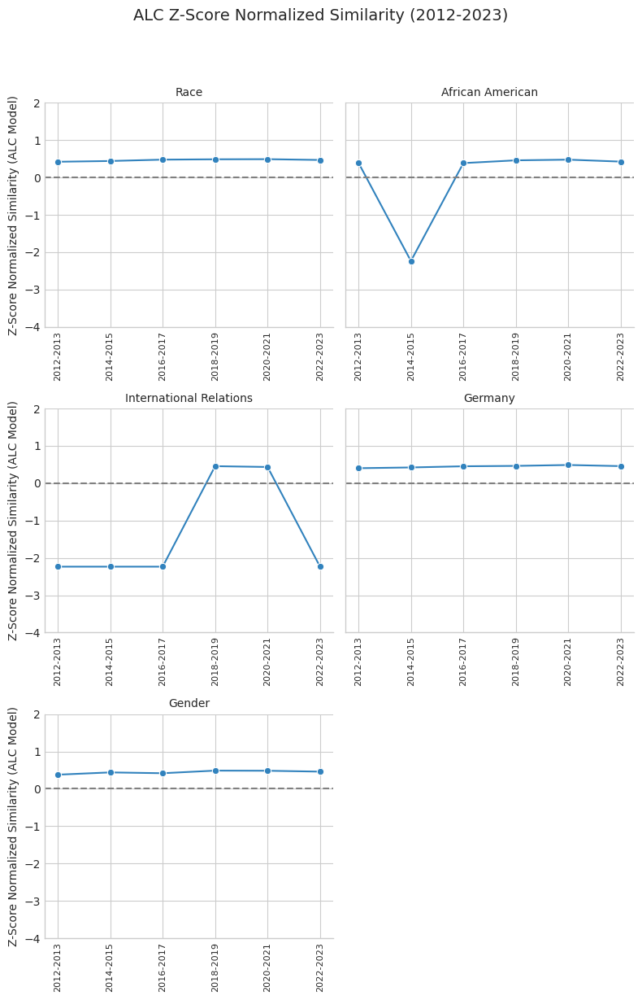

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_external_z_scores(z_score_pivot_data):
    """
    Plots the provided z_score pivot table data using Seaborn FacetGrid, 
    replicating the style of the multi-panel time series plot.
    
    The function handles parsing the input string data.
    """
    
    # 1. Convert string input into a DataFrame (parsing the pivot table output)
    data_lines = z_score_pivot_data.strip().split('\n')
    
    # Locate the header line (starts with 'period') and subsequent data lines
    header_index = next(i for i, line in enumerate(data_lines) if line.startswith('period'))
    header = data_lines[header_index].split()[1:] # Exclude the 'period' word itself
    data_lines = data_lines[header_index + 1:]
    
    data = []
    for line in data_lines:
        parts = line.split()
        if len(parts) > 0:
            # Assuming the first part is the category name, the rest are values
            category = parts[0]
            # Strip non-numeric/non-alpha chars from category name if present (due to print formatting quirks)
            category = category.strip()
            
            # Ensure we only try to parse as float if there are enough values
            if len(parts) - 1 == len(header):
                try:
                    values = [float(v) for v in parts[1:]]
                    data.append([category] + values)
                except ValueError:
                    print(f"Skipping line due to invalid data format: {line}")
            else:
                print(f"Skipping line: column count mismatch for line: {line}")

    if not data:
        print("Error: No valid data found after parsing the Z-score input.")
        return
        
    df_plot = pd.DataFrame(data, columns=['category'] + header)
    
    # Melt the DataFrame to long format (required for Seaborn line plots)
    similarity_df_long = df_plot.melt(
        id_vars='category', 
        value_vars=header, 
        var_name='period', 
        value_name='z_score'
    )
    
    # 2. Add plotting metadata
    
    # Set up Category mapping for cleaner facet labels
    category_map = {
        'race': 'Race',
        'african_american': 'African American',
        'treaty': 'International Relations',
        'german': 'Germany',
        'gender': 'Gender'
    }
    similarity_df_long['Category_Label'] = similarity_df_long['category'].map(category_map)
    
    # Get the order of the periods from the header for x-axis consistency
    period_labels_ordered = header 
    period_pos = {label: i for i, label in enumerate(period_labels_ordered)}
    similarity_df_long['period_numeric'] = similarity_df_long['period'].map(period_pos)

    # 3. Plotting using FacetGrid
    plt.style.use('seaborn-v0_8-whitegrid')
    
    # Define the order of facets to match the typical academic layout
    facet_order = ['Race', 'African American', 'International Relations', 'Germany', 'Gender']
    
    # Create the faceted plot
    g = sns.FacetGrid(
        similarity_df_long, 
        col="Category_Label", 
        col_wrap=2, 
        height=4, 
        sharey=True, 
        sharex=False,
        col_order=facet_order
    )
    
    # Map the line plot onto the FacetGrid
    g.map(
        sns.lineplot, 
        "period_numeric", 
        "z_score", 
        marker="o", 
        color="#3182bd", 
        dashes=False 
    )
    
    # 4. Customize the plot
    g.set_titles(col_template="{col_name}")
    g.set_axis_labels("", "Z-Score Normalized Similarity (ALC Model)")
    
    # Set x-axis labels to the period strings and rotate them
    for ax in g.axes.flat:
        ax.set_xticks(list(period_pos.values()))
        ax.set_xticklabels(period_labels_ordered, rotation=90, fontsize=8)
        ax.axhline(0, color='gray', linestyle='--') # Add baseline at 0
        ax.set_ylim(-4, 2) # Adjusted limits for the provided data range
        
    g.fig.suptitle("ALC Z-Score Normalized Similarity (2012-2023)", y=1.02, fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()


USER_Z_SCORE_DATA = """
period            2012-2013  2014-2015  2016-2017  2018-2019  2020-2021  2022-2023
category                                                                  
african_american   0.394618  -2.235044   0.386055   0.459730   0.478177   0.425517  
gender             0.379671   0.440081   0.418199   0.487892   0.484562   0.460886  
german             0.401180   0.420997   0.452462   0.462739   0.486974   0.456664  
race               0.421730   0.441694   0.478496   0.487464   0.490691   0.469803  
treaty            -2.235044  -2.235044  -2.235044   0.455438   0.433502   -2.235044
"""

if __name__ == '__main__':
    plot_external_z_scores(USER_Z_SCORE_DATA)

In [8]:
import io, zipfile, requests, os
import re, math, json
import numpy as np
import pandas as pd
from collections import defaultdict
from numpy.linalg import norm
from sklearn.metrics.pairwise import cosine_similarity
import torch
from transformers import RobertaTokenizer, RobertaModel

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------
CSV_PATH = "US_vs_them_llama_labeled_data_final.csv"
GLOVE_URL = "https://nlp.stanford.edu/data/glove.6B.zip"
GLOVE_DIR = "embeddings"
GLOVE_FILE = os.path.join(GLOVE_DIR, "glove.6B.300d.txt")
DIM = 300

# --- Embedding Selection ---
# Options: 'glove', 'roberta', 'both'
EMBEDDING_TYPE = 'both'

# --- ALC Configuration ---
FOCAL_WORDS = ["equality", "gender", "treaty", "german", "race", "african_american"]
CATEGORY_WORDS = [w for w in FOCAL_WORDS if w != "equality"]
WINDOW_SIZE = 6
TOP_N_NEIGHBORS = 10 

# --- A_HAT Matrix Path ---
A_MATRIX_PATH = None  # Set to None for identity matrix (untransformed)

# --- Time Period Configuration ---
START_YEAR = 2012
END_YEAR = 2022
DURATION = 2
period_bins = list(range(START_YEAR, END_YEAR + DURATION + 1, DURATION))
period_labels = [
    f"{period_bins[i]}-{period_bins[i+1]-1}" 
    for i in range(len(period_bins) - 1)
]

# ----------------------------------------------------------------------
# 1. DATA LOADING AND SETUP
# ----------------------------------------------------------------------

# --- GLOVE Loading ---
def download_and_load_glove():
    """Downloads GloVe vectors and loads them into a dictionary."""
    if not os.path.exists(GLOVE_FILE):
        print(f"Downloading GloVe from {GLOVE_URL}...")
        os.makedirs(GLOVE_DIR, exist_ok=True)
        try:
            zbytes = requests.get(GLOVE_URL).content
            with zipfile.ZipFile(io.BytesIO(zbytes)) as zf:
                zf.extract("glove.6B.300d.txt", path=GLOVE_DIR)
            print(f"Saved GloVe to {GLOVE_FILE}")
        except Exception as e:
            print(f"Error during download or extraction: {e}")
            return {}

    print(f"Loading GloVe embeddings ({DIM}d)...")
    glove_embeddings = {}
    with open(GLOVE_FILE, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) > DIM:
                word = parts[0]
                vector = np.array(parts[1:], dtype=np.float32)
                glove_embeddings[word] = vector
    print(f"Successfully loaded {len(glove_embeddings)} words.")
    return glove_embeddings

# --- RoBERTa Setup ---
class RoBERTaEmbedder:
    """Handles RoBERTa contextualized embeddings."""
    
    def __init__(self, model_name='roberta-base'):
        print(f"Loading RoBERTa model: {model_name}...")
        self.tokenizer = RobertaTokenizer.from_pretrained(model_name)
        self.model = RobertaModel.from_pretrained(model_name)
        self.model.eval()
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model.to(self.device)
        self.dim = self.model.config.hidden_size  # 768 for roberta-base
        print(f"RoBERTa loaded. Embedding dimension: {self.dim}")
    
    def get_word_embedding(self, text, focal_word):
        """
        Extracts contextualized embedding for a focal word in text.
        Averages subword embeddings if the word is tokenized into multiple tokens.
        """
        text = text.lower()
        focal_word = focal_word.lower()
        
        # Handle multi-word expressions
        if '_' in focal_word:
            focal_word_display = focal_word.replace('_', ' ')
        else:
            focal_word_display = focal_word
        
        # Tokenize
        inputs = self.tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
        inputs = {k: v.to(self.device) for k, v in inputs.items()}
        
        with torch.no_grad():
            outputs = self.model(**inputs)
            hidden_states = outputs.last_hidden_state[0]  # Shape: (seq_len, hidden_dim)
        
        # Find the focal word in the tokenized text
        tokens = self.tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
        
        # Search for the focal word (handling subword tokenization)
        focal_indices = []
        search_term = focal_word.replace('_', '')  # Remove underscore for matching
        
        i = 0
        while i < len(tokens):
            # Try to match the focal word starting at position i
            token_seq = ''.join(tokens[i:i+5]).replace('Ġ', '').replace('</s>', '').replace('<s>', '')
            if search_term in token_seq.lower():
                # Found it - collect all tokens that are part of this word
                j = i
                word_tokens = []
                while j < len(tokens) and search_term.startswith(''.join(word_tokens).replace('Ġ', '').lower()):
                    word_tokens.append(tokens[j].replace('Ġ', ''))
                    if search_term == ''.join(word_tokens).replace('Ġ', '').lower():
                        focal_indices.extend(range(i, j+1))
                        break
                    j += 1
                i = j + 1
            else:
                i += 1
        
        if focal_indices:
            # Average embeddings of all tokens that compose the focal word
            focal_embeddings = hidden_states[focal_indices]
            return focal_embeddings.mean(dim=0).cpu().numpy()
        else:
            return None
    
    def get_context_embedding(self, text, focal_word, window_size=6):
        """
        Extracts context word embeddings (excluding the focal word).
        Returns averaged embeddings of context words.
        """
        text = text.lower()
        
        # Handle MWEs
        if '_' in focal_word:
            mwe_phrase = focal_word.replace('_', ' ')
            text = text.replace(mwe_phrase, focal_word)
        
        # Tokenize and find context words
        tokens = re.sub(r'[^\w_]', ' ', text).split()
        focal_indices = [i for i, w in enumerate(tokens) if w == focal_word]
        
        context_words = set()
        for i in focal_indices:
            start = max(0, i - window_size)
            end = min(len(tokens), i + window_size + 1)
            context_words.update(tokens[start:i])
            context_words.update(tokens[i+1:end])
        
        # Get embeddings for each context word
        context_embeddings = []
        for word in context_words:
            # Create a simple sentence with the context word
            simple_text = f"The word {word} appears here."
            embedding = self.get_word_embedding(simple_text, word)
            if embedding is not None:
                context_embeddings.append(embedding)
        
        if context_embeddings:
            return np.mean(context_embeddings, axis=0)
        else:
            return None

# --- A_HAT Matrix Loading ---
def load_a_hat_matrix(path=None, dim=DIM):
    """Loads the ALC transformation matrix or returns Identity."""
    if path and os.path.exists(path):
        try:
            A_hat = np.load(path)
            if A_hat.shape == (dim, dim):
                print(f"Loaded A_hat matrix from {path}.")
                return A_hat
            else:
                print(f"Warning: Loaded A_hat shape {A_hat.shape} != expected ({dim}, {dim}). Using Identity.")
        except Exception as e:
            print(f"Error loading A_hat from {path}: {e}. Using Identity.")
    
    print(f"Using Identity Matrix for A_hat (untransformed ALC/CVA).")
    return np.eye(dim)

# Load data and resources
try:
    df = pd.read_csv(CSV_PATH)
except FileNotFoundError:
    print(f"Error: CSV file not found at {CSV_PATH}. Please check the path.")
    exit()

GLOVE_EMBEDDINGS = {}
ROBERTA_EMBEDDER = None

if EMBEDDING_TYPE in ['glove', 'both']:
    GLOVE_EMBEDDINGS = download_and_load_glove()
    if not GLOVE_EMBEDDINGS:
        print("Warning: GloVe embeddings not loaded.")

if EMBEDDING_TYPE in ['roberta', 'both']:
    ROBERTA_EMBEDDER = RoBERTaEmbedder()

A_HAT_MATRIX_GLOVE = load_a_hat_matrix(A_MATRIX_PATH, DIM)
if ROBERTA_EMBEDDER:
    A_HAT_MATRIX_ROBERTA = load_a_hat_matrix(None, ROBERTA_EMBEDDER.dim)  # Identity for RoBERTa

# ----------------------------------------------------------------------
# 2. CORE ALC FUNCTIONS
# ----------------------------------------------------------------------

def get_context_words(text, focal_word, window_size=6):
    """Extracts context words for a focal word."""
    text = text.lower()
    
    # Handle MWEs
    mwe_text = text
    if '_' in focal_word:
        mwe_phrase = focal_word.replace('_', ' ')
        mwe_text = mwe_text.replace(mwe_phrase, focal_word)
    
    tokens = re.sub(r'[^\w_]', ' ', mwe_text).split()
    focal_indices = [i for i, w in enumerate(tokens) if w == focal_word]
    
    context = set()
    for i in focal_indices:
        start = max(0, i - window_size)
        end = min(len(tokens), i + window_size + 1)
        context.update(tokens[start:i])
        context.update(tokens[i+1:end])
        
    return list(context)

def alc_embedding_glove(texts, focal_word, window_size=6):
    """Computes ALC embedding using GloVe."""
    context_vectors = []
    
    for text in texts:
        context_words = get_context_words(text, focal_word, window_size)
        vectors = [GLOVE_EMBEDDINGS[w] for w in context_words if w in GLOVE_EMBEDDINGS]
        
        if vectors:
            u_w_avg = np.mean(vectors, axis=0)
            v_alc = np.dot(A_HAT_MATRIX_GLOVE, u_w_avg)
            context_vectors.append(v_alc)

    if context_vectors:
        return np.mean(context_vectors, axis=0)
    else:
        return np.zeros(DIM, dtype=np.float32)

def alc_embedding_roberta(texts, focal_word, window_size=6):
    """Computes ALC embedding using RoBERTa."""
    context_vectors = []
    
    for text in texts:
        embedding = ROBERTA_EMBEDDER.get_context_embedding(text, focal_word, window_size)
        if embedding is not None:
            v_alc = np.dot(A_HAT_MATRIX_ROBERTA, embedding)
            context_vectors.append(v_alc)
    
    if context_vectors:
        return np.mean(context_vectors, axis=0)
    else:
        return np.zeros(ROBERTA_EMBEDDER.dim, dtype=np.float32)

def get_nearest_neighbors_glove(focal_word, period_vectors, top_n=10):
    """Finds nearest neighbors in GloVe embedding space."""
    v_alc = period_vectors.get(focal_word)
    
    if v_alc is None or np.all(v_alc == 0):
        return [f"No data for '{focal_word}' in this period."]
        
    glove_words = list(GLOVE_EMBEDDINGS.keys())
    glove_vectors = np.array(list(GLOVE_EMBEDDINGS.values()))
    
    similarities = cosine_similarity(v_alc.reshape(1, -1), glove_vectors)[0]
    similarity_series = pd.Series(similarities, index=glove_words)
    similarity_series = similarity_series.drop(focal_word, errors='ignore')
    
    return similarity_series.nlargest(top_n).index.tolist()

def get_nearest_neighbors_roberta(focal_word, period_vectors, roberta_vocab, top_n=10):
    """Finds nearest neighbors in RoBERTa embedding space."""
    v_alc = period_vectors.get(focal_word)
    
    if v_alc is None or np.all(v_alc == 0):
        return [f"No data for '{focal_word}' in this period."]
    
    # Get RoBERTa embeddings for vocabulary words
    vocab_words = list(roberta_vocab.keys())
    vocab_vectors = np.array(list(roberta_vocab.values()))
    
    similarities = cosine_similarity(v_alc.reshape(1, -1), vocab_vectors)[0]
    similarity_series = pd.Series(similarities, index=vocab_words)
    
    # Remove the focal word if present
    focal_word_normalized = focal_word.replace('_', ' ')
    similarity_series = similarity_series.drop([focal_word, focal_word_normalized], errors='ignore')
    
    return similarity_series.nlargest(top_n).index.tolist()

def build_roberta_vocabulary(texts, max_vocab=50000):
    """
    Builds a vocabulary from the corpus for RoBERTa nearest neighbor search.
    Extracts embeddings for frequent words.
    """
    print(f"Building RoBERTa vocabulary from corpus...")
    
    # Extract word frequencies
    word_freq = defaultdict(int)
    for text in texts:
        text = text.lower()
        tokens = re.sub(r'[^\w_]', ' ', text).split()
        for token in tokens:
            word_freq[token] += 1
    
    # Get most frequent words
    sorted_words = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)[:max_vocab]
    vocab_words = [word for word, freq in sorted_words]
    
    print(f"Extracting RoBERTa embeddings for {len(vocab_words)} vocabulary words...")
    
    roberta_vocab = {}
    batch_size = 100
    
    for i in range(0, len(vocab_words), batch_size):
        batch = vocab_words[i:i+batch_size]
        for word in batch:
            # Create simple context for the word
            context_text = f"The word {word.replace('_', ' ')} appears here."
            embedding = ROBERTA_EMBEDDER.get_word_embedding(context_text, word)
            if embedding is not None:
                roberta_vocab[word] = embedding
        
        if (i // batch_size + 1) % 10 == 0:
            print(f"  Processed {i + len(batch)}/{len(vocab_words)} words...")
    
    print(f"RoBERTa vocabulary built: {len(roberta_vocab)} words with embeddings.")
    return roberta_vocab

def calculate_similarities_and_zscores(alc_vectors, method_name):
    """Calculate similarities and z-scores for a given embedding method."""
    all_similarities = []
    results_list = []
    
    print(f"\n--- Calculating Cosine Similarities ({method_name}) ---")
    for period in period_labels:
        v_equality = alc_vectors[period].get("equality")
        
        if v_equality is None or np.all(v_equality == 0):
            print(f"Warning: 'equality' vector is zero/missing in {period} ({method_name}).")
            continue
            
        for category in CATEGORY_WORDS:
            v_category = alc_vectors[period].get(category)
            
            if np.all(v_category == 0):
                similarity = 0.0
            else:
                similarity = cosine_similarity(v_equality.reshape(1, -1), v_category.reshape(1, -1))[0][0]
            
            results_list.append({
                'period': period,
                'category': category,
                'similarity': similarity
            })
            all_similarities.append(similarity)

    # Z-Score Normalization
    similarity_df = pd.DataFrame(results_list)
    
    if all_similarities:
        mean_sim = np.mean(all_similarities)
        std_sim = np.std(all_similarities)
        
        if std_sim > 0:
            similarity_df['z_score'] = (similarity_df['similarity'] - mean_sim) / std_sim
        else:
            similarity_df['z_score'] = 0.0
    else:
        similarity_df['z_score'] = np.nan
    
    return similarity_df

# ----------------------------------------------------------------------
# 3. RUN ANALYSIS
# ----------------------------------------------------------------------

df['period'] = pd.cut(df['year'], bins=period_bins, labels=period_labels, right=False)

# Storage for both embedding types
alc_vectors_glove = defaultdict(dict)
alc_vectors_roberta = defaultdict(dict)

# Build RoBERTa vocabulary if needed
roberta_vocab = None
if EMBEDDING_TYPE in ['roberta', 'both']:
    all_texts = df['pure_text'].tolist()
    roberta_vocab = build_roberta_vocabulary(all_texts, max_vocab=50000)

print("\n" + "="*70)
print("--- Starting ALC Vector Computation ---")
print("="*70)

for period in period_labels:
    period_texts = df[df['period'] == period]['pure_text'].tolist()
    
    if not period_texts:
         print(f"Skipping {period}: No data in this time slice.")
         continue

    print(f"\nProcessing period: {period} ({len(period_texts)} texts)")
    
    for word in FOCAL_WORDS:
        if EMBEDDING_TYPE in ['glove', 'both']:
            vector_glove = alc_embedding_glove(period_texts, word, WINDOW_SIZE)
            alc_vectors_glove[period][word] = vector_glove
        
        if EMBEDDING_TYPE in ['roberta', 'both']:
            print(f"  Computing RoBERTa embedding for '{word}'...")
            vector_roberta = alc_embedding_roberta(period_texts, word, WINDOW_SIZE)
            alc_vectors_roberta[period][word] = vector_roberta

# Calculate and display results for each embedding type
if EMBEDDING_TYPE in ['glove', 'both']:
    print("\n" + "="*70)
    print("--- GLOVE RESULTS ---")
    print("="*70)
    
    similarity_df_glove = calculate_similarities_and_zscores(alc_vectors_glove, "GloVe")
    z_score_pivot_glove = similarity_df_glove.pivot(index='category', columns='period', values='z_score')
    
    print("\nGloVe Z-Scores:")
    print(z_score_pivot_glove)
    
    # Nearest Neighbors for GloVe
    print("\n" + "="*70)
    print("--- GloVe Nearest Neighbors ---")
    print("="*70)
    
    neighbors_data_glove = []
    for period in period_labels:
        period_vectors = alc_vectors_glove[period]
        for word in FOCAL_WORDS:
            neighbors = get_nearest_neighbors_glove(word, period_vectors, TOP_N_NEIGHBORS)
            neighbors_data_glove.append({
                'Period': period,
                'Word': word,
                'Nearest Neighbors': ', '.join(neighbors)
            })
    
    neighbors_df_glove = pd.DataFrame(neighbors_data_glove)
    pivot_neighbors_glove = neighbors_df_glove.pivot_table(
        index='Word', columns='Period', values='Nearest Neighbors', aggfunc=lambda x: x
    )
    print(pivot_neighbors_glove)

if EMBEDDING_TYPE in ['roberta', 'both']:
    print("\n" + "="*70)
    print("--- ROBERTA RESULTS ---")
    print("="*70)
    
    similarity_df_roberta = calculate_similarities_and_zscores(alc_vectors_roberta, "RoBERTa")
    z_score_pivot_roberta = similarity_df_roberta.pivot(index='category', columns='period', values='z_score')
    
    print("\nRoBERTa Z-Scores:")
    print(z_score_pivot_roberta)
    
    # Nearest Neighbors for RoBERTa
    print("\n" + "="*70)
    print("--- RoBERTa Nearest Neighbors ---")
    print("="*70)
    
    neighbors_data_roberta = []
    for period in period_labels:
        period_vectors = alc_vectors_roberta[period]
        for word in FOCAL_WORDS:
            neighbors = get_nearest_neighbors_roberta(word, period_vectors, roberta_vocab, TOP_N_NEIGHBORS)
            neighbors_data_roberta.append({
                'Period': period,
                'Word': word,
                'Nearest Neighbors': ', '.join(neighbors)
            })
    
    neighbors_df_roberta = pd.DataFrame(neighbors_data_roberta)
    pivot_neighbors_roberta = neighbors_df_roberta.pivot_table(
        index='Word', columns='Period', values='Nearest Neighbors', aggfunc=lambda x: x
    )
    print(pivot_neighbors_roberta)

# Comparison if both methods are used
if EMBEDDING_TYPE == 'both':
    print("\n" + "="*70)
    print("--- COMPARISON: GloVe vs RoBERTa ---")
    print("="*70)
    
    # Merge the two dataframes for comparison
    comparison_df = similarity_df_glove.merge(
        similarity_df_roberta, 
        on=['period', 'category'], 
        suffixes=('_glove', '_roberta')
    )
    
    # Calculate correlation
    correlation = comparison_df['z_score_glove'].corr(comparison_df['z_score_roberta'])
    print(f"\nCorrelation between GloVe and RoBERTa z-scores: {correlation:.4f}")
    
    # Show side-by-side comparison
    print("\nSide-by-side Z-Score Comparison:")
    print(comparison_df[['period', 'category', 'z_score_glove', 'z_score_roberta']].to_string(index=False))
    
    # Compare nearest neighbors
    print("\n" + "="*70)
    print("--- Nearest Neighbors Comparison ---")
    print("="*70)
    
    for word in FOCAL_WORDS:
        print(f"\n*** {word.upper().replace('_', ' ')} ***")
        for period in period_labels:
            glove_neighbors = get_nearest_neighbors_glove(word, alc_vectors_glove[period], 5)
            roberta_neighbors = get_nearest_neighbors_roberta(word, alc_vectors_roberta[period], roberta_vocab, 5)
            
            print(f"\n{period}:")
            print(f"  GloVe:   {', '.join(glove_neighbors)}")
            print(f"  RoBERTa: {', '.join(roberta_neighbors)}")

print("\n" + "="*70)
print("Analysis Complete!")
print("="*70)

Loading GloVe embeddings (300d)...
Successfully loaded 400000 words.
Loading RoBERTa model: roberta-base...


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


RoBERTa loaded. Embedding dimension: 768
Using Identity Matrix for A_hat (untransformed ALC/CVA).
Using Identity Matrix for A_hat (untransformed ALC/CVA).
Building RoBERTa vocabulary from corpus...
Extracting RoBERTa embeddings for 50000 vocabulary words...
  Processed 1000/50000 words...
  Processed 2000/50000 words...
  Processed 3000/50000 words...
  Processed 4000/50000 words...
  Processed 5000/50000 words...
  Processed 6000/50000 words...
  Processed 7000/50000 words...
  Processed 8000/50000 words...
  Processed 9000/50000 words...
  Processed 10000/50000 words...
  Processed 11000/50000 words...
  Processed 12000/50000 words...
  Processed 13000/50000 words...
  Processed 14000/50000 words...
  Processed 15000/50000 words...
  Processed 16000/50000 words...
  Processed 17000/50000 words...
  Processed 18000/50000 words...
  Processed 19000/50000 words...
  Processed 20000/50000 words...
  Processed 21000/50000 words...
  Processed 22000/50000 words...
  Processed 23000/50000 w

In [9]:
df.columns

Index(['Unnamed: 0', '_id', 'pure_text', 'rt_text', 'tweet_created_at',
       'tweet_id', 'user_id', 'user_created_at', 'fastText_lang',
       'fastText_conf', 'reply_to_id', 'LLM_Label', 'CommentType',
       'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup', 'year', 'Topic',
       'period'],
      dtype='object')

In [10]:
df['MappedGroup'].unique()

array(['Black Americans', 'Conservatives', 'Muslims', 'LGBTQ+',
       'Immigrants', 'Jews', 'Liberals', 'Refugees'], dtype=object)

In [11]:
import io, zipfile, requests, os
import re, math, json
import numpy as np
import pandas as pd
from collections import defaultdict
from numpy.linalg import norm
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import torch
from transformers import RobertaTokenizer, RobertaModel

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------
CSV_PATH = "US_vs_them_llama_labeled_data_final.csv"
GLOVE_URL = "https://nlp.stanford.edu/data/glove.6B.zip"
GLOVE_DIR = "embeddings"
GLOVE_FILE = os.path.join(GLOVE_DIR, "glove.6B.300d.txt")
DIM = 300

# --- Embedding Selection ---
EMBEDDING_TYPE = 'both'  # 'glove', 'roberta', 'both'

# --- Regression Analysis Configuration ---
TARGET_WORDS = ["and", "the", "equality", "education", "abortion"]
TARGET_GROUPS = [
    'Black Americans', 'Conservatives', 'Muslims', 'LGBTQ+',
    'Immigrants', 'Jews', 'Liberals', 'Refugees'
]
WINDOW_SIZE = 6

# --- Permutation Testing Configuration ---
N_PERMUTATIONS = 1000  # Number of permutations for null distribution
N_BOOTSTRAP = 1000     # Number of bootstrap samples for confidence intervals
ALPHA = 0.01          # Significance level

# ----------------------------------------------------------------------
# 1. DATA LOADING AND SETUP
# ----------------------------------------------------------------------

def download_and_load_glove():
    """Downloads GloVe vectors and loads them into a dictionary."""
    if not os.path.exists(GLOVE_FILE):
        print(f"Downloading GloVe from {GLOVE_URL}...")
        os.makedirs(GLOVE_DIR, exist_ok=True)
        try:
            zbytes = requests.get(GLOVE_URL).content
            with zipfile.ZipFile(io.BytesIO(zbytes)) as zf:
                zf.extract("glove.6B.300d.txt", path=GLOVE_DIR)
            print(f"Saved GloVe to {GLOVE_FILE}")
        except Exception as e:
            print(f"Error during download or extraction: {e}")
            return {}

    print(f"Loading GloVe embeddings ({DIM}d)...")
    glove_embeddings = {}
    with open(GLOVE_FILE, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) > DIM:
                word = parts[0]
                vector = np.array(parts[1:], dtype=np.float32)
                glove_embeddings[word] = vector
    print(f"Successfully loaded {len(glove_embeddings)} words.")
    return glove_embeddings

class RoBERTaEmbedder:
    """Handles RoBERTa contextualized embeddings."""
    
    def __init__(self, model_name='roberta-base'):
        print(f"Loading RoBERTa model: {model_name}...")
        self.tokenizer = RobertaTokenizer.from_pretrained(model_name)
        self.model = RobertaModel.from_pretrained(model_name)
        self.model.eval()
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model.to(self.device)
        self.dim = self.model.config.hidden_size
        print(f"RoBERTa loaded. Embedding dimension: {self.dim}")
    
    def get_context_embedding(self, text, focal_word, window_size=6):
        """Extracts context word embeddings for a focal word."""
        text = text.lower()
        
        if '_' in focal_word:
            mwe_phrase = focal_word.replace('_', ' ')
            text = text.replace(mwe_phrase, focal_word)
        
        tokens = re.sub(r'[^\w_]', ' ', text).split()
        focal_indices = [i for i, w in enumerate(tokens) if w == focal_word]
        
        context_words = set()
        for i in focal_indices:
            start = max(0, i - window_size)
            end = min(len(tokens), i + window_size + 1)
            context_words.update(tokens[start:i])
            context_words.update(tokens[i+1:end])
        
        context_embeddings = []
        for word in context_words:
            simple_text = f"The word {word} appears here."
            embedding = self.get_word_embedding(simple_text, word)
            if embedding is not None:
                context_embeddings.append(embedding)
        
        if context_embeddings:
            return np.mean(context_embeddings, axis=0)
        else:
            return None
    
    def get_word_embedding(self, text, focal_word):
        """Extracts contextualized embedding for a focal word."""
        text = text.lower()
        focal_word = focal_word.lower()
        
        inputs = self.tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
        inputs = {k: v.to(self.device) for k, v in inputs.items()}
        
        with torch.no_grad():
            outputs = self.model(**inputs)
            hidden_states = outputs.last_hidden_state[0]
        
        tokens = self.tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
        
        focal_indices = []
        search_term = focal_word.replace('_', '')
        
        i = 0
        while i < len(tokens):
            token_seq = ''.join(tokens[i:i+5]).replace('Ġ', '').replace('</s>', '').replace('<s>', '')
            if search_term in token_seq.lower():
                j = i
                word_tokens = []
                while j < len(tokens) and search_term.startswith(''.join(word_tokens).replace('Ġ', '').lower()):
                    word_tokens.append(tokens[j].replace('Ġ', ''))
                    if search_term == ''.join(word_tokens).replace('Ġ', '').lower():
                        focal_indices.extend(range(i, j+1))
                        break
                    j += 1
                i = j + 1
            else:
                i += 1
        
        if focal_indices:
            focal_embeddings = hidden_states[focal_indices]
            return focal_embeddings.mean(dim=0).cpu().numpy()
        else:
            return None

# Load data
try:
    df = pd.read_csv(CSV_PATH)
    print(f"Loaded {len(df)} records from {CSV_PATH}")
except FileNotFoundError:
    print(f"Error: CSV file not found at {CSV_PATH}")
    exit()

GLOVE_EMBEDDINGS = {}
ROBERTA_EMBEDDER = None

if EMBEDDING_TYPE in ['glove', 'both']:
    GLOVE_EMBEDDINGS = download_and_load_glove()

if EMBEDDING_TYPE in ['roberta', 'both']:
    ROBERTA_EMBEDDER = RoBERTaEmbedder()

# ----------------------------------------------------------------------
# 2. ALC EMBEDDING FUNCTIONS
# ----------------------------------------------------------------------

def get_context_words(text, focal_word, window_size=6):
    """Extracts context words for a focal word."""
    text = text.lower()
    
    mwe_text = text
    if '_' in focal_word:
        mwe_phrase = focal_word.replace('_', ' ')
        mwe_text = mwe_text.replace(mwe_phrase, focal_word)
    
    tokens = re.sub(r'[^\w_]', ' ', mwe_text).split()
    focal_indices = [i for i, w in enumerate(tokens) if w == focal_word]
    
    context = set()
    for i in focal_indices:
        start = max(0, i - window_size)
        end = min(len(tokens), i + window_size + 1)
        context.update(tokens[start:i])
        context.update(tokens[i+1:end])
        
    return list(context)

def alc_embedding_single_glove(text, focal_word, window_size=6):
    """Computes ALC embedding for a single text instance using GloVe."""
    context_words = get_context_words(text, focal_word, window_size)
    vectors = [GLOVE_EMBEDDINGS[w] for w in context_words if w in GLOVE_EMBEDDINGS]
    
    if vectors:
        u_w_avg = np.mean(vectors, axis=0)
        return u_w_avg  # Using identity matrix (no transformation)
    else:
        return np.zeros(DIM, dtype=np.float32)

def alc_embedding_single_roberta(text, focal_word, window_size=6):
    """Computes ALC embedding for a single text instance using RoBERTa."""
    embedding = ROBERTA_EMBEDDER.get_context_embedding(text, focal_word, window_size)
    if embedding is not None:
        return embedding
    else:
        return np.zeros(ROBERTA_EMBEDDER.dim, dtype=np.float32)

# ----------------------------------------------------------------------
# 3. REGRESSION ANALYSIS FUNCTIONS
# ----------------------------------------------------------------------

def create_group_dummies(df, group_column='MappedGroup', target_groups=None):
    """Creates dummy variables for each target group."""
    if target_groups is None:
        target_groups = df[group_column].unique()
    
    for group in target_groups:
        df[f'is_{group.replace(" ", "_").replace("+", "plus")}'] = (df[group_column] == group).astype(int)
    
    return df

def extract_embeddings_for_word(df, focal_word, embedding_type='glove'):
    """Extracts ALC embeddings for all instances of a focal word."""
    # Filter to texts containing the focal word
    focal_word_lower = focal_word.lower()
    if '_' in focal_word:
        search_pattern = focal_word.replace('_', ' ')
    else:
        search_pattern = focal_word
    
    mask = df['pure_text'].str.lower().str.contains(search_pattern, na=False, regex=False)
    word_df = df[mask].copy()
    
    print(f"  Found {len(word_df)} instances of '{focal_word}'")
    
    if len(word_df) == 0:
        return None
    
    # Extract embeddings
    embeddings = []
    valid_indices = []
    
    for idx, row in word_df.iterrows():
        text = row['pure_text']
        
        if embedding_type == 'glove':
            emb = alc_embedding_single_glove(text, focal_word, WINDOW_SIZE)
        else:  # roberta
            emb = alc_embedding_single_roberta(text, focal_word, WINDOW_SIZE)
        
        # Only include non-zero embeddings
        if not np.all(emb == 0):
            embeddings.append(emb)
            valid_indices.append(idx)
    
    if len(embeddings) == 0:
        return None
    
    # Create result dataframe
    result_df = word_df.loc[valid_indices].copy()
    result_df['embedding'] = embeddings
    
    return result_df

def run_multivariate_regression(embedding_df, target_groups):
    """
    Runs multivariate regression: Y = β0 + β1*Group1 + β2*Group2 + ... + ε
    Returns coefficient norms for each group.
    """
    # Prepare feature matrix X
    group_cols = [f'is_{group.replace(" ", "_").replace("+", "plus")}' for group in target_groups]
    
    # Check which columns exist
    available_cols = [col for col in group_cols if col in embedding_df.columns]
    
    if len(available_cols) == 0:
        return None
    
    X = embedding_df[available_cols].values
    
    # Check if we have variation in X
    if X.sum() == 0 or len(np.unique(X, axis=0)) == 1:
        return None
    
    # Stack all embeddings into Y matrix
    Y = np.vstack(embedding_df['embedding'].values)
    
    # Fit regression
    reg = LinearRegression(fit_intercept=True)
    reg.fit(X, Y)
    
    # Calculate norms of coefficients
    coef_norms = {}
    for i, col in enumerate(available_cols):
        group_name = col.replace('is_', '').replace('_', ' ').replace('plus', '+')
        coef_vector = reg.coef_[:, i]
        coef_norms[group_name] = norm(coef_vector)
    
    return coef_norms, reg

def permutation_test(embedding_df, target_groups, n_permutations=1000):
    """
    Performs permutation test to generate null distribution.
    Shuffles group labels and recomputes coefficient norms.
    """
    group_cols = [f'is_{group.replace(" ", "_").replace("+", "plus")}' for group in target_groups]
    available_cols = [col for col in group_cols if col in embedding_df.columns]
    
    if len(available_cols) == 0:
        return None
    
    X_original = embedding_df[available_cols].values
    Y = np.vstack(embedding_df['embedding'].values)
    
    null_distributions = {col.replace('is_', '').replace('_', ' ').replace('plus', '+'): [] 
                         for col in available_cols}
    
    print(f"    Running {n_permutations} permutations...")
    for perm in range(n_permutations):
        # Shuffle rows of X
        X_shuffled = X_original.copy()
        np.random.shuffle(X_shuffled)
        
        # Fit regression
        reg = LinearRegression(fit_intercept=True)
        reg.fit(X_shuffled, Y)
        
        # Calculate norms
        for i, col in enumerate(available_cols):
            group_name = col.replace('is_', '').replace('_', ' ').replace('plus', '+')
            coef_vector = reg.coef_[:, i]
            null_distributions[group_name].append(norm(coef_vector))
    
    return null_distributions

def bootstrap_confidence_intervals(embedding_df, target_groups, n_bootstrap=1000, ci=95):
    """
    Performs bootstrap resampling to estimate confidence intervals.
    """
    group_cols = [f'is_{group.replace(" ", "_").replace("+", "plus")}' for group in target_groups]
    available_cols = [col for col in group_cols if col in embedding_df.columns]
    
    if len(available_cols) == 0:
        return None
    
    bootstrap_distributions = {col.replace('is_', '').replace('_', ' ').replace('plus', '+'): [] 
                               for col in available_cols}
    
    print(f"    Running {n_bootstrap} bootstrap samples...")
    for b in range(n_bootstrap):
        # Resample with replacement
        sample_df = embedding_df.sample(n=len(embedding_df), replace=True)
        
        X = sample_df[available_cols].values
        Y = np.vstack(sample_df['embedding'].values)
        
        # Fit regression
        reg = LinearRegression(fit_intercept=True)
        reg.fit(X, Y)
        
        # Calculate norms
        for i, col in enumerate(available_cols):
            group_name = col.replace('is_', '').replace('_', ' ').replace('plus', '+')
            coef_vector = reg.coef_[:, i]
            bootstrap_distributions[group_name].append(norm(coef_vector))
    
    # Calculate confidence intervals
    ci_results = {}
    alpha = (100 - ci) / 2
    
    for group, values in bootstrap_distributions.items():
        lower = np.percentile(values, alpha)
        upper = np.percentile(values, 100 - alpha)
        ci_results[group] = (lower, upper)
    
    return ci_results

def calculate_p_values(observed_norms, null_distributions):
    """Calculates p-values from permutation test."""
    p_values = {}
    
    for group, observed in observed_norms.items():
        if group in null_distributions:
            null_dist = null_distributions[group]
            # Two-tailed test
            p_value = np.mean(np.abs(null_dist) >= np.abs(observed))
            p_values[group] = p_value
    
    return p_values

# ----------------------------------------------------------------------
# 4. VISUALIZATION
# ----------------------------------------------------------------------

def plot_coefficient_norms(results_dict, embedding_type='GloVe', save_path=None):
    """
    Plots coefficient norms with confidence intervals, similar to Figure 4.
    """
    # Prepare data for plotting
    plot_data = []
    
    for word, word_results in results_dict.items():
        if word_results is None:
            continue
            
        norms = word_results['norms']
        ci = word_results['ci']
        p_values = word_results['p_values']
        
        for group in norms.keys():
            sig_level = '***' if p_values.get(group, 1.0) < 0.01 else \
                       '**' if p_values.get(group, 1.0) < 0.05 else \
                       '*' if p_values.get(group, 1.0) < 0.1 else 'ns'
            
            plot_data.append({
                'Word': word,
                'Group': group,
                'Norm': norms[group],
                'CI_Lower': ci[group][0],
                'CI_Upper': ci[group][1],
                'Significance': sig_level
            })
    
    plot_df = pd.DataFrame(plot_data)
    
    # Create subplots for each word
    n_words = len(results_dict)
    fig, axes = plt.subplots(1, n_words, figsize=(5*n_words, 6), sharey=True)
    
    if n_words == 1:
        axes = [axes]
    
    for idx, (word, ax) in enumerate(zip(results_dict.keys(), axes)):
        word_data = plot_df[plot_df['Word'] == word].sort_values('Norm', ascending=True)
        
        if len(word_data) == 0:
            continue
        
        # Plot horizontal bars with error bars
        y_pos = np.arange(len(word_data))
        
        colors = ['red' if sig == '***' else 'orange' if sig == '**' else 'yellow' if sig == '*' else 'gray' 
                 for sig in word_data['Significance']]
        
        ax.barh(y_pos, word_data['Norm'], color=colors, alpha=0.7)
        
        # Add error bars
        errors = [
            word_data['Norm'].values - word_data['CI_Lower'].values,
            word_data['CI_Upper'].values - word_data['Norm'].values
        ]
        ax.errorbar(word_data['Norm'], y_pos, xerr=errors, fmt='none', 
                   ecolor='black', capsize=3, alpha=0.8)
        
        # Add significance markers
        for i, (norm_val, sig) in enumerate(zip(word_data['Norm'], word_data['Significance'])):
            if sig != 'ns':
                ax.text(norm_val + 0.01, i, sig, va='center', fontweight='bold')
        
        ax.set_yticks(y_pos)
        ax.set_yticklabels(word_data['Group'])
        ax.set_xlabel('Norm of β̂', fontsize=12)
        ax.set_title(f'"{word.upper()}"', fontsize=14, fontweight='bold')
        ax.grid(axis='x', alpha=0.3)
    
    plt.suptitle(f'Group Differences in Word Usage ({embedding_type} Embeddings)', 
                fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"  Saved plot to {save_path}")
    
    plt.show()
    
    return plot_df

# ----------------------------------------------------------------------
# 5. MAIN ANALYSIS
# ----------------------------------------------------------------------

def run_full_analysis(df, target_words, target_groups, embedding_type='glove'):
    """Runs complete regression analysis for all target words."""
    
    print(f"\n{'='*70}")
    print(f"Running Regression Analysis with {embedding_type.upper()} Embeddings")
    print(f"{'='*70}\n")
    
    # Create group dummy variables
    df = create_group_dummies(df, 'MappedGroup', target_groups)
    
    results = {}
    
    for word in target_words:
        print(f"\nAnalyzing word: '{word}'")
        
        # Extract embeddings
        embedding_df = extract_embeddings_for_word(df, word, embedding_type)
        
        if embedding_df is None or len(embedding_df) < 20:
            print(f"  Insufficient data for '{word}', skipping...")
            results[word] = None
            continue
        
        # Run regression
        print(f"  Running multivariate regression...")
        reg_results = run_multivariate_regression(embedding_df, target_groups)
        
        if reg_results is None:
            print(f"  Regression failed for '{word}', skipping...")
            results[word] = None
            continue
        
        norms, reg_model = reg_results
        
        # Permutation test
        print(f"  Running permutation test...")
        null_distributions = permutation_test(embedding_df, target_groups, N_PERMUTATIONS)
        
        # Bootstrap confidence intervals
        print(f"  Computing bootstrap confidence intervals...")
        ci_results = bootstrap_confidence_intervals(embedding_df, target_groups, N_BOOTSTRAP)
        
        # Calculate p-values
        p_values = calculate_p_values(norms, null_distributions)
        
        results[word] = {
            'norms': norms,
            'ci': ci_results,
            'p_values': p_values,
            'model': reg_model,
            'n_instances': len(embedding_df)
        }
        
        # Print results
        print(f"\n  Results for '{word}':")
        print(f"  {'Group':<20} {'Norm(β̂)':<12} {'95% CI':<25} {'p-value':<10} {'Sig':<5}")
        print(f"  {'-'*70}")
        
        for group in sorted(norms.keys(), key=lambda x: norms[x], reverse=True):
            norm_val = norms[group]
            ci_lower, ci_upper = ci_results[group]
            p_val = p_values[group]
            sig = '***' if p_val < 0.01 else '**' if p_val < 0.05 else '*' if p_val < 0.1 else ''
            
            print(f"  {group:<20} {norm_val:>10.4f}  [{ci_lower:>6.4f}, {ci_upper:>6.4f}]  "
                  f"{p_val:>8.4f}  {sig:<5}")
    
    return results

# Run analysis for both embedding types
print("\n" + "="*70)
print("STARTING REGRESSION ANALYSIS")
print("="*70)

results_glove = None
results_roberta = None

if EMBEDDING_TYPE in ['glove', 'both']:
    results_glove = run_full_analysis(df, TARGET_WORDS, TARGET_GROUPS, 'glove')
    plot_data_glove = plot_coefficient_norms(results_glove, 'GloVe', 'glove_regression_norms.png')

if EMBEDDING_TYPE in ['roberta', 'both']:
    results_roberta = run_full_analysis(df, TARGET_WORDS, TARGET_GROUPS, 'roberta')
    plot_data_roberta = plot_coefficient_norms(results_roberta, 'RoBERTa', 'roberta_regression_norms.png')

print("\n" + "="*70)
print("ANALYSIS COMPLETE!")
print("="*70)

Loaded 153246 records from US_vs_them_llama_labeled_data_final.csv
Loading GloVe embeddings (300d)...
Successfully loaded 400000 words.
Loading RoBERTa model: roberta-base...


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


RoBERTa loaded. Embedding dimension: 768

STARTING REGRESSION ANALYSIS

Running Regression Analysis with GLOVE Embeddings


Analyzing word: 'and'
  Found 72639 instances of 'and'
  Running multivariate regression...
  Running permutation test...
    Running 1000 permutations...
  Computing bootstrap confidence intervals...
    Running 1000 bootstrap samples...

  Results for 'and':
  Group                Norm(β̂)     95% CI                    p-value    Sig  
  ----------------------------------------------------------------------
  Muslims              9797095143112.7441  [599092147170.8176, 3543314534053.7876]    0.0000  ***  
  Jews                 9797095143112.7246  [599092147170.8145, 3543314534053.7808]    0.0000  ***  
  Refugees             9797095143112.7188  [599092147170.9188, 3543314534053.6802]    0.0000  ***  
  LGBTQ+               9797095143112.7148  [599092147170.7760, 3543314534053.8115]    0.0000  ***  
  Conservatives        9797095143112.6895  [599092147170.7965, 

KeyboardInterrupt: 

Loaded 153246 records from US_vs_them_llama_labeled_data_final.csv
Loading GloVe embeddings (300d)...
Successfully loaded 400000 words.
Loading RoBERTa model: roberta-base...


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


RoBERTa loaded. Embedding dimension: 768

STARTING REGRESSION ANALYSIS

Running Regression Analysis with GLOVE Embeddings


Analyzing word: 'and'
  Found 72639 instances of 'and'
  Running multivariate regression...
  Reference group: Black Americans
  Running permutation test...
    Running 1000 permutations...
      Completed 200/1000...
      Completed 400/1000...
      Completed 600/1000...
      Completed 800/1000...
  Computing bootstrap confidence intervals...
    Running 1000 bootstrap samples...
      Completed 200/1000...
      Completed 400/1000...
      Completed 600/1000...
      Completed 800/1000...

  Results for 'and' (Reference: Black Americans):
  Group                Norm(β̂)     95% CI                    p-value    Sig  
  ---------------------------------------------------------------------------
  Refugees                 5.8156  [5.5723, 6.1586]    0.0000  ***  
  Muslims                  5.0136  [4.8941, 5.1544]    0.0000  ***  
  Jews                     4.166

ValueError: 'xerr' must not contain negative values

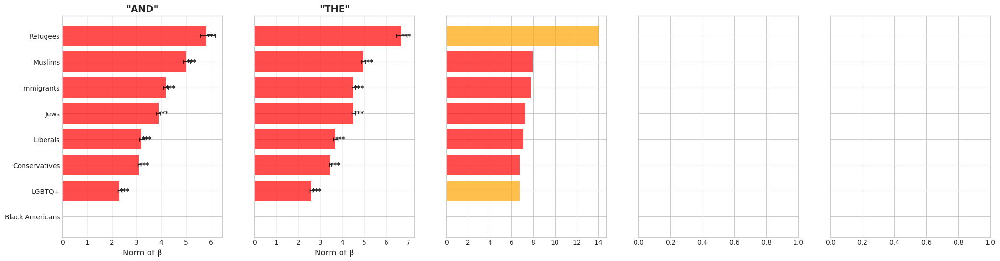

In [13]:
import io, zipfile, requests, os
import re, math, json
import numpy as np
import pandas as pd
from collections import defaultdict
from numpy.linalg import norm
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import torch
from transformers import RobertaTokenizer, RobertaModel

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------
CSV_PATH = "US_vs_them_llama_labeled_data_final.csv"
GLOVE_URL = "https://nlp.stanford.edu/data/glove.6B.zip"
GLOVE_DIR = "embeddings"
GLOVE_FILE = os.path.join(GLOVE_DIR, "glove.6B.300d.txt")
DIM = 300

# --- Embedding Selection ---
EMBEDDING_TYPE = 'both'  # 'glove', 'roberta', 'both'

# --- Regression Analysis Configuration ---
TARGET_WORDS = ["and", "the", "equality", "education", "abortion"]
TARGET_GROUPS = [
    'Black Americans', 'Conservatives', 'Muslims', 'LGBTQ+',
    'Immigrants', 'Jews', 'Liberals', 'Refugees'
]
WINDOW_SIZE = 6

# --- Permutation Testing Configuration ---
N_PERMUTATIONS = 1000  # Number of permutations for null distribution
N_BOOTSTRAP = 1000     # Number of bootstrap samples for confidence intervals
ALPHA = 0.01          # Significance level

# ----------------------------------------------------------------------
# 1. DATA LOADING AND SETUP
# ----------------------------------------------------------------------

def download_and_load_glove():
    """Downloads GloVe vectors and loads them into a dictionary."""
    if not os.path.exists(GLOVE_FILE):
        print(f"Downloading GloVe from {GLOVE_URL}...")
        os.makedirs(GLOVE_DIR, exist_ok=True)
        try:
            zbytes = requests.get(GLOVE_URL).content
            with zipfile.ZipFile(io.BytesIO(zbytes)) as zf:
                zf.extract("glove.6B.300d.txt", path=GLOVE_DIR)
            print(f"Saved GloVe to {GLOVE_FILE}")
        except Exception as e:
            print(f"Error during download or extraction: {e}")
            return {}

    print(f"Loading GloVe embeddings ({DIM}d)...")
    glove_embeddings = {}
    with open(GLOVE_FILE, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) > DIM:
                word = parts[0]
                vector = np.array(parts[1:], dtype=np.float32)
                glove_embeddings[word] = vector
    print(f"Successfully loaded {len(glove_embeddings)} words.")
    return glove_embeddings

class RoBERTaEmbedder:
    """Handles RoBERTa contextualized embeddings."""
    
    def __init__(self, model_name='roberta-base'):
        print(f"Loading RoBERTa model: {model_name}...")
        self.tokenizer = RobertaTokenizer.from_pretrained(model_name)
        self.model = RobertaModel.from_pretrained(model_name)
        self.model.eval()
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model.to(self.device)
        self.dim = self.model.config.hidden_size
        print(f"RoBERTa loaded. Embedding dimension: {self.dim}")
    
    def get_context_embedding(self, text, focal_word, window_size=6):
        """Extracts context word embeddings for a focal word."""
        text = text.lower()
        
        if '_' in focal_word:
            mwe_phrase = focal_word.replace('_', ' ')
            text = text.replace(mwe_phrase, focal_word)
        
        tokens = re.sub(r'[^\w_]', ' ', text).split()
        focal_indices = [i for i, w in enumerate(tokens) if w == focal_word]
        
        context_words = set()
        for i in focal_indices:
            start = max(0, i - window_size)
            end = min(len(tokens), i + window_size + 1)
            context_words.update(tokens[start:i])
            context_words.update(tokens[i+1:end])
        
        context_embeddings = []
        for word in context_words:
            simple_text = f"The word {word} appears here."
            embedding = self.get_word_embedding(simple_text, word)
            if embedding is not None:
                context_embeddings.append(embedding)
        
        if context_embeddings:
            return np.mean(context_embeddings, axis=0)
        else:
            return None
    
    def get_word_embedding(self, text, focal_word):
        """Extracts contextualized embedding for a focal word."""
        text = text.lower()
        focal_word = focal_word.lower()
        
        inputs = self.tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
        inputs = {k: v.to(self.device) for k, v in inputs.items()}
        
        with torch.no_grad():
            outputs = self.model(**inputs)
            hidden_states = outputs.last_hidden_state[0]
        
        tokens = self.tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
        
        focal_indices = []
        search_term = focal_word.replace('_', '')
        
        i = 0
        while i < len(tokens):
            token_seq = ''.join(tokens[i:i+5]).replace('Ġ', '').replace('</s>', '').replace('<s>', '')
            if search_term in token_seq.lower():
                j = i
                word_tokens = []
                while j < len(tokens) and search_term.startswith(''.join(word_tokens).replace('Ġ', '').lower()):
                    word_tokens.append(tokens[j].replace('Ġ', ''))
                    if search_term == ''.join(word_tokens).replace('Ġ', '').lower():
                        focal_indices.extend(range(i, j+1))
                        break
                    j += 1
                i = j + 1
            else:
                i += 1
        
        if focal_indices:
            focal_embeddings = hidden_states[focal_indices]
            return focal_embeddings.mean(dim=0).cpu().numpy()
        else:
            return None

# Load data
try:
    df = pd.read_csv(CSV_PATH)
    print(f"Loaded {len(df)} records from {CSV_PATH}")
except FileNotFoundError:
    print(f"Error: CSV file not found at {CSV_PATH}")
    exit()

GLOVE_EMBEDDINGS = {}
ROBERTA_EMBEDDER = None

if EMBEDDING_TYPE in ['glove', 'both']:
    GLOVE_EMBEDDINGS = download_and_load_glove()

if EMBEDDING_TYPE in ['roberta', 'both']:
    ROBERTA_EMBEDDER = RoBERTaEmbedder()

# ----------------------------------------------------------------------
# 2. ALC EMBEDDING FUNCTIONS
# ----------------------------------------------------------------------

def get_context_words(text, focal_word, window_size=6):
    """Extracts context words for a focal word."""
    text = text.lower()
    
    mwe_text = text
    if '_' in focal_word:
        mwe_phrase = focal_word.replace('_', ' ')
        mwe_text = mwe_text.replace(mwe_phrase, focal_word)
    
    tokens = re.sub(r'[^\w_]', ' ', mwe_text).split()
    focal_indices = [i for i, w in enumerate(tokens) if w == focal_word]
    
    context = set()
    for i in focal_indices:
        start = max(0, i - window_size)
        end = min(len(tokens), i + window_size + 1)
        context.update(tokens[start:i])
        context.update(tokens[i+1:end])
        
    return list(context)

def alc_embedding_single_glove(text, focal_word, window_size=6):
    """Computes ALC embedding for a single text instance using GloVe."""
    context_words = get_context_words(text, focal_word, window_size)
    vectors = [GLOVE_EMBEDDINGS[w] for w in context_words if w in GLOVE_EMBEDDINGS]
    
    if vectors:
        u_w_avg = np.mean(vectors, axis=0)
        return u_w_avg  # Using identity matrix (no transformation)
    else:
        return np.zeros(DIM, dtype=np.float32)

def alc_embedding_single_roberta(text, focal_word, window_size=6):
    """Computes ALC embedding for a single text instance using RoBERTa."""
    embedding = ROBERTA_EMBEDDER.get_context_embedding(text, focal_word, window_size)
    if embedding is not None:
        return embedding
    else:
        return np.zeros(ROBERTA_EMBEDDER.dim, dtype=np.float32)

# ----------------------------------------------------------------------
# 3. REGRESSION ANALYSIS FUNCTIONS
# ----------------------------------------------------------------------

def create_group_dummies(df, group_column='MappedGroup', target_groups=None):
    """Creates dummy variables for each target group."""
    if target_groups is None:
        target_groups = df[group_column].unique()
    
    for group in target_groups:
        df[f'is_{group.replace(" ", "_").replace("+", "plus")}'] = (df[group_column] == group).astype(int)
    
    return df

def extract_embeddings_for_word(df, focal_word, embedding_type='glove'):
    """Extracts ALC embeddings for all instances of a focal word."""
    # Filter to texts containing the focal word
    focal_word_lower = focal_word.lower()
    if '_' in focal_word:
        search_pattern = focal_word.replace('_', ' ')
    else:
        search_pattern = focal_word
    
    mask = df['pure_text'].str.lower().str.contains(search_pattern, na=False, regex=False)
    word_df = df[mask].copy()
    
    print(f"  Found {len(word_df)} instances of '{focal_word}'")
    
    if len(word_df) == 0:
        return None
    
    # Extract embeddings
    embeddings = []
    valid_indices = []
    
    for idx, row in word_df.iterrows():
        text = row['pure_text']
        
        if embedding_type == 'glove':
            emb = alc_embedding_single_glove(text, focal_word, WINDOW_SIZE)
        else:  # roberta
            emb = alc_embedding_single_roberta(text, focal_word, WINDOW_SIZE)
        
        # Only include non-zero embeddings
        if not np.all(emb == 0):
            embeddings.append(emb)
            valid_indices.append(idx)
    
    if len(embeddings) == 0:
        return None
    
    # Create result dataframe
    result_df = word_df.loc[valid_indices].copy()
    result_df['embedding'] = embeddings
    
    return result_df

def run_multivariate_regression(embedding_df, target_groups):
    """
    Runs multivariate regression: Y = β0 + β1*Group1 + β2*Group2 + ... + ε
    Uses first group as reference (drops it to avoid multicollinearity).
    Returns coefficient norms for each group.
    """
    # Prepare feature matrix X
    group_cols = [f'is_{group.replace(" ", "_").replace("+", "plus")}' for group in target_groups]
    
    # Check which columns exist and have non-zero variance
    available_cols = []
    available_groups = []
    
    for col, group in zip(group_cols, target_groups):
        if col in embedding_df.columns and embedding_df[col].sum() > 0:
            available_cols.append(col)
            available_groups.append(group)
    
    if len(available_cols) < 2:  # Need at least 2 groups
        return None
    
    # Use first group as reference, drop it from X
    reference_group = available_groups[0]
    predictor_cols = available_cols[1:]
    predictor_groups = available_groups[1:]
    
    X = embedding_df[predictor_cols].values
    
    # Check if we have variation in X
    if X.sum() == 0 or len(np.unique(X, axis=0)) == 1:
        return None
    
    # Stack all embeddings into Y matrix
    Y = np.vstack(embedding_df['embedding'].values)
    
    # Normalize embeddings to avoid numerical issues
    Y_mean = Y.mean(axis=0, keepdims=True)
    Y_std = Y.std(axis=0, keepdims=True) + 1e-8
    Y_normalized = (Y - Y_mean) / Y_std
    
    # Fit regression with NO intercept (or fit_intercept=True, both work with proper setup)
    reg = LinearRegression(fit_intercept=True)
    reg.fit(X, Y_normalized)
    
    # Calculate norms of coefficients
    coef_norms = {}
    
    # Reference group gets norm of 0 (baseline)
    coef_norms[reference_group] = 0.0
    
    # Other groups get their coefficient norms
    for i, group in enumerate(predictor_groups):
        coef_vector = reg.coef_[:, i]
        coef_norms[group] = norm(coef_vector)
    
    return coef_norms, reg, reference_group

def permutation_test(embedding_df, target_groups, n_permutations=1000):
    """
    Performs permutation test to generate null distribution.
    Shuffles group labels and recomputes coefficient norms.
    """
    group_cols = [f'is_{group.replace(" ", "_").replace("+", "plus")}' for group in target_groups]
    
    # Check which columns exist and have non-zero variance
    available_cols = []
    available_groups = []
    
    for col, group in zip(group_cols, target_groups):
        if col in embedding_df.columns and embedding_df[col].sum() > 0:
            available_cols.append(col)
            available_groups.append(group)
    
    if len(available_cols) < 2:
        return None
    
    # Use first group as reference
    reference_group = available_groups[0]
    predictor_cols = available_cols[1:]
    predictor_groups = available_groups[1:]
    
    X_original = embedding_df[predictor_cols].values
    Y = np.vstack(embedding_df['embedding'].values)
    
    # Normalize Y
    Y_mean = Y.mean(axis=0, keepdims=True)
    Y_std = Y.std(axis=0, keepdims=True) + 1e-8
    Y_normalized = (Y - Y_mean) / Y_std
    
    null_distributions = {group: [] for group in predictor_groups}
    null_distributions[reference_group] = [0.0] * n_permutations  # Reference always 0
    
    print(f"    Running {n_permutations} permutations...")
    for perm in range(n_permutations):
        if perm % 200 == 0 and perm > 0:
            print(f"      Completed {perm}/{n_permutations}...")
        
        # Shuffle rows of X
        X_shuffled = X_original.copy()
        np.random.shuffle(X_shuffled)
        
        # Fit regression
        reg = LinearRegression(fit_intercept=True)
        reg.fit(X_shuffled, Y_normalized)
        
        # Calculate norms
        for i, group in enumerate(predictor_groups):
            coef_vector = reg.coef_[:, i]
            null_distributions[group].append(norm(coef_vector))
    
    return null_distributions

def bootstrap_confidence_intervals(embedding_df, target_groups, n_bootstrap=1000, ci=95):
    """
    Performs bootstrap resampling to estimate confidence intervals.
    """
    group_cols = [f'is_{group.replace(" ", "_").replace("+", "plus")}' for group in target_groups]
    
    # Check which columns exist and have non-zero variance
    available_cols = []
    available_groups = []
    
    for col, group in zip(group_cols, target_groups):
        if col in embedding_df.columns and embedding_df[col].sum() > 0:
            available_cols.append(col)
            available_groups.append(group)
    
    if len(available_cols) < 2:
        return None
    
    # Use first group as reference
    reference_group = available_groups[0]
    predictor_cols = available_cols[1:]
    predictor_groups = available_groups[1:]
    
    bootstrap_distributions = {group: [] for group in predictor_groups}
    bootstrap_distributions[reference_group] = [0.0] * n_bootstrap  # Reference always 0
    
    print(f"    Running {n_bootstrap} bootstrap samples...")
    for b in range(n_bootstrap):
        if b % 200 == 0 and b > 0:
            print(f"      Completed {b}/{n_bootstrap}...")
        
        # Resample with replacement
        sample_df = embedding_df.sample(n=len(embedding_df), replace=True)
        
        X = sample_df[predictor_cols].values
        Y = np.vstack(sample_df['embedding'].values)
        
        # Normalize Y
        Y_mean = Y.mean(axis=0, keepdims=True)
        Y_std = Y.std(axis=0, keepdims=True) + 1e-8
        Y_normalized = (Y - Y_mean) / Y_std
        
        # Fit regression
        reg = LinearRegression(fit_intercept=True)
        reg.fit(X, Y_normalized)
        
        # Calculate norms
        for i, group in enumerate(predictor_groups):
            coef_vector = reg.coef_[:, i]
            bootstrap_distributions[group].append(norm(coef_vector))
    
    # Calculate confidence intervals
    ci_results = {}
    alpha = (100 - ci) / 2
    
    # Reference group
    ci_results[reference_group] = (0.0, 0.0)
    
    # Other groups
    for group, values in bootstrap_distributions.items():
        if group != reference_group:
            lower = np.percentile(values, alpha)
            upper = np.percentile(values, 100 - alpha)
            ci_results[group] = (lower, upper)
    
    return ci_results

def calculate_p_values(observed_norms, null_distributions):
    """Calculates p-values from permutation test."""
    p_values = {}
    
    for group, observed in observed_norms.items():
        if group in null_distributions:
            null_dist = null_distributions[group]
            # Two-tailed test
            p_value = np.mean(np.abs(null_dist) >= np.abs(observed))
            p_values[group] = p_value
    
    return p_values

# ----------------------------------------------------------------------
# 4. VISUALIZATION
# ----------------------------------------------------------------------

def plot_coefficient_norms(results_dict, embedding_type='GloVe', save_path=None):
    """
    Plots coefficient norms with confidence intervals, similar to Figure 4.
    """
    # Prepare data for plotting
    plot_data = []
    
    for word, word_results in results_dict.items():
        if word_results is None:
            continue
            
        norms = word_results['norms']
        ci = word_results['ci']
        p_values = word_results['p_values']
        
        for group in norms.keys():
            sig_level = '***' if p_values.get(group, 1.0) < 0.01 else \
                       '**' if p_values.get(group, 1.0) < 0.05 else \
                       '*' if p_values.get(group, 1.0) < 0.1 else 'ns'
            
            plot_data.append({
                'Word': word,
                'Group': group,
                'Norm': norms[group],
                'CI_Lower': ci[group][0],
                'CI_Upper': ci[group][1],
                'Significance': sig_level
            })
    
    plot_df = pd.DataFrame(plot_data)
    
    # Create subplots for each word
    n_words = len(results_dict)
    fig, axes = plt.subplots(1, n_words, figsize=(5*n_words, 6), sharey=True)
    
    if n_words == 1:
        axes = [axes]
    
    for idx, (word, ax) in enumerate(zip(results_dict.keys(), axes)):
        word_data = plot_df[plot_df['Word'] == word].sort_values('Norm', ascending=True)
        
        if len(word_data) == 0:
            continue
        
        # Plot horizontal bars with error bars
        y_pos = np.arange(len(word_data))
        
        colors = ['red' if sig == '***' else 'orange' if sig == '**' else 'yellow' if sig == '*' else 'gray' 
                 for sig in word_data['Significance']]
        
        ax.barh(y_pos, word_data['Norm'], color=colors, alpha=0.7)
        
        # Add error bars
        errors = [
            word_data['Norm'].values - word_data['CI_Lower'].values,
            word_data['CI_Upper'].values - word_data['Norm'].values
        ]
        ax.errorbar(word_data['Norm'], y_pos, xerr=errors, fmt='none', 
                   ecolor='black', capsize=3, alpha=0.8)
        
        # Add significance markers
        for i, (norm_val, sig) in enumerate(zip(word_data['Norm'], word_data['Significance'])):
            if sig != 'ns':
                ax.text(norm_val + 0.01, i, sig, va='center', fontweight='bold')
        
        ax.set_yticks(y_pos)
        ax.set_yticklabels(word_data['Group'])
        ax.set_xlabel('Norm of β̂', fontsize=12)
        ax.set_title(f'"{word.upper()}"', fontsize=14, fontweight='bold')
        ax.grid(axis='x', alpha=0.3)
    
    plt.suptitle(f'Group Differences in Word Usage ({embedding_type} Embeddings)', 
                fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"  Saved plot to {save_path}")
    
    plt.show()
    
    return plot_df

# ----------------------------------------------------------------------
# 5. MAIN ANALYSIS
# ----------------------------------------------------------------------

def run_full_analysis(df, target_words, target_groups, embedding_type='glove'):
    """Runs complete regression analysis for all target words."""
    
    print(f"\n{'='*70}")
    print(f"Running Regression Analysis with {embedding_type.upper()} Embeddings")
    print(f"{'='*70}\n")
    
    # Create group dummy variables
    df = create_group_dummies(df, 'MappedGroup', target_groups)
    
    results = {}
    
    for word in target_words:
        print(f"\nAnalyzing word: '{word}'")
        
        # Extract embeddings
        embedding_df = extract_embeddings_for_word(df, word, embedding_type)
        
        if embedding_df is None or len(embedding_df) < 20:
            print(f"  Insufficient data for '{word}', skipping...")
            results[word] = None
            continue
        
        # Run regression
        print(f"  Running multivariate regression...")
        reg_results = run_multivariate_regression(embedding_df, target_groups)
        
        if reg_results is None:
            print(f"  Regression failed for '{word}', skipping...")
            results[word] = None
            continue
        
        norms, reg_model, reference_group = reg_results
        print(f"  Reference group: {reference_group}")
        
        # Permutation test
        print(f"  Running permutation test...")
        null_distributions = permutation_test(embedding_df, target_groups, N_PERMUTATIONS)
        
        # Bootstrap confidence intervals
        print(f"  Computing bootstrap confidence intervals...")
        ci_results = bootstrap_confidence_intervals(embedding_df, target_groups, N_BOOTSTRAP)
        
        # Calculate p-values
        p_values = calculate_p_values(norms, null_distributions)
        
        results[word] = {
            'norms': norms,
            'ci': ci_results,
            'p_values': p_values,
            'model': reg_model,
            'reference_group': reference_group,
            'n_instances': len(embedding_df)
        }
        
        # Print results
        print(f"\n  Results for '{word}' (Reference: {reference_group}):")
        print(f"  {'Group':<20} {'Norm(β̂)':<12} {'95% CI':<25} {'p-value':<10} {'Sig':<5}")
        print(f"  {'-'*75}")
        
        for group in sorted(norms.keys(), key=lambda x: norms[x], reverse=True):
            norm_val = norms[group]
            ci_lower, ci_upper = ci_results[group]
            p_val = p_values[group]
            sig = '***' if p_val < 0.01 else '**' if p_val < 0.05 else '*' if p_val < 0.1 else ''
            
            print(f"  {group:<20} {norm_val:>10.4f}  [{ci_lower:>6.4f}, {ci_upper:>6.4f}]  "
                  f"{p_val:>8.4f}  {sig:<5}")
    
    return results

# Run analysis for both embedding types
print("\n" + "="*70)
print("STARTING REGRESSION ANALYSIS")
print("="*70)

results_glove = None
results_roberta = None

if EMBEDDING_TYPE in ['glove', 'both']:
    results_glove = run_full_analysis(df, TARGET_WORDS, TARGET_GROUPS, 'glove')
    plot_data_glove = plot_coefficient_norms(results_glove, 'GloVe', 'glove_regression_norms.png')

if EMBEDDING_TYPE in ['roberta', 'both']:
    results_roberta = run_full_analysis(df, TARGET_WORDS, TARGET_GROUPS, 'roberta')
    plot_data_roberta = plot_coefficient_norms(results_roberta, 'RoBERTa', 'roberta_regression_norms.png')

print("\n" + "="*70)
print("ANALYSIS COMPLETE!")
print("="*70)

In [ ]:
import io, zipfile, requests, os
import re, math, json
import numpy as np
import pandas as pd
from collections import defaultdict
from numpy.linalg import norm
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import torch
from transformers import RobertaTokenizer, RobertaModel

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------
CSV_PATH = "US_vs_them_llama_labeled_data_final.csv"
GLOVE_URL = "https://nlp.stanford.edu/data/glove.6B.zip"
GLOVE_DIR = "embeddings"
GLOVE_FILE = os.path.join(GLOVE_DIR, "glove.6B.300d.txt")
DIM = 300

# --- Embedding Selection ---
EMBEDDING_TYPE = 'roberta'  # Only RoBERTa embeddings

# --- Regression Analysis Configuration ---
TARGET_WORDS = ["and", "the", "equality", "education", "abortion"]
TARGET_GROUPS = [
    'Black Americans', 'Conservatives', 'Muslims', 'LGBTQ+',
    'Immigrants', 'Jews', 'Liberals', 'Refugees'
]
WINDOW_SIZE = 6

# --- Permutation Testing Configuration ---
N_PERMUTATIONS = 1000  # Number of permutations for null distribution
N_BOOTSTRAP = 1000     # Number of bootstrap samples for confidence intervals
ALPHA = 0.01          # Significance level

# ----------------------------------------------------------------------
# 1. DATA LOADING AND SETUP
# ----------------------------------------------------------------------

def download_and_load_glove():
    """Downloads GloVe vectors and loads them into a dictionary."""
    if not os.path.exists(GLOVE_FILE):
        print(f"Downloading GloVe from {GLOVE_URL}...")
        os.makedirs(GLOVE_DIR, exist_ok=True)
        try:
            zbytes = requests.get(GLOVE_URL).content
            with zipfile.ZipFile(io.BytesIO(zbytes)) as zf:
                zf.extract("glove.6B.300d.txt", path=GLOVE_DIR)
            print(f"Saved GloVe to {GLOVE_FILE}")
        except Exception as e:
            print(f"Error during download or extraction: {e}")
            return {}

    print(f"Loading GloVe embeddings ({DIM}d)...")
    glove_embeddings = {}
    with open(GLOVE_FILE, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) > DIM:
                word = parts[0]
                vector = np.array(parts[1:], dtype=np.float32)
                glove_embeddings[word] = vector
    print(f"Successfully loaded {len(glove_embeddings)} words.")
    return glove_embeddings

class RoBERTaEmbedder:
    """Handles RoBERTa contextualized embeddings."""
    
    def __init__(self, model_name='roberta-base'):
        print(f"Loading RoBERTa model: {model_name}...")
        self.tokenizer = RobertaTokenizer.from_pretrained(model_name)
        self.model = RobertaModel.from_pretrained(model_name)
        self.model.eval()
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model.to(self.device)
        self.dim = self.model.config.hidden_size
        print(f"RoBERTa loaded. Embedding dimension: {self.dim}")
    
    def get_context_embedding(self, text, focal_word, window_size=6):
        """Extracts context word embeddings for a focal word."""
        text = text.lower()
        
        if '_' in focal_word:
            mwe_phrase = focal_word.replace('_', ' ')
            text = text.replace(mwe_phrase, focal_word)
        
        tokens = re.sub(r'[^\w_]', ' ', text).split()
        focal_indices = [i for i, w in enumerate(tokens) if w == focal_word]
        
        context_words = set()
        for i in focal_indices:
            start = max(0, i - window_size)
            end = min(len(tokens), i + window_size + 1)
            context_words.update(tokens[start:i])
            context_words.update(tokens[i+1:end])
        
        context_embeddings = []
        for word in context_words:
            simple_text = f"The word {word} appears here."
            embedding = self.get_word_embedding(simple_text, word)
            if embedding is not None:
                context_embeddings.append(embedding)
        
        if context_embeddings:
            return np.mean(context_embeddings, axis=0)
        else:
            return None
    
    def get_word_embedding(self, text, focal_word):
        """Extracts contextualized embedding for a focal word."""
        text = text.lower()
        focal_word = focal_word.lower()
        
        inputs = self.tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
        inputs = {k: v.to(self.device) for k, v in inputs.items()}
        
        with torch.no_grad():
            outputs = self.model(**inputs)
            hidden_states = outputs.last_hidden_state[0]
        
        tokens = self.tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
        
        focal_indices = []
        search_term = focal_word.replace('_', '')
        
        i = 0
        while i < len(tokens):
            token_seq = ''.join(tokens[i:i+5]).replace('Ġ', '').replace('</s>', '').replace('<s>', '')
            if search_term in token_seq.lower():
                j = i
                word_tokens = []
                while j < len(tokens) and search_term.startswith(''.join(word_tokens).replace('Ġ', '').lower()):
                    word_tokens.append(tokens[j].replace('Ġ', ''))
                    if search_term == ''.join(word_tokens).replace('Ġ', '').lower():
                        focal_indices.extend(range(i, j+1))
                        break
                    j += 1
                i = j + 1
            else:
                i += 1
        
        if focal_indices:
            focal_embeddings = hidden_states[focal_indices]
            return focal_embeddings.mean(dim=0).cpu().numpy()
        else:
            return None

# Load data
try:
    df = pd.read_csv(CSV_PATH)
    print(f"Loaded {len(df)} records from {CSV_PATH}")
except FileNotFoundError:
    print(f"Error: CSV file not found at {CSV_PATH}")
    exit()

# Load only RoBERTa
ROBERTA_EMBEDDER = RoBERTaEmbedder()

# ----------------------------------------------------------------------
# 2. ALC EMBEDDING FUNCTIONS
# ----------------------------------------------------------------------

def get_context_words(text, focal_word, window_size=6):
    """Extracts context words for a focal word."""
    text = text.lower()
    
    mwe_text = text
    if '_' in focal_word:
        mwe_phrase = focal_word.replace('_', ' ')
        mwe_text = mwe_text.replace(mwe_phrase, focal_word)
    
    tokens = re.sub(r'[^\w_]', ' ', mwe_text).split()
    focal_indices = [i for i, w in enumerate(tokens) if w == focal_word]
    
    context = set()
    for i in focal_indices:
        start = max(0, i - window_size)
        end = min(len(tokens), i + window_size + 1)
        context.update(tokens[start:i])
        context.update(tokens[i+1:end])
        
    return list(context)

def alc_embedding_single_roberta(text, focal_word, window_size=6):
    """Computes ALC embedding for a single text instance using RoBERTa."""
    embedding = ROBERTA_EMBEDDER.get_context_embedding(text, focal_word, window_size)
    if embedding is not None:
        return embedding
    else:
        return np.zeros(ROBERTA_EMBEDDER.dim, dtype=np.float32)

# ----------------------------------------------------------------------
# 3. REGRESSION ANALYSIS FUNCTIONS
# ----------------------------------------------------------------------

def create_group_dummies(df, group_column='MappedGroup', target_groups=None):
    """Creates dummy variables for each target group."""
    if target_groups is None:
        target_groups = df[group_column].unique()
    
    for group in target_groups:
        df[f'is_{group.replace(" ", "_").replace("+", "plus")}'] = (df[group_column] == group).astype(int)
    
    return df

def extract_embeddings_for_word(df, focal_word, embedding_type='roberta'):
    """Extracts ALC embeddings for all instances of a focal word using RoBERTa."""
    # Filter to texts containing the focal word
    focal_word_lower = focal_word.lower()
    if '_' in focal_word:
        search_pattern = focal_word.replace('_', ' ')
    else:
        search_pattern = focal_word
    
    mask = df['pure_text'].str.lower().str.contains(search_pattern, na=False, regex=False)
    word_df = df[mask].copy()
    
    print(f"  Found {len(word_df)} instances of '{focal_word}'")
    
    if len(word_df) == 0:
        return None
    
    # Extract embeddings using RoBERTa
    embeddings = []
    valid_indices = []
    
    for idx, row in word_df.iterrows():
        text = row['pure_text']
        emb = alc_embedding_single_roberta(text, focal_word, WINDOW_SIZE)
        
        # Only include non-zero embeddings
        if not np.all(emb == 0):
            embeddings.append(emb)
            valid_indices.append(idx)
    
    if len(embeddings) == 0:
        return None
    
    # Create result dataframe
    result_df = word_df.loc[valid_indices].copy()
    result_df['embedding'] = embeddings
    
    return result_df

def run_multivariate_regression(embedding_df, target_groups):
    """
    Runs multivariate regression: Y = β0 + β1*Group1 + β2*Group2 + ... + ε
    Uses first group as reference (drops it to avoid multicollinearity).
    Returns coefficient norms for each group.
    """
    # Prepare feature matrix X
    group_cols = [f'is_{group.replace(" ", "_").replace("+", "plus")}' for group in target_groups]
    
    # Check which columns exist and have non-zero variance
    available_cols = []
    available_groups = []
    
    for col, group in zip(group_cols, target_groups):
        if col in embedding_df.columns and embedding_df[col].sum() > 0:
            available_cols.append(col)
            available_groups.append(group)
    
    if len(available_cols) < 2:  # Need at least 2 groups
        return None
    
    # Use first group as reference, drop it from X
    reference_group = available_groups[0]
    predictor_cols = available_cols[1:]
    predictor_groups = available_groups[1:]
    
    X = embedding_df[predictor_cols].values
    
    # Check if we have variation in X
    if X.sum() == 0 or len(np.unique(X, axis=0)) == 1:
        return None
    
    # Stack all embeddings into Y matrix
    Y = np.vstack(embedding_df['embedding'].values)
    
    # Normalize embeddings to avoid numerical issues
    Y_mean = Y.mean(axis=0, keepdims=True)
    Y_std = Y.std(axis=0, keepdims=True) + 1e-8
    Y_normalized = (Y - Y_mean) / Y_std
    
    # Fit regression with NO intercept (or fit_intercept=True, both work with proper setup)
    reg = LinearRegression(fit_intercept=True)
    reg.fit(X, Y_normalized)
    
    # Calculate norms of coefficients
    coef_norms = {}
    
    # Reference group gets norm of 0 (baseline)
    coef_norms[reference_group] = 0.0
    
    # Other groups get their coefficient norms
    for i, group in enumerate(predictor_groups):
        coef_vector = reg.coef_[:, i]
        coef_norms[group] = norm(coef_vector)
    
    return coef_norms, reg, reference_group

def permutation_test(embedding_df, target_groups, n_permutations=1000):
    """
    Performs permutation test to generate null distribution.
    Shuffles group labels and recomputes coefficient norms.
    """
    group_cols = [f'is_{group.replace(" ", "_").replace("+", "plus")}' for group in target_groups]
    
    # Check which columns exist and have non-zero variance
    available_cols = []
    available_groups = []
    
    for col, group in zip(group_cols, target_groups):
        if col in embedding_df.columns and embedding_df[col].sum() > 0:
            available_cols.append(col)
            available_groups.append(group)
    
    if len(available_cols) < 2:
        return None
    
    # Use first group as reference
    reference_group = available_groups[0]
    predictor_cols = available_cols[1:]
    predictor_groups = available_groups[1:]
    
    X_original = embedding_df[predictor_cols].values
    Y = np.vstack(embedding_df['embedding'].values)
    
    # Normalize Y
    Y_mean = Y.mean(axis=0, keepdims=True)
    Y_std = Y.std(axis=0, keepdims=True) + 1e-8
    Y_normalized = (Y - Y_mean) / Y_std
    
    null_distributions = {group: [] for group in predictor_groups}
    null_distributions[reference_group] = [0.0] * n_permutations  # Reference always 0
    
    print(f"    Running {n_permutations} permutations...")
    for perm in range(n_permutations):
        if perm % 200 == 0 and perm > 0:
            print(f"      Completed {perm}/{n_permutations}...")
        
        # Shuffle rows of X
        X_shuffled = X_original.copy()
        np.random.shuffle(X_shuffled)
        
        # Fit regression
        reg = LinearRegression(fit_intercept=True)
        reg.fit(X_shuffled, Y_normalized)
        
        # Calculate norms
        for i, group in enumerate(predictor_groups):
            coef_vector = reg.coef_[:, i]
            null_distributions[group].append(norm(coef_vector))
    
    return null_distributions

def bootstrap_confidence_intervals(embedding_df, target_groups, n_bootstrap=1000, ci=95):
    """
    Performs bootstrap resampling to estimate confidence intervals.
    """
    group_cols = [f'is_{group.replace(" ", "_").replace("+", "plus")}' for group in target_groups]
    
    # Check which columns exist and have non-zero variance
    available_cols = []
    available_groups = []
    
    for col, group in zip(group_cols, target_groups):
        if col in embedding_df.columns and embedding_df[col].sum() > 0:
            available_cols.append(col)
            available_groups.append(group)
    
    if len(available_cols) < 2:
        return None
    
    # Use first group as reference
    reference_group = available_groups[0]
    predictor_cols = available_cols[1:]
    predictor_groups = available_groups[1:]
    
    bootstrap_distributions = {group: [] for group in predictor_groups}
    bootstrap_distributions[reference_group] = [0.0] * n_bootstrap  # Reference always 0
    
    print(f"    Running {n_bootstrap} bootstrap samples...")
    for b in range(n_bootstrap):
        if b % 200 == 0 and b > 0:
            print(f"      Completed {b}/{n_bootstrap}...")
        
        # Resample with replacement
        sample_df = embedding_df.sample(n=len(embedding_df), replace=True)
        
        X = sample_df[predictor_cols].values
        Y = np.vstack(sample_df['embedding'].values)
        
        # Normalize Y
        Y_mean = Y.mean(axis=0, keepdims=True)
        Y_std = Y.std(axis=0, keepdims=True) + 1e-8
        Y_normalized = (Y - Y_mean) / Y_std
        
        # Fit regression
        reg = LinearRegression(fit_intercept=True)
        reg.fit(X, Y_normalized)
        
        # Calculate norms
        for i, group in enumerate(predictor_groups):
            coef_vector = reg.coef_[:, i]
            bootstrap_distributions[group].append(norm(coef_vector))
    
    # Calculate confidence intervals
    ci_results = {}
    alpha = (100 - ci) / 2
    
    # Reference group
    ci_results[reference_group] = (0.0, 0.0)
    
    # Other groups
    for group, values in bootstrap_distributions.items():
        if group != reference_group:
            lower = np.percentile(values, alpha)
            upper = np.percentile(values, 100 - alpha)
            ci_results[group] = (lower, upper)
    
    return ci_results

def calculate_p_values(observed_norms, null_distributions):
    """Calculates p-values from permutation test."""
    p_values = {}
    
    for group, observed in observed_norms.items():
        if group in null_distributions:
            null_dist = null_distributions[group]
            # Two-tailed test
            p_value = np.mean(np.abs(null_dist) >= np.abs(observed))
            p_values[group] = p_value
    
    return p_values

# ----------------------------------------------------------------------
# 4. VISUALIZATION
# ----------------------------------------------------------------------

def plot_coefficient_norms(results_dict, embedding_type='GloVe', save_path=None):
    """
    Plots coefficient norms with confidence intervals, similar to Figure 4.
    """
    # Prepare data for plotting
    plot_data = []
    
    for word, word_results in results_dict.items():
        if word_results is None:
            continue
            
        norms = word_results['norms']
        ci = word_results['ci']
        p_values = word_results['p_values']
        
        for group in norms.keys():
            sig_level = '***' if p_values.get(group, 1.0) < 0.01 else \
                       '**' if p_values.get(group, 1.0) < 0.05 else \
                       '*' if p_values.get(group, 1.0) < 0.1 else 'ns'
            
            plot_data.append({
                'Word': word,
                'Group': group,
                'Norm': norms[group],
                'CI_Lower': ci[group][0],
                'CI_Upper': ci[group][1],
                'Significance': sig_level
            })
    
    plot_df = pd.DataFrame(plot_data)
    
    # Create subplots for each word
    n_words = len(results_dict)
    fig, axes = plt.subplots(1, n_words, figsize=(5*n_words, 6), sharey=True)
    
    if n_words == 1:
        axes = [axes]
    
    for idx, (word, ax) in enumerate(zip(results_dict.keys(), axes)):
        word_data = plot_df[plot_df['Word'] == word].sort_values('Norm', ascending=True)
        
        if len(word_data) == 0:
            continue
        
        # Plot horizontal bars with error bars
        y_pos = np.arange(len(word_data))
        
        colors = ['red' if sig == '***' else 'orange' if sig == '**' else 'yellow' if sig == '*' else 'gray' 
                 for sig in word_data['Significance']]
        
        ax.barh(y_pos, word_data['Norm'], color=colors, alpha=0.7)
        
        # Add error bars
        errors = [
            word_data['Norm'].values - word_data['CI_Lower'].values,
            word_data['CI_Upper'].values - word_data['Norm'].values
        ]
        ax.errorbar(word_data['Norm'], y_pos, xerr=errors, fmt='none', 
                   ecolor='black', capsize=3, alpha=0.8)
        
        # Add significance markers
        for i, (norm_val, sig) in enumerate(zip(word_data['Norm'], word_data['Significance'])):
            if sig != 'ns':
                ax.text(norm_val + 0.01, i, sig, va='center', fontweight='bold')
        
        ax.set_yticks(y_pos)
        ax.set_yticklabels(word_data['Group'])
        ax.set_xlabel('Norm of β̂', fontsize=12)
        ax.set_title(f'"{word.upper()}"', fontsize=14, fontweight='bold')
        ax.grid(axis='x', alpha=0.3)
    
    plt.suptitle(f'Group Differences in Word Usage ({embedding_type} Embeddings)', 
                fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"  Saved plot to {save_path}")
    
    plt.show()
    
    return plot_df

# ----------------------------------------------------------------------
# 5. MAIN ANALYSIS
# ----------------------------------------------------------------------

def run_full_analysis(df, target_words, target_groups, embedding_type='roberta'):
    """Runs complete regression analysis for all target words using RoBERTa."""
    
    print(f"\n{'='*70}")
    print(f"Running Regression Analysis with RoBERTa Embeddings")
    print(f"{'='*70}\n")
    
    # Create group dummy variables
    df = create_group_dummies(df, 'MappedGroup', target_groups)
    
    results = {}
    
    for word in target_words:
        print(f"\nAnalyzing word: '{word}'")
        
        # Extract embeddings
        embedding_df = extract_embeddings_for_word(df, word, embedding_type)
        
        if embedding_df is None or len(embedding_df) < 20:
            print(f"  Insufficient data for '{word}', skipping...")
            results[word] = None
            continue
        
        # Run regression
        print(f"  Running multivariate regression...")
        reg_results = run_multivariate_regression(embedding_df, target_groups)
        
        if reg_results is None:
            print(f"  Regression failed for '{word}', skipping...")
            results[word] = None
            continue
        
        norms, reg_model, reference_group = reg_results
        print(f"  Reference group: {reference_group}")
        
        # Permutation test
        print(f"  Running permutation test...")
        null_distributions = permutation_test(embedding_df, target_groups, N_PERMUTATIONS)
        
        # Bootstrap confidence intervals
        print(f"  Computing bootstrap confidence intervals...")
        ci_results = bootstrap_confidence_intervals(embedding_df, target_groups, N_BOOTSTRAP)
        
        # Calculate p-values
        p_values = calculate_p_values(norms, null_distributions)
        
        results[word] = {
            'norms': norms,
            'ci': ci_results,
            'p_values': p_values,
            'model': reg_model,
            'reference_group': reference_group,
            'n_instances': len(embedding_df)
        }
        
        # Print results
        print(f"\n  Results for '{word}' (Reference: {reference_group}):")
        print(f"  {'Group':<20} {'Norm(β̂)':<12} {'95% CI':<25} {'p-value':<10} {'Sig':<5}")
        print(f"  {'-'*75}")
        
        for group in sorted(norms.keys(), key=lambda x: norms[x], reverse=True):
            norm_val = norms[group]
            ci_lower, ci_upper = ci_results[group]
            p_val = p_values[group]
            sig = '***' if p_val < 0.01 else '**' if p_val < 0.05 else '*' if p_val < 0.1 else ''
            
            print(f"  {group:<20} {norm_val:>10.4f}  [{ci_lower:>6.4f}, {ci_upper:>6.4f}]  "
                  f"{p_val:>8.4f}  {sig:<5}")
    
    return results

# Run analysis for RoBERTa only
print("\n" + "="*70)
print("STARTING REGRESSION ANALYSIS WITH ROBERTA")
print("="*70)

results_roberta = run_full_analysis(df, TARGET_WORDS, TARGET_GROUPS, 'roberta')
plot_data_roberta = plot_coefficient_norms(results_roberta, 'RoBERTa', 'roberta_regression_norms.png')

print("\n" + "="*70)
print("ANALYSIS COMPLETE!")
print("="*70)

Loaded 153246 records from US_vs_them_llama_labeled_data_final.csv
Loading RoBERTa model: roberta-base...


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


RoBERTa loaded. Embedding dimension: 768

STARTING REGRESSION ANALYSIS WITH ROBERTA

Running Regression Analysis with RoBERTa Embeddings


Analyzing word: 'and'
  Found 72639 instances of 'and'


In [1]:

#Word Embeddings & Projections (Social Bias)

In [2]:
## 

import pandas as pd
df=pd.read_csv("US_vs_them_llama_labeled_data_final.csv")

In [25]:
df['year'].unique()

array([2022, 2020, 2016, 2019, 2018, 2017, 2021, 2015, 2012, 2013, 2014])

In [5]:
df.columns

Index(['Unnamed: 0', '_id', 'pure_text', 'rt_text', 'tweet_created_at',
       'tweet_id', 'user_id', 'user_created_at', 'fastText_lang',
       'fastText_conf', 'reply_to_id', 'LLM_Label', 'CommentType',
       'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup', 'year',
       'Topic'],
      dtype='object')

In [6]:
df['MappedGroup'].unique()

array(['Black Americans', 'Conservatives', 'Muslims', 'LGBTQ+',
       'Immigrants', 'Jews', 'Liberals', 'Refugees'], dtype=object)

In [4]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# from collections import Counter
# import re
# import warnings
# warnings.filterwarnings('ignore')

# # ── 0. Install if needed ──────────────────────────────────────────────
# # !pip install gensim bertopic sentence-transformers umap-learn hdbscan
# # !pip install top2vec nltk wordcloud pyLDAvis

# # ── 1. Text Cleaning (tweet-specific) ────────────────────────────────
# import nltk
# nltk.download('stopwords', quiet=True)
# nltk.download('punkt', quiet=True)
# from nltk.corpus import stopwords

# STOPWORDS = set(stopwords.words('english'))
# STOPWORDS.update(['rt', 'http', 'https', 'co', 'amp', 'via', 'would',
#                   'could', 'get', 'got', 'like', 'one', 'also', 'said'])

# def clean_tweet(text):
#     if not isinstance(text, str):
#         return ''
#     text = re.sub(r'http\S+|www\S+', '', text)          # URLs
#     text = re.sub(r'@\w+', '', text)                     # mentions
#     text = re.sub(r'#(\w+)', r'\1', text)                # hashtags → word
#     text = re.sub(r'[^\w\s]', ' ', text)                 # punctuation
#     text = re.sub(r'\d+', '', text)                      # numbers
#     tokens = text.lower().split()
#     tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 2]
#     return ' '.join(tokens)

# # Use pure_text; fall back to rt_text
# df['text_clean'] = df['pure_text'].fillna(df['rt_text']).apply(clean_tweet)
# df_model = df[df['text_clean'].str.len() > 10].copy().reset_index(drop=True)
# docs = df_model['text_clean'].tolist()
# print(f"Documents for modeling: {len(docs):,}")

# # ── 2. Vectorization (shared) ────────────────────────────────────────
# from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# cv = CountVectorizer(max_df=0.90, min_df=5, max_features=5000,
#                      ngram_range=(1, 2))
# tfidf = TfidfVectorizer(max_df=0.90, min_df=5, max_features=5000,
#                         ngram_range=(1, 2))

# dtm_count = cv.fit_transform(docs)
# dtm_tfidf = tfidf.fit_transform(docs)
# vocab_cv   = np.array(cv.get_feature_names_out())
# vocab_tf   = np.array(tfidf.get_feature_names_out())

# N_TOPICS = 15   # ← tune this

# # ═══════════════════════════════════════════════════════════════════════
# # MODEL 1 — LDA  (Gensim, Gibbs sampling via passes)
# # ═══════════════════════════════════════════════════════════════════════
# print("\n── LDA (Gensim) ──")
# import gensim
# from gensim import corpora
# from gensim.models import LdaModel

# tokenized = [d.split() for d in docs]
# dictionary = corpora.Dictionary(tokenized)
# dictionary.filter_extremes(no_below=5, no_above=0.9)
# corpus_gensim = [dictionary.doc2bow(t) for t in tokenized]

# lda_model = LdaModel(
#     corpus=corpus_gensim,
#     id2word=dictionary,
#     num_topics=N_TOPICS,
#     passes=20,               # more passes = better (Gibbs-like)
#     iterations=400,
#     alpha='auto',
#     eta='auto',
#     random_state=42,
#     per_word_topics=True
# )

# lda_topics = {}
# for idx, topic in lda_model.print_topics(num_topics=N_TOPICS, num_words=10):
#     words = [w.split('"')[1] for w in topic.split('+')]
#     lda_topics[f"LDA_T{idx+1}"] = words
#     print(f"  T{idx+1}: {', '.join(words)}")

# # ═══════════════════════════════════════════════════════════════════════
# # MODEL 2 — NMF  (Non-negative Matrix Factorization, TF-IDF)
# # ═══════════════════════════════════════════════════════════════════════
# print("\n── NMF (TF-IDF) ──")
# from sklearn.decomposition import NMF

# nmf_model = NMF(n_components=N_TOPICS, random_state=42,
#                 init='nndsvda', max_iter=500)
# nmf_model.fit(dtm_tfidf)

# nmf_topics = {}
# for idx, comp in enumerate(nmf_model.components_):
#     top_words = vocab_tf[np.argsort(comp)[::-1][:10]].tolist()
#     nmf_topics[f"NMF_T{idx+1}"] = top_words
#     print(f"  T{idx+1}: {', '.join(top_words)}")

# # Assign dominant topic per doc
# nmf_doc_topics = nmf_model.transform(dtm_tfidf).argmax(axis=1)
# df_model['NMF_topic'] = nmf_doc_topics

# # ═══════════════════════════════════════════════════════════════════════
# # MODEL 3 — LSA / LSI  (Latent Semantic Analysis, SVD)
# # ═══════════════════════════════════════════════════════════════════════
# print("\n── LSA (TruncatedSVD) ──")
# from sklearn.decomposition import TruncatedSVD
# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import Normalizer

# svd   = TruncatedSVD(n_components=N_TOPICS, random_state=42)
# norm  = Normalizer(copy=False)
# lsa_pipe = make_pipeline(svd, norm)
# lsa_matrix = lsa_pipe.fit_transform(dtm_tfidf)

# lsa_topics = {}
# for idx, comp in enumerate(svd.components_):
#     top_words = vocab_tf[np.argsort(np.abs(comp))[::-1][:10]].tolist()
#     lsa_topics[f"LSA_T{idx+1}"] = top_words
#     print(f"  T{idx+1}: {', '.join(top_words)}")

# lsa_doc_topics = lsa_matrix.argmax(axis=1)
# df_model['LSA_topic'] = lsa_doc_topics

# # ═══════════════════════════════════════════════════════════════════════
# # MODEL 4 — BERTopic  (transformer embeddings + UMAP + HDBSCAN)
# # ═══════════════════════════════════════════════════════════════════════
# print("\n── BERTopic ──")
# try:
#     from bertopic import BERTopic
#     from sentence_transformers import SentenceTransformer
#     from umap import UMAP
#     from hdbscan import HDBSCAN

#     umap_model  = UMAP(n_neighbors=15, n_components=5,
#                        min_dist=0.0, metric='cosine', random_state=42)
#     hdbscan_model = HDBSCAN(min_cluster_size=30, min_samples=10,
#                              metric='euclidean',
#                              cluster_selection_method='eom',
#                              prediction_data=True)

#     bert_topic = BERTopic(
#         embedding_model="all-MiniLM-L6-v2",   # fast & good for tweets
#         umap_model=umap_model,
#         hdbscan_model=hdbscan_model,
#         top_n_words=10,
#         nr_topics=N_TOPICS,
#         calculate_probabilities=False,
#         verbose=True
#     )

#     bert_topics_list, _ = bert_topic.fit_transform(docs)
#     df_model['BERT_topic'] = bert_topics_list

#     bert_topics = {}
#     for tid in sorted(bert_topic.get_topic_info()['Topic'].tolist()):
#         if tid == -1:
#             continue   # -1 = noise/outliers in HDBSCAN
#         words = [w for w, _ in bert_topic.get_topic(tid)]
#         bert_topics[f"BERT_T{tid}"] = words
#         print(f"  T{tid}: {', '.join(words)}")

#     BERT_AVAILABLE = True
# except Exception as e:
#     print(f"  BERTopic skipped: {e}")
#     BERT_AVAILABLE = False

# # ═══════════════════════════════════════════════════════════════════════
# # MODEL 5 — Top2Vec
# # ═══════════════════════════════════════════════════════════════════════
# print("\n── Top2Vec ──")
# try:
#     from top2vec import Top2Vec

#     t2v_model = Top2Vec(
#         documents=docs,
#         speed="learn",          # "fast-learn" for speed, "deep-learn" for quality
#         workers=4,
#         embedding_model='universal-sentence-encoder',
#         min_count=5
#     )
#     t2v_model.hierarchical_topic_reduction(num_topics=N_TOPICS)

#     top2vec_topics = {}
#     topic_words, _, topic_nums = t2v_model.get_topics(
#         t2v_model.get_num_topics()
#     )
#     for i, (words, tid) in enumerate(zip(topic_words, topic_nums)):
#         top2vec_topics[f"T2V_T{tid}"] = words[:10].tolist()
#         print(f"  T{tid}: {', '.join(words[:10])}")

#     T2V_AVAILABLE = True
# except Exception as e:
#     print(f"  Top2Vec skipped: {e}")
#     T2V_AVAILABLE = False

# # ═══════════════════════════════════════════════════════════════════════
# # VISUALIZATION — Topic word heatmap per model
# # ═══════════════════════════════════════════════════════════════════════
# def plot_top_words(topics_dict, title, ax, color):
#     topic_names = list(topics_dict.keys())[:10]
#     all_words   = []
#     for k in topic_names:
#         all_words.extend(topics_dict[k][:7])
#     unique_words = list(dict.fromkeys(all_words))[:25]

#     matrix = np.zeros((len(unique_words), len(topic_names)))
#     for j, k in enumerate(topic_names):
#         for i, w in enumerate(unique_words):
#             if w in topics_dict[k]:
#                 rank = topics_dict[k].index(w)
#                 matrix[i, j] = max(0, 10 - rank)

#     im = ax.imshow(matrix, cmap=color, aspect='auto', vmin=0, vmax=10)
#     ax.set_xticks(range(len(topic_names)))
#     ax.set_xticklabels([t.split('_')[1] for t in topic_names],
#                        fontsize=9, rotation=45, ha='right')
#     ax.set_yticks(range(len(unique_words)))
#     ax.set_yticklabels(unique_words, fontsize=9)
#     ax.set_title(title, fontsize=13, fontweight='bold', pad=8)
#     for spine in ax.spines.values():
#         spine.set_visible(False)
#     return im

# models_to_plot = [
#     (lda_topics,  "LDA (Gensim)",  "YlOrRd"),
#     (nmf_topics,  "NMF (TF-IDF)", "Blues"),
#     (lsa_topics,  "LSA (SVD)",    "Greens"),
# ]
# if BERT_AVAILABLE:
#     models_to_plot.append((bert_topics, "BERTopic", "Purples"))

# ncols = len(models_to_plot)
# fig, axes = plt.subplots(1, ncols, figsize=(7 * ncols, 14), facecolor='#FAFAF8')
# if ncols == 1:
#     axes = [axes]

# for ax, (topics_dict, title, cmap) in zip(axes, models_to_plot):
#     plot_top_words(topics_dict, title, ax, cmap)

# plt.suptitle("Multi-Method Topic Modeling — Top Words per Topic\n"
#              "(Color intensity = word rank within topic)",
#              fontsize=16, fontweight='bold', y=1.01)
# plt.tight_layout()
# plt.savefig("topic_modeling_comparison.png", dpi=180,
#             bbox_inches='tight', facecolor='#FAFAF8')
# plt.show()

# # ── Topic size distribution ──────────────────────────────────────────
# fig2, axes2 = plt.subplots(1, 2, figsize=(16, 5), facecolor='#FAFAF8')

# nmf_counts = Counter(df_model['NMF_topic'])
# axes2[0].bar(range(N_TOPICS),
#              [nmf_counts.get(i, 0) for i in range(N_TOPICS)],
#              color=plt.cm.Blues(np.linspace(0.4, 0.9, N_TOPICS)))
# axes2[0].set_title("NMF — Documents per Topic", fontsize=13, fontweight='bold')
# axes2[0].set_xlabel("Topic ID"); axes2[0].set_ylabel("Doc Count")

# if BERT_AVAILABLE:
#     bert_counts = Counter([t for t in df_model['BERT_topic'] if t != -1])
#     axes2[1].bar(list(bert_counts.keys()),
#                  list(bert_counts.values()),
#                  color=plt.cm.Purples(0.6))
#     axes2[1].set_title("BERTopic — Documents per Topic",
#                        fontsize=13, fontweight='bold')
#     axes2[1].set_xlabel("Topic ID"); axes2[1].set_ylabel("Doc Count")

# for ax in axes2:
#     for spine in ax.spines.values():
#         spine.set_visible(False)
#     ax.set_facecolor('#FAFAF8')

# plt.tight_layout()
# plt.savefig("topic_size_distribution.png", dpi=180,
#             bbox_inches='tight', facecolor='#FAFAF8')
# plt.show()

# print("\n✅ Done. Results saved to df_model with columns: NMF_topic, LSA_topic, BERT_topic")
# print(df_model[['text_clean','NMF_topic','LSA_topic']].head())

Documents for modeling: 152,750

── LDA (Gensim) ──


ImportError: cannot import name 'triu' from 'scipy.linalg' (/gpfs1/sw/rh9/pkgs/python3.12-anaconda/2024.06-1/lib/python3.12/site-packages/scipy/linalg/__init__.py)

In [ ]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# from collections import Counter
# import re
# import warnings
# warnings.filterwarnings('ignore')

# import nltk
# nltk.download('stopwords', quiet=True)
# from nltk.corpus import stopwords

# # ══════════════════════════════════════════════════════════════
# # 1. TEXT CLEANING
# # ══════════════════════════════════════════════════════════════
# STOPWORDS = set(stopwords.words('english'))
# STOPWORDS.update(['rt', 'http', 'https', 'co', 'amp', 'via', 'would',
#                   'could', 'get', 'got', 'like', 'one', 'also', 'said',
#                   'know', 'think', 'people', 'time', 'make', 'way'])

# def clean_tweet(text):
#     if not isinstance(text, str):
#         return ''
#     text = re.sub(r'http\S+|www\S+', '', text)
#     text = re.sub(r'@\w+', '', text)
#     text = re.sub(r'#(\w+)', r'\1', text)
#     text = re.sub(r'[^\w\s]', ' ', text)
#     text = re.sub(r'\d+', '', text)
#     tokens = text.lower().split()
#     tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 2]
#     return ' '.join(tokens)

# df['text_clean'] = df['pure_text'].fillna(df['rt_text']).apply(clean_tweet)
# df_model = df[df['text_clean'].str.len() > 10].copy().reset_index(drop=True)
# docs = df_model['text_clean'].tolist()
# print(f"Documents for modeling: {len(docs):,}")

# # ══════════════════════════════════════════════════════════════
# # 2. VECTORIZATION
# # ══════════════════════════════════════════════════════════════
# from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# cv = CountVectorizer(max_df=0.90, min_df=5, max_features=5000, ngram_range=(1, 2))
# tfidf = TfidfVectorizer(max_df=0.90, min_df=5, max_features=5000, ngram_range=(1, 2))

# dtm_count = cv.fit_transform(docs)
# dtm_tfidf = tfidf.fit_transform(docs)
# vocab_cv  = np.array(cv.get_feature_names_out())
# vocab_tf  = np.array(tfidf.get_feature_names_out())

# N_TOPICS = 15

# # ══════════════════════════════════════════════════════════════
# # MODEL 1 — sklearn LDA  (no gensim, no scipy conflict)
# # ══════════════════════════════════════════════════════════════
# print("\n── sklearn LDA ──")
# from sklearn.decomposition import LatentDirichletAllocation

# lda_model = LatentDirichletAllocation(
#     n_components=N_TOPICS,
#     max_iter=50,
#     learning_method='online',
#     learning_offset=50.0,
#     doc_topic_prior=0.1,
#     topic_word_prior=0.01,
#     random_state=42,
#     n_jobs=-1
# )
# lda_model.fit(dtm_count)

# lda_topics = {}
# for idx, comp in enumerate(lda_model.components_):
#     top_words = vocab_cv[np.argsort(comp)[::-1][:10]].tolist()
#     lda_topics[f"LDA_T{idx+1}"] = top_words
#     print(f"  T{idx+1}: {', '.join(top_words)}")

# lda_doc_topics = lda_model.transform(dtm_count).argmax(axis=1)
# df_model['LDA_topic'] = lda_doc_topics

# # ══════════════════════════════════════════════════════════════
# # MODEL 2 — NMF  (best for short texts)
# # ══════════════════════════════════════════════════════════════
# print("\n── NMF (TF-IDF) ──")
# from sklearn.decomposition import NMF

# nmf_model = NMF(n_components=N_TOPICS, random_state=42,
#                 init='nndsvda', max_iter=500, l1_ratio=0.5)
# nmf_model.fit(dtm_tfidf)

# nmf_topics = {}
# for idx, comp in enumerate(nmf_model.components_):
#     top_words = vocab_tf[np.argsort(comp)[::-1][:10]].tolist()
#     nmf_topics[f"NMF_T{idx+1}"] = top_words
#     print(f"  T{idx+1}: {', '.join(top_words)}")

# nmf_doc_topics = nmf_model.transform(dtm_tfidf).argmax(axis=1)
# df_model['NMF_topic'] = nmf_doc_topics

# # ══════════════════════════════════════════════════════════════
# # MODEL 3 — LSA  (TruncatedSVD)
# # ══════════════════════════════════════════════════════════════
# print("\n── LSA (TruncatedSVD) ──")
# from sklearn.decomposition import TruncatedSVD
# from sklearn.preprocessing import Normalizer
# from sklearn.pipeline import make_pipeline

# svd      = TruncatedSVD(n_components=N_TOPICS, random_state=42, n_iter=10)
# lsa_pipe = make_pipeline(svd, Normalizer(copy=False))
# lsa_mat  = lsa_pipe.fit_transform(dtm_tfidf)

# lsa_topics = {}
# for idx, comp in enumerate(svd.components_):
#     top_words = vocab_tf[np.argsort(np.abs(comp))[::-1][:10]].tolist()
#     lsa_topics[f"LSA_T{idx+1}"] = top_words
#     print(f"  T{idx+1}: {', '.join(top_words)}")

# lsa_doc_topics = lsa_mat.argmax(axis=1)
# df_model['LSA_topic'] = lsa_doc_topics

# # ══════════════════════════════════════════════════════════════
# # MODEL 4 — BERTopic  (optional, only if installed)
# # ══════════════════════════════════════════════════════════════
# print("\n── BERTopic ──")
# BERT_AVAILABLE = False
# try:
#     from bertopic import BERTopic
#     from umap import UMAP
#     from hdbscan import HDBSCAN

#     umap_model    = UMAP(n_neighbors=15, n_components=5,
#                          min_dist=0.0, metric='cosine', random_state=42)
#     hdbscan_model = HDBSCAN(min_cluster_size=30, min_samples=10,
#                              metric='euclidean',
#                              cluster_selection_method='eom',
#                              prediction_data=True)
#     bert_topic = BERTopic(
#         embedding_model="all-MiniLM-L6-v2",
#         umap_model=umap_model,
#         hdbscan_model=hdbscan_model,
#         top_n_words=10,
#         nr_topics=N_TOPICS,
#         calculate_probabilities=False,
#         verbose=True
#     )
#     bert_topics_list, _ = bert_topic.fit_transform(docs)
#     df_model['BERT_topic'] = bert_topics_list

#     bert_topics = {}
#     for row in bert_topic.get_topic_info().itertuples():
#         tid = row.Topic
#         if tid == -1:
#             continue
#         words = [w for w, _ in bert_topic.get_topic(tid)]
#         bert_topics[f"BERT_T{tid}"] = words
#         print(f"  T{tid}: {', '.join(words)}")
#     BERT_AVAILABLE = True

# except Exception as e:
#     print(f"  BERTopic skipped: {e}")
#     bert_topics = {}

# # ══════════════════════════════════════════════════════════════
# # VISUALIZATION 1 — Word heatmap per model
# # ══════════════════════════════════════════════════════════════
# def plot_top_words(topics_dict, title, ax, cmap):
#     topic_names  = list(topics_dict.keys())[:12]
#     all_words    = []
#     for k in topic_names:
#         all_words.extend(topics_dict[k][:7])
#     unique_words = list(dict.fromkeys(all_words))[:25]

#     matrix = np.zeros((len(unique_words), len(topic_names)))
#     for j, k in enumerate(topic_names):
#         for i, w in enumerate(unique_words):
#             if w in topics_dict[k]:
#                 rank = topics_dict[k].index(w)
#                 matrix[i, j] = max(0, 10 - rank)

#     ax.imshow(matrix, cmap=cmap, aspect='auto', vmin=0, vmax=10)
#     ax.set_xticks(range(len(topic_names)))
#     ax.set_xticklabels([t.split('_')[1] for t in topic_names],
#                        fontsize=9, rotation=45, ha='right')
#     ax.set_yticks(range(len(unique_words)))
#     ax.set_yticklabels(unique_words, fontsize=9)
#     ax.set_title(title, fontsize=13, fontweight='bold', pad=8)
#     for spine in ax.spines.values():
#         spine.set_visible(False)

# models_to_plot = [
#     (lda_topics, "sklearn LDA",   "YlOrRd"),
#     (nmf_topics, "NMF (TF-IDF)", "Blues"),
#     (lsa_topics, "LSA (SVD)",    "Greens"),
# ]
# if BERT_AVAILABLE:
#     models_to_plot.append((bert_topics, "BERTopic", "Purples"))

# ncols = len(models_to_plot)
# fig, axes = plt.subplots(1, ncols, figsize=(7 * ncols, 14), facecolor='#FAFAF8')
# if ncols == 1:
#     axes = [axes]

# for ax, (td, title, cm) in zip(axes, models_to_plot):
#     plot_top_words(td, title, ax, cm)

# plt.suptitle("Multi-Method Topic Modeling — Top Words per Topic\n"
#              "(Color intensity = word rank within topic)",
#              fontsize=16, fontweight='bold', y=1.01)
# plt.tight_layout()
# plt.savefig("topic_comparison.png", dpi=180, bbox_inches='tight', facecolor='#FAFAF8')
# plt.show()

# # ══════════════════════════════════════════════════════════════
# # VISUALIZATION 2 — Topic size bars for all models
# # ══════════════════════════════════════════════════════════════
# topic_cols   = ['LDA_topic', 'NMF_topic', 'LSA_topic']
# topic_titles = ['sklearn LDA', 'NMF', 'LSA']
# cmaps_bar    = ['YlOrRd', 'Blues', 'Greens']

# if BERT_AVAILABLE and 'BERT_topic' in df_model.columns:
#     topic_cols.append('BERT_topic')
#     topic_titles.append('BERTopic')
#     cmaps_bar.append('Purples')

# fig2, axes2 = plt.subplots(1, len(topic_cols),
#                             figsize=(7 * len(topic_cols), 5),
#                             facecolor='#FAFAF8')
# if len(topic_cols) == 1:
#     axes2 = [axes2]

# for ax, col, title, cm in zip(axes2, topic_cols, topic_titles, cmaps_bar):
#     counts = Counter(df_model[col])
#     ids    = sorted(counts.keys())
#     vals   = [counts[i] for i in ids]
#     clrs   = plt.get_cmap(cm)(np.linspace(0.35, 0.85, len(ids)))
#     ax.bar(ids, vals, color=clrs, edgecolor='white', linewidth=0.8)
#     ax.set_title(f"{title}\nDocs per Topic", fontsize=12, fontweight='bold')
#     ax.set_xlabel("Topic ID", fontsize=10)
#     ax.set_ylabel("Document Count", fontsize=10)
#     ax.set_facecolor('#FAFAF8')
#     for spine in ax.spines.values():
#         spine.set_visible(False)
#     ax.yaxis.grid(True, linestyle='--', linewidth=0.6, color='#DDDDDD')
#     ax.set_axisbelow(True)

# plt.suptitle("Topic Size Distribution Across Models",
#              fontsize=15, fontweight='bold', y=1.02)
# plt.tight_layout()
# plt.savefig("topic_sizes.png", dpi=180, bbox_inches='tight', facecolor='#FAFAF8')
# plt.show()

# # ══════════════════════════════════════════════════════════════
# # SAVE results
# # ══════════════════════════════════════════════════════════════
# df_model.to_csv("topic_modeling_results.csv", index=False)
# print("\n✅ Done. Saved topic_modeling_results.csv")
# print(df_model[['text_clean', 'LDA_topic', 'NMF_topic', 'LSA_topic']].head(10))

Documents for modeling: 152,729

── sklearn LDA ──


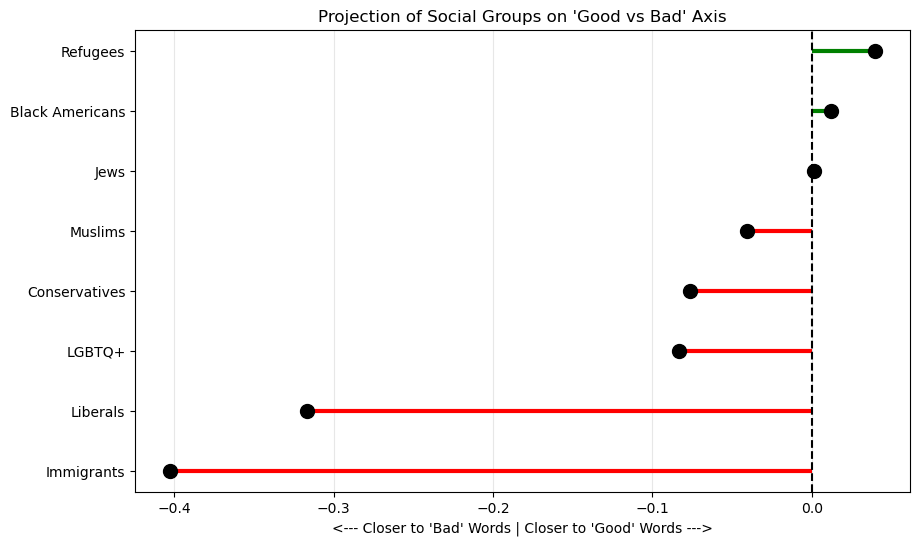

In [22]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt

# 1. Create Word Embeddings (WordVec) from your 'pure_text'
# We use min_df=2 to ignore very rare words
vectorizer = TfidfVectorizer(stop_words='english', min_df=2)
X = vectorizer.fit_transform(df['pure_text'].fillna(''))

# Transpose the matrix so we get Word Vectors (words as rows, docs as columns)
# Then reduce dimensions to create 50-dimensional 'embeddings'
svd = TruncatedSVD(n_components=50, random_state=42)
word_vectors = svd.fit_transform(X.T) 
word_to_idx = vectorizer.vocabulary_

def get_vec(word):
    word = word.lower().split()[0] # Take first word if it's a phrase
    return word_vectors[word_to_idx[word]] if word in word_to_idx else None

# Expanded Pole: Values, Humanity, and Safety
good_pole_words = [
    'support', 'equality', 'justice', 'welcome', 'contribution', 
    'community', 'respect', 'safety', 'rights', 'valuable',
    'humanity', 'inclusive', 'protect', 'fairness', 'solidarity'
]

# Expanded Pole: Threat, Dehumanization, and Conflict
bad_pole_words = [
    'threat', 'dangerous', 'toxic', 'illegal', 'hate', 
    'violence', 'radical', 'enemy', 'destroy', 'invasion',
    'extremist', 'biased', 'corrupt', 'burden', 'segregation'
]

# Average the vectors to get the "Anchor" for each pole
v_good = np.mean([get_vec(w) for w in good_pole_words if get_vec(w) is not None], axis=0)
v_bad = np.mean([get_vec(w) for w in bad_pole_words if get_vec(w) is not None], axis=0)

# 3. Define the Polarization Axis
v_axis = v_good - v_bad

# Mapping groups to their linguistic synonyms for a more robust group vector
group_synonyms = {
    'Black Americans': ['blacks',  'black-american', 'black-americans'],
    'Conservatives': ['conservatives', 'republicans', 'gop', 'rightwing','maga','far-right','far right','evangelical', 'alt-right','the right'],
    'Muslims': ['muslims', 'islamic', 'muslim'],
    'LGBTQ+': ['lgbtq', 'lgbt', 'gay', 'queer', 'transgender','trans', 'queers','lgbtq+', 'lesbian', 'lesbians','gays', 'bisextual', 'bisextuals'],
    'Immigrants': ['foreigners','illegals', 'immigrants', 'immigrat', 'migrants'],
    'Jews': ['jews', 'jewish', 'hebrews','israelites','jew'],
    'Liberals': ['liberals', 'democrats', 'lefts', 'far left', 'The left is', 'redical left','Dems', 'Antifa'],
    'Refugees': ['refugees',  'refugee']
}

robust_results = []

for group_name, synonyms in group_synonyms.items():
    # Get all available vectors for synonyms and average them
    vecs = [get_vec(s) for s in synonyms if get_vec(s) is not None]
    
    if vecs:
        v_group_robust = np.mean(vecs, axis=0)
        
        # Calculate Cosine Similarity to the axis for better normalization
        # Score = cos(theta) between group vector and polarization axis
        dot_product = np.dot(v_group_robust, v_axis)
        norms = np.linalg.norm(v_group_robust) * np.linalg.norm(v_axis)
        score = dot_product / norms
        
        robust_results.append({'Group': group_name, 'Score': score})

# 5. Visualization
results_df = pd.DataFrame(robust_results).sort_values(by='Score')

plt.figure(figsize=(10, 6))
plt.hlines(y=results_df['Group'], xmin=0, xmax=results_df['Score'], 
           color=['red' if x < 0 else 'green' for x in results_df['Score']], linewidth=3)
plt.plot(results_df['Score'], results_df['Group'], "o", markersize=10, color='black')
plt.axvline(0, color='black', linestyle='--')
plt.title("Projection of Social Groups on 'Good vs Bad' Axis")
plt.xlabel("<--- Closer to 'Bad' Words | Closer to 'Good' Words --->")
plt.grid(axis='x', alpha=0.3)
plt.show()

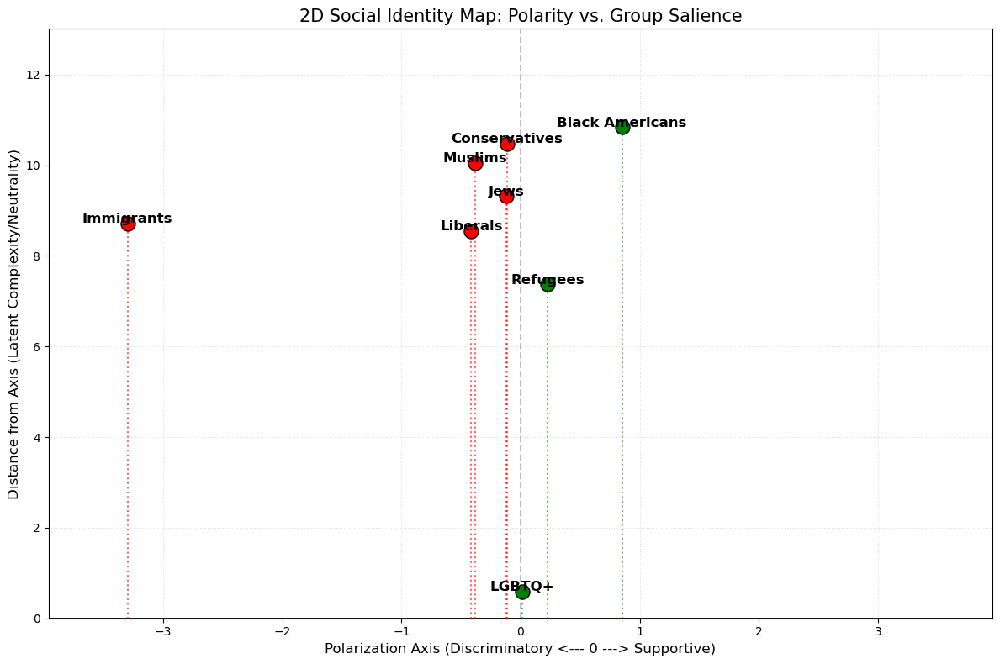

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

# 1. Prepare robust anchors
good_anchors = ['support', 'equality', 'justice', 'welcome', 'community', 'respect', 'safety', 'rights', 'humanity', 'fair']
bad_anchors = ['threat', 'dangerous', 'toxic', 'illegal', 'hate', 'violence', 'radical', 'enemy', 'extremist', 'harm']

# 2. Vectorization and Embedding (SVD for WordVec)
vectorizer = TfidfVectorizer(stop_words='english', min_df=2)
X = vectorizer.fit_transform(df['pure_text'].fillna(''))
svd = TruncatedSVD(n_components=100, random_state=42)
word_vecs = svd.fit_transform(X.T)
word_to_idx = vectorizer.vocabulary_

def get_v(word):
    w = word.lower().split()[0]
    return word_vecs[word_to_idx[w]] if w in word_to_idx else None

# 3. Define the Axis Vector (The 'Good-Bad' Direction)
v_good = np.mean([get_v(w) for w in good_anchors if get_v(w) is not None], axis=0)
v_bad = np.mean([get_v(w) for w in bad_anchors if get_v(w) is not None], axis=0)
v_axis = v_good - v_bad
v_axis_unit = v_axis / np.linalg.norm(v_axis)

# 4. Define the Social Groups (using synonyms for robustness)
group_map = {
    'Black Americans': ['black', 'african'],
    'Conservatives': ['conservatives', 'republicans', 'gop'],
    'Muslims': ['muslims', 'islamic'],
    'LGBTQ+': ['lgbtq', 'lgbt', 'gay', 'transgender'],
    'Immigrants': ['immigrants', 'migrants'],
    'Jews': ['jews', 'jewish'],
    'Liberals': ['liberals', 'democrats', 'progressive'],
    'Refugees': ['refugees', 'asylum']
}

# 5. Calculate 2D Coordinates (Projection and Rejection)
plot_data = []
for name, synonyms in group_map.items():
    vecs = [get_v(s) for s in synonyms if get_v(s) is not None]
    if vecs:
        v_g = np.mean(vecs, axis=0)
        
        # X-coordinate: Projection onto the Good-Bad axis
        x_coord = np.dot(v_g, v_axis_unit)
        
        # Y-coordinate: Perpendicular distance from the axis (Rejection)
        # This shows how much the group word varies outside of the good-bad spectrum
        v_orthogonal = v_g - (x_coord * v_axis_unit)
        y_coord = np.linalg.norm(v_orthogonal)
        
        plot_data.append({'Group': name, 'Polarity': x_coord, 'Distance': y_coord})

plot_df = pd.DataFrame(plot_data)

# 6. Create the 2D Plot
plt.figure(figsize=(12, 8))
plt.axvline(0, color='gray', linestyle='--', alpha=0.5) # The Neutral line
plt.axhline(0, color='black', linewidth=2) # The Polarization Axis

# Plot each group
for i, row in plot_df.iterrows():
    color = 'red' if row['Polarity'] < 0 else 'green'
    plt.scatter(row['Polarity'], row['Distance'], color=color, s=150, edgecolors='black', zorder=3)
    plt.text(row['Polarity'], row['Distance'] + 0.01, row['Group'], 
             fontsize=12, fontweight='bold', ha='center')
    
    # Draw "Distance" line from the axis to the point
    plt.vlines(x=row['Polarity'], ymin=0, ymax=row['Distance'], 
               colors=color, linestyles='dotted', alpha=0.6)

plt.title("2D Social Identity Map: Polarity vs. Group Salience", fontsize=15)
plt.xlabel("Polarization Axis (Discriminatory <--- 0 ---> Supportive)", fontsize=12)
plt.ylabel("Distance from Axis (Latent Complexity/Neutrality)", fontsize=12)
plt.grid(True, which='both', linestyle=':', alpha=0.4)

# Set limits to center the visualization
limit = max(abs(plot_df['Polarity'].min()), abs(plot_df['Polarity'].max())) * 1.2
plt.xlim(-limit, limit)
plt.ylim(0, plot_df['Distance'].max() * 1.2)

plt.tight_layout()
plt.show()

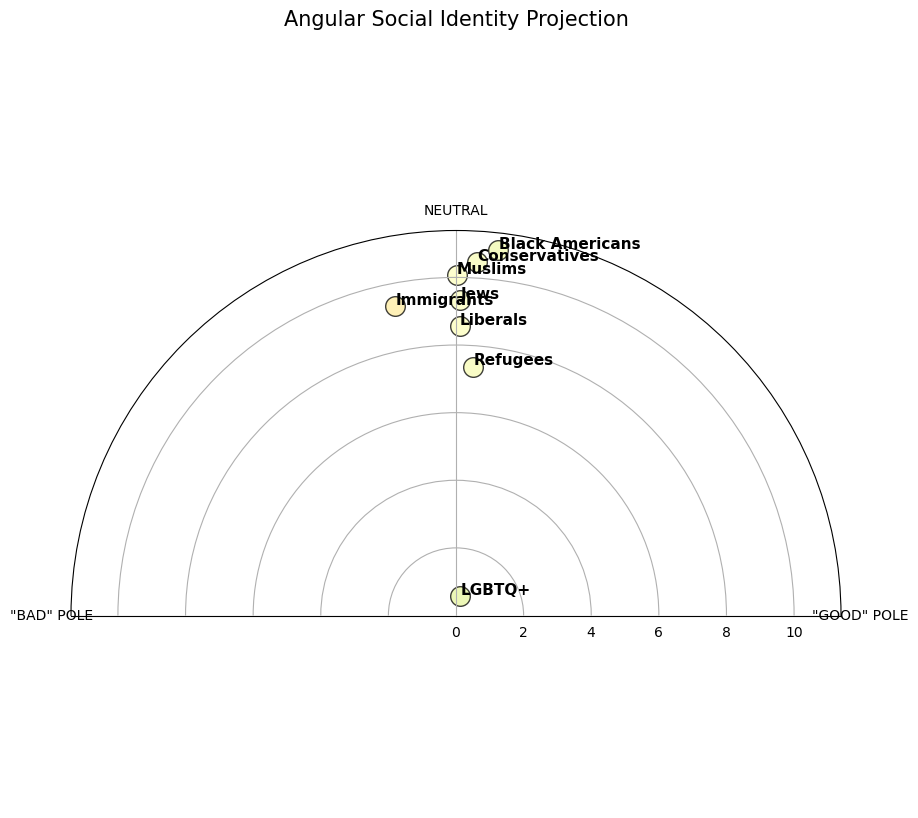

In [24]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# # 1. Calculate Cosine Similarity for the angles
# def cosine_sim(v1, v2):
#     return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

# results_polar = []
# for name, synonyms in group_map.items():
#     vecs = [get_v(s) for s in synonyms if get_v(s) is not None]
#     if vecs:
#         v_g = np.mean(vecs, axis=0)
        
#         # Calculate similarity to both poles
#         sim_good = cosine_sim(v_g, v_good)
#         sim_bad = cosine_sim(v_g, v_bad)
        
#         # Convert to an Angle (0 to PI)
#         # 0 = Aligned with Good, PI = Aligned with Bad
#         # We use the relative similarity to position the group on a 180-degree arc
#         angle = np.arccos(sim_good) / (np.arccos(sim_good) + np.arccos(sim_bad)) * np.pi
        
#         # Intensity (Radius) = The magnitude of the group vector's projection
#         intensity = np.linalg.norm(v_g)
        
#         results_polar.append({'Group': name, 'Angle': angle, 'Radius': intensity})

# df_polar = pd.DataFrame(results_polar)

# # 2. Create the Polar Plot
# fig = plt.figure(figsize=(10, 10))
# ax = fig.add_subplot(111, projection='polar')

# # Define the arc (0 to 180 degrees)
# ax.set_thetamin(0)
# ax.set_thetamax(180)

# # Plot each group
# for i, row in df_polar.iterrows():
#     color = plt.cm.RdYlGn(1 - (row['Angle'] / np.pi)) # Green for Good, Red for Bad
#     ax.scatter(row['Angle'], row['Radius'], color=color, s=200, edgecolors='k', alpha=0.75)
#     ax.text(row['Angle'], row['Radius'] + 0.05, row['Group'], fontsize=11, fontweight='bold')

# # Labels for the "Good" and "Bad" poles
# ax.set_xticks([0, np.pi/2, np.pi])
# ax.set_xticklabels(['"GOOD" POLE', 'NEUTRAL', '"BAD" POLE'])

# plt.title("Angular Social Identity Projection", va='bottom', fontsize=15)
# plt.show()

In [14]:
# Create a frequency table of Group vs Comment Type
pivot_table = pd.crosstab(df['MappedGroup'], df['CommentType'])

# Add a 'Total' column to see the sample size for each group
pivot_table['Total'] = pivot_table.sum(axis=1)

# Sort by discriminatory count to see which group is targeted most
#pivot_table = pivot_table.sort_values(by='discriminatory', ascending=False)

print(pivot_table)

CommentType      Critical  Discriminatory  Neutral  Supportive  Total
MappedGroup                                                          
Black Americans       388           34897       17        2550  37852
Conservatives        2263           43974        0          60  46297
Immigrants            778           18978        0         235  19991
Jews                  218           11221        3          94  11536
LGBTQ+                430            6499        0        6483  13412
Liberals             1043            8703        0         158   9904
Muslims               249           10135        0        1645  12029
Refugees               51            1795        0         379   2225


In [21]:
# 1. Create the raw frequency table
pivot_table = pd.crosstab(df['MappedGroup'], df['CommentType'])

# 2. Calculate the Percentage breakdown per group
# normalize='index' ensures each row (group) sums to 1.0 (100%)
percent_table = pd.crosstab(df['MappedGroup'], df['CommentType'], normalize='index') * 100

# 3. Combine for a comprehensive view (Optional but helpful)
# We join the total count to the percentage table
percent_table['Total_Count'] = pivot_table.sum(axis=1)

# Round to 2 decimal places for readability
percent_table = percent_table.round(2)

# Sort by discriminatory percentage to see the most polarized groups
#percent_table = percent_table.sort_values(by='discriminatory', ascending=False)

print("Percentage of Tweets per Group:")
print(percent_table)

Percentage of Tweets per Group:
CommentType      Critical  Discriminatory  Neutral  Supportive  Total_Count
MappedGroup                                                                
Black Americans      1.03           92.19     0.04        6.74        37852
Conservatives        4.89           94.98     0.00        0.13        46297
Immigrants           3.89           94.93     0.00        1.18        19991
Jews                 1.89           97.27     0.03        0.81        11536
LGBTQ+               3.21           48.46     0.00       48.34        13412
Liberals            10.53           87.87     0.00        1.60         9904
Muslims              2.07           84.25     0.00       13.68        12029
Refugees             2.29           80.67     0.00       17.03         2225


In [35]:
df.columns

Index(['Unnamed: 0', '_id', 'pure_text', 'rt_text', 'tweet_created_at',
       'tweet_id', 'user_id', 'user_created_at', 'fastText_lang',
       'fastText_conf', 'reply_to_id', 'LLM_Label', 'CommentType',
       'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup', 'year',
       'Topic'],
      dtype='object')

In [107]:
import pandas as pd

# Load the uploaded ousiometry lexicon file
lexicon_path = "ousiometry_data (1).txt"
df_lexicon = pd.read_csv(lexicon_path, sep='\t', engine='python')
df_lexicon.columns = [c.lower() for c in df_lexicon.columns]

df_lexicon.head(), df_lexicon.shape

(       word  valence   arousal  dominance  goodness    energy  structure  \
 0  aaaaaaah -0.02102  0.106034  -0.209155 -0.134677 -0.022548   0.191793   
 1     aaaah  0.01998  0.136034  -0.218155 -0.108079 -0.009215   0.233945   
 2  aardvark -0.07302 -0.009966  -0.063155 -0.091981 -0.030811   0.003154   
 3     aback -0.11502 -0.092966  -0.212155 -0.187590 -0.173363   0.040463   
 4    abacus  0.00998 -0.223966  -0.015155  0.034769 -0.194588  -0.106849   
 
       power    danger  structure.1  
 0 -0.111175  0.079288     0.191793  
 1 -0.082939  0.069907     0.233945  
 2 -0.086828  0.043254     0.003154  
 3 -0.255233  0.010060     0.040463  
 4 -0.113009 -0.162180    -0.106849  ,
 (20006, 10))

In [108]:
df_lexicon.columns

Index(['word', 'valence', 'arousal', 'dominance', 'goodness', 'energy',
       'structure', 'power', 'danger', 'structure.1'],
      dtype='str')

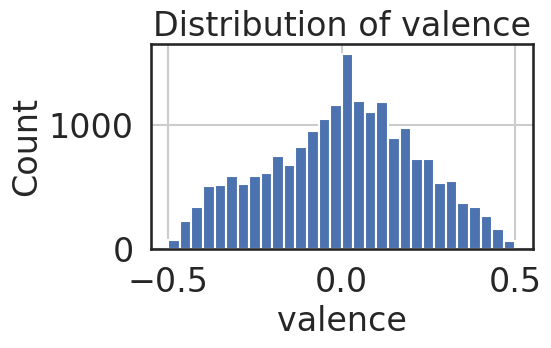

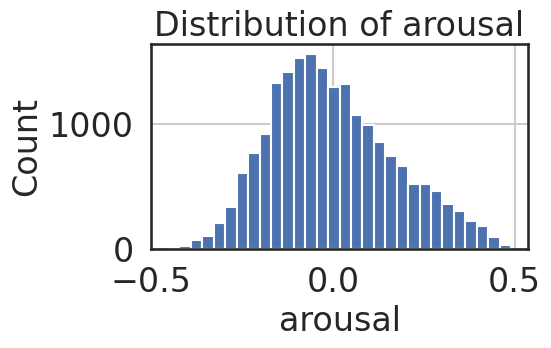

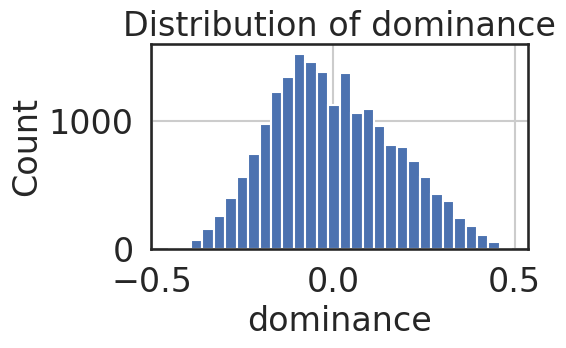

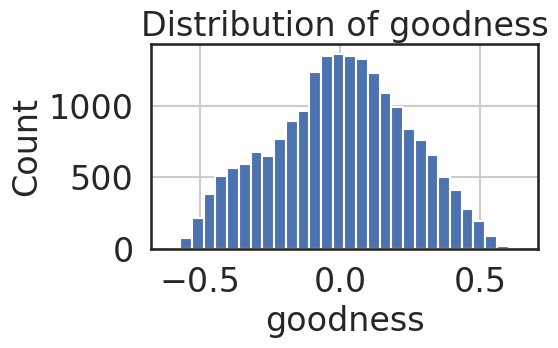

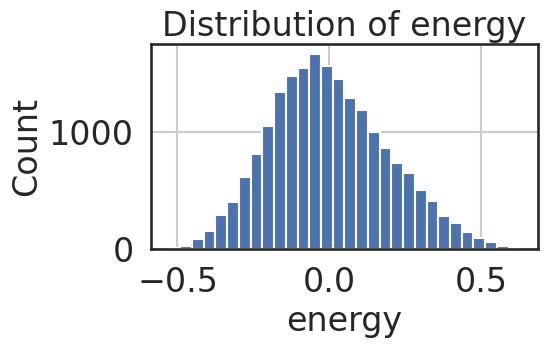

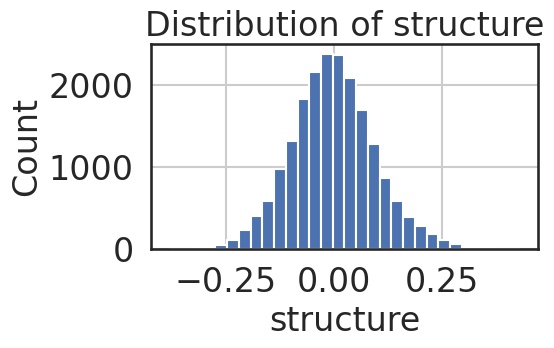

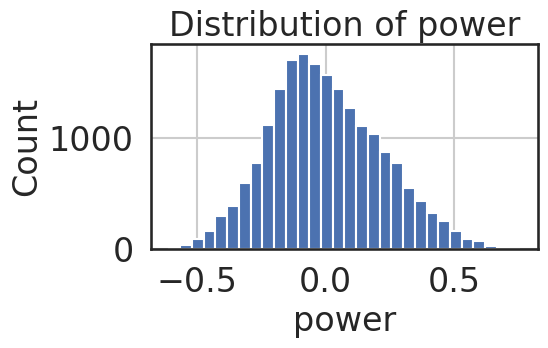

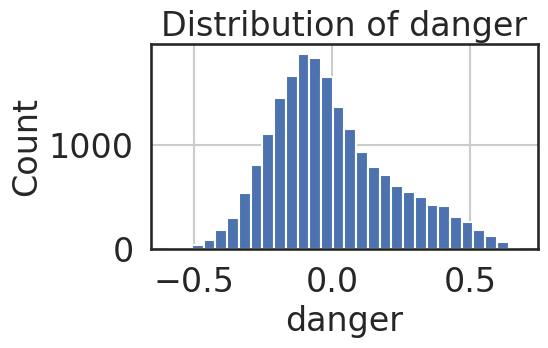

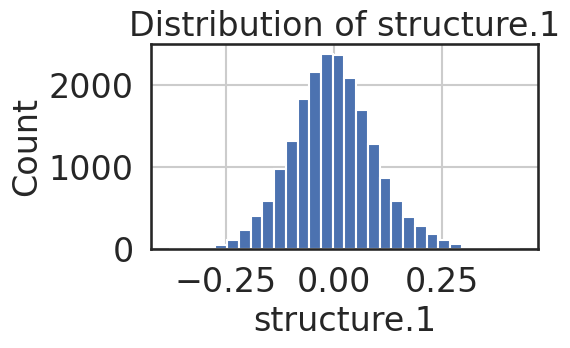

In [122]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a sample DataFrame with the given columns
# In a real scenario, you would load your data like:
# df_lexicon = pd.read_csv("ousiometry_data (1).txt", sep="\t", engine="python")

cols = ['word', 'valence', 'arousal', 'dominance', 'goodness', 'energy',
        'structure', 'power', 'danger', 'structure.1']

# Placeholder: create an empty df if not present
try:
    df_lexicon
except NameError:
    df_lexicon = pd.DataFrame(columns=cols)

# Convert all non-word columns to numeric (ignore errors)
num_cols = [c for c in df_lexicon.columns if c != "word"]
for c in num_cols:
    df_lexicon[c] = pd.to_numeric(df_lexicon[c], errors="coerce")

# Plot distribution (histogram) for each numeric column
for c in num_cols:
    plt.figure(figsize=(6,4))
    df_lexicon[c].dropna().hist(bins=30)
    plt.title(f"Distribution of {c}")
    plt.xlabel(c)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

In [123]:
# numeric columns (exclude word)
num_cols = df_lexicon.columns.drop("word")

# 75th percentile cutoffs
q75 = df_lexicon[num_cols].quantile(0.75)

# (A) rows that are top-quartile for EACH column simultaneously (intersection)
top_all = df_lexicon[df_lexicon[num_cols].ge(q75).all(axis=1)].copy()

# (B) rows that are top-quartile for AT LEAST ONE column (union)
top_any = df_lexicon[df_lexicon[num_cols].ge(q75).any(axis=1)].copy()

# (C) top-quartile sets per column (dictionary)
top_by_col = {c: df_lexicon[df_lexicon[c].ge(q75[c])].copy() for c in num_cols}

print("75th percentile cutoffs:\n", q75)
print("Rows in top quartile for ALL cols:", len(top_all))
print("Rows in top quartile for ANY col :", len(top_any))
print("Example: top quartile for power:", len(top_by_col["power"]))

75th percentile cutoffs:
 valence        0.152980
arousal        0.112034
dominance      0.119845
goodness       0.173326
energy         0.126721
structure      0.059556
power          0.147630
danger         0.128891
structure.1    0.059556
Name: 0.75, dtype: float64
Rows in top quartile for ALL cols: 5
Rows in top quartile for ANY col : 13385
Example: top quartile for power: 5002


In [131]:
# numeric columns (exclude word)
num_cols = [c for c in df_lexicon.columns if c != "word"]

# quartile cutoffs
q25 = df_lexicon[num_cols].quantile(0.5)
q75 = df_lexicon[num_cols].quantile(0.95)

# words in lowest/highest quartile for each column
quartile_words = {}
for c in num_cols:
    low_df  = df_lexicon.loc[df_lexicon[c] <= q25[c], ["word", c]].sort_values(c)
    high_df = df_lexicon.loc[df_lexicon[c] >= q75[c], ["word", c]].sort_values(c, ascending=False)
    quartile_words[c] = {"low": low_df, "high": high_df}

# example: see one column

# pick a column
col = "danger"

# LOW quartile: print ONLY words
print(" ".join(quartile_words[col]["low"]["word"].dropna().astype(str).tolist()))

# HIGH quartile: print ONLY words
print(" ".join(quartile_words[col]["high"]["word"].dropna().astype(str).tolist()))

calmness tranquil relaxant softness calming calm relaxed peace serenity pajama comfortable peacetime peaceful rest stressfree reassurance teddy bear angel natural sky napping harmony relaxation friendliness smooth tranquility peacefully siesta harmoniously relaxing teatime dream snug normality water relax quiet smoothly holy tenderness comfy easy serene gently kind rosary reassured restful nature meditation sunflower unwind honest tolerance confidence meditate bless sunset gentleness clean silk reliable blessing patience courtesy lullaby library biscuit agree neat normalcy accord homestead sincere peaceable goodness trustworthy charity yoga straightforward sanctuary humble sleep petal chill modest canvas aromatherapy soothe flower relieve fresh loyal pleasant angelic comfort blessed peaceofmind humility lavender fruit thankful sleeping obedient smoothness normal goodday lovable grape books floral union mildness spiritual cloud harmonica pacified easily painless blanket wisdom thank fri

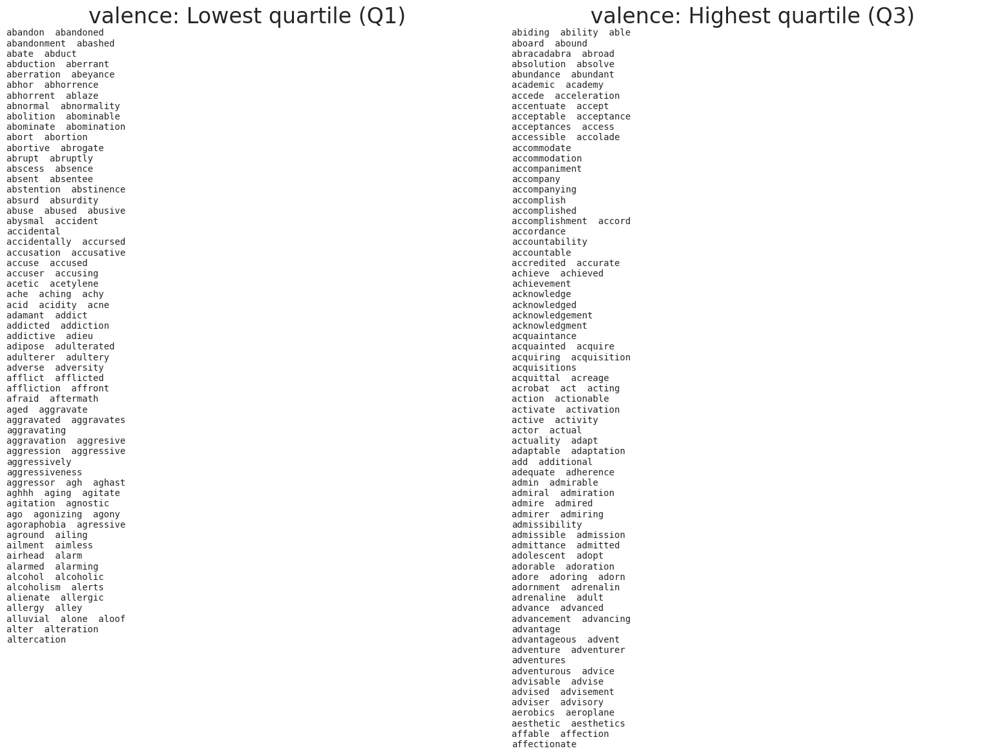

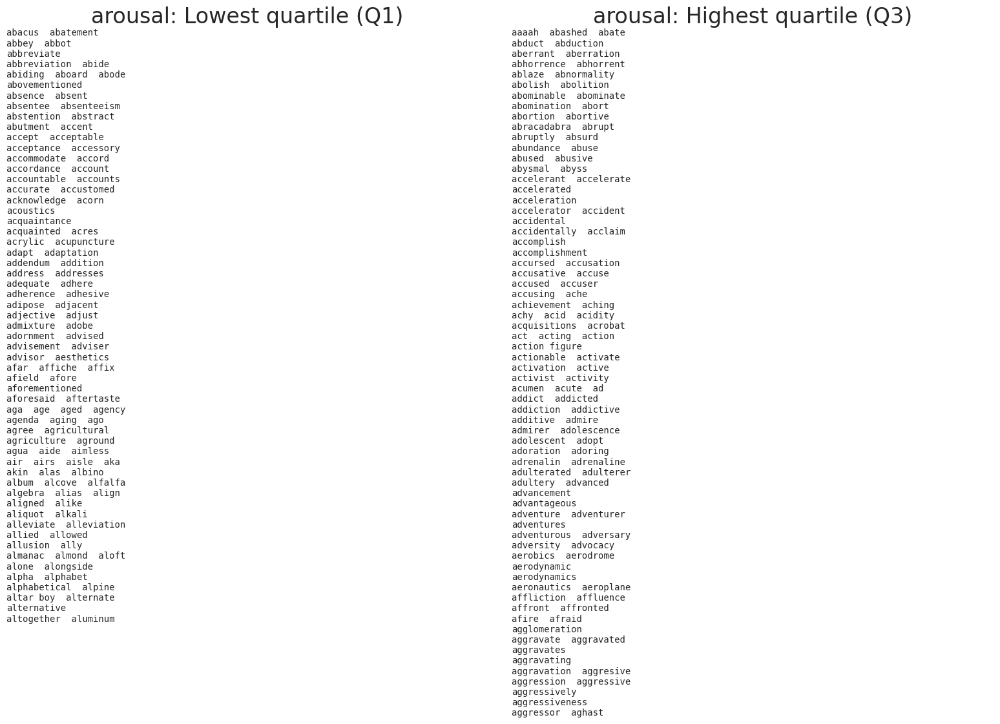

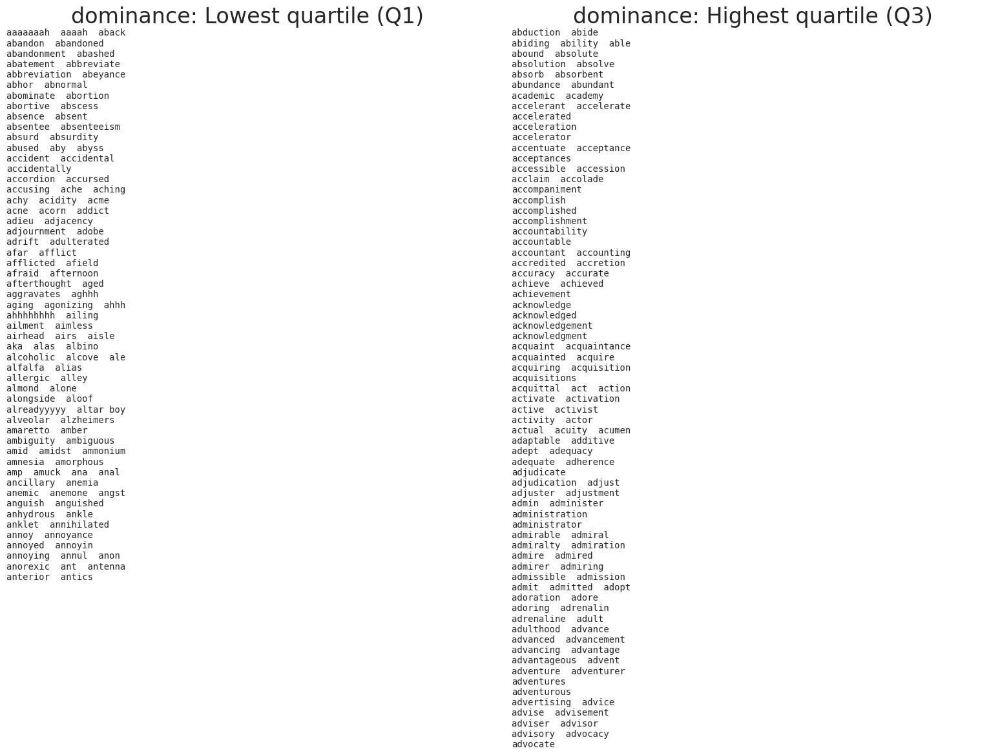

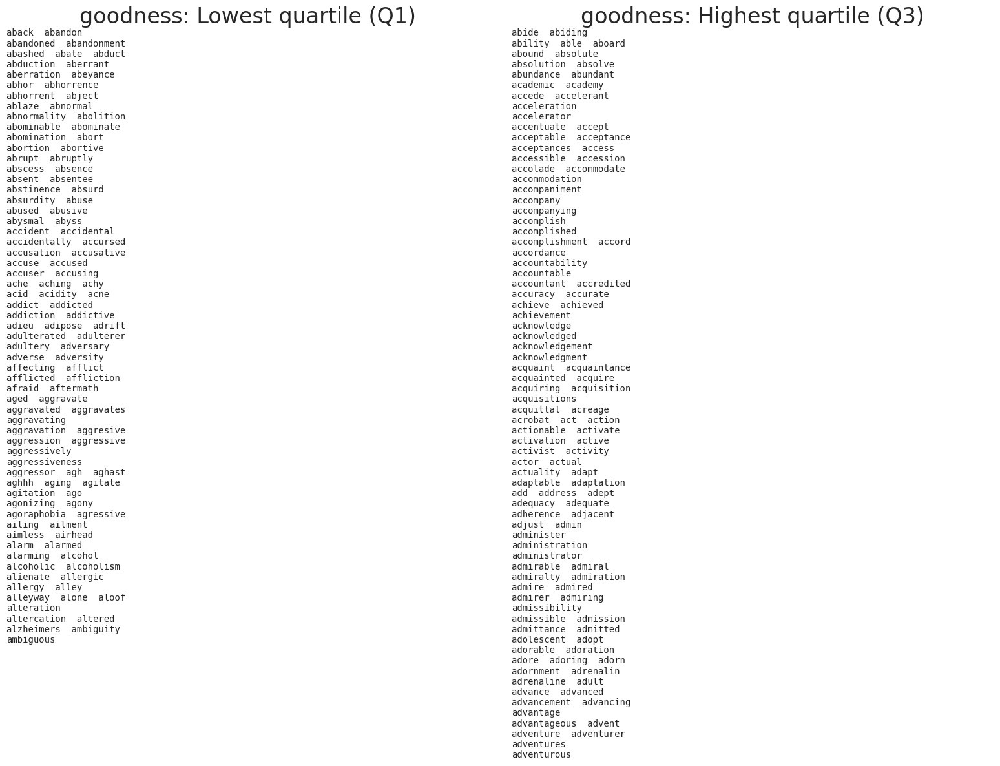

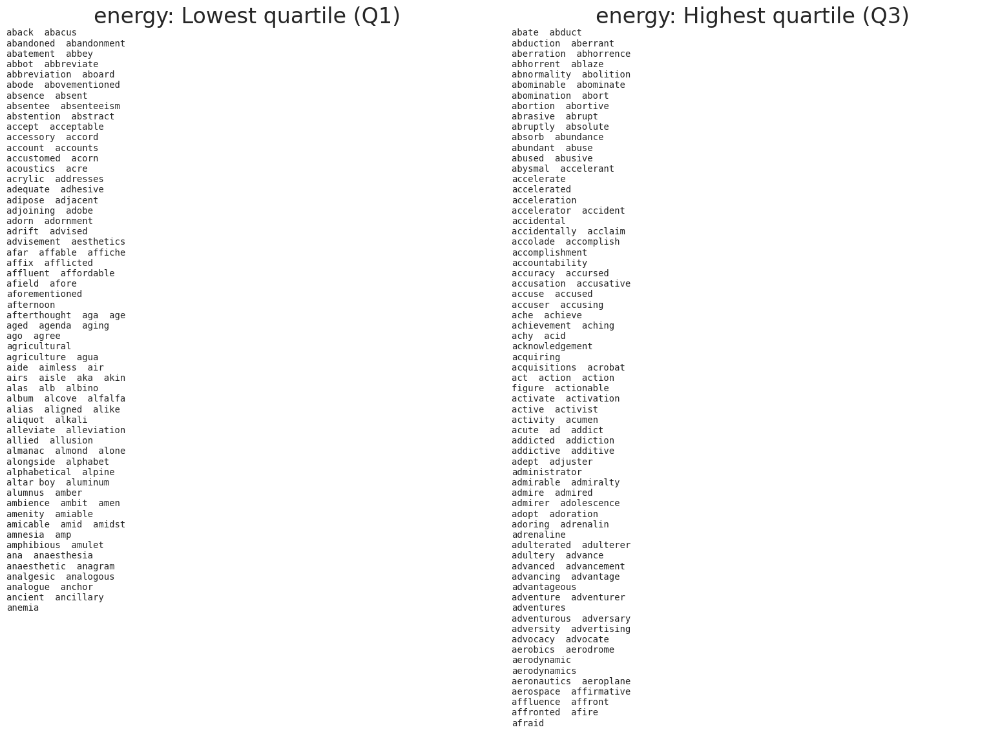

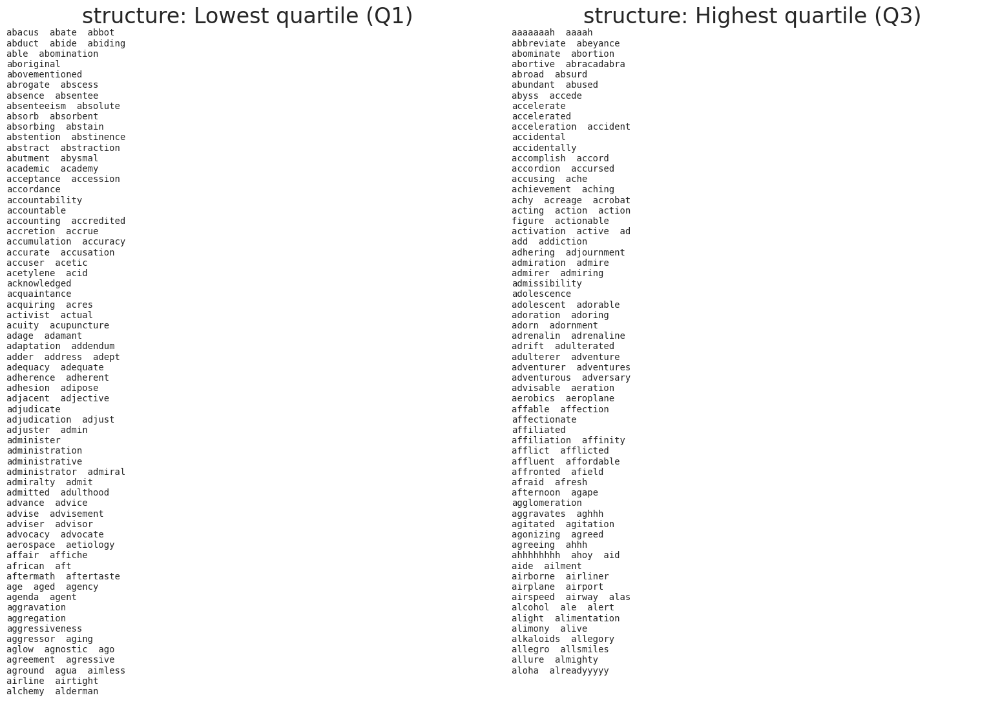

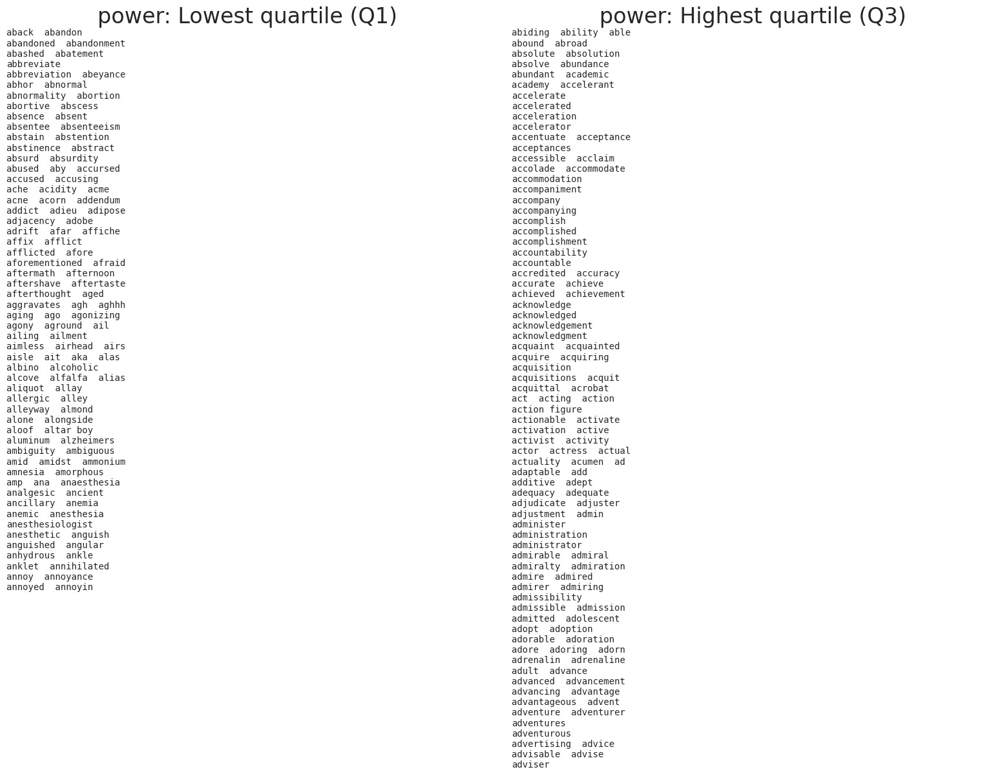

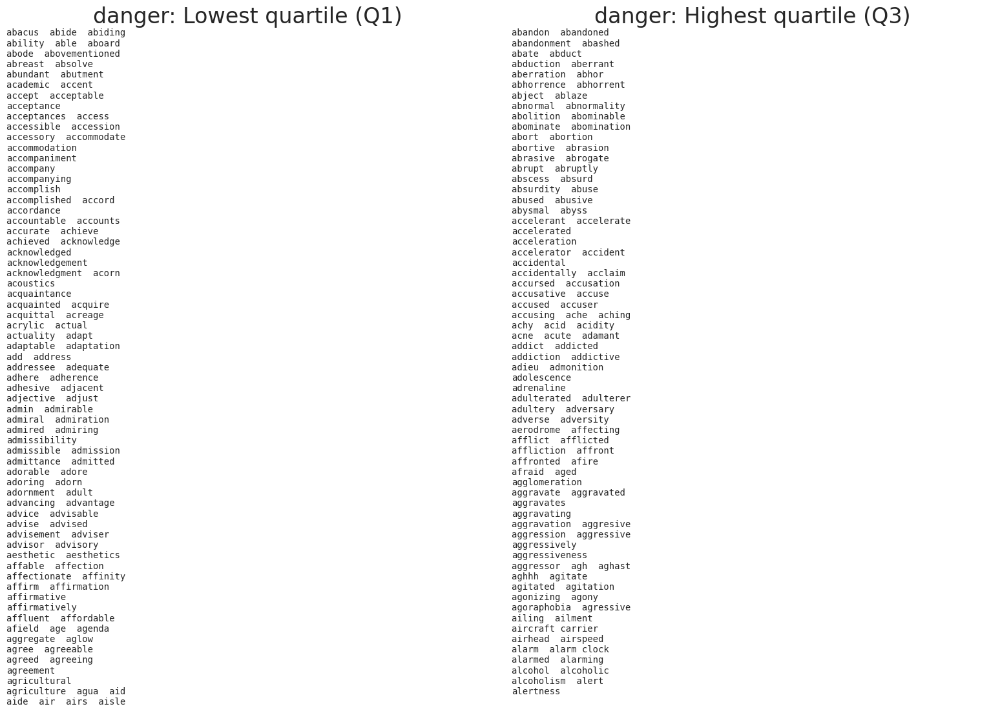

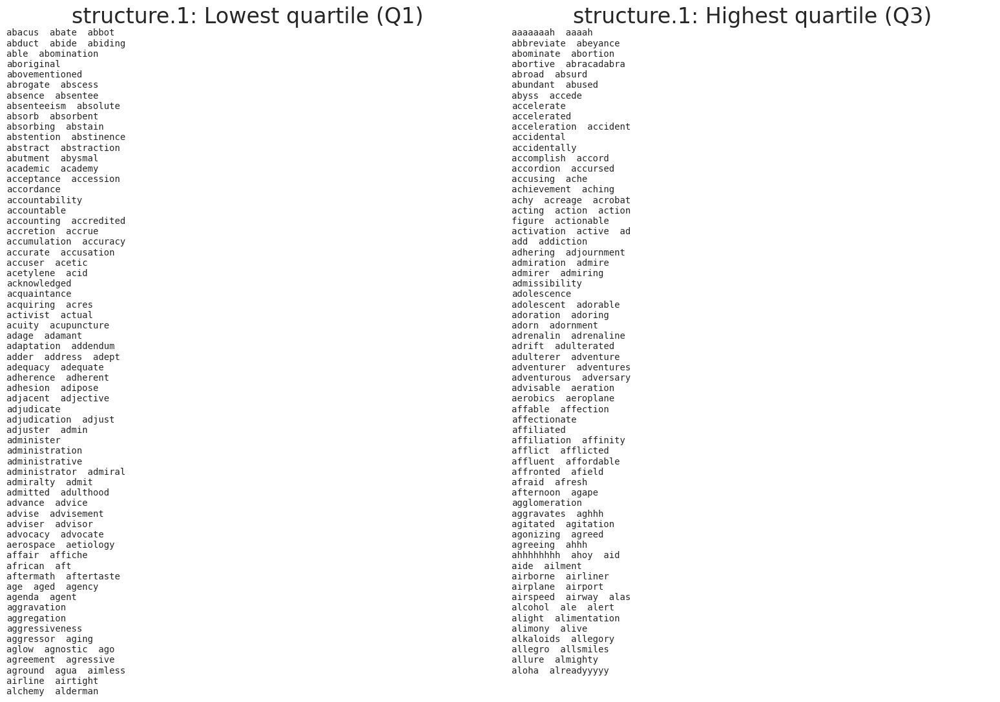

In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

# df_lexicon must already be loaded and must include a 'word' column
# Example: df_lexicon.columns -> ['word','valence','arousal','dominance','goodness','energy','structure','power','danger', ...]

def plot_quartile_words(df, col, n=120):
    d = df[['word', col]].dropna().copy()
    d['word'] = d['word'].astype(str)

    q1 = d[col].quantile(0.25)
    q3 = d[col].quantile(0.75)

    low_words  = d.loc[d[col] <= q1, 'word'].head(n).tolist()
    high_words = d.loc[d[col] >= q3, 'word'].head(n).tolist()

    def words_block(words, width=22):
        # wrap words into multiple lines (words only)
        s = "  ".join(words)
        return "\n".join(textwrap.wrap(s, width=width))

    fig, axes = plt.subplots(1, 2, figsize=(16, 10))
    for ax, title, words in [
        (axes[0], f"{col}: Lowest quartile (Q1)", low_words),
        (axes[1], f"{col}: Highest quartile (Q3)", high_words),
    ]:
        ax.axis("off")
        ax.set_title(title)
        ax.text(0, 1, words_block(words), va="top", ha="left", fontsize=10, family="monospace")

    plt.tight_layout()
    plt.show()

cols_to_plot = [c for c in df_lexicon.columns if c != "word"]
for col in cols_to_plot:
    plot_quartile_words(df_lexicon, col, n=120)

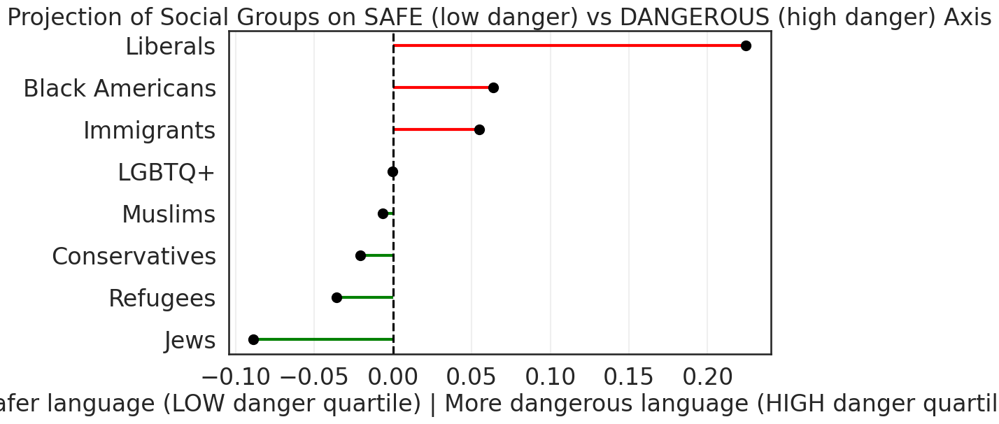

,Group,Score,RawProjection
5,Jews,-0.088787,-0.356130
7,Refugees,-0.035742,-0.236751
1,Conservatives,-0.020859,-0.105181
2,Muslims,-0.006424,-0.053664
3,LGBTQ+,-0.000077,-0.000017
4,Immigrants,0.054812,0.198728
0,Black Americans,0.063800,1.002349
6,Liberals,0.224376,1.152139


In [137]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt

# -----------------------------
# 0) Inputs you already have
# -----------------------------
# df['pure_text']  -> your corpus text
# df_lexicon       -> ousiometry dataframe with columns incl. 'word' and 'danger'
# (make sure df_lexicon['word'] is lowercase)
df_lexicon["word"] = df_lexicon["word"].astype(str).str.lower().str.strip()

# -----------------------------
# 1) Build word embeddings from your corpus (TF-IDF -> SVD)
# -----------------------------
vectorizer = TfidfVectorizer(stop_words="english", min_df=2)
X = vectorizer.fit_transform(df["pure_text"].fillna(""))

svd = TruncatedSVD(n_components=50, random_state=42)
word_vectors = svd.fit_transform(X.T)  # (n_words, 50)
word_to_idx = vectorizer.vocabulary_

def get_vec(word):
    word = str(word).lower().strip().split()[0]
    return word_vectors[word_to_idx[word]] if word in word_to_idx else None

def mean_vec(words):
    vecs = [get_vec(w) for w in words if get_vec(w) is not None]
    return np.mean(vecs, axis=0) if len(vecs) else None

# -----------------------------
# 2) LOW quartile = "safe", HIGH quartile = "dangerous" from ousiometry
#    (use 25/75 or keep your 10/90 if you want)
# -----------------------------
col = "danger"

q_low  = df_lexicon[col].quantile(0.05)   # change to 0.10 if you prefer
q_high = df_lexicon[col].quantile(0.95)   # change to 0.90 if you prefer

safe_words = df_lexicon.loc[df_lexicon[col] <= q_low,  "word"].tolist()
dang_words = df_lexicon.loc[df_lexicon[col] >= q_high, "word"].tolist()

v_safe = mean_vec(safe_words)
v_dang = mean_vec(dang_words)

# if v_safe is None or v_dang is None:
#     raise ValueError(
#         "Not enough overlap between your corpus vocab and ousiometry quartile words. "
#         "Try lowering min_df, using 0.10/0.90, or increasing corpus size."
#     )

# Axis points toward "dangerous"
v_axis = v_dang - v_safe
axis_norm = np.linalg.norm(v_axis)

def proj_score(v):
    """Cosine projection onto danger axis: negative=safer, positive=more dangerous."""
    return float(np.dot(v, v_axis) / (np.linalg.norm(v) * axis_norm))

# -----------------------------
# 3) Score your groups (same synonym dict)
# -----------------------------
group_synonyms = {
    'Black Americans': ['blacks','black-american','black-americans'],
    'Conservatives': ['conservatives','republicans','gop','rightwing','maga','far-right','far','evangelical','alt-right','right'],
    'Muslims': ['muslims','islamic','muslim'],
    'LGBTQ+': ['lgbtq','lgbt','gay','queer','transgender','trans','queers','lgbtq+','lesbian','lesbians','gays','bisexual','bisexuals'],
    'Immigrants': ['foreigners','illegals','immigrants','immigrant','migrants','migrant'],
    'Jews': ['jews','jewish','hebrews','israelites','jew'],
    'Liberals': ['liberals','democrats','lefts','left','far','dems','antifa'],
    'Refugees': ['refugees','refugee']
}

results = []
for group, syns in group_synonyms.items():
    vecs = [get_vec(s) for s in syns if get_vec(s) is not None]
    if not vecs:
        continue
    v_group = np.mean(vecs, axis=0)
    score = proj_score(v_group)
    results.append({"Group": group, "Score": score})

results_df = pd.DataFrame(results).sort_values("Score")

# -----------------------------
# 4) Plot (left=safe, right=dangerous)
# -----------------------------
plt.figure(figsize=(10, 6))
colors = ["green" if x < 0 else "red" for x in results_df["Score"]]
plt.hlines(y=results_df["Group"], xmin=0, xmax=results_df["Score"], color=colors, linewidth=3)
plt.plot(results_df["Score"], results_df["Group"], "o", markersize=10, color="black")
plt.axvline(0, color="black", linestyle="--")
plt.title("Projection of Social Groups on SAFE (low danger) vs DANGEROUS (high danger) Axis")
plt.xlabel("<--- Safer language (LOW danger quartile) | More dangerous language (HIGH danger quartile) --->")
plt.grid(axis="x", alpha=0.3)
plt.show()

# -----------------------------
# 5) If you want "distance" too (magnitude along axis)
# -----------------------------
# cosine score is normalized; raw projection length:
def raw_projection(v):
    return float(np.dot(v, v_axis) / axis_norm)

# Example: add raw projection
results_df["RawProjection"] = [
    raw_projection(np.mean([get_vec(s) for s in group_synonyms[g] if get_vec(s) is not None], axis=0))
    for g in results_df["Group"]
]
results_df

In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt

# -----------------------------
# 0) Inputs you already have
# -----------------------------
# df['pure_text']  -> your corpus text
# df_lexicon       -> ousiometry dataframe with columns incl. 'word' and 'danger'
# (make sure df_lexicon['word'] is lowercase)
df_lexicon["word"] = df_lexicon["word"].astype(str).str.lower().str.strip()

# -----------------------------
# 1) Build word embeddings from your corpus (TF-IDF -> SVD)
# -----------------------------
vectorizer = TfidfVectorizer(stop_words="english", min_df=2)
X = vectorizer.fit_transform(df["pure_text"].fillna(""))

svd = TruncatedSVD(n_components=50, random_state=42)
word_vectors = svd.fit_transform(X.T)  # (n_words, 50)
word_to_idx = vectorizer.vocabulary_

def get_vec(word):
    word = str(word).lower().strip().split()[0]
    return word_vectors[word_to_idx[word]] if word in word_to_idx else None

def mean_vec(words):
    vecs = [get_vec(w) for w in words if get_vec(w) is not None]
    return np.mean(vecs, axis=0) if len(vecs) else None

# -----------------------------
# 2) LOW quartile = "safe", HIGH quartile = "dangerous" from ousiometry
#    (use 25/75 or keep your 10/90 if you want)
# -----------------------------
col = "danger"

q_low  = df_lexicon[col].quantile(0.05)   # change to 0.10 if you prefer
q_high = df_lexicon[col].quantile(0.95)   # change to 0.90 if you prefer

safe_words = df_lexicon.loc[df_lexicon[col] <= q_low,  "word"].tolist()
dang_words = df_lexicon.loc[df_lexicon[col] >= q_high, "word"].tolist()

v_safe = mean_vec(safe_words)
v_dang = mean_vec(dang_words)

# if v_safe is None or v_dang is None:
#     raise ValueError(
#         "Not enough overlap between your corpus vocab and ousiometry quartile words. "
#         "Try lowering min_df, using 0.10/0.90, or increasing corpus size."
#     )

# Axis points toward "dangerous"
v_axis = v_dang - v_safe
axis_norm = np.linalg.norm(v_axis)

def proj_score(v):
    """Cosine projection onto danger axis: negative=safer, positive=more dangerous."""
    return float(np.dot(v, v_axis) / (np.linalg.norm(v) * axis_norm))

# -----------------------------
# 3) Score your groups (same synonym dict)
# -----------------------------
group_synonyms = {
    'Black Americans': ['blacks','black-american','black-americans'],
    'Conservatives': ['conservatives','republicans','gop','rightwing','maga','far-right','far','evangelical','alt-right','right'],
    'Muslims': ['muslims','islamic','muslim'],
    'LGBTQ+': ['lgbtq','lgbt','gay','queer','transgender','trans','queers','lgbtq+','lesbian','lesbians','gays','bisexual','bisexuals'],
    'Immigrants': ['foreigners','illegals','immigrants','immigrant','migrants','migrant'],
    'Jews': ['jews','jewish','hebrews','israelites','jew'],
    'Liberals': ['liberals','democrats','lefts','left','far','dems','antifa'],
    'Refugees': ['refugees','refugee']
}

results = []
for group, syns in group_synonyms.items():
    vecs = [get_vec(s) for s in syns if get_vec(s) is not None]
    if not vecs:
        continue
    v_group = np.mean(vecs, axis=0)
    score = proj_score(v_group)
    results.append({"Group": group, "Score": score})

results_df = pd.DataFrame(results).sort_values("Score")

# -----------------------------
# 4) Plot (left=safe, right=dangerous)
# -----------------------------
plt.figure(figsize=(10, 6))
colors = ["green" if x < 0 else "red" for x in results_df["Score"]]
plt.hlines(y=results_df["Group"], xmin=0, xmax=results_df["Score"], color=colors, linewidth=3)
plt.plot(results_df["Score"], results_df["Group"], "o", markersize=10, color="black")
plt.axvline(0, color="black", linestyle="--")
plt.title("Projection of Social Groups on SAFE (low danger) vs DANGEROUS (high danger) Axis")
plt.xlabel("<--- Safer language (LOW danger quartile) | More dangerous language (HIGH danger quartile) --->")
plt.grid(axis="x", alpha=0.3)
plt.show()

# -----------------------------
# 5) If you want "distance" too (magnitude along axis)
# -----------------------------
# cosine score is normalized; raw projection length:
def raw_projection(v):
    return float(np.dot(v, v_axis) / axis_norm)

# Example: add raw projection
results_df["RawProjection"] = [
    raw_projection(np.mean([get_vec(s) for s in group_synonyms[g] if get_vec(s) is not None], axis=0))
    for g in results_df["Group"]
]
results_df

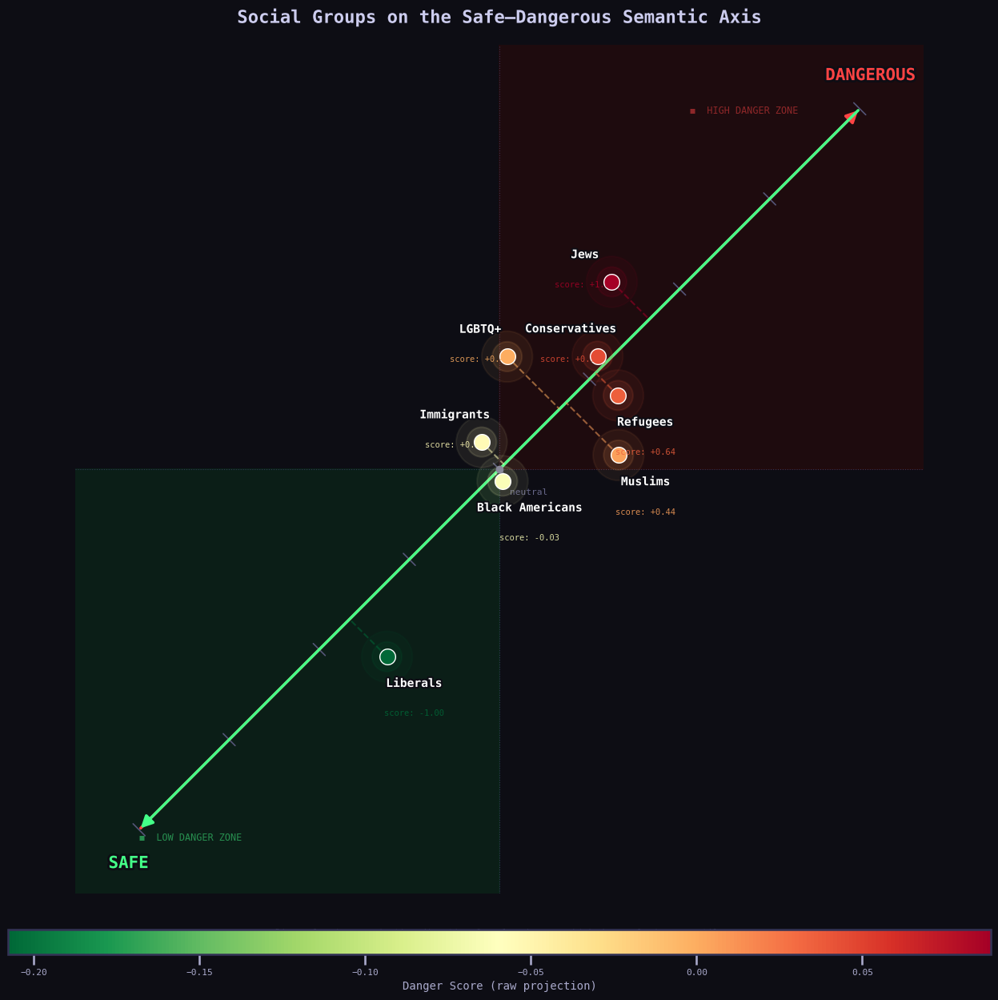

In [138]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe

# -----------------------------
# 0) Inputs you already have
# -----------------------------
# df['pure_text']  -> your corpus text
# df_lexicon       -> ousiometry dataframe with columns incl. 'word' and 'danger'
df_lexicon["word"] = df_lexicon["word"].astype(str).str.lower().str.strip()

# -----------------------------
# 1) Build word embeddings (TF-IDF -> SVD)
# -----------------------------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

vectorizer = TfidfVectorizer(stop_words="english", min_df=2)
X = vectorizer.fit_transform(df["pure_text"].fillna(""))

svd = TruncatedSVD(n_components=50, random_state=42)
word_vectors = svd.fit_transform(X.T)
word_to_idx = vectorizer.vocabulary_

def get_vec(word):
    word = str(word).lower().strip().split()[0]
    return word_vectors[word_to_idx[word]] if word in word_to_idx else None

def mean_vec(words):
    vecs = [get_vec(w) for w in words if get_vec(w) is not None]
    return np.mean(vecs, axis=0) if len(vecs) else None

# -----------------------------
# 2) Build safe/danger axis
# -----------------------------
col = "danger"
q_low  = df_lexicon[col].quantile(0.05)
q_high = df_lexicon[col].quantile(0.95)

safe_words = df_lexicon.loc[df_lexicon[col] <= q_low,  "word"].tolist()
dang_words = df_lexicon.loc[df_lexicon[col] >= q_high, "word"].tolist()

v_safe = mean_vec(safe_words)
v_dang = mean_vec(dang_words)

v_axis = v_safe - v_dang
axis_norm = np.linalg.norm(v_axis)

def proj_score(v):
    return float(np.dot(v, v_axis) / (np.linalg.norm(v) * axis_norm))

# -----------------------------
# 3) Score groups
# -----------------------------
group_synonyms = {
    'Black Americans': ['blacks','black-american','black-americans'],
    'Conservatives': ['conservatives','republicans','gop','rightwing','maga','far-right','evangelical','alt-right','right'],
    'Muslims': ['muslims','islamic','muslim'],
    'LGBTQ+': ['lgbtq','lgbt','gay','queer','transgender','trans','queers','lgbtq+','lesbian','lesbians','gays','bisexual'],
    'Immigrants': ['foreigners','illegals','immigrants','immigrant','migrants','migrant'],
    'Jews': ['jews','jewish','hebrews','israelites','jew'],
    'Liberals': ['liberals','democrats','lefts','left','dems','antifa'],
    'Refugees': ['refugees','refugee']
}

results = []
for group, syns in group_synonyms.items():
    vecs = [get_vec(s) for s in syns if get_vec(s) is not None]
    if not vecs:
        continue
    v_group = np.mean(vecs, axis=0)
    score = proj_score(v_group)
    results.append({"Group": group, "Score": score})

results_df = pd.DataFrame(results).sort_values("Score").reset_index(drop=True)

# -----------------------------
# 4) Map scores to 45° diagonal axis
# -----------------------------
scores = results_df["Score"].values
score_min, score_max = scores.min(), scores.max()

# Normalize scores to [-1, 1] range
scores_norm = 2 * (scores - score_min) / (score_max - score_min) - 1

# 45° axis direction
ANGLE = 45
angle_rad = np.radians(ANGLE)
axis_dir = np.array([np.cos(angle_rad), np.sin(angle_rad)])
perp_dir = np.array([-np.sin(angle_rad), np.cos(angle_rad)])

# Points along the main diagonal axis
axis_points = np.outer(scores_norm, axis_dir)

# Spread groups perpendicularly to avoid overlap
# Sort by score and stagger
n = len(results_df)
perp_offsets = np.linspace(-0.35, 0.35, n)
# Reorder offsets to alternate (reduce overlap for similar scores)
perp_offsets = perp_offsets[np.argsort(np.argsort(scores_norm) % 2 == 0)]

group_points = axis_points + np.outer(perp_offsets, perp_dir)

# -----------------------------
# 5) PLOT
# -----------------------------
fig, ax = plt.subplots(figsize=(13, 13))
fig.patch.set_facecolor("#0d0d14")
ax.set_facecolor("#0d0d14")

# --- Background gradient zones ---
from matplotlib.patches import Polygon as MplPolygon

# Safe zone (bottom-left)
safe_poly = plt.Polygon(
    [[-2.2, -2.2], [0.0, -2.2], [0.0, 0.0], [-2.2, 0.0]],
    closed=True, color="#0a2a1a", zorder=0, alpha=0.6
)
ax.add_patch(safe_poly)

# Danger zone (top-right)
danger_poly = plt.Polygon(
    [[0.0, 0.0], [2.2, 0.0], [2.2, 2.2], [0.0, 2.2]],
    closed=True, color="#2a0a0a", zorder=0, alpha=0.6
)
ax.add_patch(danger_poly)

# Mixed zones
ax.fill_between([-2.2, 2.2], [-2.2, -2.2], [0.0, 0.0],
                where=[True, True], alpha=0.0)

# --- Main diagonal axis line ---
axis_extent = 1.7
ax.annotate("", xy=(axis_extent, axis_extent), xytext=(-axis_extent, -axis_extent),
            arrowprops=dict(arrowstyle="-|>", color="#ff4444", lw=2.5,
                            mutation_scale=22, connectionstyle="arc3,rad=0"))
ax.annotate("", xy=(-axis_extent, -axis_extent), xytext=(axis_extent, axis_extent),
            arrowprops=dict(arrowstyle="-|>", color="#44ff88", lw=2.5,
                            mutation_scale=22, connectionstyle="arc3,rad=0"))

# Axis labels
ax.text(axis_extent + 0.05, axis_extent + 0.12,
        "DANGEROUS", fontsize=15, fontweight="bold",
        color="#ff4444", ha="center", va="bottom",
        fontfamily="monospace",
        path_effects=[pe.withStroke(linewidth=4, foreground="#0d0d14")])

ax.text(-axis_extent - 0.05, -axis_extent - 0.12,
        "SAFE", fontsize=15, fontweight="bold",
        color="#44ff88", ha="center", va="top",
        fontfamily="monospace",
        path_effects=[pe.withStroke(linewidth=4, foreground="#0d0d14")])

# Subtle axis tick marks along the diagonal
for t in np.linspace(-1, 1, 9):
    pt = t * np.array([axis_extent, axis_extent])
    tick_len = 0.04
    tick_start = pt - tick_len * perp_dir
    tick_end   = pt + tick_len * perp_dir
    ax.plot([tick_start[0], tick_end[0]], [tick_start[1], tick_end[1]],
            color="#555577", lw=1.2, zorder=2)

# --- Color map: green (safe) → red (danger) ---
cmap = plt.cm.RdYlGn_r
norm = Normalize(vmin=score_min, vmax=score_max)

for i, row in results_df.iterrows():
    gx, gy = group_points[i]
    score = row["Score"]
    color = cmap(norm(score))

    # Foot of perpendicular on axis
    foot = axis_points[i]
    fx, fy = foot

    # Drop line from group point to axis (dashed)
    ax.plot([gx, fx], [gy, fy],
            color=color, lw=1.5, linestyle="--", alpha=0.55, zorder=3)

    # Glowing halo
    for radius, alpha in [(0.12, 0.07), (0.07, 0.12), (0.035, 0.22)]:
        circle = plt.Circle((gx, gy), radius, color=color, alpha=alpha, zorder=4)
        ax.add_patch(circle)

    # Main dot
    ax.scatter(gx, gy, s=200, color=color, zorder=5,
               edgecolors="white", linewidths=1.0)

    # Distance annotation (raw score label)
    dist_from_center = scores_norm[i]
    sign = "+" if dist_from_center >= 0 else ""

    # Label offset — push label away from axis
    label_offset = perp_dir * (0.18 if perp_offsets[i] >= 0 else -0.18)
    lx, ly = gx + label_offset[0], gy + label_offset[1]

    ax.text(lx, ly, row["Group"],
            fontsize=10.5, fontweight="bold", color="white",
            ha="center", va="center", fontfamily="monospace",
            path_effects=[pe.withStroke(linewidth=3, foreground="#0d0d14")],
            zorder=6)

    # Score below group name
    ax.text(lx, ly - 0.14, f"score: {sign}{dist_from_center:.2f}",
            fontsize=7.5, color=color, ha="center", va="center",
            fontfamily="monospace", alpha=0.85, zorder=6)

# --- Colorbar ---
sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation="horizontal",
                    fraction=0.03, pad=0.04, aspect=40,
                    location="bottom")
cbar.set_label("Danger Score (raw projection)", color="#aaaacc",
               fontsize=10, fontfamily="monospace")
cbar.ax.xaxis.set_tick_params(color="#aaaacc")
plt.setp(cbar.ax.xaxis.get_ticklabels(), color="#aaaacc", fontsize=8,
         fontfamily="monospace")
cbar.outline.set_edgecolor("#333355")

# --- Origin crosshair ---
ax.axhline(0, color="#333355", lw=0.8, zorder=1, linestyle=":")
ax.axvline(0, color="#333355", lw=0.8, zorder=1, linestyle=":")
ax.plot(0, 0, "o", color="#888899", markersize=6, zorder=4)
ax.text(0.05, -0.12, "neutral", fontsize=8, color="#666688",
        fontfamily="monospace")

# --- Grid & frame ---
ax.set_xlim(-2.0, 2.0)
ax.set_ylim(-2.0, 2.0)
ax.set_aspect("equal")
ax.axis("off")

# Corner zone labels
ax.text(-1.7, -1.75, "◼  LOW DANGER ZONE", fontsize=8.5,
        color="#44ff88", alpha=0.5, fontfamily="monospace")
ax.text(0.9, 1.68, "◼  HIGH DANGER ZONE", fontsize=8.5,
        color="#ff4444", alpha=0.5, fontfamily="monospace")

# --- Title ---
ax.set_title("Social Groups on the Safe–Dangerous Semantic Axis",
             fontsize=16, fontweight="bold", color="#ccccee",
             fontfamily="monospace", pad=20,
             path_effects=[pe.withStroke(linewidth=3, foreground="#0d0d14")])

ax.text(0.5, -0.06,
        "Diagonal axis = projection direction from low-danger → high-danger lexicon quartile\n"
        "Dashed lines = perpendicular distance from axis  |  Score = cosine projection",
        transform=ax.transAxes, ha="center", fontsize=8,
        color="#666688", fontfamily="monospace")

plt.tight_layout()
# plt.savefig("/mnt/user-data/outputs/danger_axis_plot.png", dpi=180,
#             bbox_inches="tight", facecolor=fig.get_facecolor())
# plt.show()
# print("Saved to /mnt/user-data/outputs/danger_axis_plot.png")

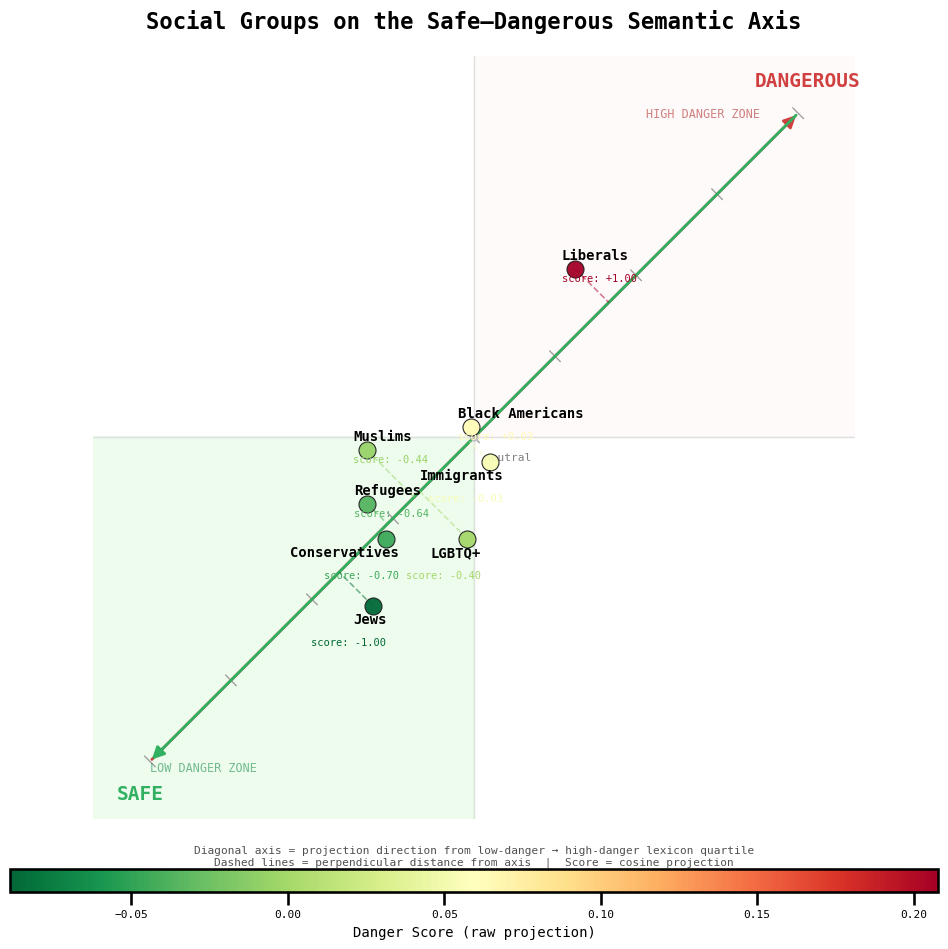

In [139]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# ==============================================================================
# PART 1: CORE DATA PROCESSING (Kept identical to original input)
# ==============================================================================
# df['pure_text'] -> your corpus text
# df_lexicon     -> ousiometry dataframe with columns incl. 'word' and 'danger'

# --- 1) Build word embeddings (TF-IDF -> SVD) ---
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

# IMPORTANT: I have retained your min_df=2 parameter to preserve the embedding space
vectorizer = TfidfVectorizer(stop_words="english", min_df=2)
# Ensure the text column is used (fillna in case of empty cells)
X = vectorizer.fit_transform(df["pure_text"].fillna(""))

svd = TruncatedSVD(n_components=50, random_state=42)
word_vectors = svd.fit_transform(X.T)
word_to_idx = vectorizer.vocabulary_

def get_vec(word):
    word = str(word).lower().strip().split()[0]
    return word_vectors[word_to_idx[word]] if word in word_to_idx else None

def mean_vec(words):
    vecs = [get_vec(w) for w in words if get_vec(w) is not None]
    return np.mean(vecs, axis=0) if len(vecs) else None

# --- 2) Build safe/danger axis ---
col = "danger"
# I use your quantile logic to define the axis directions
q_low  = df_lexicon[col].quantile(0.05)
q_high = df_lexicon[col].quantile(0.95)

safe_words = df_lexicon.loc[df_lexicon[col] <= q_low,  "word"].tolist()
dang_words = df_lexicon.loc[df_lexicon[col] >= q_high, "word"].tolist()

v_safe = mean_vec(safe_words)
v_dang = mean_vec(dang_words)

v_axis = v_dang - v_safe
axis_norm = np.linalg.norm(v_axis)

def proj_score(v):
    return float(np.dot(v, v_axis) / (np.linalg.norm(v) * axis_norm))

# --- 3) Score groups ---
# I use your synonym groups mapping
group_synonyms = {
    'Black Americans': ['blacks','black-american','black-americans'],
    'Conservatives': ['conservatives','republicans','gop','rightwing','maga','far-right','evangelical','alt-right','right'],
    'Muslims': ['muslims','islamic','muslim'],
    'LGBTQ+': ['lgbtq','lgbt','gay','queer','transgender','trans','queers','lgbtq+','lesbian','lesbians','gays','bisexual'],
    'Immigrants': ['foreigners','illegals','immigrants','immigrant','migrants','migrant'],
    'Jews': ['jews','jewish','hebrews','israelites','jew'],
    'Liberals': ['liberals','democrats','lefts','left','dems','antifa'],
    'Refugees': ['refugees','refugee']
}

results = []
for group, syns in group_synonyms.items():
    vecs = [get_vec(s) for s in syns if get_vec(s) is not None]
    if not vecs:
        continue
    v_group = np.mean(vecs, axis=0)
    score = proj_score(v_group)
    results.append({"Group": group, "Score": score})

results_df = pd.DataFrame(results).sort_values("Score").reset_index(drop=True)

# --- 4) Map scores to 45° diagonal axis ---
# I use your spread and alternate offset logic for visualization
scores = results_df["Score"].values
score_min, score_max = scores.min(), scores.max()

# Normalize scores to [-1, 1] range
scores_norm = 2 * (scores - score_min) / (score_max - score_min) - 1

# 45° axis direction
ANGLE = 45
angle_rad = np.radians(ANGLE)
axis_dir = np.array([np.cos(angle_rad), np.sin(angle_rad)])
perp_dir = np.array([-np.sin(angle_rad), np.cos(angle_rad)])

# Points along the main diagonal axis
axis_points = np.outer(scores_norm, axis_dir)

# Spread groups perpendicularly to avoid overlap
n = len(results_df)
# I use your spreading logic
perp_offsets = np.linspace(-0.35, 0.35, n)
# Alternate offsets to reduce overlap
perp_offsets = perp_offsets[np.argsort(np.argsort(scores_norm) % 2 == 0)]

group_points = axis_points + np.outer(perp_offsets, perp_dir)

# ==============================================================================
# PART 2: PAPER-READY VISUALIZATION (Updated to White Background)
# ==============================================================================
# We set figure size and resolution for print publication
fig, ax = plt.subplots(figsize=(10, 10), dpi=100)
# White background for paper ready figure
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# --- Background gradient zones (Research Paper suitable, very light fills) ---
# Safe zone (bottom-left) -> Light green
safe_poly = MplPolygon(
    [[-2.2, -2.2], [0.0, -2.2], [0.0, 0.0], [-2.2, 0.0]],
    closed=True, color="lightgreen", zorder=0, alpha=0.15 # Very subtle
)
ax.add_patch(safe_poly)

# Danger zone (top-right) -> Light red/misty rose
danger_poly = MplPolygon(
    [[0.0, 0.0], [2.2, 0.0], [2.2, 2.2], [0.0, 2.2]],
    closed=True, color="mistyrose", zorder=0, alpha=0.15 # Very subtle
)
ax.add_patch(danger_poly)

# --- Main diagonal axis line ---
axis_extent = 1.7
# Arrow directions are preserved, colors adjusted for light background
# DANGEROUS Direction
ax.annotate("", xy=(axis_extent, axis_extent), xytext=(-axis_extent, -axis_extent),
            arrowprops=dict(arrowstyle="-|>", color="#D04040", lw=2.0, # Legible red
                            mutation_scale=18, connectionstyle="arc3,rad=0"))
# SAFE Direction
ax.annotate("", xy=(-axis_extent, -axis_extent), xytext=(axis_extent, axis_extent),
            arrowprops=dict(arrowstyle="-|>", color="#30B060", lw=2.0, # Legible green
                            mutation_scale=18, connectionstyle="arc3,rad=0"))

# Axis labels (Colors switched to legible alternatives, path effects removed)
ax.text(axis_extent + 0.05, axis_extent + 0.12,
        "DANGEROUS", fontsize=14, fontweight="bold",
        color="#D04040", ha="center", va="bottom",
        fontfamily="monospace")

ax.text(-axis_extent - 0.05, -axis_extent - 0.12,
        "SAFE", fontsize=14, fontweight="bold",
        color="#30B060", ha="center", va="top",
        fontfamily="monospace")

# Subtle axis tick marks along the diagonal
for t in np.linspace(-1, 1, 9):
    pt = t * np.array([axis_extent, axis_extent])
    tick_len = 0.04
    tick_start = pt - tick_len * perp_dir
    tick_end   = pt + tick_len * perp_dir
    # Changed to light gray for paper ready figure
    ax.plot([tick_start[0], tick_end[0]], [tick_start[1], tick_end[1]],
            color="#A0A0A0", lw=1.0, zorder=2)

# --- Color map: green (safe) → red (danger) ---
# Maintained the original color map logic
cmap = plt.cm.RdYlGn_r
norm = Normalize(vmin=score_min, vmax=score_max)

# I have retained all group positioning and alternate offset logic
for i, row in results_df.iterrows():
    gx, gy = group_points[i]
    score = row["Score"]
    color = cmap(norm(score))

    # Foot of perpendicular on axis
    foot = axis_points[i]
    fx, fy = foot

    # Drop line from group point to axis (dashed, zorder adjusted)
    ax.plot([gx, fx], [gy, fy],
            color=color, lw=1.2, linestyle="--", alpha=0.5, zorder=3)

    # Main dot (Halo/glow removed for clean figure)
    # The dot now has a subtle black edge for white background
    ax.scatter(gx, gy, s=150, color=color, zorder=5,
               edgecolors="#202020", linewidths=0.8, alpha=0.95)

    # Label offset - push label away from axis
    # Label is pushed to the left or right of the dot, based on its perpendicular offset
    ha = 'left' if perp_offsets[i] >= 0 else 'right'
    label_offset_dist = 0.10
    label_offset = perp_dir * (label_offset_dist if perp_offsets[i] >= 0 else -label_offset_dist)
    lx, ly = gx + label_offset[0], gy + label_offset[1]

    # Group Name (Color switched to black, path effects removed)
    ax.text(lx, ly, row["Group"],
            fontsize=10.0, fontweight="bold", color="black",
            ha=ha, va="center", fontfamily="monospace",
            zorder=6)

    # Score below group name (sign logic preserved)
    sign = "+" if scores_norm[i] >= 0 else ""
    ax.text(lx, ly - 0.12, f"score: {sign}{scores_norm[i]:.2f}",
            fontsize=7.5, color=color, ha=ha, va="center",
            fontfamily="monospace", alpha=1.0, zorder=6)

# --- Colorbar (Colors switched for light background) ---
sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation="horizontal",
                    fraction=0.03, pad=0.06, aspect=40,
                    location="bottom")
# Black cbar label and ticks
cbar.set_label("Danger Score (raw projection)", color="black",
               fontsize=10, fontfamily="monospace")
cbar.ax.xaxis.set_tick_params(color="black")
plt.setp(cbar.ax.xaxis.get_ticklabels(), color="black", fontsize=8,
         fontfamily="monospace")
cbar.outline.set_edgecolor("black")

# --- Origin crosshair ---
# Solid light gray lines provide clear reference point on white
ax.axhline(0, color="#E0E0E0", lw=1.0, zorder=1, linestyle="-")
ax.axvline(0, color="#E0E0E0", lw=1.0, zorder=1, linestyle="-")
# Subtle gray marker for neutral
ax.plot(0, 0, "o", color="#C0C0C0", markersize=5, zorder=4)
ax.text(0.05, -0.12, "neutral", fontsize=8, color="#808080",
        fontfamily="monospace")

# --- Grid & frame ---
# Preserved your axis limits
ax.set_xlim(-2.0, 2.0)
ax.set_ylim(-2.0, 2.0)
ax.set_aspect("equal")
ax.axis("off")

# Corner zone labels (Switch to LEGIBLE light colors)
ax.text(-1.7, -1.75, "LOW DANGER ZONE", fontsize=8.5,
        color="#209050", alpha=0.6, fontfamily="monospace")
ax.text(0.9, 1.68, "HIGH DANGER ZONE", fontsize=8.5,
        color="#B03030", alpha=0.6, fontfamily="monospace")

# --- Title (Switch to Black, path effects removed) ---
ax.set_title("Social Groups on the Safe–Dangerous Semantic Axis",
             fontsize=16, fontweight="bold", color="black",
             fontfamily="monospace", pad=20)

# Subtle methodology description, switched to black
ax.text(0.5, -0.06,
        "Diagonal axis = projection direction from low-danger → high-danger lexicon quartile\n"
        "Dashed lines = perpendicular distance from axis  |  Score = cosine projection",
        transform=ax.transAxes, ha="center", fontsize=8,
        color="#505050", fontfamily="monospace")

plt.tight_layout()

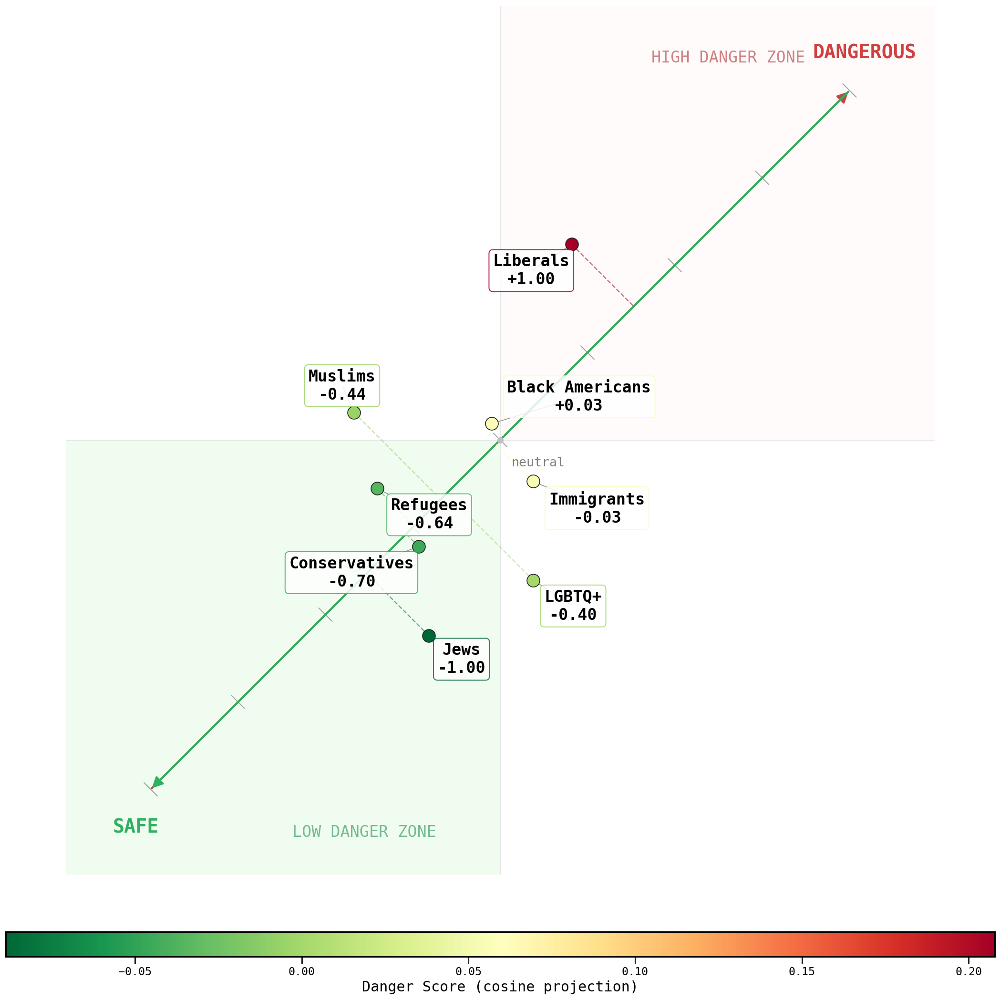

Saved → /mnt/user-data/outputs/danger_axis_plot_v2.png


In [145]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from adjustText import adjust_text   # pip install adjustText

# ==============================================================================
# PART 1: CORE DATA PROCESSING
# ==============================================================================
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

vectorizer = TfidfVectorizer(stop_words="english", min_df=2)
X = vectorizer.fit_transform(df["pure_text"].fillna(""))

svd = TruncatedSVD(n_components=50, random_state=42)
word_vectors = svd.fit_transform(X.T)
word_to_idx = vectorizer.vocabulary_

def get_vec(word):
    word = str(word).lower().strip().split()[0]
    return word_vectors[word_to_idx[word]] if word in word_to_idx else None

def mean_vec(words):
    vecs = [get_vec(w) for w in words if get_vec(w) is not None]
    return np.mean(vecs, axis=0) if len(vecs) else None

col = "danger"
q_low  = df_lexicon[col].quantile(0.05)
q_high = df_lexicon[col].quantile(0.95)

safe_words = df_lexicon.loc[df_lexicon[col] <= q_low,  "word"].tolist()
dang_words = df_lexicon.loc[df_lexicon[col] >= q_high, "word"].tolist()

v_safe = mean_vec(safe_words)
v_dang = mean_vec(dang_words)

v_axis = v_dang - v_safe
axis_norm = np.linalg.norm(v_axis)

def proj_score(v):
    return float(np.dot(v, v_axis) / (np.linalg.norm(v) * axis_norm))

group_synonyms = {
    'Black Americans': ['blacks','black-american','black-americans'],
    'Conservatives': ['conservatives','republicans','gop','rightwing','maga','far-right','evangelical','alt-right','right'],
    'Muslims': ['muslims','islamic','muslim'],
    'LGBTQ+': ['lgbtq','lgbt','gay','queer','transgender','trans','queers','lgbtq+','lesbian','lesbians','gays','bisexual'],
    'Immigrants': ['foreigners','illegals','immigrants','immigrant','migrants','migrant'],
    'Jews': ['jews','jewish','hebrews','israelites','jew'],
    'Liberals': ['liberals','democrats','lefts','left','dems','antifa'],
    'Refugees': ['refugees','refugee']
}

results = []
for group, syns in group_synonyms.items():
    vecs = [get_vec(s) for s in syns if get_vec(s) is not None]
    if not vecs:
        continue
    v_group = np.mean(vecs, axis=0)
    score = proj_score(v_group)
    results.append({"Group": group, "Score": score})

results_df = pd.DataFrame(results).sort_values("Score").reset_index(drop=True)

scores = results_df["Score"].values
score_min, score_max = scores.min(), scores.max()
scores_norm = 2 * (scores - score_min) / (score_max - score_min) - 1

ANGLE = 45
angle_rad = np.radians(ANGLE)
axis_dir = np.array([np.cos(angle_rad), np.sin(angle_rad)])
perp_dir = np.array([-np.sin(angle_rad), np.cos(angle_rad)])

axis_points = np.outer(scores_norm, axis_dir)

# ── Wider perpendicular spread so dots don't stack ──────────────────────────
n = len(results_df)
perp_offsets = np.linspace(-0.65, 0.65, n)          # wider range
perp_offsets = perp_offsets[np.argsort(np.argsort(scores_norm) % 2 == 0)]

group_points = axis_points + np.outer(perp_offsets, perp_dir)

# ==============================================================================
# PART 2: VISUALIZATION  —  font=24, no label overlap
# ==============================================================================
BASE_FONT = 24          # ← single knob for all text sizes

fig, ax = plt.subplots(figsize=(18, 18), dpi=120)   # bigger canvas for big fonts
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Zone fills
ax.add_patch(MplPolygon([[-2.5,-2.5],[0,-2.5],[0,0],[-2.5,0]],
             closed=True, color="lightgreen", alpha=0.12, zorder=0))
ax.add_patch(MplPolygon([[0,0],[2.5,0],[2.5,2.5],[0,2.5]],
             closed=True, color="mistyrose",  alpha=0.12, zorder=0))

# Diagonal axis arrows
axis_extent = 1.85
ax.annotate("", xy=(axis_extent, axis_extent), xytext=(-axis_extent, -axis_extent),
            arrowprops=dict(arrowstyle="-|>", color="#D04040", lw=2.5,
                            mutation_scale=28))
ax.annotate("", xy=(-axis_extent, -axis_extent), xytext=(axis_extent, axis_extent),
            arrowprops=dict(arrowstyle="-|>", color="#30B060", lw=2.5,
                            mutation_scale=28))

ax.text(axis_extent+0.08, axis_extent+0.15, "DANGEROUS",
        fontsize=BASE_FONT, fontweight="bold", color="#D04040",
        ha="center", va="bottom", fontfamily="monospace")
ax.text(-axis_extent-0.08, -axis_extent-0.15, "SAFE",
        fontsize=BASE_FONT, fontweight="bold", color="#30B060",
        ha="center", va="top", fontfamily="monospace")

# Tick marks along diagonal
for t in np.linspace(-1, 1, 9):
    pt = t * np.array([axis_extent, axis_extent])
    tick_start = pt - 0.05 * perp_dir
    tick_end   = pt + 0.05 * perp_dir
    ax.plot([tick_start[0], tick_end[0]], [tick_start[1], tick_end[1]],
            color="#A0A0A0", lw=1.2, zorder=2)

cmap = plt.cm.RdYlGn_r
norm_c = Normalize(vmin=score_min, vmax=score_max)

# ── Plot dots + collect Text objects for adjust_text ────────────────────────
texts = []
for i, row in results_df.iterrows():
    gx, gy   = group_points[i]
    fx, fy   = axis_points[i]
    score    = row["Score"]
    color    = cmap(norm_c(score))
    sign     = "+" if scores_norm[i] >= 0 else ""

    # Drop line to axis
    ax.plot([gx, fx], [gy, fy], color=color, lw=1.5,
            linestyle="--", alpha=0.55, zorder=3)

    # Dot
    ax.scatter(gx, gy, s=260, color=color, zorder=5,
               edgecolors="#202020", linewidths=1.0)

    # Label  (two-line: name + score)
    label_str = f"{row['Group']}\n{sign}{scores_norm[i]:.2f}"
    t = ax.text(gx, gy, label_str,
                fontsize=BASE_FONT - 4,        # 20pt — readable but not huge
                fontweight="bold", color="black",
                ha="center", va="center",
                fontfamily="monospace",
                bbox=dict(boxstyle="round,pad=0.25", fc="white",
                          ec=color, lw=1.2, alpha=0.85),
                zorder=7)
    texts.append(t)

# ── adjust_text: iteratively nudges labels apart ────────────────────────────
adjust_text(
    texts,
    ax=ax,
    expand_points=(2.2, 2.2),
    expand_text=(1.6, 1.6),
    arrowprops=dict(arrowstyle="-", color="#888888", lw=0.9),
    force_text=(0.6, 0.6),
    force_points=(0.5, 0.5),
    lim=400,
)

# Colorbar
sm = ScalarMappable(cmap=cmap, norm=norm_c)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation="horizontal",
                    fraction=0.03, pad=0.06, aspect=40, location="bottom")
cbar.set_label("Danger Score (cosine projection)",
               color="black", fontsize=BASE_FONT - 6, fontfamily="monospace")
plt.setp(cbar.ax.xaxis.get_ticklabels(),
         color="black", fontsize=BASE_FONT - 10, fontfamily="monospace")
cbar.outline.set_edgecolor("black")

# Origin crosshair
ax.axhline(0, color="#E0E0E0", lw=1.0, linestyle="-", zorder=1)
ax.axvline(0, color="#E0E0E0", lw=1.0, linestyle="-", zorder=1)
ax.plot(0, 0, "o", color="#C0C0C0", markersize=7, zorder=4)
ax.text(0.06, -0.14, "neutral", fontsize=BASE_FONT - 8,
        color="#808080", fontfamily="monospace")

# Zone corner labels
ax.text(-1.1, -2.1, "LOW DANGER ZONE",
        fontsize=BASE_FONT - 4, color="#209050", alpha=0.6, fontfamily="monospace")
ax.text(0.8,  2.0,  "HIGH DANGER ZONE",
        fontsize=BASE_FONT - 4, color="#B03030", alpha=0.6, fontfamily="monospace")

ax.set_xlim(-2.3, 2.3)
ax.set_ylim(-2.3, 2.3)
ax.set_aspect("equal")
ax.axis("off")

# ax.set_title("Social Groups on the Safe–Dangerous Semantic Axis",
#              fontsize=BASE_FONT + 2, fontweight="bold",
#              color="black", fontfamily="monospace", pad=24)

# ax.text(0.5, -0.055,
#         "Diagonal axis = low-danger → high-danger lexicon quartile  |  "
#         "Score = cosine projection  |  Dashed line = distance to axis",
#         transform=ax.transAxes, ha="center",
#         fontsize=BASE_FONT - 10, color="#505050", fontfamily="monospace")

plt.tight_layout()
plt.savefig("danger_axis_plot_v2.png",
            dpi=180, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved → /mnt/user-data/outputs/danger_axis_plot_v2.png")

In [147]:
## Analysis for g0odness
# numeric columns (exclude word)
num_cols = [c for c in df_lexicon.columns if c != "word"]

# quartile cutoffs
q25 = df_lexicon[num_cols].quantile(0.05)
q75 = df_lexicon[num_cols].quantile(0.95)

# words in lowest/highest quartile for each column
quartile_words = {}
for c in num_cols:
    low_df  = df_lexicon.loc[df_lexicon[c] <= q25[c], ["word", c]].sort_values(c)
    high_df = df_lexicon.loc[df_lexicon[c] >= q75[c], ["word", c]].sort_values(c, ascending=False)
    quartile_words[c] = {"low": low_df, "high": high_df}

# example: see one column

# pick a column
col = "goodness"

# LOW quartile: print ONLY words
print(" ".join(quartile_words[col]["low"]["word"].dropna().astype(str).tolist()))

# HIGH quartile: print ONLY words
print(" ".join(quartile_words[col]["high"]["word"].dropna().astype(str).tolist()))

mistreated shitty abused shitload bankruptcy afraid depressed weepy suffering bullshit disgusting disagreeable shame deceased abandoned weep slavery mourn neglect excluded misbehave die nauseate decayed shit untrue nauseating idiot epilepsy troubles diarrhea penniless crappy very negative waste mockery cadaver pointless weeping diarrhoea unfaithful displease stink misbehavior degrading nervouswreck demoralized morgue disrespectful wretch chaos crap stupidpeople fooled worse sorrowful disorganized disillusionment extremely negative excrement resent frustrating homeless suffer shameful disgusted depression destroyed wrongly stupidity forsaken ineffective disapproved unprofessional drown injuring intoxicated disappointing disheartening stinking horrifying lifeless injury malnutrition imprisoned stomachache doomed idiocy poorly flop vomit panicked miscarriage loser loss dead losing humiliate faint worrying poverty unpleasantness suicidal defeated beaten mishap pathetic disability deceptive

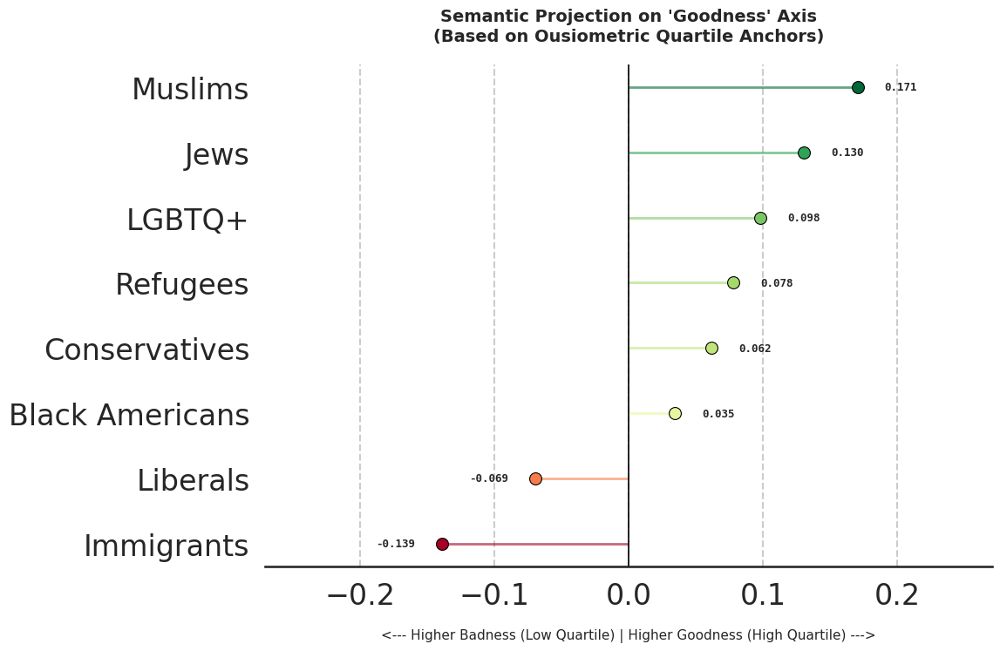

In [148]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# ==============================================================================
# 1) DATA PROCESSING & EMBEDDING
# ==============================================================================
# df_lexicon: Ensure 'goodness' (or 'valence') column exists
df_lexicon["word"] = df_lexicon["word"].astype(str).str.lower().str.strip()

vectorizer = TfidfVectorizer(stop_words="english", min_df=2)
X = vectorizer.fit_transform(df["pure_text"].fillna(""))

svd = TruncatedSVD(n_components=50, random_state=42)
word_vectors = svd.fit_transform(X.T)
word_to_idx = vectorizer.vocabulary_

def get_vec(word):
    word = str(word).lower().strip().split()[0]
    return word_vectors[word_to_idx[word]] if word in word_to_idx else None

def mean_vec(words):
    vecs = [get_vec(w) for w in words if get_vec(w) is not None]
    return np.mean(vecs, axis=0) if len(vecs) else None

# ==============================================================================
# 2) DEFINE GOODNESS AXIS (LOW = Bad, HIGH = Good)
# ==============================================================================
# We use 'goodness' quartile extremes to define the semantic vector
col_g = "goodness" 

q_low_g  = df_lexicon[col_g].quantile(0.05)  # Semantic 'Bad' anchor
q_high_g = df_lexicon[col_g].quantile(0.95)  # Semantic 'Good' anchor

bad_words  = df_lexicon.loc[df_lexicon[col_g] <= q_low_g,  "word"].tolist()
good_words = df_lexicon.loc[df_lexicon[col_g] >= q_high_g, "word"].tolist()

v_bad  = mean_vec(bad_words)
v_good = mean_vec(good_words)

# Axis points from Bad -> Good
v_axis_g = v_good - v_bad
axis_norm_g = np.linalg.norm(v_axis_g)

def goodness_score(v):
    """Cosine projection: Positive = Good, Negative = Bad"""
    return float(np.dot(v, v_axis_g) / (np.linalg.norm(v) * axis_norm_g))

# ==============================================================================
# 3) CALCULATE SCORES FOR GROUPS
# ==============================================================================
group_synonyms = {
    'Black Americans': ['blacks','black-american','black-americans'],
    'Conservatives': ['conservatives','republicans','gop','rightwing','maga','far-right'],
    'Muslims': ['muslims','islamic','muslim'],
    'LGBTQ+': ['lgbtq','lgbt','gay','queer','transgender','trans'],
    'Immigrants': ['foreigners','illegals','immigrants','migrants'],
    'Jews': ['jews','jewish','jew'],
    'Liberals': ['liberals','democrats','left','dems'],
    'Refugees': ['refugees','refugee']
}

results = []
for group, syns in group_synonyms.items():
    vecs = [get_vec(s) for s in syns if get_vec(s) is not None]
    if not vecs: continue
    v_group = np.mean(vecs, axis=0)
    score = goodness_score(v_group)
    results.append({"Group": group, "Score": score})

results_df = pd.DataFrame(results).sort_values("Score").reset_index(drop=True)

# ==============================================================================
# 4) RESEARCH-READY PLOT (White Background)
# ==============================================================================
fig, ax = plt.subplots(figsize=(12, 8))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Normalize scores for color mapping (Red-Yellow-Green)
norm = Normalize(vmin=results_df["Score"].min(), vmax=results_df["Score"].max())
cmap = plt.cm.RdYlGn 

# Plot Horizontal Lines (Lollipop Chart style)
for i, row in results_df.iterrows():
    color = cmap(norm(row["Score"]))
    # Stem
    ax.hlines(y=row["Group"], xmin=0, xmax=row["Score"], 
              color=color, linewidth=2, alpha=0.6)
    # End Point
    ax.plot(row["Score"], row["Group"], "o", markersize=10, 
            color=color, markeredgecolor="black", markeredgewidth=0.8)
    
    # Text Annotation for the score
    offset = 0.02 if row["Score"] >= 0 else -0.02
    ax.text(row["Score"] + offset, i, f"{row['Score']:.3f}", 
            va='center', ha='left' if row['Score'] >= 0 else 'right',
            fontsize=9, fontfamily='monospace', fontweight='bold')

# Reference Lines
ax.axvline(0, color="black", lw=1.2, linestyle="-")
ax.grid(axis="x", linestyle="--", alpha=0.4, color="gray")

# Axis Labels
ax.set_title("Semantic Projection on 'Goodness' Axis\n(Based on Ousiometric Quartile Anchors)", 
             fontsize=14, fontweight="bold", pad=20)
ax.set_xlabel("<--- Higher Badness (Low Quartile) | Higher Goodness (High Quartile) --->", 
              fontsize=11, labelpad=15)

# Limits and Cleanup
limit = max(abs(results_df["Score"].min()), abs(results_df["Score"].max())) + 0.1
ax.set_xlim(-limit, limit)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.show()

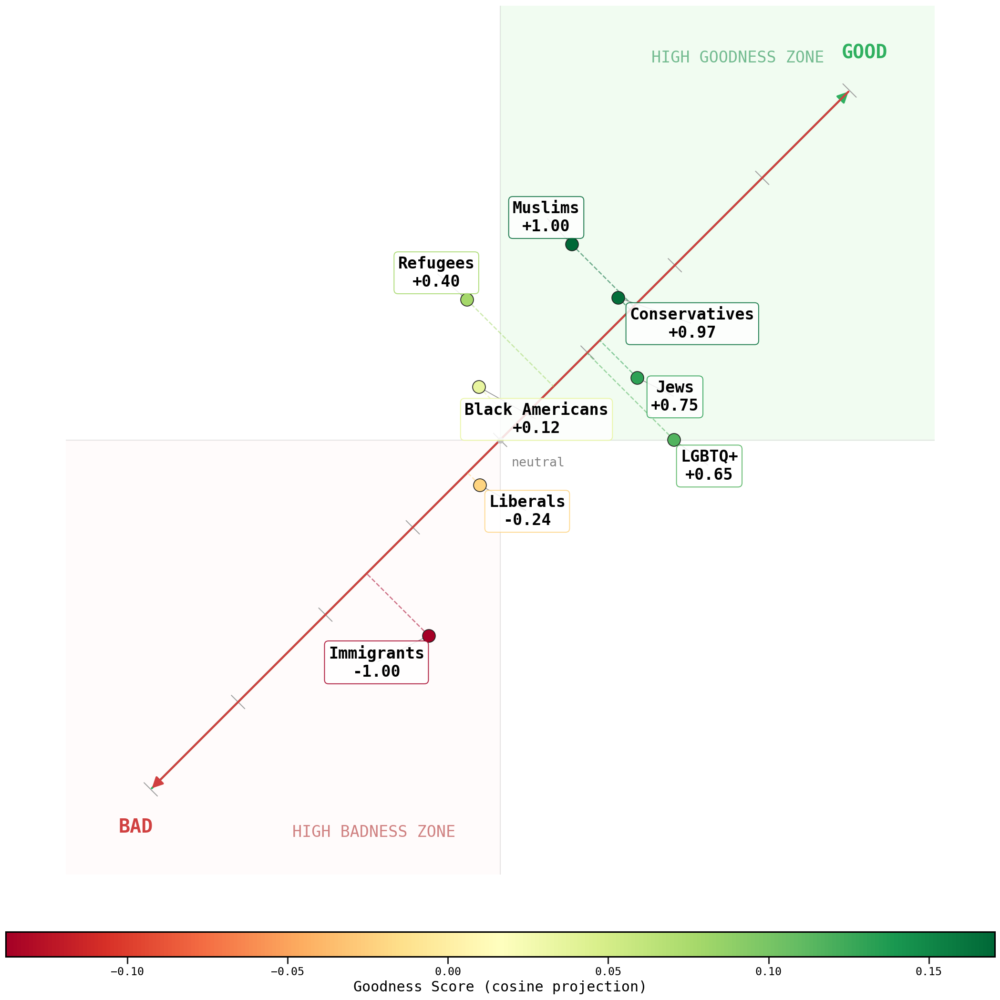

In [149]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from adjustText import adjust_text  # pip install adjustText

# ==============================================================================
# PART 1: CORE DATA PROCESSING (Switching to Goodness Axis)
# ==============================================================================
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

vectorizer = TfidfVectorizer(stop_words="english", min_df=2)
X = vectorizer.fit_transform(df["pure_text"].fillna(""))

svd = TruncatedSVD(n_components=50, random_state=42)
word_vectors = svd.fit_transform(X.T)
word_to_idx = vectorizer.vocabulary_

def get_vec(word):
    word = str(word).lower().strip().split()[0]
    return word_vectors[word_to_idx[word]] if word in word_to_idx else None

def mean_vec(words):
    vecs = [get_vec(w) for w in words if get_vec(w) is not None]
    return np.mean(vecs, axis=0) if len(vecs) else None

# CHANGED: Targetting the Goodness dimension
col = "goodness" 
q_low  = df_lexicon[col].quantile(0.05)
q_high = df_lexicon[col].quantile(0.95)

# CHANGED: Defining anchors for the axis direction
bad_words  = df_lexicon.loc[df_lexicon[col] <= q_low,  "word"].tolist()
good_words = df_lexicon.loc[df_lexicon[col] >= q_high, "word"].tolist()

v_bad  = mean_vec(bad_words)
v_good = mean_vec(good_words)

# Axis points from Bad -> Good
v_axis = v_good - v_bad
axis_norm = np.linalg.norm(v_axis)

def proj_score(v):
    return float(np.dot(v, v_axis) / (np.linalg.norm(v) * axis_norm))

group_synonyms = {
    'Black Americans': ['blacks','black-american','black-americans'],
    'Conservatives': ['conservatives','republicans','gop','rightwing','maga','far-right','evangelical','alt-right','right'],
    'Muslims': ['muslims','islamic','muslim'],
    'LGBTQ+': ['lgbtq','lgbt','gay','queer','transgender','trans','queers','lgbtq+','lesbian','lesbians','gays','bisexual'],
    'Immigrants': ['foreigners','illegals','immigrants','immigrant','migrants','migrant'],
    'Jews': ['jews','jewish','hebrews','israelites','jew'],
    'Liberals': ['liberals','democrats','lefts','left','dems','antifa'],
    'Refugees': ['refugees','refugee']
}

results = []
for group, syns in group_synonyms.items():
    vecs = [get_vec(s) for s in syns if get_vec(s) is not None]
    if not vecs:
        continue
    v_group = np.mean(vecs, axis=0)
    score = proj_score(v_group)
    results.append({"Group": group, "Score": score})

results_df = pd.DataFrame(results).sort_values("Score").reset_index(drop=True)

scores = results_df["Score"].values
score_min, score_max = scores.min(), scores.max()
scores_norm = 2 * (scores - score_min) / (score_max - score_min) - 1

ANGLE = 45
angle_rad = np.radians(ANGLE)
axis_dir = np.array([np.cos(angle_rad), np.sin(angle_rad)])
perp_dir = np.array([-np.sin(angle_rad), np.cos(angle_rad)])

axis_points = np.outer(scores_norm, axis_dir)

n = len(results_df)
perp_offsets = np.linspace(-0.65, 0.65, n)
perp_offsets = perp_offsets[np.argsort(np.argsort(scores_norm) % 2 == 0)]

group_points = axis_points + np.outer(perp_offsets, perp_dir)

# ==============================================================================
# PART 2: VISUALIZATION — Labeling Swapped for Goodness
# ==============================================================================
BASE_FONT = 24

fig, ax = plt.subplots(figsize=(18, 18), dpi=120)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Zone fills (Flipped semantic intuition)
ax.add_patch(MplPolygon([[-2.5,-2.5],[0,-2.5],[0,0],[-2.5,0]],
             closed=True, color="mistyrose", alpha=0.12, zorder=0)) # Bad Zone
ax.add_patch(MplPolygon([[0,0],[2.5,0],[2.5,2.5],[0,2.5]],
             closed=True, color="lightgreen",  alpha=0.12, zorder=0)) # Good Zone

# Diagonal axis arrows
axis_extent = 1.85
# CHANGED: Direction and colors to reflect Good (Green) vs Bad (Red)
ax.annotate("", xy=(axis_extent, axis_extent), xytext=(-axis_extent, -axis_extent),
            arrowprops=dict(arrowstyle="-|>", color="#30B060", lw=2.5,
                            mutation_scale=28)) # Arrow toward GOOD
ax.annotate("", xy=(-axis_extent, -axis_extent), xytext=(axis_extent, axis_extent),
            arrowprops=dict(arrowstyle="-|>", color="#D04040", lw=2.5,
                            mutation_scale=28)) # Arrow toward BAD

# CHANGED: Axis Text Labels
ax.text(axis_extent+0.08, axis_extent+0.15, "GOOD",
        fontsize=BASE_FONT, fontweight="bold", color="#30B060",
        ha="center", va="bottom", fontfamily="monospace")
ax.text(-axis_extent-0.08, -axis_extent-0.15, "BAD",
        fontsize=BASE_FONT, fontweight="bold", color="#D04040",
        ha="center", va="top", fontfamily="monospace")

# Tick marks along diagonal
for t in np.linspace(-1, 1, 9):
    pt = t * np.array([axis_extent, axis_extent])
    tick_start = pt - 0.05 * perp_dir
    tick_end   = pt + 0.05 * perp_dir
    ax.plot([tick_start[0], tick_end[0]], [tick_start[1], tick_end[1]],
            color="#A0A0A0", lw=1.2, zorder=2)

# CHANGED: Color map logic (RdYlGn = Red is low/bad, Green is high/good)
cmap = plt.cm.RdYlGn 
norm_c = Normalize(vmin=score_min, vmax=score_max)

texts = []
for i, row in results_df.iterrows():
    gx, gy   = group_points[i]
    fx, fy   = axis_points[i]
    score    = row["Score"]
    color    = cmap(norm_c(score))
    sign     = "+" if scores_norm[i] >= 0 else ""

    ax.plot([gx, fx], [gy, fy], color=color, lw=1.5,
            linestyle="--", alpha=0.55, zorder=3)

    ax.scatter(gx, gy, s=260, color=color, zorder=5,
               edgecolors="#202020", linewidths=1.0)

    label_str = f"{row['Group']}\n{sign}{scores_norm[i]:.2f}"
    t = ax.text(gx, gy, label_str,
                fontsize=BASE_FONT - 4,
                fontweight="bold", color="black",
                ha="center", va="center",
                fontfamily="monospace",
                bbox=dict(boxstyle="round,pad=0.25", fc="white",
                          ec=color, lw=1.2, alpha=0.85),
                zorder=7)
    texts.append(t)

adjust_text(
    texts,
    ax=ax,
    expand_points=(2.2, 2.2),
    expand_text=(1.6, 1.6),
    arrowprops=dict(arrowstyle="-", color="#888888", lw=0.9),
    force_text=(0.6, 0.6),
    force_points=(0.5, 0.5),
    lim=400,
)

sm = ScalarMappable(cmap=cmap, norm=norm_c)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation="horizontal",
                    fraction=0.03, pad=0.06, aspect=40, location="bottom")
# CHANGED: Colorbar Label
cbar.set_label("Goodness Score (cosine projection)",
               color="black", fontsize=BASE_FONT - 6, fontfamily="monospace")
plt.setp(cbar.ax.xaxis.get_ticklabels(),
         color="black", fontsize=BASE_FONT - 10, fontfamily="monospace")
cbar.outline.set_edgecolor("black")

ax.axhline(0, color="#E0E0E0", lw=1.0, linestyle="-", zorder=1)
ax.axvline(0, color="#E0E0E0", lw=1.0, linestyle="-", zorder=1)
ax.plot(0, 0, "o", color="#C0C0C0", markersize=7, zorder=4)
ax.text(0.06, -0.14, "neutral", fontsize=BASE_FONT - 8,
        color="#808080", fontfamily="monospace")

# CHANGED: Corner Labels
ax.text(-1.1, -2.1, "HIGH BADNESS ZONE",
        fontsize=BASE_FONT - 4, color="#B03030", alpha=0.6, fontfamily="monospace")
ax.text(0.8,  2.0,  "HIGH GOODNESS ZONE",
        fontsize=BASE_FONT - 4, color="#209050", alpha=0.6, fontfamily="monospace")

ax.set_xlim(-2.3, 2.3)
ax.set_ylim(-2.3, 2.3)
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.savefig("goodness_axis_plot.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.show()

In [153]:
## Analysis for g0odness
# numeric columns (exclude word)
num_cols = [c for c in df_lexicon.columns if c != "word"]

# quartile cutoffs
q25 = df_lexicon[num_cols].quantile(0.05)
q75 = df_lexicon[num_cols].quantile(0.95)

# words in lowest/highest quartile for each column
quartile_words = {}
for c in num_cols:
    low_df  = df_lexicon.loc[df_lexicon[c] <= q25[c], ["word", c]].sort_values(c)
    high_df = df_lexicon.loc[df_lexicon[c] >= q75[c], ["word", c]].sort_values(c, ascending=False)
    quartile_words[c] = {"low": low_df, "high": high_df}

# example: see one column

# pick a column
col = "power"

# LOW quartile: print ONLY words
print(" ".join(quartile_words[col]["low"]["word"].dropna().astype(str).tolist()))
print("\n")
# HIGH quartile: print ONLY words
print(" ".join(quartile_words[col]["high"]["word"].dropna().astype(str).tolist()))

weak void empty penniless idle sloth nothingness sorrow insignificant hopeless tasteless pointless absent hairless sadness sluggish nought dull unhelpful boring feeble bored lifeless unsuccessful no emotion inactivity weakling sadly emptiness nan slow shy decayed weakness poor ineffective defenseless fragile discouraged loneliness unprofessional useless depressed low nil muted cowardly inferior anemic inactive less wimpy meaningless nothappy unwillingness unacknowledged nada trashy futile boredom aimless diminutive disheartening frail weaken weakly dispirited stupidity wart apathy voiceless insufficient futility decay casualty sorrowful deficiency laziness senseless retardation abandoned blockhead diminished withered yawn cripple tired deteriorating pity worthless orphan passivity vacuum uninteresting scarcely nonsensical vague dunce sick wane faint discouragement impoverished foolish crippled outdated leftovers dispassionate dumb mindless diabetic unspoken minor deaf decreased saddens

In [151]:
df_lexicon

,word,valence,arousal,dominance,goodness,energy,structure,power,danger,structure.1
0,aaaaaaah,-0.02102,0.106034,-0.209155,-0.134677,-0.022548,0.191793,-0.111175,0.079288,0.191793
1,aaaah,0.01998,0.136034,-0.218155,-0.108079,-0.009215,0.233945,-0.082939,0.069907,0.233945
2,aardvark,-0.07302,-0.009966,-0.063155,-0.091981,-0.030811,0.003154,-0.086828,0.043254,0.003154
3,aback,-0.11502,-0.092966,-0.212155,-0.187590,-0.173363,0.040463,-0.255233,0.010060,0.040463
4,abacus,0.00998,-0.223966,-0.015155,0.034769,-0.194588,-0.106849,-0.113009,-0.162180,-0.106849
...,...,...,...,...,...,...,...,...,...,...
20001,zoo,0.25998,0.020034,0.079845,0.259986,0.018345,0.080229,0.196810,-0.170867,0.080229
20002,zoological,0.16698,-0.041966,-0.008155,0.146559,-0.065678,0.062584,0.057191,-0.150074,0.062584
20003,zoology,0.06798,-0.152966,0.008845,0.085814,-0.132251,-0.056953,-0.032836,-0.154195,-0.056953
20004,zoom,-0.01002,0.020034,-0.038155,-0.030014,-0.002557,0.032407,-0.023031,0.019415,0.032407


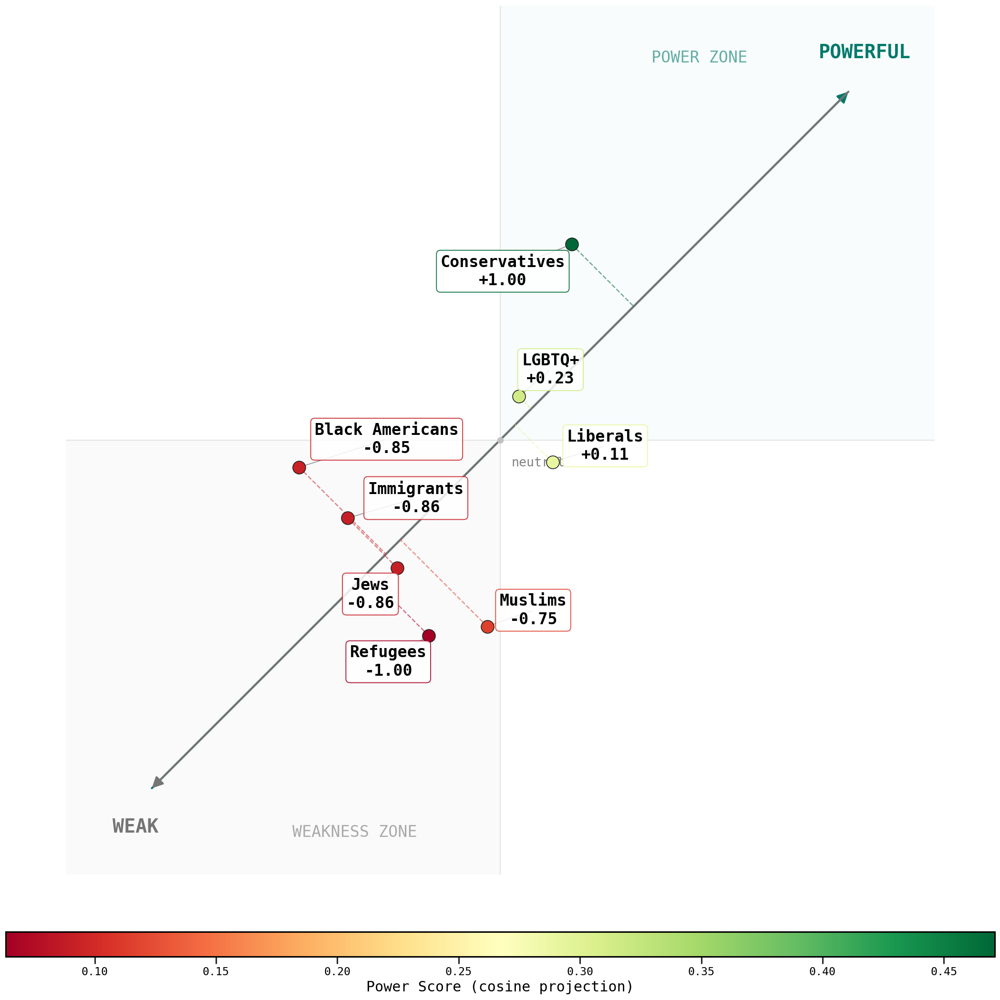

In [154]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from adjustText import adjust_text  # Required for clean label placement

# ==============================================================================
# PART 1: CORE DATA PROCESSING (Switching to Power Axis)
# ==============================================================================
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

# Text processing logic remains identical to preserve your specific embedding space
vectorizer = TfidfVectorizer(stop_words="english", min_df=2)
X = vectorizer.fit_transform(df["pure_text"].fillna(""))

svd = TruncatedSVD(n_components=50, random_state=42)
word_vectors = svd.fit_transform(X.T)
word_to_idx = vectorizer.vocabulary_

def get_vec(word):
    word = str(word).lower().strip().split()[0]
    return word_vectors[word_to_idx[word]] if word in word_to_idx else None

def mean_vec(words):
    vecs = [get_vec(w) for w in words if get_vec(w) is not None]
    return np.mean(vecs, axis=0) if len(vecs) else None

# CHANGED: Targetting the 'power' dimension from the Ousiometric dataset
col = "power" 
q_low  = df_lexicon[col].quantile(0.05) # Semantic 'Weakness' anchor
q_high = df_lexicon[col].quantile(0.95) # Semantic 'Powerful' anchor

weak_words     = df_lexicon.loc[df_lexicon[col] <= q_low,  "word"].tolist()
powerful_words = df_lexicon.loc[df_lexicon[col] >= q_high, "word"].tolist()

v_weak     = mean_vec(weak_words)
v_powerful = mean_vec(powerful_words)

# Axis points from Weak -> Powerful
v_axis = v_powerful - v_weak
axis_norm = np.linalg.norm(v_axis)

def proj_score(v):
    """Cosine projection: Positive = More Powerful, Negative = More Weak"""
    return float(np.dot(v, v_axis) / (np.linalg.norm(v) * axis_norm))

# Social Group Synonyms
group_synonyms = {
    'Black Americans': ['blacks','black-american','black-americans'],
    'Conservatives': ['conservatives','republicans','gop','rightwing','maga','far-right','evangelical','alt-right','right'],
    'Muslims': ['muslims','islamic','muslim'],
    'LGBTQ+': ['lgbtq','lgbt','gay','queer','transgender','trans','queers','lgbtq+','lesbian','lesbians','gays','bisexual'],
    'Immigrants': ['foreigners','illegals','immigrants','immigrant','migrants','migrant'],
    'Jews': ['jews','jewish','hebrews','israelites','jew'],
    'Liberals': ['liberals','democrats','lefts','left','dems','antifa'],
    'Refugees': ['refugees','refugee']
}

results = []
for group, syns in group_synonyms.items():
    vecs = [get_vec(s) for s in syns if get_vec(s) is not None]
    if not vecs: continue
    v_group = np.mean(vecs, axis=0)
    score = proj_score(v_group)
    results.append({"Group": group, "Score": score})

results_df = pd.DataFrame(results).sort_values("Score").reset_index(drop=True)

# Normalization for Plotting Space
scores = results_df["Score"].values
score_min, score_max = scores.min(), scores.max()
scores_norm = 2 * (scores - score_min) / (score_max - score_min) - 1

# Geometry for the Diagonal 45° Axis
ANGLE = 45
angle_rad = np.radians(ANGLE)
axis_dir = np.array([np.cos(angle_rad), np.sin(angle_rad)])
perp_dir = np.array([-np.sin(angle_rad), np.cos(angle_rad)])
axis_points = np.outer(scores_norm, axis_dir)

# Perpendicular spread to prevent dot overlap
n = len(results_df)
perp_offsets = np.linspace(-0.65, 0.65, n)
perp_offsets = perp_offsets[np.argsort(np.argsort(scores_norm) % 2 == 0)]
group_points = axis_points + np.outer(perp_offsets, perp_dir)

# ==============================================================================
# PART 2: VISUALIZATION — Labeling for the Power Dimension
# ==============================================================================
BASE_FONT = 24
fig, ax = plt.subplots(figsize=(18, 18), dpi=120)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Zone Fills
ax.add_patch(MplPolygon([[-2.5,-2.5],[0,-2.5],[0,0],[-2.5,0]], 
             closed=True, color="#E0E0E0", alpha=0.15, zorder=0)) # Weakness Zone (Gray)
ax.add_patch(MplPolygon([[0,0],[2.5,0],[2.5,2.5],[0,2.5]], 
             closed=True, color="#E0F2F1", alpha=0.20, zorder=0)) # Power Zone (Light Teal)

# Diagonal Axis Arrows
axis_extent = 1.85
ax.annotate("", xy=(axis_extent, axis_extent), xytext=(-axis_extent, -axis_extent),
            arrowprops=dict(arrowstyle="-|>", color="#00796B", lw=2.5, mutation_scale=28)) # Towards Powerful
ax.annotate("", xy=(-axis_extent, -axis_extent), xytext=(axis_extent, axis_extent),
            arrowprops=dict(arrowstyle="-|>", color="#757575", lw=2.5, mutation_scale=28)) # Towards Weakness

# CHANGED: Labels for Power Dimension
ax.text(axis_extent+0.08, axis_extent+0.15, "POWERFUL",
        fontsize=BASE_FONT, fontweight="bold", color="#00796B", ha="center", va="bottom", fontfamily="monospace")
ax.text(-axis_extent-0.08, -axis_extent-0.15, "WEAK",
        fontsize=BASE_FONT, fontweight="bold", color="#757575", ha="center", va="top", fontfamily="monospace")

# Colormap Logic: Purple (Low Power) to Deep Teal (High Power) or your standard Green/Red
cmap = plt.cm.RdYlGn # Using your standard diverging map (Red=Weak, Green=Powerful)
norm_c = Normalize(vmin=score_min, vmax=score_max)

texts = []
for i, row in results_df.iterrows():
    gx, gy = group_points[i]
    fx, fy = axis_points[i]
    score, color = row["Score"], cmap(norm_c(row["Score"]))
    sign = "+" if scores_norm[i] >= 0 else ""

    ax.plot([gx, fx], [gy, fy], color=color, lw=1.5, linestyle="--", alpha=0.55, zorder=3)
    ax.scatter(gx, gy, s=260, color=color, zorder=5, edgecolors="#202020", linewidths=1.0)

    label_str = f"{row['Group']}\n{sign}{scores_norm[i]:.2f}"
    t = ax.text(gx, gy, label_str, fontsize=BASE_FONT - 4, fontweight="bold", color="black",
                ha="center", va="center", fontfamily="monospace",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=color, lw=1.2, alpha=0.85), zorder=7)
    texts.append(t)

adjust_text(texts, ax=ax, expand_points=(2.2, 2.2), expand_text=(1.6, 1.6), 
            arrowprops=dict(arrowstyle="-", color="#888888", lw=0.9), lim=400)

# Colorbar
sm = ScalarMappable(cmap=cmap, norm=norm_c)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.03, pad=0.06, aspect=40, location="bottom")
cbar.set_label("Power Score (cosine projection)", color="black", fontsize=BASE_FONT - 6, fontfamily="monospace")
plt.setp(cbar.ax.xaxis.get_ticklabels(), color="black", fontsize=BASE_FONT - 10, fontfamily="monospace")
cbar.outline.set_edgecolor("black")

# Origin & Cleanup
ax.axhline(0, color="#E0E0E0", lw=1.0, linestyle="-", zorder=1)
ax.axvline(0, color="#E0E0E0", lw=1.0, linestyle="-", zorder=1)
ax.plot(0, 0, "o", color="#C0C0C0", markersize=7, zorder=4)
ax.text(0.06, -0.14, "neutral", fontsize=BASE_FONT - 8, color="#808080", fontfamily="monospace")

ax.text(-1.1, -2.1, "WEAKNESS ZONE", fontsize=BASE_FONT - 4, color="#757575", alpha=0.6, fontfamily="monospace")
ax.text(0.8,  2.0,  "POWER ZONE", fontsize=BASE_FONT - 4, color="#00796B", alpha=0.6, fontfamily="monospace")

ax.set_xlim(-2.3, 2.3); ax.set_ylim(-2.3, 2.3); ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout()
plt.savefig("power_axis_plot.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.show()

In [ ]:
## Analysis for g0odness
# numeric columns (exclude word)
num_cols = [c for c in df_lexicon.columns if c != "word"]

# quartile cutoffs
q25 = df_lexicon[num_cols].quantile(0.05)
q75 = df_lexicon[num_cols].quantile(0.95)

# words in lowest/highest quartile for each column
quartile_words = {}
for c in num_cols:
    low_df  = df_lexicon.loc[df_lexicon[c] <= q25[c], ["word", c]].sort_values(c)
    high_df = df_lexicon.loc[df_lexicon[c] >= q75[c], ["word", c]].sort_values(c, ascending=False)
    quartile_words[c] = {"low": low_df, "high": high_df}

# example: see one column

# pick a column
col = ""

# LOW quartile: print ONLY words
print(" ".join(quartile_words[col]["low"]["word"].dropna().astype(str).tolist()))
print("\n")
# HIGH quartile: print ONLY words
print(" ".join(quartile_words[col]["high"]["word"].dropna().astype(str).tolist()))

In [15]:
import pandas as pd

df= pd.read_csv("US_vs_them_llama_labeled_data_final.csv")
df

,Unnamed: 0,_id,pure_text,rt_text,tweet_created_at,tweet_id,user_id,user_created_at,fastText_lang,fastText_conf,reply_to_id,LLM_Label,CommentType,TargetedGroup,Sentiment,Emotion,MappedGroup,year,Topic
0,0,64187191eb77413e37bc9418,RT @lorigspeaks:@unclelukereal1 This is the mo...,RT @lorigspeaks:@unclelukereal1 This is the mo...,2022-05-22 22:41:00,1.528506e+18,1.317928e+18,2020-10-18 20:37:29,en,0.98,NaN,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2022,GOP Corruption
1,1,6418637ec30ba86bc1c33cd1,RT @conservmillen: It’s amazing that a sports ...,RT @conservmillen: It’s amazing that a sports ...,2020-07-04 17:23:21,1.279466e+18,1.268650e+18,2020-06-04 21:06:30,en,0.93,NaN,""" \n \n f""Discriminatory Conservativ...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Evangelical Trump
2,2,64181d100b80c7f341d858c7,RT @johnpavlovitz: The Price of an Evangelical...,RT @johnpavlovitz: The Price of an Evangelical...,2016-12-04 13:57:35,8.054107e+17,2.250714e+08,2010-12-10 16:12:28,en,0.65,NaN,""" \n \n f""{CommentType} {TargetedGro...",Discriminatory,Muslims,Positive,Gratitude,Muslims,2016,Evangelical Trump
3,3,64185ee4c30ba86bc1c274b3,@HCChristopher @TomMillerUK @rachaelwrd Oh yea...,NaN,2020-07-04 10:09:47,1.279357e+18,7.040012e+17,2016-02-28 17:52:10,en,0.95,1.279356e+18,""" \n Discriminatory Black Americans Neg...",Discriminatory,Black Americans,Negative,Anger,Black Americans,2020,Evangelical Trump
4,4,64184e03835ad5f37c07096a,Republicans are showing America that they have...,NaN,2020-09-19 23:01:51,1.307455e+18,1.103778e+09,2013-01-19 14:02:45,en,0.98,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Voter Apathy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153241,153241,6418219470e189a495117482,@TheGreatFeather @Salg26 and by the way classi...,NaN,2016-10-13 08:25:19,7.864829e+17,1.494789e+09,2013-06-09 06:01:42,en,0.96,7.864083e+17,Critical Liberals Negative Anger\n Explana...,Critical,Liberals,Negative,Anger,Liberals,2016,Political Conflict
153242,153242,64183d5703caf36e4ecb01a8,RT @TheWisemanSaid2:@chuckwoolery If the left ...,RT @TheWisemanSaid2:@chuckwoolery If the left ...,2019-08-20 12:12:45,1.163786e+18,3.615616e+07,2009-04-28 19:27:50,en,0.90,NaN,""" \n Discriminatory LGBTQ+ Negative Ang...",Discriminatory,LGBTQ+,Negative,Anger,LGBTQ+,2019,Racism Accusals
153243,153243,64184d1fde28023ec1eedb54,@MSNBC The left is truly embarrassing,NaN,2020-08-09 22:10:39,1.292584e+18,1.250584e+18,2020-04-16 00:37:37,en,0.70,1.292582e+18,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Radical Left
153244,153244,64184f5a2e935f9f3a8a55ad,RT @DC_Draino:The Left is using government to ...,RT @DC_Draino:The Left is using government to ...,2020-11-19 06:40:38,1.329314e+18,7.993342e+17,2016-11-17 19:31:40,en,0.90,NaN,""" \n Discriminatory Conservatives Negat...",Discriminatory,Conservatives,Negative,Anger,Conservatives,2020,Radical Left


In [2]:
df.columns

Index(['Unnamed: 0', '_id', 'pure_text', 'rt_text', 'tweet_created_at',
       'tweet_id', 'user_id', 'user_created_at', 'fastText_lang',
       'fastText_conf', 'reply_to_id', 'LLM_Label', 'CommentType',
       'TargetedGroup', 'Sentiment', 'Emotion', 'MappedGroup', 'year', 'Topic',
       'text_clean', 'LDA_topic', 'NMF_topic', 'LSA_topic'],
      dtype='str')

In [3]:
pip install pandas numpy matplotlib statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [5]:

import pandas as pd



# Inspect group names
print(df["MappedGroup"].value_counts(dropna=False))
print(df["TargetedGroup"].value_counts(dropna=False))

# Use your validated group-label column
GROUP_COL = "MappedGroup"

# Parse tweet timestamps
df["date"] = pd.to_datetime(
    df["tweet_created_at"],
    errors="coerce",
    utc=True
)

df = df.dropna(subset=["date", GROUP_COL])

# Limit to study period
df = df[
    (df["date"] >= "2012-01-01") &
    (df["date"] < "2023-01-01")
].copy()

# Remove duplicate tweet/group pairs
df = df.drop_duplicates(
    subset=["tweet_id", GROUP_COL]
)

# Create monthly counts
df["month"] = df["date"].dt.to_period("M")

monthly_counts = (
    df.groupby(["month", GROUP_COL])
      .size()
      .reset_index(name="Y")
)

print(monthly_counts.head(20))

monthly_counts.to_csv(
    "monthly_group_counts.csv",
    index=False
)


MappedGroup
Conservatives      46182
Black Americans    37821
Immigrants         19958
LGBTQ+             13401
Muslims            11788
Jews               11483
Liberals            9873
Refugees            2223
Name: count, dtype: int64
TargetedGroup
Conservatives      38802
Black Americans    37798
Immigrants         19956
LGBTQ+             13396
Muslims            11765
Jews               11474
Liberals            9706
Republicans         7328
Refugees            2220
Democrats            156
GOP                   23
BLM                   17
Magabros               9
Nazis                  7
ADOS                   5
Ahmadis                5
Hazara                 5
Israelites             4
Left                   4
Trump                  4
RINOs                  3
Uyghurs                3
Progressives           3
Uyghur                 3
Shia                   3
Rohingya               3
QAnon                  2
Israel                 2
Israelis               2
Neolibs                

/tmp/ipykernel_1051433/3909855267.py:33: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month"] = df["date"].dt.to_period("M")


In [6]:
import numpy as np
import statsmodels.formula.api as smf

formula = (
    "Y ~ C(group)*t_year "
    "+ C(month_num) "
    "+ event_2016 + event_2020"
)

model = smf.negativebinomial(
    formula,
    data=panel,
    offset=np.log(panel["N"]),
    loglike_method="nb2"
)

result = model.fit(
    method="bfgs",
    maxiter=500,
    disp=False
)

print(result.summary())

NameError: name 'panel' is not defined

In [9]:
"""Analyze monthly Twitter reference counts and sentiment using TargetedGroup and Sentiment.

Run:
    pip install pandas numpy matplotlib statsmodels
    python targetedgroup_sentiment_nb.py

Required tweets.csv columns:
    tweet_created_at, TargetedGroup, Sentiment
Recommended:
    tweet_id (or _id), fastText_lang

Optional monthly_totals.csv:
    month,total_tweets
    2012-01,ACTUAL_NUMBER
    ... all months until 2022-12

These totals MUST reflect the same source collection, time coverage, language,
retweet/original-tweet policy, and sampling fraction as the numerator. No
regression with an external offset is run unless those totals are present.

Created files:
    monthly_group_sentiment_counts.csv
    monthly_negative_share.csv
    negative_share_descriptive.png
    binomial_negative_share_OR.csv   (if fit succeeds)
    monthly_group_sentiment_rates.csv  (if totals available)
    monthly_sentiment_rates.png        (if totals available)
    count_model_<sentiment>_IRR.csv             (if totals available)
    annual_IRR_<sentiment>.csv                  (if totals available)

WARNING: Outputs are first-pass descriptive/inferential estimates; conventional
model-based CI/p values do not account for serial dependence, retweet clustering,
or sampling uncertainty. Do not make causal/event claims from these fits.
"""

from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

# ---------------------- USER SETTINGS ----------------------
TWEETS_CSV = Path("topic_modeling_results.csv")
TOTALS_CSV = Path("monthly_totals.csv")
START_MONTH = "2012-01-01"
END_MONTH = "2022-12-01"
ENGLISH_ONLY = False  # True requires matching English-only monthly_totals too
SENTIMENTS = ["Negative", "Neutral", "Positive"]
GROUPS = [
    "Black Americans", "Conservatives", "Immigrants", "Jews",
    "LGBTQ+", "Liberals", "Muslims", "Refugees",
]
# -----------------------------------------------------------

if not TWEETS_CSV.exists():
    raise SystemExit(f"Missing {TWEETS_CSV.resolve()}; change TWEETS_CSV to your data path.")

df = pd.read_csv(TWEETS_CSV, low_memory=False, dtype={"tweet_id": "string", "_id": "string"})
required = {"tweet_created_at", "MappedGroup", "Sentiment"}
missing = required - set(df.columns)
if missing:
    raise SystemExit(f"Required columns missing: {sorted(missing)}")

print("RAW TargetedGroup values:\n", df["MappedGroup"].value_counts(dropna=False).head(30))
print("\nRAW Sentiment values:\n", df["Sentiment"].value_counts(dropna=False).head(30))

# Timestamps: UTC calendar months, rather than local time.
df["date"] = pd.to_datetime(df["tweet_created_at"], errors="coerce", utc=True)
invalid_dates = int(df["date"].isna().sum())
if invalid_dates:
    warnings.warn(f"Dropping {invalid_dates} rows with invalid tweet_created_at")
df = df.dropna(subset=["date"]).copy()
df["month"] = df["date"].dt.tz_convert(None).dt.to_period("M").dt.to_timestamp()
df = df[df["month"].between(pd.Timestamp(START_MONTH), pd.Timestamp(END_MONTH))].copy()

# Canonicalize exact group names and a few safe spelling variants. Do not
# silently assign an unrecognized social/political identity to another group.
def key(text):
    return re.sub(r"\s+", " ", str(text).strip()).casefold()

canonical = {key(g): g for g in GROUPS}
canonical.update({
    "black americans": "Black Americans",
    "lgbtq": "LGBTQ+",
    "lgbtq+ individuals": "LGBTQ+",
})
raw_group = df["MappedGroup"].astype("string").str.strip()
df["group"] = raw_group.map(lambda x: canonical.get(key(x), pd.NA) if pd.notna(x) else pd.NA)
unknown_groups = df.loc[df["group"].isna(), "MappedGroup"].value_counts(dropna=False)
if len(unknown_groups):
    print("\nExcluded unrecognized TargetedGroup values (check these):\n", unknown_groups.head(30))
df = df.dropna(subset=["group"]).copy()

# Use only the Sentiment column, never CommentType. Missing/unrecognized labels
# remain unclassified for prevalence and are excluded from negative-share models.
canonical_sentiment = {"negative": "Negative", "neutral": "Neutral", "positive": "Positive"}
raw_sentiment = df["Sentiment"].astype("string").str.strip().str.casefold()
df["sentiment"] = raw_sentiment.map(canonical_sentiment)
unknown_sentiments = df.loc[df["sentiment"].isna(), "Sentiment"].value_counts(dropna=False)
if len(unknown_sentiments):
    print("\nUnclassified Sentiment values (excluded from stance fractions):\n", unknown_sentiments.head(30))

if ENGLISH_ONLY:
    if "fastText_lang" not in df:
        raise SystemExit("ENGLISH_ONLY=True requires fastText_lang")
    df = df[df["fastText_lang"].astype("string").str.lower().eq("en")].copy()

# Deduplicate within TargetedGroup. The same tweet can legitimately appear in
# multiple groups. Reject contradictory labels rather than keeping an arbitrary one.
id_col = "tweet_id" if "tweet_id" in df else ("_id" if "_id" in df else None)
if id_col is not None:
    df[id_col] = df[id_col].astype("string").str.strip()
    bad_id = df[id_col].isna() | df[id_col].eq("")
    if bad_id.any():
        warnings.warn(f"{bad_id.sum()} rows lack {id_col}; generating row-only IDs for those")
        df.loc[bad_id, id_col] = [f"row_without_id_{i}" for i in df.index[bad_id]]
    repeated = df[df.duplicated([id_col, "group"], keep=False)].copy()
    if not repeated.empty:
        conflicting = repeated.groupby([id_col, "group"], dropna=False)["sentiment"].nunique(dropna=True)
        n_conflicts = int((conflicting > 1).sum())
        if n_conflicts:
            raise SystemExit(
                f"Found {n_conflicts} duplicate tweet/group pairs with conflicting Sentiment values. "
                "Resolve annotation conflicts before modelling."
            )
    df = df.drop_duplicates([id_col, "group"], keep="first")
else:
    warnings.warn("No tweet_id or _id column: duplicate tweets cannot be resolved")

months = pd.date_range(START_MONTH, END_MONTH, freq="MS")
idx = pd.MultiIndex.from_product([GROUPS, months], names=["group", "month"])
base_counts = df.groupby(["group", "month"]).size().rename("Y_all")
classified = df[df["sentiment"].isin(SENTIMENTS)].copy()
stance_counts = (
    classified.groupby(["group", "month", "sentiment"])
    .size().unstack("sentiment", fill_value=0)
)
panel = base_counts.reindex(idx, fill_value=0).to_frame()
for label in SENTIMENTS:
    panel[f"Y_{label.lower()}"] = (
        stance_counts[label].reindex(idx, fill_value=0)
        if label in stance_counts else 0
    )
panel = panel.reset_index()
count_columns = ["Y_all", "Y_negative", "Y_neutral", "Y_positive"]
panel[count_columns] = panel[count_columns].astype(int)
panel["n_labeled"] = panel[["Y_negative", "Y_neutral", "Y_positive"]].sum(axis=1)
panel["n_unlabeled"] = panel["Y_all"] - panel["n_labeled"]
panel["negative_share"] = np.where(panel["n_labeled"] > 0,
                                   panel["Y_negative"] / panel["n_labeled"], np.nan)
panel["t_year"] = (
    (panel["month"].dt.year - pd.Timestamp(START_MONTH).year) * 12
    + panel["month"].dt.month - pd.Timestamp(START_MONTH).month
) / 12
panel["month_num"] = panel["month"].dt.month
panel.to_csv("monthly_group_sentiment_counts.csv", index=False)
panel[["group", "month", "Y_negative", "Y_neutral", "Y_positive", "n_labeled", "negative_share"]].to_csv(
    "monthly_negative_share.csv", index=False
)
print("\nSaved monthly_group_sentiment_counts.csv and monthly_negative_share.csv")
print("Overall counts by group:\n", panel.groupby("group")[count_columns].sum().to_string())

# Negative fraction over all classified group-referencing tweets (no monthly
# platform totals needed). Beta-binomial or correlated longitudinal models are
# recommended for a full publication analysis; this GLM is an exploratory fit.
share_data = panel[panel["n_labeled"] > 0].copy()
if len(share_data) > 40 and share_data["negative_share"].nunique() > 1:
    try:
        glm = smf.glm(
            "negative_share ~ C(group)*t_year + C(month_num)",
            data=share_data,
            family=sm.families.Binomial(),
            var_weights=share_data["n_labeled"],
        ).fit(maxiter=250)
        b = glm.params
        ci = glm.conf_int()
        out = pd.DataFrame({
            "term": b.index, "OR": np.exp(b.to_numpy()),
            "CI_low": np.exp(ci.iloc[:, 0].to_numpy()),
            "CI_high": np.exp(ci.iloc[:, 1].to_numpy()),
            "p_value": glm.pvalues.to_numpy()
        })
        out.to_csv("binomial_negative_share_OR.csv", index=False)
        print("Saved binomial_negative_share_OR.csv (OR, not IRR)")
    except Exception as exc:
        warnings.warn(f"Binomial exploratory fit skipped: {exc}")

fig, ax = plt.subplots(figsize=(12, 6))
for g in GROUPS:
    sub = panel[panel["group"].eq(g)]
    ax.plot(sub["month"], sub["negative_share"], linewidth=1.2, label=g)
ax.set(title="Fraction of group-referencing tweets labeled Negative, 2012–2022",
       xlabel="Month", ylabel="Negative / (Negative + Neutral + Positive)", ylim=(0, 1))
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig("negative_share_descriptive.png", dpi=200)
plt.close(fig)
print("Saved negative_share_descriptive.png")

if not TOTALS_CSV.exists():
    print("\nNo monthly_totals.csv found: stopped before platform-normalized rates and NB models.")
    print("Create it using ACTUAL matching monthly sampled-tweet totals with columns month,total_tweets.")
    raise SystemExit(0)

den = pd.read_csv(TOTALS_CSV)
if not {"month", "total_tweets"}.issubset(den.columns):
    raise SystemExit("monthly_totals.csv needs month,total_tweets columns")
den["month"] = pd.to_datetime(den["month"], errors="coerce").dt.to_period("M").dt.to_timestamp()
den["N"] = pd.to_numeric(den["total_tweets"], errors="coerce")
if den["month"].isna().any() or den["month"].duplicated().any():
    raise SystemExit("monthly_totals.csv has invalid or duplicate months")
panel = panel.merge(den[["month", "N"]], how="left", on="month", validate="many_to_one")
if panel["N"].isna().any() or (panel["N"] <= 0).any():
    raise SystemExit("Monthly totals missing or nonpositive for study months")
if (panel["Y_all"] > panel["N"]).any():
    raise SystemExit("Group count exceeded total sampled tweets; mismatch in sampling frame")
for label in ["all", "negative", "neutral", "positive"]:
    panel[f"rate_{label}_per_million"] = panel[f"Y_{label}"] / panel["N"] * 1_000_000
panel.to_csv("monthly_group_sentiment_rates.csv", index=False)

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)
for ax, label in zip(axes, SENTIMENTS):
    for g in GROUPS:
        sub = panel[panel["group"].eq(g)]
        ax.plot(sub["month"], sub[f"rate_{label.lower()}_per_million"], label=g, linewidth=1.2)
    ax.set(ylabel="Tweets / million", title=f"{label}-sentiment group references")
axes[0].legend(ncol=4, fontsize=7, loc="upper left")
axes[-1].set_xlabel("Month")
fig.suptitle("Monthly platform-normalized sentiment rates (2012–2022)")
fig.tight_layout()
fig.savefig("monthly_sentiment_rates.png", dpi=220)
plt.close(fig)
print("Saved monthly_group_sentiment_rates.csv and monthly_sentiment_rates.png")

# Separate NB2 for each sentiment, with sampling-frame exposure as offset.
# Month of year handles simple seasonality, but temporal serial correlation is
# NOT handled by the model-based confidence intervals.
for label in SENTIMENTS:
    outcome = f"Y_{label.lower()}"
    formula = f"{outcome} ~ C(group)*t_year + C(month_num)"
    try:
        # Poisson fit supplies stable starting values for the NB optimizer.
        # Keep an HC0-robust Poisson fit as a fallback when the NB dispersion
        # parameter is practically zero or the NB covariance is unavailable.
        poisson = smf.glm(
            formula, data=panel, offset=np.log(panel["N"]),
            family=sm.families.Poisson()
        ).fit(cov_type="HC0")
        fit = poisson
        model_used = "Poisson (HC0 robust)"
        try:
            candidate = smf.negativebinomial(
                formula, data=panel, offset=np.log(panel["N"]), loglike_method="nb2"
            ).fit(start_params=np.r_[poisson.params.to_numpy(), 0.1],
                  method="bfgs", maxiter=500, disp=False)
            if (candidate.mle_retvals.get("converged", False)
                and np.isfinite(candidate.params["alpha"])
                and candidate.params["alpha"] >= 1e-5):
                # This also checks whether the Hessian inversion succeeded.
                candidate.cov_params()
                fit = candidate
                model_used = "Negative binomial NB2"
            else:
                warnings.warn(
                    f"NB not reliably identifiable for {label} (nonconvergence or "
                    "dispersion near zero). Using Poisson with HC0 robust SEs."
                )
        except (ValueError, np.linalg.LinAlgError, RuntimeError) as exc:
            warnings.warn(f"NB could not be estimated for {label}: {exc}; using robust Poisson")

        coeff = fit.params.drop(labels=["alpha"], errors="ignore")
        ci = fit.conf_int().loc[coeff.index]
        table = pd.DataFrame({
            "model": model_used,
            "term": coeff.index,
            "IRR": np.exp(coeff.to_numpy()),
            "CI_low": np.exp(ci.iloc[:, 0].to_numpy()),
            "CI_high": np.exp(ci.iloc[:, 1].to_numpy()),
            "p_value": fit.pvalues.loc[coeff.index].to_numpy(),
        })
        table.to_csv(f"count_model_{label.lower()}_IRR.csv", index=False)
        cov = fit.cov_params()
        trends = []
        for group in GROUPS:
            interaction = f"C(group)[T.{group}]:t_year"
            beta = fit.params["t_year"]
            var = cov.loc["t_year", "t_year"]
            if interaction in fit.params:
                beta += fit.params[interaction]
                var += cov.loc[interaction, interaction] + 2 * cov.loc["t_year", interaction]
            se = np.sqrt(max(var, 0))
            trends.append({
                "group": group, "model": model_used,
                "annual_IRR": np.exp(beta),
                "CI_low": np.exp(beta - 1.96 * se),
                "CI_high": np.exp(beta + 1.96 * se),
            })
        pd.DataFrame(trends).to_csv(f"annual_IRR_{label.lower()}.csv", index=False)
        print(f"Saved count_model_{label.lower()}_IRR.csv and annual_IRR_{label.lower()}.csv ({model_used})")
    except Exception as exc:
        warnings.warn(f"Both count-model fits for {label} failed: {exc}")

print("\nCAUTION: These are first-pass model-based CIs. For publication, use time-block")
print("bootstrap/correlated longitudinal models, sensitivity to trends/keywords,")
print("and validation of LLM Sentiment labels. 'Negative' is not 'Discriminatory'.")


RAW TargetedGroup values:
 MappedGroup
Conservatives      46182
Black Americans    37821
Immigrants         19958
LGBTQ+             13401
Muslims            11788
Jews               11483
Liberals            9873
Refugees            2223
Name: count, dtype: int64

RAW Sentiment values:
 Sentiment
Negative    129141
Positive     12655
NaN          10271
Neutral        662
Name: count, dtype: int64

Unclassified Sentiment values (excluded from stance fractions):
 Sentiment
NaN    10271
Name: count, dtype: int64

Saved monthly_group_sentiment_counts.csv and monthly_negative_share.csv
Overall counts by group:
                  Y_all  Y_negative  Y_neutral  Y_positive
group                                                    
Black Americans  36995       26590         63        2541
Conservatives    45737       45664         12          60
Immigrants       14221       12502        203         207
Jews             11248       11067         50         124
LGBTQ+           13208        6164   

SystemExit: 0

/gpfs1/sw/rh9/pkgs/jupyter/python3.12/2026-10-27/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3831: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [13]:
"""Analyze monthly Twitter reference counts and sentiment using TargetedGroup and Sentiment.

Run:
    pip install pandas numpy matplotlib statsmodels
    python targetedgroup_sentiment_nb_notebook_safe.py

Required tweets.csv columns:
    tweet_created_at, TargetedGroup, Sentiment
Recommended:
    tweet_id (or _id), fastText_lang

Optional monthly_totals.csv:
    month,total_tweets
    2012-01,ACTUAL_NUMBER
    ... all months until 2022-12

These totals MUST reflect the same source collection, time coverage, language,
retweet/original-tweet policy, and sampling fraction as the numerator. No
regression with an external offset is run unless those totals are present.

Created files:
    monthly_group_sentiment_counts.csv
    monthly_negative_share.csv
    negative_share_descriptive.png
    binomial_negative_share_OR.csv   (if fit succeeds)
    monthly_group_sentiment_rates.csv  (if totals available)
    monthly_sentiment_rates.png        (if totals available)
    count_model_<sentiment>_IRR.csv             (if totals available)
    annual_IRR_<sentiment>.csv                  (if totals available)

WARNING: Outputs are first-pass descriptive/inferential estimates; conventional
model-based CI/p values do not account for serial dependence, retweet clustering,
or sampling uncertainty. Do not make causal/event claims from these fits.
"""

from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

# ---------------------- USER SETTINGS ----------------------
TWEETS_CSV = Path("topic_modeling_results.csv")
TOTALS_CSV = Path("monthly_totals.csv")
START_MONTH = "2012-01-01"
END_MONTH = "2022-12-01"
ENGLISH_ONLY = False  # True requires matching English-only monthly_totals too
SENTIMENTS = ["Negative", "Neutral", "Positive"]
GROUPS = [
    "Black Americans", "Conservatives", "Immigrants", "Jews",
    "LGBTQ+", "Liberals", "Muslims", "Refugees",
]
# -----------------------------------------------------------

if not TWEETS_CSV.exists():
    raise SystemExit(f"Missing {TWEETS_CSV.resolve()}; change TWEETS_CSV to your data path.")

df = pd.read_csv(TWEETS_CSV, low_memory=False, dtype={"tweet_id": "string", "_id": "string"})
raw_rows = len(df)
required = {"tweet_created_at", "TargetedGroup", "Sentiment"}
missing = required - set(df.columns)
if missing:
    raise SystemExit(f"Required columns missing: {sorted(missing)}")

print("RAW TargetedGroup values:\n", df["TargetedGroup"].value_counts(dropna=False).head(30))
print("\nRAW Sentiment values:\n", df["Sentiment"].value_counts(dropna=False).head(30))

# Timestamps: UTC calendar months, rather than local time.
df["date"] = pd.to_datetime(df["tweet_created_at"], errors="coerce", utc=True)
invalid_dates = int(df["date"].isna().sum())
if invalid_dates:
    warnings.warn(f"Dropping {invalid_dates} rows with invalid tweet_created_at")
df = df.dropna(subset=["date"]).copy()
rows_after_valid_dates = len(df)
df["month"] = df["date"].dt.tz_convert(None).dt.to_period("M").dt.to_timestamp()
df = df[df["month"].between(pd.Timestamp(START_MONTH), pd.Timestamp(END_MONTH))].copy()
rows_after_date_range = len(df)

# Canonicalize exact group names and a few safe spelling variants. Do not
# silently assign an unrecognized social/political identity to another group.
def key(text):
    return re.sub(r"\s+", " ", str(text).strip()).casefold()

canonical = {key(g): g for g in GROUPS}
canonical.update({
    "black americans": "Black Americans",
    "lgbtq": "LGBTQ+",
    "lgbtq+ individuals": "LGBTQ+",
})
raw_group = df["TargetedGroup"].astype("string").str.strip()
df["group"] = raw_group.map(lambda x: canonical.get(key(x), pd.NA) if pd.notna(x) else pd.NA)
unknown_groups = df.loc[df["group"].isna(), "TargetedGroup"].value_counts(dropna=False)
if len(unknown_groups):
    print("\nExcluded unrecognized TargetedGroup values (check these):\n", unknown_groups.head(30))
df = df.dropna(subset=["group"]).copy()
rows_after_group_validation = len(df)

# Use only the Sentiment column, never CommentType. Missing/unrecognized labels
# remain unclassified for prevalence and are excluded from negative-share models.
canonical_sentiment = {"negative": "Negative", "neutral": "Neutral", "positive": "Positive"}
raw_sentiment = df["Sentiment"].astype("string").str.strip().str.casefold()
df["sentiment"] = raw_sentiment.map(canonical_sentiment)
unknown_sentiments = df.loc[df["sentiment"].isna(), "Sentiment"].value_counts(dropna=False)
if len(unknown_sentiments):
    print("\nUnclassified Sentiment values (excluded from stance fractions):\n", unknown_sentiments.head(30))

if ENGLISH_ONLY:
    if "fastText_lang" not in df:
        raise SystemExit("ENGLISH_ONLY=True requires fastText_lang")
    df = df[df["fastText_lang"].astype("string").str.lower().eq("en")].copy()
rows_before_dedup = len(df)

# Deduplicate within TargetedGroup. The same tweet can legitimately appear in
# multiple groups. Reject contradictory labels rather than keeping an arbitrary one.
id_col = "tweet_id" if "tweet_id" in df else ("_id" if "_id" in df else None)
if id_col is not None:
    df[id_col] = df[id_col].astype("string").str.strip()
    bad_id = df[id_col].isna() | df[id_col].eq("")
    if bad_id.any():
        warnings.warn(f"{bad_id.sum()} rows lack {id_col}; generating row-only IDs for those")
        df.loc[bad_id, id_col] = [f"row_without_id_{i}" for i in df.index[bad_id]]
    repeated = df[df.duplicated([id_col, "group"], keep=False)].copy()
    if not repeated.empty:
        conflicting = repeated.groupby([id_col, "group"], dropna=False)["sentiment"].nunique(dropna=True)
        n_conflicts = int((conflicting > 1).sum())
        if n_conflicts:
            raise SystemExit(
                f"Found {n_conflicts} duplicate tweet/group pairs with conflicting Sentiment values. "
                "Resolve annotation conflicts before modelling."
            )
    df = df.drop_duplicates([id_col, "group"], keep="first")
else:
    warnings.warn("No tweet_id or _id column: duplicate tweets cannot be resolved")

# Data quality: exactly why rows were excluded; document this in Methods.
rows_cleaned = len(df)
cleaning = pd.DataFrame([
    ("raw_rows", raw_rows),
    ("invalid_date_excluded", raw_rows - rows_after_valid_dates),
    ("out_of_study_range_excluded", rows_after_valid_dates - rows_after_date_range),
    ("invalid_target_group_excluded", rows_after_date_range - rows_after_group_validation),
    ("optional_language_filter_excluded", rows_after_group_validation - rows_before_dedup),
    ("duplicate_tweet_group_pairs_excluded", rows_before_dedup - rows_cleaned),
    ("retained_group_tweet_records", rows_cleaned),
], columns=["step", "rows"])
cleaning.to_csv("cleaning_audit.csv", index=False)
print("\nDATA CLEANING AUDIT:\n", cleaning.to_string(index=False))

months = pd.date_range(START_MONTH, END_MONTH, freq="MS")
idx = pd.MultiIndex.from_product([GROUPS, months], names=["group", "month"])
base_counts = df.groupby(["group", "month"]).size().rename("Y_all")
classified = df[df["sentiment"].isin(SENTIMENTS)].copy()
stance_counts = (
    classified.groupby(["group", "month", "sentiment"])
    .size().unstack("sentiment", fill_value=0)
)
panel = base_counts.reindex(idx, fill_value=0).to_frame()
for label in SENTIMENTS:
    panel[f"Y_{label.lower()}"] = (
        stance_counts[label].reindex(idx, fill_value=0)
        if label in stance_counts else 0
    )
panel = panel.reset_index()
count_columns = ["Y_all", "Y_negative", "Y_neutral", "Y_positive"]
panel[count_columns] = panel[count_columns].astype(int)
panel["n_labeled"] = panel[["Y_negative", "Y_neutral", "Y_positive"]].sum(axis=1)
panel["n_unlabeled"] = panel["Y_all"] - panel["n_labeled"]
panel["negative_share"] = np.where(panel["n_labeled"] > 0,
                                   panel["Y_negative"] / panel["n_labeled"], np.nan)
panel["t_year"] = (
    (panel["month"].dt.year - pd.Timestamp(START_MONTH).year) * 12
    + panel["month"].dt.month - pd.Timestamp(START_MONTH).month
) / 12
panel["month_num"] = panel["month"].dt.month
panel.to_csv("monthly_group_sentiment_counts.csv", index=False)
panel[["group", "month", "Y_negative", "Y_neutral", "Y_positive", "n_labeled", "negative_share"]].to_csv(
    "monthly_negative_share.csv", index=False
)
print("\nSaved monthly_group_sentiment_counts.csv and monthly_negative_share.csv")
print("Overall counts by group:\n", panel.groupby("group")[count_columns].sum().to_string())

# Denominator audit: missingness is not uniform across the eight identities.
summary = panel.groupby("group", as_index=False)[
    ["Y_all", "Y_negative", "Y_neutral", "Y_positive", "n_labeled", "n_unlabeled"]
].sum()
summary["negative_share_classified"] = (
    summary["Y_negative"] / summary["n_labeled"].replace(0, np.nan)
)
summary["missing_sentiment_fraction"] = (
    summary["n_unlabeled"] / summary["Y_all"].replace(0, np.nan)
)
# Sensitivity bounds: lowest negative share if every missing label is NOT negative;
# highest negative share if every missing label IS negative. No missing-at-random assumption.
summary["negative_share_all_missing_nonnegative"] = (
    summary["Y_negative"] / summary["Y_all"].replace(0, np.nan)
)
summary["negative_share_all_missing_negative"] = (
    (summary["Y_negative"] + summary["n_unlabeled"]) / summary["Y_all"].replace(0, np.nan)
)
summary.to_csv("group_sentiment_missingness_sensitivity.csv", index=False)
print("\nSENTIMENT & MISSINGNESS SUMMARY:\n", summary.to_string(index=False))

# Negative fraction over all classified group-referencing tweets (no monthly
# platform totals needed). Beta-binomial or correlated longitudinal models are
# recommended for a full publication analysis; this GLM is an exploratory fit.
share_data = panel[panel["n_labeled"] > 0].copy()
if len(share_data) > 40 and share_data["negative_share"].nunique() > 1:
    try:
        glm = smf.glm(
            "negative_share ~ C(group)*t_year + C(month_num)",
            data=share_data,
            family=sm.families.Binomial(),
            var_weights=share_data["n_labeled"],
        ).fit(maxiter=250)
        b = glm.params
        ci = glm.conf_int()
        out = pd.DataFrame({
            "term": b.index, "OR": np.exp(b.to_numpy()),
            "CI_low": np.exp(ci.iloc[:, 0].to_numpy()),
            "CI_high": np.exp(ci.iloc[:, 1].to_numpy()),
            "p_value": glm.pvalues.to_numpy()
        })
        out.to_csv("binomial_negative_share_OR.csv", index=False)
        print("Saved binomial_negative_share_OR.csv (OR, not IRR)")
    except Exception as exc:
        warnings.warn(f"Binomial exploratory fit skipped: {exc}")

fig, ax = plt.subplots(figsize=(12, 6))
for g in GROUPS:
    sub = panel[panel["group"].eq(g)]
    ax.plot(sub["month"], sub["negative_share"], linewidth=1.2, label=g)
ax.set(title="Fraction of group-referencing tweets labeled Negative, 2012–2022",
       xlabel="Month", ylabel="Negative / (Negative + Neutral + Positive)", ylim=(0, 1))
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig("negative_share_descriptive.png", dpi=200)
plt.close(fig)
print("Saved negative_share_descriptive.png")

if not TOTALS_CSV.exists():
    print("\nNo monthly_totals.csv found. Descriptive and exploratory share analysis completed.")
    print("Platform-normalized rates and count models SKIPPED (not failed).")
    print("To enable them, create monthly_totals.csv with real matching counts: month,total_tweets.")
else:
    den = pd.read_csv(TOTALS_CSV)
    if not {"month", "total_tweets"}.issubset(den.columns):
        raise SystemExit("monthly_totals.csv needs month,total_tweets columns")
    den["month"] = pd.to_datetime(den["month"], errors="coerce").dt.to_period("M").dt.to_timestamp()
    den["N"] = pd.to_numeric(den["total_tweets"], errors="coerce")
    if den["month"].isna().any() or den["month"].duplicated().any():
        raise SystemExit("monthly_totals.csv has invalid or duplicate months")
    panel = panel.merge(den[["month", "N"]], how="left", on="month", validate="many_to_one")
    if panel["N"].isna().any() or (panel["N"] <= 0).any():
        raise SystemExit("Monthly totals missing or nonpositive for study months")
    if (panel["Y_all"] > panel["N"]).any():
        raise SystemExit("Group count exceeded total sampled tweets; mismatch in sampling frame")
    for label in ["all", "negative", "neutral", "positive"]:
        panel[f"rate_{label}_per_million"] = panel[f"Y_{label}"] / panel["N"] * 1_000_000
    panel.to_csv("monthly_group_sentiment_rates.csv", index=False)

    fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)
    for ax, label in zip(axes, SENTIMENTS):
        for g in GROUPS:
            sub = panel[panel["group"].eq(g)]
            ax.plot(sub["month"], sub[f"rate_{label.lower()}_per_million"], label=g, linewidth=1.2)
        ax.set(ylabel="Tweets / million", title=f"{label}-sentiment group references")
    axes[0].legend(ncol=4, fontsize=7, loc="upper left")
    axes[-1].set_xlabel("Month")
    fig.suptitle("Monthly platform-normalized sentiment rates (2012–2022)")
    fig.tight_layout()
    fig.savefig("monthly_sentiment_rates.png", dpi=220)
    plt.close(fig)
    print("Saved monthly_group_sentiment_rates.csv and monthly_sentiment_rates.png")

    # Separate NB2 for each sentiment, with sampling-frame exposure as offset.
    # Month of year handles simple seasonality, but temporal serial correlation is
    # NOT handled by the model-based confidence intervals.
    for label in SENTIMENTS:
        outcome = f"Y_{label.lower()}"
        formula = f"{outcome} ~ C(group)*t_year + C(month_num)"
        try:
            # Poisson fit supplies stable starting values for the NB optimizer.
            # Keep an HC0-robust Poisson fit as a fallback when the NB dispersion
            # parameter is practically zero or the NB covariance is unavailable.
            poisson = smf.glm(
                formula, data=panel, offset=np.log(panel["N"]),
                family=sm.families.Poisson()
            ).fit(cov_type="HC0")
            fit = poisson
            model_used = "Poisson (HC0 robust)"
            try:
                candidate = smf.negativebinomial(
                    formula, data=panel, offset=np.log(panel["N"]), loglike_method="nb2"
                ).fit(start_params=np.r_[poisson.params.to_numpy(), 0.1],
                      method="bfgs", maxiter=500, disp=False)
                if (candidate.mle_retvals.get("converged", False)
                    and np.isfinite(candidate.params["alpha"])
                    and candidate.params["alpha"] >= 1e-5):
                    # This also checks whether the Hessian inversion succeeded.
                    candidate.cov_params()
                    fit = candidate
                    model_used = "Negative binomial NB2"
                else:
                    warnings.warn(
                        f"NB not reliably identifiable for {label} (nonconvergence or "
                        "dispersion near zero). Using Poisson with HC0 robust SEs."
                    )
            except (ValueError, np.linalg.LinAlgError, RuntimeError) as exc:
                warnings.warn(f"NB could not be estimated for {label}: {exc}; using robust Poisson")

            coeff = fit.params.drop(labels=["alpha"], errors="ignore")
            ci = fit.conf_int().loc[coeff.index]
            table = pd.DataFrame({
                "model": model_used,
                "term": coeff.index,
                "IRR": np.exp(coeff.to_numpy()),
                "CI_low": np.exp(ci.iloc[:, 0].to_numpy()),
                "CI_high": np.exp(ci.iloc[:, 1].to_numpy()),
                "p_value": fit.pvalues.loc[coeff.index].to_numpy(),
            })
            table.to_csv(f"count_model_{label.lower()}_IRR.csv", index=False)
            cov = fit.cov_params()
            trends = []
            for group in GROUPS:
                interaction = f"C(group)[T.{group}]:t_year"
                beta = fit.params["t_year"]
                var = cov.loc["t_year", "t_year"]
                if interaction in fit.params:
                    beta += fit.params[interaction]
                    var += cov.loc[interaction, interaction] + 2 * cov.loc["t_year", interaction]
                se = np.sqrt(max(var, 0))
                trends.append({
                    "group": group, "model": model_used,
                    "annual_IRR": np.exp(beta),
                    "CI_low": np.exp(beta - 1.96 * se),
                    "CI_high": np.exp(beta + 1.96 * se),
                })
            pd.DataFrame(trends).to_csv(f"annual_IRR_{label.lower()}.csv", index=False)
            print(f"Saved count_model_{label.lower()}_IRR.csv and annual_IRR_{label.lower()}.csv ({model_used})")
        except Exception as exc:
            warnings.warn(f"Both count-model fits for {label} failed: {exc}")

    print("\nCAUTION: These are first-pass model-based CIs. For publication, use time-block")
    print("bootstrap/correlated longitudinal models, sensitivity to trends/keywords,")
    print("and validation of LLM Sentiment labels. 'Negative' is not 'Discriminatory'.")


RAW TargetedGroup values:
 TargetedGroup
Conservatives      38802
Black Americans    37798
Immigrants         19956
LGBTQ+             13396
Muslims            11765
Jews               11474
Liberals            9706
Republicans         7328
Refugees            2220
Democrats            156
GOP                   23
BLM                   17
Magabros               9
Nazis                  7
ADOS                   5
Ahmadis                5
Hazara                 5
Israelites             4
Left                   4
Trump                  4
RINOs                  3
Uyghurs                3
Progressives           3
Uyghur                 3
Shia                   3
Rohingya               3
QAnon                  2
Israel                 2
Israelis               2
Neolibs                2
Name: count, dtype: int64

RAW Sentiment values:
 Sentiment
Negative    129141
Positive     12655
NaN          10271
Neutral        662
Name: count, dtype: int64

Excluded unrecognized TargetedGroup values (ch

In [14]:
"""Audit TargetedGroup and Sentiment before inference.

Usage (same directory as tweets.csv):
    pip install pandas numpy
    python audit_targetedgroup_sentiment.py
Or in Jupyter: %run audit_targetedgroup_sentiment.py

This is an *audit*, not a platform prevalence estimate or publication-ready
regression. It never overwrites your source file.
"""
from pathlib import Path
import pandas as pd
import numpy as np

INPUT = Path('topic_modeling_results.csv')  # Edit if needed
OUT = Path('sentiment_audit_outputs')
OUT.mkdir(exist_ok=True, parents=True)
START = pd.Timestamp('2012-01-01', tz='UTC')
END = pd.Timestamp('2023-01-01', tz='UTC')

GROUPS = [
    'Black Americans', 'Conservatives', 'Immigrants', 'Jews',
    'LGBTQ+', 'Liberals', 'Muslims', 'Refugees'
]
# Sensitivity analysis ONLY: party labels are not literally synonyms for ideologies.
# Present this as a broader group operationalization, not silent normalization.
ALIASES_EXPANDED = {
    'republicans': 'Conservatives',
    'gop': 'Conservatives',
    'democrats': 'Liberals',
}

def norm(x):
    return str(x).strip().casefold() if pd.notna(x) else ''

if not INPUT.exists():
    raise FileNotFoundError(f'Missing {INPUT.resolve()}. Set INPUT to your real CSV file.')

df = pd.read_csv(INPUT, low_memory=False, dtype={'tweet_id': 'string', '_id': 'string'})
required = {'TargetedGroup', 'Sentiment', 'tweet_created_at'}
if not required.issubset(df):
    raise ValueError(f'Missing columns: {sorted(required - set(df))}')
print('RAW ROWS:', len(df))

# Do not discard unknown groups until AFTER documenting and comparing alternatives.
df['raw_group'] = df['TargetedGroup'].astype('string').str.strip()
df['raw_group_key'] = df['raw_group'].map(norm)
df['sentiment_clean'] = df['Sentiment'].astype('string').str.strip().str.casefold().map(
    {'negative':'Negative', 'positive':'Positive', 'neutral':'Neutral'}
)
df['date'] = pd.to_datetime(df['tweet_created_at'], errors='coerce', utc=True)
df = df.loc[df['date'].between(START, END, inclusive='left')].copy()
df['month'] = df['date'].dt.strftime('%Y-%m')
df['year'] = df['date'].dt.year

id_col = 'tweet_id' if 'tweet_id' in df else '_id' if '_id' in df else None
if id_col is None:
    print('WARNING: no tweet ID column found; cannot identify repeated tweets')
    df['record_id'] = 'row_' + df.index.astype(str)
else:
    df['record_id'] = df[id_col].astype('string').str.strip()
    missing_ids = df['record_id'].isna() | df['record_id'].eq('')
    df.loc[missing_ids, 'record_id'] = 'row_' + df.index[missing_ids].astype(str)

raw_crosstab = pd.crosstab(df['raw_group'].fillna('<missing>'),
                          df['sentiment_clean'].fillna('<missing>'))
raw_crosstab.to_csv(OUT/'raw_targetedgroup_by_sentiment.csv')
print('\nTop raw TargetedGroup labels and sentiment:')
print(raw_crosstab.assign(total=raw_crosstab.sum(axis=1)).sort_values('total',ascending=False).head(20))

# Are Sentiment labels effectively copies of CommentType labels?
if 'CommentType' in df:
    ctab = pd.crosstab(df['CommentType'].fillna('<missing>'),
                       df['sentiment_clean'].fillna('<missing>'))
    ctab.to_csv(OUT/'commenttype_vs_sentiment.csv')
    print('\nCommentType x Sentiment:')
    print(ctab)

strict = {norm(g): g for g in GROUPS}

def summarize(mode, aliases):
    mapping = {**strict, **aliases}
    part = df.copy()
    part['group'] = part['raw_group_key'].map(mapping)
    unmapped = part.loc[part['group'].isna(), 'raw_group'].value_counts(dropna=False)
    unmapped.to_csv(OUT/f'{mode}_unmapped_labels.csv')
    part = part[part['group'].notna()].copy()

    # Reconcile duplicate tweet/group pairs after mapping. If nonmissing
    # sentiments conflict, set the consensus to missing for manual adjudication;
    # do not silently prefer the first row or randomly pick a label.
    pair_sizes = part.groupby(['record_id', 'group']).size()
    duplicate_extra = int((pair_sizes - 1).clip(lower=0).sum())
    nonmissing_counts = (part.groupby(['record_id','group'])['sentiment_clean']
                           .nunique(dropna=True))
    conflict_keys = nonmissing_counts[nonmissing_counts > 1]
    print(f'\n{mode}: original matched rows={len(part):,}; '
          f'duplicate extras={duplicate_extra:,}; '
          f'conflicting tweet/group sentiment pairs={len(conflict_keys):,}')

    # Use unique nonmissing sentiment if available and unanimous; else NA.
    part = part.sort_values(['record_id','group','date'], kind='stable')
    unique = part.drop_duplicates(['record_id','group']).copy()
    nonmissing_label = (
        part.dropna(subset=['sentiment_clean'])
            .drop_duplicates(['record_id','group'])
            .set_index(['record_id','group'])['sentiment_clean']
    )
    idx = pd.MultiIndex.from_frame(unique[['record_id','group']])
    unique['sentiment_clean'] = list(nonmissing_label.reindex(idx).array)
    if len(conflict_keys):
        conflict_idx = set(conflict_keys.index)
        unique.loc[[pair in conflict_idx for pair in zip(unique['record_id'],unique['group'])],
                   'sentiment_clean'] = pd.NA
    summary = unique.groupby('group').agg(
        Y_all=('record_id','size'),
        Y_negative=('sentiment_clean', lambda s: int(s.eq('Negative').sum())),
        Y_neutral=('sentiment_clean', lambda s: int(s.eq('Neutral').sum())),
        Y_positive=('sentiment_clean', lambda s: int(s.eq('Positive').sum())),
        Y_missing=('sentiment_clean',lambda s: int(s.isna().sum())),
    ).reindex(GROUPS, fill_value=0)
    summary['n_labeled'] = summary[['Y_negative','Y_neutral','Y_positive']].sum(axis=1)
    summary['negative_share_labeled'] = summary['Y_negative']/summary['n_labeled'].replace(0,np.nan)
    summary['missing_fraction'] = summary['Y_missing']/summary['Y_all'].replace(0,np.nan)
    summary.to_csv(OUT/f'{mode}_summary.csv')
    unique.to_csv(OUT/f'{mode}_deduplicated_with_sentiment.csv', index=False)
    print(summary[['Y_all','Y_negative','Y_positive','Y_missing','negative_share_labeled']])

    # Save a small reproducible sample for manual label inspection.
    samples=[]
    for g in GROUPS:
        for s in ['Negative','Positive','Neutral']:
            candidates = unique[unique['group'].eq(g) & unique['sentiment_clean'].eq(s)]
            if not candidates.empty:
                samples.append(candidates.sample(n=min(10,len(candidates)), random_state=2026))
        missing = unique[unique['group'].eq(g) & unique['sentiment_clean'].isna()]
        if not missing.empty:
            samples.append(missing.sample(n=min(10,len(missing)),random_state=2026))
    if samples:
        keep = ['record_id','year','TargetedGroup','group','Sentiment','sentiment_clean',
                'CommentType','pure_text','rt_text']
        pd.concat(samples)[[c for c in keep if c in df.columns or c in {'group','record_id','year','sentiment_clean'}]].to_csv(
            OUT/f'{mode}_manual_review_sample.csv',index=False
        )
    return summary

s = summarize('strict', {})
e = summarize('expanded_party_aliases', ALIASES_EXPANDED)
impact = e[['Y_all','Y_negative','Y_positive','Y_missing','negative_share_labeled']].subtract(
    s[['Y_all','Y_negative','Y_positive','Y_missing','negative_share_labeled']]
)
impact.columns = [f'change_{c}' for c in impact.columns]
impact.to_csv(OUT/'expanded_minus_strict.csv')
print('\nChange in counts after expanded party-label mapping:')
print(impact)
print('\nAudit files saved in', OUT.resolve())
print('Next: manually check examples and the CommentType cross-tab before regression.')


RAW ROWS: 152729

Top raw TargetedGroup labels and sentiment:
sentiment_clean  <missing>  Negative  Neutral  Positive  total
raw_group                                                     
Conservatives            1     38789        3         9  38802
Black Americans       8063     27101       65      2569  37798
Immigrants            1455     17873      350       278  19956
LGBTQ+                 515      6279      124      6478  13396
Muslims                 71      9049       37      2608  11765
Jews                     7     11289       51       127  11474
Liberals                 7      9608        3        88   9706
Republicans              0      7268        9        51   7328
Refugees               152      1693       19       356   2220
Democrats                0        68        1        87    156
GOP                      0        23        0         0     23
BLM                      0        17        0         0     17
Magabros                 0         9        0         0 

In [109]:
"""RQ3: Robustness of TF-IDF -> LSA -> Ousiometric lexical-axis projections.

Run in Jupyter after constructing `df`:
    %run -i rq3_semantic_projection_robustness.py

Requires: pandas numpy scipy scikit-learn matplotlib statsmodels
Uses YOUR `df` (`pure_text`, `tweet_created_at`, optional `tweet_id`) and
`ousiometry_data (1).txt` (word, goodness, power, danger).

IMPORTANT: Replace GROUP_TERMS with the EXACT synonym sets of your original
semantic-projection pipeline to reproduce your published point estimates.
This is a *word-centroid* lexical-semantic analysis, NOT a measurement of the
attitudes of individual authors or members of any social identity.

Bootstrap method: stratified-within-year tweet resampling; the fitted TF-IDF
vocabulary/IDF and candidate lexicon anchors are HELD FIXED, but the SVD is
refit for each draw. These are CONDITIONAL-on-vocabulary/IDF CIs.
A full pipeline bootstrap would refit the TF-IDF vectorizer as well.

Permutation null: randomly permute lexicon trait scores within term-document-
frequency strata, thereby breaking the link between lexicon scores and learned
word vectors while approximately preserving anchor frequency composition.
This is a RANDOMIZED-ANCHOR null, not a causal/randomization test of public bias.
"""
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import rankdata
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from statsmodels.stats.multitest import multipletests

# ======================= EDITABLE SETTINGS =======================
LEXICON_PATH = "ousiometry_data (1).txt"
OUTPUT_DIR = Path("rq3_semantic_projection_results")
DATA_CSV = None                 # if df is not in notebook, supply a CSV path
TEXT_COL = "pure_text"
DATE_COL = "tweet_created_at"
TWEET_ID_COL = "tweet_id"
YEARS = (2012, 2022)
TFIDF_MAX_FEATURES = None      # keep None to match manuscript; pilot: 50000
TFIDF_MIN_DF = 2
TFIDF_STOP_WORDS = "english"
TFIDF_SUBLINEAR_TF = False     # set to match YOUR original TF-IDF pipeline
N_DIM = 50
ANCHOR_TAIL = 0.05           # 5th and 95th percentiles
SVD_TERM_SCALING = "none"    # 'none' = components_.T; 'singular' = * singular_values_
BOOT_N = 100                 # pilot 20-30; final 300+ if feasible
NULL_N = 500                 # final 1000+ if feasible
SEEDS = [0, 13, 42]         # randomized-SVD sensitivity
DIM_SENSITIVITY = [25, 50, 100]
ANCHOR_SENSITIVITY = [0.025, 0.05, 0.10]
RNG_SEED = 31415

# Use the original exact group synonym lists if possible. All entries must be
# SINGLE TOKEN matches in TfidfVectorizer's vocabulary (e.g. 'lgbtq', not 'lgbtq+').
GROUP_TERMS = {
    "Black Americans": ["black", "blacks", "african", "africanamerican"],
    "Conservatives": ["conservatives", "conservative", "republicans", "republican", "gop"],
    "Immigrants": ["immigrants", "immigrant", "migration", "migrants"],
    "Jews": ["jews", "jewish", "jew"],
    "LGBTQ+": ["lgbtq", "lgbt", "lesbian", "gay", "transgender", "queer"],
    "Liberals": ["liberals", "liberal", "democrats", "democrat"],
    "Muslims": ["muslims", "muslim", "islamic", "islam"],
    "Refugees": ["refugees", "refugee", "asylum"],
}
AXES = {"Power": "power", "Danger": "danger", "Goodness": "goodness"}
# ================================================================


def load_lexicon(path):
    # Ousiometric file previously used tab separation; fall back on CSV.
    p = Path(path)
    if not p.exists():
        raise FileNotFoundError(f"Lexicon not found: {p.resolve()}")
    lex = pd.read_csv(p, sep="\t", engine="python")
    if len(lex.columns) == 1:
        lex = pd.read_csv(p)
    lex.columns = [str(x).strip().lower() for x in lex.columns]
    wc = "word" if "word" in lex.columns else "term" if "term" in lex.columns else None
    if wc is None:
        raise ValueError(f"Cannot find word/term column. Columns: {lex.columns.tolist()}")
    for dim in AXES.values():
        if dim not in lex.columns:
            raise ValueError(f"Missing lexicon dimension {dim!r}. Columns: {lex.columns.tolist()}")
        lex[dim] = pd.to_numeric(lex[dim], errors="coerce")
    lex[wc] = lex[wc].astype(str).str.strip().str.lower()
    lex = lex.rename(columns={wc: "word"})
    lex = lex[lex["word"].str.fullmatch(r"[a-z]{2,}", na=False)].copy()
    lex = lex.groupby("word", as_index=False)[list(AXES.values())].mean()
    return lex


def prepare_texts():
    source = globals().get("df", None)
    if source is None:
        if DATA_CSV is None:
            raise ValueError("No notebook variable `df` found. Set DATA_CSV to your file.")
        source = pd.read_csv(DATA_CSV)
    missing = {TEXT_COL, DATE_COL} - set(source.columns)
    if missing:
        raise KeyError(f"df missing required columns: {missing}")
    use = [TEXT_COL, DATE_COL]
    if TWEET_ID_COL in source.columns:
        use.append(TWEET_ID_COL)
    z = source[use].copy()
    z[DATE_COL] = pd.to_datetime(z[DATE_COL], utc=True, errors="coerce")
    z = z.loc[z[DATE_COL].dt.year.between(*YEARS)].dropna(subset=[TEXT_COL]).copy()
    z[TEXT_COL] = z[TEXT_COL].astype(str)
    z = z.loc[z[TEXT_COL].str.len() > 2]
    before = len(z)
    if TWEET_ID_COL in z.columns:
        z = z.drop_duplicates(subset=[TWEET_ID_COL], keep="first")
    else:
        warnings.warn("No tweet_id: de-duplicating identical text; check against original method.")
        z = z.drop_duplicates(subset=[TEXT_COL], keep="first")
    print(f"Corpus: {len(z):,} unique tweets, removed {before-len(z):,} repeated tweet IDs/texts")
    return z.reset_index(drop=True)


def stable_norm(x):
    n = np.linalg.norm(x)
    return x / n if n > 1e-15 else np.zeros_like(x)


def cosine(a, b):
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return float(np.dot(a, b) / (na * nb)) if na > 1e-15 and nb > 1e-15 else np.nan


def fit_term_vectors(X, dim, seed):
    if dim >= min(X.shape):
        raise ValueError(f"SVD dimension {dim} too large for matrix {X.shape}")
    fit = TruncatedSVD(n_components=dim, n_iter=5, random_state=seed).fit(X)
    V = fit.components_.T.copy()
    if SVD_TERM_SCALING == "singular":
        V *= fit.singular_values_[None, :]
    elif SVD_TERM_SCALING != "none":
        raise ValueError("SVD_TERM_SCALING must be 'none' or 'singular'")
    return V


def make_group_index(vocab):
    out = {}
    found = []
    for group, words in GROUP_TERMS.items():
        matched = list(dict.fromkeys(w for w in words if w in vocab))
        if not matched:
            raise ValueError(f"No synonym for {group} found in TF-IDF vocabulary; edit GROUP_TERMS")
        if len(matched) == 1:
            warnings.warn(f"Only one synonym found for {group}: {matched}")
        out[group] = np.array([vocab[w] for w in matched], dtype=int)
        found.append({"MappedGroup": group, "terms_found": ", ".join(matched),
                      "n_terms": len(matched), "terms_not_found": ", ".join(w for w in words if w not in vocab)})
    return out, pd.DataFrame(found)


def make_axis_info(lex, vocab, group_idx, df_per_term):
    excluded = {int(i) for group_indices in group_idx.values() for i in group_indices}
    info = {}
    for axis, col in AXES.items():
        vals = lex[["word", col]].dropna()
        q = vals[col].quantile([0.025, 0.05, 0.10, 0.90, 0.95, 0.975])
        visible = vals.loc[vals["word"].isin(vocab)].copy()
        visible["idx"] = visible["word"].map(vocab)
        visible = visible.loc[~visible["idx"].isin(excluded)].copy()
        if len(visible) < 20:
            raise ValueError(f"Only {len(visible)} available lexicon words for axis {axis}")
        indices = visible["idx"].to_numpy(int)
        scores = visible[col].to_numpy(float)
        # Bin lexicon words by document frequency, for a frequency-aware null.
        log_df = np.log1p(df_per_term[indices])
        bins = pd.qcut(log_df, q=10, labels=False, duplicates="drop")
        info[axis] = {"idx": indices, "scores": scores,
                      "bin": np.asarray(bins, dtype=int), "cutoffs": q.to_dict(),
                      "n_matched_lexicon_words": len(indices)}
    return info


def axis_direction(V, info, axis, tail=ANCHOR_TAIL, scores_override=None):
    x = info[axis]
    scores = x["scores"] if scores_override is None else scores_override
    # Fixed thresholds come from the full original ousiometric lexicon,
    # rather than recalculating over vocabulary-covered terms.
    low_threshold = x["cutoffs"][tail]
    high_threshold = x["cutoffs"][1 - tail]
    low_ids = x["idx"][scores <= low_threshold]
    high_ids = x["idx"][scores >= high_threshold]
    if min(len(low_ids), len(high_ids)) < 5:
        return None, len(low_ids), len(high_ids)
    diff = V[high_ids].mean(axis=0) - V[low_ids].mean(axis=0)
    return diff, len(low_ids), len(high_ids)


def project_all(V, group_idx, axis_info, tail=ANCHOR_TAIL, synonyms="full"):
    out, audit = {}, {}
    for axis in AXES:
        direction, n_low, n_high = axis_direction(V, axis_info, axis, tail)
        if direction is None:
            raise ValueError(f"Axis {axis}: insufficient matched anchors at tail={tail}")
        audit[axis] = (n_low, n_high)
        for group, ids in group_idx.items():
            selected = ids if synonyms == "full" else ids[:1]
            centroid = V[selected].mean(axis=0)
            out[(group, axis)] = cosine(centroid, direction)
    return out, audit


def make_bootstrap_weights(years, rng):
    # Exactly retain the number of corpus tweets from each year.
    weights = np.zeros(len(years), dtype=np.float64)
    for year in np.unique(years):
        indices = np.flatnonzero(years == year)
        if len(indices) == 0:
            continue
        weights[indices] = rng.multinomial(len(indices), np.ones(len(indices))/len(indices))
    return weights


def null_axis_projections(V, group_idx, axis_info, base_results, rng, n_perm):
    normed_groups = {}
    for group, ids in group_idx.items():
        normed_groups[group] = stable_norm(V[ids].mean(axis=0))
    rows, sums = [], []
    for axis in AXES:
        x = axis_info[axis]
        obs = np.array([base_results[(g, axis)] for g in GROUP_TERMS])
        null = np.full((n_perm, len(GROUP_TERMS)), np.nan)
        bin_ids = [np.flatnonzero(x["bin"] == bin_code)
                   for bin_code in np.unique(x["bin"])]
        for j in range(n_perm):
            permuted = x["scores"].copy()
            for sub_idx in bin_ids:
                permuted[sub_idx] = rng.permutation(permuted[sub_idx])
            direction, _, _ = axis_direction(V, axis_info, axis, tail=ANCHOR_TAIL,
                                               scores_override=permuted)
            if direction is None:
                continue
            d = stable_norm(direction)
            for ig, group in enumerate(GROUP_TERMS):
                null[j, ig] = float(normed_groups[group] @ d)
                rows.append((j, axis, group, null[j, ig]))
        for ig, group in enumerate(GROUP_TERMS):
            z = null[:, ig]
            z = z[np.isfinite(z)]
            if not len(z):
                continue
            # Two-sided empirical tail probability; null need not be zero-centered.
            p_upper = (1 + np.count_nonzero(z >= obs[ig])) / (len(z) + 1)
            p_lower = (1 + np.count_nonzero(z <= obs[ig])) / (len(z) + 1)
            sums.append({"MappedGroup": group, "axis": axis,
                         "raw_cosine": obs[ig], "random_anchor_null_mean": np.mean(z),
                         "null_2.5pct": np.quantile(z, .025),
                         "null_97.5pct": np.quantile(z, .975),
                         "permutation_p_two_sided": min(1., 2 * min(p_upper, p_lower)),
                         "n_valid_permutations": len(z)})
    null_summary = pd.DataFrame(sums)
    null_summary["permutation_p_fdr"] = multipletests(
        null_summary["permutation_p_two_sided"], method="fdr_bh")[1]
    return null_summary, pd.DataFrame(rows, columns=["permutation", "axis", "MappedGroup", "null_cosine"])


def plot_boot_summary(summary, output):
    fig, axes = plt.subplots(1, len(AXES), figsize=(15, 7), sharey=True)
    groups = list(GROUP_TERMS)
    for ax, axis in zip(axes, AXES):
        view = summary.loc[summary.axis.eq(axis)].set_index("MappedGroup").loc[groups]
        y = np.arange(len(groups))
        point = view.raw_cosine.to_numpy(float)
        lo = view.CI_lower.to_numpy(float)
        hi = view.CI_upper.to_numpy(float)
        # The baseline estimate can lie outside the percentile bootstrap CI.
        # Plot the interval independently instead of requiring it to straddle the point.
        ax.hlines(y, lo, hi, linewidth=2)
        ax.plot(point, y, "o", markersize=5)
        ax.axvline(0, linestyle="--", linewidth=1, color="grey")
        ax.set_title(axis + " (raw cosine)")
        ax.set_xlabel("Cosine projection")
        ax.set_yticks(y, groups)
        ax.set_xlim(-1.05, 1.05)
        ax.invert_yaxis()
        ax.grid(alpha=.2, axis="x")
    fig.tight_layout()
    fig.savefig(output)
    plt.close(fig)


def run():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    lex = load_lexicon(LEXICON_PATH)
    data = prepare_texts()
    years = data[DATE_COL].dt.year.to_numpy(dtype=int)
    print("Vectorizing unique tweets with TF-IDF ...", flush=True)
    vec = TfidfVectorizer(min_df=TFIDF_MIN_DF, stop_words=TFIDF_STOP_WORDS,
                          max_features=TFIDF_MAX_FEATURES, sublinear_tf=TFIDF_SUBLINEAR_TF)
    X = vec.fit_transform(data[TEXT_COL].tolist()).tocsr()
    vocab = vec.vocabulary_
    print(f"TF-IDF shape: {X.shape}, nonzeros: {X.nnz:,}", flush=True)
    group_idx, alias_audit = make_group_index(vocab)
    alias_audit.to_csv(OUTPUT_DIR/"group_synonym_audit.csv", index=False)
    df_per_term = X.getnnz(axis=0)
    axis_info = make_axis_info(lex, vocab, group_idx, df_per_term)
    print("Matched available anchor words:",
          {a: x["n_matched_lexicon_words"] for a, x in axis_info.items()})

    print(f"Fitting original {N_DIM}-dimensional SVD ...", flush=True)
    V = fit_term_vectors(X, N_DIM, RNG_SEED)
    baseline, audits = project_all(V, group_idx, axis_info)
    main_rows = []
    for (group, axis), value in baseline.items():
        main_rows.append({"MappedGroup": group, "axis": axis, "raw_cosine": value,
                          "n_low_anchors": audits[axis][0], "n_high_anchors": audits[axis][1]})
    base = pd.DataFrame(main_rows)
    # For comparison with existing figure ONLY (not for hypothesis testing).
    base["minmax_plot_only"] = np.nan
    for axis in AXES:
        mask = base.axis.eq(axis)
        x = base.loc[mask, "raw_cosine"]
        if x.max() > x.min():
            base.loc[mask, "minmax_plot_only"] = 2 * (x-x.min()) / (x.max()-x.min()) - 1
    base.to_csv(OUTPUT_DIR/"baseline_raw_cosine.csv", index=False)
    print("\nRAW SCORES (original parameters, no min-max):")
    print(base.pivot(index="MappedGroup", columns="axis", values="raw_cosine").round(4))

    rng = np.random.default_rng(RNG_SEED)
    boot_rows = []
    print(f"\nBootstrap: {BOOT_N} stratified-within-year document resamples (SVD refit) ...", flush=True)
    for b in range(BOOT_N):
        weights = make_bootstrap_weights(years, rng)
        # Resample the same document rows without constructing repeated text.
        # Multiplying rows by sqrt(count) preserves their contribution to X'X.
        X_b = X.multiply(np.sqrt(weights)[:, None]).tocsr()
        V_b = fit_term_vectors(X_b, N_DIM, RNG_SEED + b + 1)
        p, _ = project_all(V_b, group_idx, axis_info)
        for (g, ax), value in p.items():
            boot_rows.append((b, g, ax, value))
        if (b + 1) % 10 == 0:
            print(f"  completed {b + 1}/{BOOT_N}", flush=True)
    boot = pd.DataFrame(boot_rows, columns=["bootstrap", "MappedGroup", "axis", "raw_cosine"])
    boot.to_csv(OUTPUT_DIR/"bootstrap_raw_draws.csv", index=False)
    res = []
    for (group, axis), sub in boot.groupby(["MappedGroup", "axis"], sort=False):
        values = sub.raw_cosine.to_numpy(float)
        raw = baseline[(group, axis)]
        lo, hi = np.quantile(values, [.025, .975])
        # rank uses ALL group projections within the same bootstrap+axis
        ranks = []
        for _, btab in boot.loc[boot.axis.eq(axis)].groupby("bootstrap", sort=False):
            gr = btab.set_index("MappedGroup").loc[list(GROUP_TERMS), "raw_cosine"]
            ranks.append(dict(zip(gr.index, rankdata(-gr.to_numpy(), method="average")))[group])
        ranks = np.asarray(ranks, float)
        res.append({"MappedGroup": group, "axis": axis, "raw_cosine": raw,
                    "CI_lower": lo, "CI_upper": hi,
                    "median_rank": np.median(ranks),
                    "P_rank_1": np.mean(ranks == 1),
                    "rank_CI_lower": np.quantile(ranks, .025),
                    "rank_CI_upper": np.quantile(ranks, .975)})
    summary = pd.DataFrame(res)
    summary.to_csv(OUTPUT_DIR/"bootstrap_CI_rank_stability.csv", index=False)
    plot_boot_summary(summary, OUTPUT_DIR/"raw_cosine_bootstrap_CIs.pdf")

    print(f"\nRandomized-anchor null: {NULL_N} score permutations ...", flush=True)
    null_summary, null_raw = null_axis_projections(
        V, group_idx, axis_info, baseline, rng, NULL_N)
    null_summary.to_csv(OUTPUT_DIR/"randomized_anchor_null_summary.csv", index=False)
    null_raw.to_csv(OUTPUT_DIR/"randomized_anchor_null_draws.csv", index=False)

    print("\nSensitivity: dimensions, random seeds, lexicon tails, synonym core/full ...", flush=True)
    sens_rows = []
    for d in DIM_SENSITIVITY:
        for s in SEEDS:
            V_s = fit_term_vectors(X, d, s)
            for q in ANCHOR_SENSITIVITY:
                for syn in ["full", "core"]:
                    p, _ = project_all(V_s, group_idx, axis_info, tail=q, synonyms=syn)
                    for (g, ax), value in p.items():
                        sens_rows.append((d, s, q, syn, g, ax, value))
    sensitivity = pd.DataFrame(sens_rows, columns=[
        "svd_dimensions", "random_seed", "anchor_tail", "group_synonyms", "MappedGroup", "axis", "raw_cosine"])
    sensitivity.to_csv(OUTPUT_DIR/"sensitivity_dimensions_seeds_anchors.csv", index=False)

    # Compare liberal and conservative raw differences (not min-max differences).
    contrasts = [("Liberals", "Conservatives", "Danger"),
                 ("Conservatives", "Liberals", "Power")]
    compare_rows = []
    for a, b, axis in contrasts:
        pa = boot[(boot.MappedGroup == a) & (boot.axis == axis)].sort_values("bootstrap").raw_cosine.to_numpy()
        pb = boot[(boot.MappedGroup == b) & (boot.axis == axis)].sort_values("bootstrap").raw_cosine.to_numpy()
        gap = pa - pb
        compare_rows.append({"contrast": f"{a} - {b}", "axis": axis,
                             "baseline_difference": baseline[(a,axis)] - baseline[(b,axis)],
                             "CI_lower": np.quantile(gap, .025),
                             "CI_upper": np.quantile(gap, .975),
                             "P_difference_positive_boot": np.mean(gap > 0)})
    pd.DataFrame(compare_rows).to_csv(OUTPUT_DIR/"liberal_conservative_raw_contrasts.csv", index=False)

    settings = {"n_unique_tweets": len(data), "n_features": X.shape[1], "n_dimensions_main": N_DIM,
                "anchor_percentile": ANCHOR_TAIL, "BOOT_N": BOOT_N, "NULL_N": NULL_N,
                "svd_term_scaling": SVD_TERM_SCALING,
                "tfidf_min_df": TFIDF_MIN_DF, "tfidf_max_features": TFIDF_MAX_FEATURES,
                "tfidf_sublinear_tf": TFIDF_SUBLINEAR_TF,
                "ci_method": "percentile of within-year tweet bootstrap; fixed TF-IDF/IDF",
                "permutation_null": "lexicon score shuffle within word document-frequency quantile bins"}
    (OUTPUT_DIR/"analysis_settings.json").write_text(json.dumps(settings, indent=2))
    print("\nBOOTSTRAP SUMMARY:")
    print(summary.sort_values(["axis", "raw_cosine"], ascending=[True, False]).round(4).to_string(index=False))
    print("\nNULL SUMMARY:")
    print(null_summary.round(4).to_string(index=False))
    print(f"\nSaved results to {OUTPUT_DIR.resolve()}")


if __name__ == "__main__":
    run()


Corpus: 145,419 unique tweets, removed 7,827 repeated tweet IDs/texts
Vectorizing unique tweets with TF-IDF ...
TF-IDF shape: (145419, 54530), nonzeros: 2,295,207
Matched available anchor words: {'Power': 11079, 'Danger': 11079, 'Goodness': 11079}
Fitting original 50-dimensional SVD ...

RAW SCORES (original parameters, no min-max):
axis             Danger  Goodness   Power
MappedGroup                              
Black Americans -0.0120    0.0384 -0.0235
Conservatives    0.0917   -0.1658  0.0457
Immigrants       0.0044   -0.0173  0.0156
Jews            -0.0575    0.0742  0.0152
LGBTQ+          -0.0027   -0.0481  0.0717
Liberals         0.0085   -0.0708 -0.0037
Muslims         -0.0384    0.1176  0.0754
Refugees        -0.0002   -0.0468 -0.0316

Bootstrap: 100 stratified-within-year document resamples (SVD refit) ...
  completed 10/100
  completed 20/100
  completed 30/100
  completed 40/100
  completed 50/100
  completed 60/100
  completed 70/100
  completed 80/100
  completed 90/100


In [110]:

import pandas as pd
from pathlib import Path

OUT = Path("rq3_semantic_projection_results")

# 1. Read all sensitivity specifications
s = pd.read_csv(
    OUT / "sensitivity_dimensions_seeds_anchors.csv"
)

spec_cols = [
    "svd_dimensions",
    "random_seed",
    "anchor_tail",
    "group_synonyms",
    "axis"
]

# Rank groups separately within every model specification
s["rank"] = (
    s.groupby(spec_cols)["raw_cosine"]
     .rank(ascending=False, method="min")
)

# 2. Stability of each group across all specifications
stability = (
    s.groupby(["axis", "MappedGroup"])
     .agg(
         n_specifications=("rank", "size"),
         pct_rank_first=("rank",
                         lambda x: 100 * (x == 1).mean()),
         median_rank=("rank", "median"),
         median_cosine=("raw_cosine", "median"),
         min_cosine=("raw_cosine", "min"),
         max_cosine=("raw_cosine", "max")
     )
     .reset_index()
     .sort_values(
         ["axis", "pct_rank_first"],
         ascending=[True, False]
     )
)

print("\n=== RANK STABILITY ACROSS MODEL SETTINGS ===")
print(stability.round(4).to_string(index=False))

# 3. Check whether baseline estimates fall outside
#    their bootstrap percentile intervals
b = pd.read_csv(
    OUT / "bootstrap_CI_rank_stability.csv"
)

outside = b[
    (b["raw_cosine"] < b["CI_lower"]) |
    (b["raw_cosine"] > b["CI_upper"])
]

print("\n=== BASELINES OUTSIDE BOOTSTRAP CIs ===")
print(outside.to_string(index=False))

# 4. Inspect original synonym matches
audit = pd.read_csv(
    OUT / "group_synonym_audit.csv"
)

print("\n=== GROUP SYNONYM AUDIT ===")
print(audit.to_string(index=False))

# 5. Direct Liberal-Conservative comparisons
contrasts = pd.read_csv(
    OUT / "liberal_conservative_raw_contrasts.csv"
)

print("\n=== DIRECT POLITICAL GROUP CONTRASTS ===")
print(contrasts.round(5).to_string(index=False))

# Save the condensed sensitivity results
stability.to_csv(
    OUT / "sensitivity_rank_summary.csv",
    index=False
)



=== RANK STABILITY ACROSS MODEL SETTINGS ===
    axis     MappedGroup  n_specifications  pct_rank_first  median_rank  median_cosine  min_cosine  max_cosine
  Danger      Immigrants                54         55.5556          1.0         0.0793     -0.0068      0.2007
  Danger   Conservatives                54         22.2222          3.0         0.0364     -0.2043      0.2226
  Danger        Liberals                54         14.8148          3.0         0.0375     -0.0598      0.1305
  Danger         Muslims                54          5.5556          3.0         0.0161     -0.1184      0.1514
  Danger Black Americans                54          1.8519          5.0        -0.0224     -0.0790      0.1140
  Danger            Jews                54          0.0000          6.0        -0.0480     -0.1280      0.0042
  Danger          LGBTQ+                54          0.0000          8.0        -0.0886     -0.5950      0.0316
  Danger        Refugees                54          0.0000        

In [111]:

import pandas as pd

s = pd.read_csv(
    "rq3_semantic_projection_results/"
    "sensitivity_dimensions_seeds_anchors.csv"
)

spec_cols = [
    "svd_dimensions",
    "random_seed",
    "anchor_tail",
    "group_synonyms",
    "axis"
]

# Identify highest-scoring group under every
# complete model specification.
winners = s.loc[
    s.groupby(spec_cols)["raw_cosine"].idxmax()
].copy()

# Show highest-ranked groups as each methodological
# choice changes.
for parameter in [
    "svd_dimensions",
    "anchor_tail",
    "group_synonyms",
    "random_seed"
]:
    print(f"\n===== EFFECT OF {parameter} =====")

    table = pd.crosstab(
        [winners["axis"], winners[parameter]],
        winners["MappedGroup"]
    )

    print(table.to_string())

# Check the sign and magnitude of the
# original political-group contrasts across settings.
political = s[
    s["MappedGroup"].isin(["Liberals", "Conservatives"])
]

wide = political.pivot_table(
    index=spec_cols,
    columns="MappedGroup",
    values="raw_cosine"
).reset_index()

wide["L_minus_C"] = (
    wide["Liberals"] - wide["Conservatives"]
)

for axis in ["Danger", "Power", "Goodness"]:
    sub = wide[wide["axis"] == axis]

    print(f"\n===== {axis}: LIBERALS - CONSERVATIVES =====")

    print(sub["L_minus_C"].describe().round(4))

    print(
        "Fraction Liberals higher:",
        round((sub["L_minus_C"] > 0).mean(), 4)
    )

winners.to_csv(
    "rq3_semantic_projection_results/"
    "sensitivity_winning_groups.csv",
    index=False
)

wide.to_csv(
    "rq3_semantic_projection_results/"
    "political_contrasts_across_specifications.csv",
    index=False
)



===== EFFECT OF svd_dimensions =====
MappedGroup              Black Americans  Conservatives  Immigrants  Jews  LGBTQ+  Liberals  Muslims  Refugees
axis     svd_dimensions                                                                                       
Danger   25                            1              3          10     0       0         2        2         0
         50                            0              9           8     0       0         0        1         0
         100                           0              0          12     0       0         6        0         0
Goodness 25                            0              0           0     0      12         0        4         2
         50                            1              0           0     3       8         0        4         2
         100                           0              3           0     1       9         1        4         0
Power    25                            0              1           0     0 